# Optimising Eddy Currents with NMR Probe

The NMR probe is made to measure the eddy currents in different places within the imaging volume. Connect along the probe in the direction you want to optimise in then run the notebook using that 'axis'. 

The notebook will:
1. Create a mock gradient for the duration you wanted which will be used to test if the suggested pre-emphasis (PE) is viable or exceeds the current limits set in globals.
2. Loads the starting parameters from the eddyE.yaml and eddyB0.yaml in globals into an 'opt' yaml that is used by optuna to place new optimisation parameter suggestions in and run the pulse sequence from. It also loads into a 'start' yaml which is used to remember the initial parameters as they will be overwritten in globals. This is placed into the folder titled by the axis it applies to. 
3. Run the gradient (E) optimisation on the parameters saved for that axis connected on the probe to minimise the area under the field gradient over time graph. After the desired number of trials ends it will save the best parameters in 'best', these will then be loaded into the following B0 optimisation. Plots the optimisation performance at the end.
4. Run the offset (B0) optimisation on the parameters saved at the start into 'opt', using optimal E parameters. Ends after the desired number of trials and then plots the optimisation run information. Saves the optimal parameters into the GLOBALS_DIR yaml.

Saving:
- df_pars is a csv table of the parameters used in the optimisation sequence
- gradient_info.csv information on the optimisation run including the parameters used in each round for that axis and its associated cost for the gradient
- offset_info.csv information on the optimisation run including the parameters used in each round for that axis and its associated cost for the offset
- eddyE.yaml and eddyB0.yaml saved into GLOBALS_DIR - the optimal parameters optuna found

### Imports

In [1]:
from matipo import GLOBALS_DIR
import panel as pn
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
plt.style.use('default')
import yaml
from pathlib import Path
import optuna
import shutil
import nest_asyncio
nest_asyncio.apply()

In [2]:
from user_interface.optimiser import Optimiser
opt = Optimiser()

The seq consists of a long gradient pulse which has and FID then is turned off. RF pulses and acquisitions are staggered after this to obtain the eddy current effects over time and measure them. The frequency of these acquisitions is collected and is plotted over time (should be an exp decay). The frequency info shows the eddy currents and then we use the RMS of the raw signal to check that the flip angle used leads to steady-state behaviour. The RMS is plotted against the time and should be non-zero to show that there is signal being acquired.

Notes:
- n_pulses does not include the gradient calibration pulse (just how many are in the eddy current acquisistion)

### Define Parameters

In [3]:
flip_angle = 4.5
axis = "X"

seq_params = {
    "OPT_AXIS": axis,
    "n_scans": 1,
    "a_pulse": opt.get_yaml_info("hardpulse_90_tx0.yaml")["a_90"],
    "t_pulse": (opt.get_yaml_info("hardpulse_90_tx0.yaml")["t_90"])*flip_angle/90,
    "t_dw": 10e-6,
    "n_samples": 100,
    "t_acq_delay": 100e-6,
    "t_grad": 10.0,
    "t_ramp": 1e-3,
    "t_wait": 8e-3,
    "n_pulses": 30,
    "t_end": 10.0,
    "t_next": 5,  # wait between scans
    "g_val": 0.1, # convert this into g_read before using
    "tx_chan": 0,
    "rx_chan_list": (3, 0, 1),
    "pre_emphasis": True,
    "b0": True,
    "file_pars": f"{Path.cwd()}/",
    "file_cals": GLOBALS_DIR,
    "d_r": opt.get_yaml_info("probe_distances.yaml")["d_r"],
    "d_c": opt.get_yaml_info("probe_distances.yaml")["d_c"],
    "d_l": opt.get_yaml_info("probe_distances.yaml")["d_l"],

}

print(seq_params)

{'OPT_AXIS': 'X', 'n_scans': 1, 'a_pulse': 0.45, 't_pulse': 2.9999999999999997e-05, 't_dw': 1e-05, 'n_samples': 100, 't_acq_delay': 0.0001, 't_grad': 10.0, 't_ramp': 0.001, 't_wait': 0.008, 'n_pulses': 30, 't_end': 10.0, 't_next': 5, 'g_val': 0.1, 'tx_chan': 0, 'rx_chan_list': (3, 0, 1), 'pre_emphasis': True, 'b0': True, 'file_pars': 'C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\ISMRM/', 'file_cals': 'C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\globals/', 'd_r': '5e-2', 'd_c': 0, 'd_l': '-5e-2'}


In [4]:
OPT_AXIS = seq_params["OPT_AXIS"]
# read in the g_hzpm
with open(GLOBALS_DIR+"g_hzpm_slope.yaml", "r") as f:
    cal_data = yaml.safe_load(f)
    print(cal_data)

g_hzpm = cal_data[OPT_AXIS]*seq_params["g_val"]

MAX_EXP = opt.get_yaml_info("fitting_pars.yaml")["MAX_EXP"]

{'X': 1386806.596701649, 'Y': 2359703.084965453, 'Z': 1933006.7109302483}


### Calculate G_ideal

In [5]:
n_scans = seq_params["n_scans"]
a_pulse=seq_params["a_pulse"]
t_pulse=seq_params["t_pulse"]
t_dw = seq_params["t_dw"]
n_samples = seq_params["n_samples"]
t_acq_delay = seq_params["t_acq_delay"]
t_grad = seq_params["t_grad"]
t_ramp = seq_params["t_ramp"]
t_wait = seq_params["t_wait"]
n_pulses = seq_params["n_pulses"]
t_end = seq_params["t_end"] 
t_next = seq_params["t_next"] # wait between scans 
tx_chan = seq_params["tx_chan"]
rx_chan_list = seq_params["rx_chan_list"]

g_read = np.array(opt.get_g_read(seq_params["OPT_AXIS"], seq_params["g_val"]))
g_shim = np.array(opt.get_yaml_info("shims.yaml")["offsets"][:-1])

t_acq = n_samples * t_dw
t_rf_wait = t_pulse + t_acq_delay + t_acq

waits_pulses = opt.get_pulse_timings(t_pulse, t_acq, t_acq_delay, t_wait, t_end, n_pulses)

g_ideal, t, rf_arr, freq_arr, acq_arr, phase_arr, i_pulse = opt.g_ideal1(g_shim, g_shim+g_read, 
                                                                     t_ramp, t_grad, t_rf_wait, 
                                                                     t_next, t_acq_delay, 
                                                                     t_wait, t_acq, 
                                                                     waits_pulses, t_end, 
                                                                     dt = 10e-6,
        pulse_time = t_pulse, amp = a_pulse, phase = 0, acq = "n", p_acq = None)

#### Load and Save Parameters 

Save the gradient and offset files locally to optimise from and for a record of the starting values. 

In [6]:
# save the E and B files locally 
files = ["eddy_E.yaml", "eddy_B0.yaml"]
opt_names = ["eddy_Eopt.yaml", "eddy_B0opt.yaml"]
start_names = ["eddy_E_start.yaml", "eddy_B0_start.yaml"]

(Path.cwd() / OPT_AXIS).mkdir(parents=True, exist_ok=True)

for i, file in enumerate(files):
    src = Path(GLOBALS_DIR+file)
    dst = Path.cwd() / opt_names[i]
    dst2 = Path.cwd() / OPT_AXIS / start_names[i]
    
    shutil.copy2(src, dst)
    shutil.copy2(src, dst2)
    
    print(f"Copied to {dst}")
    print(f"Copied to {dst2}")

# read in E values that we calibrated the eddy currents with 
with open(Path.cwd() / "eddy_Eopt.yaml", "r") as f:
    E_START = yaml.safe_load(f)
    # print("E_START:", E_START)

# read in E values that we calibrated the eddy currents with 
with open(Path.cwd() / "eddy_B0opt.yaml", "r") as f:
    B_START = yaml.safe_load(f)
    # print("B_START:", B_START)

Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM\eddy_Eopt.yaml
Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM\X\eddy_E_start.yaml
Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM\eddy_B0opt.yaml
Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM\X\eddy_B0_start.yaml


### Run Gradient Optimiser

#### Set optimisation parameters for the gradient

In [7]:
num_trials = 100 # number of trials to optimise over
percentage = 40 # percentage of variation the amplitudes of the gradient can have in the optimisation process
metric = "E" # tells that this is optimising the gradient (E)

#### Start and run optimiser sequence for gradient

[I 2026-11-26 09:05:45,848] A new study created in memory with name: no-name-e09754bf-bf6b-4312-87fb-4c80afe91a96


E max = 0.11914737500921169
E nanmax = 0.11914737500921169
E contains nan = False
B max = 0.018930196226178697
B nanmax = 0.018930196226178697
B contains nan = False
Trial 0


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.018930196226178697 !!!!!!!!!!!!!!!!


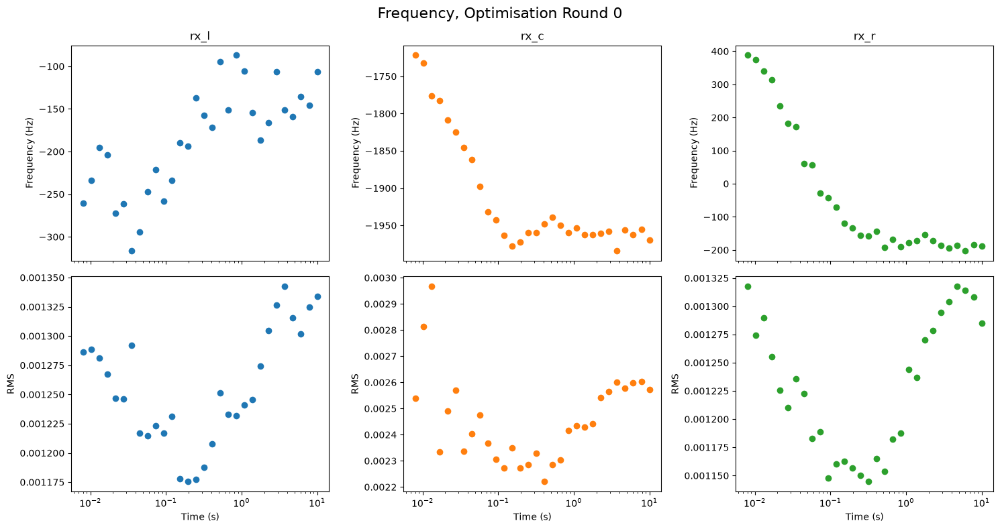

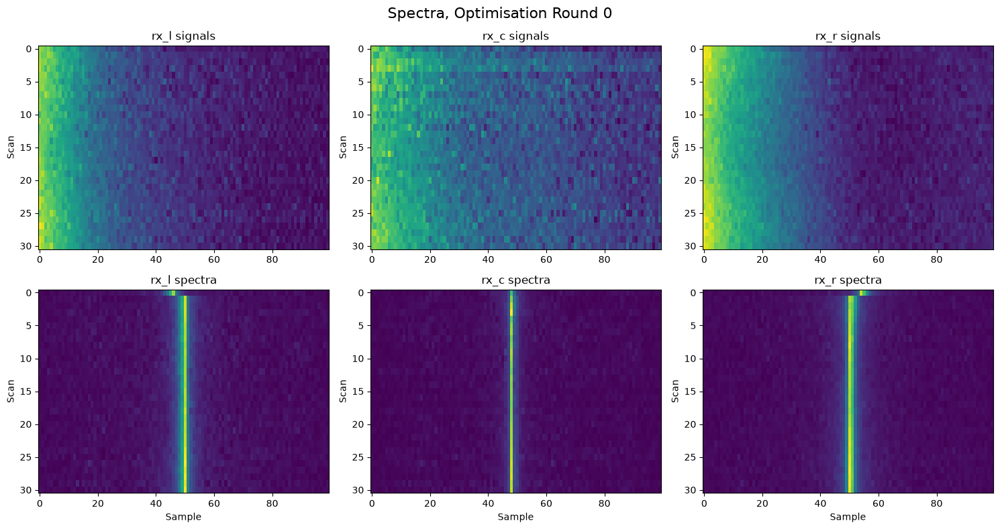

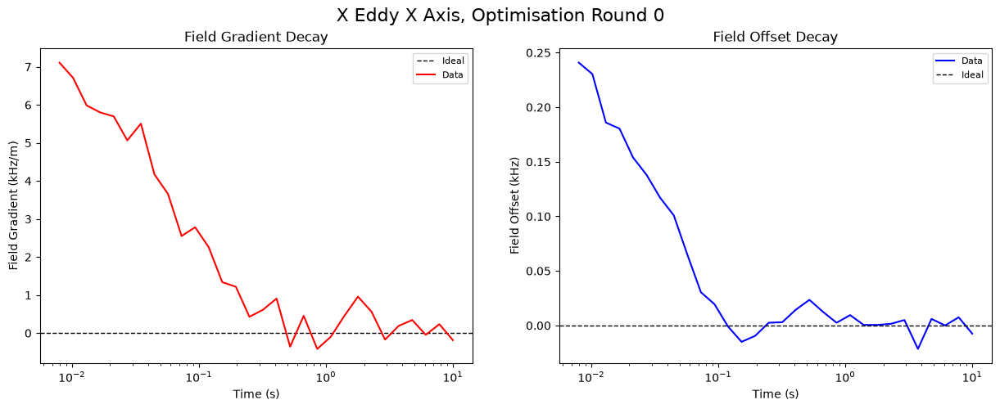

[I 2026-11-26 09:06:59,274] Trial 0 finished with value: 3308.193174906777 and parameters: {'X_A1': 0.07617037929052314, 'X_A2': 0.05439265281835774, 'X_A3': 0.04282786658431569, 'X_A4': 0}. Best is trial 0 with value: 3308.193174906777.


max |E| = 6486.756621689154
mean |E| = 1948.858903881392
RMS E = 2844.355542524778
Total cost = 3.308e+03
E max = 0.12084035479647218
E nanmax = 0.12084035479647218
E contains nan = False
B max = 0.01919918653279587
B nanmax = 0.01919918653279587
B contains nan = False
Trial 1


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01919918653279587 !!!!!!!!!!!!!!!!


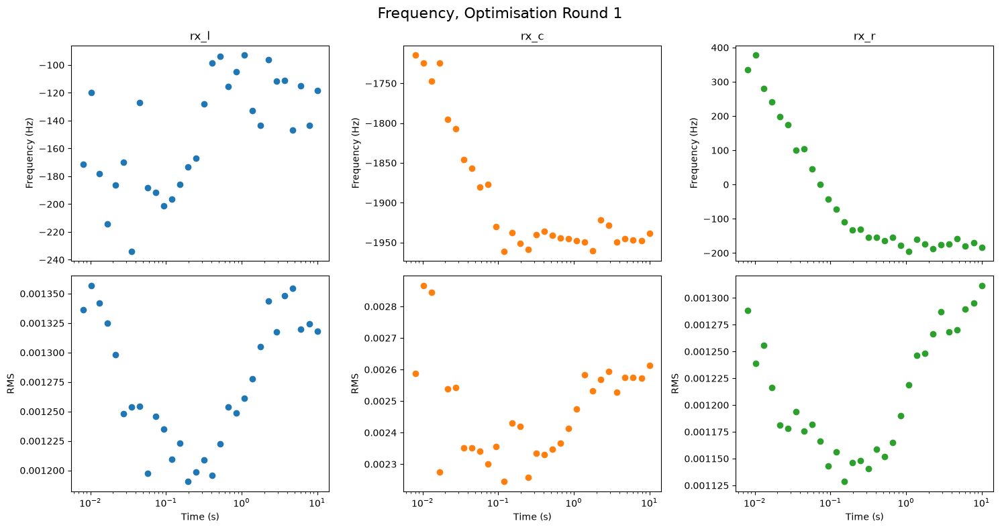

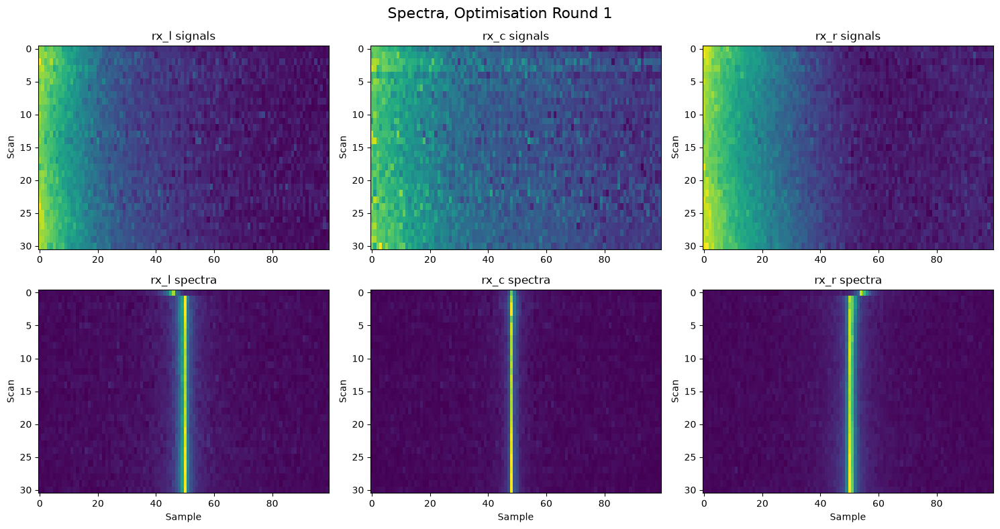

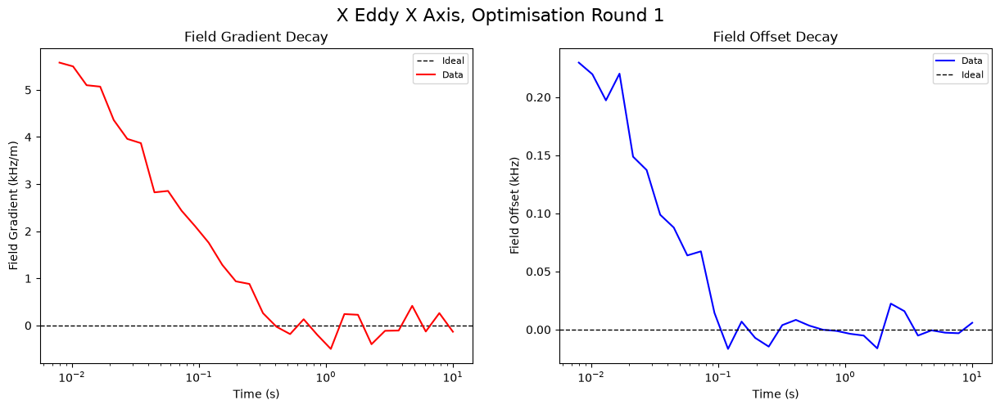

[I 2026-11-26 09:08:20,280] Trial 1 finished with value: 2690.922163087416 and parameters: {'X_A1': 0.07387777583665292, 'X_A2': 0.0750837988649283, 'X_A3': 0.03732489582785936, 'X_A4': 1.5051213278275584e-09}. Best is trial 1 with value: 2690.922163087416.


max |E| = 5057.471264367815
mean |E| = 1625.5205730468092
RMS E = 2268.6798962101457
Total cost = 2.691e+03
E max = 0.11609242241303194
E nanmax = 0.11609242241303194
E contains nan = False
B max = 0.018444849583050926
B nanmax = 0.018444849583050926
B contains nan = False
Trial 2


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.018444849583050926 !!!!!!!!!!!!!!!!


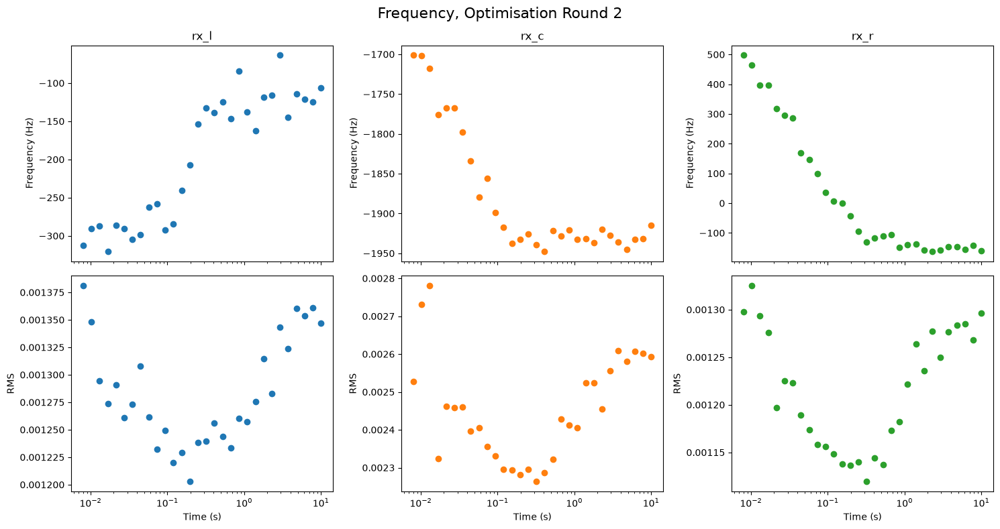

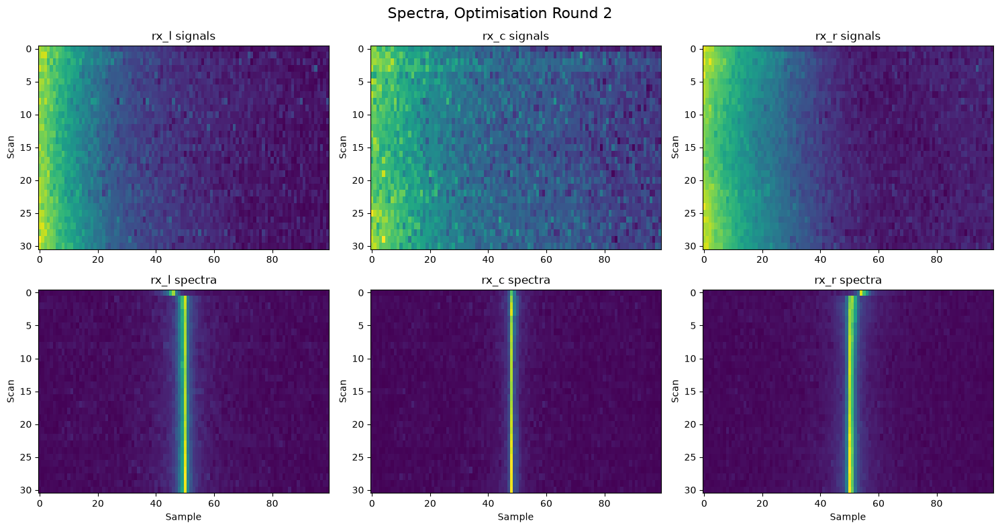

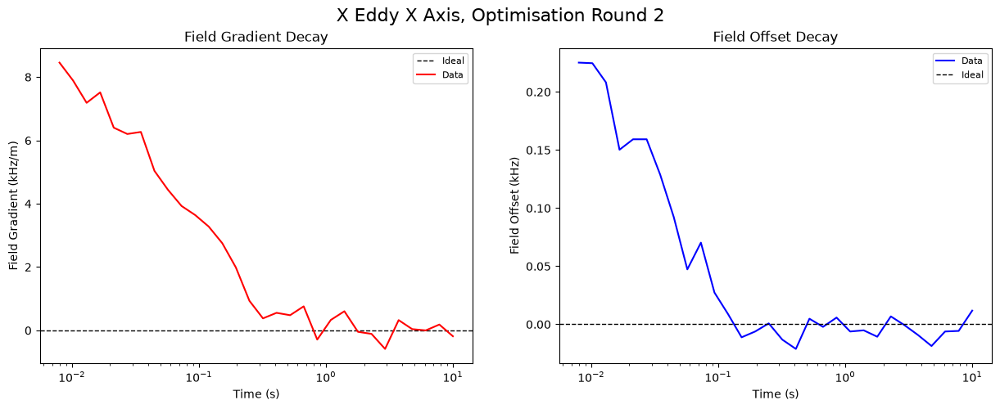

[I 2026-11-26 09:09:42,499] Trial 2 finished with value: 2899.722393572275 and parameters: {'X_A1': 0.05140474828563958, 'X_A2': 0.06246002136460456, 'X_A3': 0.03449057715772238, 'X_A4': 4.879068897615226e-09}. Best is trial 1 with value: 2690.922163087416.


max |E| = 8105.947026486754
mean |E| = 2517.9077128102604
RMS E = 3691.210604216867
Total cost = 2.900e+03
E max = 0.12104832378410121
E nanmax = 0.12104832378410121
E contains nan = False
B max = 0.019232207986876738
B nanmax = 0.019232207986876738
B contains nan = False
Trial 3


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019232207986876738 !!!!!!!!!!!!!!!!


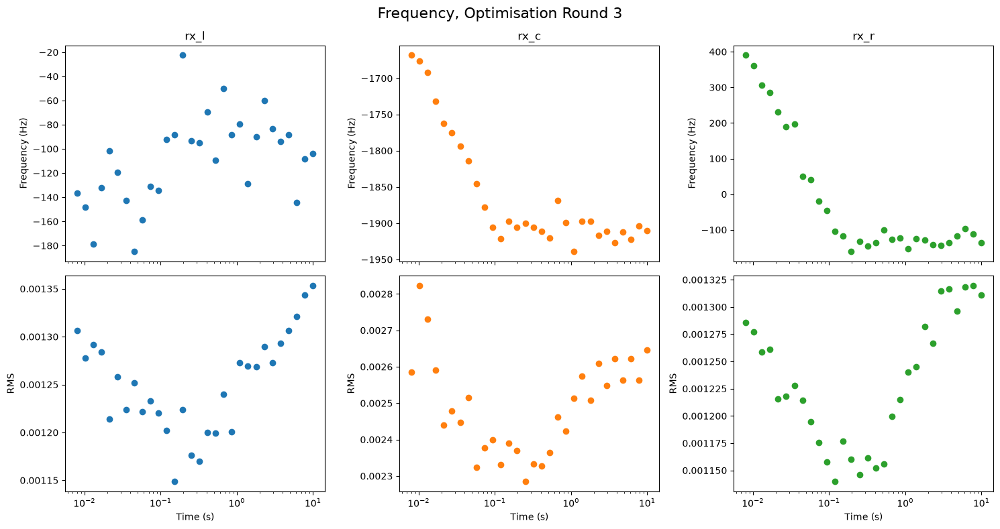

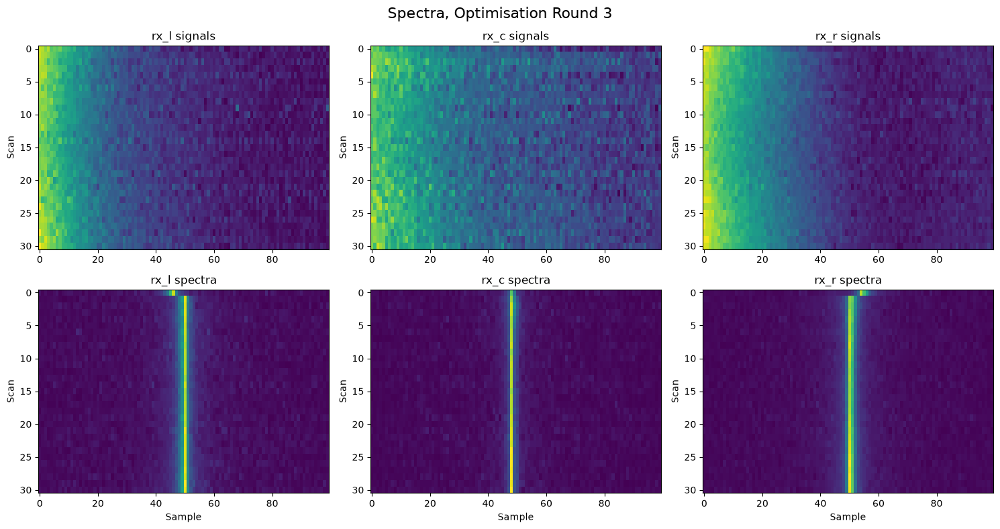

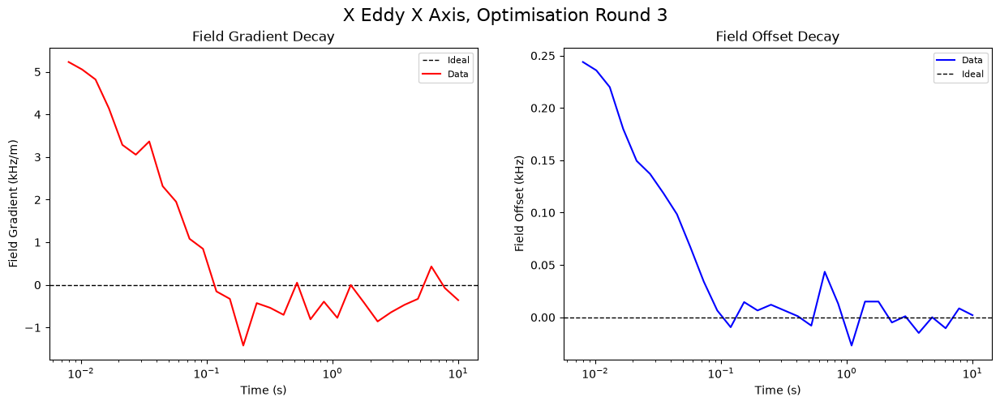

[I 2026-11-26 09:11:03,672] Trial 3 finished with value: 4029.2053591942104 and parameters: {'X_A1': 0.09539082173420502, 'X_A2': 0.04561587351337444, 'X_A3': 0.04693809136149382, 'X_A4': -9.79632174009206e-09}. Best is trial 1 with value: 2690.922163087416.


max |E| = 5267.366316841578
mean |E| = 1474.762618690654
RMS E = 2193.630768318808
Total cost = 4.029e+03
E max = 0.11945959072637455
E nanmax = 0.11945959072637455
E contains nan = False
B max = 0.01897978038068025
B nanmax = 0.01897978038068025
B contains nan = False
Trial 4


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01897978038068025 !!!!!!!!!!!!!!!!


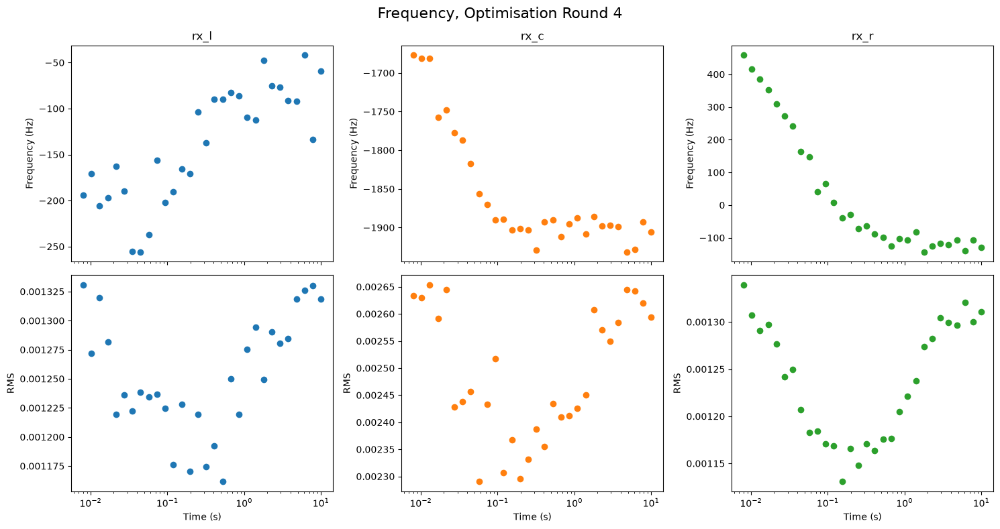

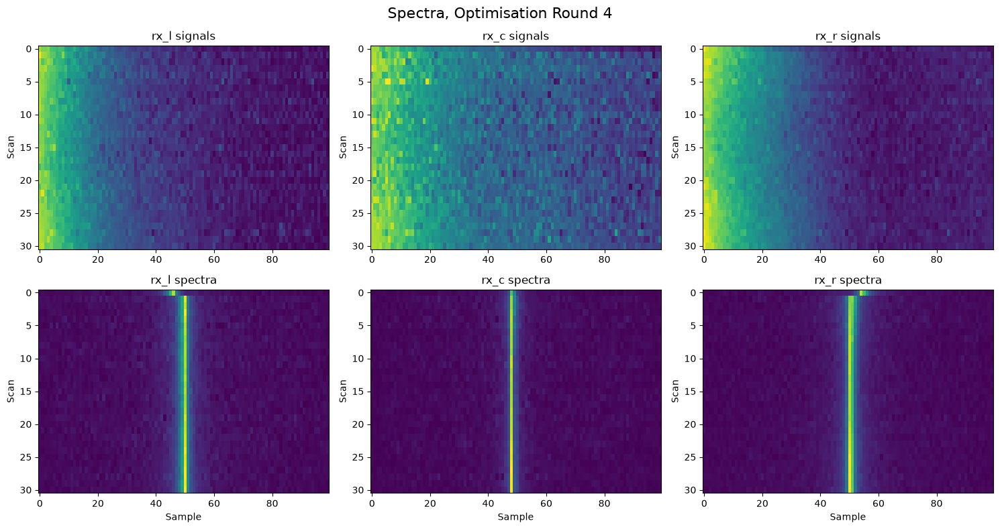

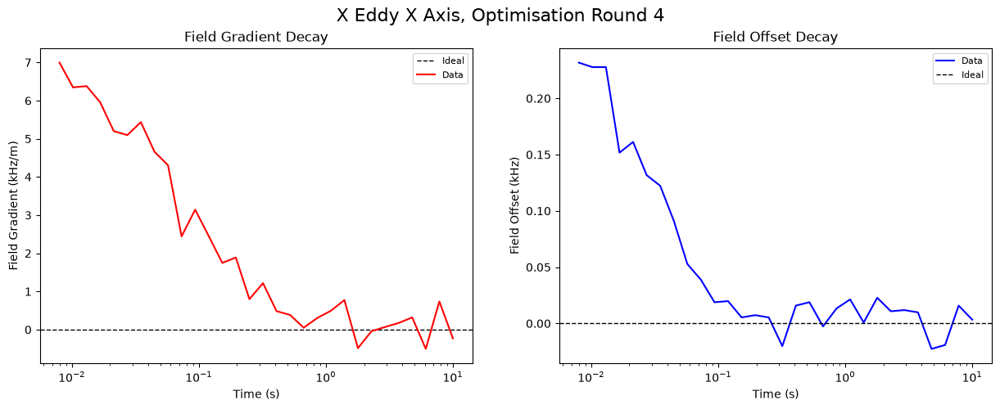

[I 2026-11-26 09:12:24,535] Trial 4 finished with value: 4643.323617248173 and parameters: {'X_A1': 0.06403977549418471, 'X_A2': 0.06460839284634452, 'X_A3': 0.047846421087684735, 'X_A4': -2.352930368998168e-09}. Best is trial 1 with value: 2690.922163087416.


max |E| = 6521.739130434781
mean |E| = 2059.6368482425446
RMS E = 2972.299316712746
Total cost = 4.643e+03
E max = 0.11576233158410515
E nanmax = 0.11576233158410515
E contains nan = False
B max = 0.018392392603421966
B nanmax = 0.018392392603421966
B contains nan = False
Trial 5


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.018392392603421966 !!!!!!!!!!!!!!!!


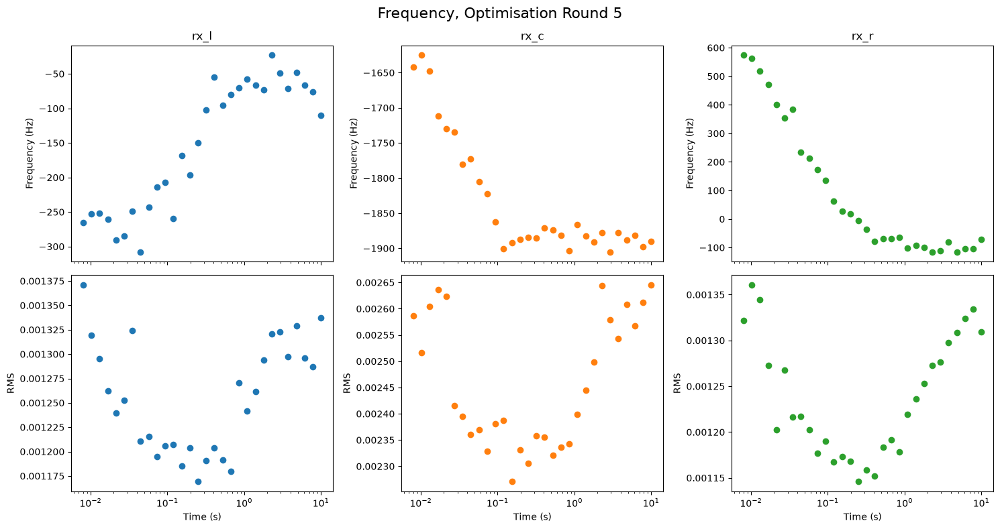

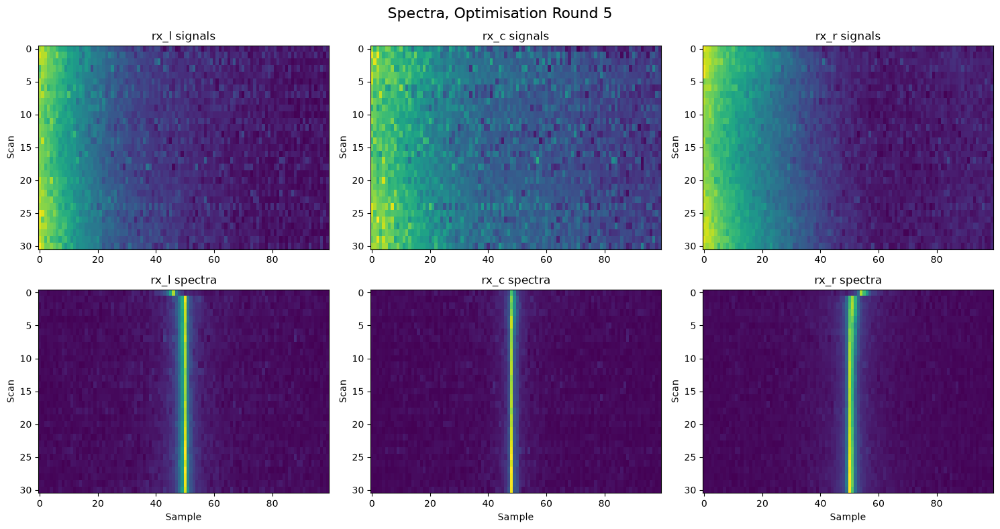

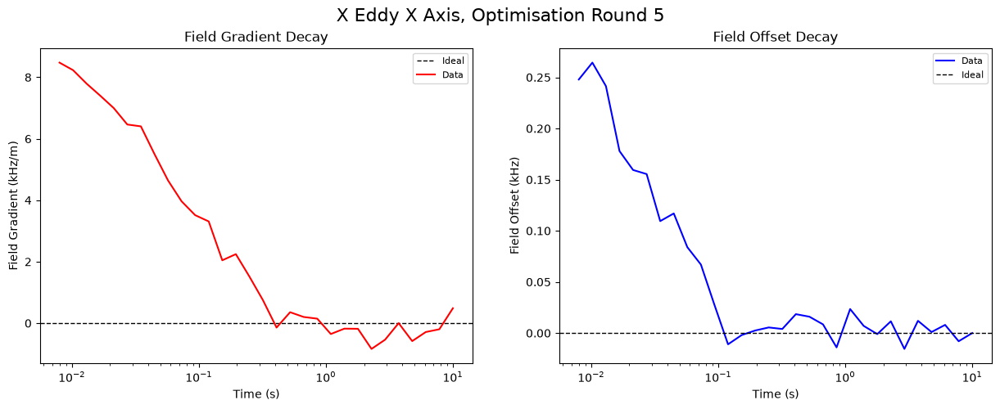

[I 2026-11-26 09:13:48,064] Trial 5 finished with value: 4221.212103137049 and parameters: {'X_A1': 0.046375283803491894, 'X_A2': 0.06110087103007861, 'X_A3': 0.03849888416635541, 'X_A4': -7.603387550361793e-09}. Best is trial 1 with value: 2690.922163087416.


max |E| = 8390.804597701148
mean |E| = 2762.95185740463
RMS E = 3995.21079547405
Total cost = 4.221e+03
E max = 0.12150552587265187
E nanmax = 0.12150552587265187
E contains nan = False
B max = 0.019304810415028194
B nanmax = 0.019304810415028194
B contains nan = False
Trial 6


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019304810415028194 !!!!!!!!!!!!!!!!


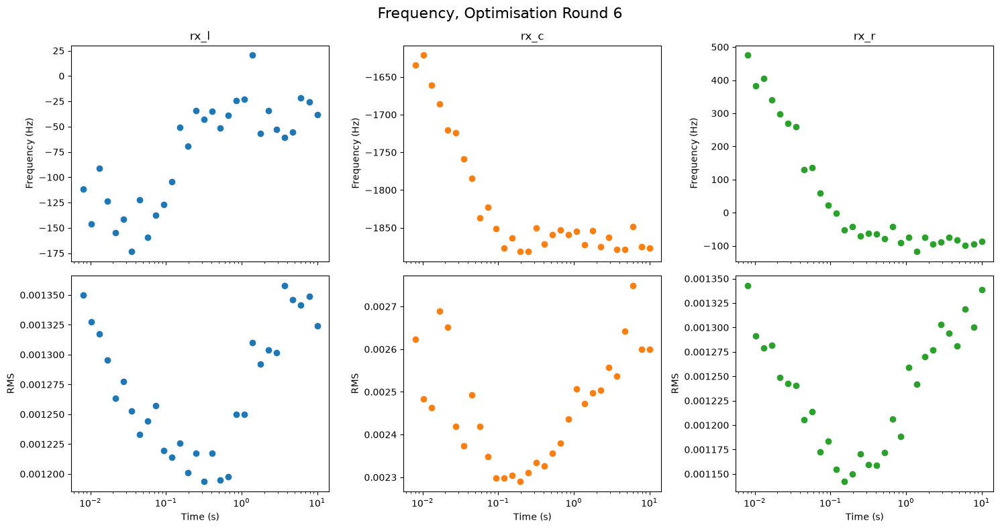

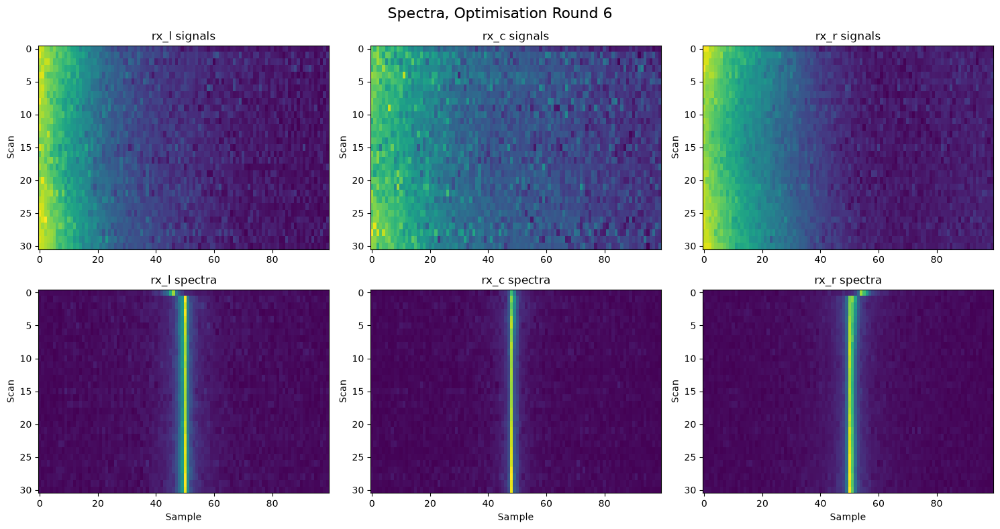

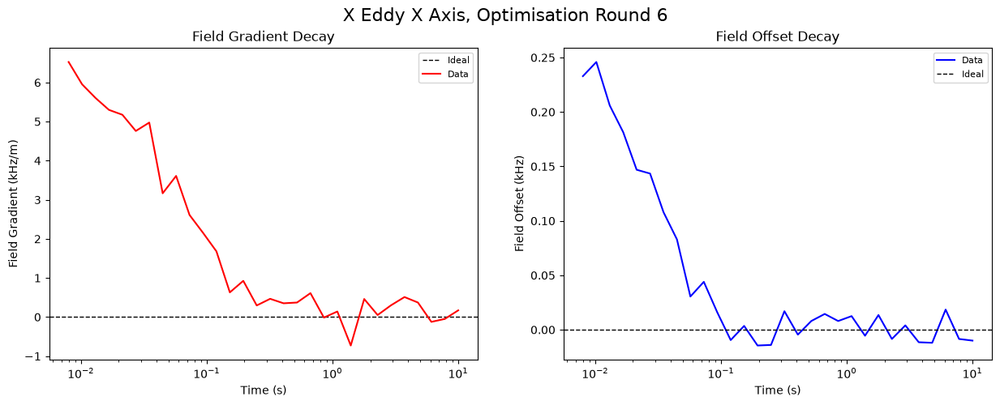

[I 2026-11-26 09:15:14,028] Trial 6 finished with value: 2841.4151070771077 and parameters: {'X_A1': 0.08155350522583801, 'X_A2': 0.05434519899585846, 'X_A3': 0.0569712617790972, 'X_A4': 8.803041528921627e-09}. Best is trial 1 with value: 2690.922163087416.


max |E| = 5872.063968015991
mean |E| = 1707.1464267866065
RMS E = 2529.29194629399
Total cost = 2.841e+03
E max = 0.11848791163971457
E nanmax = 0.11848791163971457
E contains nan = False
B max = 0.01882539992507254
B nanmax = 0.01882539992507254
B contains nan = False
Trial 7


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01882539992507254 !!!!!!!!!!!!!!!!


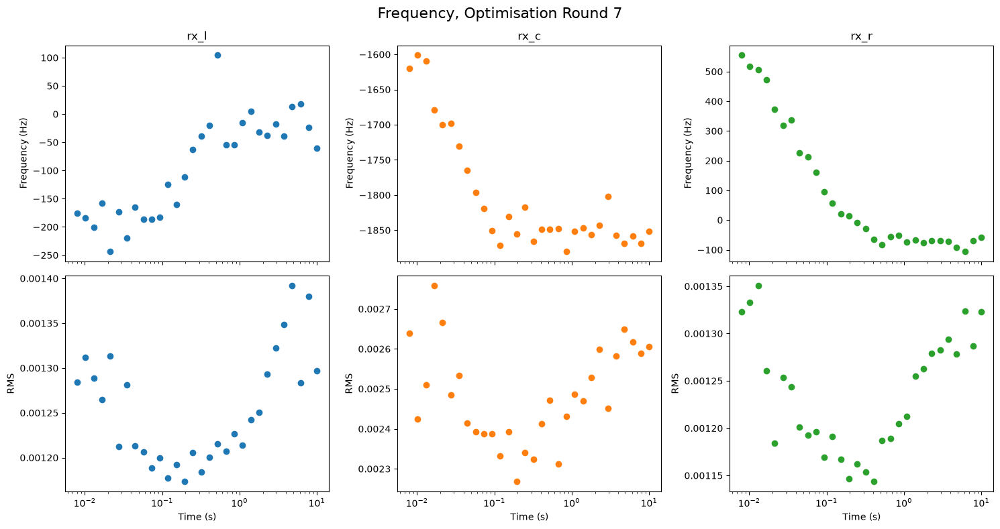

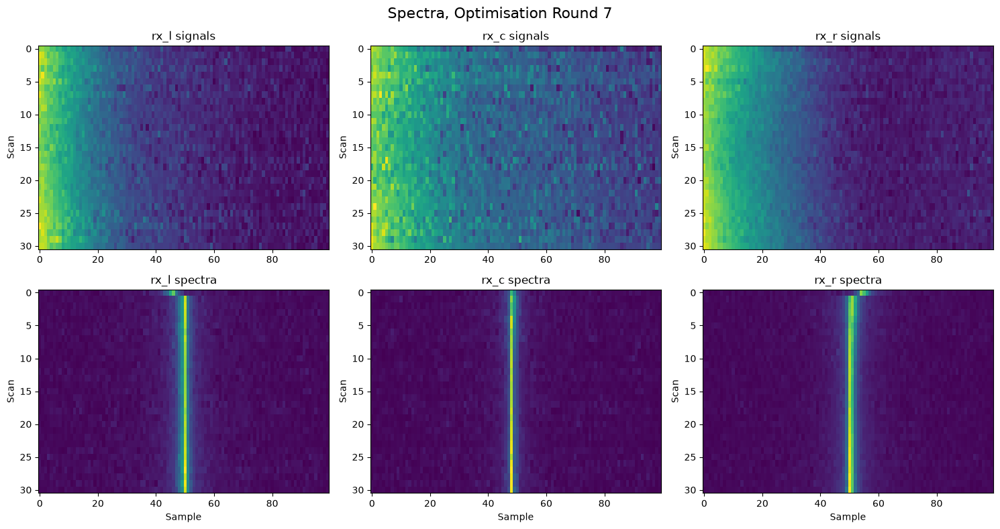

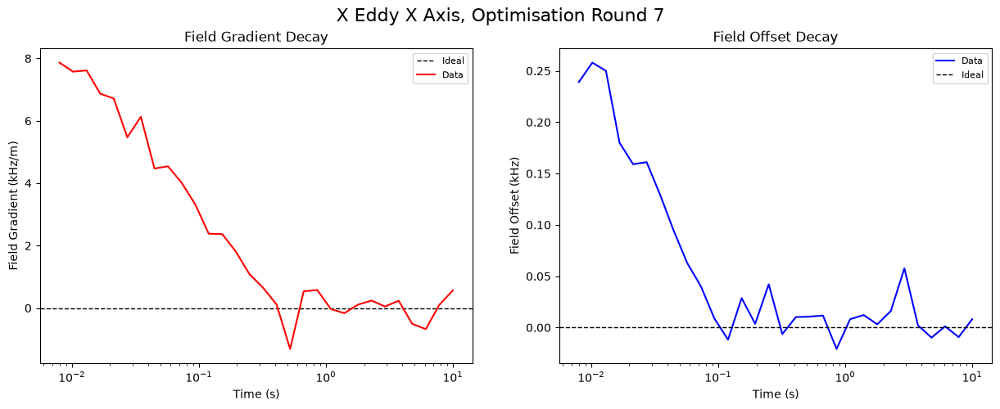

[I 2026-11-26 09:16:38,322] Trial 7 finished with value: 4188.292832128552 and parameters: {'X_A1': 0.06325252510552638, 'X_A2': 0.056669707729561744, 'X_A3': 0.048913283316254955, 'X_A4': 6.669053971226273e-10}. Best is trial 1 with value: 2690.922163087416.


max |E| = 7311.34432783608
mean |E| = 2401.132766949858
RMS E = 3431.4635527935184
Total cost = 4.188e+03
E max = 0.12015065836032851
E nanmax = 0.12015065836032851
E contains nan = False
B max = 0.01908957955622452
B nanmax = 0.01908957955622452
B contains nan = False
Trial 8


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01908957955622452 !!!!!!!!!!!!!!!!


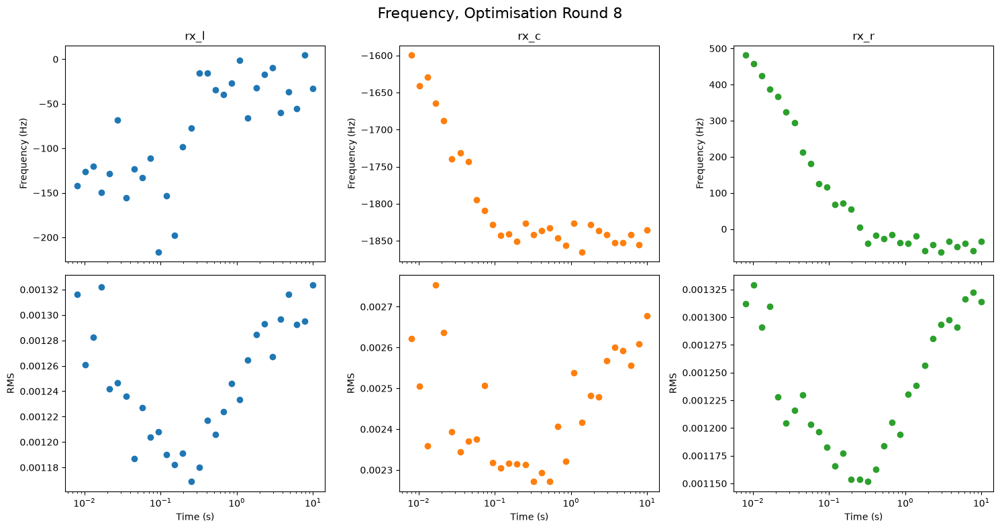

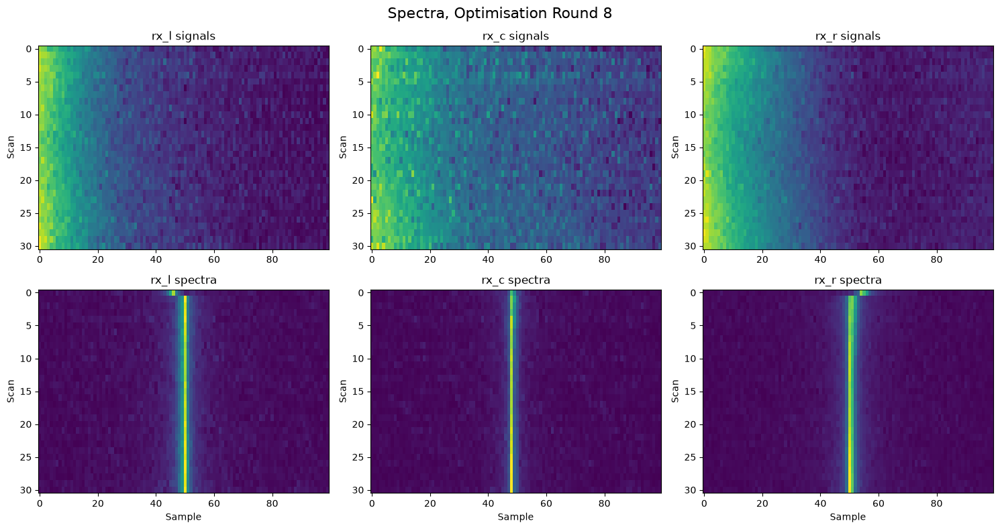

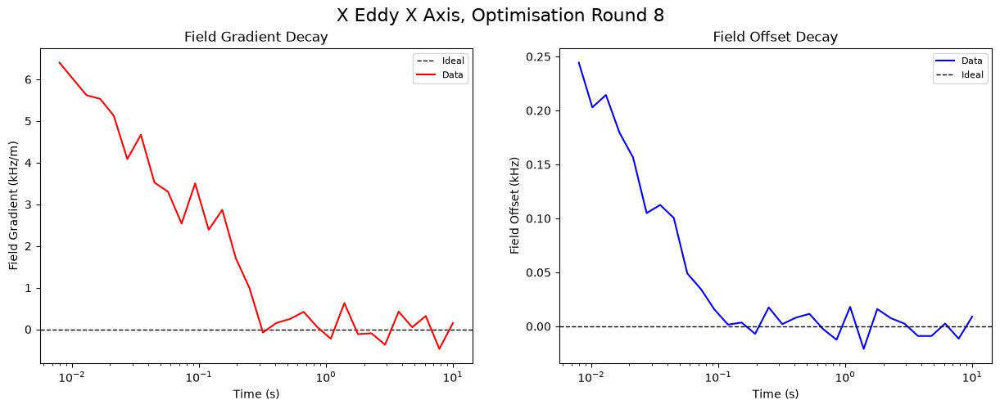

[I 2026-11-26 09:18:03,312] Trial 8 finished with value: 3501.941488442242 and parameters: {'X_A1': 0.06261800261280345, 'X_A2': 0.07310157906861306, 'X_A3': 0.04605158179882368, 'X_A4': -4.835025062075074e-09}. Best is trial 1 with value: 2690.922163087416.


max |E| = 6231.884057971012
mean |E| = 1985.0074962518736
RMS E = 2863.46006548066
Total cost = 3.502e+03
E max = 0.12156081143989222
E nanmax = 0.12156081143989222
E contains nan = False
B max = 0.019313691579740038
B nanmax = 0.019313691579740038
B contains nan = False
Trial 9


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019313691579740038 !!!!!!!!!!!!!!!!


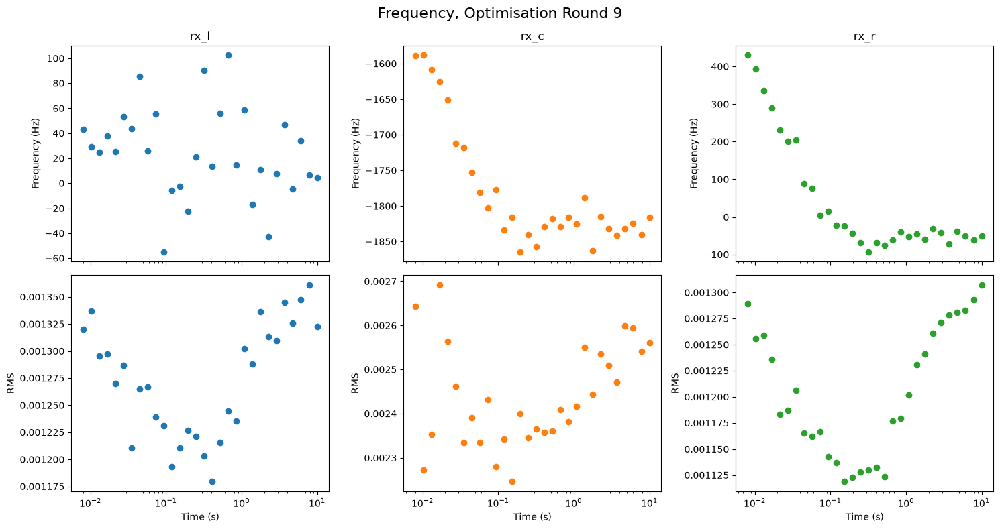

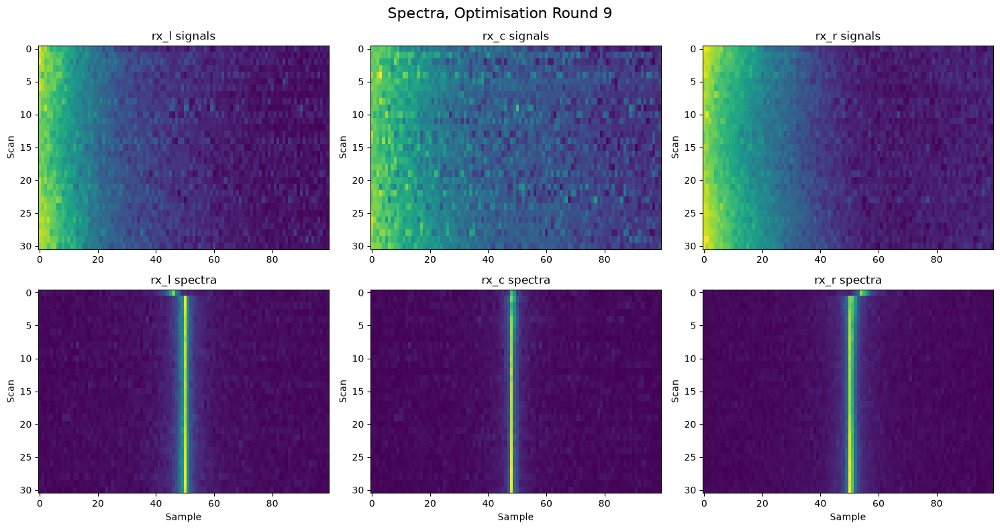

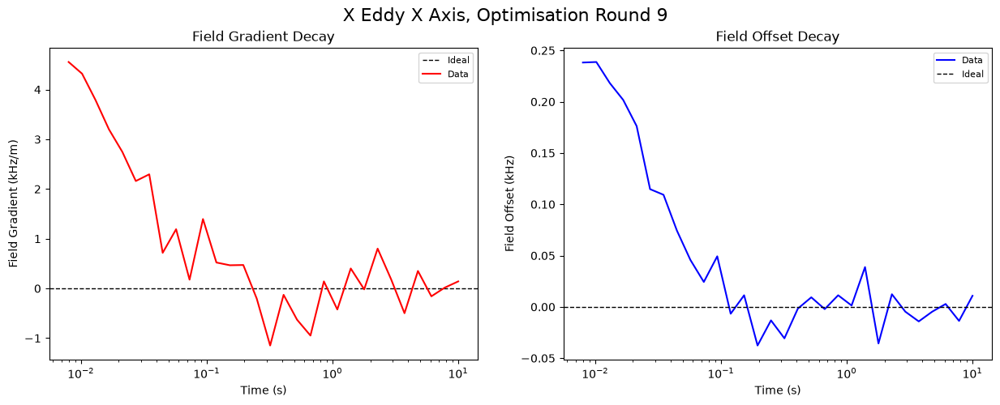

[I 2026-11-26 09:19:27,056] Trial 9 finished with value: 2753.8996294119233 and parameters: {'X_A1': 0.10338353484683498, 'X_A2': 0.05926001430690367, 'X_A3': 0.027358226635521253, 'X_A4': 2.69499380619929e-09}. Best is trial 1 with value: 2690.922163087416.


max |E| = 3868.0659670164905
mean |E| = 1131.2676994835913
RMS E = 1514.5279127238118
Total cost = 2.754e+03
E max = 0.12015805265425794
E nanmax = 0.12015805265425794
E contains nan = False
B max = 0.01909080891246977
B nanmax = 0.01909080891246977
B contains nan = False
Trial 10


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01909080891246977 !!!!!!!!!!!!!!!!


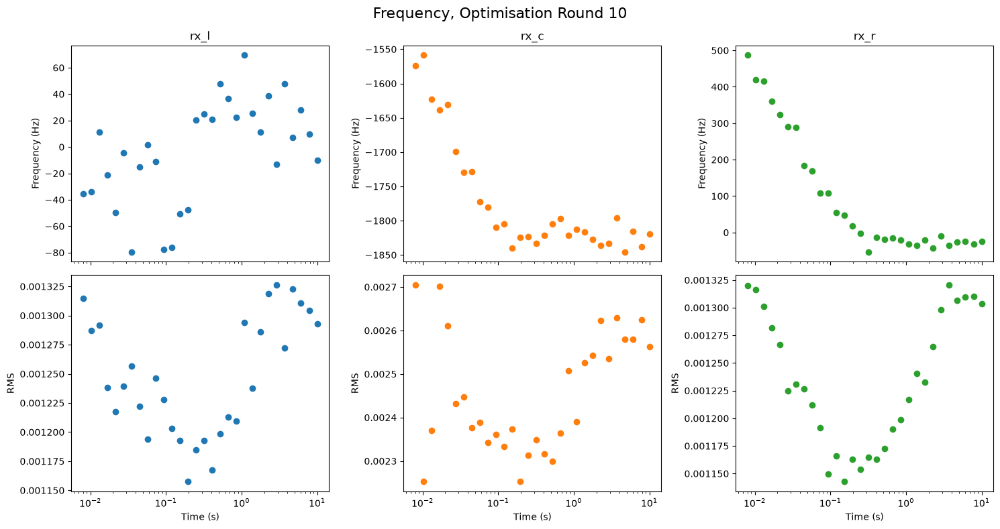

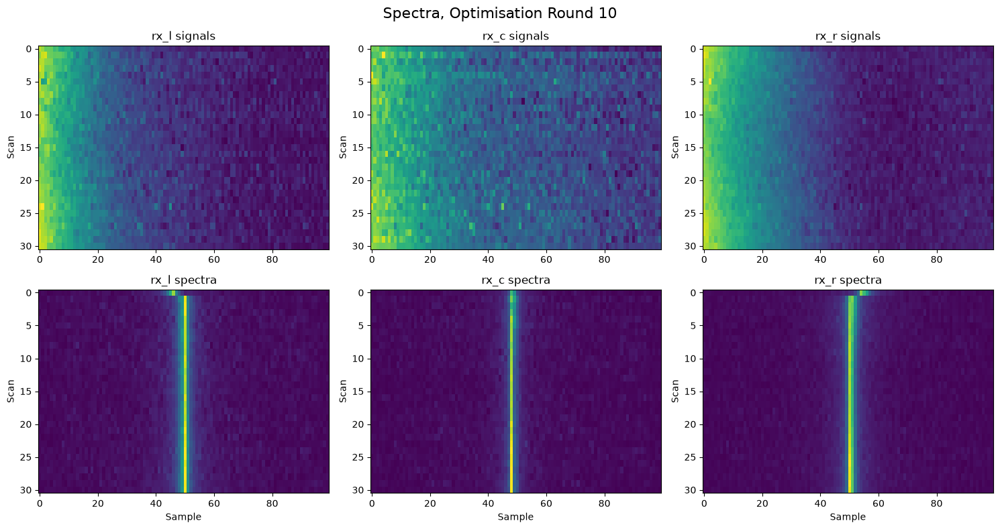

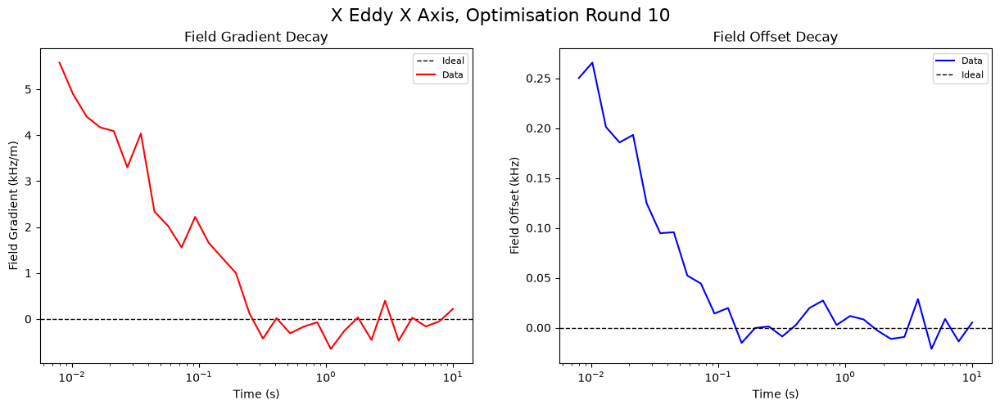

[I 2026-11-26 09:20:51,101] Trial 10 finished with value: 2427.7514891041947 and parameters: {'X_A1': 0.07678176368834333, 'X_A2': 0.07403701233413162, 'X_A3': 0.02933925401426522, 'X_A4': -4.368765610115581e-10}. Best is trial 10 with value: 2427.7514891041947.


max |E| = 5222.3888055972
mean |E| = 1520.5730468099277
RMS E = 2118.934243560714
Total cost = 2.428e+03
E max = 0.11965450502455957
E nanmax = 0.11965450502455957
E contains nan = False
B max = 0.019010797381258767
B nanmax = 0.019010797381258767
B contains nan = False
Trial 11


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019010797381258767 !!!!!!!!!!!!!!!!


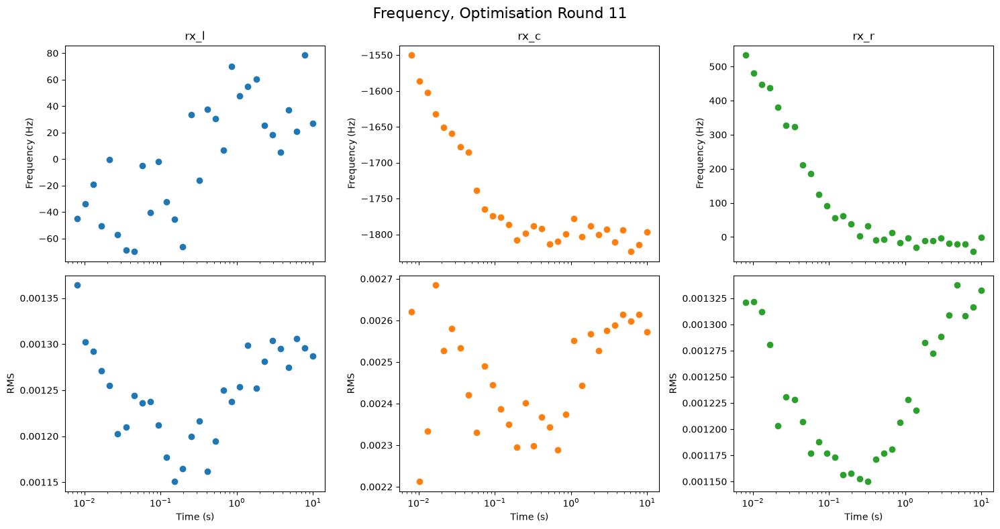

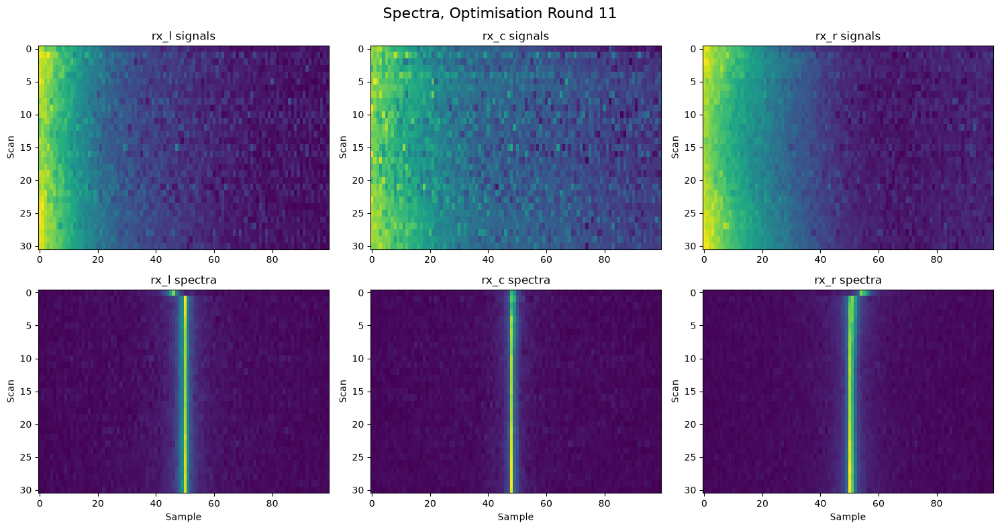

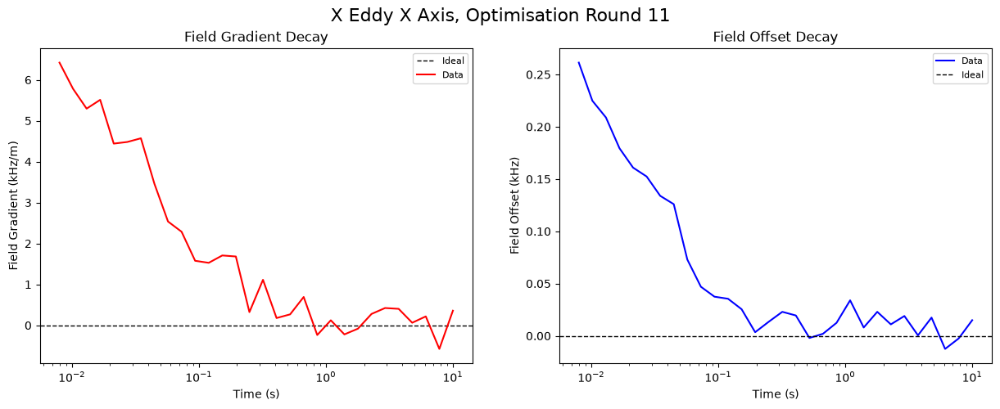

[I 2026-11-26 09:22:18,317] Trial 11 finished with value: 3730.2386857360075 and parameters: {'X_A1': 0.07350768687108315, 'X_A2': 0.07087264774290473, 'X_A3': 0.0321667737231669, 'X_A4': -1.8326898124617675e-09}. Best is trial 10 with value: 2427.7514891041947.


max |E| = 5782.108945527235
mean |E| = 1676.1619190404797
RMS E = 2404.4868470451515
Total cost = 3.730e+03
E max = 0.12246945394967848
E nanmax = 0.12246945394967848
E contains nan = False
B max = 0.019458004962736676
B nanmax = 0.019458004962736676
B contains nan = False
Trial 12


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019458004962736676 !!!!!!!!!!!!!!!!


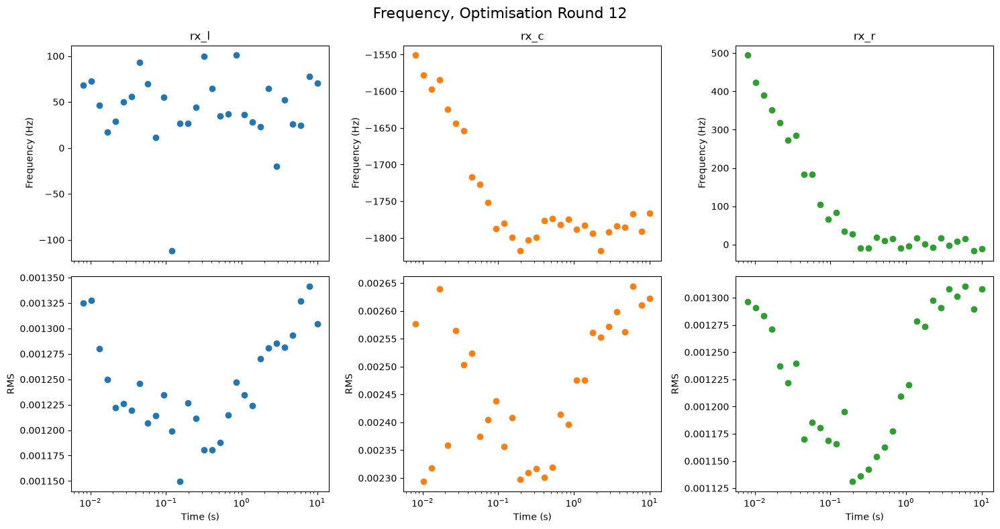

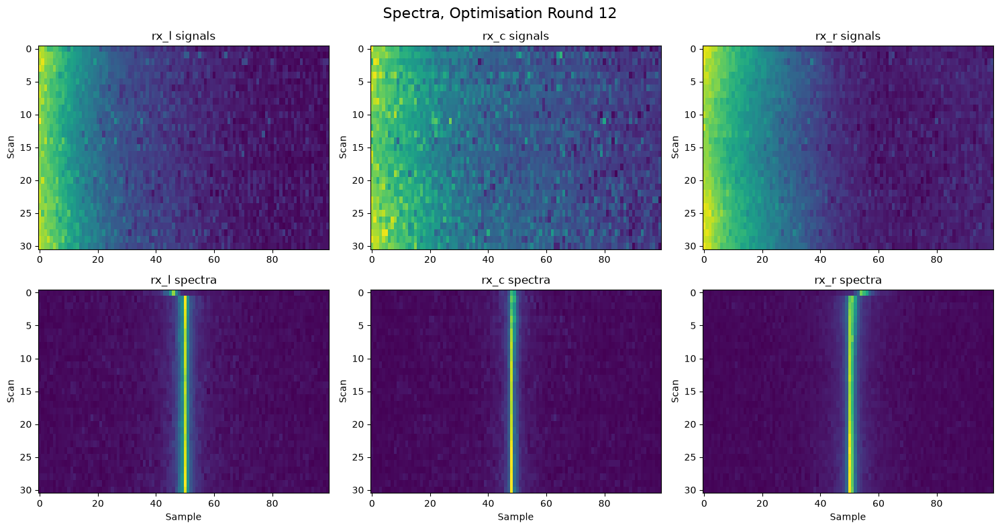

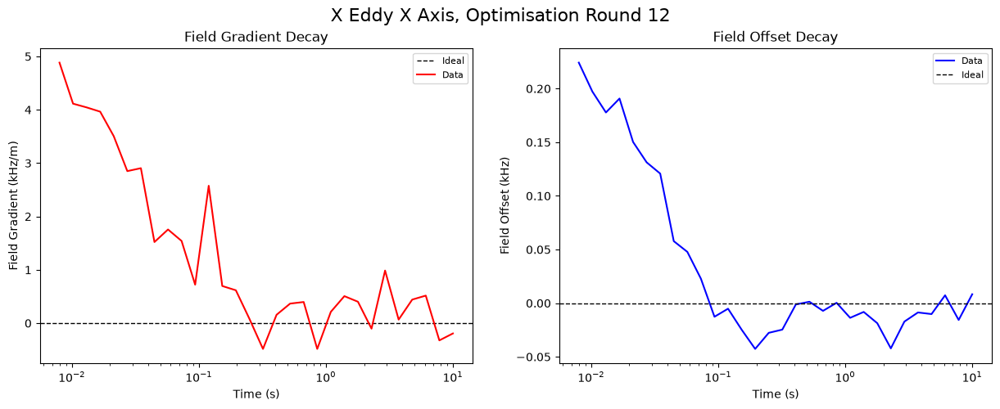

[I 2026-11-26 09:23:40,510] Trial 12 finished with value: 3999.381343024087 and parameters: {'X_A1': 0.08744523499774359, 'X_A2': 0.0698835779994378, 'X_A3': 0.04168215364950386, 'X_A4': 2.039449012853662e-09}. Best is trial 10 with value: 2427.7514891041947.


max |E| = 4267.866066966515
mean |E| = 1170.747959353656
RMS E = 1679.2813866932715
Total cost = 3.999e+03
E max = 0.12100575097826792
E nanmax = 0.12100575097826792
E contains nan = False
B max = 0.019225488343579872
B nanmax = 0.019225488343579872
B contains nan = False
Trial 13


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019225488343579872 !!!!!!!!!!!!!!!!


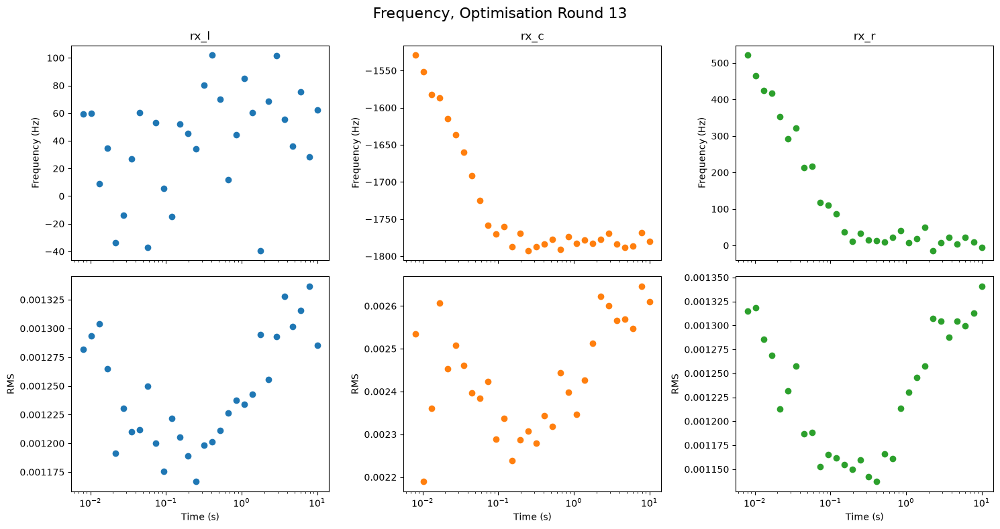

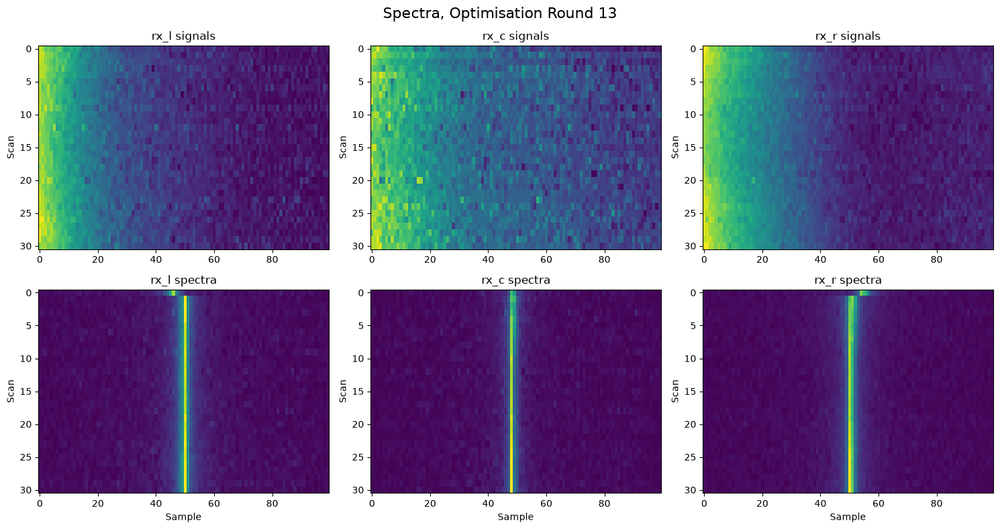

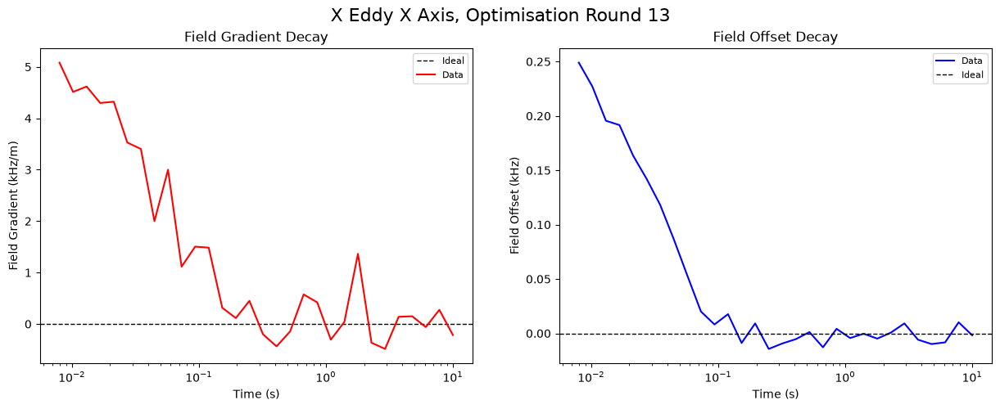

[I 2026-11-26 09:25:04,720] Trial 13 finished with value: 3028.953160590344 and parameters: {'X_A1': 0.08275834287608343, 'X_A2': 0.07371245986538241, 'X_A3': 0.030273636336315902, 'X_A4': 4.3656503212128104e-09}. Best is trial 10 with value: 2427.7514891041947.


max |E| = 4617.691154422787
mean |E| = 1401.299350324837
RMS E = 1998.3348883520696
Total cost = 3.029e+03
E max = 0.12011773464162005
E nanmax = 0.12011773464162005
E contains nan = False
B max = 0.019084390900668016
B nanmax = 0.019084390900668016
B contains nan = False
Trial 14


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019084390900668016 !!!!!!!!!!!!!!!!


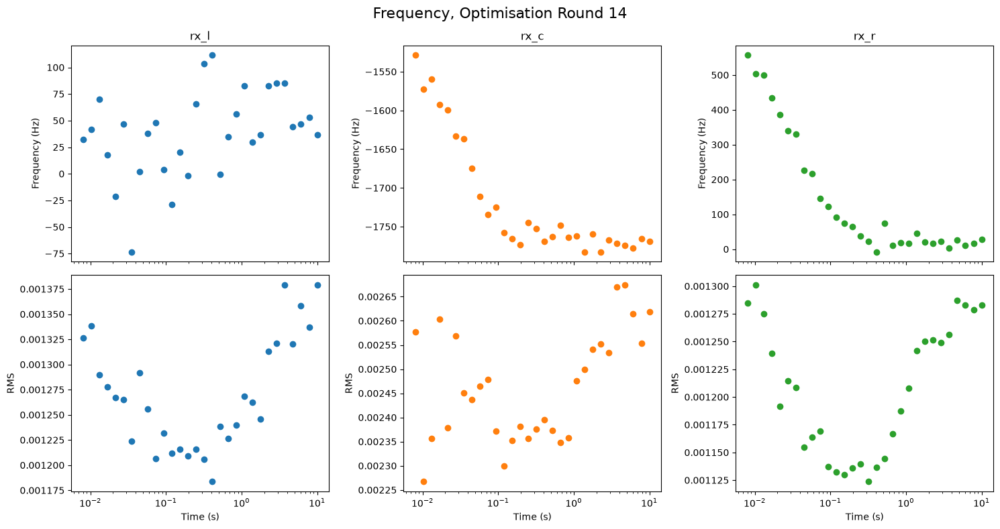

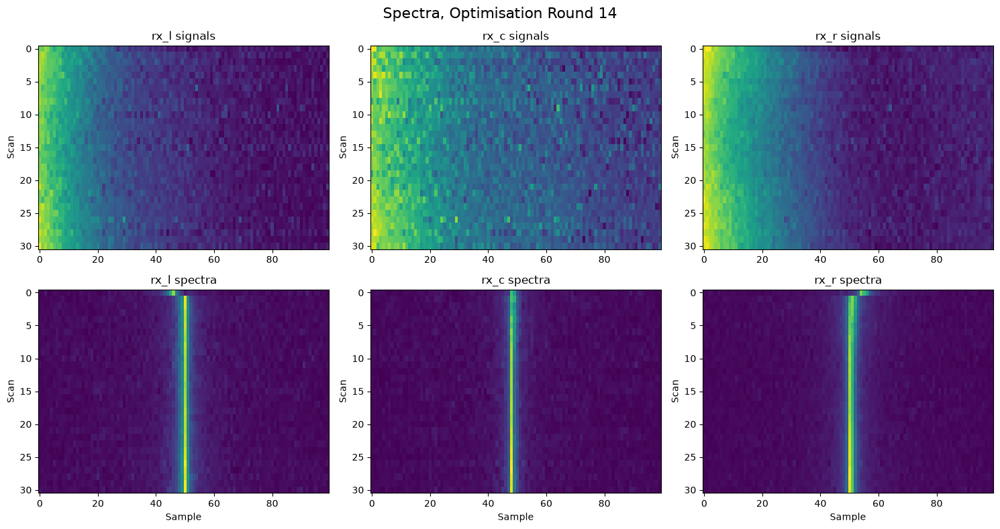

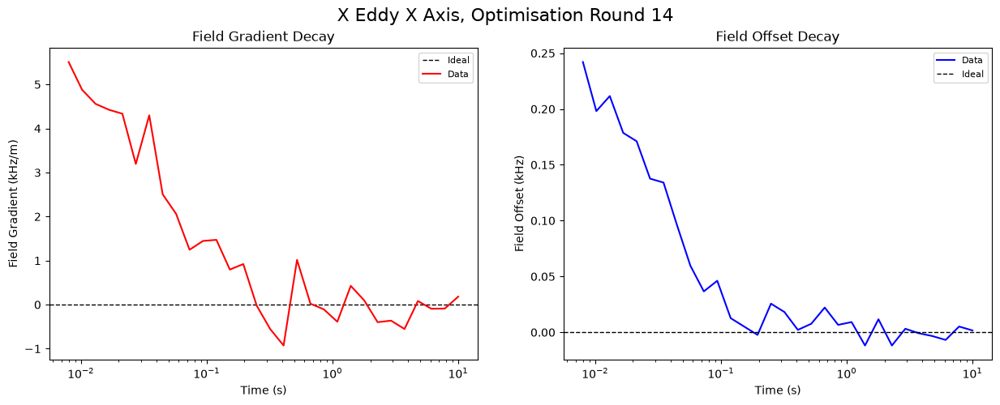

[I 2026-11-26 09:26:28,810] Trial 14 finished with value: 2572.335815968207 and parameters: {'X_A1': 0.08122454598325035, 'X_A2': 0.06475965048865764, 'X_A3': 0.034257523130935656, 'X_A4': -8.578989032874097e-09}. Best is trial 10 with value: 2427.7514891041947.


max |E| = 5242.378810594701
mean |E| = 1522.4054639346987
RMS E = 2189.6894516697116
Total cost = 2.572e+03
E max = 0.1181757370749658
E nanmax = 0.1181757370749658
E contains nan = False
B max = 0.01877587075216258
B nanmax = 0.01877587075216258
B contains nan = False
Trial 15


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01877587075216258 !!!!!!!!!!!!!!!!


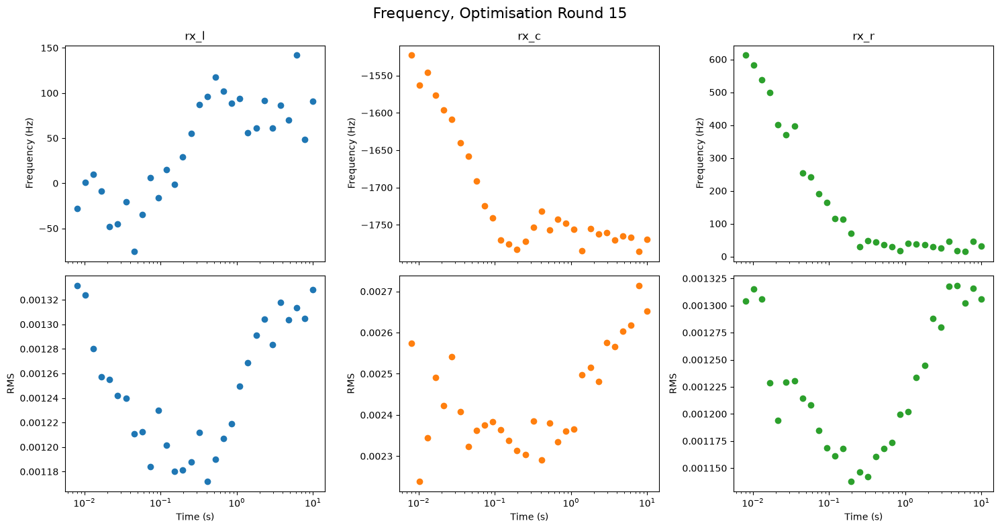

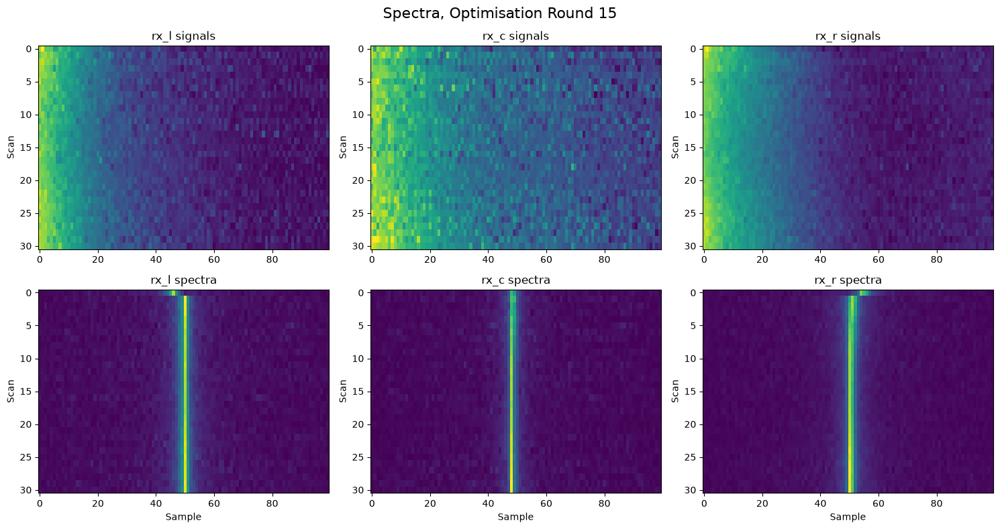

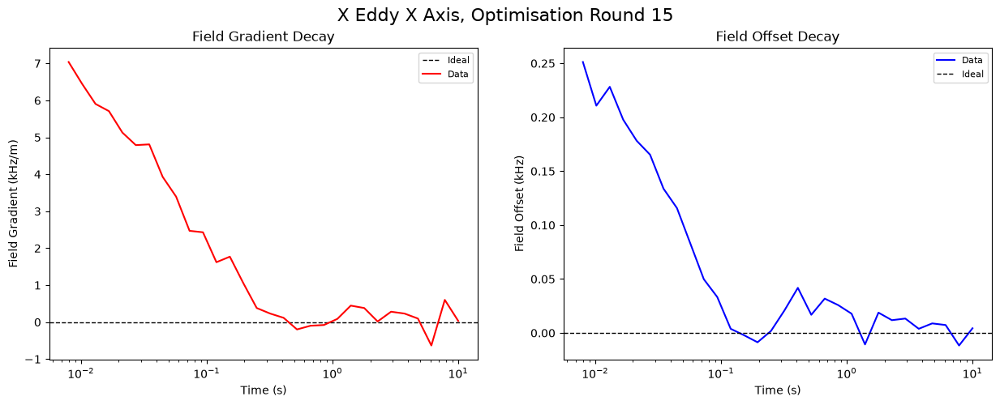

[I 2026-11-26 09:27:51,244] Trial 15 finished with value: 3697.268483435473 and parameters: {'X_A1': 0.08066959470267887, 'X_A2': 0.05584130735332, 'X_A3': 0.02769048896209405, 'X_A4': -9.133779953090826e-09}. Best is trial 10 with value: 2427.7514891041947.


max |E| = 6406.796601699149
mean |E| = 1862.2355488922199
RMS E = 2686.6368712235303
Total cost = 3.697e+03
E max = 0.11979915188455623
E nanmax = 0.11979915188455623
E contains nan = False
B max = 0.019033785026838595
B nanmax = 0.019033785026838595
B contains nan = False
Trial 16


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019033785026838595 !!!!!!!!!!!!!!!!


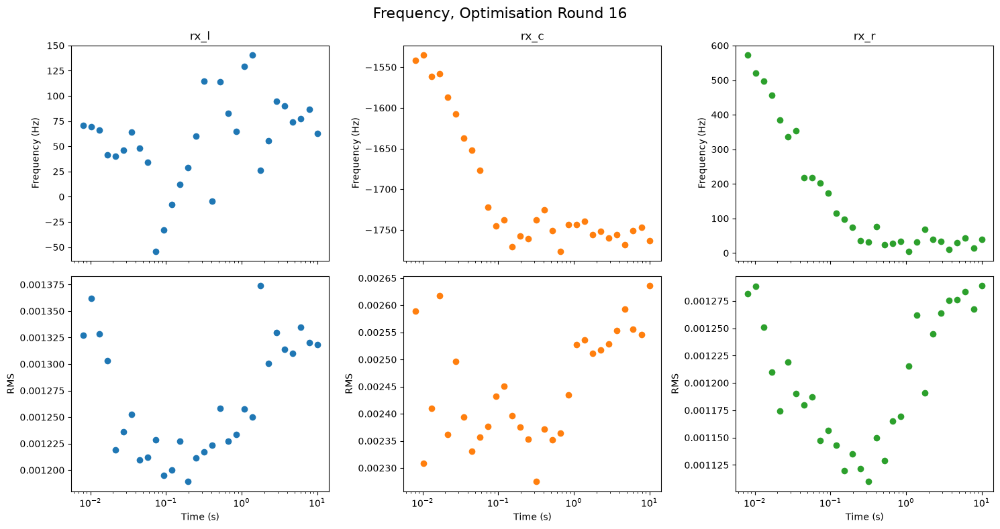

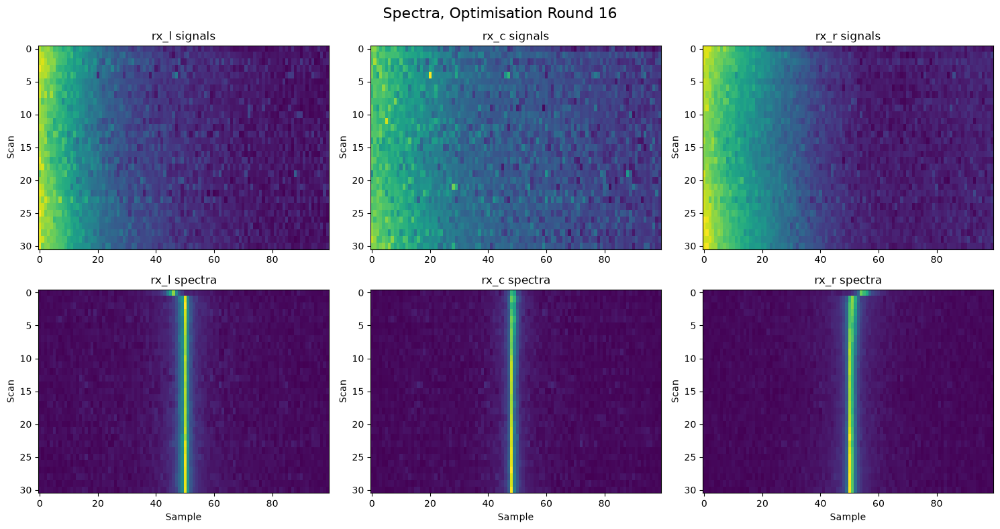

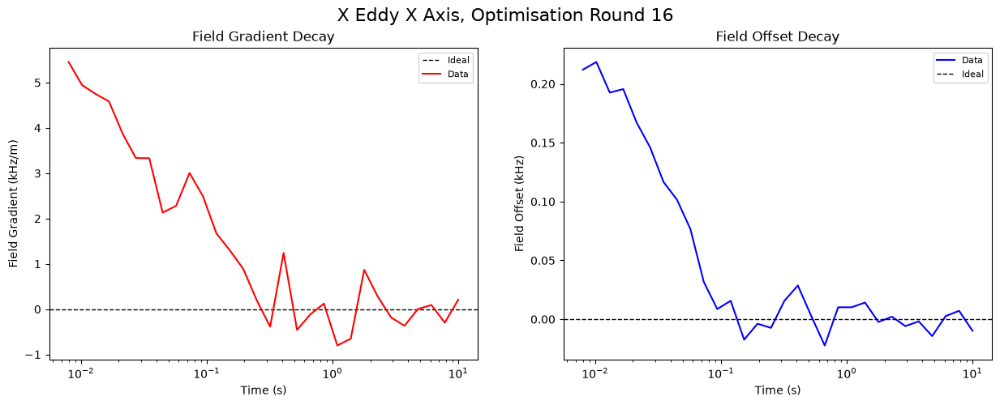

[I 2026-11-26 09:29:13,021] Trial 16 finished with value: 3119.28473868651 and parameters: {'X_A1': 0.08314592114736132, 'X_A2': 0.06303811858753551, 'X_A3': 0.031214118705856646, 'X_A4': -4.6800970144374895e-09}. Best is trial 10 with value: 2427.7514891041947.


max |E| = 5017.491254372812
mean |E| = 1588.0393136764947
RMS E = 2136.7301520906212
Total cost = 3.119e+03
E max = 0.11890752277848385
E nanmax = 0.11890752277848385
E contains nan = False
B max = 0.01889212599101765
B nanmax = 0.01889212599101765
B contains nan = False
Trial 17


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01889212599101765 !!!!!!!!!!!!!!!!


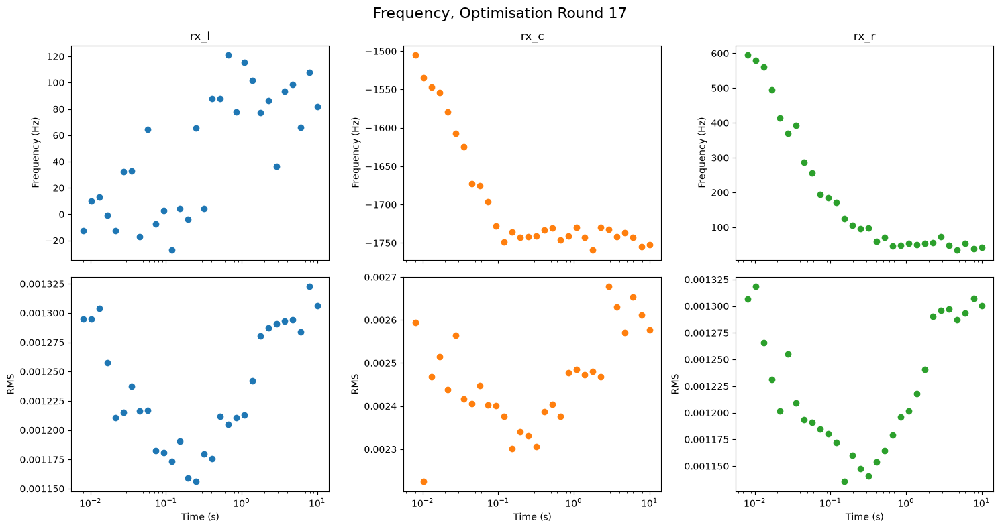

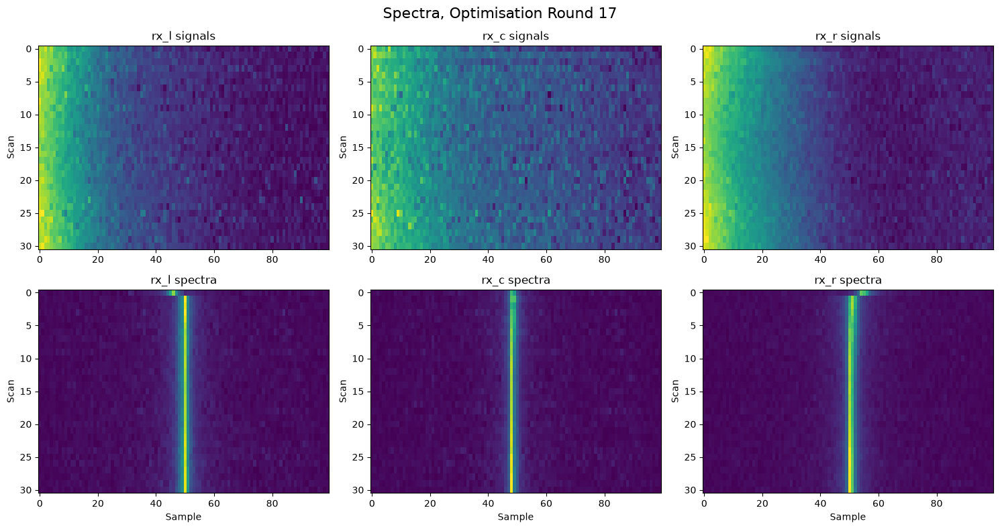

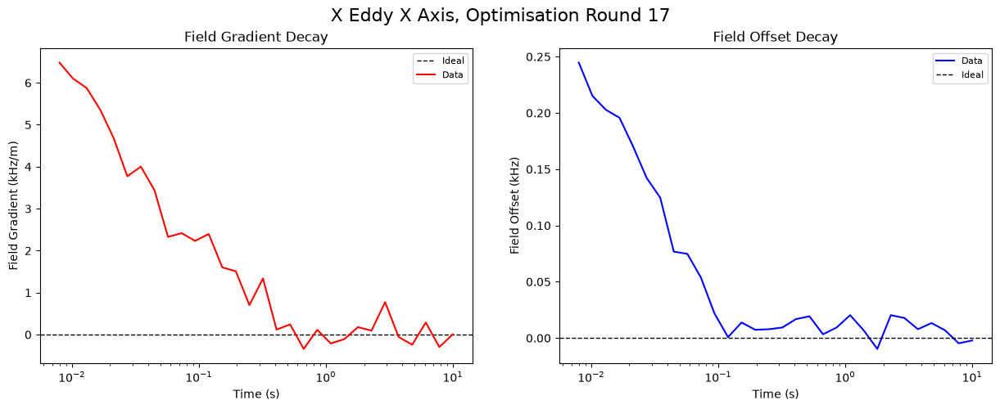

[I 2026-11-26 09:30:33,965] Trial 17 finished with value: 2946.4820730397737 and parameters: {'X_A1': 0.07121207714043006, 'X_A2': 0.06975547173042662, 'X_A3': 0.029452763792193918, 'X_A4': -7.84013297979548e-09}. Best is trial 10 with value: 2427.7514891041947.


max |E| = 6071.964017991004
mean |E| = 1786.1069465267358
RMS E = 2562.024795863475
Total cost = 2.946e+03
E max = 0.12220368986493506
E nanmax = 0.12220368986493506
E contains nan = False
B max = 0.01941581529822167
B nanmax = 0.01941581529822167
B contains nan = False
Trial 18


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01941581529822167 !!!!!!!!!!!!!!!!


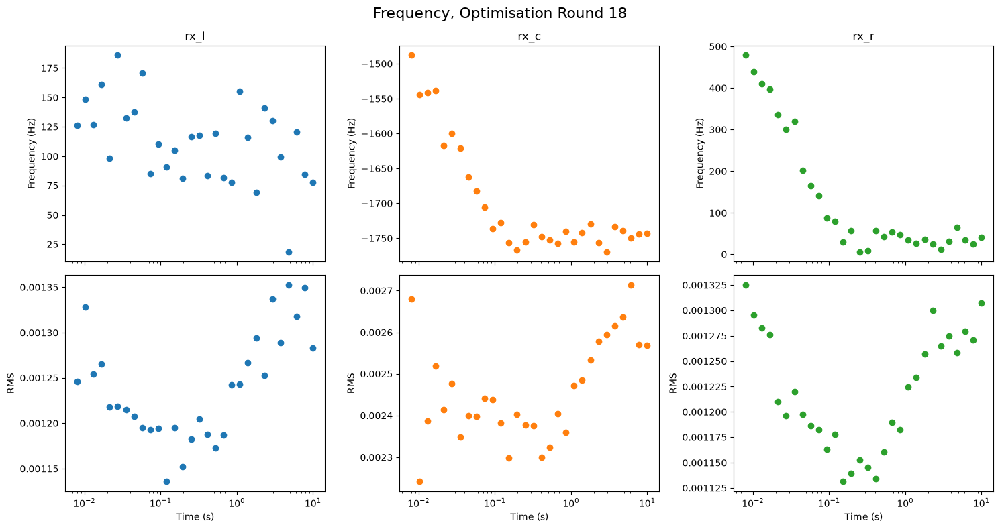

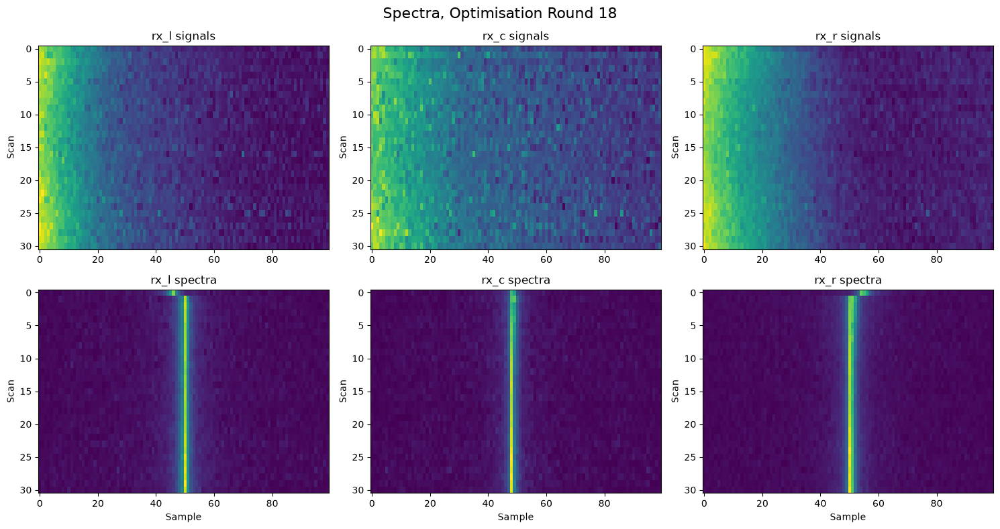

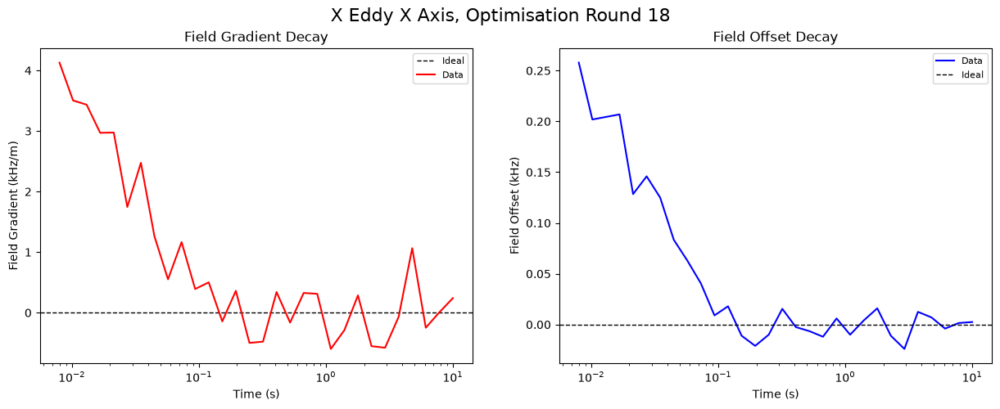

[I 2026-11-26 09:31:57,280] Trial 18 finished with value: 3528.352214248126 and parameters: {'X_A1': 0.09548658631235073, 'X_A2': 0.06891303571680718, 'X_A3': 0.031339530225389475, 'X_A4': -2.0892788518212446e-09}. Best is trial 10 with value: 2427.7514891041947.


max |E| = 3523.2383808095947
mean |E| = 1036.3151757454605
RMS E = 1371.6616106248812
Total cost = 3.528e+03
E max = 0.12276570701127479
E nanmax = 0.12276570701127479
E contains nan = False
B max = 0.01950508987022653
B nanmax = 0.01950508987022653
B contains nan = False
Trial 19


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01950508987022653 !!!!!!!!!!!!!!!!


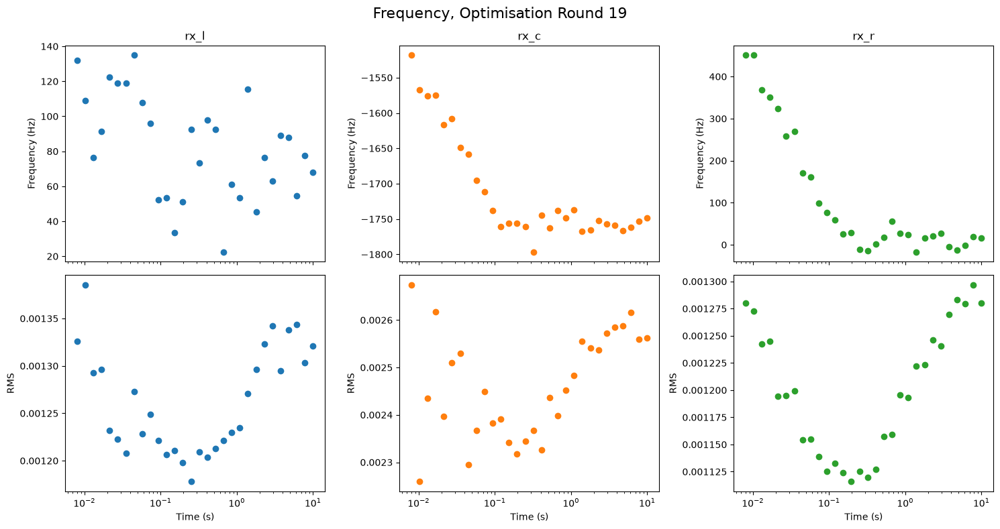

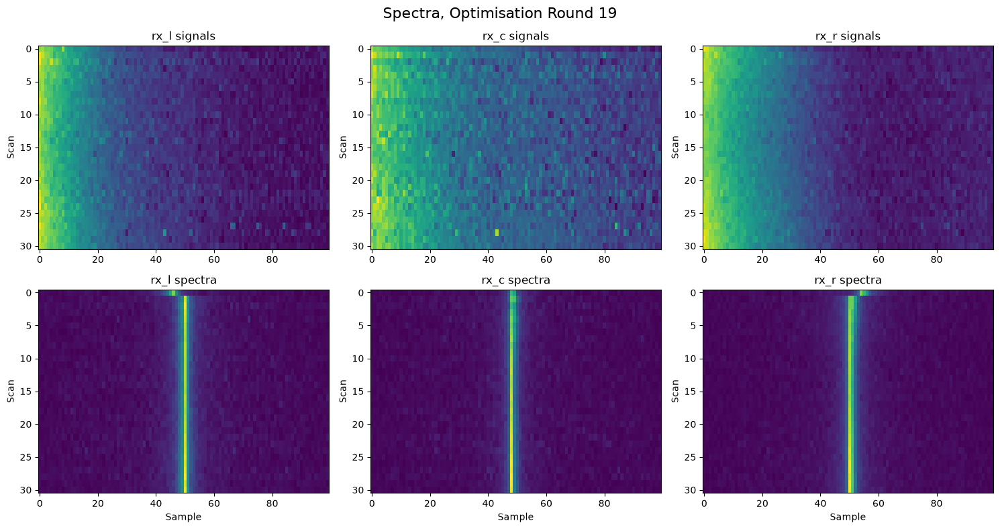

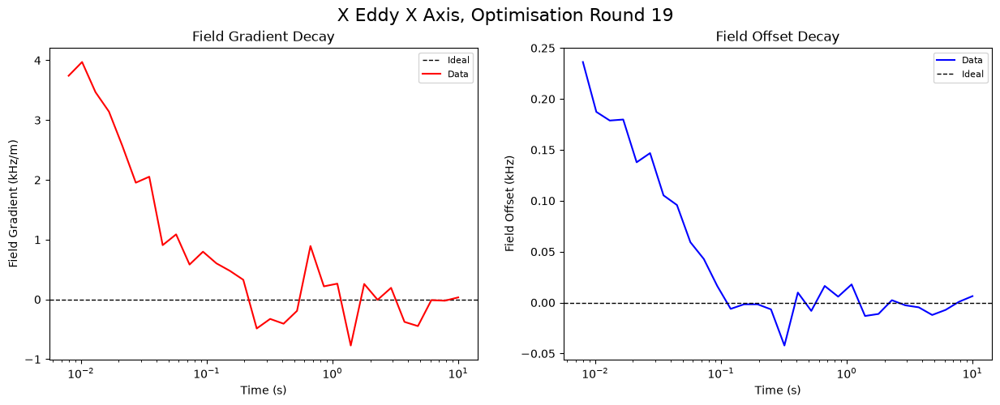

[I 2026-11-26 09:33:18,728] Trial 19 finished with value: 2081.369031899241 and parameters: {'X_A1': 0.09617145479344547, 'X_A2': 0.06725619456369565, 'X_A3': 0.03715240702989362, 'X_A4': -8.37756208606397e-09}. Best is trial 19 with value: 2081.369031899241.


max |E| = 3418.2908545727128
mean |E| = 975.0124937531232
RMS E = 1348.344298196409
Total cost = 2.081e+03
E max = 0.12098636741962997
E nanmax = 0.12098636741962997
E contains nan = False
B max = 0.019222390625051496
B nanmax = 0.019222390625051496
B contains nan = False
Trial 20


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019222390625051496 !!!!!!!!!!!!!!!!


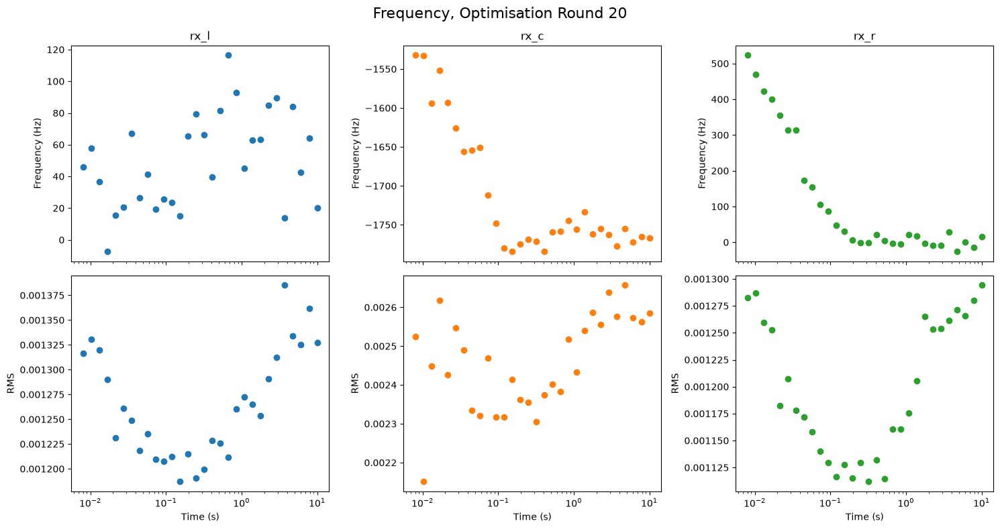

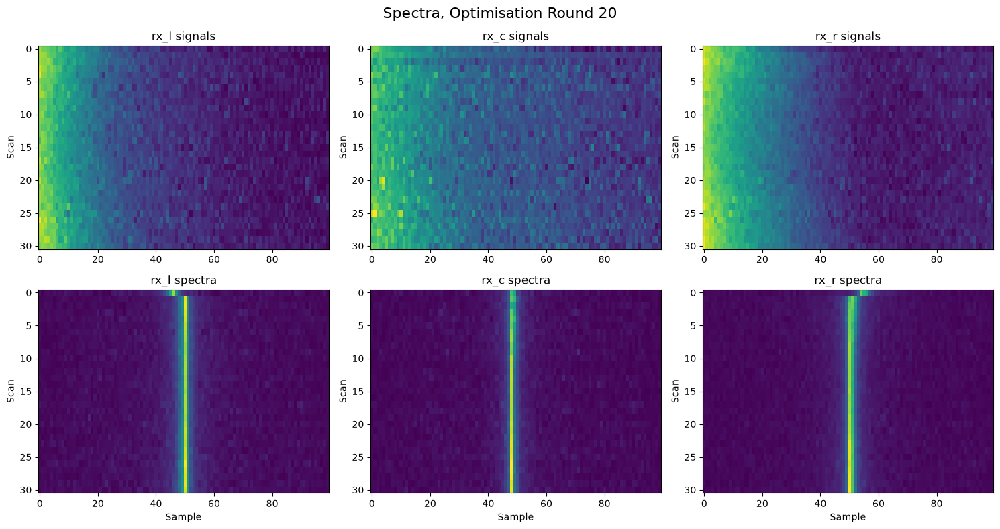

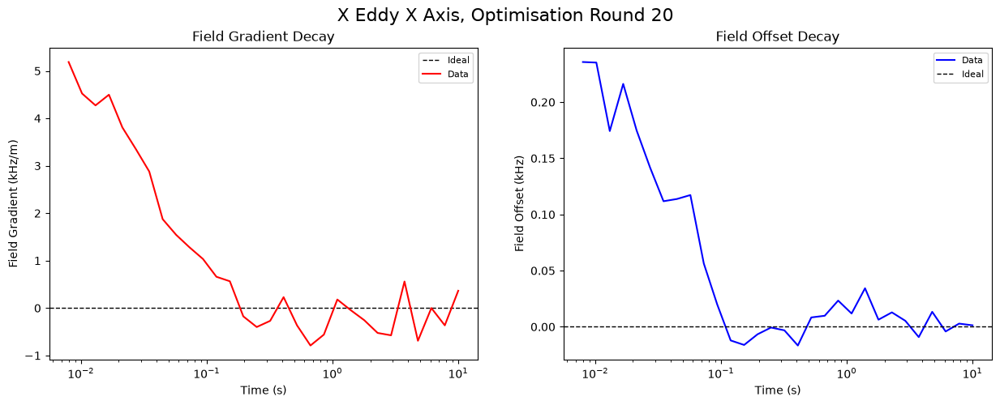

[I 2026-11-26 09:34:40,097] Trial 20 finished with value: 3963.116983049911 and parameters: {'X_A1': 0.09020910325758205, 'X_A2': 0.05932659556177501, 'X_A3': 0.03750954126614332, 'X_A4': -2.0782341370814595e-09}. Best is trial 19 with value: 2081.369031899241.


max |E| = 4772.613693153423
mean |E| = 1370.1482592037314
RMS E = 1925.0045708149257
Total cost = 3.963e+03
E max = 0.12238982840486952
E nanmax = 0.12238982840486952
E contains nan = False
B max = 0.01944538468654716
B nanmax = 0.01944538468654716
B contains nan = False
Trial 21


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01944538468654716 !!!!!!!!!!!!!!!!


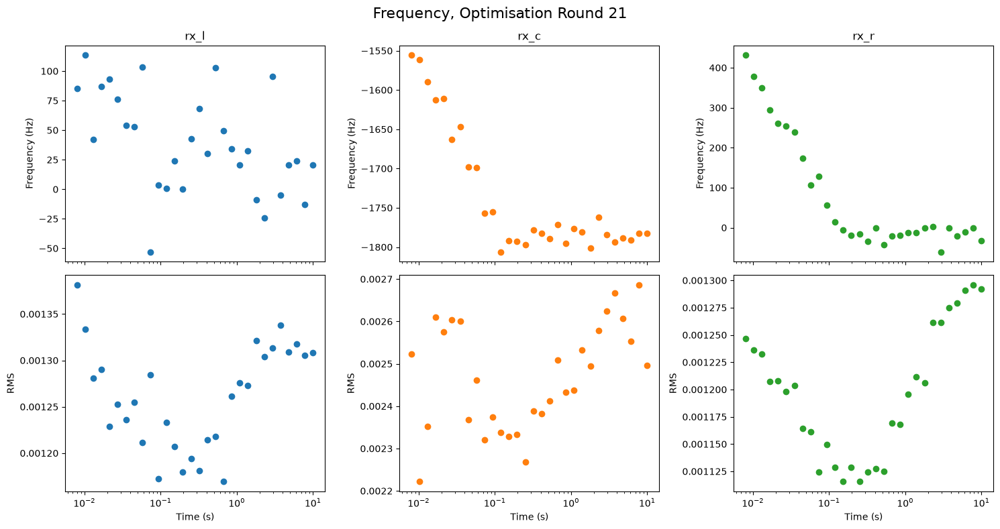

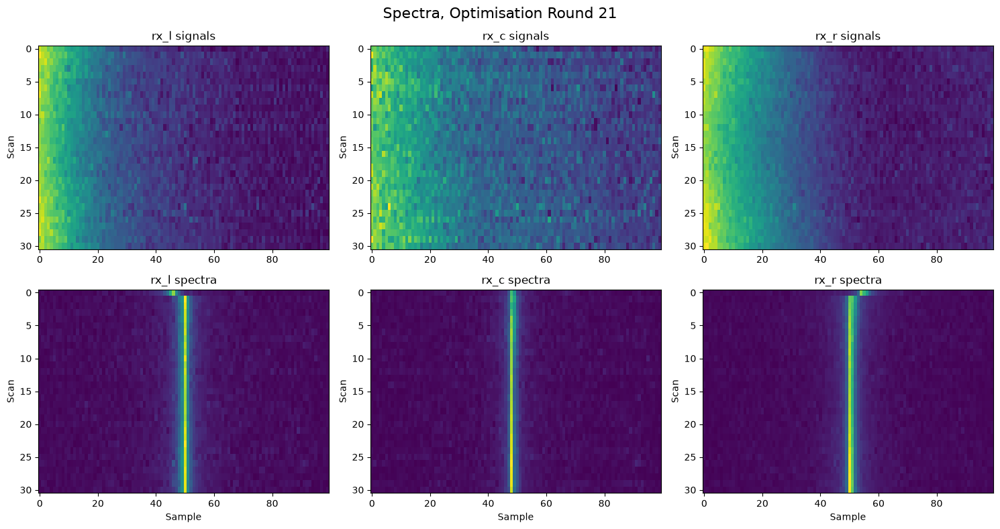

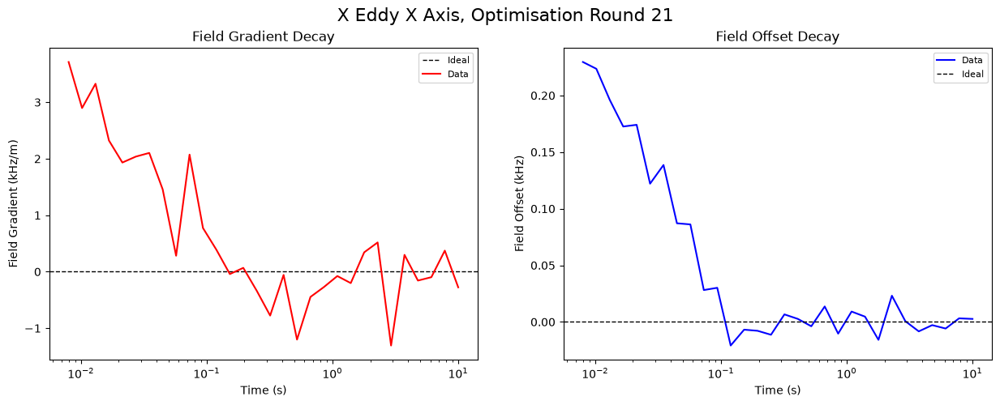

[I 2026-11-26 09:36:01,020] Trial 21 finished with value: 3664.913564467903 and parameters: {'X_A1': 0.09827303674947187, 'X_A2': 0.06594678093151145, 'X_A3': 0.032997782813875755, 'X_A4': -8.686765440555157e-09}. Best is trial 19 with value: 2081.369031899241.


max |E| = 3458.2708645677153
mean |E| = 983.5082458770612
RMS E = 1354.7807117876823
Total cost = 3.665e+03
E max = 0.11904996317914561
E nanmax = 0.11904996317914561
E contains nan = False
B max = 0.018914735730442167
B nanmax = 0.018914735730442167
B contains nan = False
Trial 22


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.018914735730442167 !!!!!!!!!!!!!!!!


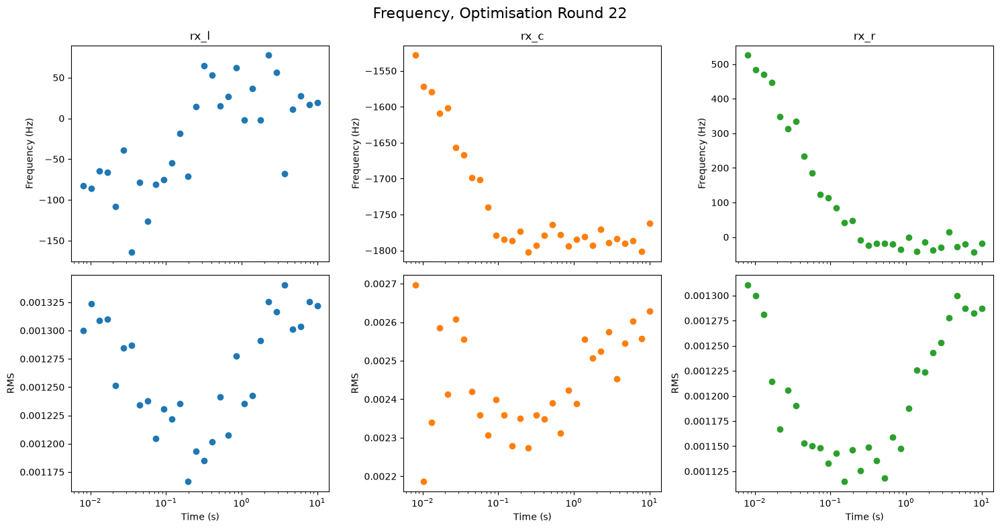

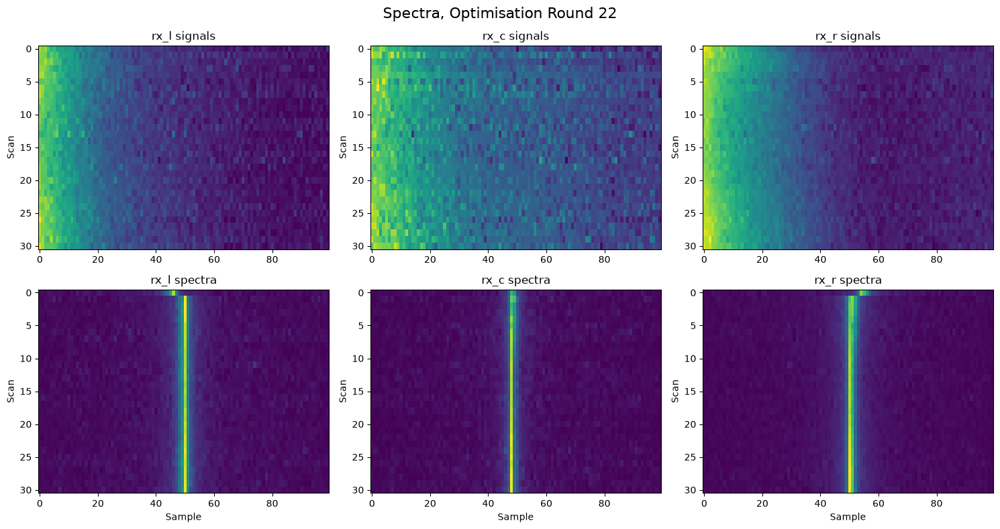

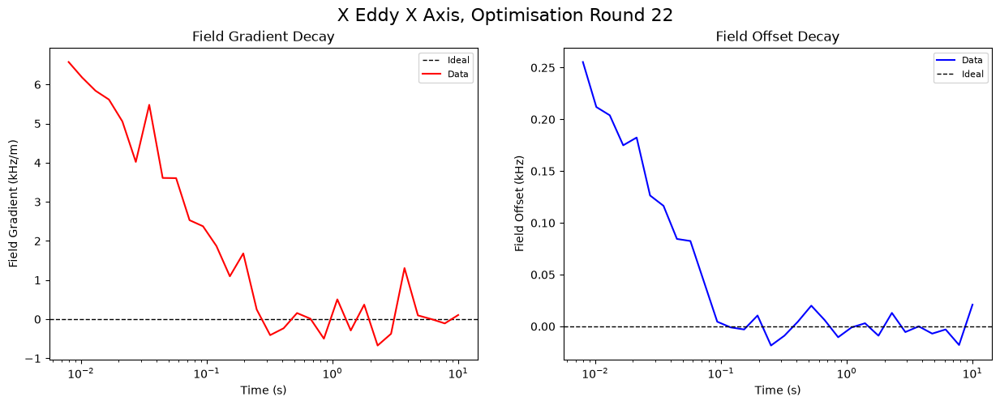

[I 2026-11-26 09:37:22,236] Trial 22 finished with value: 3450.9259793660785 and parameters: {'X_A1': 0.0738619493556596, 'X_A2': 0.06130674906648582, 'X_A3': 0.037045204376917516, 'X_A4': -6.54088260836881e-09}. Best is trial 19 with value: 2081.369031899241.


max |E| = 6086.95652173913
mean |E| = 1931.867399633516
RMS E = 2711.3126180412846
Total cost = 3.451e+03
E max = 0.12128277369651441
E nanmax = 0.12128277369651441
E contains nan = False
B max = 0.019269480228801227
B nanmax = 0.019269480228801227
B contains nan = False
Trial 23


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019269480228801227 !!!!!!!!!!!!!!!!


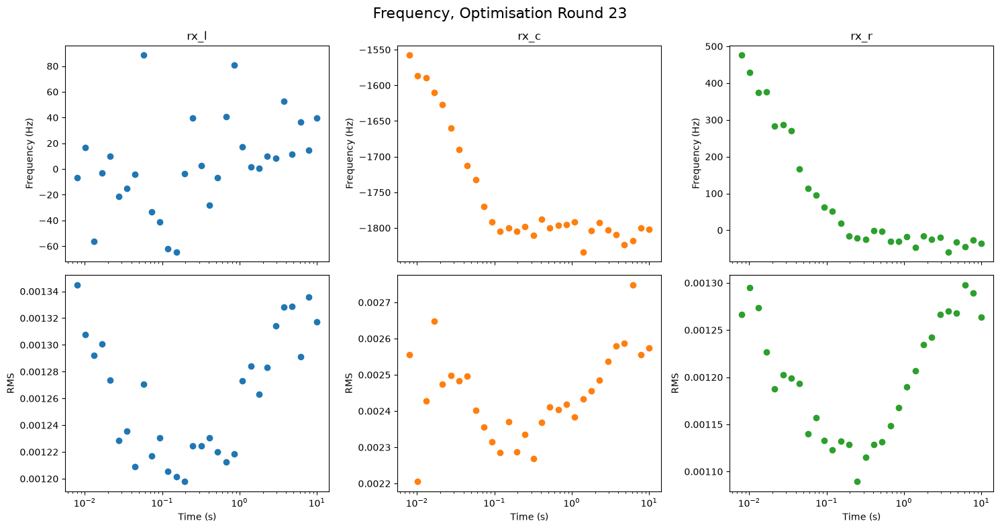

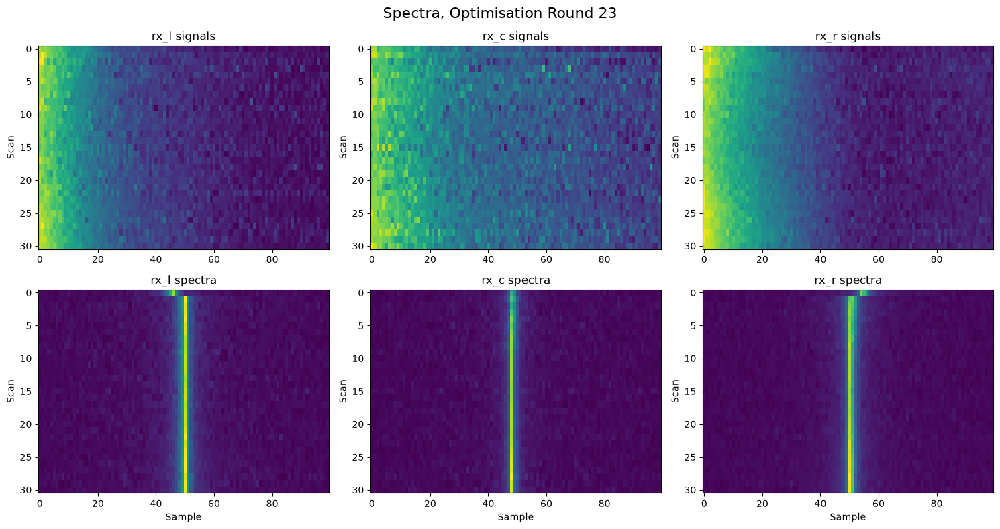

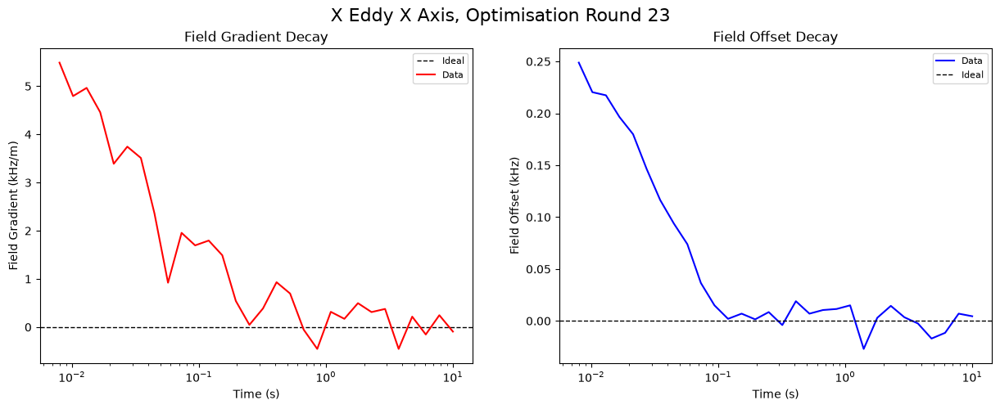

[I 2026-11-26 09:38:43,162] Trial 23 finished with value: 3009.1636786716144 and parameters: {'X_A1': 0.08485781615360927, 'X_A2': 0.0670867830303318, 'X_A3': 0.037610188781971074, 'X_A4': -7.555061922180337e-09}. Best is trial 19 with value: 2081.369031899241.


max |E| = 4827.586206896551
mean |E| = 1343.1617524571045
RMS E = 1930.4450998138655
Total cost = 3.009e+03
E max = 0.12363446605609216
E nanmax = 0.12363446605609216
E contains nan = False
B max = 0.019643104257260527
B nanmax = 0.019643104257260527
B contains nan = False
Trial 24


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019643104257260527 !!!!!!!!!!!!!!!!


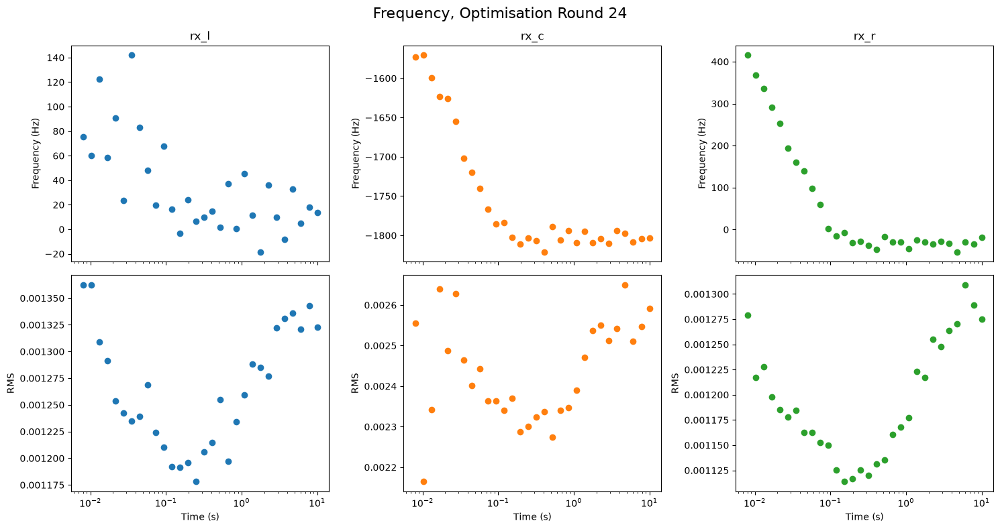

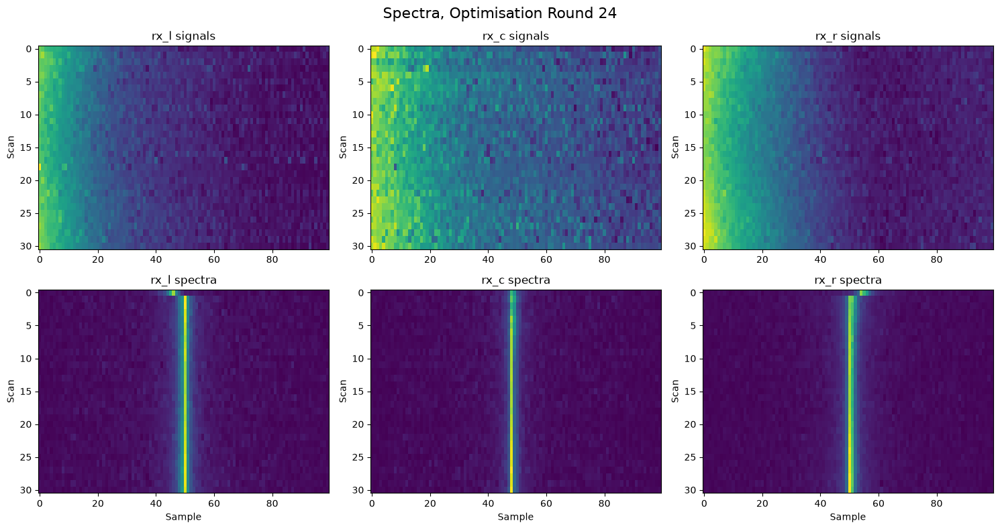

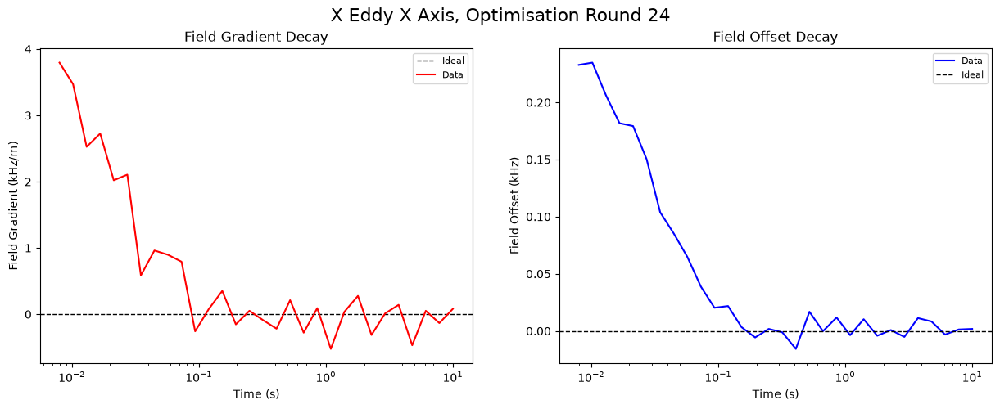

[I 2026-11-26 09:40:04,084] Trial 24 finished with value: 1832.9405883916054 and parameters: {'X_A1': 0.09635516368657725, 'X_A2': 0.07030143543469829, 'X_A3': 0.040888043716266725, 'X_A4': -1.6061305427819383e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3398.300849575212
mean |E| = 829.751790771281
RMS E = 1188.4379504802375
Total cost = 1.833e+03
E max = 0.11818874570477216
E nanmax = 0.11818874570477216
E contains nan = False
B max = 0.018777934597044854
B nanmax = 0.018777934597044854
B contains nan = False
Trial 25


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.018777934597044854 !!!!!!!!!!!!!!!!


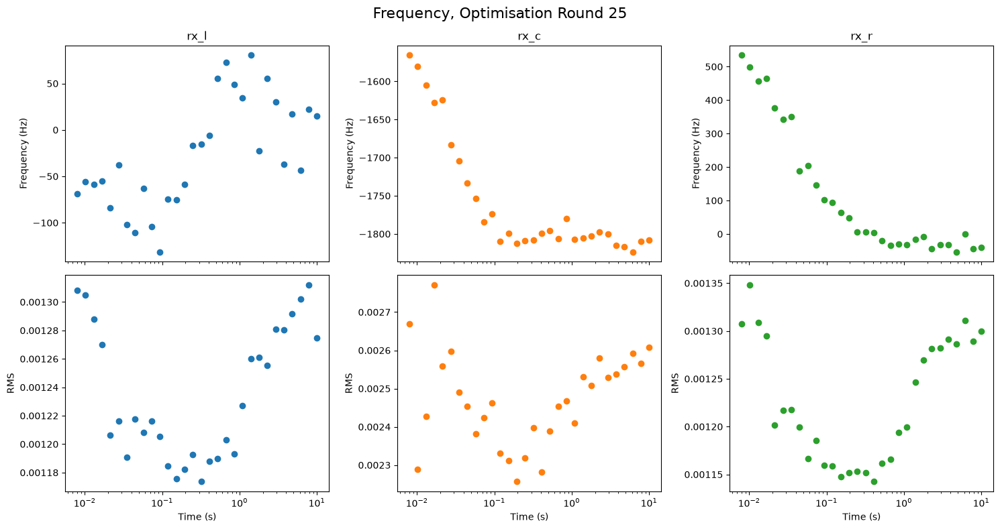

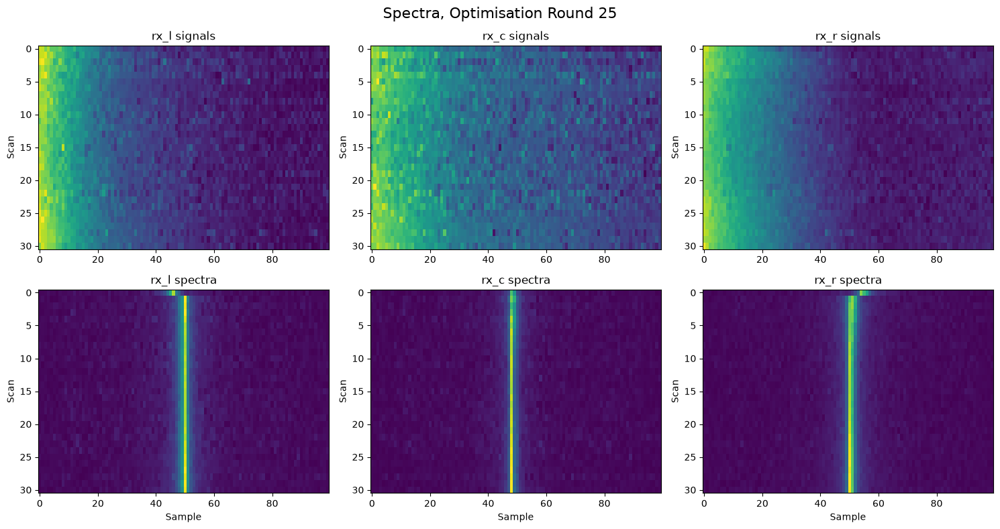

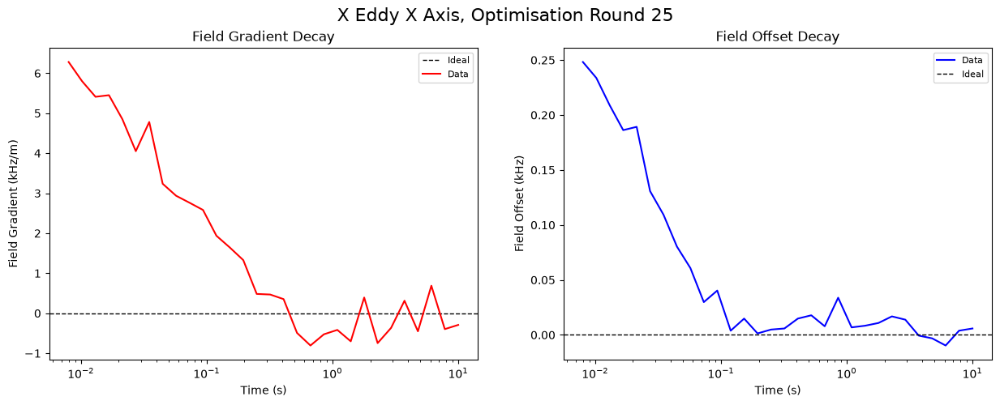

[I 2026-11-26 09:41:25,728] Trial 25 finished with value: 5123.2504760958755 and parameters: {'X_A1': 0.06588688251929667, 'X_A2': 0.07191463159170647, 'X_A3': 0.026673792789748678, 'X_A4': 2.1470860915674544e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 6026.986506746625
mean |E| = 1947.0264867566211
RMS E = 2689.9728444306666
Total cost = 5.123e+03
E max = 0.12182275993896186
E nanmax = 0.12182275993896186
E contains nan = False
B max = 0.01935529398071134
B nanmax = 0.01935529398071134
B contains nan = False
Trial 26


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01935529398071134 !!!!!!!!!!!!!!!!


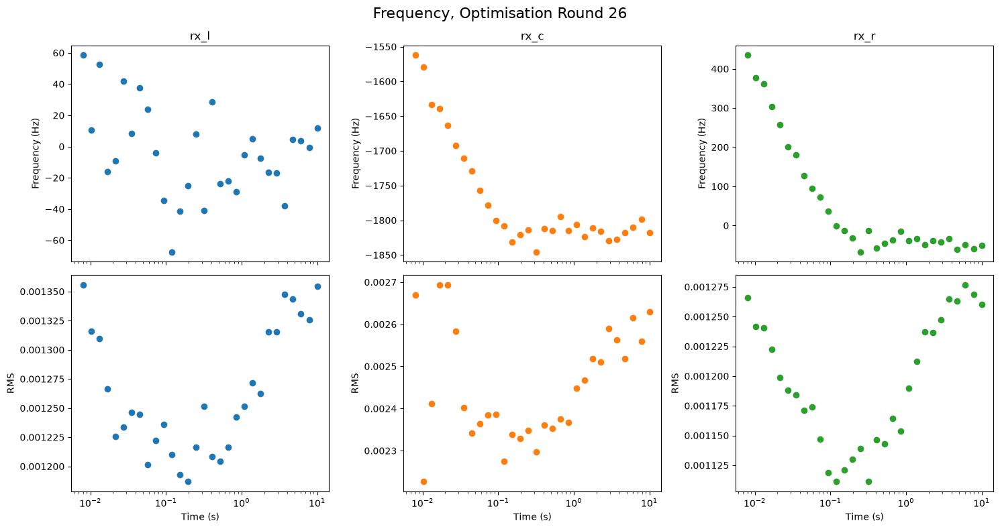

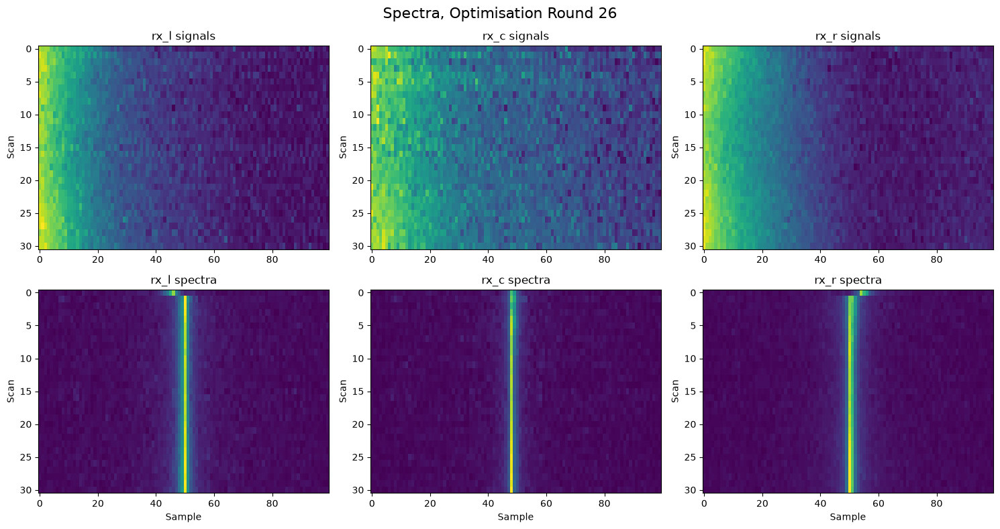

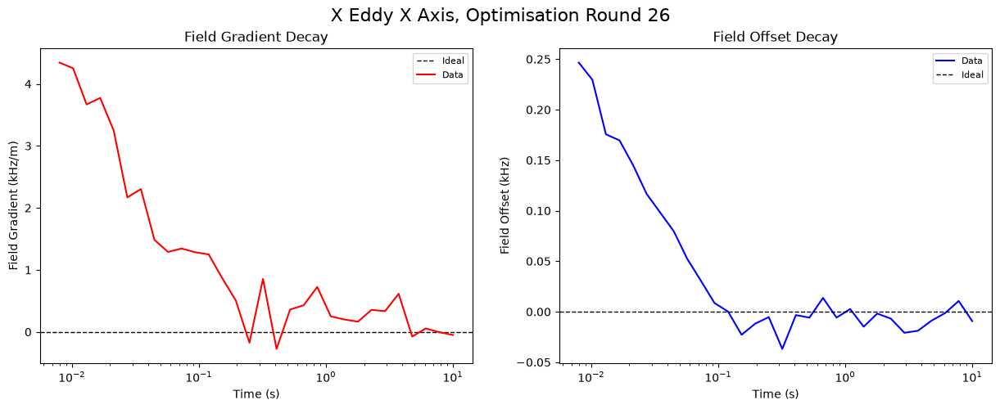

[I 2026-11-26 09:42:47,258] Trial 26 finished with value: 2120.5700069831814 and parameters: {'X_A1': 0.08770171651772399, 'X_A2': 0.07488681174346846, 'X_A3': 0.03035694896477831, 'X_A4': -5.106092806894603e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3763.118440779609
mean |E| = 1007.6628352490419
RMS E = 1487.3627776165051
Total cost = 2.121e+03
E max = 0.12114102055732201
E nanmax = 0.12114102055732201
E contains nan = False
B max = 0.019246965643095672
B nanmax = 0.019246965643095672
B contains nan = False
Trial 27


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019246965643095672 !!!!!!!!!!!!!!!!


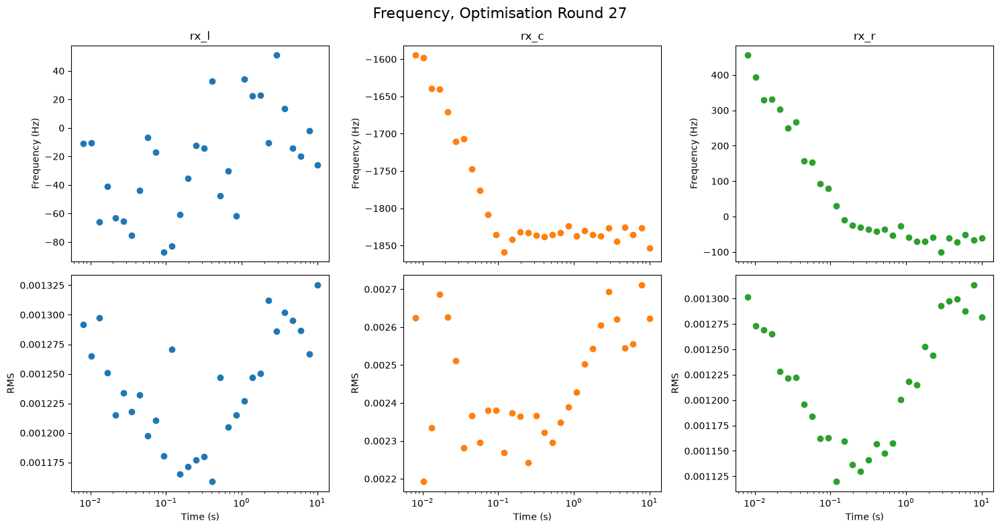

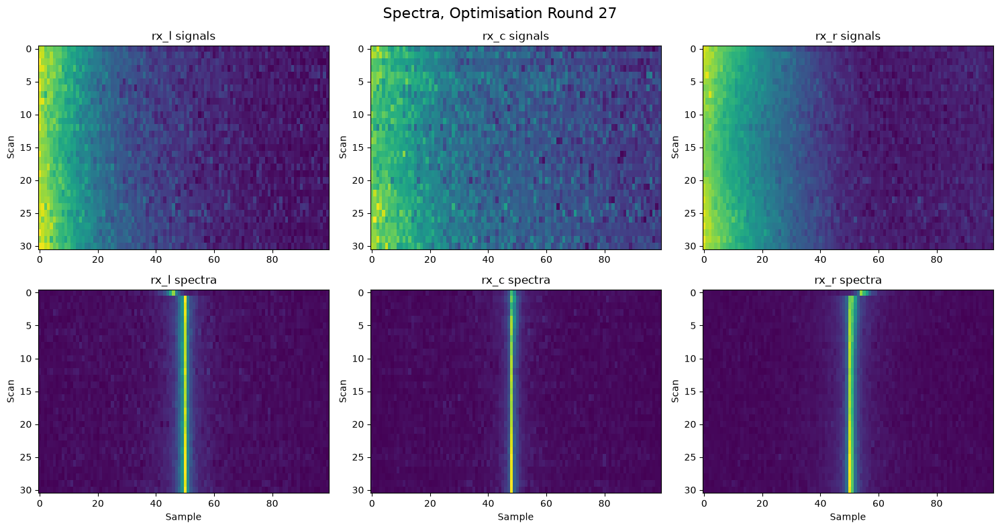

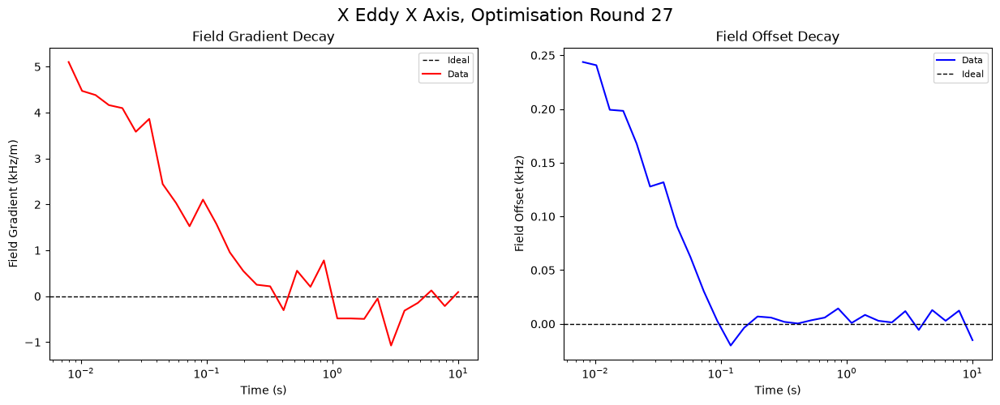

[I 2026-11-26 09:44:08,504] Trial 27 finished with value: 3204.348973103216 and parameters: {'X_A1': 0.07797886163791933, 'X_A2': 0.0759208772485677, 'X_A3': 0.03437695963881088, 'X_A4': -7.2792579482973626e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 4667.6661669165405
mean |E| = 1466.4334499416955
RMS E = 2018.3634518742438
Total cost = 3.204e+03
E max = 0.12415572411724143
E nanmax = 0.12415572411724143
E contains nan = False
B max = 0.019725936115718466
B nanmax = 0.019725936115718466
B contains nan = False
Trial 28


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019725936115718466 !!!!!!!!!!!!!!!!


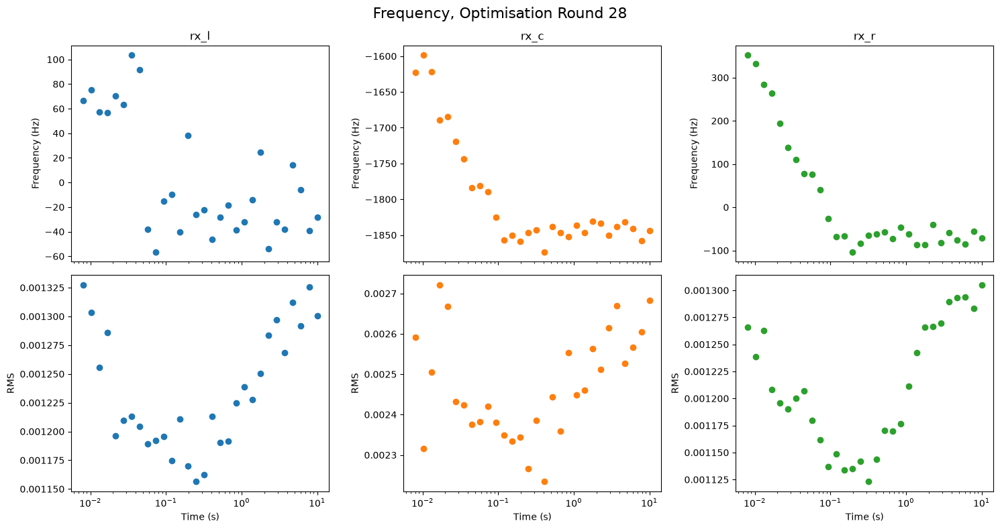

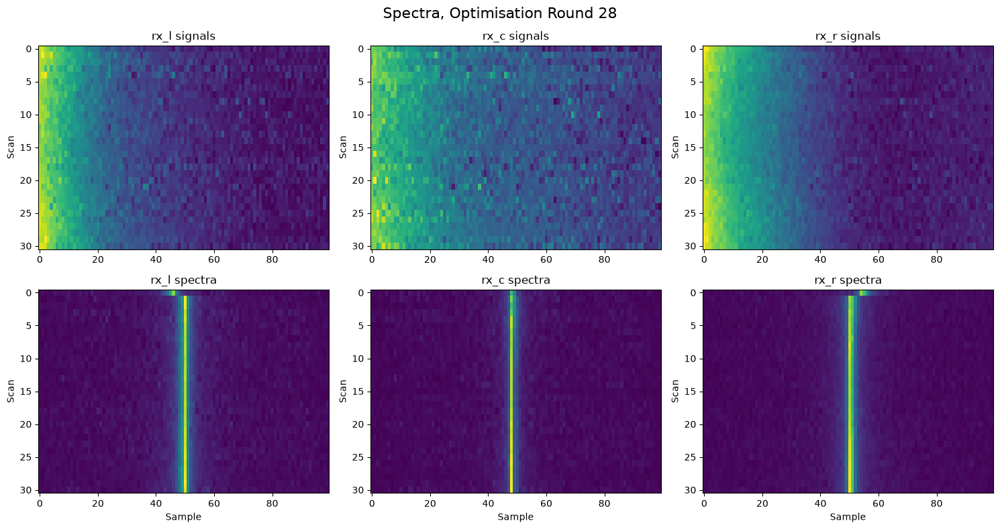

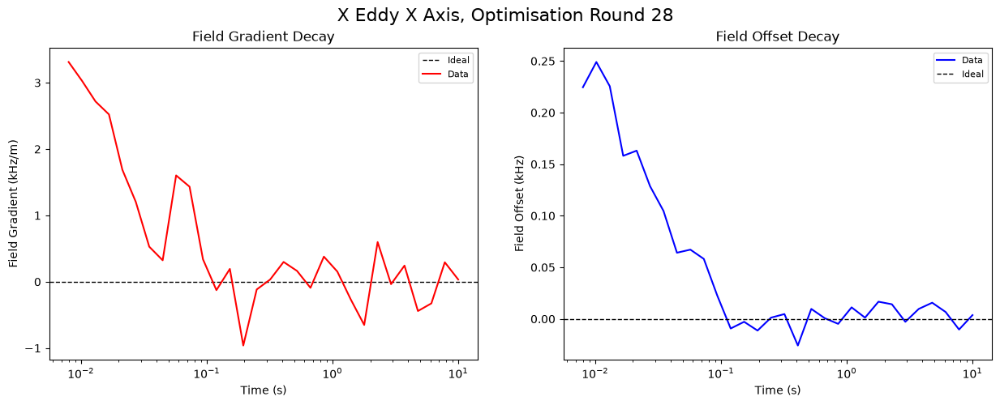

[I 2026-11-26 09:45:29,927] Trial 28 finished with value: 2969.2447142630335 and parameters: {'X_A1': 0.1014346923342142, 'X_A2': 0.07315618759661426, 'X_A3': 0.036268439465052545, 'X_A4': -8.966968077356204e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 2853.5732133933025
mean |E| = 792.6036981509243
RMS E = 1089.5951017281225
Total cost = 2.969e+03
E max = 0.12355618721038976
E nanmax = 0.12355618721038976
E contains nan = False
B max = 0.019630672030278917
B nanmax = 0.019630672030278917
B contains nan = False
Trial 29


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019630672030278917 !!!!!!!!!!!!!!!!


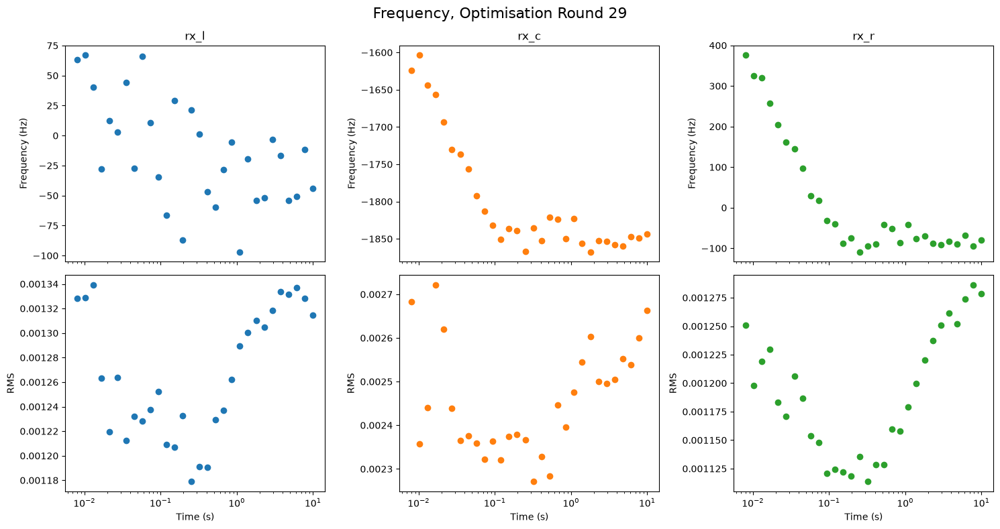

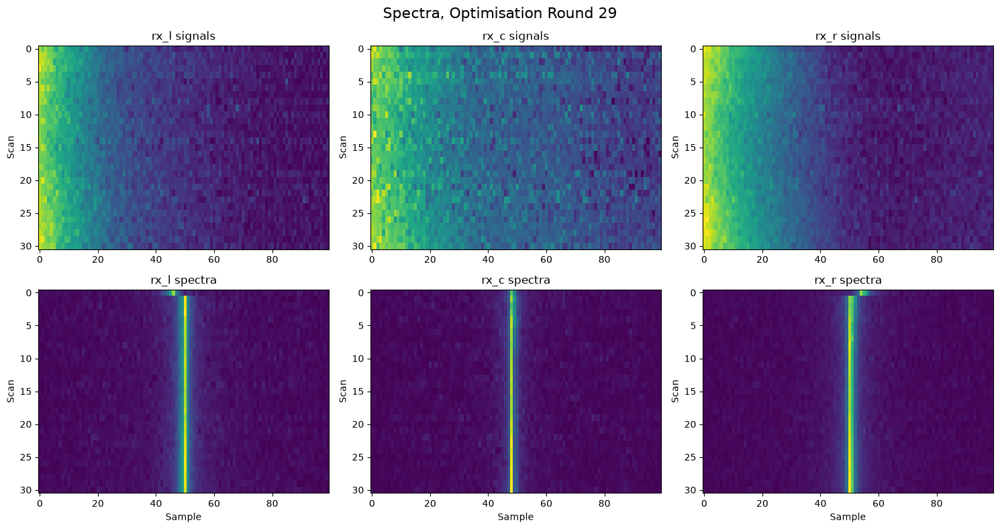

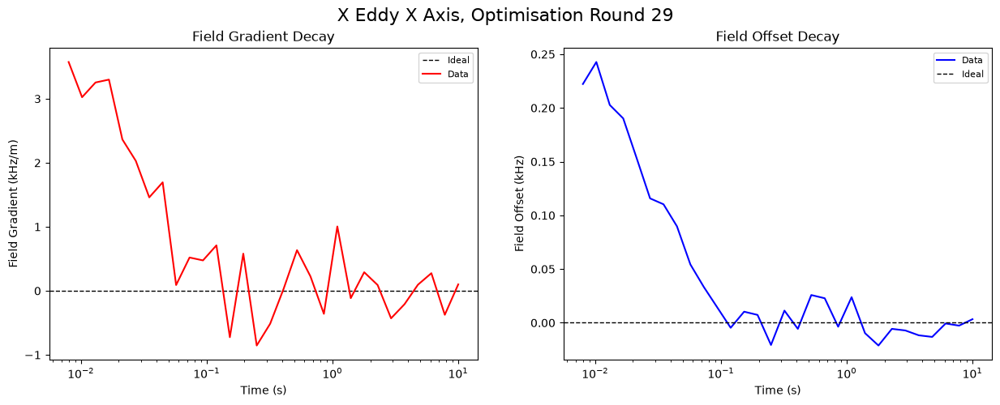

[I 2026-11-26 09:46:51,794] Trial 29 finished with value: 2852.6235923165477 and parameters: {'X_A1': 0.10178829198110843, 'X_A2': 0.06468917988350684, 'X_A3': 0.04017267086340371, 'X_A4': -8.577535870750325e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3123.438280859569
mean |E| = 930.2015658837246
RMS E = 1280.3048112832748
Total cost = 2.853e+03
E max = 0.1217969927514805
E nanmax = 0.1217969927514805
E contains nan = False
B max = 0.019351195843477623
B nanmax = 0.019351195843477623
B contains nan = False
Trial 30


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019351195843477623 !!!!!!!!!!!!!!!!


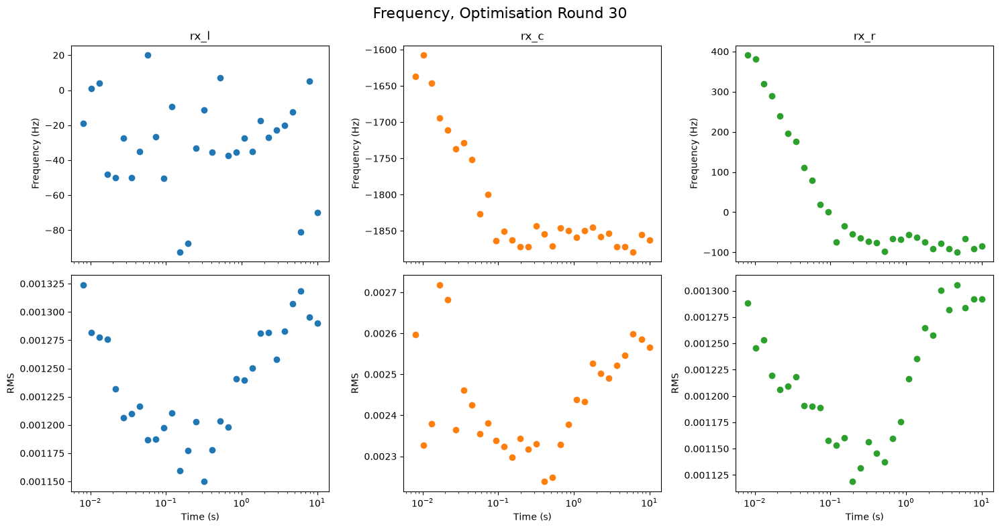

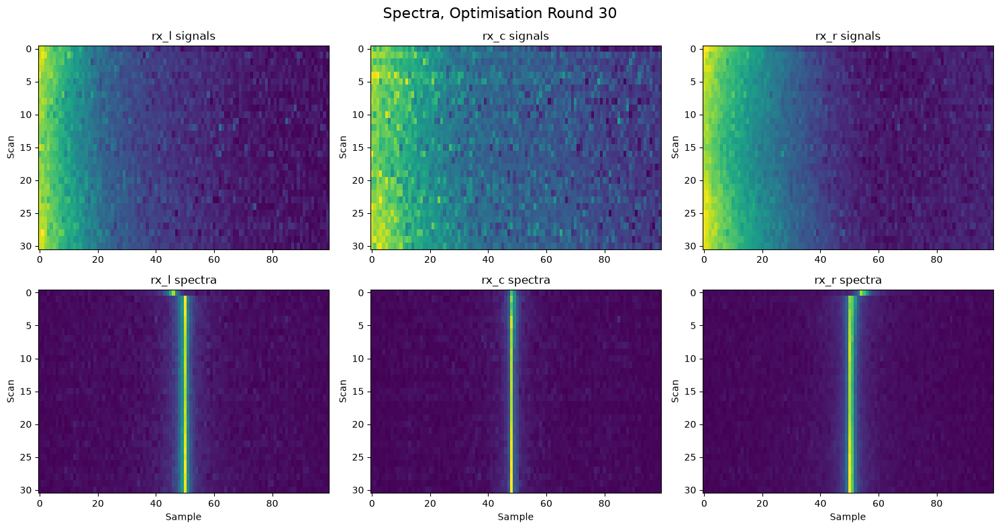

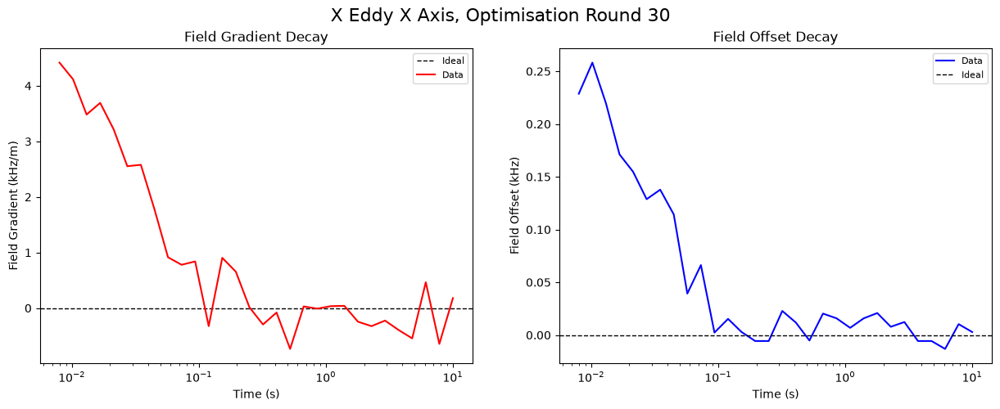

[I 2026-11-26 09:48:13,969] Trial 30 finished with value: 4024.1575296360866 and parameters: {'X_A1': 0.08980321318332116, 'X_A2': 0.07093629563174747, 'X_A3': 0.03213510164502711, 'X_A4': -6.113370047931679e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 4097.951024487755
mean |E| = 1151.9240379810092
RMS E = 1635.6445716196126
Total cost = 4.024e+03
E max = 0.1221322503211942
E nanmax = 0.1221322503211942
E contains nan = False
B max = 0.019404479060847177
B nanmax = 0.019404479060847177
B contains nan = False
Trial 31


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019404479060847177 !!!!!!!!!!!!!!!!


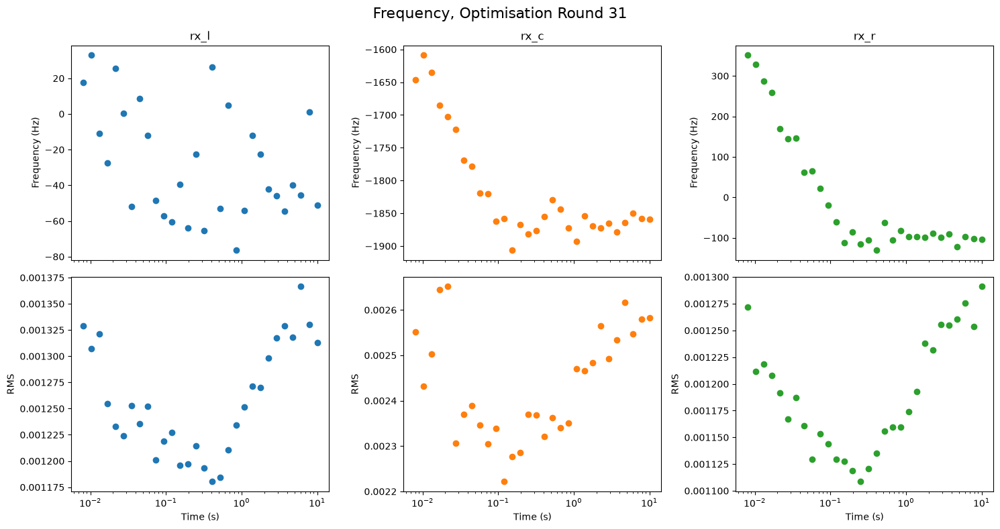

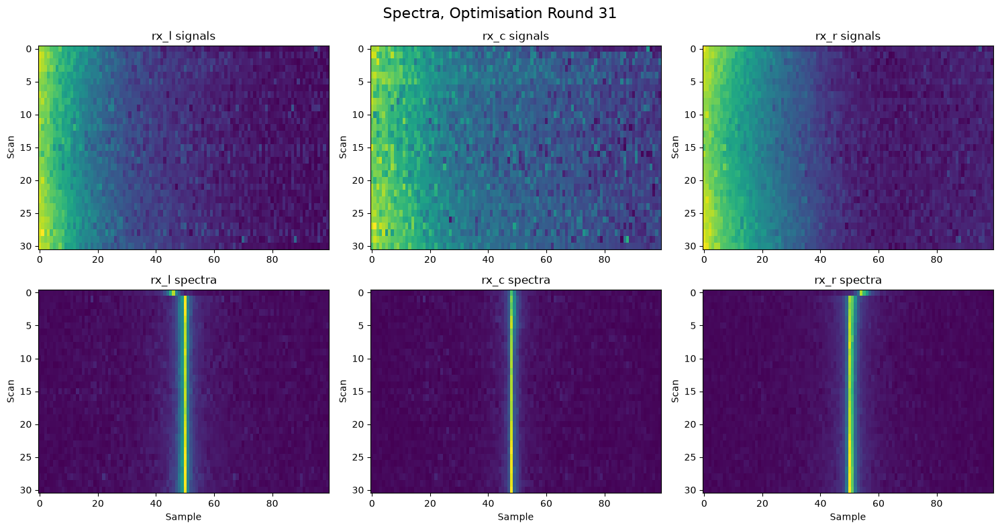

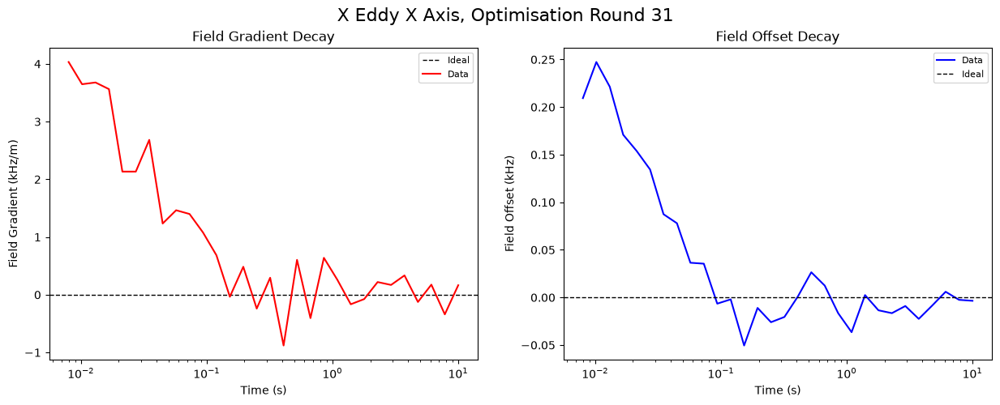

[I 2026-11-26 09:49:36,647] Trial 31 finished with value: 2603.703911646393 and parameters: {'X_A1': 0.09596500868226711, 'X_A2': 0.07207597467873753, 'X_A3': 0.026657813184596837, 'X_A4': -7.02489477355056e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3338.3308345827077
mean |E| = 1027.9860069965014
RMS E = 1370.8389757259683
Total cost = 2.604e+03
E max = 0.1234593719731338
E nanmax = 0.1234593719731338
E contains nan = False
B max = 0.019615285802280148
B nanmax = 0.019615285802280148
B contains nan = False
Trial 32


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019615285802280148 !!!!!!!!!!!!!!!!


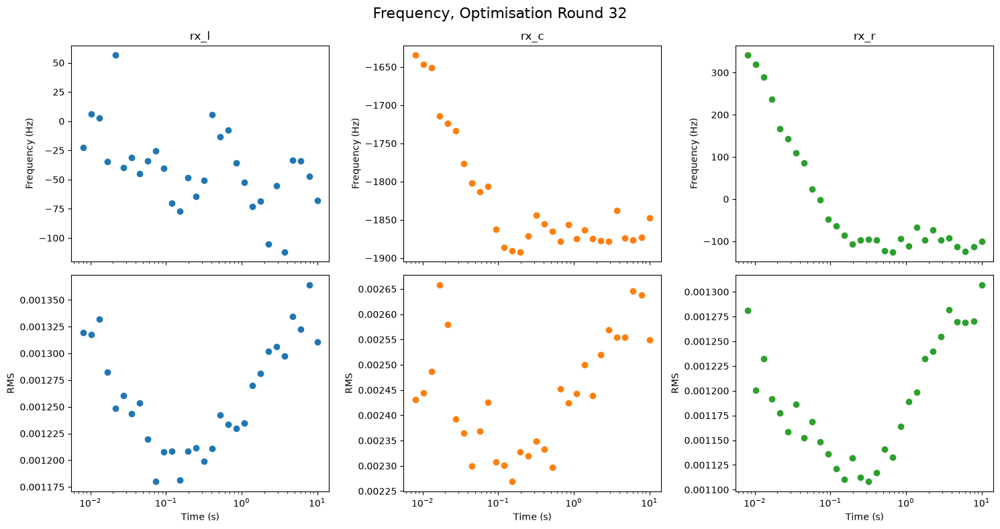

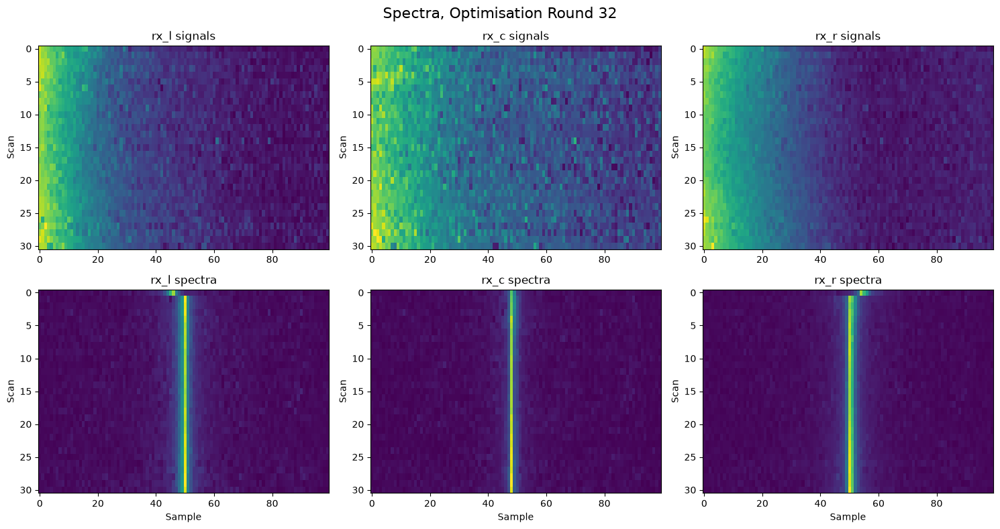

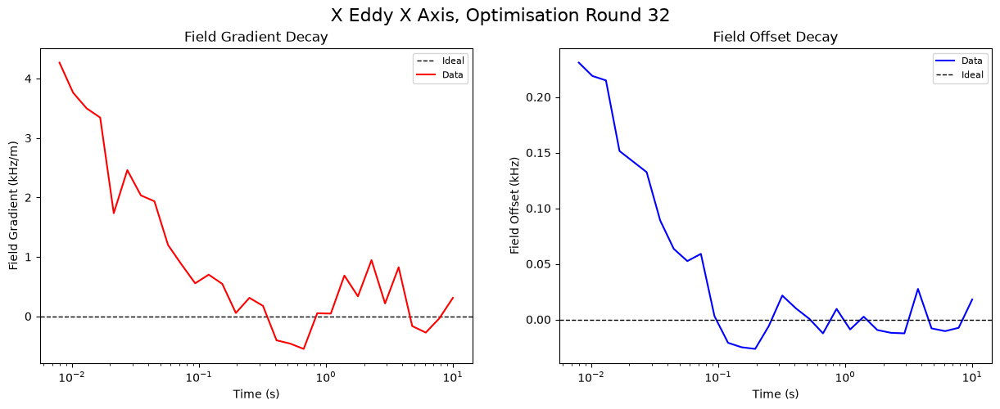

[I 2026-11-26 09:50:30,194] Trial 32 finished with value: 3306.855535771516 and parameters: {'X_A1': 0.09636425982965327, 'X_A2': 0.06892943925025437, 'X_A3': 0.04092196408814622, 'X_A4': -4.791783160380808e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3638.1809095452263
mean |E| = 960.3531567549555
RMS E = 1349.6186772782514
Total cost = 3.307e+03
E max = 0.12248254182991762
E nanmax = 0.12248254182991762
E contains nan = False
B max = 0.01946007854391794
B nanmax = 0.01946007854391794
B contains nan = False
Trial 33


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01946007854391794 !!!!!!!!!!!!!!!!


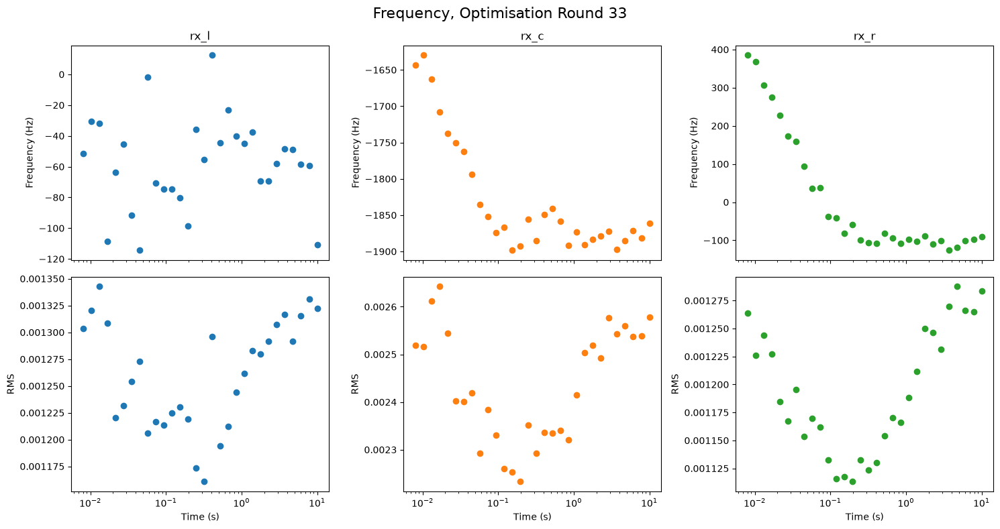

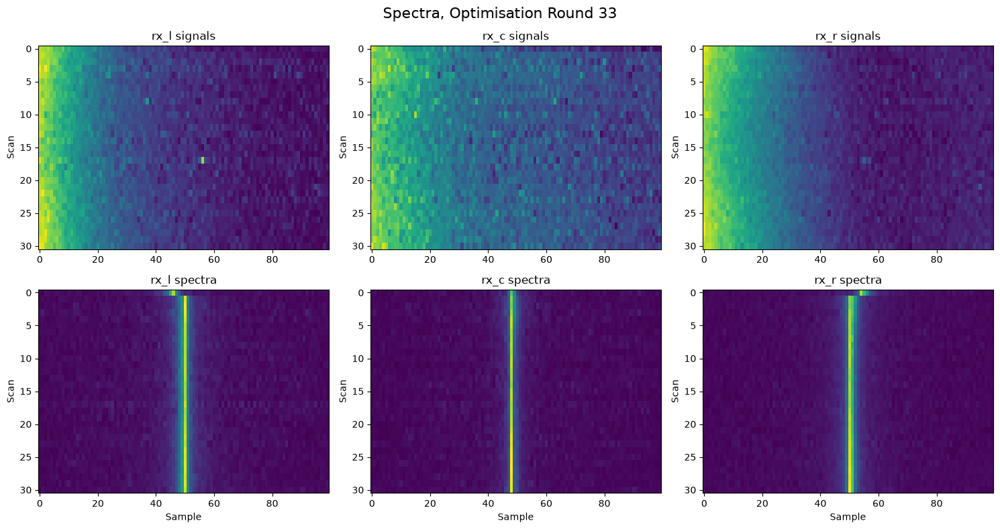

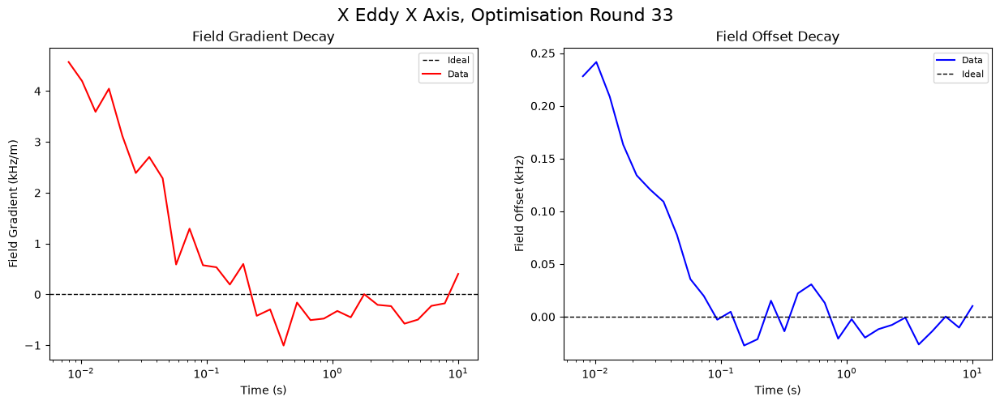

[I 2026-11-26 09:51:18,141] Trial 33 finished with value: 3365.555755272267 and parameters: {'X_A1': 0.08930056194637262, 'X_A2': 0.06609208248010551, 'X_A3': 0.04385081940625943, 'X_A4': -7.197061915825675e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 4367.816091954021
mean |E| = 1221.722472097284
RMS E = 1756.9473614538763
Total cost = 3.366e+03
E max = 0.12247886592695746
E nanmax = 0.12247886592695746
E contains nan = False
B max = 0.019459519883941744
B nanmax = 0.019459519883941744
B contains nan = False
Trial 34


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019459519883941744 !!!!!!!!!!!!!!!!


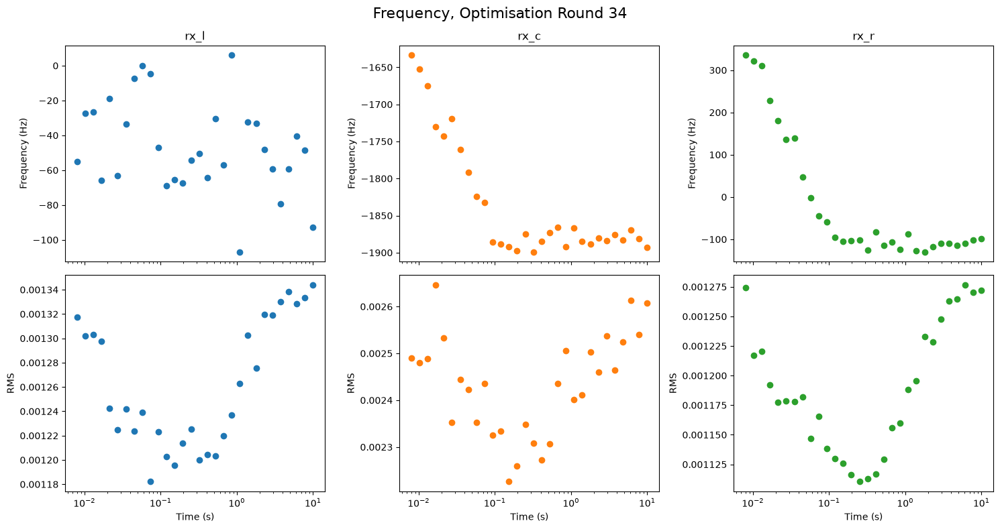

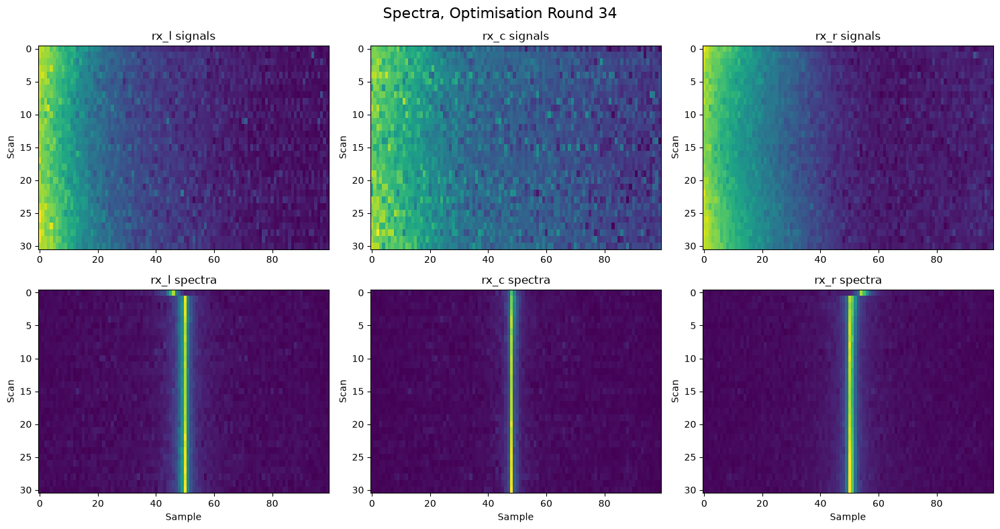

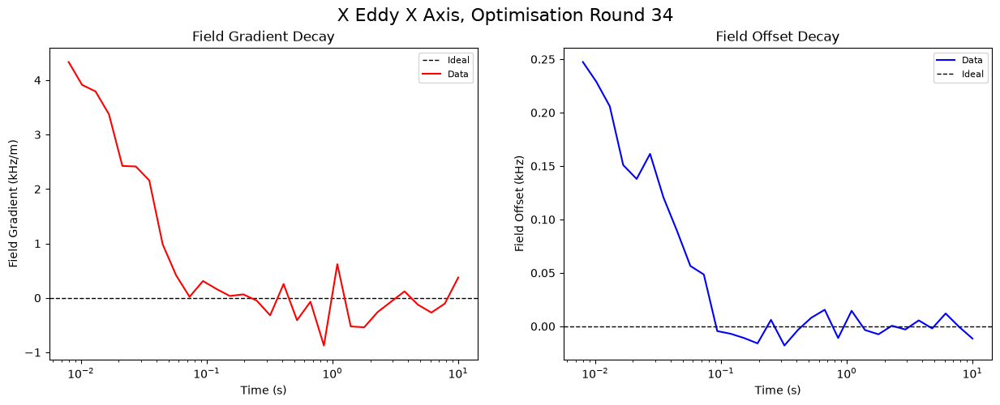

[I 2026-11-26 09:52:06,315] Trial 34 finished with value: 2498.868833822637 and parameters: {'X_A1': 0.10105622001680087, 'X_A2': 0.060044204132496184, 'X_A3': 0.037027376836986675, 'X_A4': -6.194760583423948e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3903.0484757621184
mean |E| = 1034.31617524571
RMS E = 1487.3706136187352
Total cost = 2.499e+03
E max = 0.12218361238411232
E nanmax = 0.12218361238411232
E contains nan = False
B max = 0.019412625252375446
B nanmax = 0.019412625252375446
B contains nan = False
Trial 35


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019412625252375446 !!!!!!!!!!!!!!!!


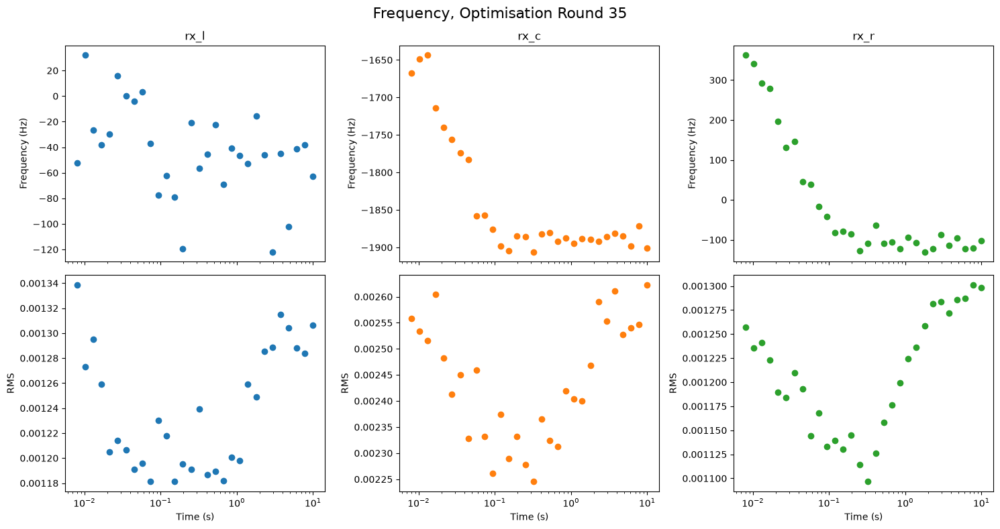

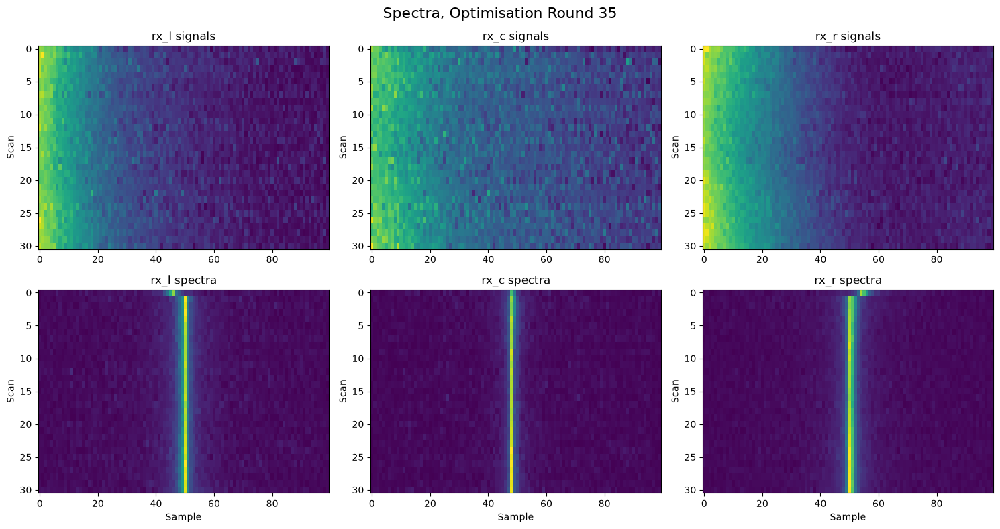

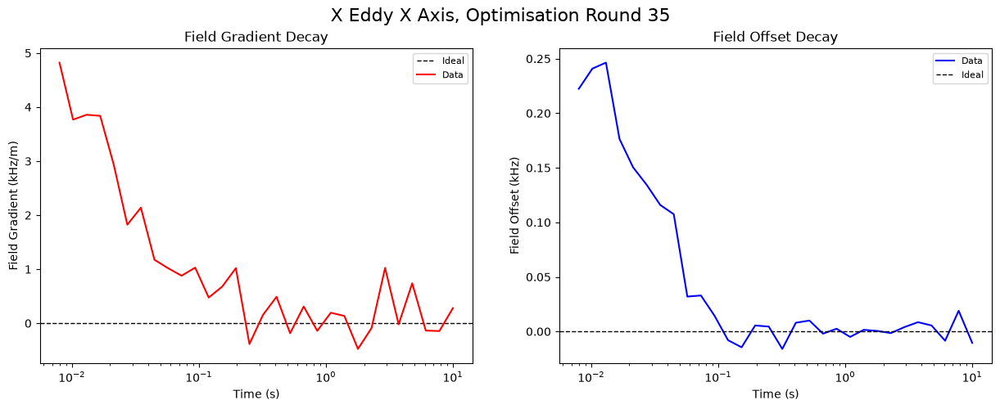

[I 2026-11-26 09:52:54,094] Trial 35 finished with value: 3232.6340780674927 and parameters: {'X_A1': 0.0977968291275974, 'X_A2': 0.06599868244195559, 'X_A3': 0.0317332961702866, 'X_A4': -5.718157225931645e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 4147.926036981508
mean |E| = 1009.4952523738128
RMS E = 1456.720323897516
Total cost = 3.233e+03
E max = 0.12280512754092356
E nanmax = 0.12280512754092356
E contains nan = False
B max = 0.019511348968607335
B nanmax = 0.019511348968607335
B contains nan = False
Trial 36


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019511348968607335 !!!!!!!!!!!!!!!!


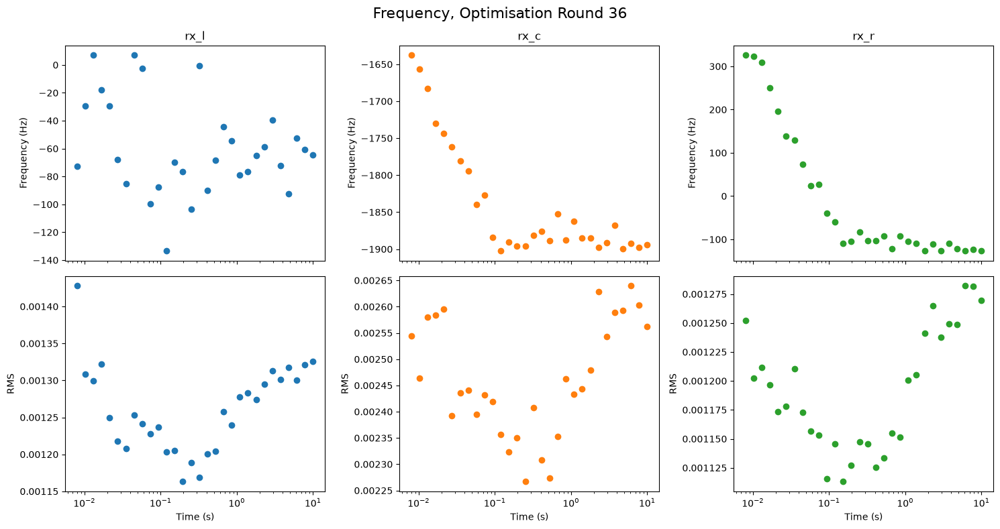

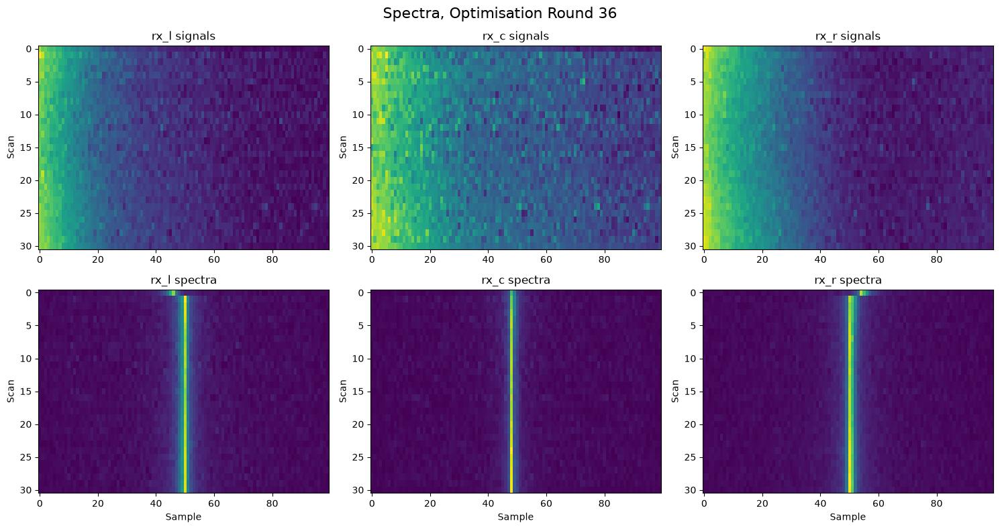

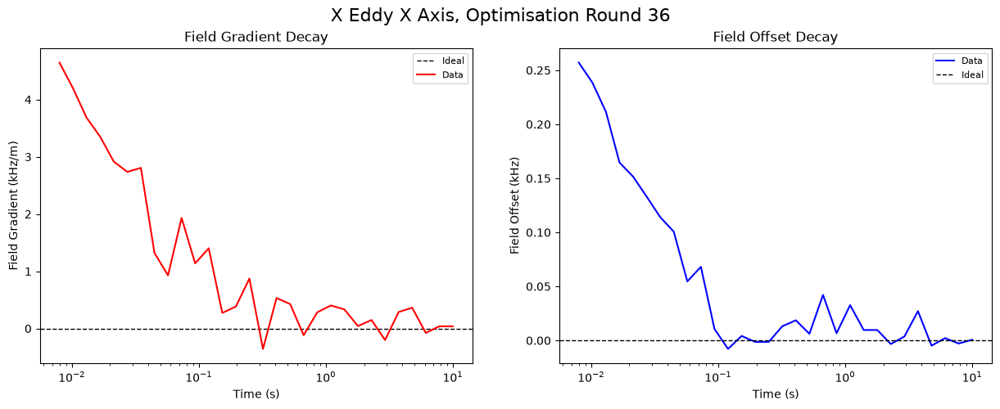

[I 2026-11-26 09:53:42,126] Trial 36 finished with value: 1938.8701801937448 and parameters: {'X_A1': 0.09088653529316927, 'X_A2': 0.07250765555641706, 'X_A3': 0.03772147635356136, 'X_A4': -2.6782068180660045e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3983.0084957521226
mean |E| = 1059.3036814925867
RMS E = 1492.464235298113
Total cost = 1.939e+03
E max = 0.12182684405691503
E nanmax = 0.12182684405691503
E contains nan = False
B max = 0.019355914881964503
B nanmax = 0.019355914881964503
B contains nan = False
Trial 37


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019355914881964503 !!!!!!!!!!!!!!!!


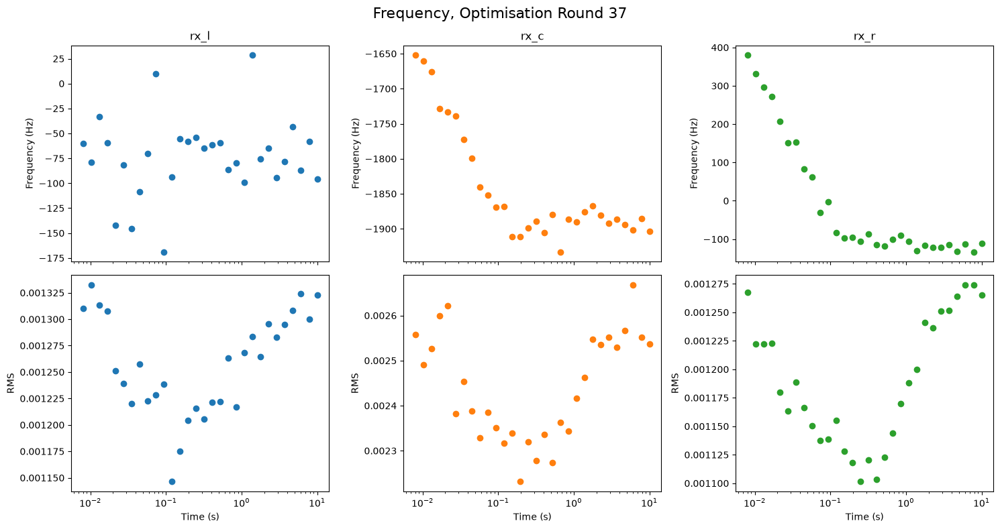

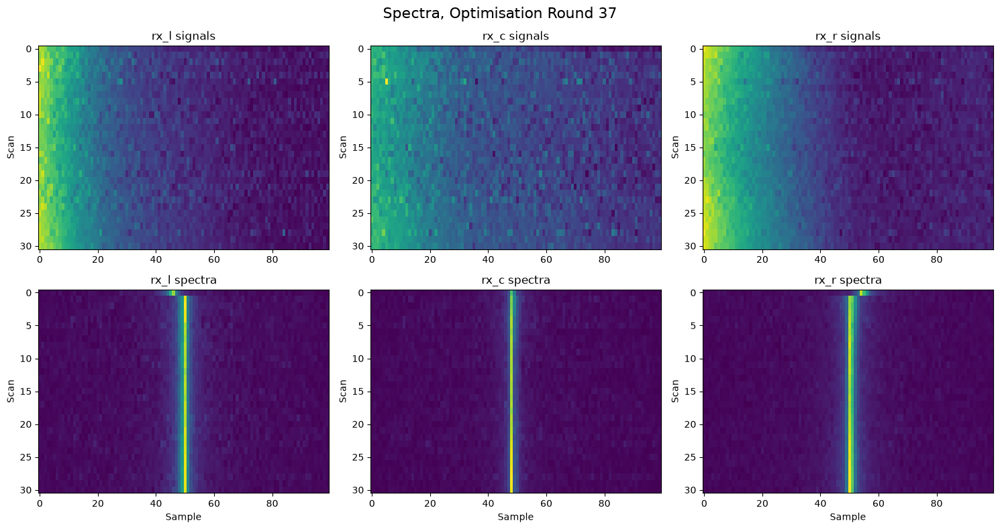

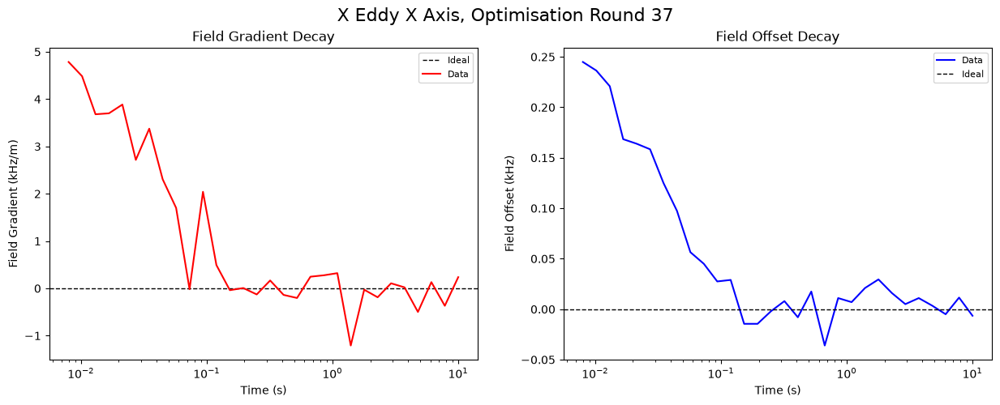

[I 2026-11-26 09:54:32,326] Trial 37 finished with value: 2876.0683722954013 and parameters: {'X_A1': 0.0849344070954019, 'X_A2': 0.06953857791978654, 'X_A3': 0.03945955782320697, 'X_A4': -3.4654673968275986e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 4397.801099450273
mean |E| = 1251.8740629685153
RMS E = 1815.3386887616257
Total cost = 2.876e+03
E max = 0.12169893557053263
E nanmax = 0.12169893557053263
E contains nan = False
B max = 0.019335611049554273
B nanmax = 0.019335611049554273
B contains nan = False
Trial 38


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019335611049554273 !!!!!!!!!!!!!!!!


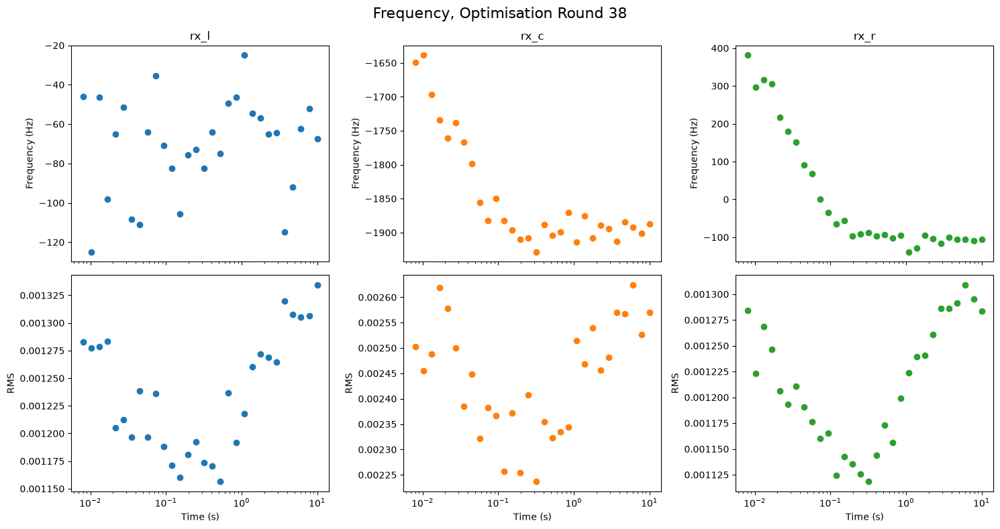

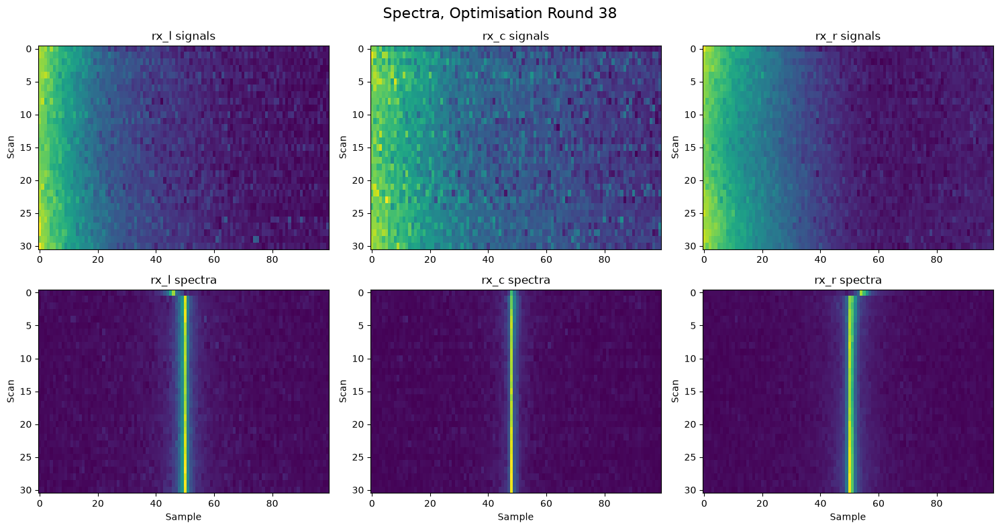

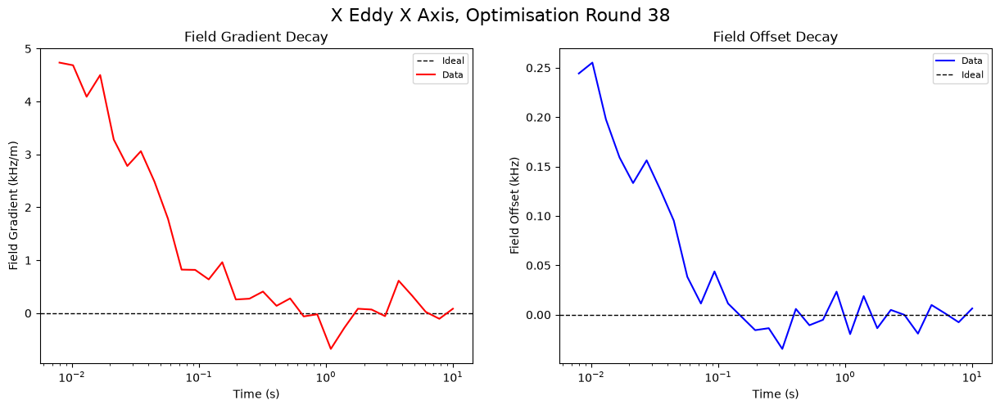

[I 2026-11-26 09:55:57,167] Trial 38 finished with value: 2070.759372313178 and parameters: {'X_A1': 0.08716555029527977, 'X_A2': 0.07144820564468515, 'X_A3': 0.0337343691215786, 'X_A4': -3.817313246312116e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 4272.863568215891
mean |E| = 1181.575878727303
RMS E = 1787.516383060563
Total cost = 2.071e+03
E max = 0.12321700035082532
E nanmax = 0.12321700035082532
E contains nan = False
B max = 0.019576798819835532
B nanmax = 0.019576798819835532
B contains nan = False
Trial 39


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019576798819835532 !!!!!!!!!!!!!!!!


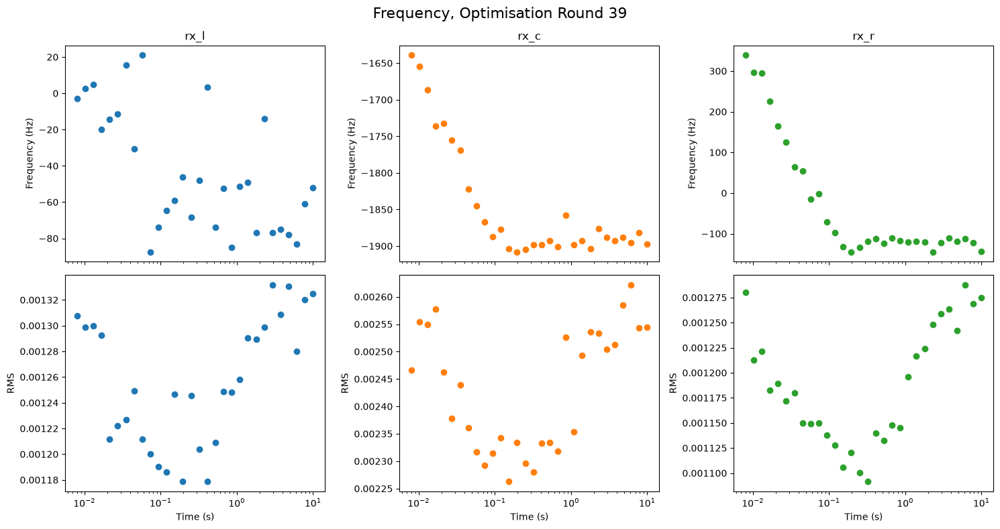

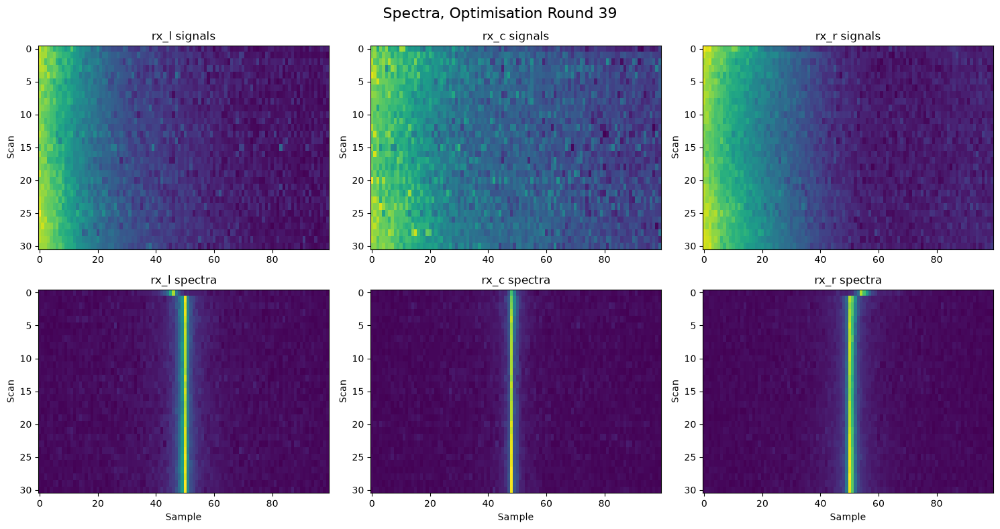

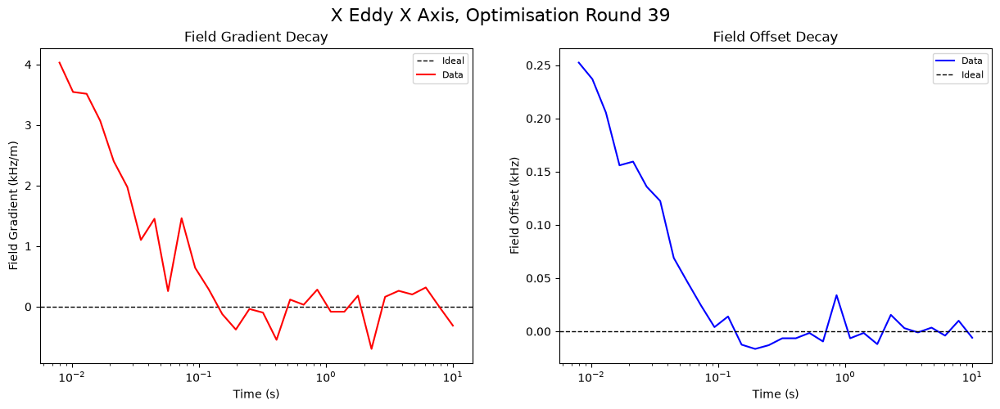

[I 2026-11-26 09:57:21,098] Trial 39 finished with value: 2269.267920562672 and parameters: {'X_A1': 0.10175019145439143, 'X_A2': 0.06689475587339451, 'X_A3': 0.03494657914747607, 'X_A4': -2.9186853824202077e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3418.2908545727128
mean |E| = 985.8404131267695
RMS E = 1302.3351459903254
Total cost = 2.269e+03
E max = 0.12436860528012002
E nanmax = 0.12436860528012002
E contains nan = False
B max = 0.019759751278920393
B nanmax = 0.019759751278920393
B contains nan = False
Trial 40


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019759751278920393 !!!!!!!!!!!!!!!!


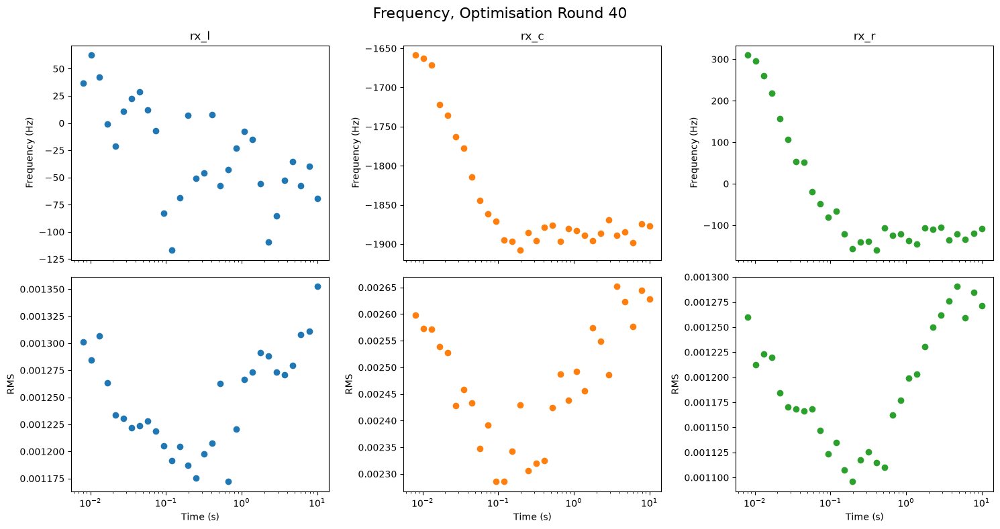

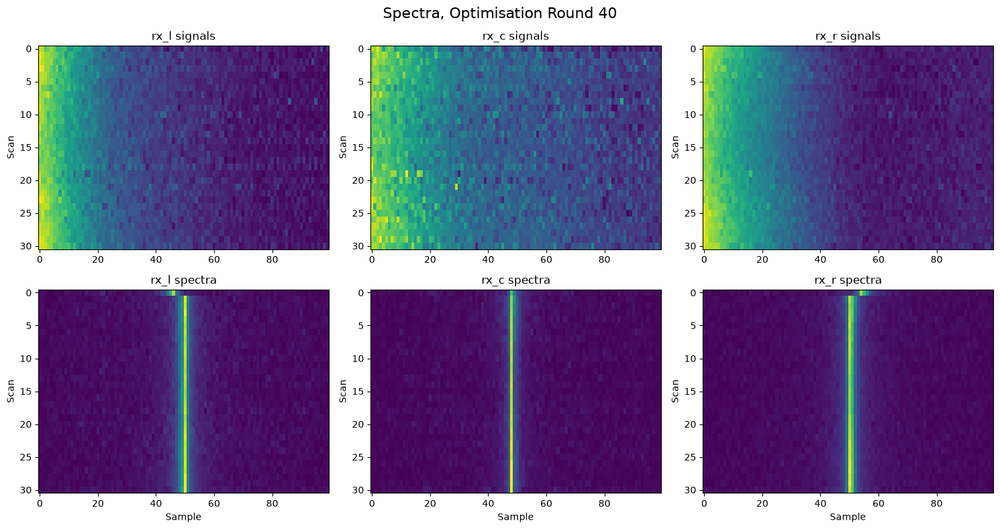

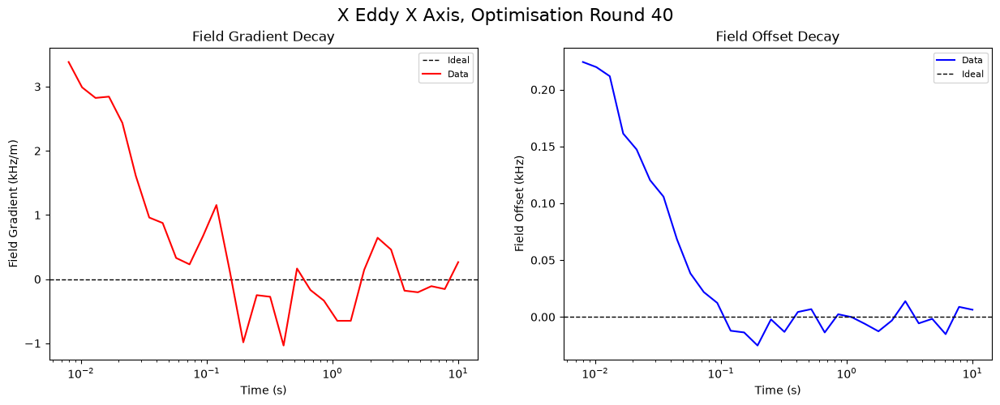

[I 2026-11-26 09:58:42,607] Trial 40 finished with value: 2782.4093762036823 and parameters: {'X_A1': 0.10030833380740356, 'X_A2': 0.07407350688044784, 'X_A3': 0.038323337705499325, 'X_A4': -9.78095340006426e-10}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 2733.633183408295
mean |E| = 962.518740629685
RMS E = 1197.941808543803
Total cost = 2.782e+03
E max = 0.12336476752879828
E nanmax = 0.12336476752879828
E contains nan = False
B max = 0.019600279714471334
B nanmax = 0.019600279714471334
B contains nan = False
Trial 41


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019600279714471334 !!!!!!!!!!!!!!!!


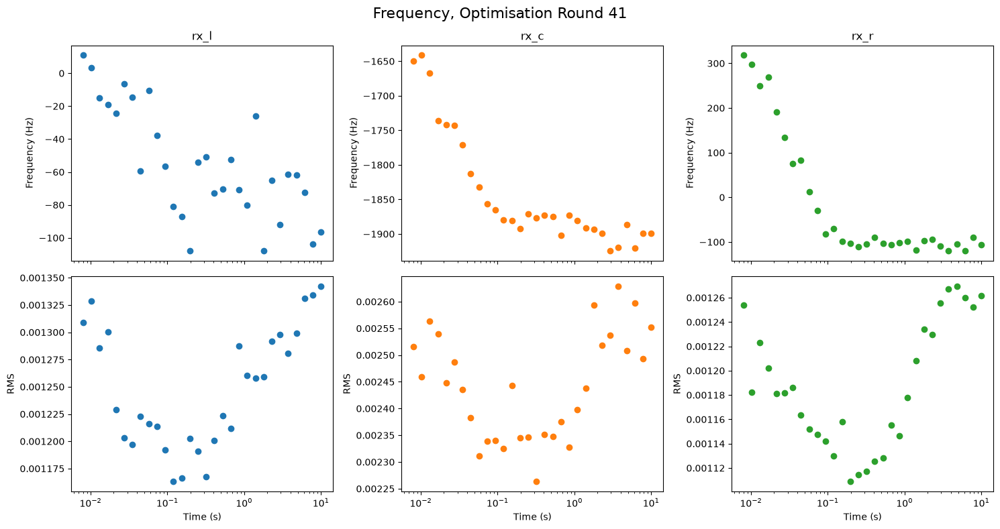

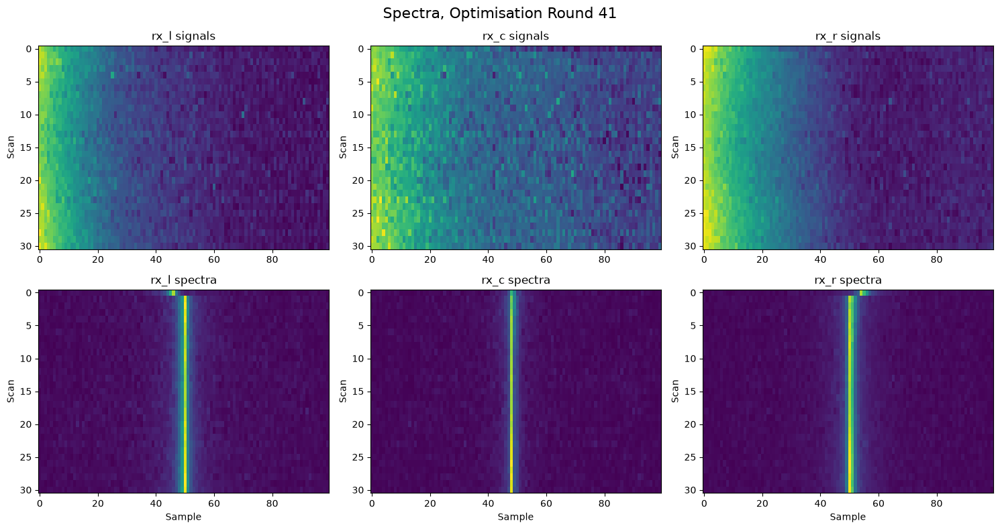

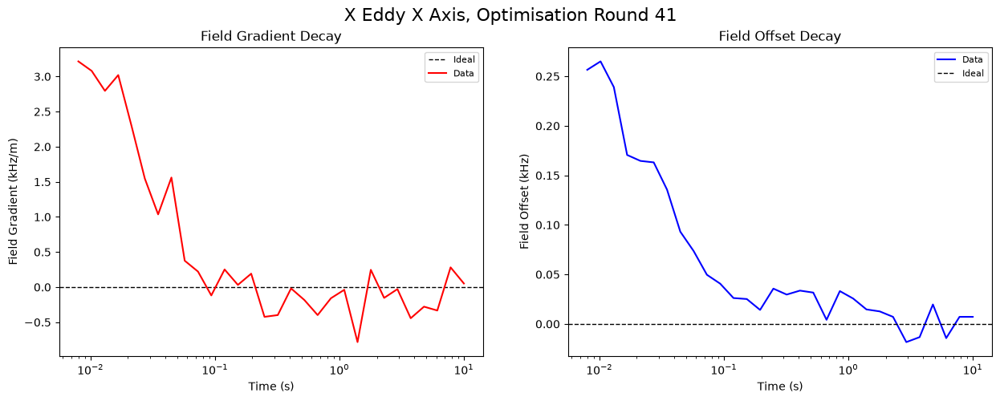

[I 2026-11-26 10:00:05,392] Trial 41 finished with value: 2646.2393760004084 and parameters: {'X_A1': 0.09623483909435514, 'X_A2': 0.07570189332759927, 'X_A3': 0.03278168290900029, 'X_A4': -4.006131641559303e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3073.463268365816
mean |E| = 802.4321172746957
RMS E = 1236.9143706620757
Total cost = 2.646e+03
E max = 0.12237087762219137
E nanmax = 0.12237087762219137
E contains nan = False
B max = 0.019442360440901075
B nanmax = 0.019442360440901075
B contains nan = False
Trial 42


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019442360440901075 !!!!!!!!!!!!!!!!


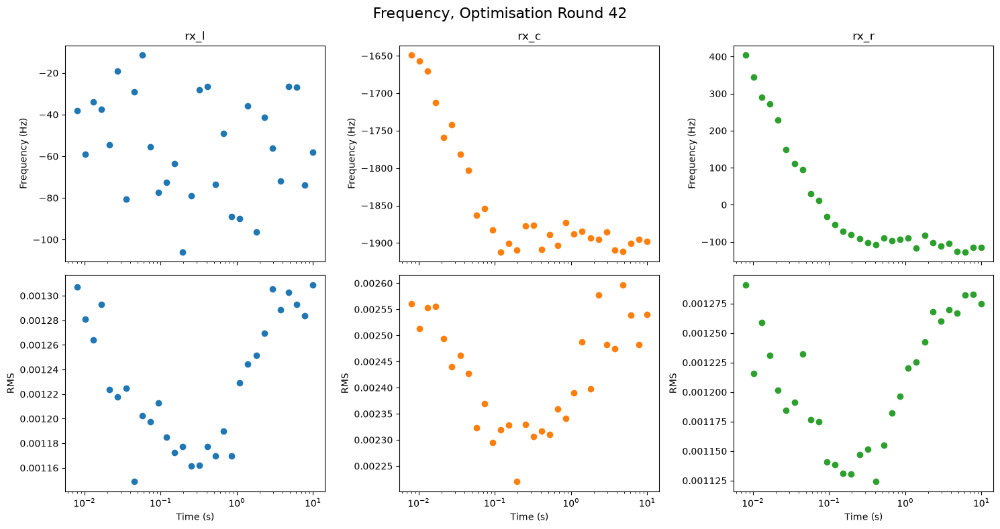

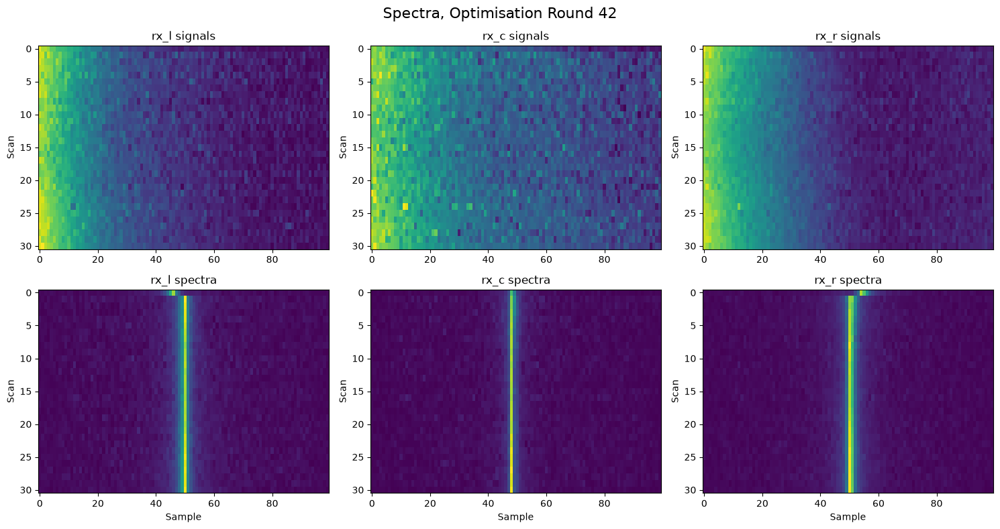

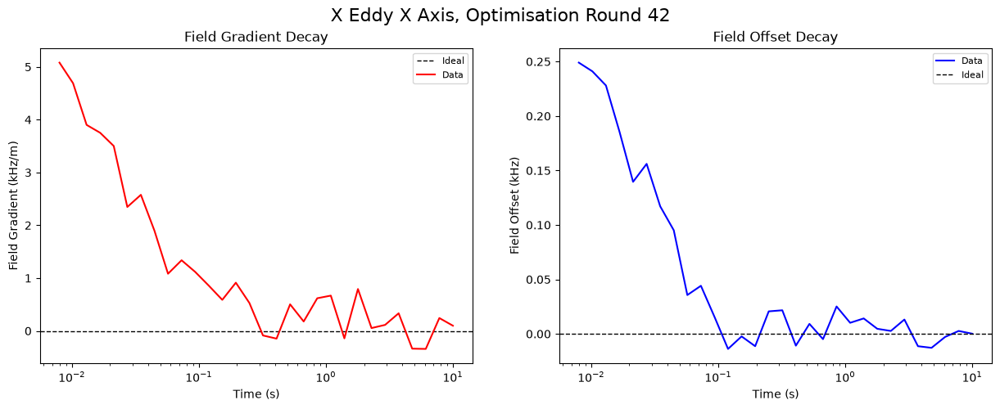

[I 2026-11-26 10:01:32,101] Trial 42 finished with value: 3065.3624313896785 and parameters: {'X_A1': 0.0882596026385518, 'X_A2': 0.0733324771964816, 'X_A3': 0.03612125212043616, 'X_A4': -5.088962035283272e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 4417.791104447775
mean |E| = 1077.1281026153586
RMS E = 1614.9405505085142
Total cost = 3.065e+03
E max = 0.12237092860648592
E nanmax = 0.12237092860648592
E contains nan = False
B max = 0.01944236957884408
B nanmax = 0.01944236957884408
B contains nan = False
Trial 43


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01944236957884408 !!!!!!!!!!!!!!!!


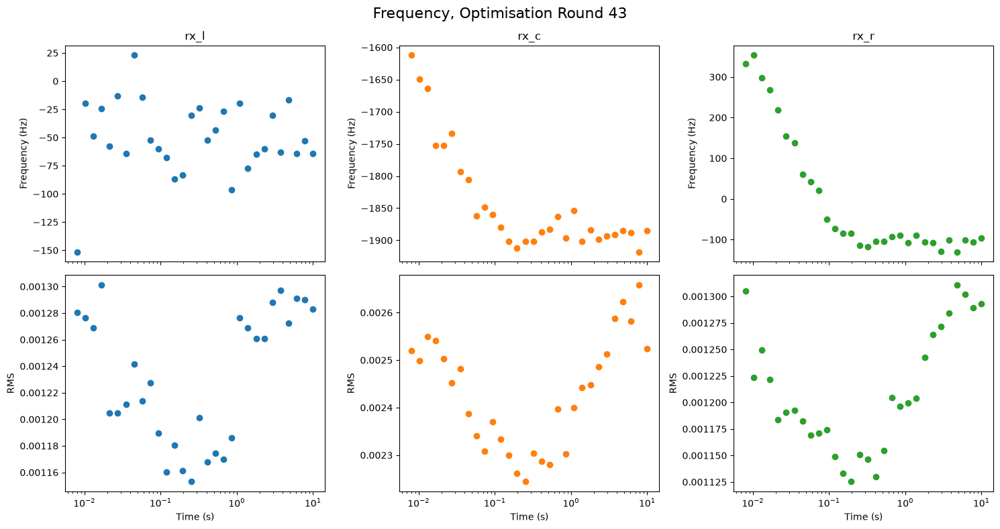

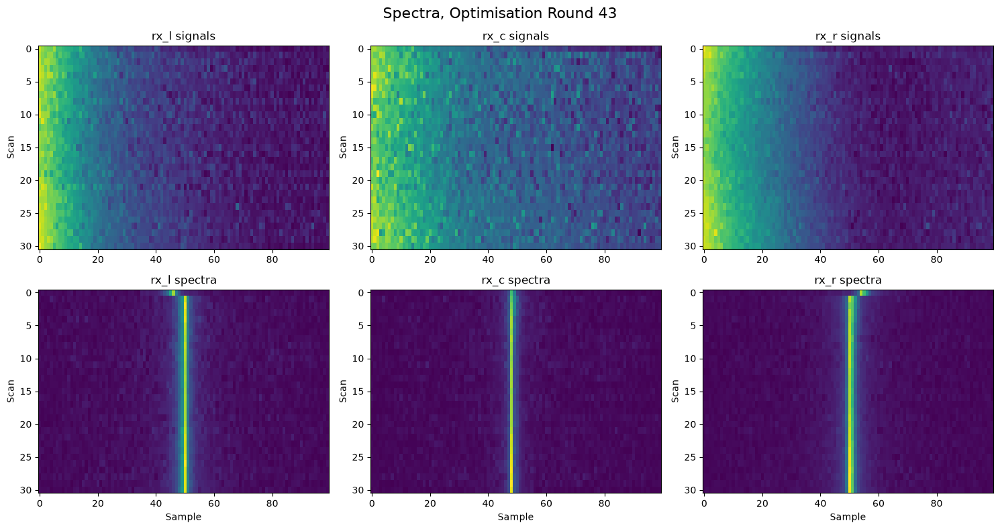

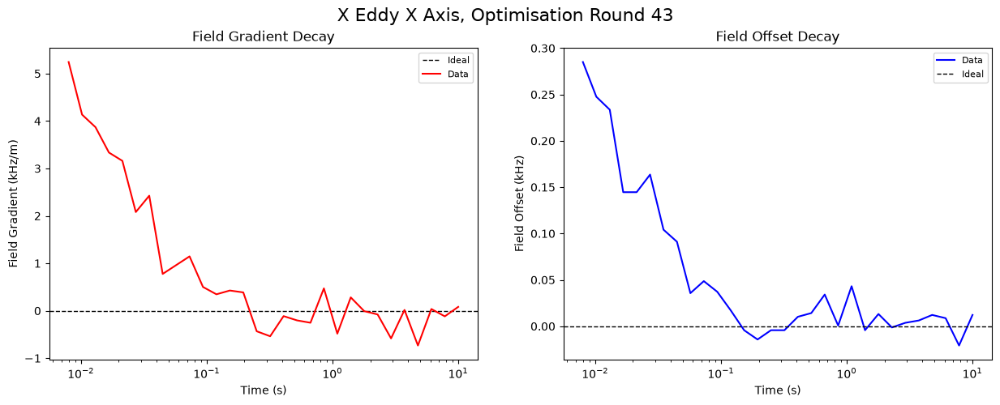

[I 2026-11-26 10:02:59,319] Trial 43 finished with value: 2405.7428900731543 and parameters: {'X_A1': 0.09221535315854466, 'X_A2': 0.06907777464104974, 'X_A3': 0.036325256499174556, 'X_A4': -2.0686210421176447e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 4837.581209395301
mean |E| = 1085.124104614359
RMS E = 1634.8037848945987
Total cost = 2.406e+03
E max = 0.12340387217810604
E nanmax = 0.12340387217810604
E contains nan = False
B max = 0.01960646847044307
B nanmax = 0.01960646847044307
B contains nan = False
Trial 44


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01960646847044307 !!!!!!!!!!!!!!!!


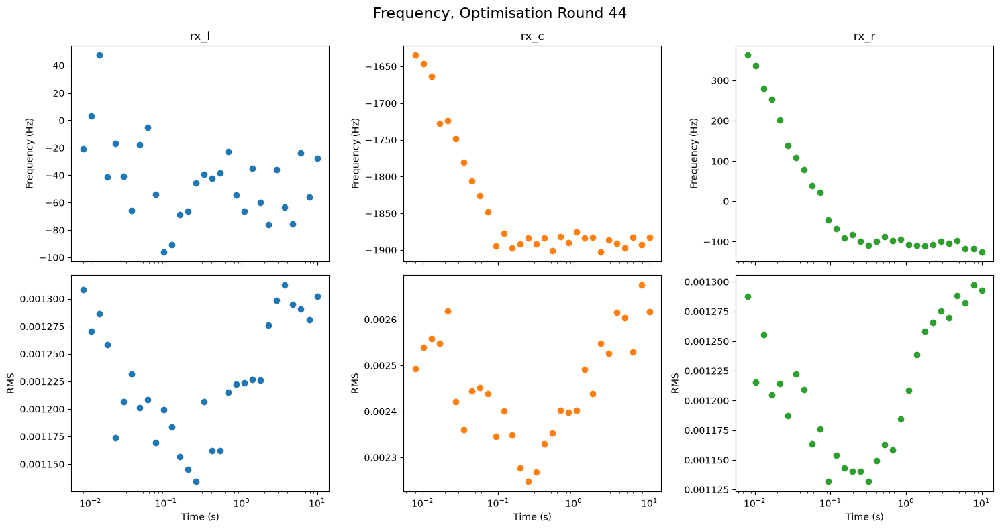

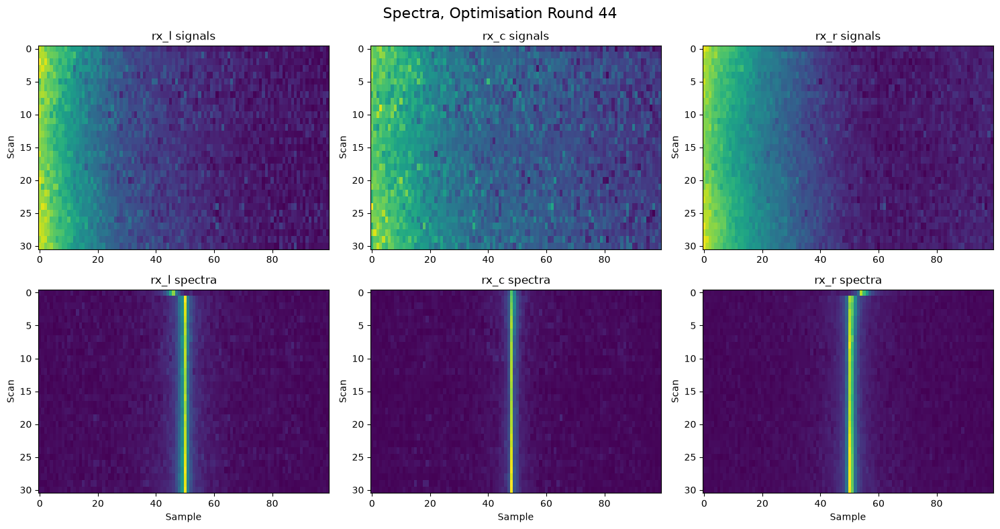

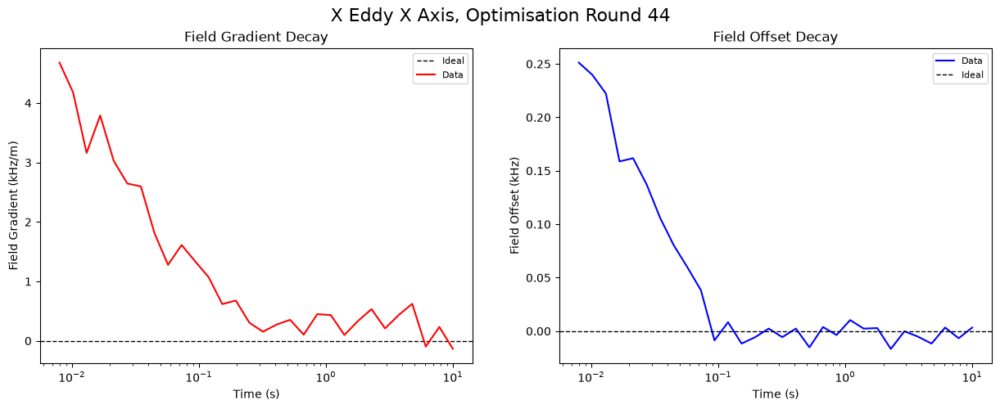

[I 2026-11-26 10:04:24,017] Trial 44 finished with value: 3147.105423724473 and parameters: {'X_A1': 0.09297940358505591, 'X_A2': 0.072523326596026, 'X_A3': 0.04035633080740494, 'X_A4': -1.1438997124561336e-10}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3838.080959520239
mean |E| = 1021.9890054972511
RMS E = 1403.415749225516
Total cost = 3.147e+03
E max = 0.12328560108142603
E nanmax = 0.12328560108142603
E contains nan = False
B max = 0.019587686135556965
B nanmax = 0.019587686135556965
B contains nan = False
Trial 45


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019587686135556965 !!!!!!!!!!!!!!!!


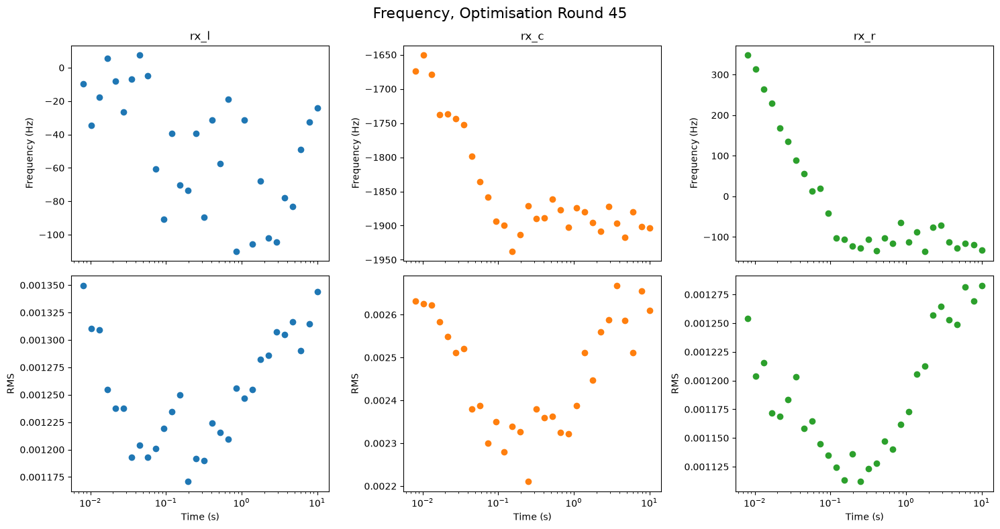

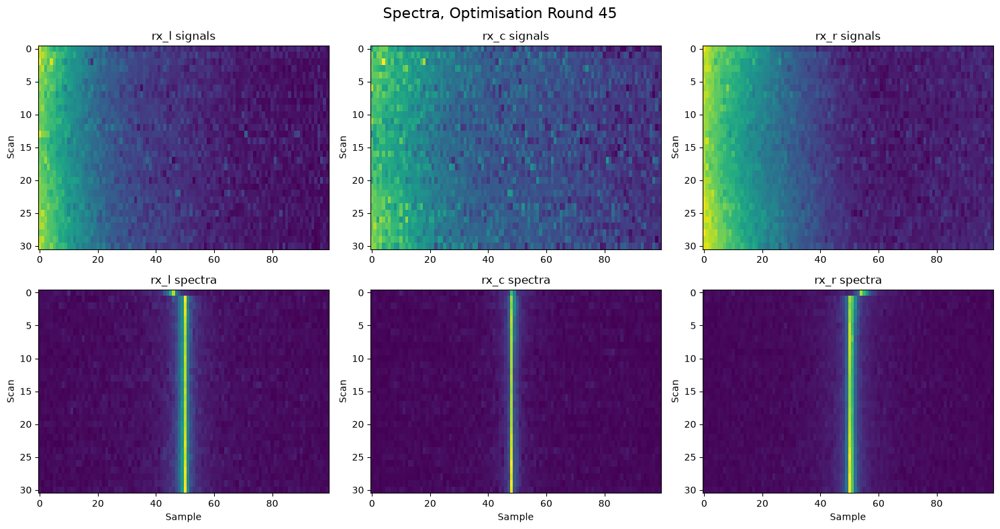

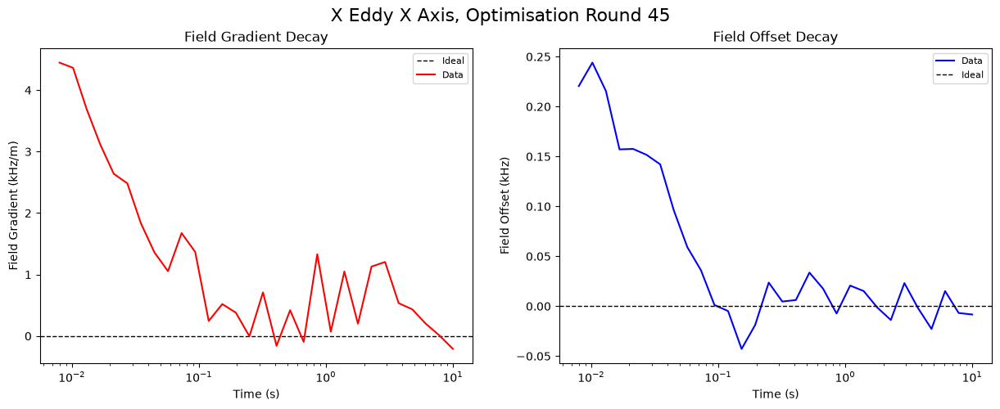

[I 2026-11-26 10:05:49,095] Trial 45 finished with value: 4204.974097497681 and parameters: {'X_A1': 0.09592271941062976, 'X_A2': 0.07067155632550991, 'X_A3': 0.038051947881919276, 'X_A4': -6.852832079950255e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3573.2133933033474
mean |E| = 983.1750791271029
RMS E = 1337.600604563569
Total cost = 4.205e+03
E max = 0.12396033255781287
E nanmax = 0.12396033255781287
E contains nan = False
B max = 0.01969488217884698
B nanmax = 0.01969488217884698
B contains nan = False
Trial 46


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01969488217884698 !!!!!!!!!!!!!!!!


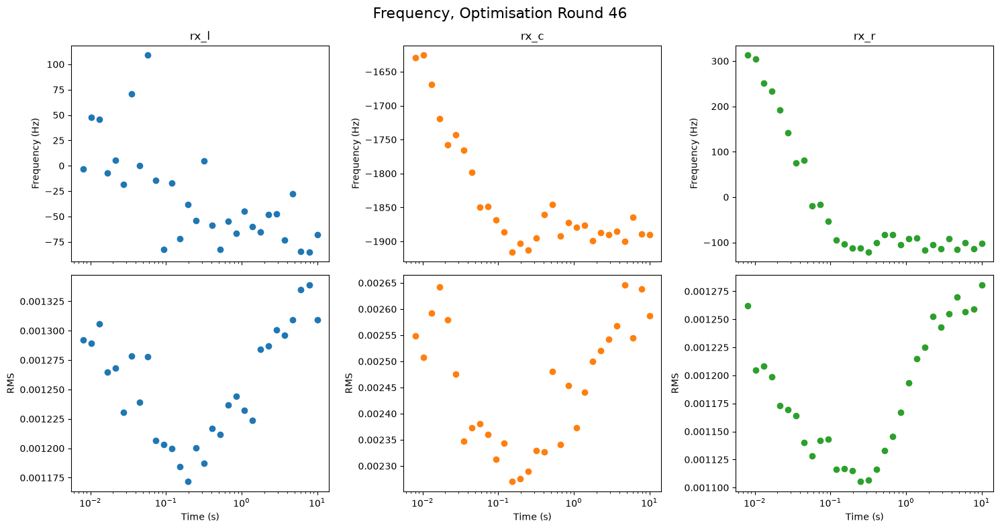

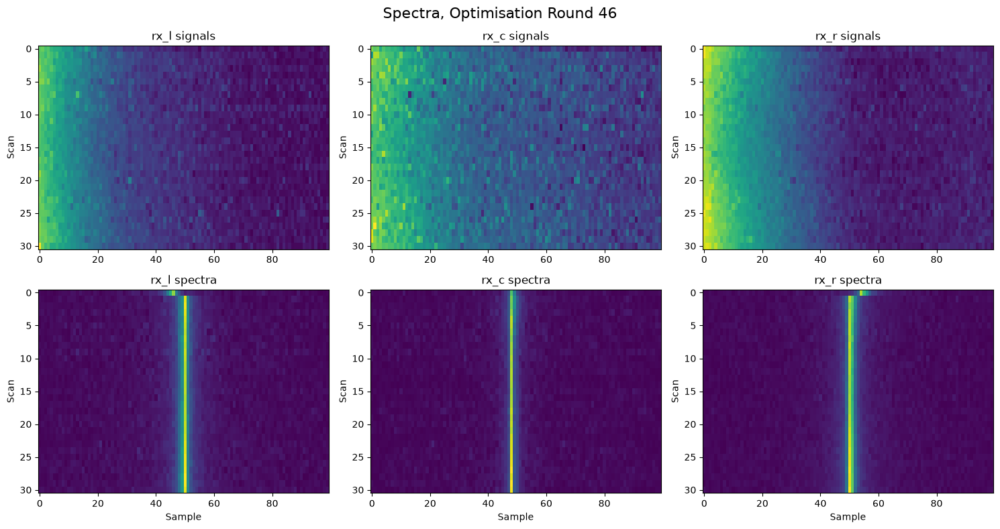

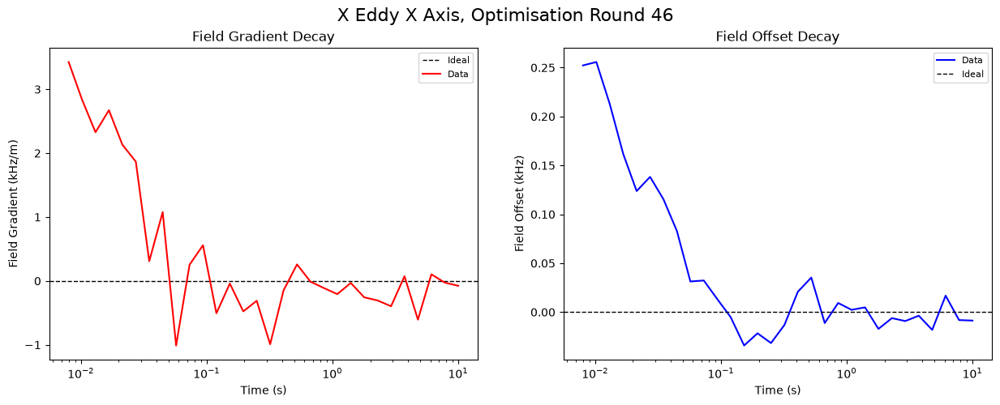

[I 2026-11-26 10:07:15,928] Trial 46 finished with value: 2035.8935214251037 and parameters: {'X_A1': 0.09988387992785366, 'X_A2': 0.07026293280714623, 'X_A3': 0.03961550925338278, 'X_A4': -3.105137913585846e-09}. Best is trial 24 with value: 1832.9405883916054.


max |E| = 3158.420789605196
mean |E| = 841.7457937697814
RMS E = 1168.5845720502318
Total cost = 2.036e+03
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.01961913224476599
B nanmax = 0.01961913224476599
B contains nan = False
Trial 47


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01961913224476599 !!!!!!!!!!!!!!!!


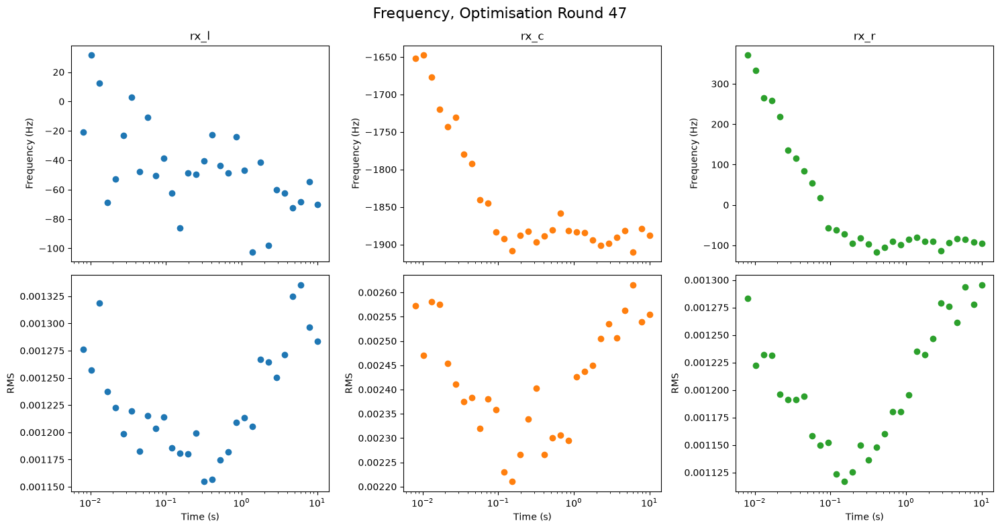

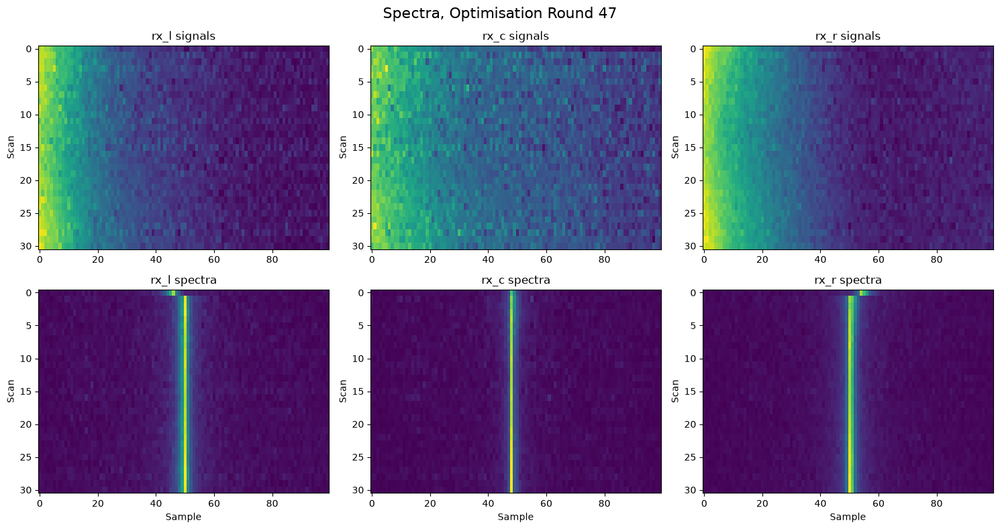

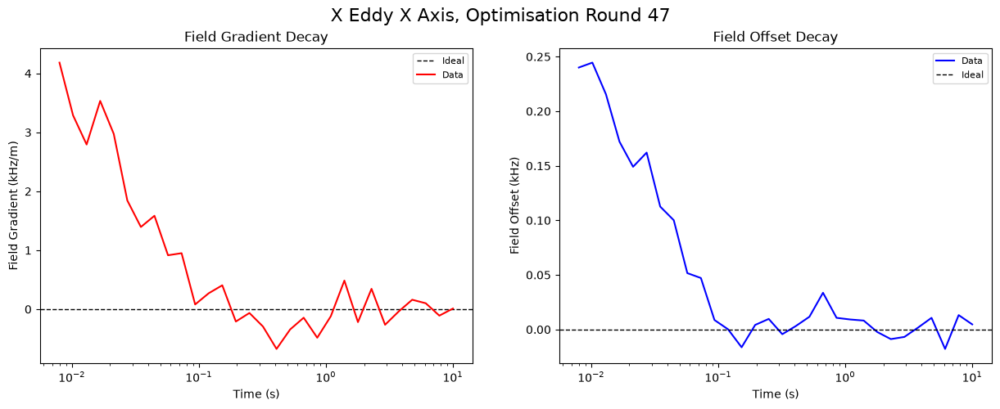

[I 2026-11-26 10:08:39,930] Trial 47 finished with value: 1718.6295840286955 and parameters: {'X_A1': 0.09502718748787026, 'X_A2': 0.06941907171181386, 'X_A3': 0.04210994040150974, 'X_A4': -1.4992281432459338e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3918.0409795102437
mean |E| = 937.1980676328498
RMS E = 1402.9449692283026
Total cost = 1.719e+03
E max = 0.12269564834758914
E nanmax = 0.12269564834758914
E contains nan = False
B max = 0.019493966145290073
B nanmax = 0.019493966145290073
B contains nan = False
Trial 48


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019493966145290073 !!!!!!!!!!!!!!!!


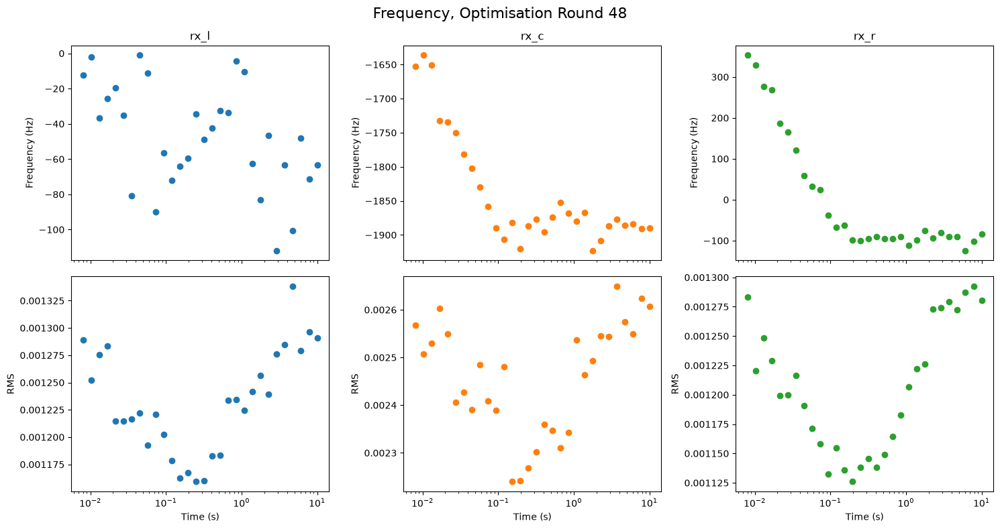

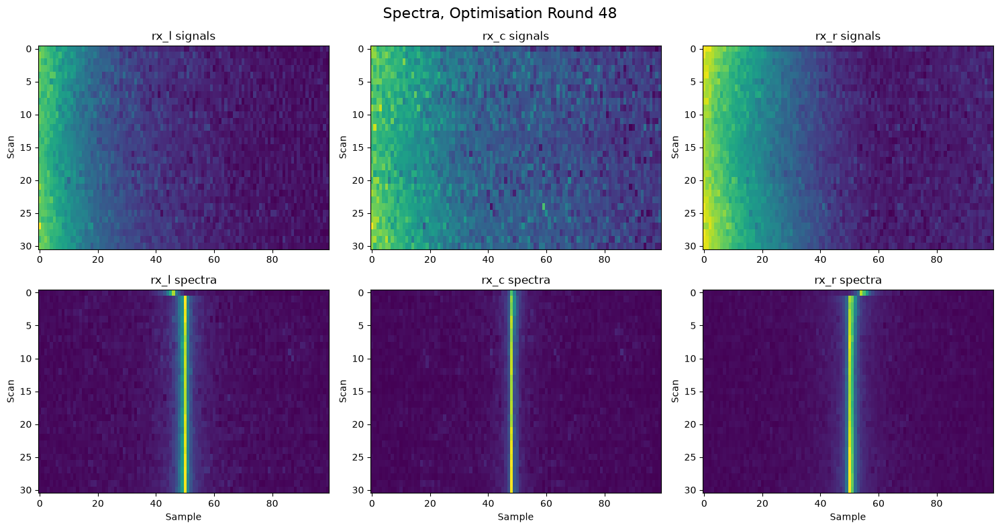

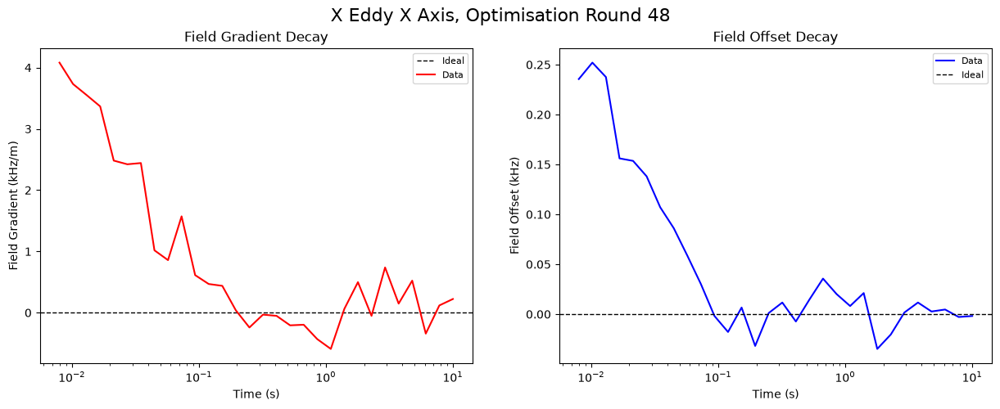

[I 2026-11-26 10:10:04,669] Trial 48 finished with value: 3083.0717036589986 and parameters: {'X_A1': 0.09475013709500049, 'X_A2': 0.07049589919208037, 'X_A3': 0.03461237324880954, 'X_A4': -4.6709632579150936e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3658.170914542728
mean |E| = 983.6748292520404
RMS E = 1435.4731165899439
Total cost = 3.083e+03
E max = 0.1228409262683056
E nanmax = 0.1228409262683056
E contains nan = False
B max = 0.0195170333960107
B nanmax = 0.0195170333960107
B contains nan = False
Trial 49


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0195170333960107 !!!!!!!!!!!!!!!!


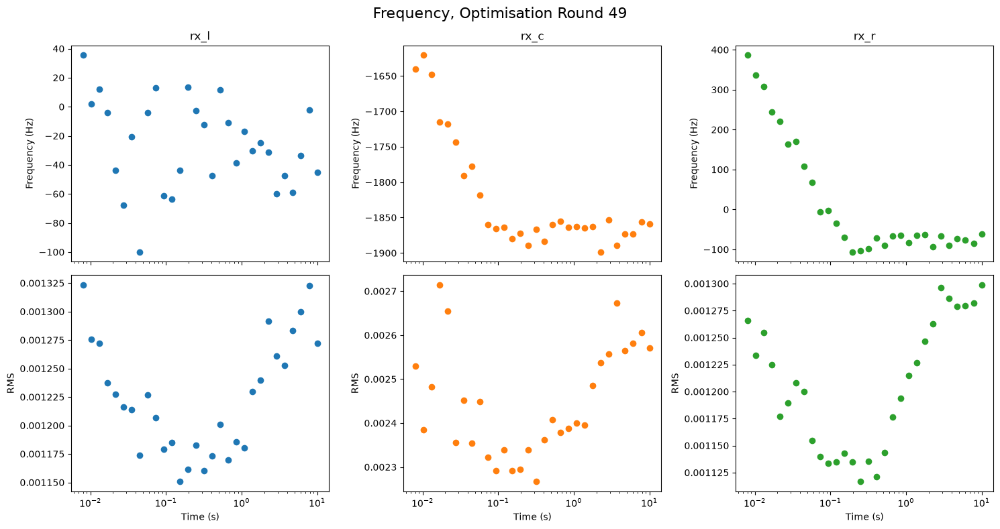

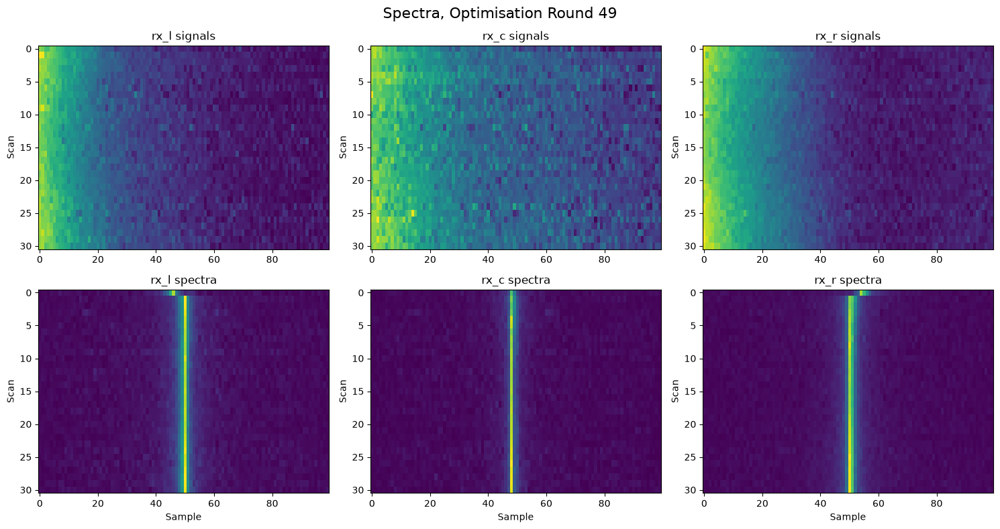

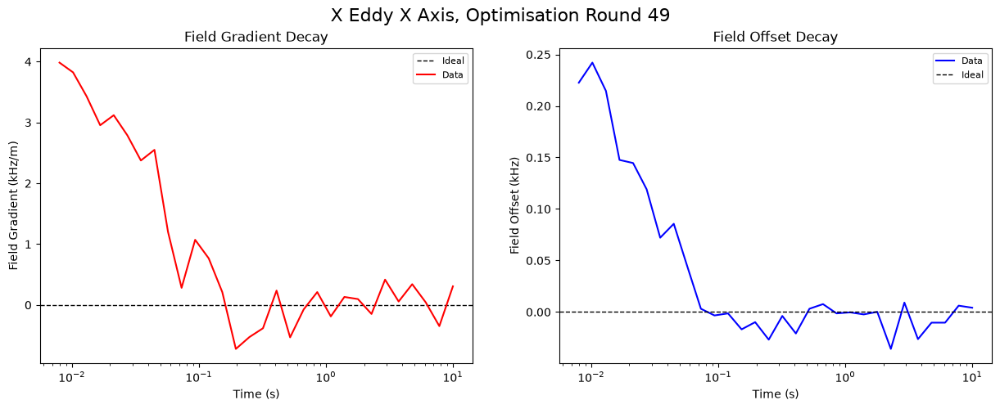

[I 2026-11-26 10:11:30,411] Trial 49 finished with value: 2507.0486132754663 and parameters: {'X_A1': 0.09612180996225982, 'X_A2': 0.06574502550086661, 'X_A3': 0.03950270826349864, 'X_A4': -2.21948144287317e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3508.2458770614685
mean |E| = 1082.4587706146924
RMS E = 1489.235248011768
Total cost = 2.507e+03
E max = 0.12415236497589667
E nanmax = 0.12415236497589667
E contains nan = False
B max = 0.019725387644718668
B nanmax = 0.019725387644718668
B contains nan = False
Trial 50


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019725387644718668 !!!!!!!!!!!!!!!!


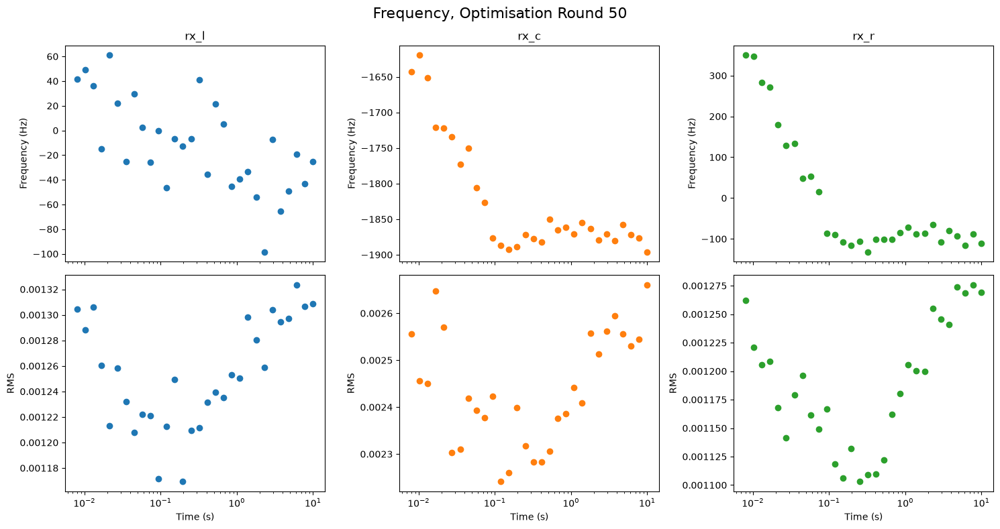

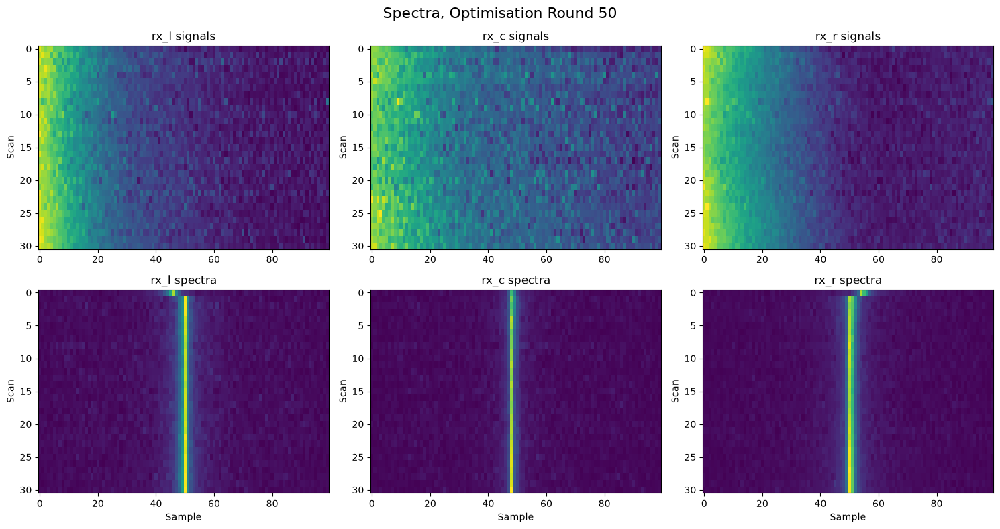

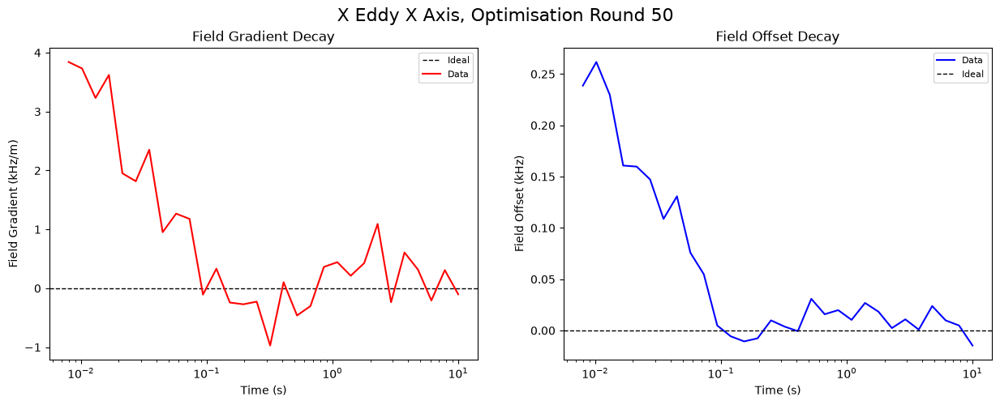

[I 2026-11-26 10:12:53,130] Trial 50 finished with value: 3599.086319380248 and parameters: {'X_A1': 0.10296045704555123, 'X_A2': 0.0669170919973161, 'X_A3': 0.04135930475387408, 'X_A4': -7.585466122749273e-10}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3083.4582708645667
mean |E| = 1036.9815092453769
RMS E = 1317.4033226759082
Total cost = 3.599e+03
E max = 0.12460843748725851
E nanmax = 0.12460843748725851
E contains nan = False
B max = 0.019797843297979806
B nanmax = 0.019797843297979806
B contains nan = False
Trial 51


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019797843297979806 !!!!!!!!!!!!!!!!


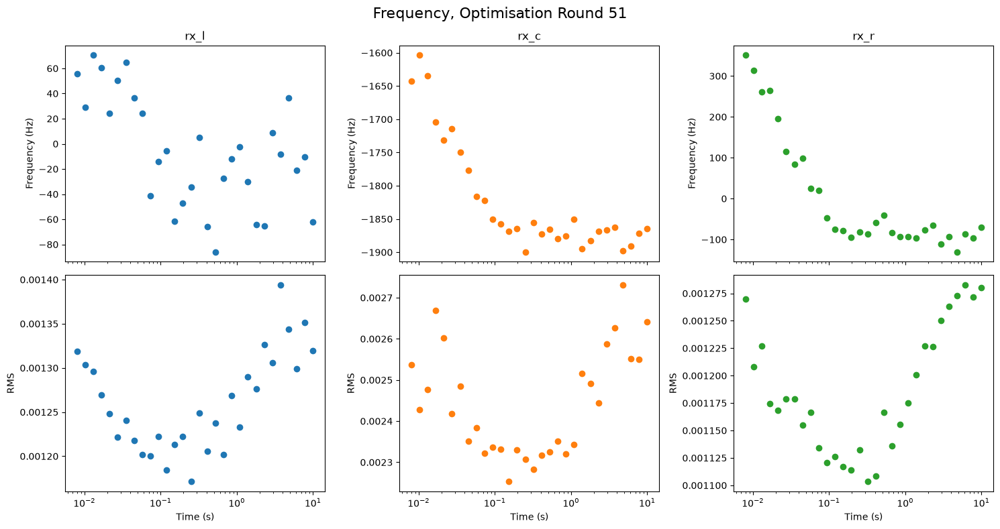

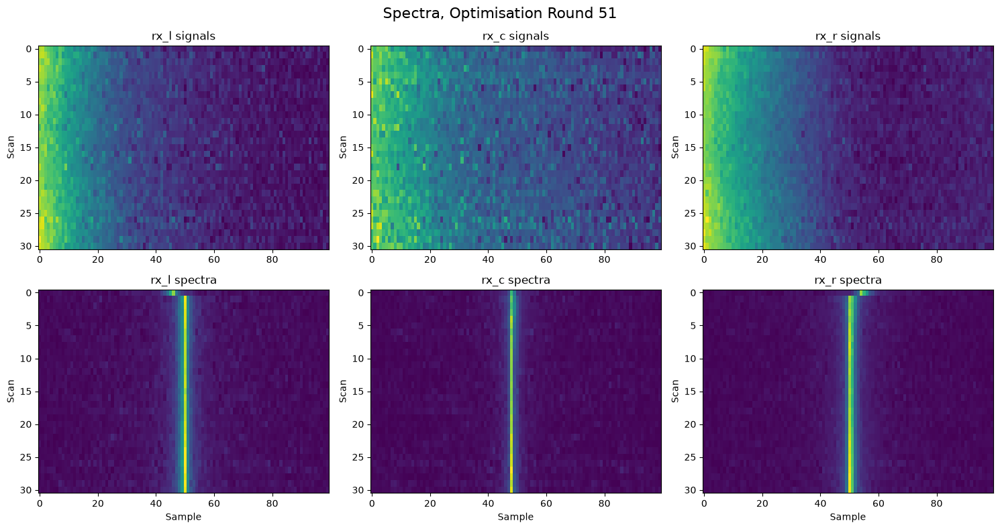

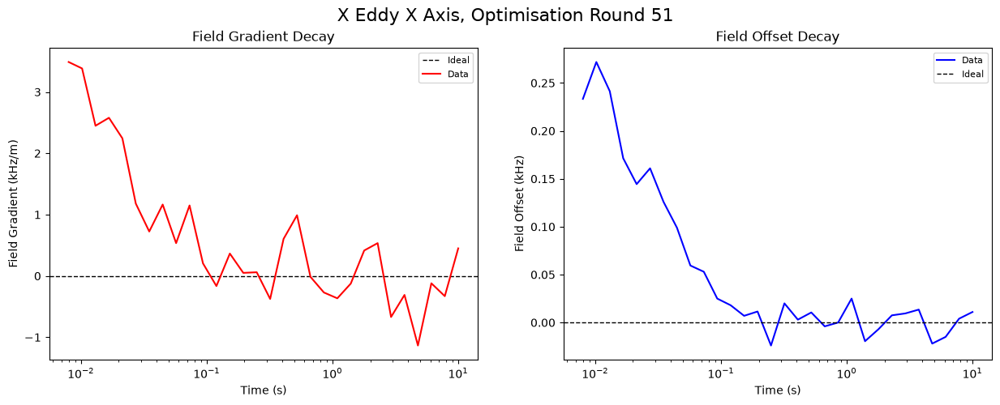

[I 2026-11-26 10:13:40,965] Trial 51 finished with value: 4473.337673778253 and parameters: {'X_A1': 0.09863386218140376, 'X_A2': 0.07434566097635562, 'X_A3': 0.04193134064200726, 'X_A4': -2.3968748642505693e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 2953.523238380809
mean |E| = 849.9083791437613
RMS E = 1144.4714315738056
Total cost = 4.473e+03
E max = 0.12436170111556044
E nanmax = 0.12436170111556044
E contains nan = False
B max = 0.019758640365243794
B nanmax = 0.019758640365243794
B contains nan = False
Trial 52


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019758640365243794 !!!!!!!!!!!!!!!!


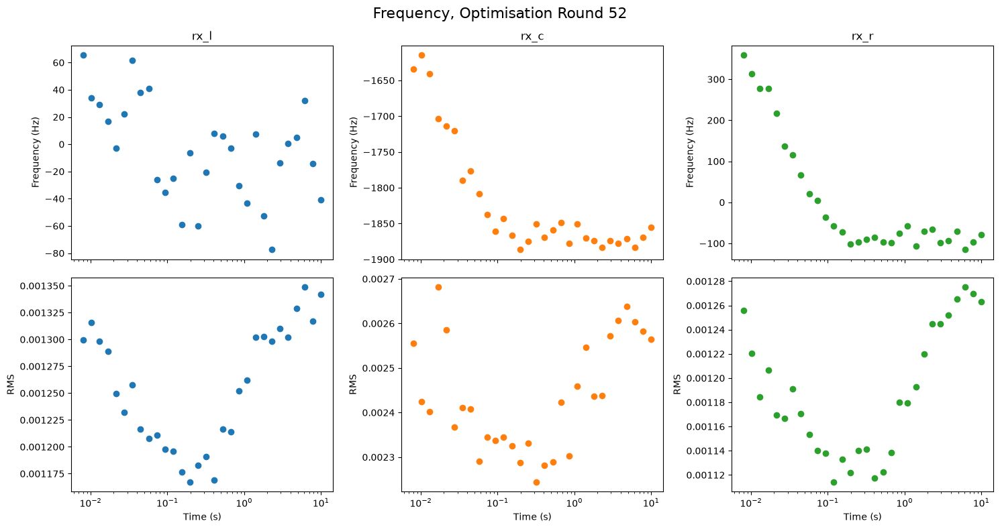

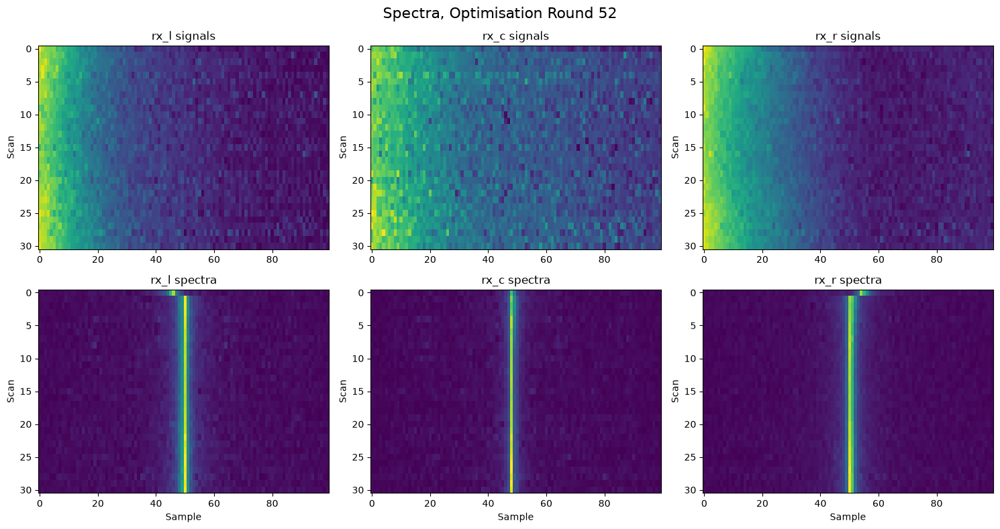

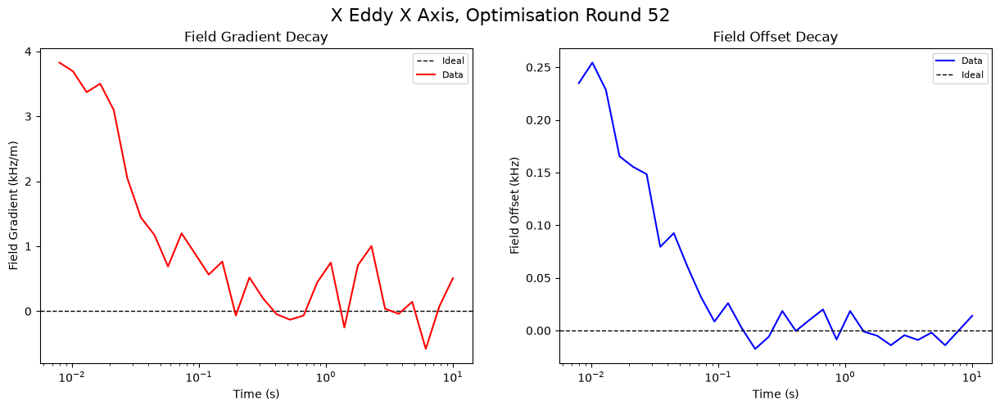

[I 2026-11-26 10:14:28,735] Trial 52 finished with value: 3361.634234564276 and parameters: {'X_A1': 0.10184139814889313, 'X_A2': 0.06805778293952829, 'X_A3': 0.043130854184677, 'X_A4': -2.8087997547112117e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 2933.533233383308
mean |E| = 939.6968182575379
RMS E = 1256.3599530886274
Total cost = 3.362e+03
E max = 0.12377767925008741
E nanmax = 0.12377767925008741
E contains nan = False
B max = 0.019665849601651002
B nanmax = 0.019665849601651002
B contains nan = False
Trial 53


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019665849601651002 !!!!!!!!!!!!!!!!


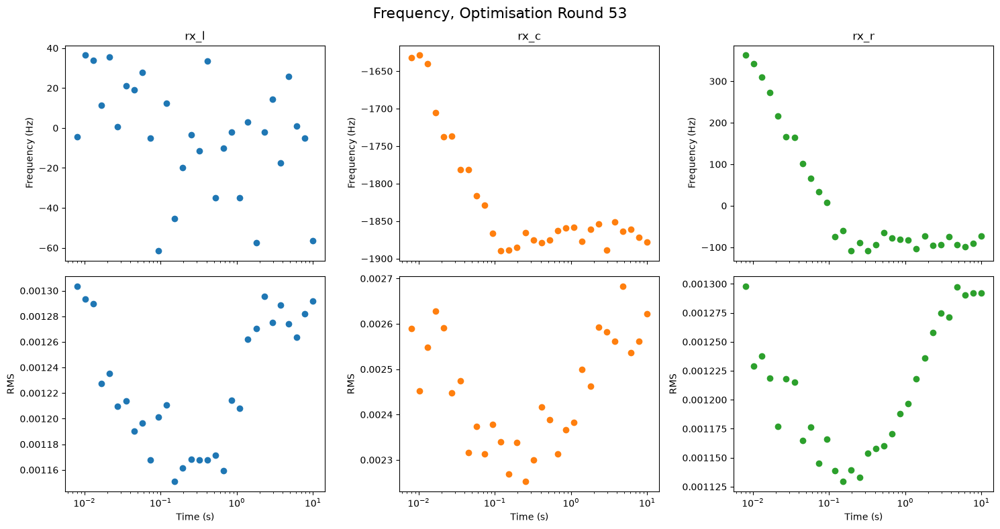

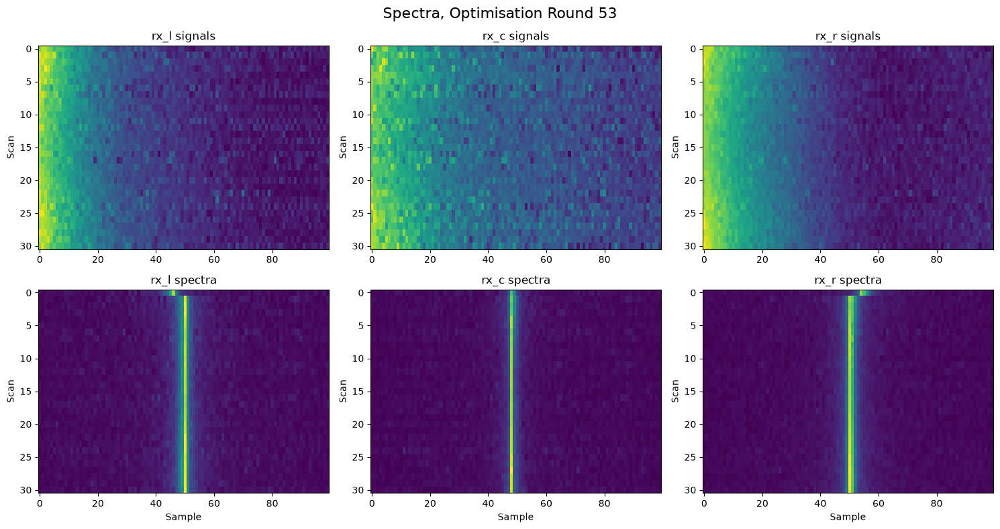

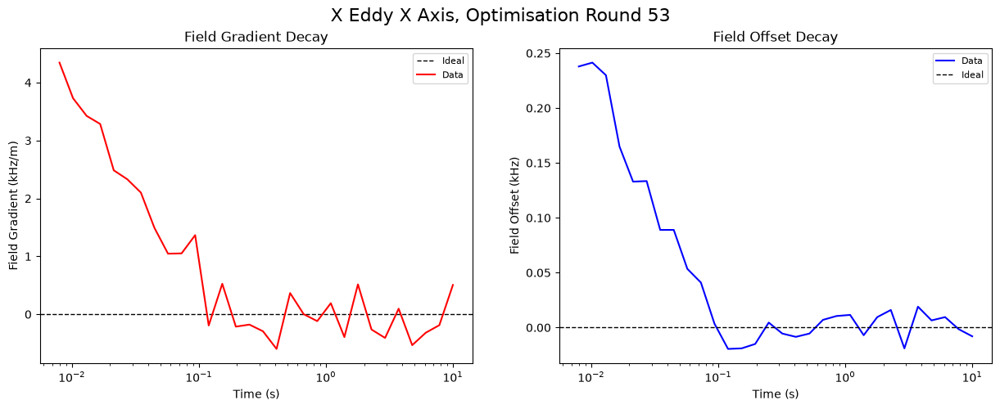

[I 2026-11-26 10:15:16,419] Trial 53 finished with value: 3360.642539149331 and parameters: {'X_A1': 0.09659266712420139, 'X_A2': 0.0687541001699855, 'X_A3': 0.04350979212599029, 'X_A4': -2.4178569076939117e-10}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3673.1634182908538
mean |E| = 1117.2746959853403
RMS E = 1410.873171450917
Total cost = 3.361e+03
E max = 0.12314334843509134
E nanmax = 0.12314334843509134
E contains nan = False
B max = 0.019565087273093862
B nanmax = 0.019565087273093862
B contains nan = False
Trial 54


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019565087273093862 !!!!!!!!!!!!!!!!


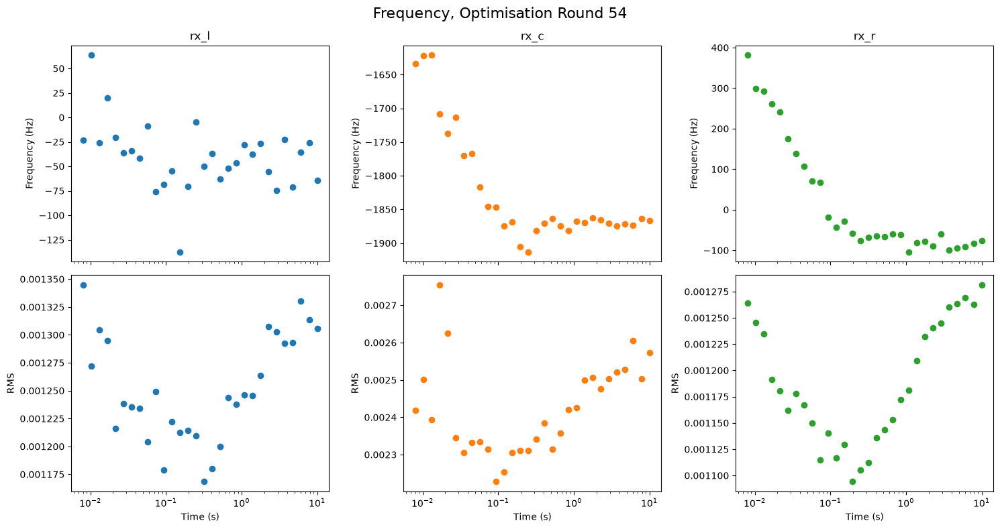

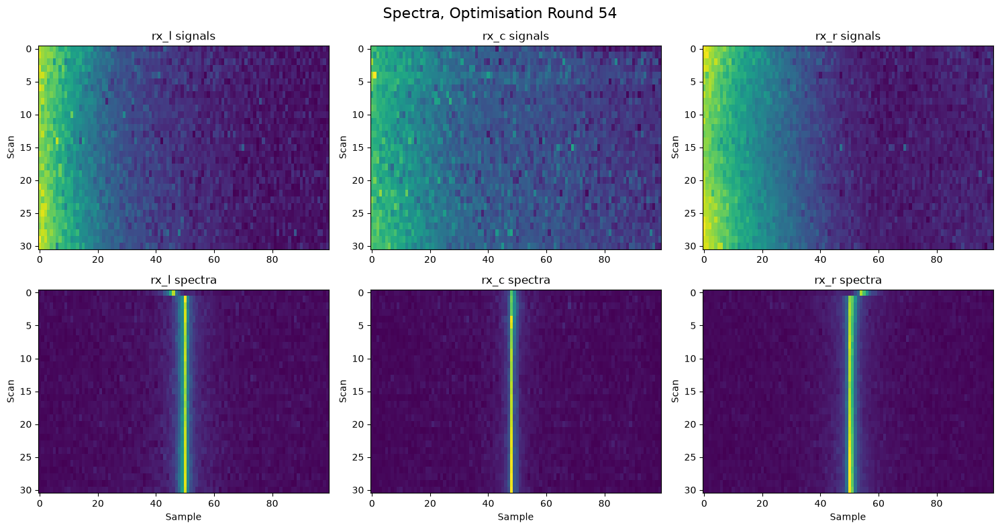

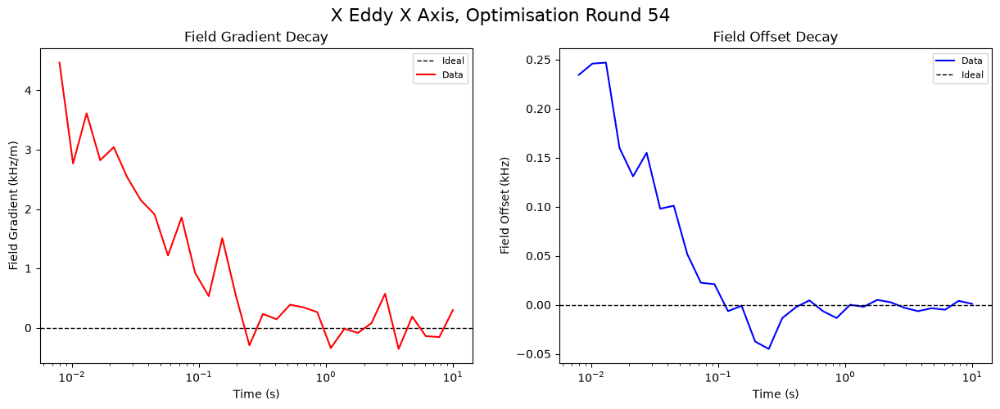

[I 2026-11-26 10:16:04,386] Trial 54 finished with value: 2492.2735666336007 and parameters: {'X_A1': 0.09111746543300371, 'X_A2': 0.07568503129896267, 'X_A3': 0.03678788074106558, 'X_A4': -2.541680257013615e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4047.976011994002
mean |E| = 997.1680826253538
RMS E = 1434.780780977207
Total cost = 2.492e+03
E max = 0.12440272115637396
E nanmax = 0.12440272115637396
E contains nan = False
B max = 0.019765176234081566
B nanmax = 0.019765176234081566
B contains nan = False
Trial 55


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019765176234081566 !!!!!!!!!!!!!!!!


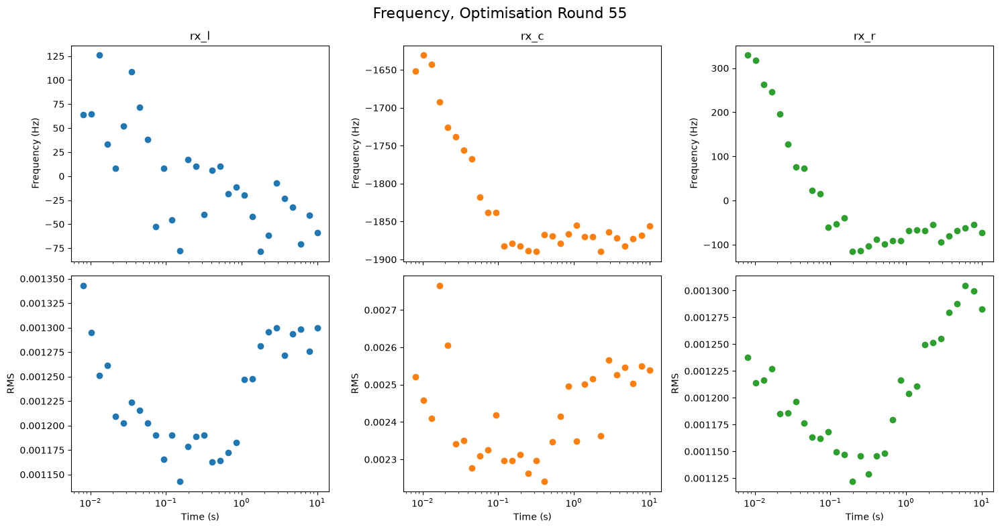

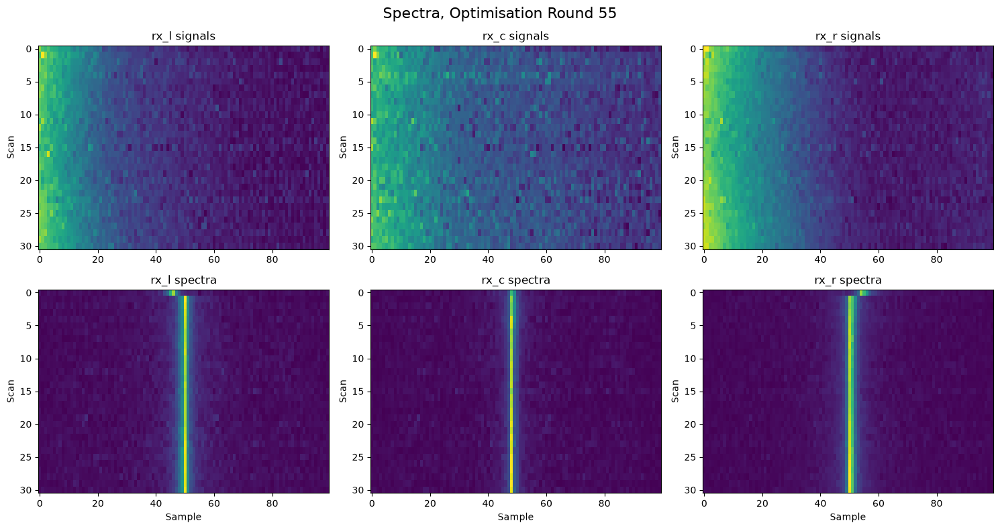

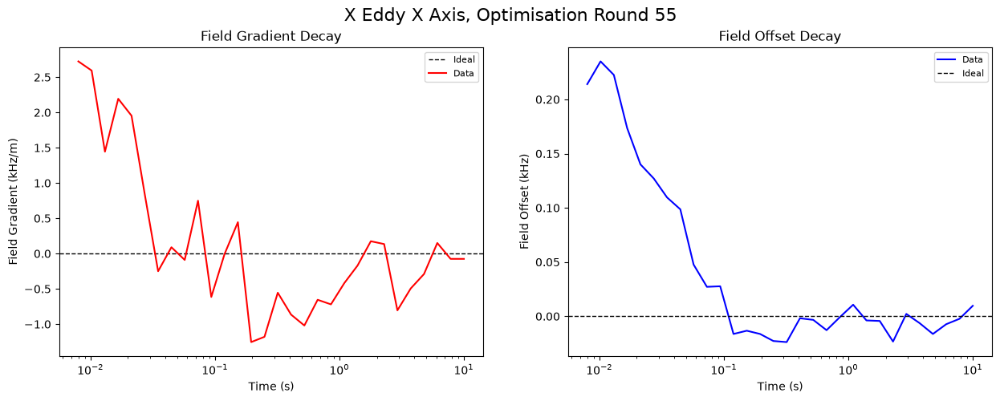

[I 2026-11-26 10:16:52,399] Trial 55 finished with value: 2919.7878132239034 and parameters: {'X_A1': 0.10490721817830513, 'X_A2': 0.07036636267640504, 'X_A3': 0.037407922536287684, 'X_A4': -1.9256257807076964e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 2653.67316341829
mean |E| = 781.4426120273195
RMS E = 1058.9086829118082
Total cost = 2.920e+03
E max = 0.12343465224616475
E nanmax = 0.12343465224616475
E contains nan = False
B max = 0.01961134828739027
B nanmax = 0.01961134828739027
B contains nan = False
Trial 56


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01961134828739027 !!!!!!!!!!!!!!!!


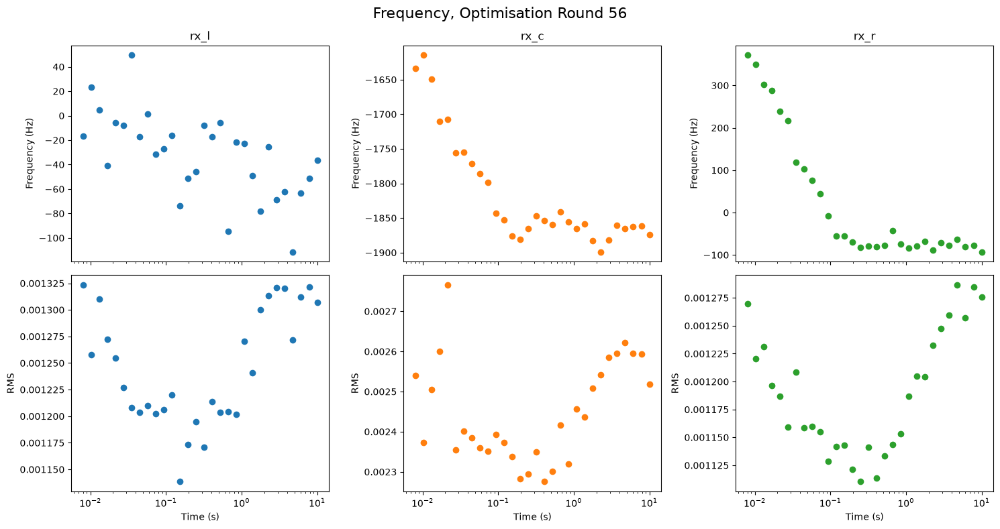

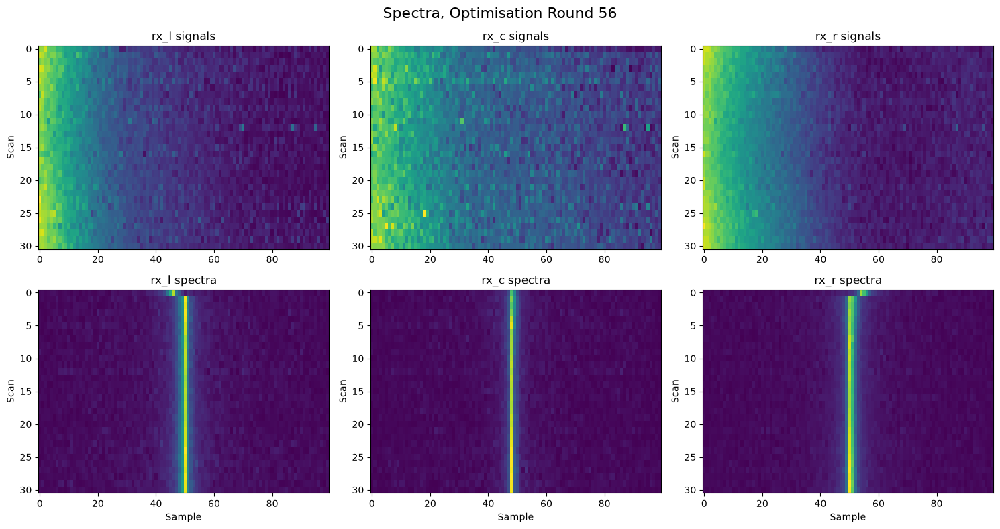

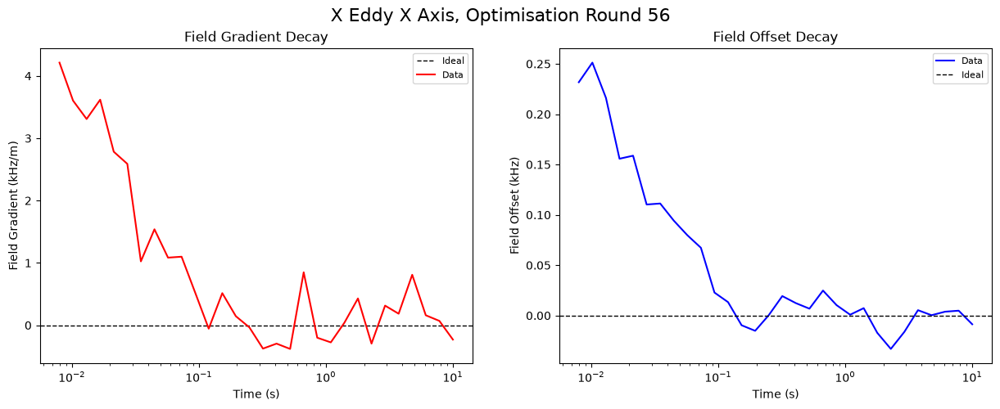

[I 2026-11-26 10:17:40,153] Trial 56 finished with value: 2907.071671452138 and parameters: {'X_A1': 0.09059499356395195, 'X_A2': 0.07239349865360167, 'X_A3': 0.0434597796395952, 'X_A4': -2.0190744056454625e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3878.060969515241
mean |E| = 973.8464101282688
RMS E = 1453.5021396714617
Total cost = 2.907e+03
E max = 0.12399198909337705
E nanmax = 0.12399198909337705
E contains nan = False
B max = 0.01969990116524137
B nanmax = 0.01969990116524137
B contains nan = False
Trial 57


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01969990116524137 !!!!!!!!!!!!!!!!


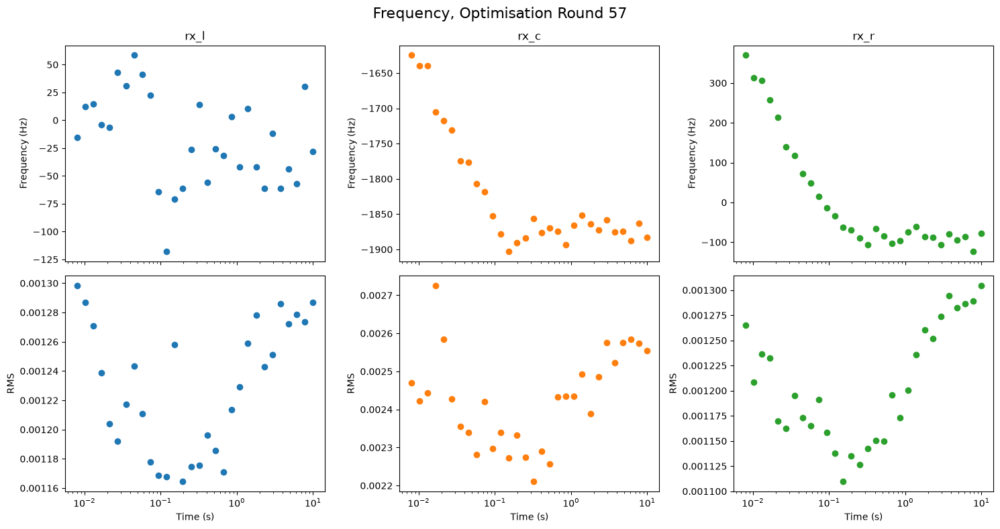

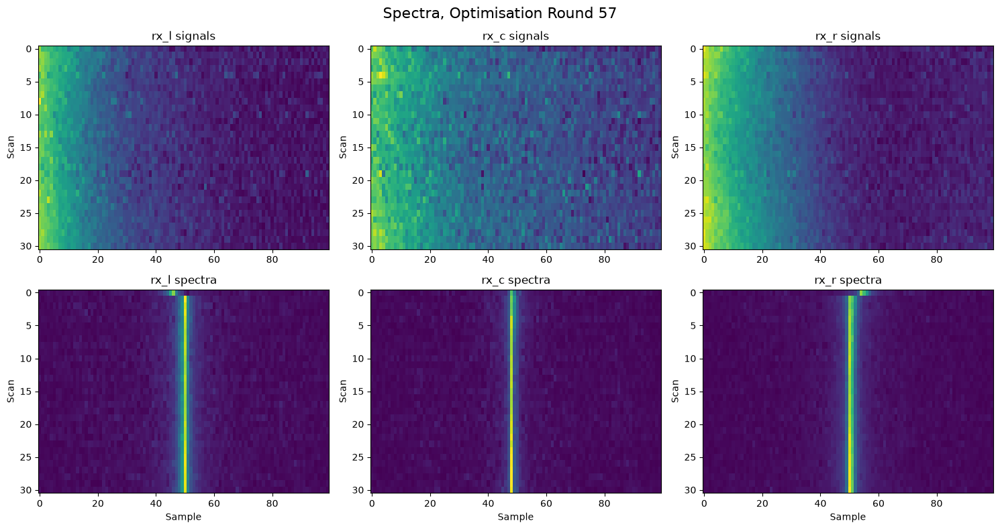

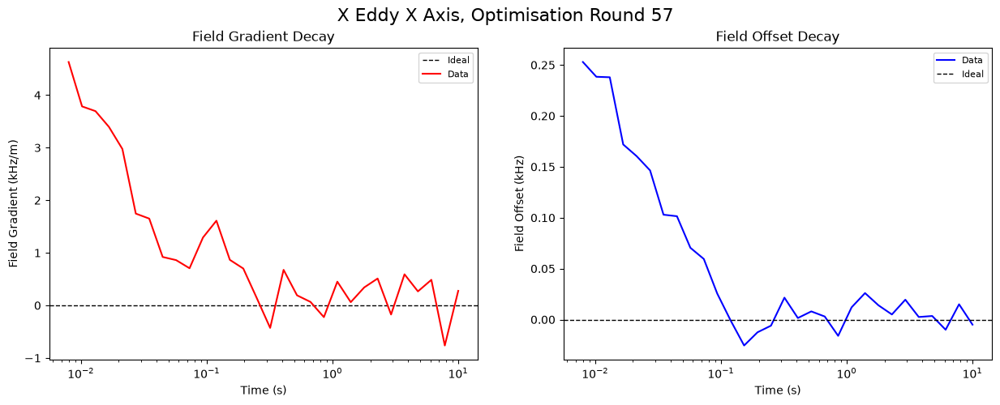

[I 2026-11-26 10:18:27,836] Trial 57 finished with value: 4558.05413540689 and parameters: {'X_A1': 0.09703047587449312, 'X_A2': 0.07069191002902472, 'X_A3': 0.04266851913827823, 'X_A4': -2.753551488656404e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3853.0734632683652
mean |E| = 940.0299850074961
RMS E = 1357.7292110477383
Total cost = 4.558e+03
E max = 0.12190992056670369
E nanmax = 0.12190992056670369
E contains nan = False
B max = 0.01936912758907164
B nanmax = 0.01936912758907164
B contains nan = False
Trial 58


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01936912758907164 !!!!!!!!!!!!!!!!


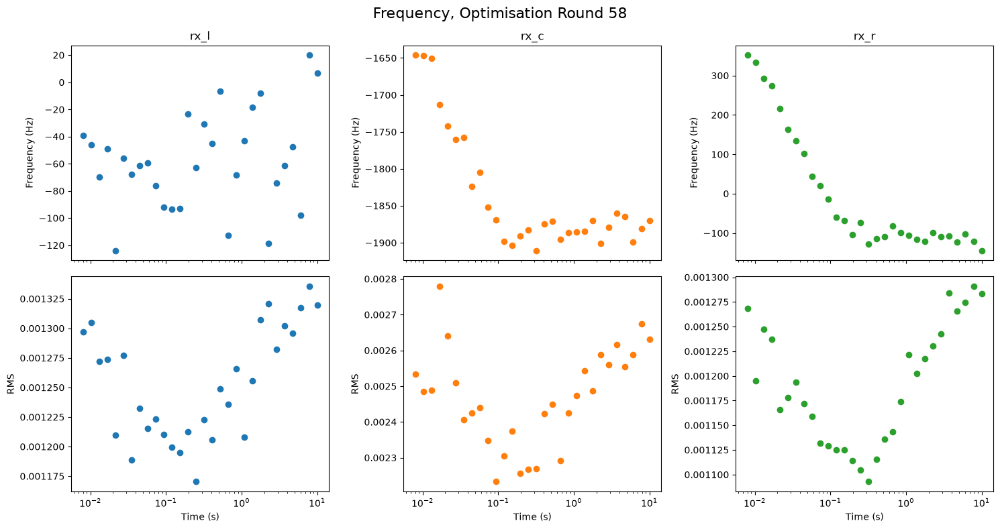

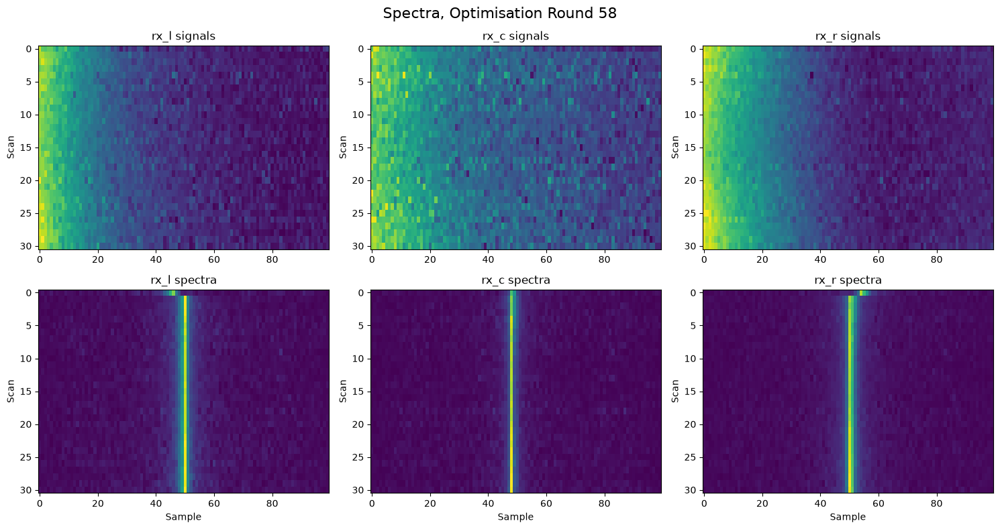

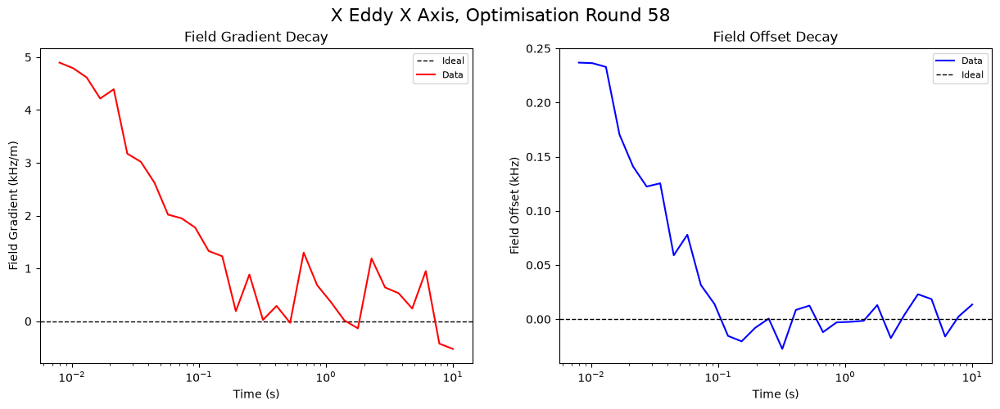

[I 2026-11-26 10:19:15,500] Trial 58 finished with value: 5722.4757939264355 and parameters: {'X_A1': 0.08747861787723893, 'X_A2': 0.07146110832143804, 'X_A3': 0.03516427324609076, 'X_A4': -9.765396100510306e-10}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3908.0459770114935
mean |E| = 1294.3528235882052
RMS E = 1735.5806924292842
Total cost = 5.722e+03
E max = 0.12378806664898462
E nanmax = 0.12378806664898462
E contains nan = False
B max = 0.019667512033307688
B nanmax = 0.019667512033307688
B contains nan = False
Trial 59


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019667512033307688 !!!!!!!!!!!!!!!!


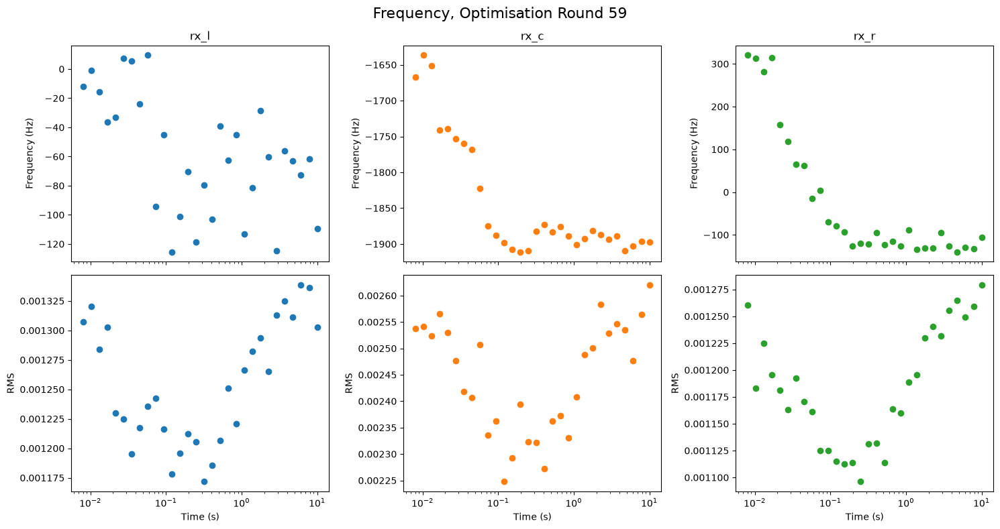

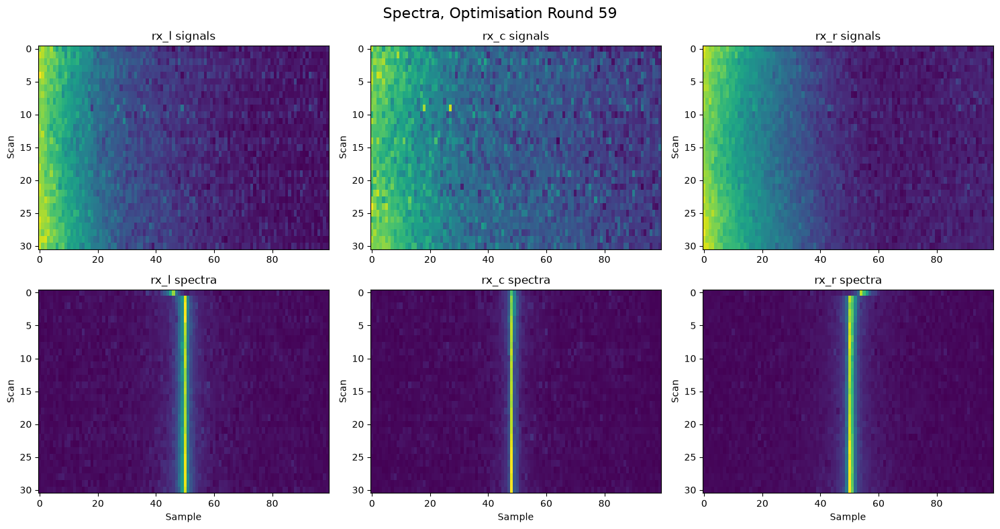

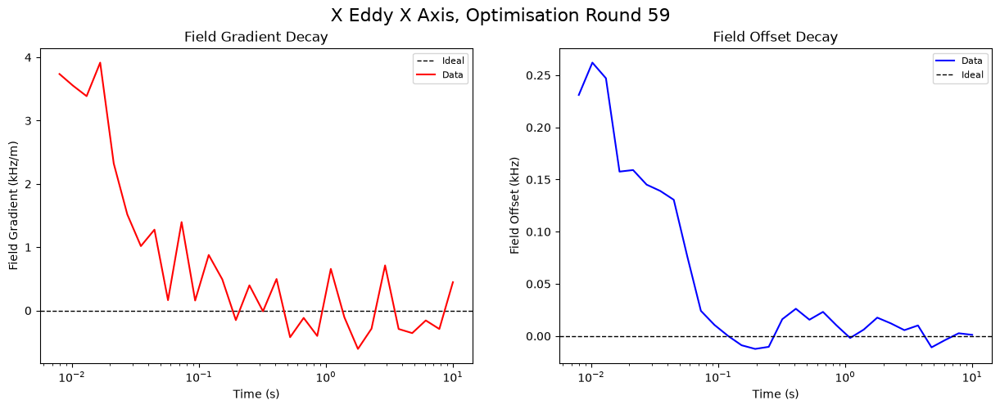

[I 2026-11-26 10:20:03,421] Trial 59 finished with value: 3557.8881858019217 and parameters: {'X_A1': 0.09368094420618221, 'X_A2': 0.0758299753983429, 'X_A3': 0.03911576842670475, 'X_A4': -5.689518318924422e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3503.2483758120934
mean |E| = 943.0284857571212
RMS E = 1357.8518368298317
Total cost = 3.558e+03
E max = 0.12440622267841875
E nanmax = 0.12440622267841875
E contains nan = False
B max = 0.019765729228351746
B nanmax = 0.019765729228351746
B contains nan = False
Trial 60


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019765729228351746 !!!!!!!!!!!!!!!!


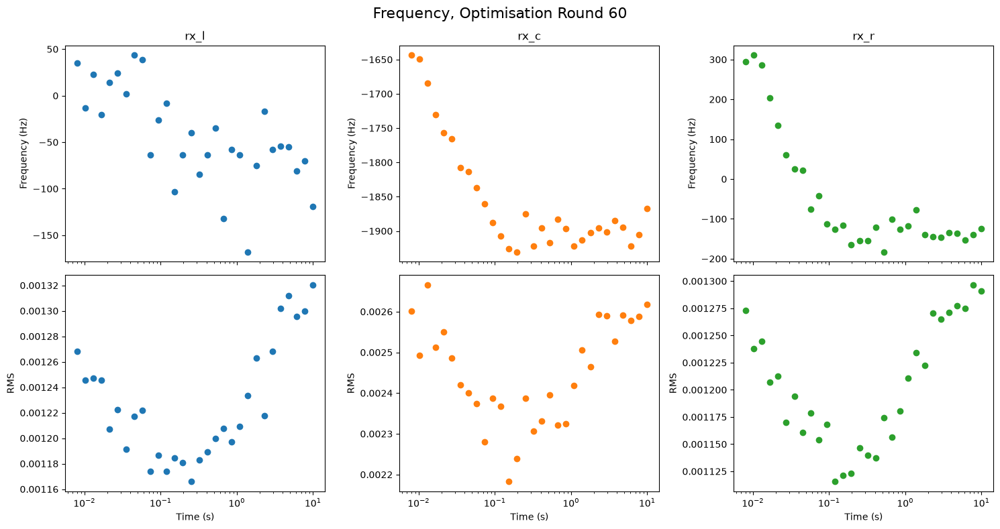

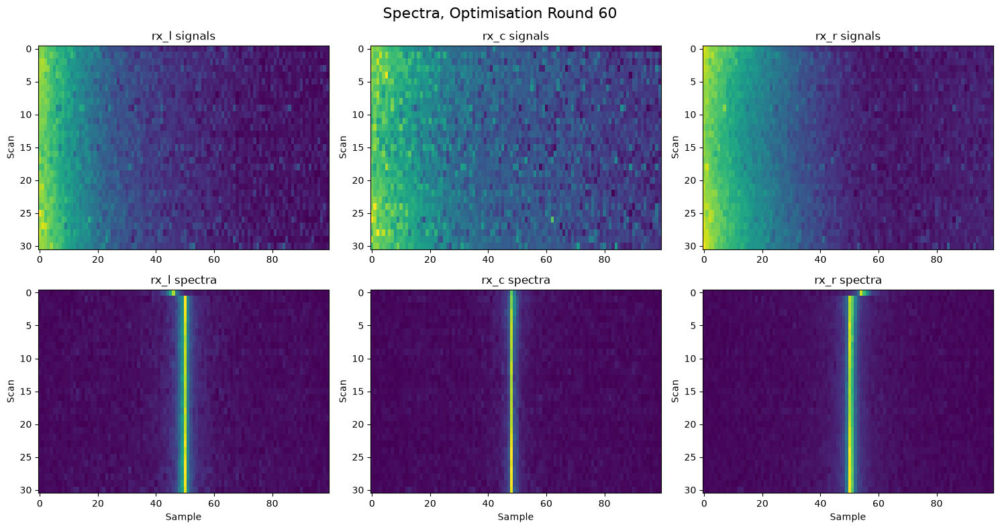

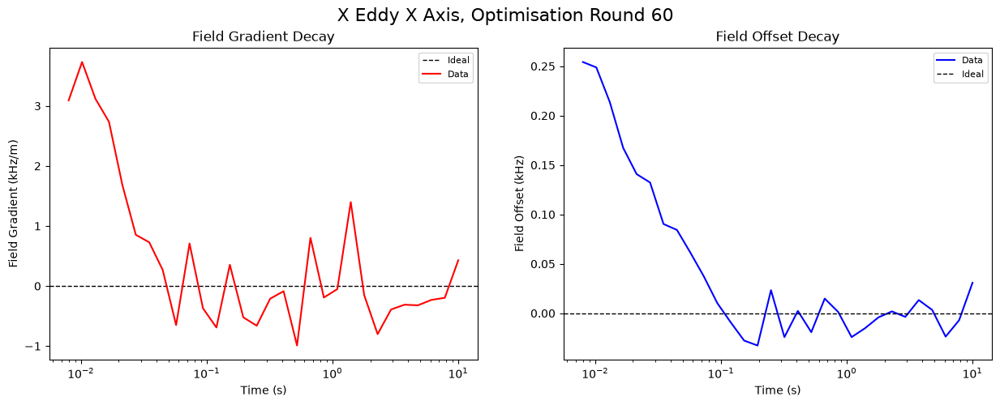

[I 2026-11-26 10:20:51,121] Trial 60 finished with value: 3695.7828665043685 and parameters: {'X_A1': 0.10656825066420178, 'X_A2': 0.06744462006466714, 'X_A3': 0.038734992239137914, 'X_A4': -3.0358308567862883e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3243.378310844577
mean |E| = 983.8414126270196
RMS E = 1246.1233707004283
Total cost = 3.696e+03
E max = 0.12123498211427577
E nanmax = 0.12123498211427577
E contains nan = False
B max = 0.01926190270083841
B nanmax = 0.01926190270083841
B contains nan = False
Trial 61


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01926190270083841 !!!!!!!!!!!!!!!!


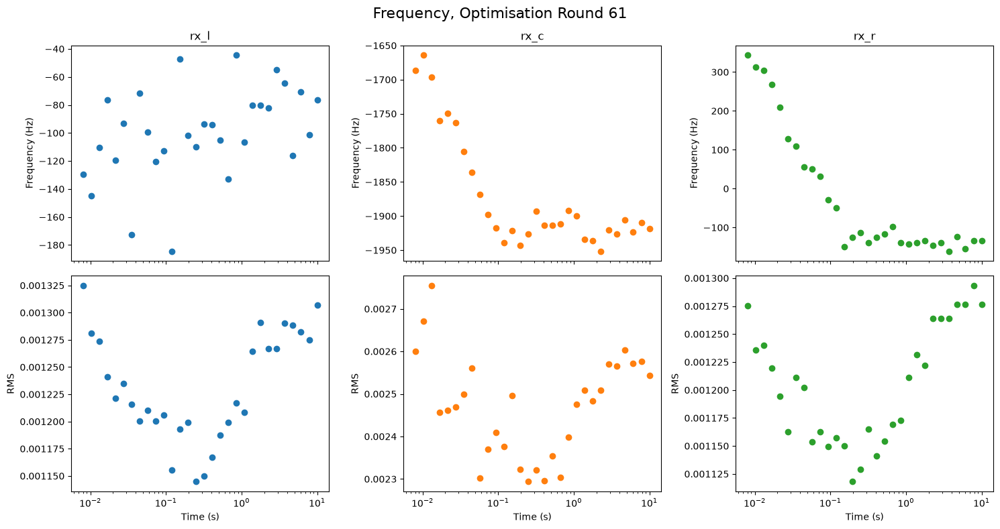

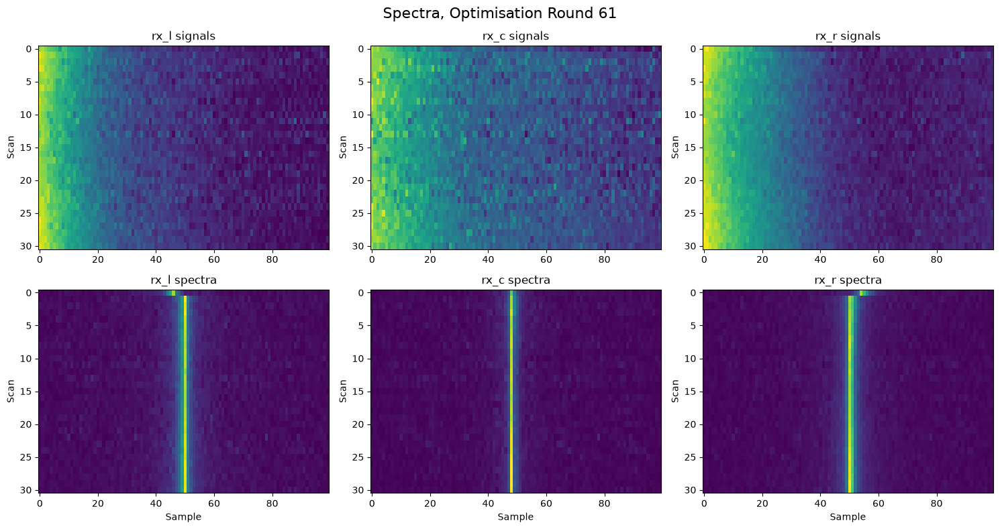

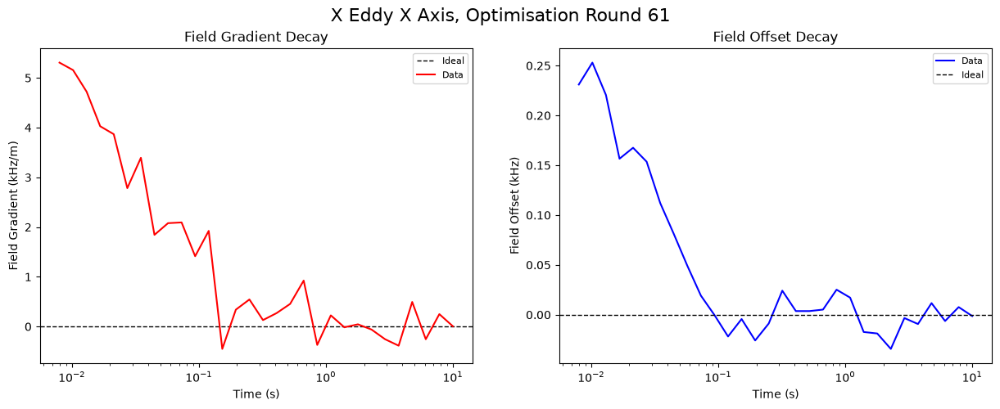

[I 2026-11-26 10:21:39,065] Trial 61 finished with value: 2823.0382736080355 and parameters: {'X_A1': 0.08324174162510377, 'X_A2': 0.07333287308165001, 'X_A3': 0.03212085015875078, 'X_A4': -5.699504401112725e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4727.636181909044
mean |E| = 1362.9851740796264
RMS E = 1923.4312622539335
Total cost = 2.823e+03
E max = 0.12340718836915343
E nanmax = 0.12340718836915343
E contains nan = False
B max = 0.0196070010208055
B nanmax = 0.0196070010208055
B contains nan = False
Trial 62


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0196070010208055 !!!!!!!!!!!!!!!!


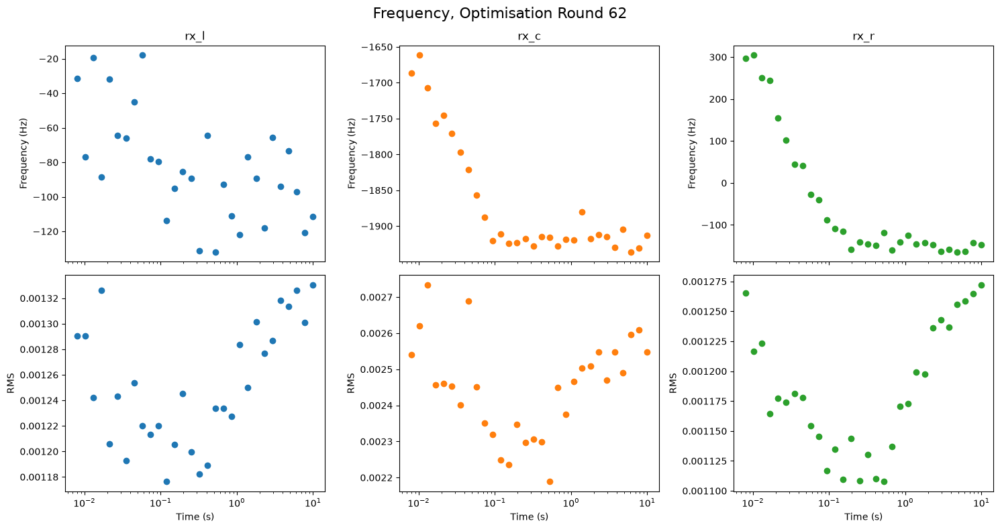

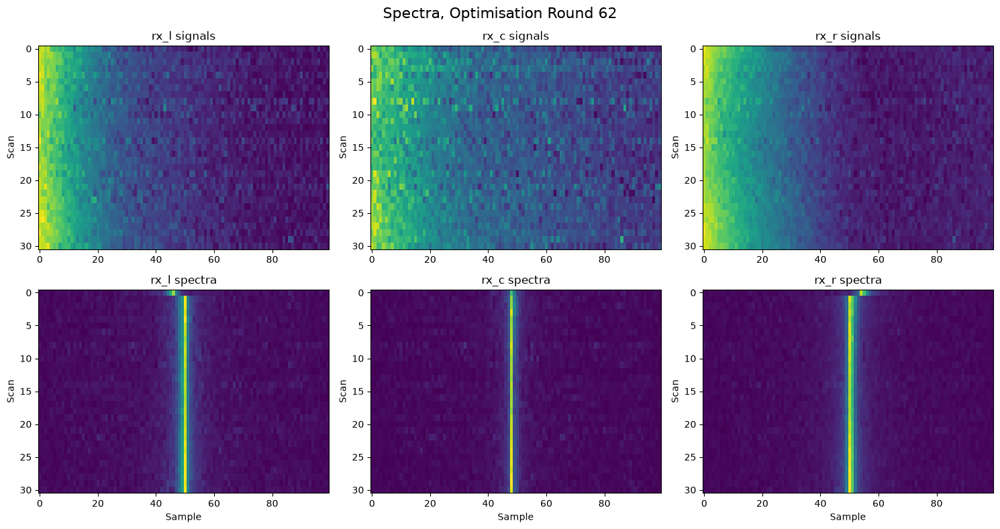

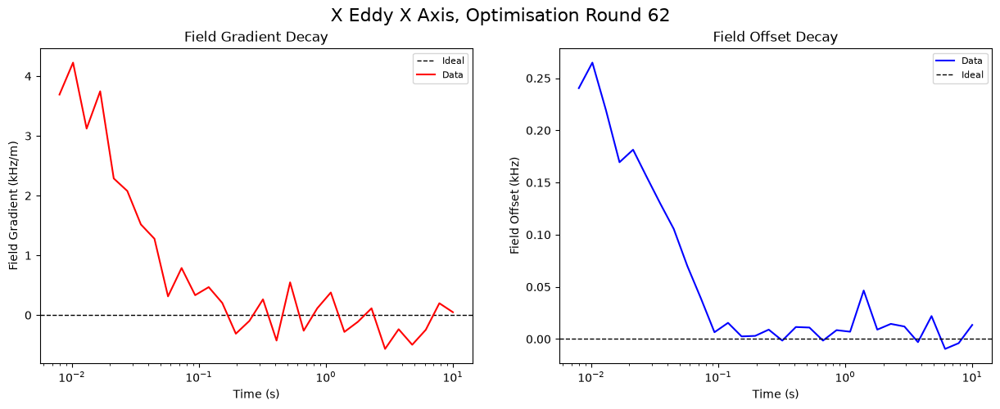

[I 2026-11-26 10:22:41,852] Trial 62 finished with value: 2713.8102001496977 and parameters: {'X_A1': 0.09626515937210532, 'X_A2': 0.07044521461582358, 'X_A3': 0.038930516197161494, 'X_A4': -7.942571293035484e-10}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3813.0934532733622
mean |E| = 937.5312343828083
RMS E = 1389.6744183005742
Total cost = 2.714e+03
E max = 0.12431765839076811
E nanmax = 0.12431765839076811
E contains nan = False
B max = 0.0197516477280546
B nanmax = 0.0197516477280546
B contains nan = False
Trial 63


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0197516477280546 !!!!!!!!!!!!!!!!


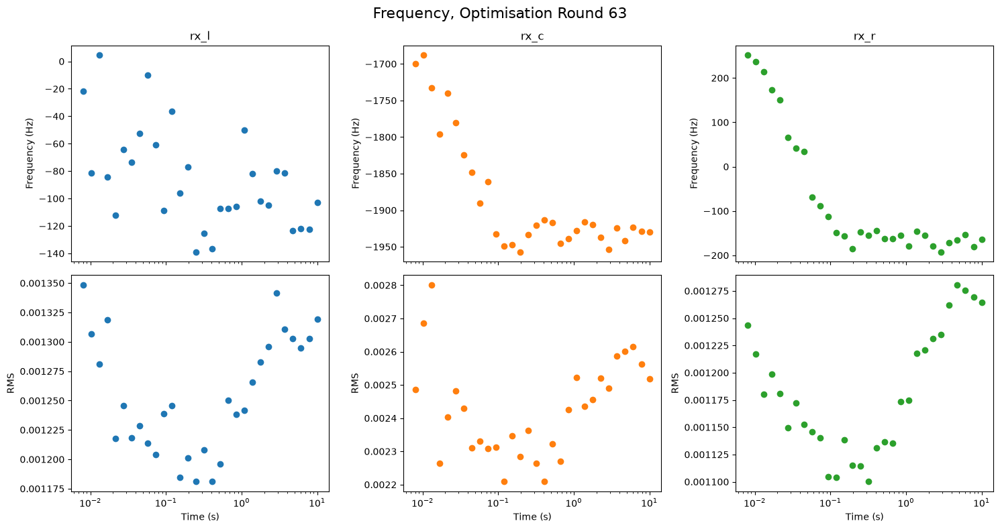

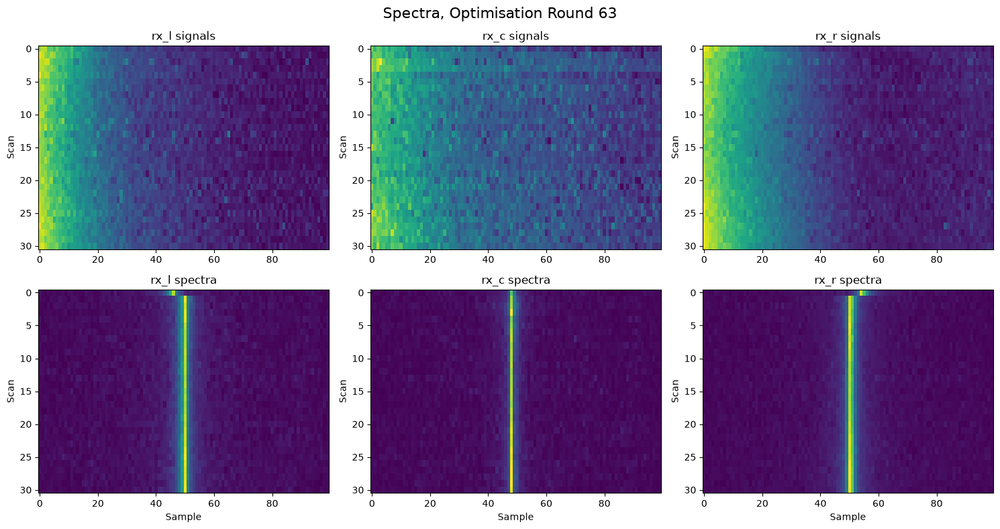

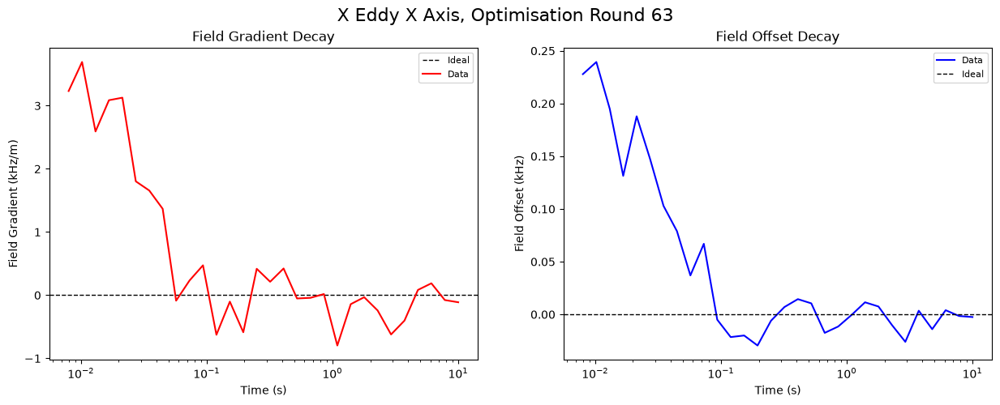

[I 2026-11-26 10:24:03,416] Trial 63 finished with value: 2159.8711083394596 and parameters: {'X_A1': 0.0973068367048806, 'X_A2': 0.07441795574693656, 'X_A3': 0.04095552669462374, 'X_A4': 6.197650205502256e-10}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3188.4057971014486
mean |E| = 982.1755788772278
RMS E = 1284.5982749704647
Total cost = 2.160e+03
E max = 0.12168498185309562
E nanmax = 0.12168498185309562
E contains nan = False
B max = 0.019333398155094973
B nanmax = 0.019333398155094973
B contains nan = False
Trial 64


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019333398155094973 !!!!!!!!!!!!!!!!


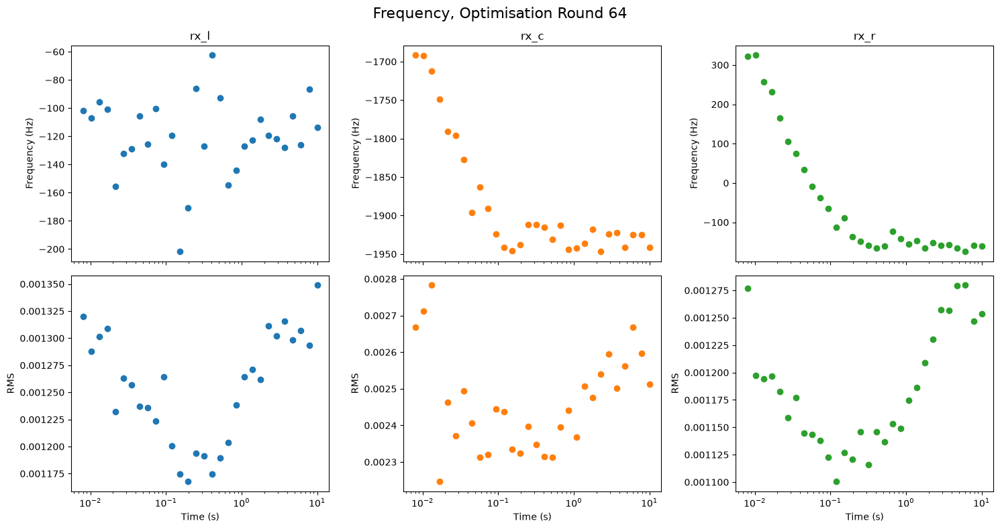

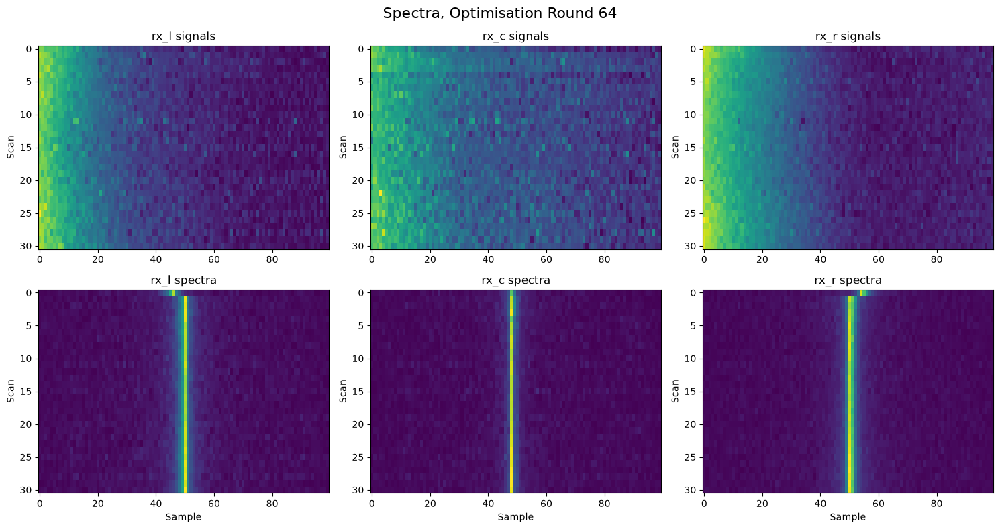

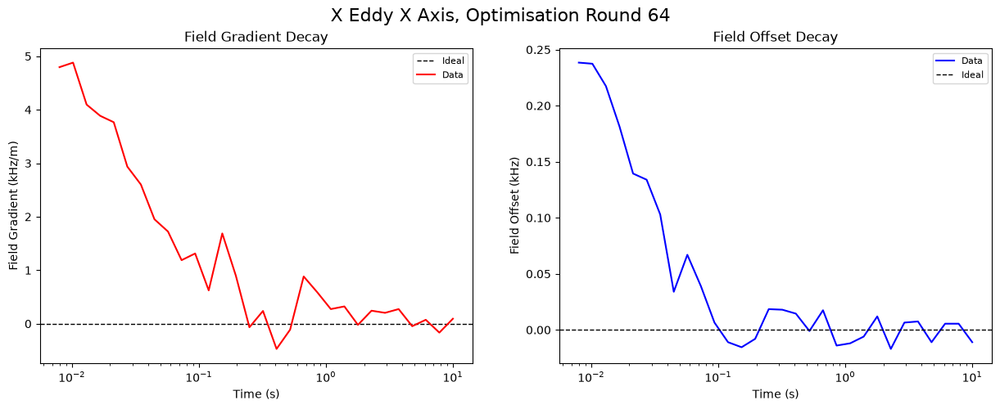

[I 2026-11-26 10:24:51,124] Trial 64 finished with value: 2018.9090094940243 and parameters: {'X_A1': 0.08552072271928637, 'X_A2': 0.07446807669166373, 'X_A3': 0.03212835553382664, 'X_A4': -3.1076109355113344e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4317.841079460269
mean |E| = 1195.2357154755953
RMS E = 1732.477591300771
Total cost = 2.019e+03
E max = 0.12188374037721933
E nanmax = 0.12188374037721933
E contains nan = False
B max = 0.01936497003710853
B nanmax = 0.01936497003710853
B contains nan = False
Trial 65


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01936497003710853 !!!!!!!!!!!!!!!!


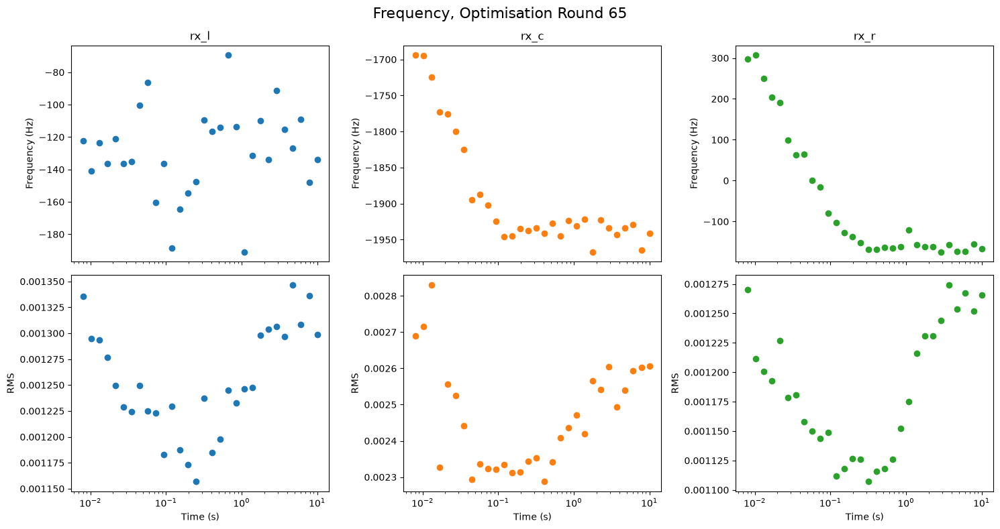

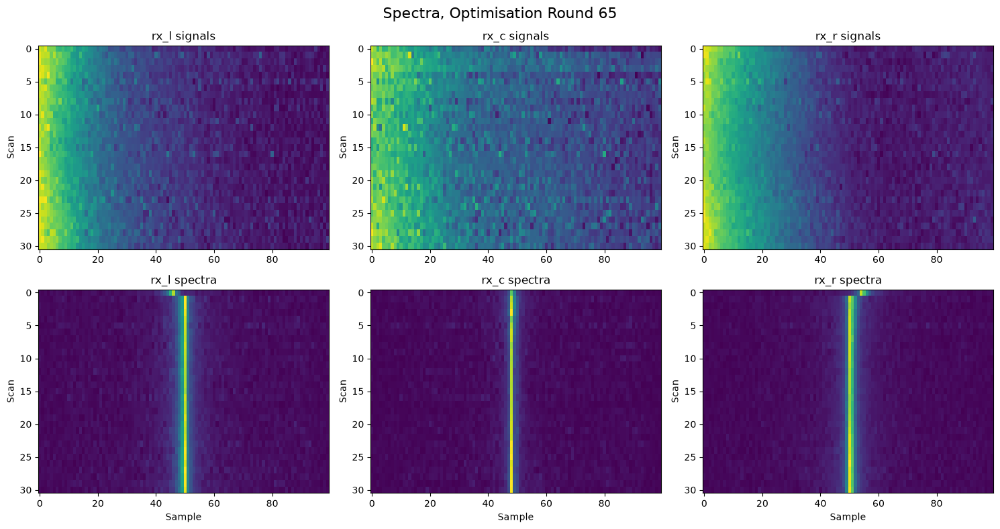

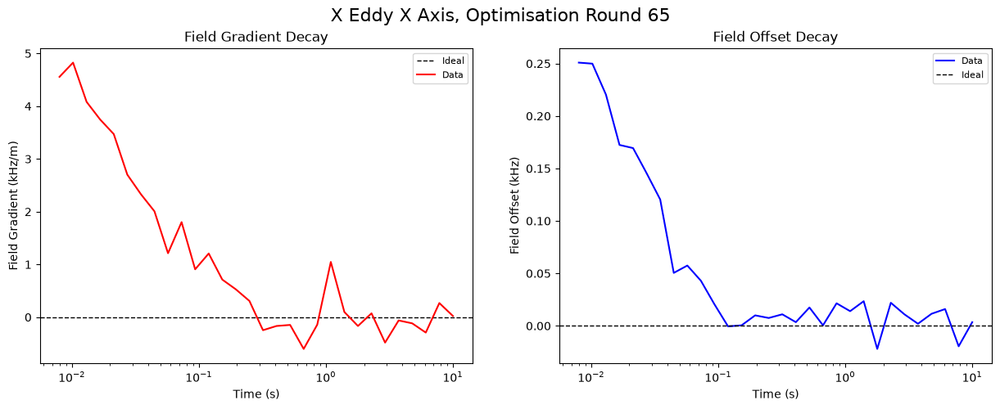

[I 2026-11-26 10:25:38,706] Trial 65 finished with value: 2458.921765233556 and parameters: {'X_A1': 0.08576292239285667, 'X_A2': 0.07380542634754919, 'X_A3': 0.034288476177854375, 'X_A4': -2.636983727975119e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4477.761119440279
mean |E| = 1226.3868065967013
RMS E = 1768.2300700869903
Total cost = 2.459e+03
E max = 0.12375649961042526
E nanmax = 0.12375649961042526
E contains nan = False
B max = 0.019662508998425404
B nanmax = 0.019662508998425404
B contains nan = False
Trial 66


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019662508998425404 !!!!!!!!!!!!!!!!


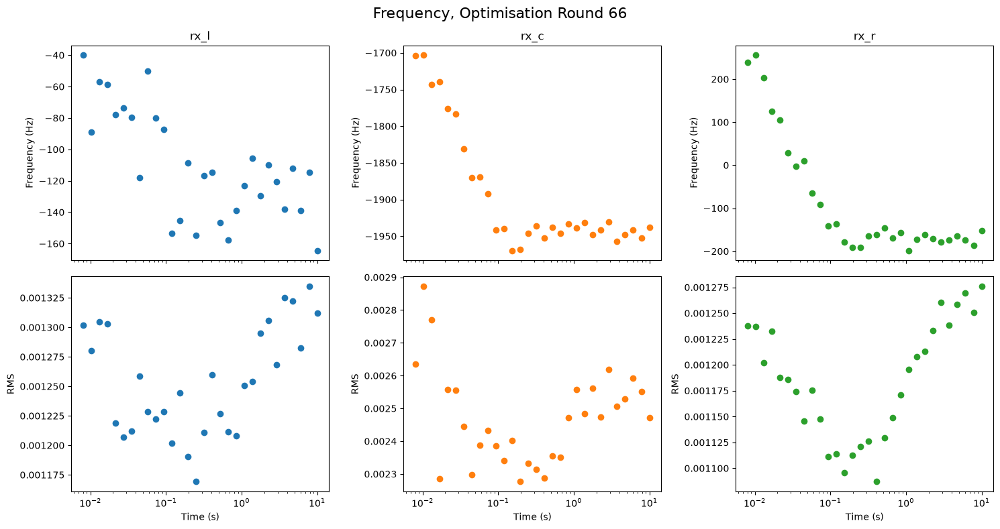

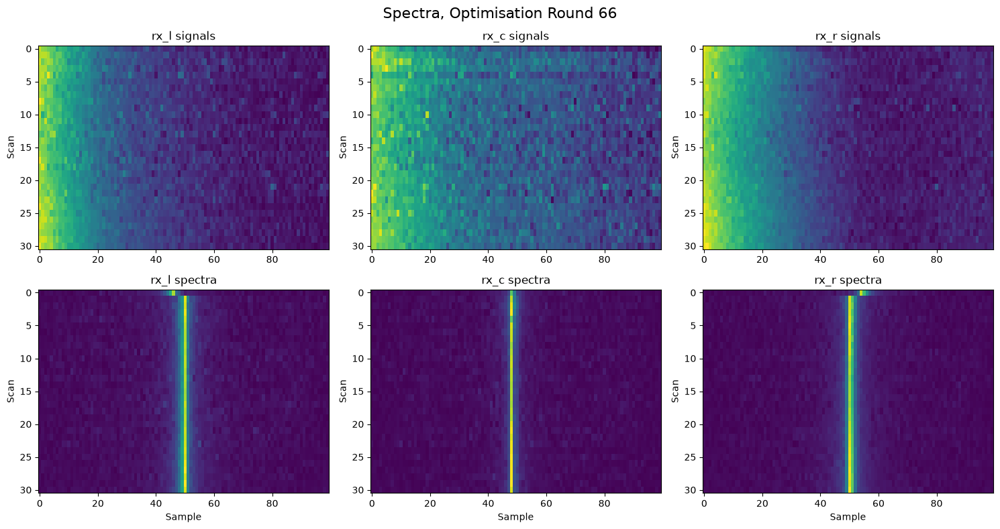

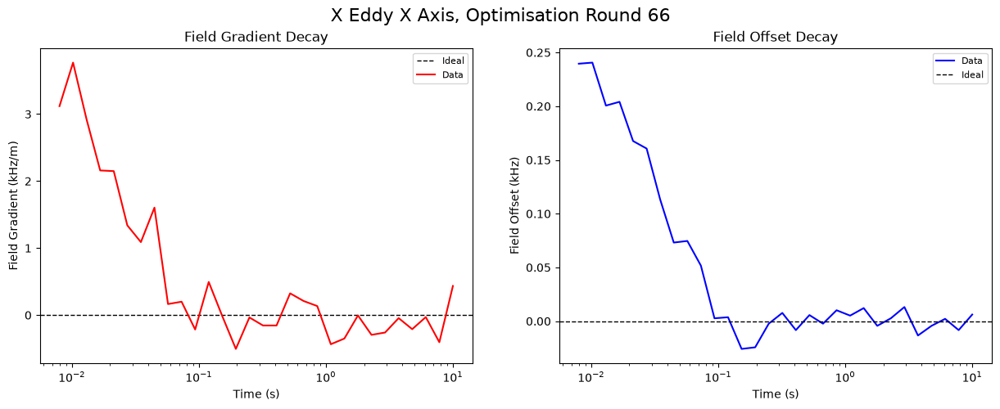

[I 2026-11-26 10:26:28,415] Trial 66 finished with value: 2460.9052548646605 and parameters: {'X_A1': 0.10012331696072821, 'X_A2': 0.07177988486032554, 'X_A3': 0.03596121075155175, 'X_A4': -3.347881010244104e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3448.275862068965
mean |E| = 812.0939530234881
RMS E = 1171.4200493468406
Total cost = 2.461e+03
E max = 0.12286707870472355
E nanmax = 0.12286707870472355
E contains nan = False
B max = 0.019521211800857082
B nanmax = 0.019521211800857082
B contains nan = False
Trial 67


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019521211800857082 !!!!!!!!!!!!!!!!


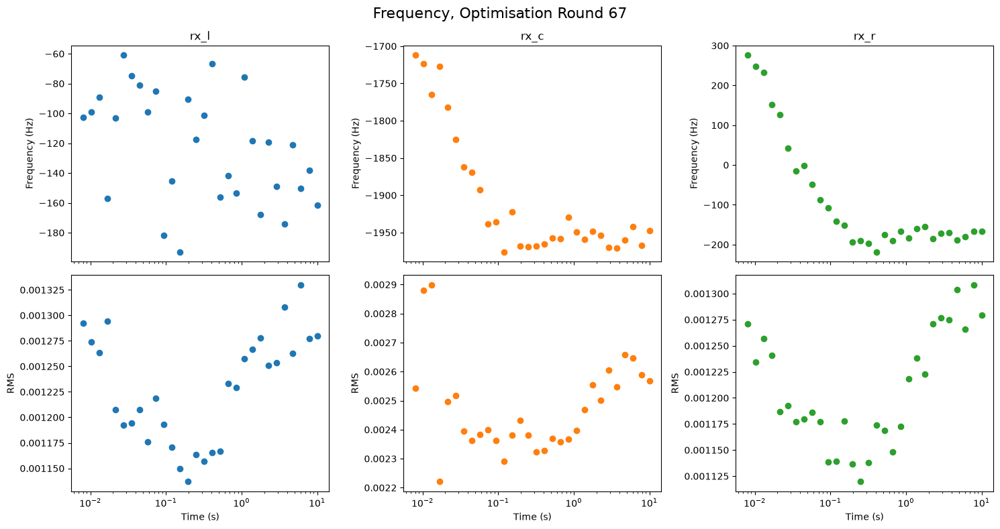

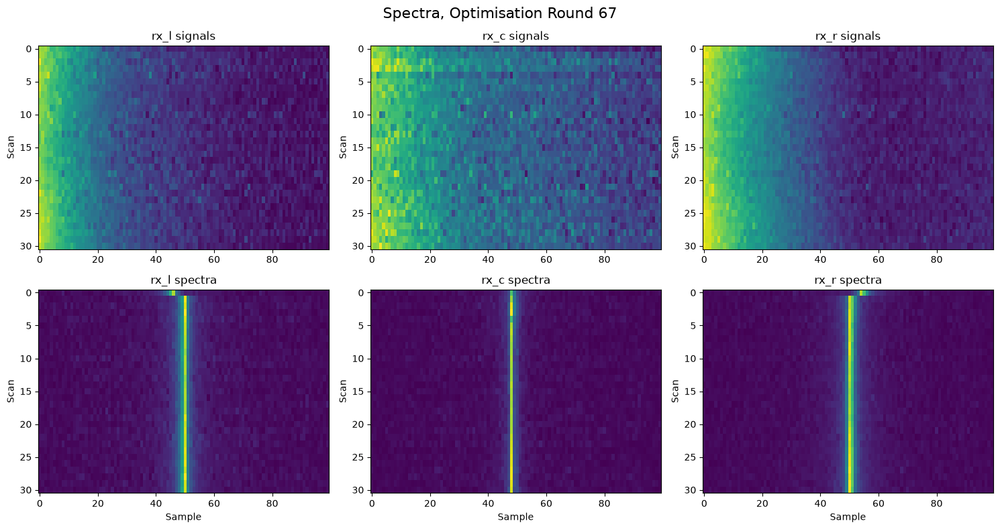

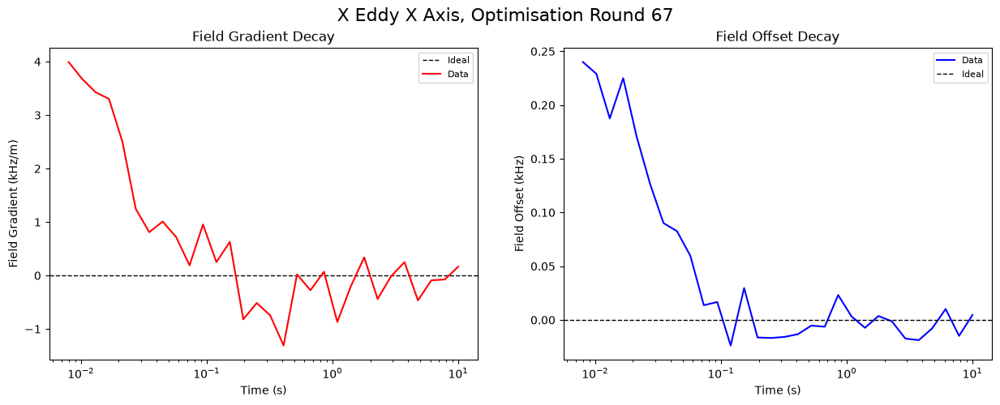

[I 2026-11-26 10:27:51,534] Trial 67 finished with value: 2438.142220846786 and parameters: {'X_A1': 0.09689683609748863, 'X_A2': 0.07215592918643544, 'X_A3': 0.031758514530834454, 'X_A4': -4.9141010062611635e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3783.1084457771112
mean |E| = 963.6848242545394
RMS E = 1439.2494143118545
Total cost = 2.438e+03
E max = 0.12116468155017246
E nanmax = 0.12116468155017246
E contains nan = False
B max = 0.019250723380786195
B nanmax = 0.019250723380786195
B contains nan = False
Trial 68


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019250723380786195 !!!!!!!!!!!!!!!!


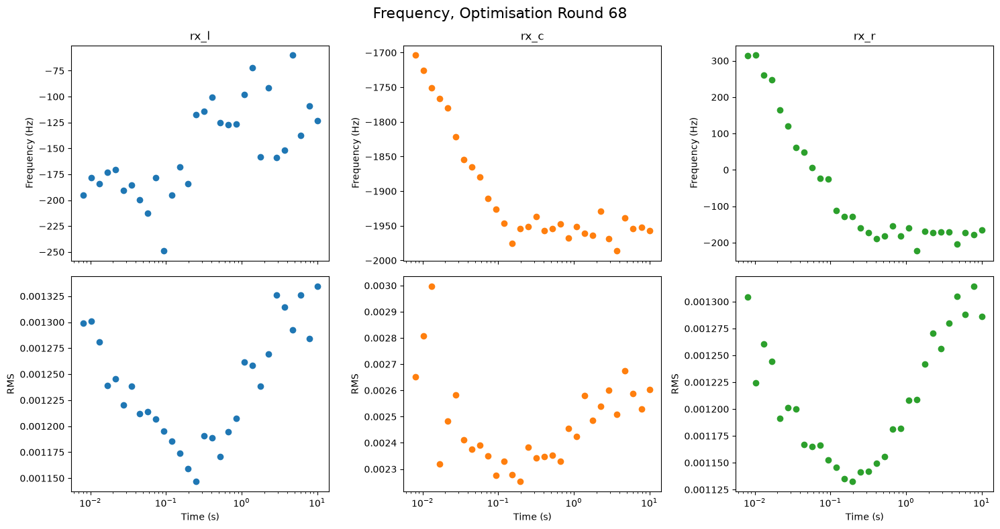

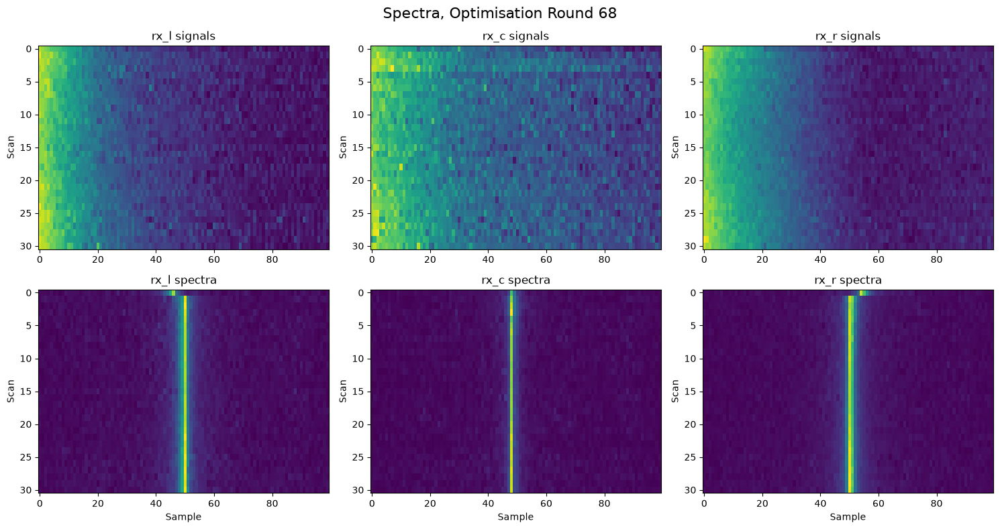

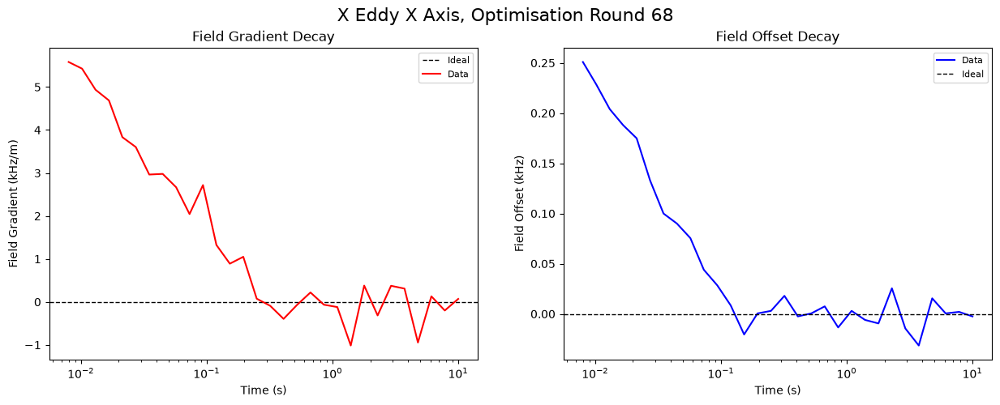

[I 2026-11-26 10:29:17,508] Trial 68 finished with value: 3609.3011916154232 and parameters: {'X_A1': 0.08274212883324124, 'X_A2': 0.07022085710703022, 'X_A3': 0.03553459106685737, 'X_A4': -4.623133577582359e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 5092.4537731134415
mean |E| = 1578.0443111777442
RMS E = 2178.420100169381
Total cost = 3.609e+03
E max = 0.12279437261221579
E nanmax = 0.12279437261221579
E contains nan = False
B max = 0.019509626996383936
B nanmax = 0.019509626996383936
B contains nan = False
Trial 69


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019509626996383936 !!!!!!!!!!!!!!!!


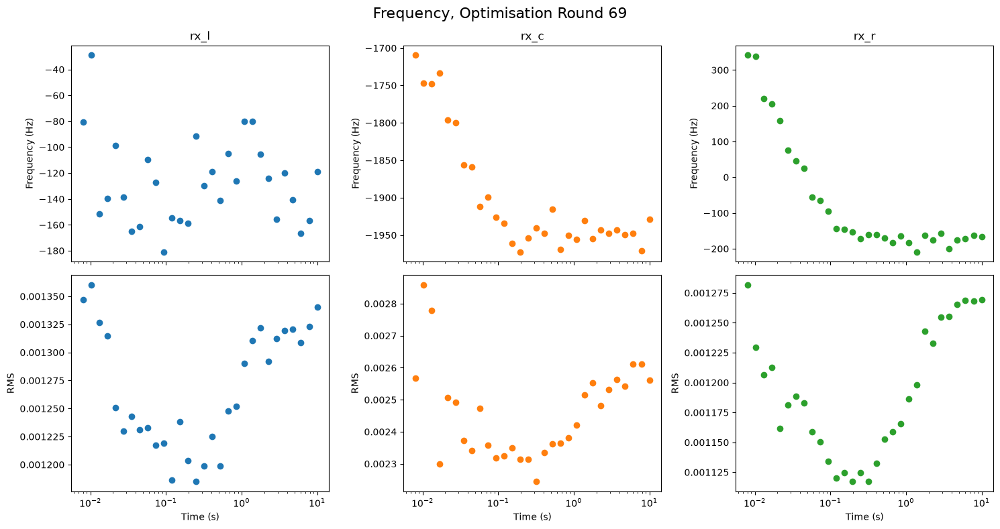

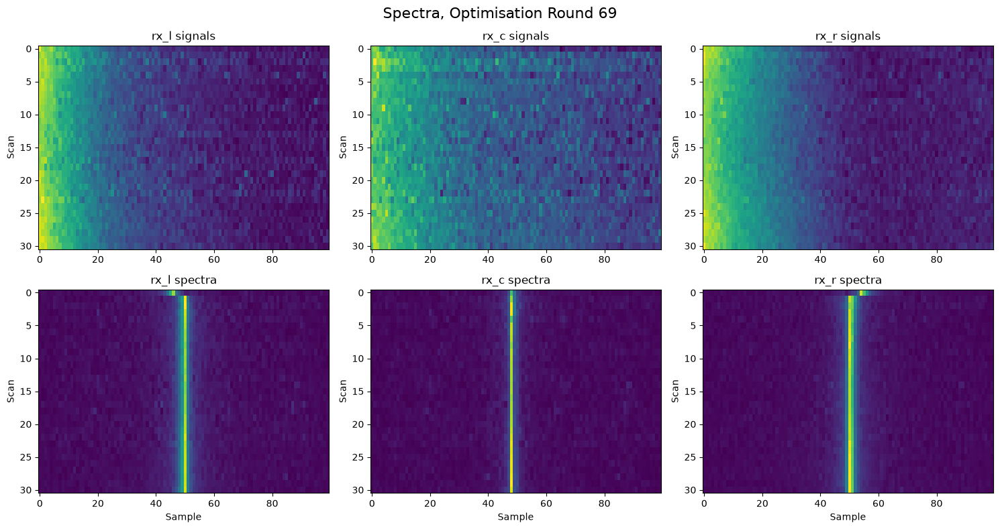

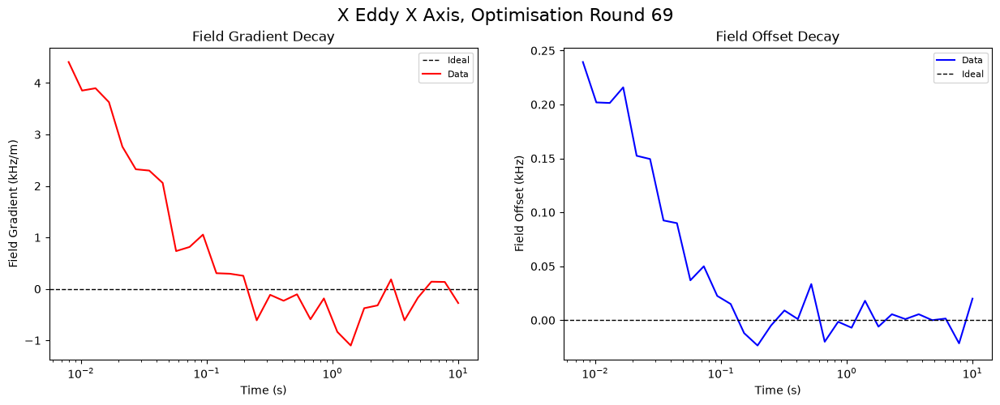

[I 2026-11-26 10:30:40,257] Trial 69 finished with value: 3052.869077407529 and parameters: {'X_A1': 0.09168044007690637, 'X_A2': 0.06749599351733199, 'X_A3': 0.04224484427851454, 'X_A4': -3.2157546132439938e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4217.891054472762
mean |E| = 1137.5978677327998
RMS E = 1667.213405025074
Total cost = 3.053e+03
E max = 0.1242007721055697
E nanmax = 0.1242007721055697
E contains nan = False
B max = 0.01973307692010474
B nanmax = 0.01973307692010474
B contains nan = False
Trial 70


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01973307692010474 !!!!!!!!!!!!!!!!


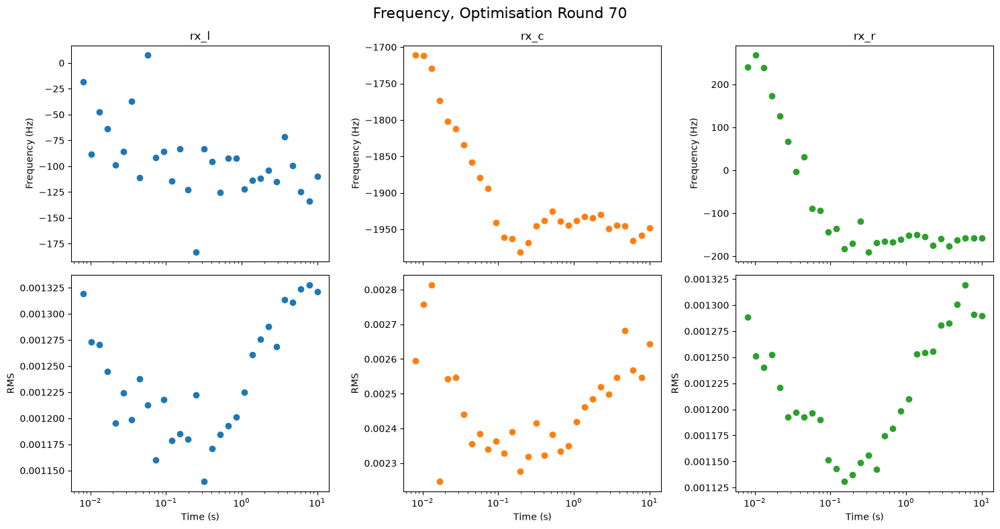

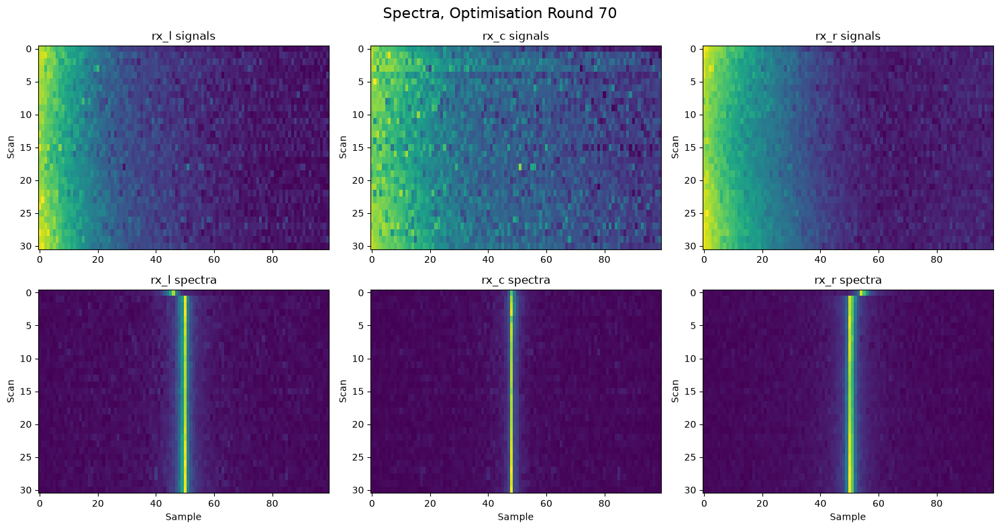

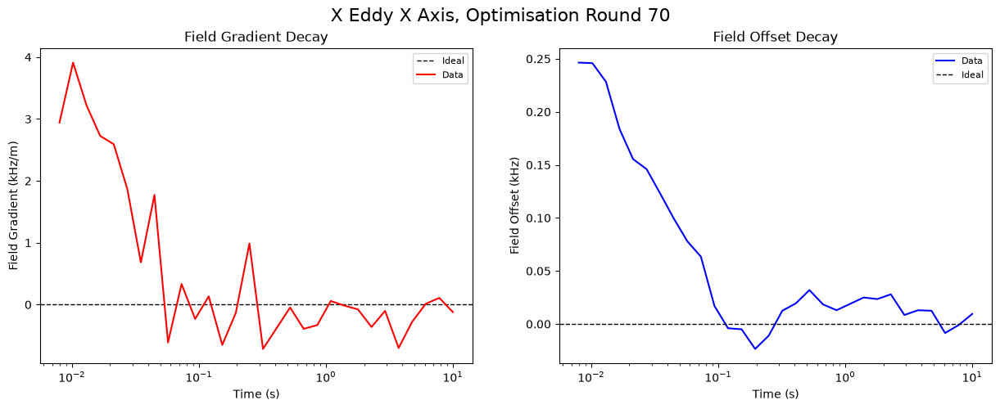

[I 2026-11-26 10:32:03,295] Trial 70 finished with value: 2118.6502941305444 and parameters: {'X_A1': 0.09905223665253879, 'X_A2': 0.07141396908514752, 'X_A3': 0.0413024612809509, 'X_A4': -1.4490105632043874e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3563.2183908045963
mean |E| = 979.3436615025818
RMS E = 1310.880872442686
Total cost = 2.119e+03
E max = 0.12350301999546273
E nanmax = 0.12350301999546273
E contains nan = False
B max = 0.019622222091376863
B nanmax = 0.019622222091376863
B contains nan = False
Trial 71


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019622222091376863 !!!!!!!!!!!!!!!!


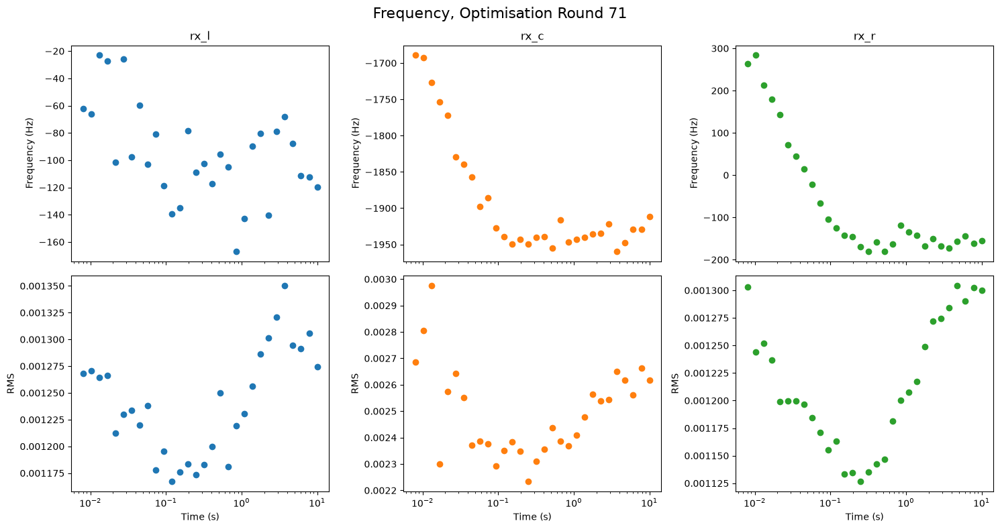

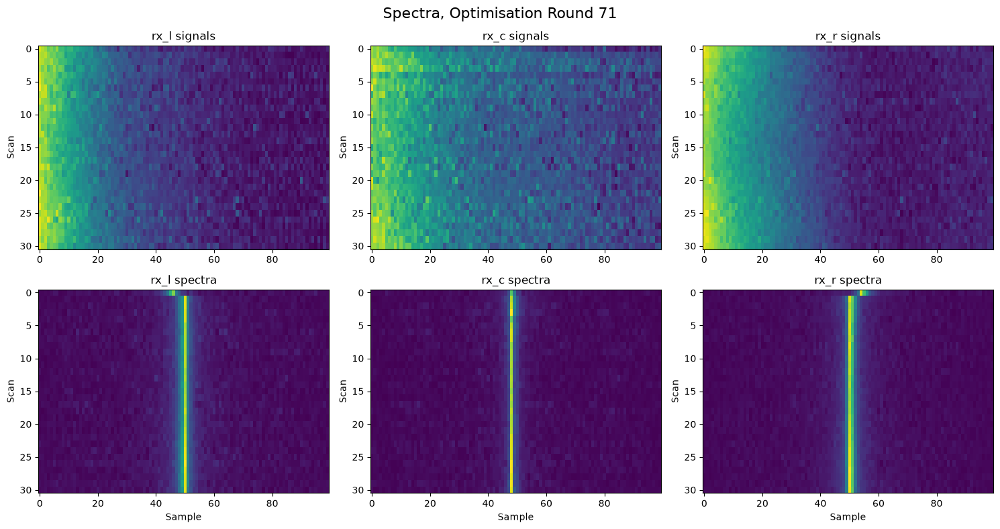

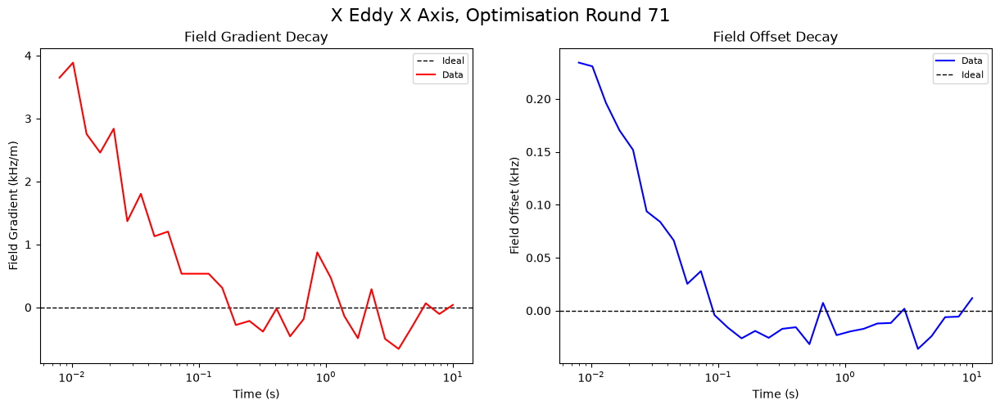

[I 2026-11-26 10:33:27,040] Trial 71 finished with value: 2730.7737281105465 and parameters: {'X_A1': 0.09474862953653684, 'X_A2': 0.07163164221626787, 'X_A3': 0.04015585584638882, 'X_A4': -3.108389585688583e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3498.2508745627174
mean |E| = 928.702315508912
RMS E = 1287.722352289576
Total cost = 2.731e+03
E max = 0.12314812149447416
E nanmax = 0.12314812149447416
E contains nan = False
B max = 0.01956584718366351
B nanmax = 0.01956584718366351
B contains nan = False
Trial 72


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01956584718366351 !!!!!!!!!!!!!!!!


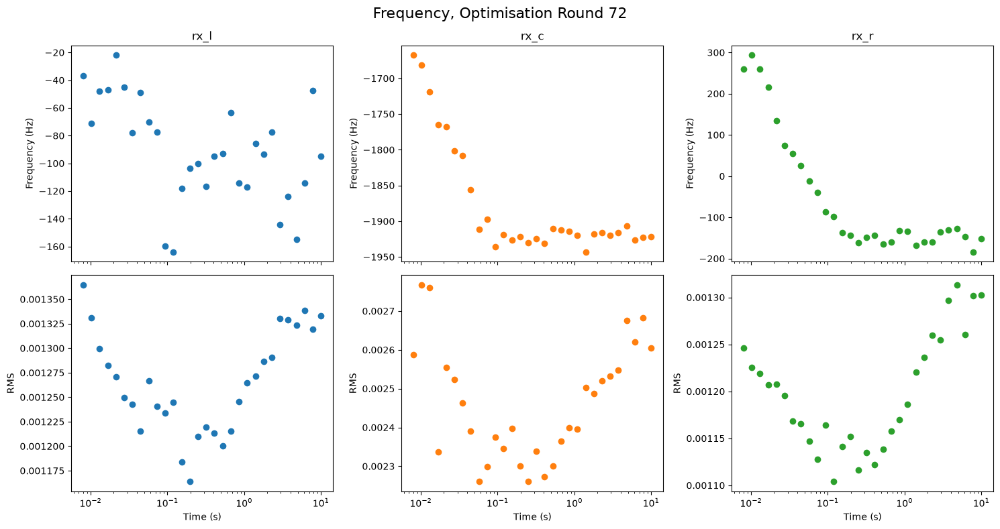

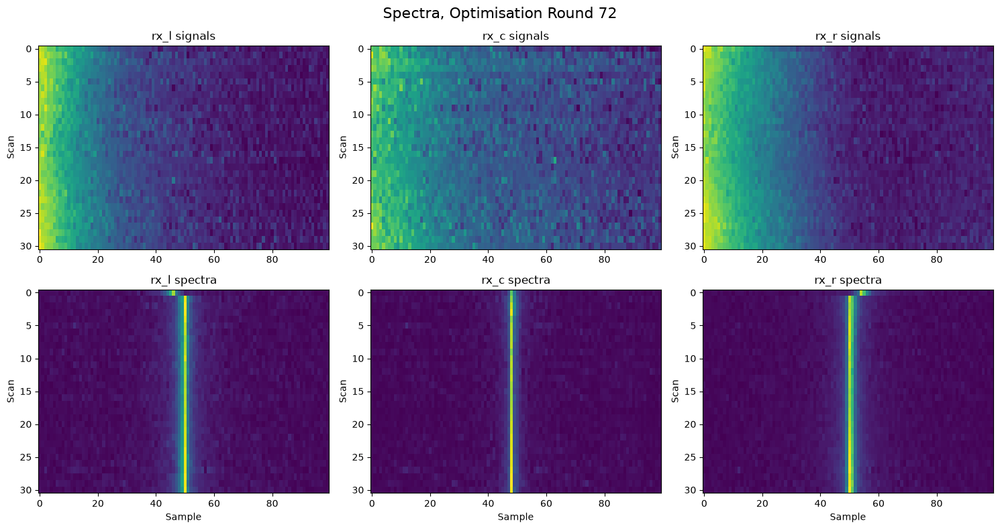

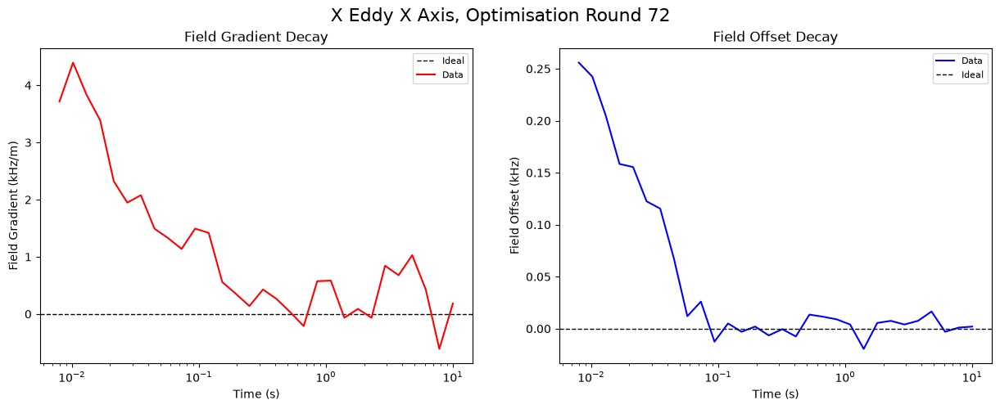

[I 2026-11-26 10:34:53,531] Trial 72 finished with value: 5246.22337474728 and parameters: {'X_A1': 0.0942022289418461, 'X_A2': 0.07263446144772548, 'X_A3': 0.03669256843313605, 'X_A4': -1.9493805990483456e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3643.178410794602
mean |E| = 952.3571547559551
RMS E = 1325.6695142414248
Total cost = 5.246e+03
E max = 0.12275788803577437
E nanmax = 0.12275788803577437
E contains nan = False
B max = 0.0195038344386822
B nanmax = 0.0195038344386822
B contains nan = False
Trial 73


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0195038344386822 !!!!!!!!!!!!!!!!


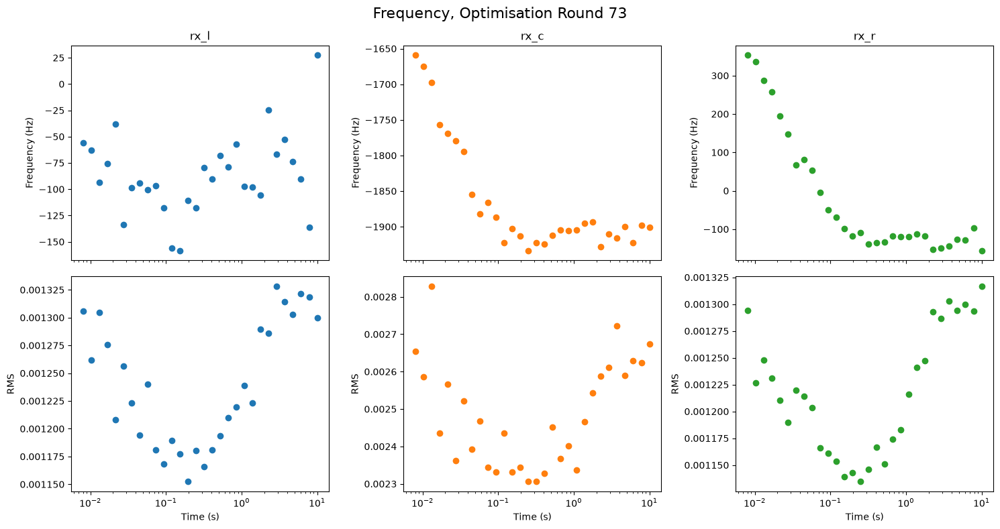

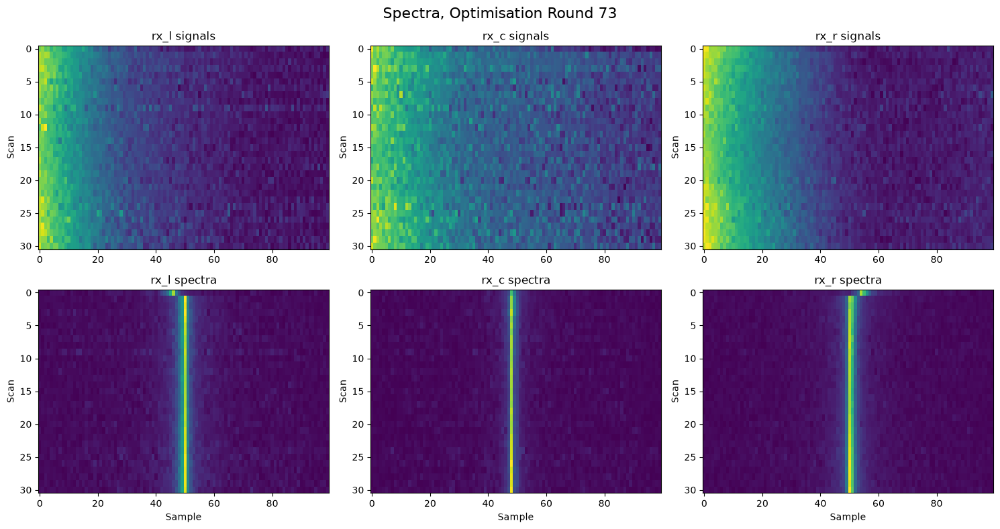

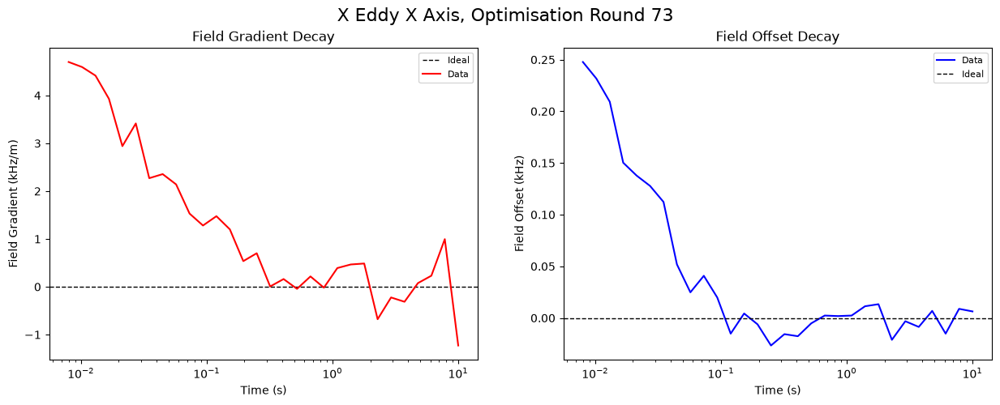

[I 2026-11-26 10:35:57,955] Trial 73 finished with value: 5480.246376514151 and parameters: {'X_A1': 0.0881035427902876, 'X_A2': 0.07255413647174579, 'X_A3': 0.04042784268849057, 'X_A4': -3.4040071589740875e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4092.95352323838
mean |E| = 1262.5353989671828
RMS E = 1740.4613957688643
Total cost = 5.480e+03
E max = 0.12334330408828621
E nanmax = 0.12334330408828621
E contains nan = False
B max = 0.019596850471041302
B nanmax = 0.019596850471041302
B contains nan = False
Trial 74


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019596850471041302 !!!!!!!!!!!!!!!!


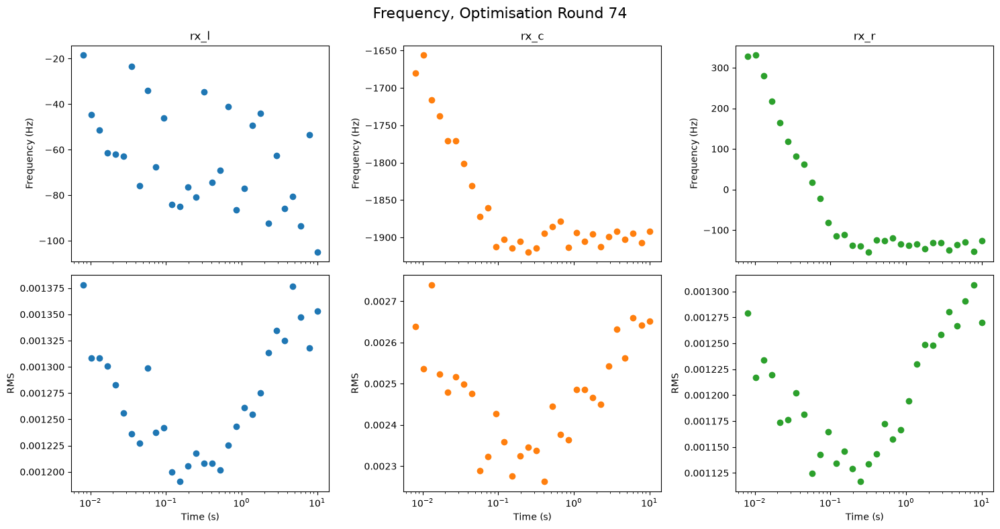

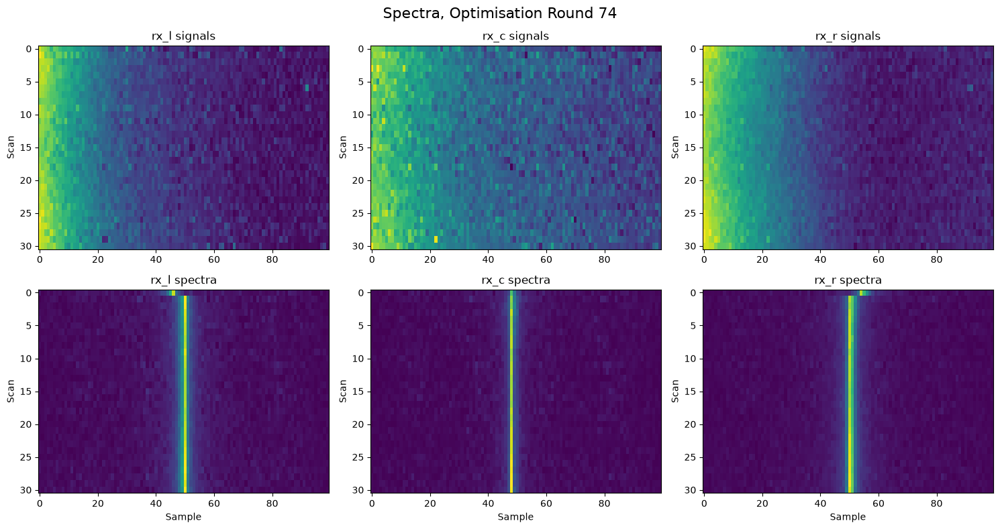

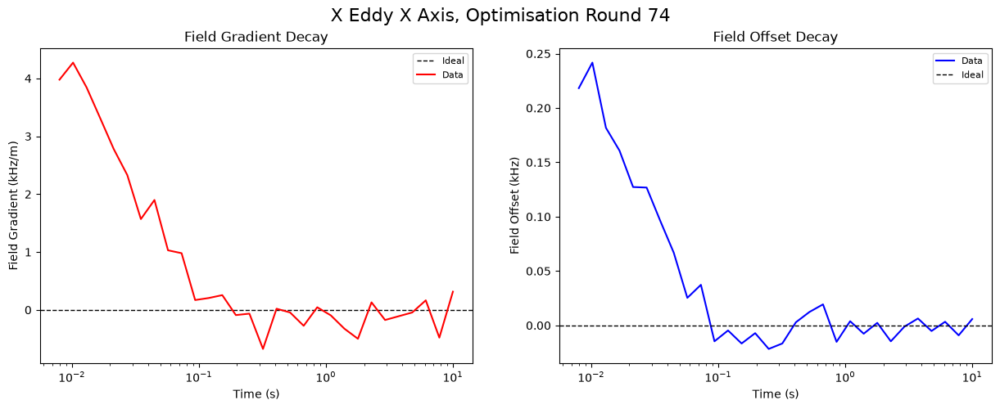

[I 2026-11-26 10:36:45,530] Trial 74 finished with value: 2526.6531939984943 and parameters: {'X_A1': 0.09693973340923616, 'X_A2': 0.06892358837037965, 'X_A3': 0.039299277344569034, 'X_A4': -3.5089937966287446e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3753.123438280859
mean |E| = 1092.1206063634845
RMS E = 1474.7817268259057
Total cost = 2.527e+03
E max = 0.12461187511580847
E nanmax = 0.12461187511580847
E contains nan = False
B max = 0.01979839061994012
B nanmax = 0.01979839061994012
B contains nan = False
Trial 75


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01979839061994012 !!!!!!!!!!!!!!!!


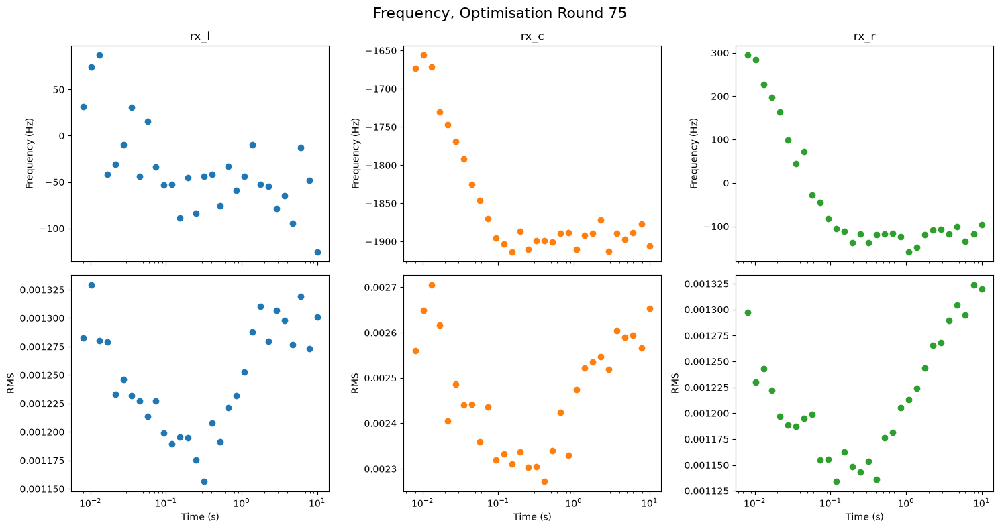

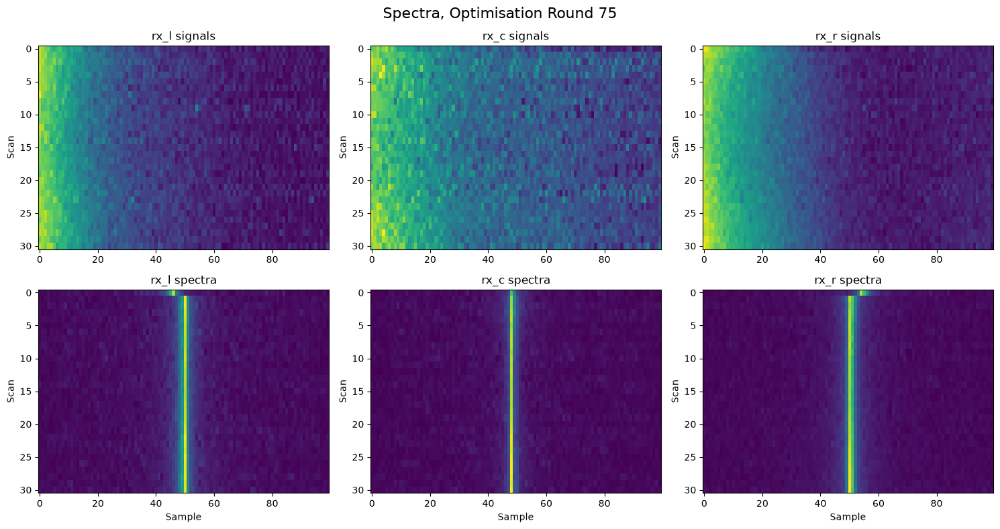

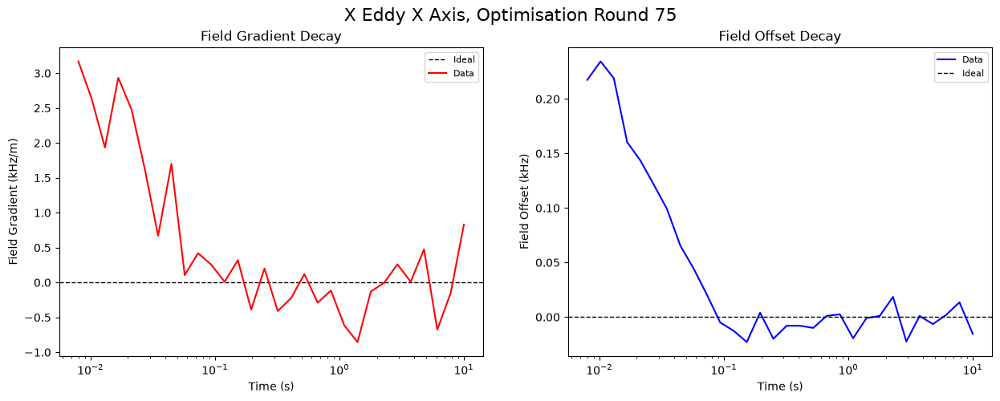

[I 2026-11-26 10:38:08,925] Trial 75 finished with value: 3796.2482250142084 and parameters: {'X_A1': 0.1020688572503054, 'X_A2': 0.07071160759124093, 'X_A3': 0.042031047217710345, 'X_A4': -1.0952842955356679e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 2628.6856571714134
mean |E| = 871.2310511410957
RMS E = 1096.4302106928394
Total cost = 3.796e+03
E max = 0.12423127949442965
E nanmax = 0.12423127949442965
E contains nan = False
B max = 0.01973793095344393
B nanmax = 0.01973793095344393
B contains nan = False
Trial 76


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01973793095344393 !!!!!!!!!!!!!!!!


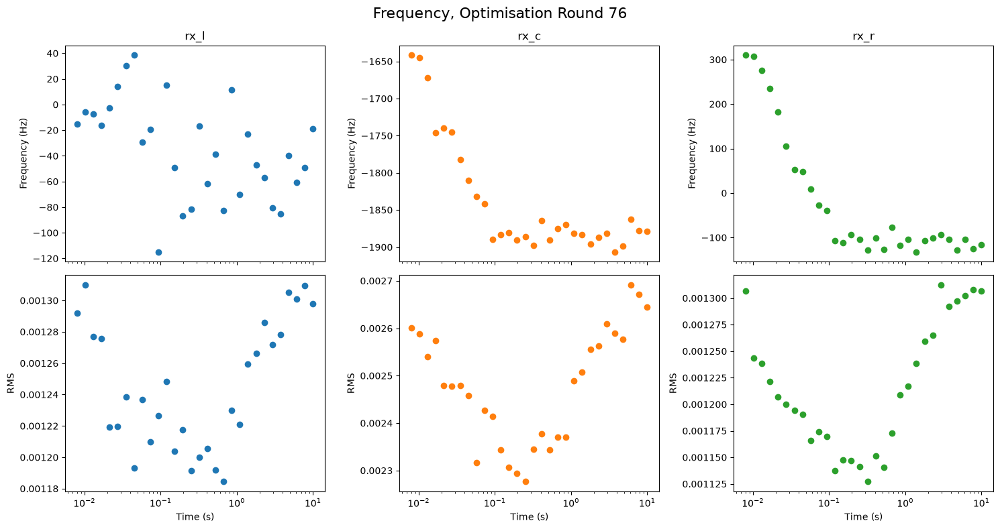

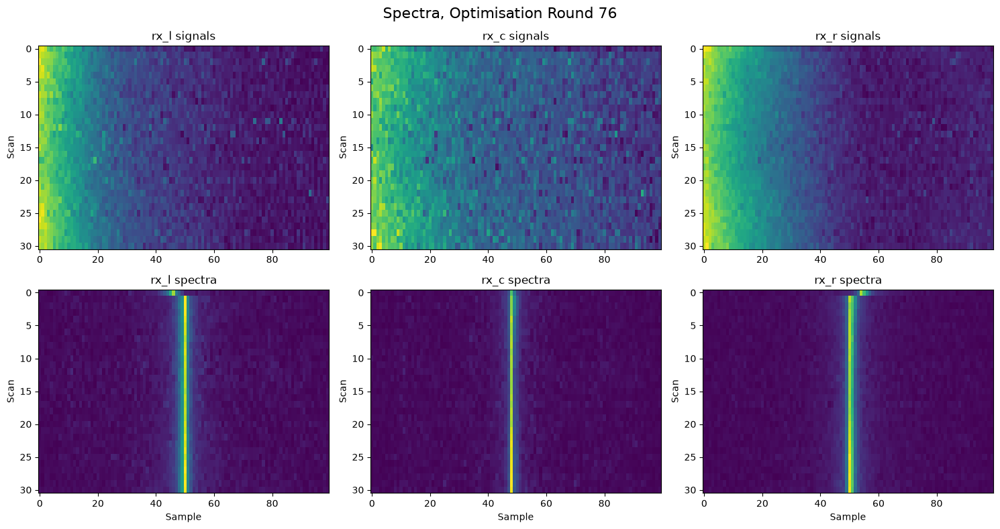

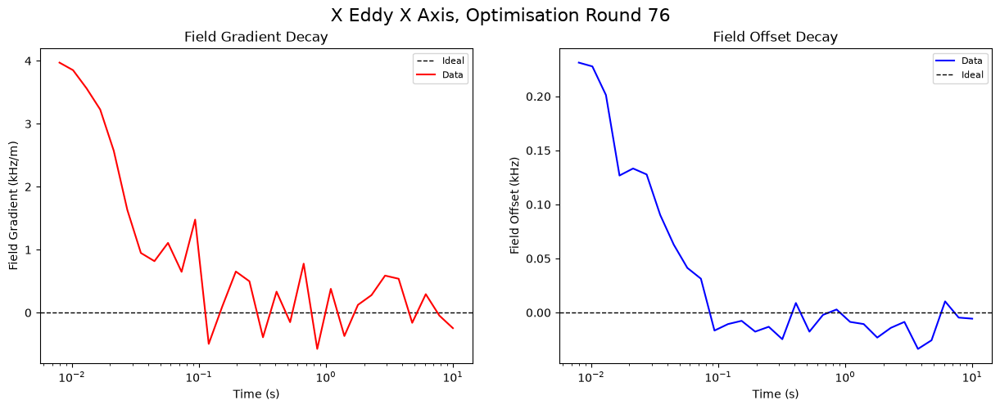

[I 2026-11-26 10:39:31,373] Trial 76 finished with value: 2928.632453997184 and parameters: {'X_A1': 0.1009624280104773, 'X_A2': 0.07154056361194074, 'X_A3': 0.03922799043940022, 'X_A4': -2.2339915865447015e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3248.3758120939524
mean |E| = 924.7043145094118
RMS E = 1289.744281048027
Total cost = 2.929e+03
E max = 0.12311425052861523
E nanmax = 0.12311425052861523
E contains nan = False
B max = 0.019560442166184557
B nanmax = 0.019560442166184557
B contains nan = False
Trial 77


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019560442166184557 !!!!!!!!!!!!!!!!


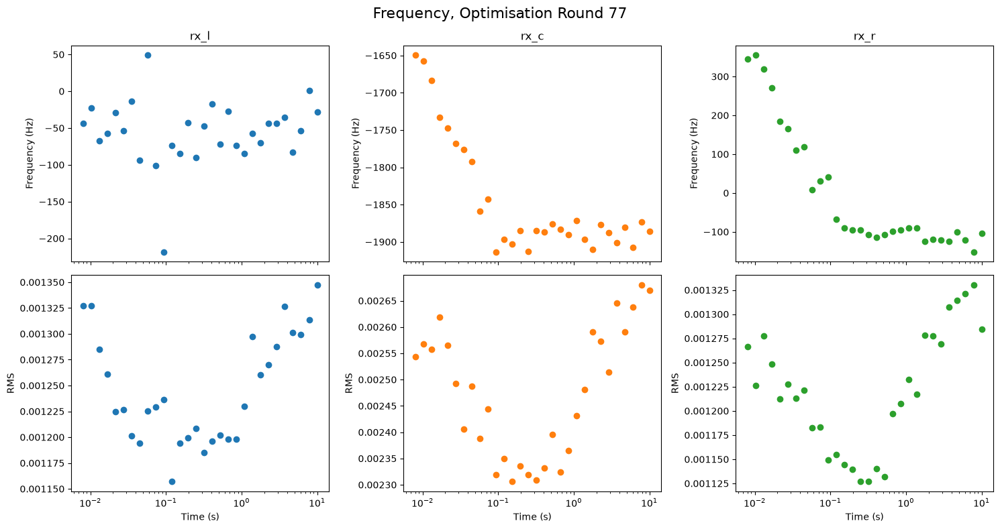

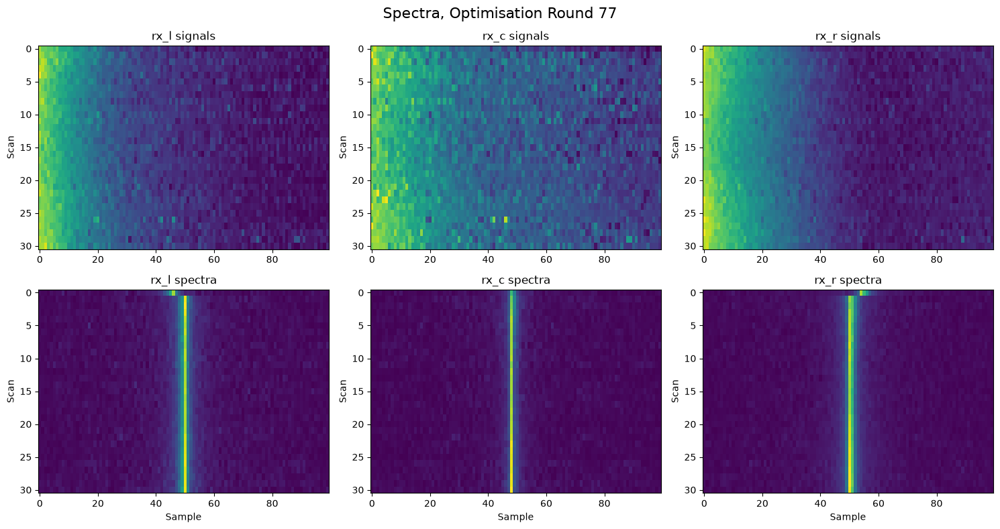

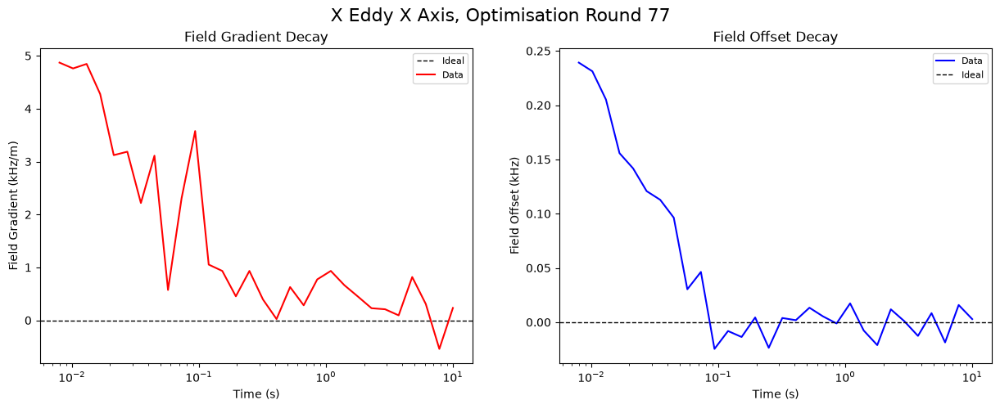

[I 2026-11-26 10:40:54,413] Trial 77 finished with value: 4545.0963877057175 and parameters: {'X_A1': 0.09216841848571254, 'X_A2': 0.06759040601451533, 'X_A3': 0.04426952681787038, 'X_A4': -1.7107426113225783e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3883.0584707646162
mean |E| = 1228.219223721472
RMS E = 1703.6630066055745
Total cost = 4.545e+03
E max = 0.12130502172071707
E nanmax = 0.12130502172071707
E contains nan = False
B max = 0.019273031917039395
B nanmax = 0.019273031917039395
B contains nan = False
Trial 78


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019273031917039395 !!!!!!!!!!!!!!!!


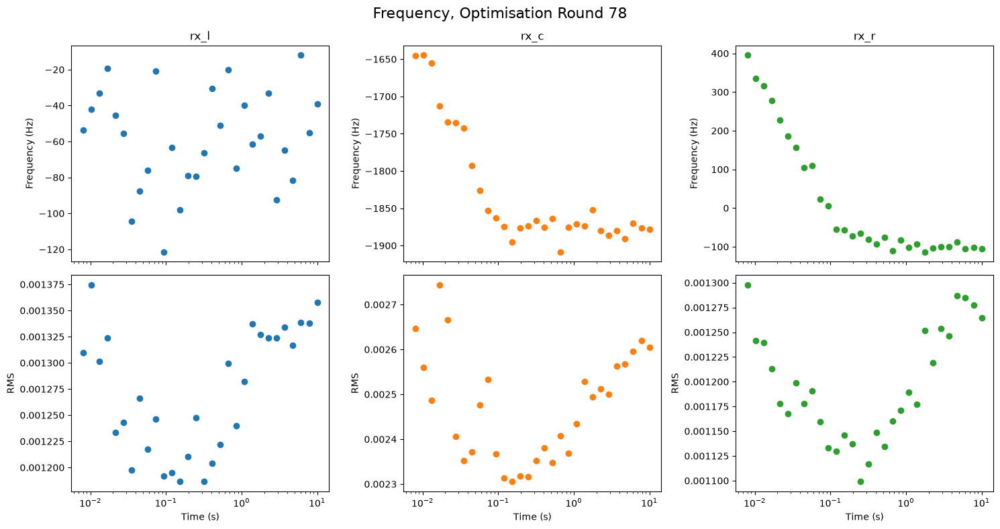

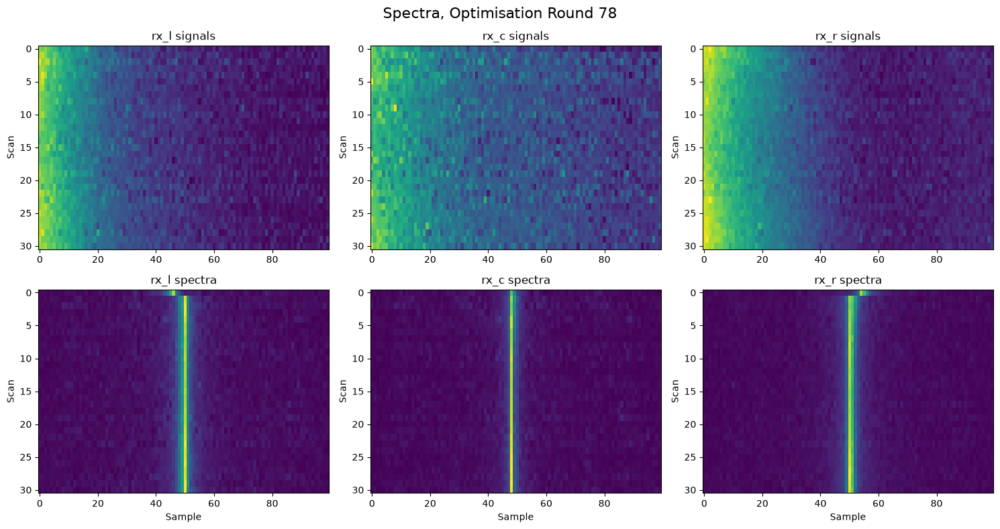

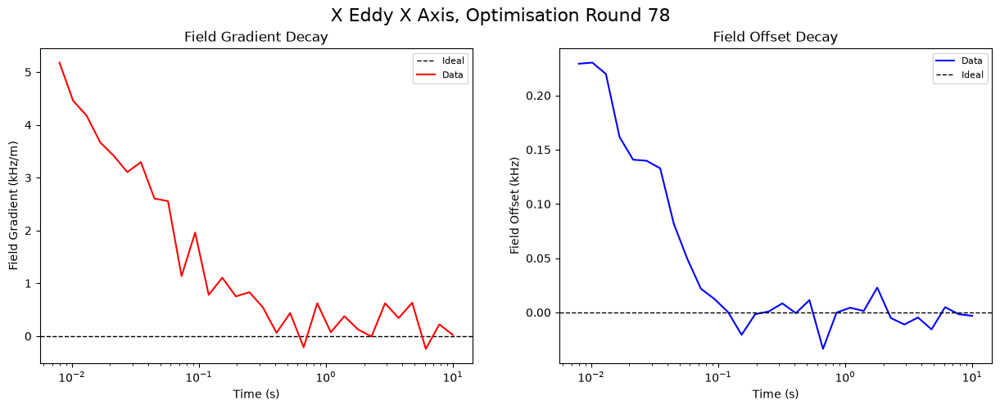

[I 2026-11-26 10:42:14,745] Trial 78 finished with value: 3225.023703376788 and parameters: {'X_A1': 0.08378662996458293, 'X_A2': 0.07372511807676253, 'X_A3': 0.031667727856769884, 'X_A4': -3.6543284551163417e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4487.756121939029
mean |E| = 1180.5763784774276
RMS E = 1720.3663659189685
Total cost = 3.225e+03
E max = 0.12270745097189215
E nanmax = 0.12270745097189215
E contains nan = False
B max = 0.01949583096834527
B nanmax = 0.01949583096834527
B contains nan = False
Trial 79


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01949583096834527 !!!!!!!!!!!!!!!!


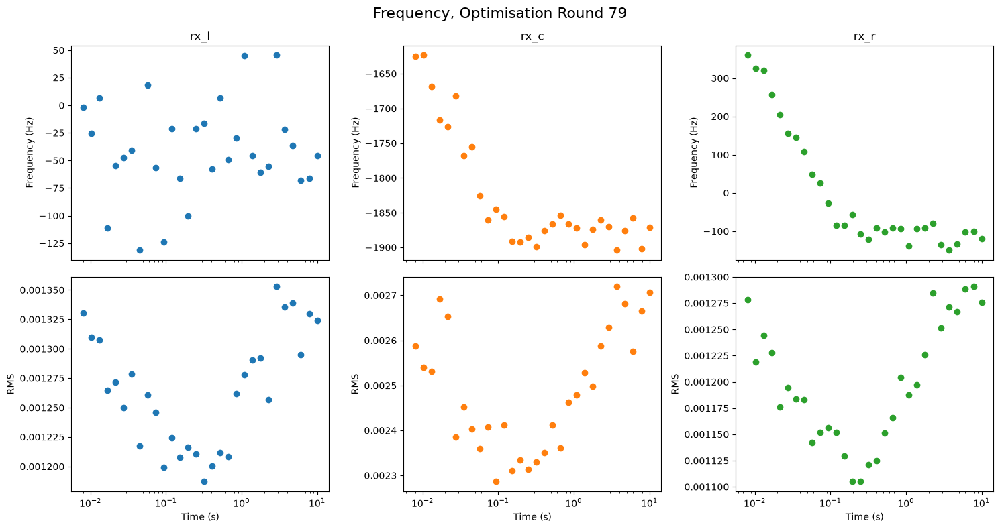

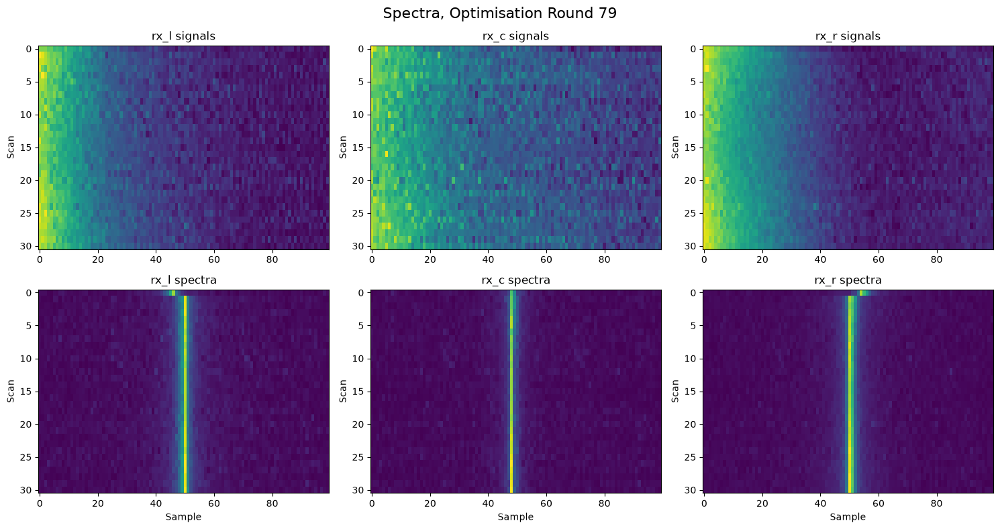

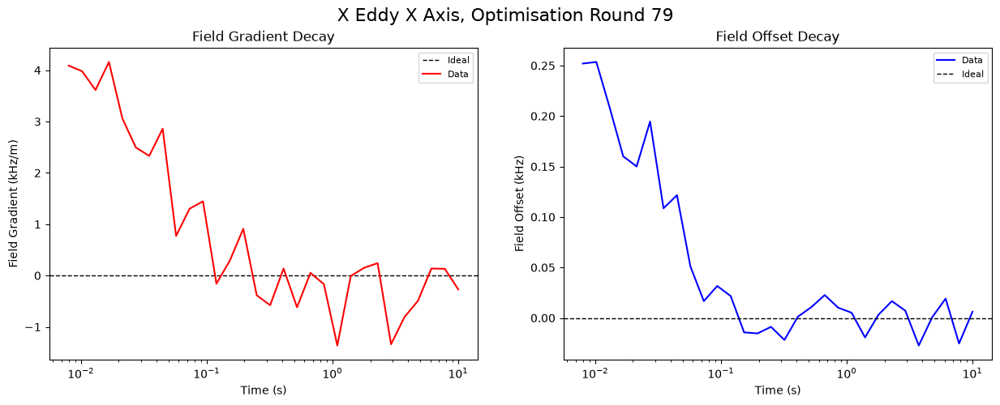

[I 2026-11-26 10:43:02,775] Trial 79 finished with value: 4106.205362299662 and parameters: {'X_A1': 0.09385128959840898, 'X_A2': 0.06848643482336053, 'X_A3': 0.03795752893142564, 'X_A4': 2.6612264299303153e-10}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3688.1559220389795
mean |E| = 1296.351824087956
RMS E = 1685.9528025832299
Total cost = 4.106e+03
E max = 0.12324606300367129
E nanmax = 0.12324606300367129
E contains nan = False
B max = 0.019581400857904142
B nanmax = 0.019581400857904142
B contains nan = False
Trial 80


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019581400857904142 !!!!!!!!!!!!!!!!


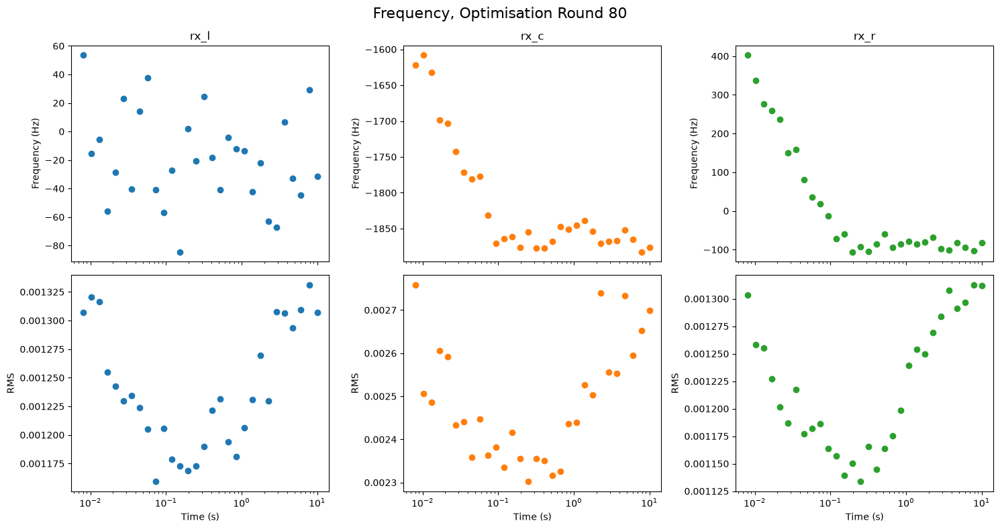

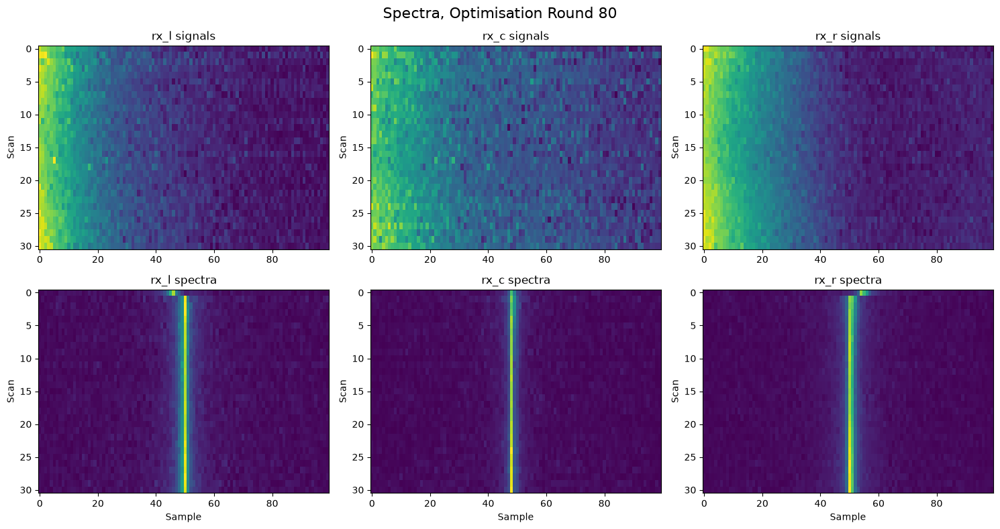

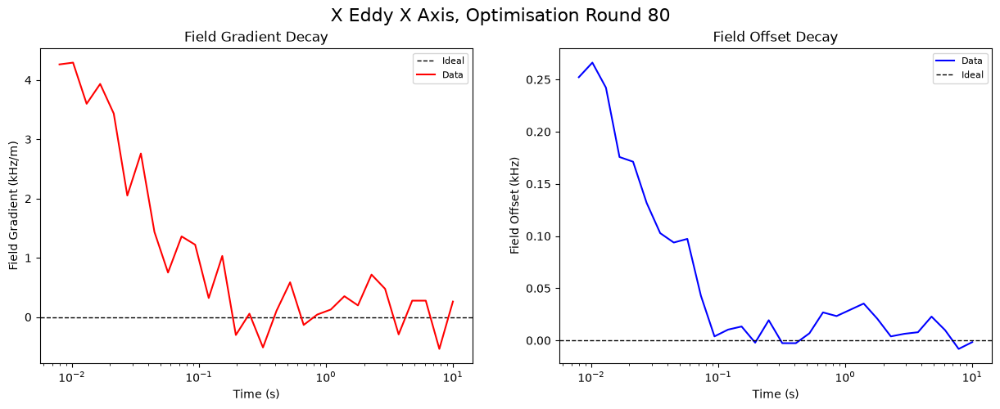

[I 2026-11-26 10:43:50,474] Trial 80 finished with value: 3753.072806134185 and parameters: {'X_A1': 0.09910773272579089, 'X_A2': 0.06556412110681605, 'X_A3': 0.03969099152096717, 'X_A4': -3.2482584443917717e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3518.240879560219
mean |E| = 1094.4527736131931
RMS E = 1485.8796305322533
Total cost = 3.753e+03
E max = 0.12209553105701054
E nanmax = 0.12209553105701054
E contains nan = False
B max = 0.019398621918452475
B nanmax = 0.019398621918452475
B contains nan = False
Trial 81


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019398621918452475 !!!!!!!!!!!!!!!!


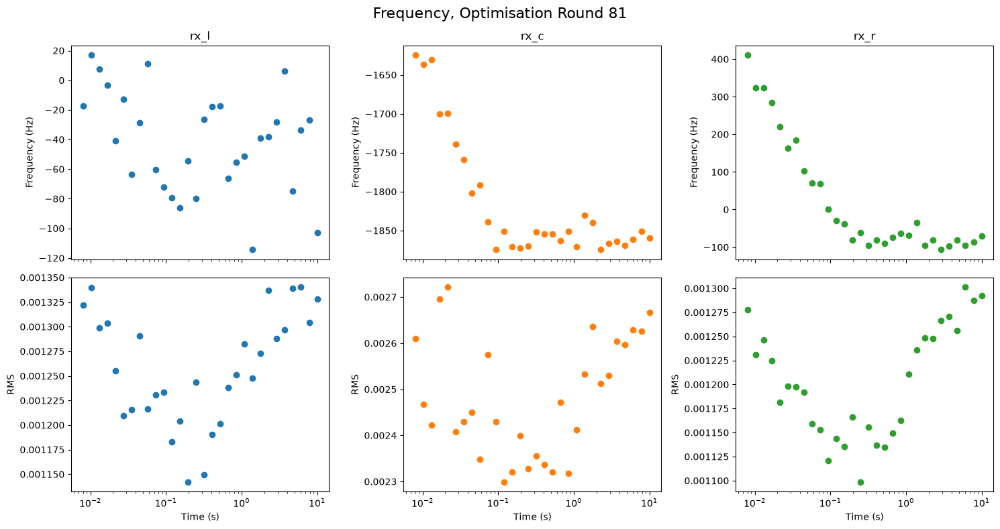

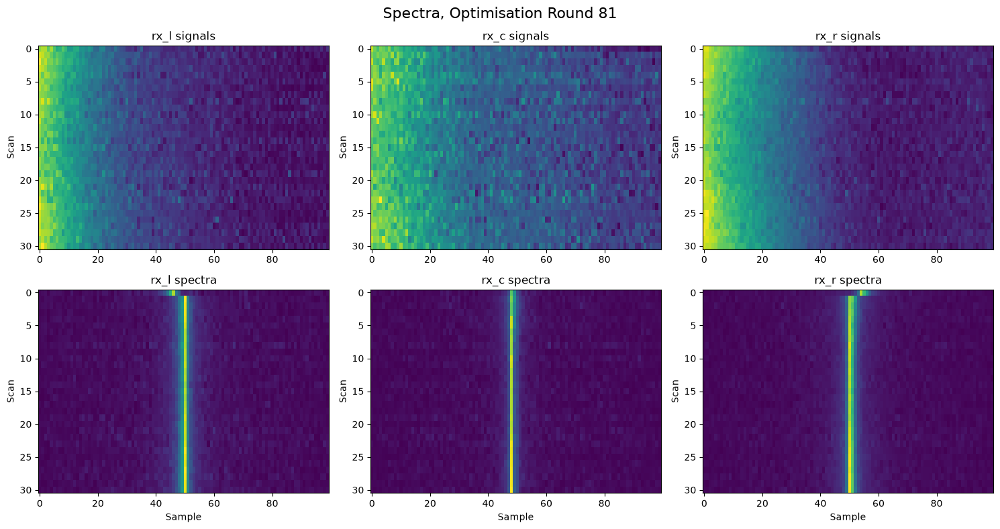

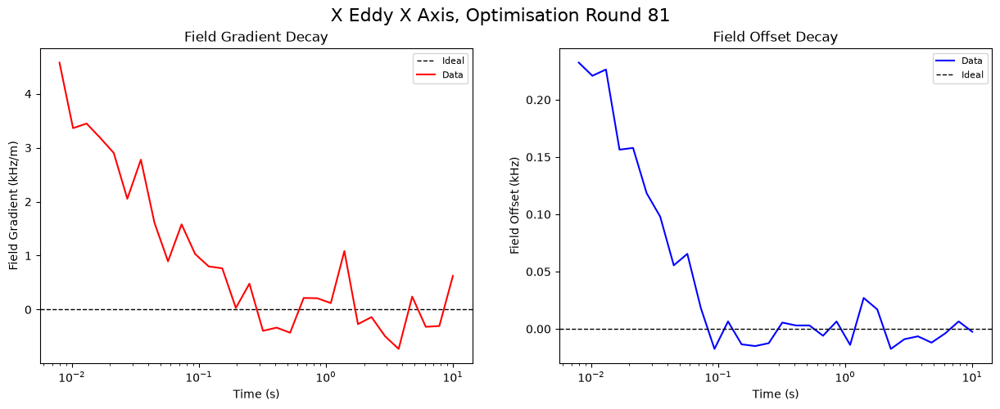

[I 2026-11-26 10:44:38,329] Trial 81 finished with value: 4149.880563343215 and parameters: {'X_A1': 0.08821340718984406, 'X_A2': 0.07360900896474395, 'X_A3': 0.03352689299518886, 'X_A4': -4.3376386949822806e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4282.858570714641
mean |E| = 1106.2801932367145
RMS E = 1549.90796009362
Total cost = 4.150e+03
E max = 0.12223386379767706
E nanmax = 0.12223386379767706
E contains nan = False
B max = 0.019420597397613596
B nanmax = 0.019420597397613596
B contains nan = False
Trial 82


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019420597397613596 !!!!!!!!!!!!!!!!


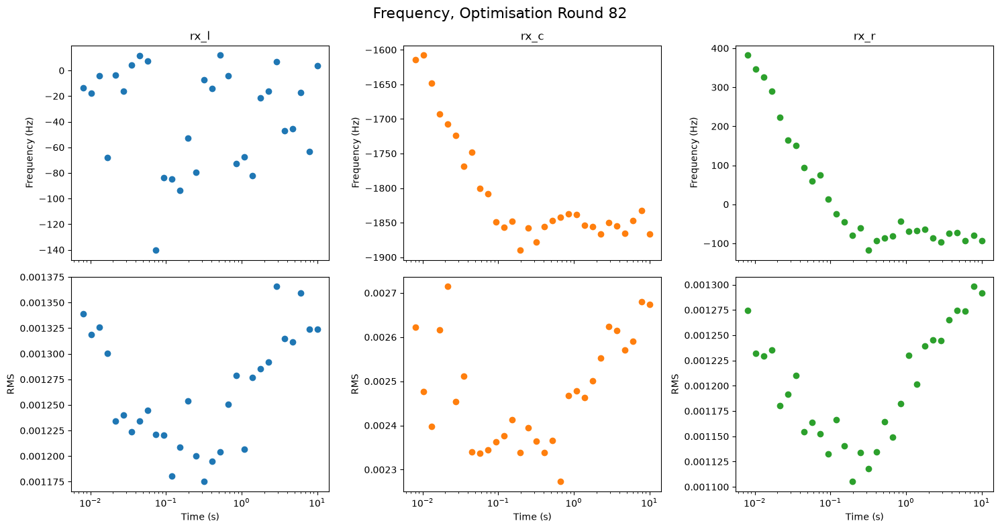

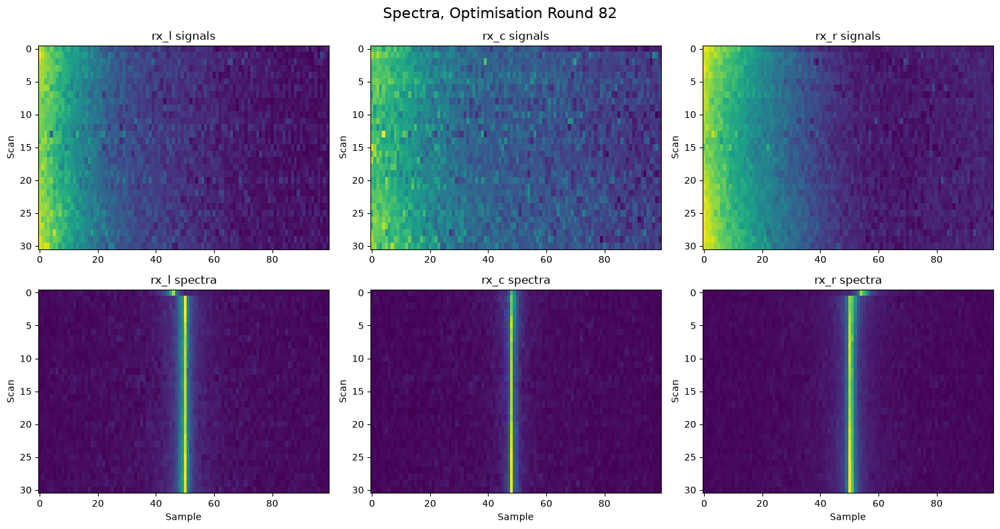

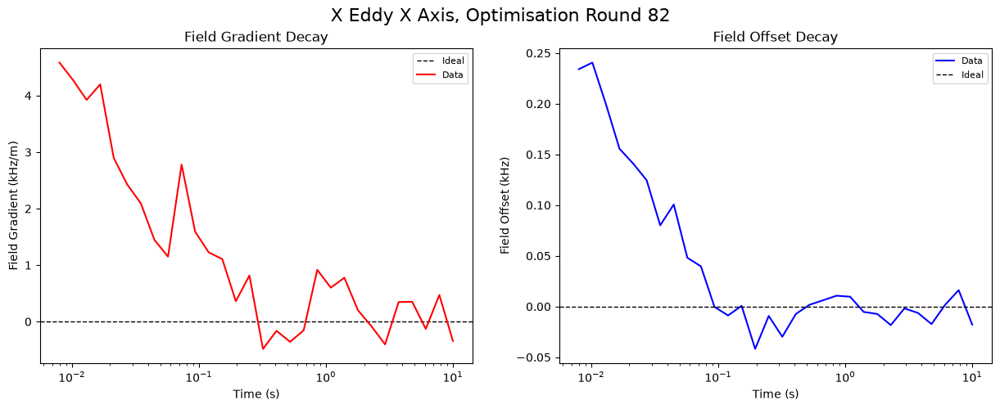

[I 2026-11-26 10:45:25,755] Trial 82 finished with value: 3770.9753684539255 and parameters: {'X_A1': 0.09053450553176617, 'X_A2': 0.07126421372368269, 'X_A3': 0.03466143504833301, 'X_A4': -3.214493143040219e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3958.0209895052462
mean |E| = 1157.7544561052805
RMS E = 1605.5440149597675
Total cost = 3.771e+03
E max = 0.12397073332484164
E nanmax = 0.12397073332484164
E contains nan = False
B max = 0.019696530147814063
B nanmax = 0.019696530147814063
B contains nan = False
Trial 83


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019696530147814063 !!!!!!!!!!!!!!!!


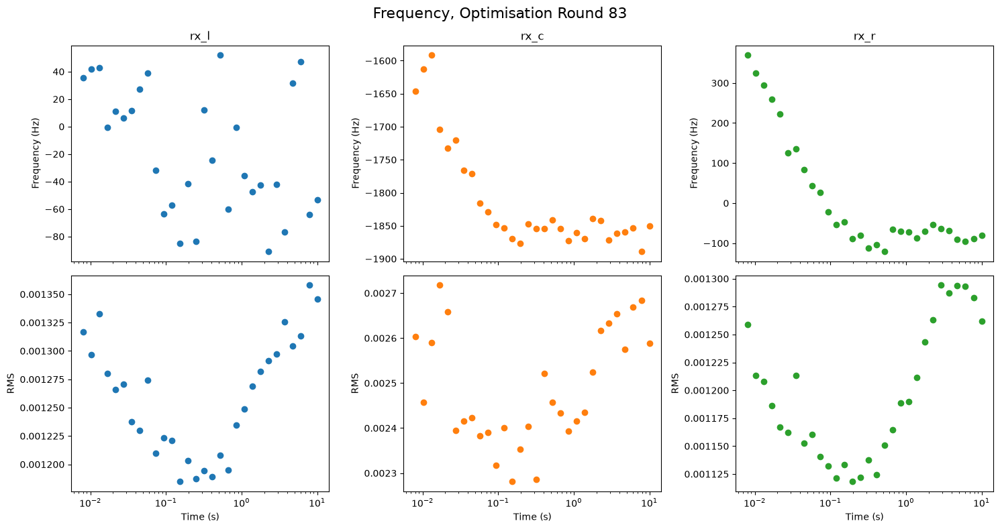

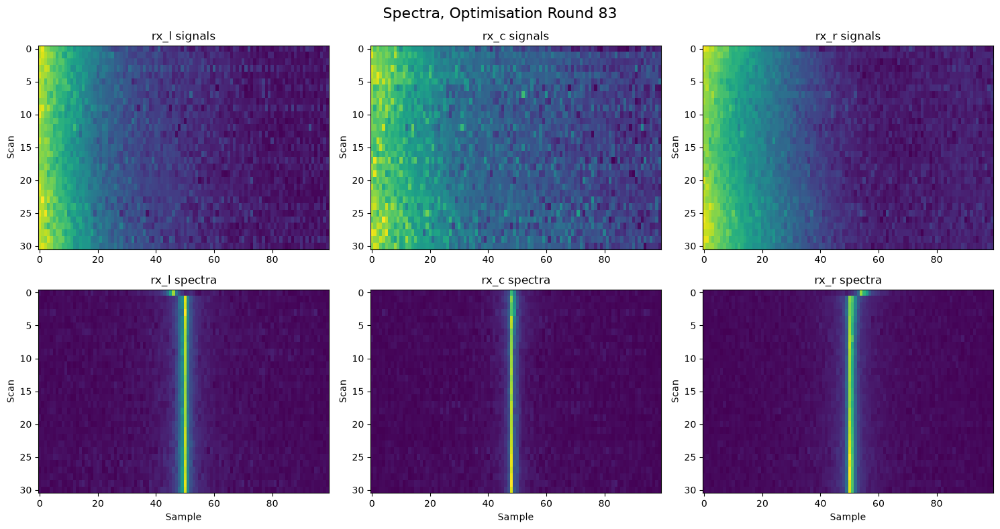

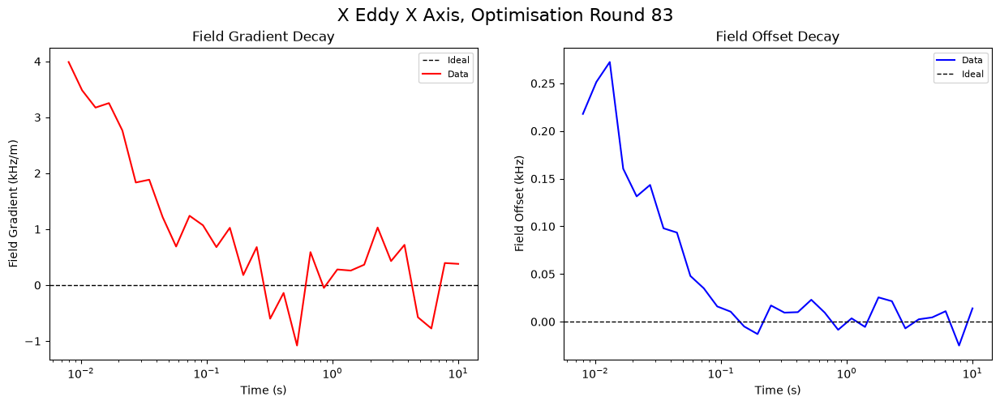

[I 2026-11-26 10:46:13,408] Trial 83 finished with value: 5505.846289359506 and parameters: {'X_A1': 0.0951669137967728, 'X_A2': 0.07449079462983178, 'X_A3': 0.04042933739640263, 'X_A4': -1.3825944668934373e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3338.330834582708
mean |E| = 925.5372313843076
RMS E = 1301.6036535952853
Total cost = 5.506e+03
E max = 0.12404609139745448
E nanmax = 0.12404609139745448
E contains nan = False
B max = 0.019708495765354918
B nanmax = 0.019708495765354918
B contains nan = False
Trial 84


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019708495765354918 !!!!!!!!!!!!!!!!


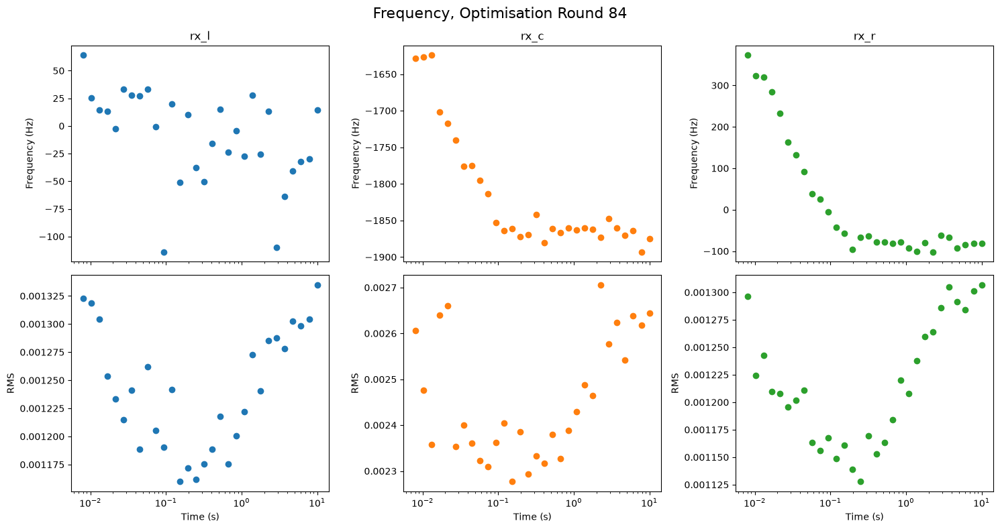

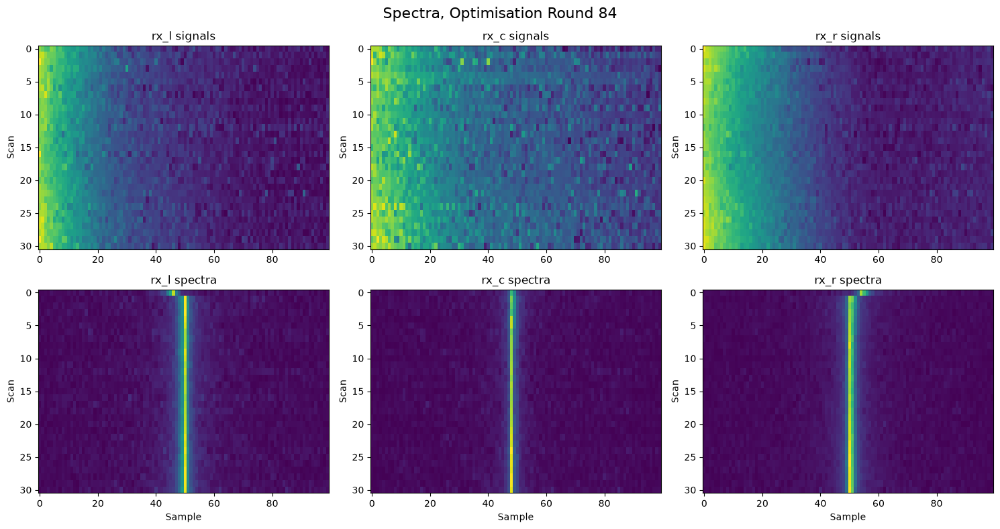

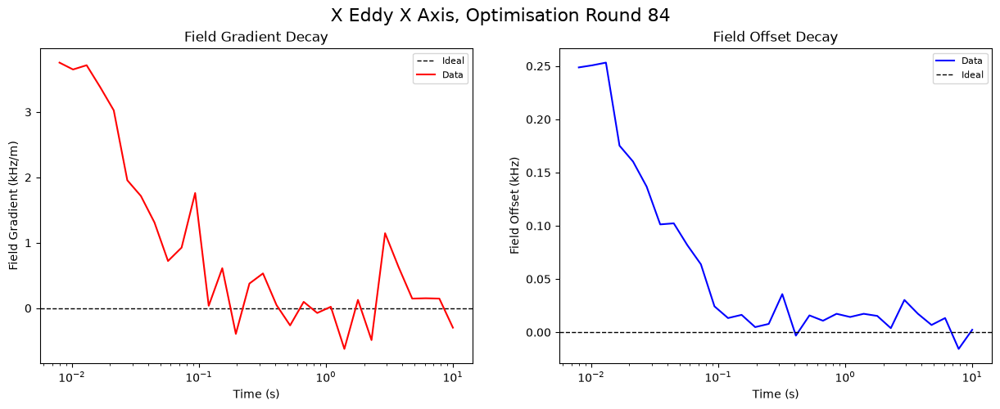

[I 2026-11-26 10:47:03,203] Trial 84 finished with value: 3330.178235279079 and parameters: {'X_A1': 0.09436700877104726, 'X_A2': 0.07389693303217995, 'X_A3': 0.042622141685893136, 'X_A4': -3.025366919973443e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3088.455772113942
mean |E| = 1009.3286689988337
RMS E = 1348.110274052287
Total cost = 3.330e+03
E max = 0.12255711102690584
E nanmax = 0.12255711102690584
E contains nan = False
B max = 0.01947194742699047
B nanmax = 0.01947194742699047
B contains nan = False
Trial 85


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01947194742699047 !!!!!!!!!!!!!!!!


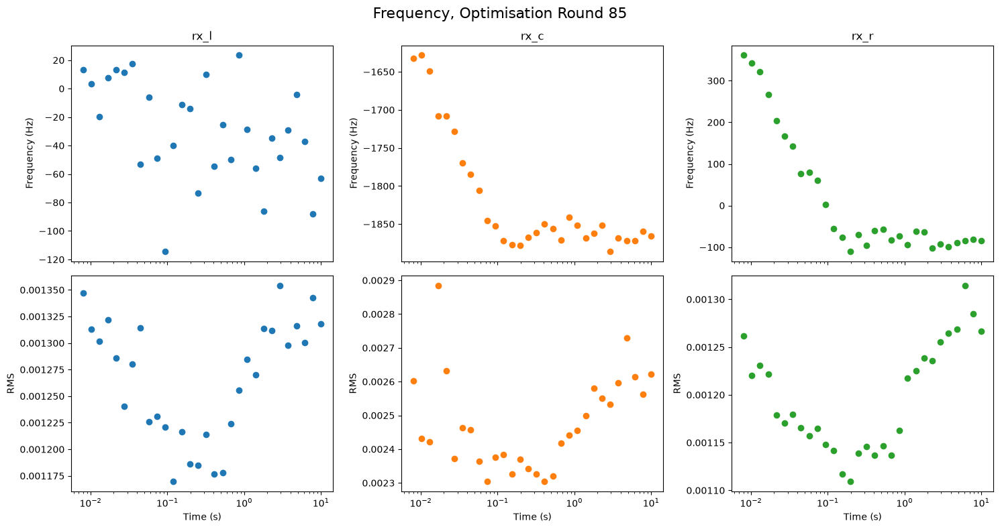

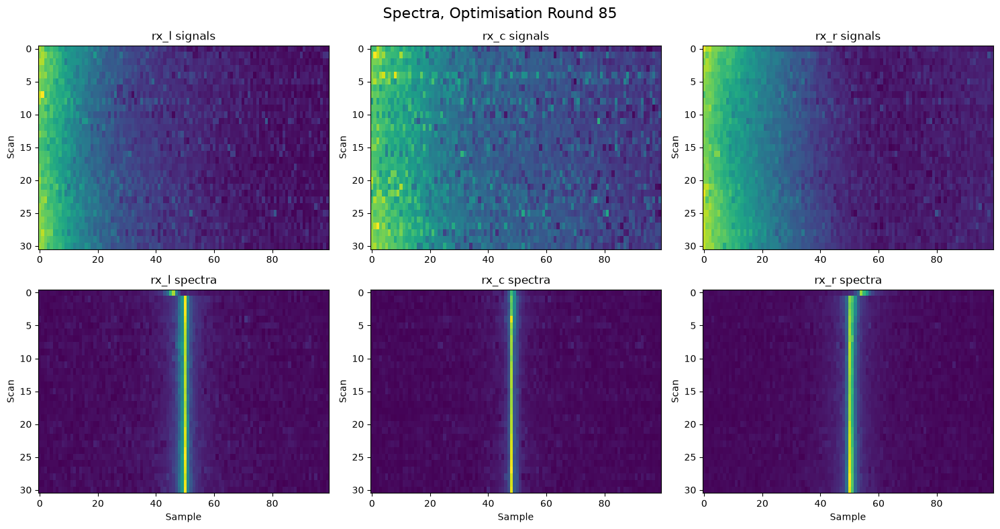

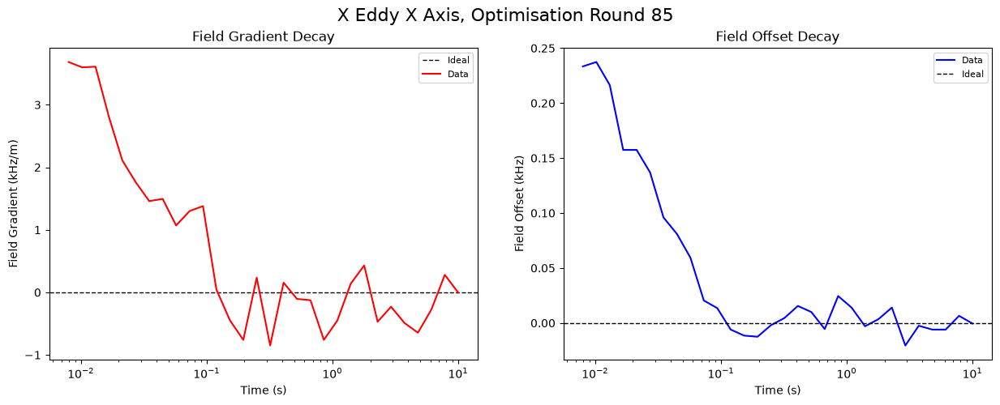

[I 2026-11-26 10:48:27,912] Trial 85 finished with value: 3491.338440791308 and parameters: {'X_A1': 0.09181187743368696, 'X_A2': 0.07030140760647109, 'X_A3': 0.03701111776260752, 'X_A4': -3.891258271069289e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3478.2608695652166
mean |E| = 1029.485257371314
RMS E = 1423.4938795996636
Total cost = 3.491e+03
E max = 0.12349894999479412
E nanmax = 0.12349894999479412
E contains nan = False
B max = 0.019621571605173624
B nanmax = 0.019621571605173624
B contains nan = False
Trial 86


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019621571605173624 !!!!!!!!!!!!!!!!


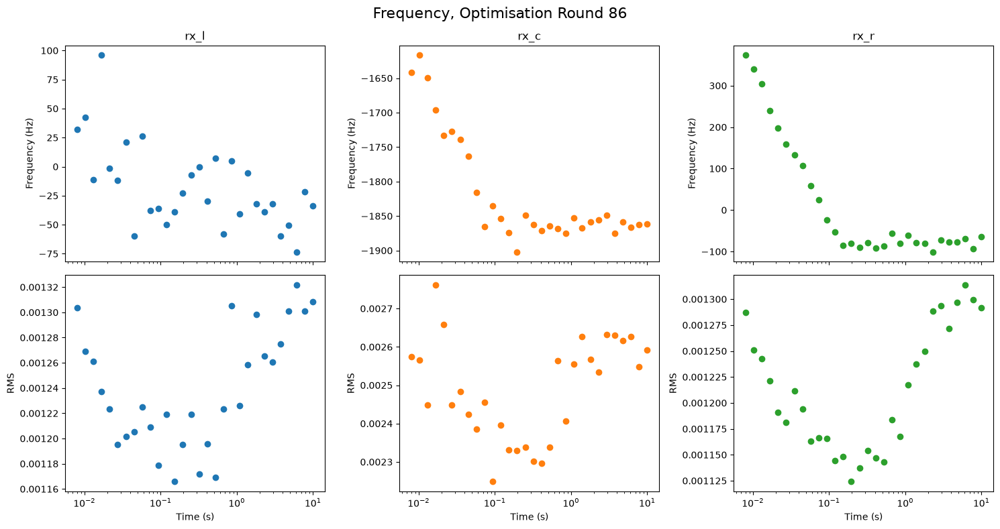

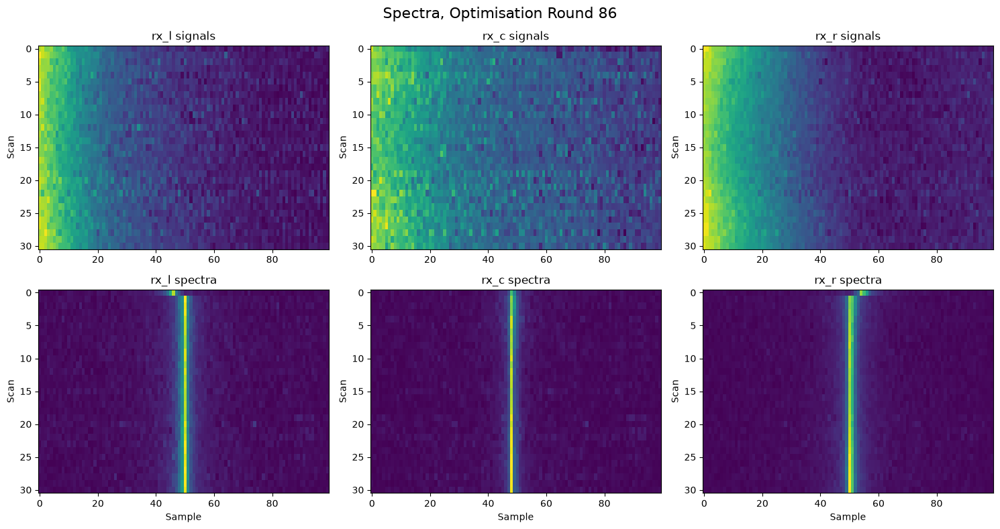

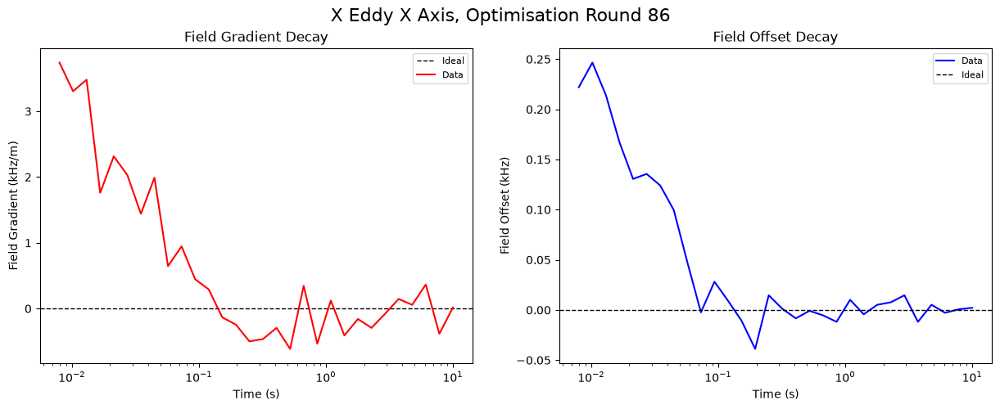

[I 2026-11-26 10:49:52,916] Trial 86 finished with value: 2493.127122703442 and parameters: {'X_A1': 0.09677517870681296, 'X_A2': 0.06808503251726572, 'X_A3': 0.04171081542594026, 'X_A4': -1.4358696773076968e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3413.293353323337
mean |E| = 919.5402298850571
RMS E = 1288.581575123192
Total cost = 2.493e+03
E max = 0.12399323819973092
E nanmax = 0.12399323819973092
E contains nan = False
B max = 0.01970010976864141
B nanmax = 0.01970010976864141
B contains nan = False
Trial 87


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01970010976864141 !!!!!!!!!!!!!!!!


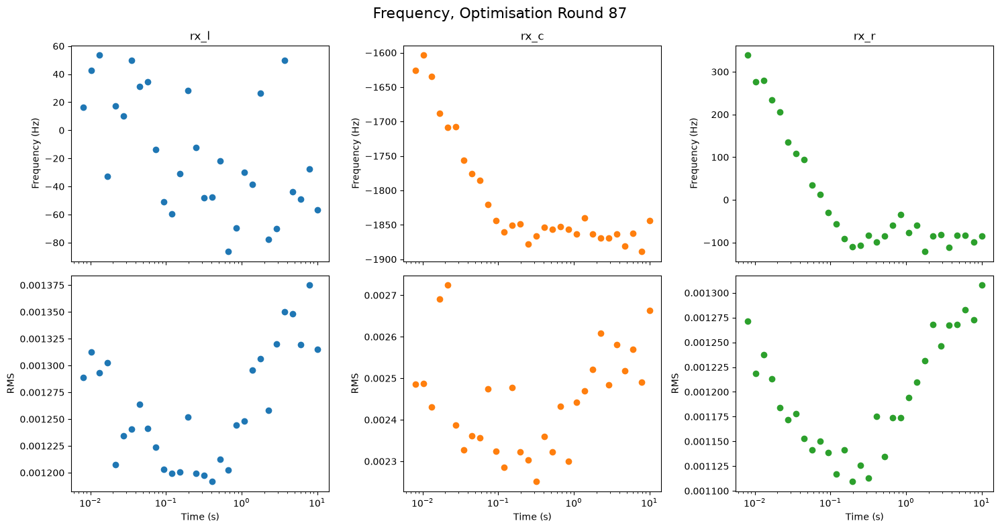

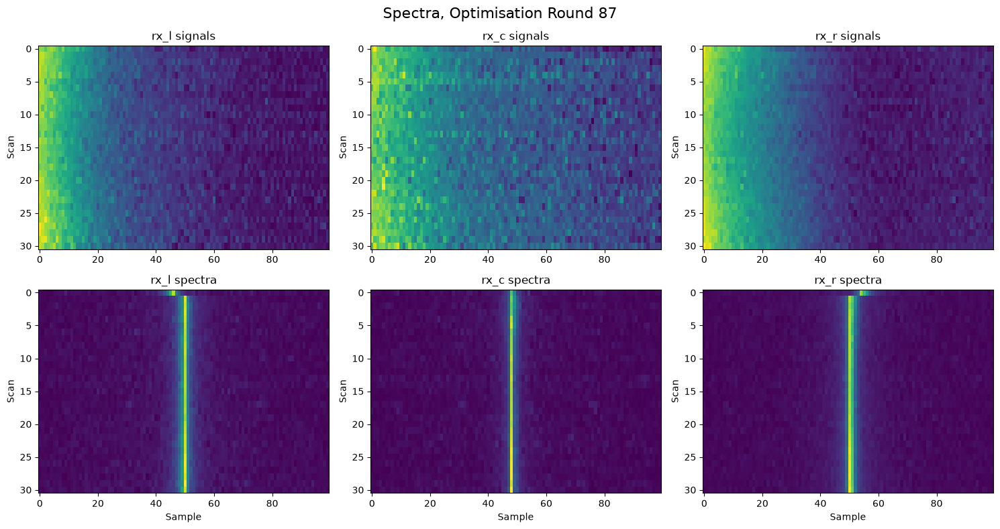

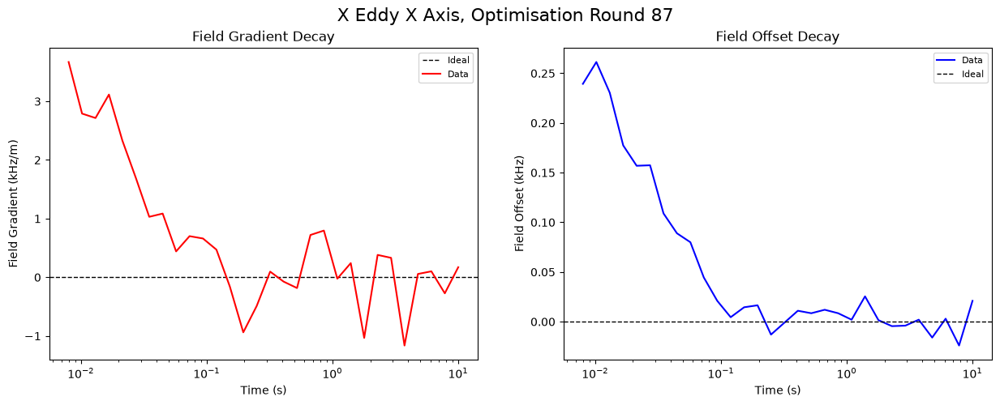

[I 2026-11-26 10:51:13,845] Trial 87 finished with value: 3561.895130457691 and parameters: {'X_A1': 0.09781895468054108, 'X_A2': 0.0728141806827646, 'X_A3': 0.03944131624032211, 'X_A4': -4.073744204213377e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3223.3883058470756
mean |E| = 869.3986340163249
RMS E = 1213.6875329533254
Total cost = 3.562e+03
E max = 0.12481996238532923
E nanmax = 0.12481996238532923
E contains nan = False
B max = 0.01983145130322979
B nanmax = 0.01983145130322979
B contains nan = False
Trial 88


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01983145130322979 !!!!!!!!!!!!!!!!


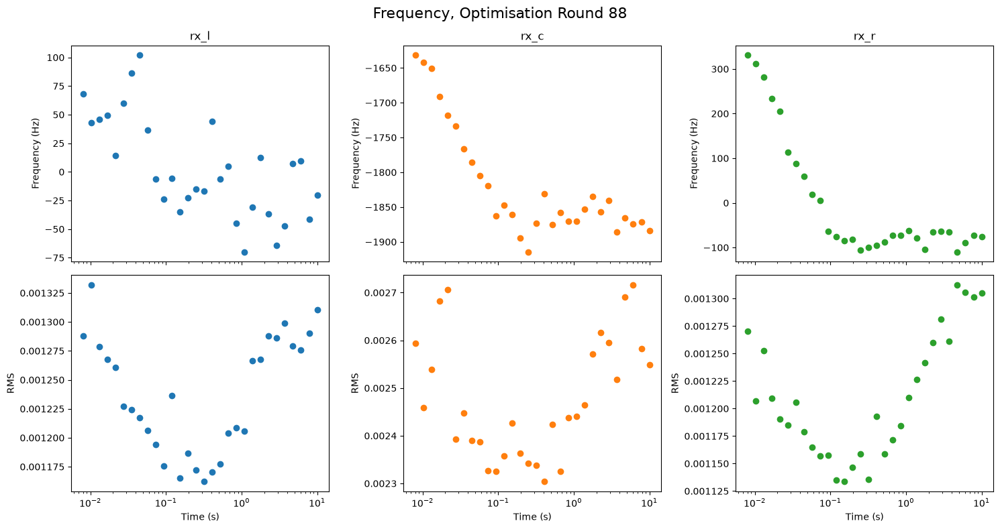

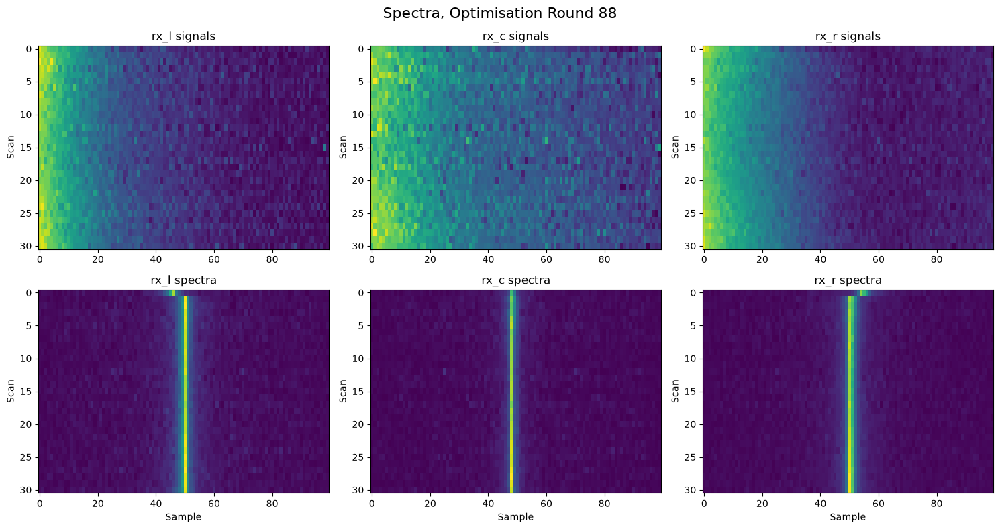

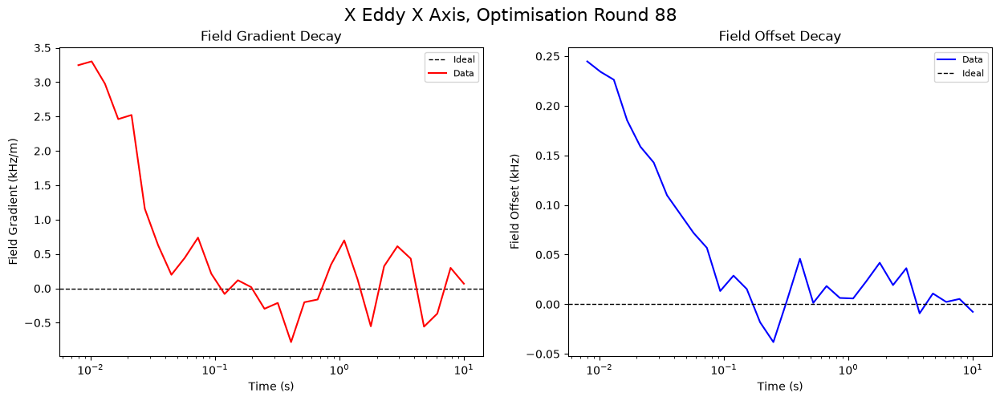

[I 2026-11-26 10:52:01,909] Trial 88 finished with value: 3716.9803478678923 and parameters: {'X_A1': 0.10300606250301118, 'X_A2': 0.0713261084219212, 'X_A3': 0.042001518176184485, 'X_A4': -3.1062712605938058e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 2683.658170914542
mean |E| = 838.4141262701979
RMS E = 1122.470746955313
Total cost = 3.717e+03
E max = 0.12215064239288949
E nanmax = 0.12215064239288949
E contains nan = False
B max = 0.019407381306209125
B nanmax = 0.019407381306209125
B contains nan = False
Trial 89


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019407381306209125 !!!!!!!!!!!!!!!!


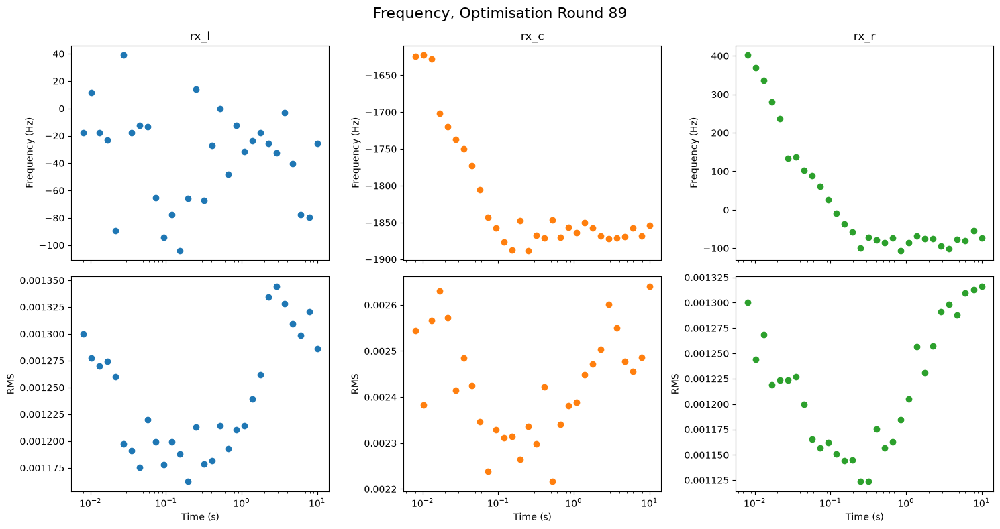

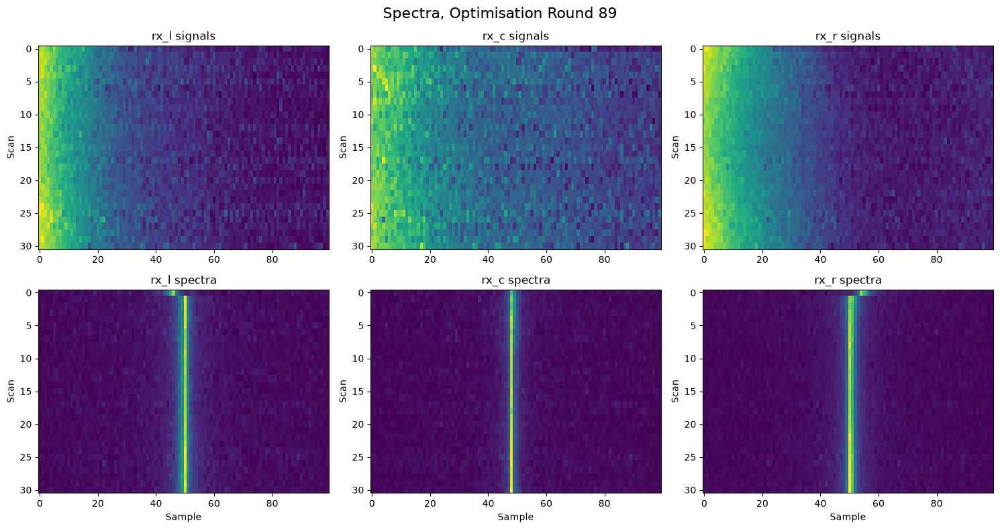

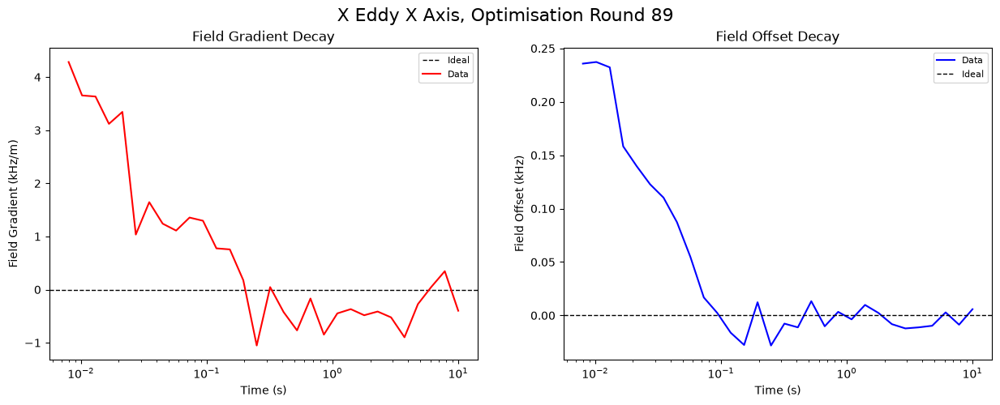

[I 2026-11-26 10:52:49,657] Trial 89 finished with value: 4065.3154764067376 and parameters: {'X_A1': 0.08792785500983268, 'X_A2': 0.07542060650626936, 'X_A3': 0.03230487151171846, 'X_A4': -2.268237585046991e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4197.901049475261
mean |E| = 1158.2542062302177
RMS E = 1618.1697599478387
Total cost = 4.065e+03
E max = 0.12318883316973907
E nanmax = 0.12318883316973907
E contains nan = False
B max = 0.01957230426997303
B nanmax = 0.01957230426997303
B contains nan = False
Trial 90


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01957230426997303 !!!!!!!!!!!!!!!!


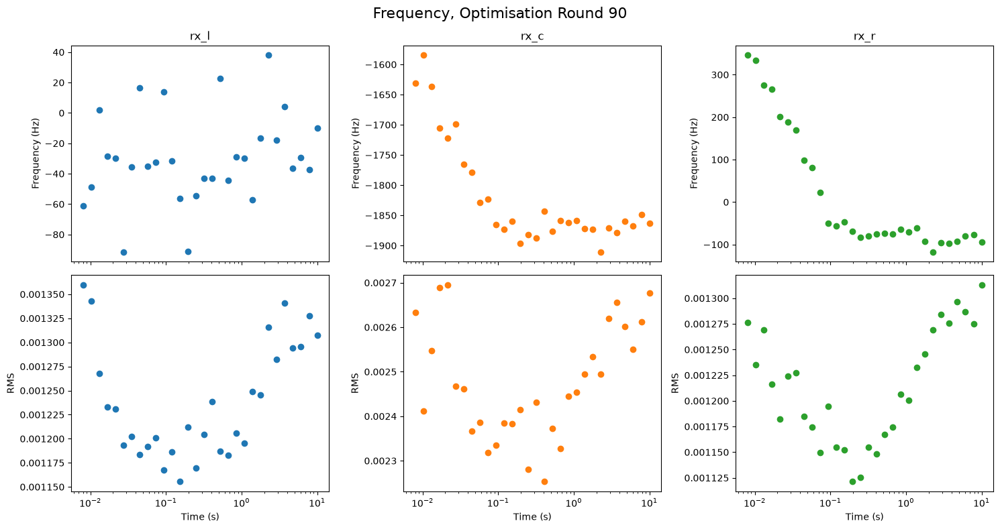

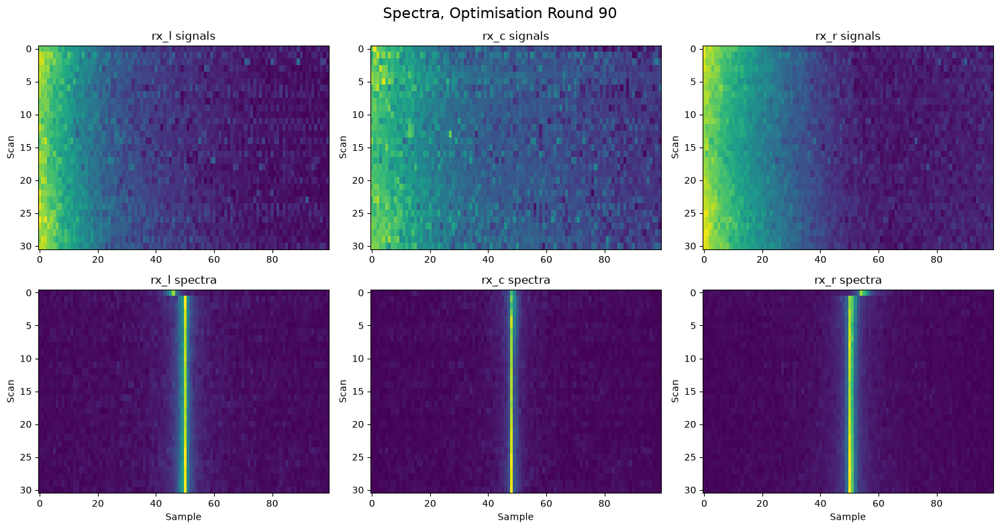

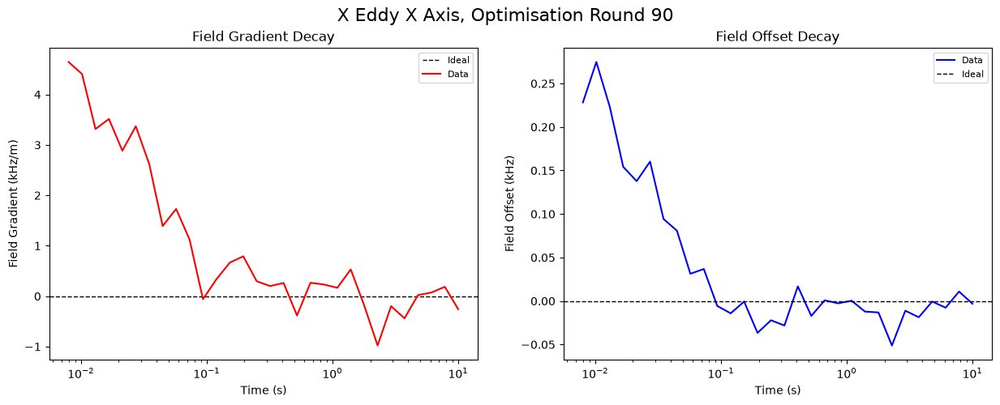

[I 2026-11-26 10:53:37,682] Trial 90 finished with value: 2638.5749506462876 and parameters: {'X_A1': 0.09342820230036894, 'X_A2': 0.07050958651059688, 'X_A3': 0.04026272573531075, 'X_A4': -1.6966869434164702e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4067.9660169915032
mean |E| = 1128.102615358987
RMS E = 1582.4017753473772
Total cost = 2.639e+03
E max = 0.12348381475715263
E nanmax = 0.12348381475715263
E contains nan = False
B max = 0.019619164626446244
B nanmax = 0.019619164626446244
B contains nan = False
Trial 91


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019619164626446244 !!!!!!!!!!!!!!!!


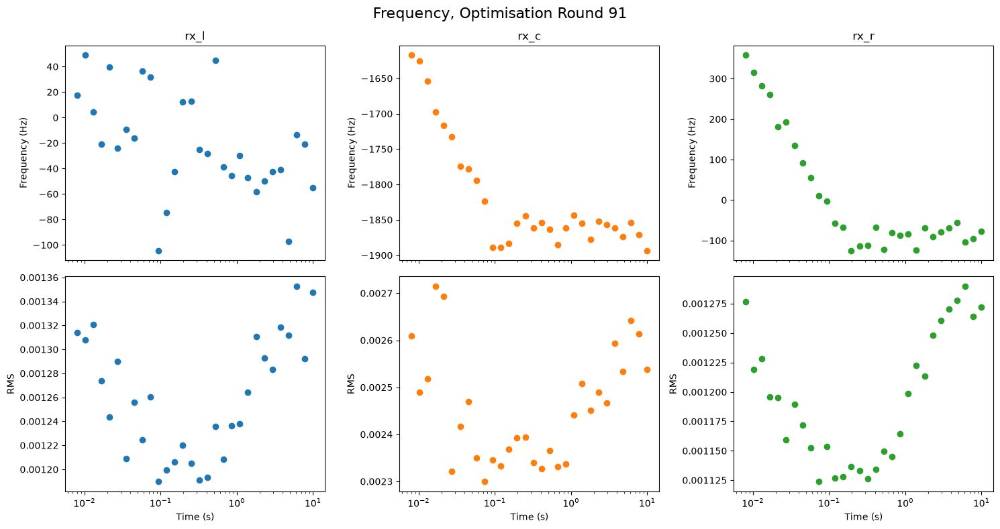

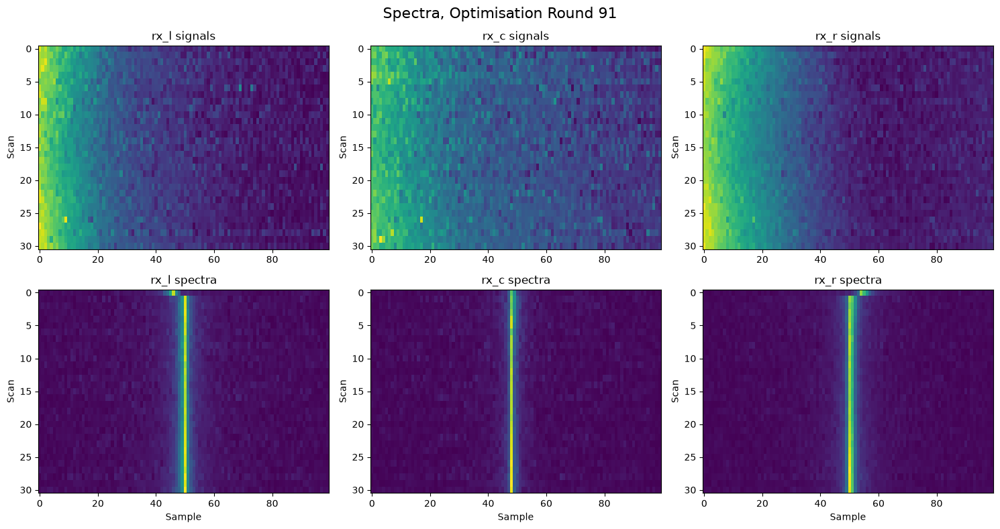

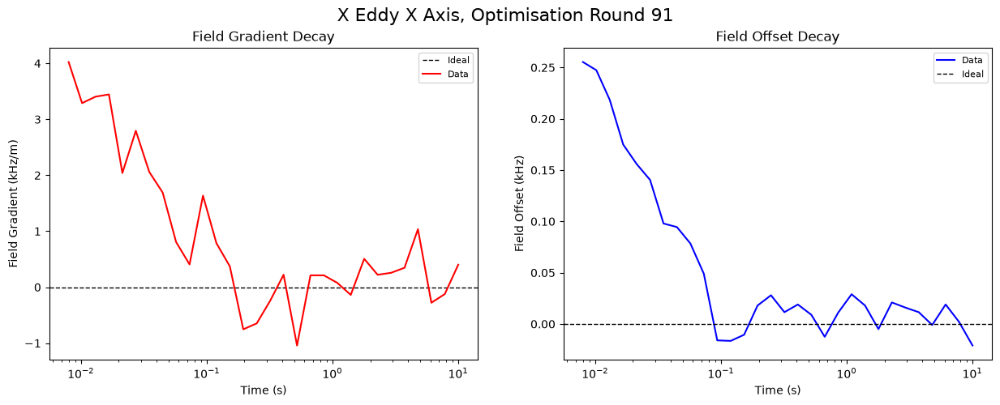

[I 2026-11-26 10:54:25,212] Trial 91 finished with value: 3791.4420051303823 and parameters: {'X_A1': 0.0958541842279821, 'X_A2': 0.06833909441175105, 'X_A3': 0.04235509689297147, 'X_A4': -3.5793656130925594e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3403.2983508245866
mean |E| = 1024.654339496918
RMS E = 1365.433737415723
Total cost = 3.791e+03
E max = 0.12218981741726238
E nanmax = 0.12218981741726238
E contains nan = False
B max = 0.019413608216824873
B nanmax = 0.019413608216824873
B contains nan = False
Trial 92


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019413608216824873 !!!!!!!!!!!!!!!!


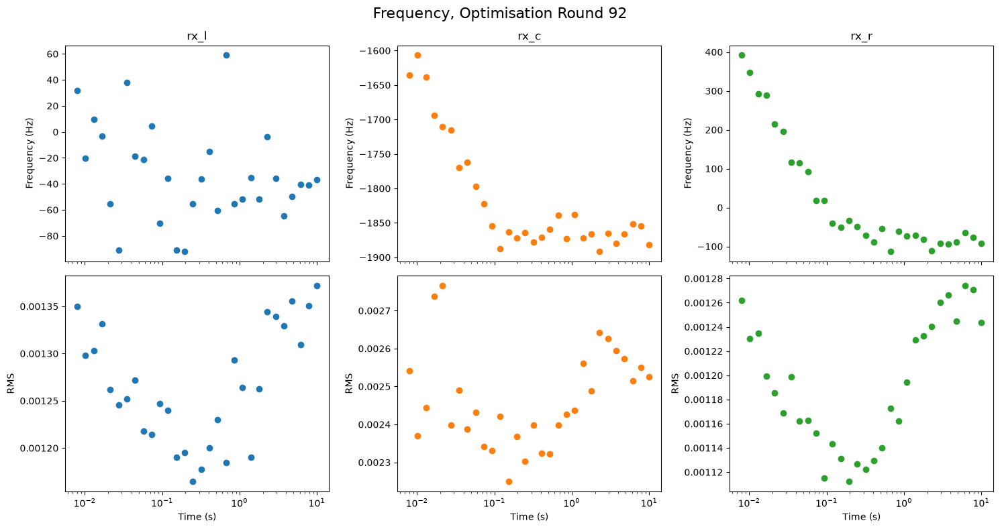

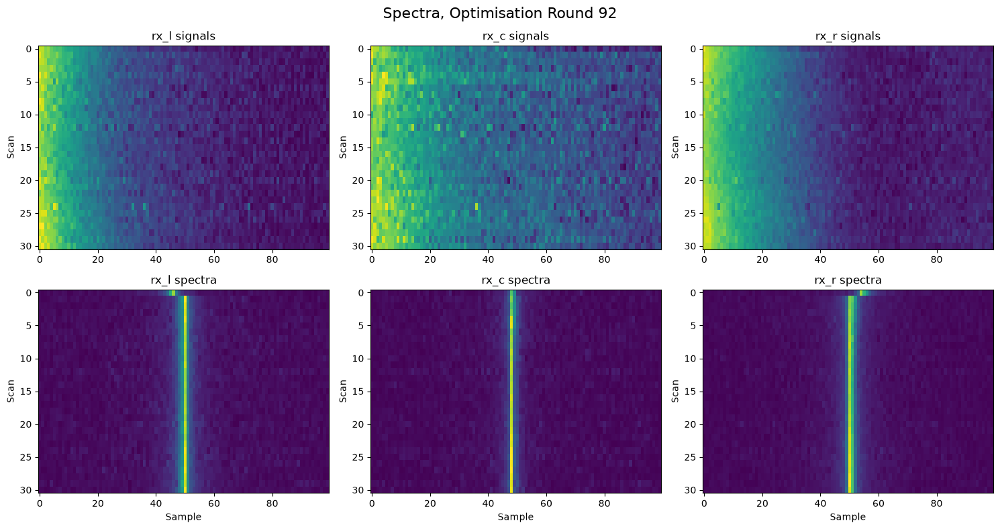

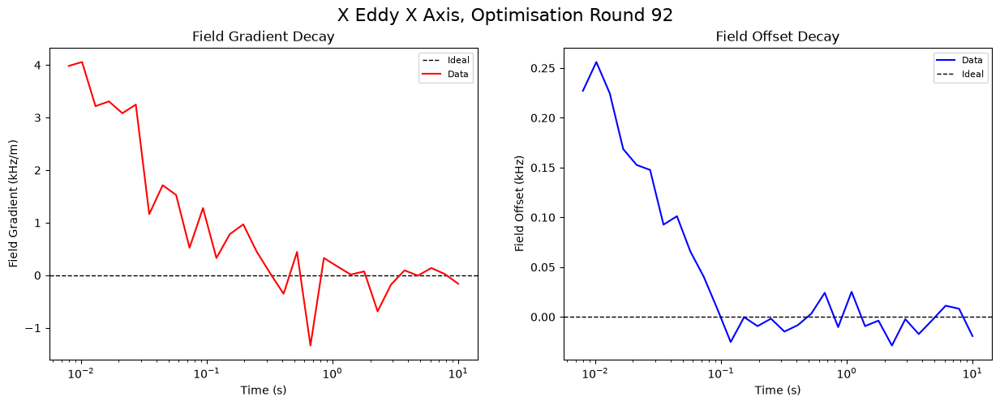

[I 2026-11-26 10:55:12,899] Trial 92 finished with value: 1796.7196392765022 and parameters: {'X_A1': 0.08843052929147686, 'X_A2': 0.07603027759809068, 'X_A3': 0.031385443615945044, 'X_A4': -4.7003083078864696e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3673.1634182908538
mean |E| = 1041.6458437447939
RMS E = 1523.0492138598474
Total cost = 1.797e+03
E max = 0.12137391893595233
E nanmax = 0.12137391893595233
E contains nan = False
B max = 0.01928398491187127
B nanmax = 0.01928398491187127
B contains nan = False
Trial 93


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01928398491187127 !!!!!!!!!!!!!!!!


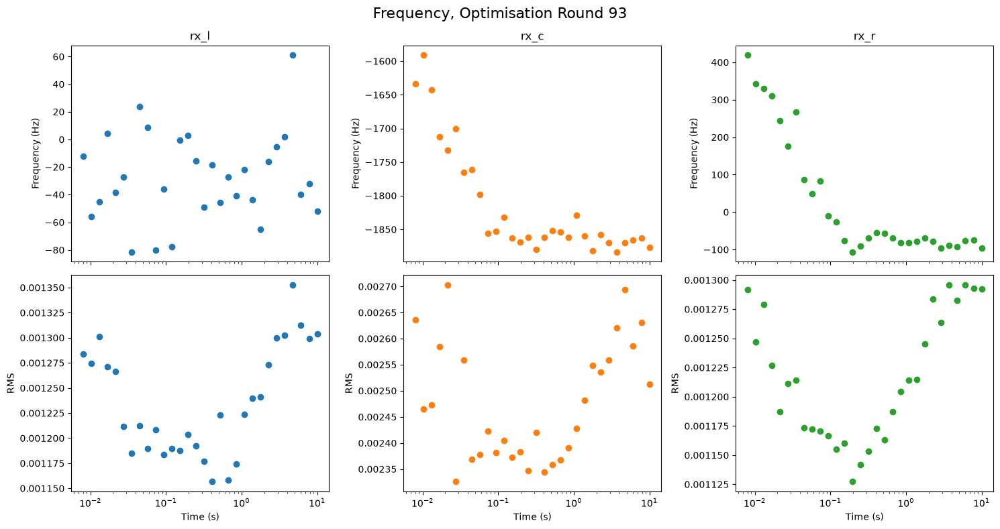

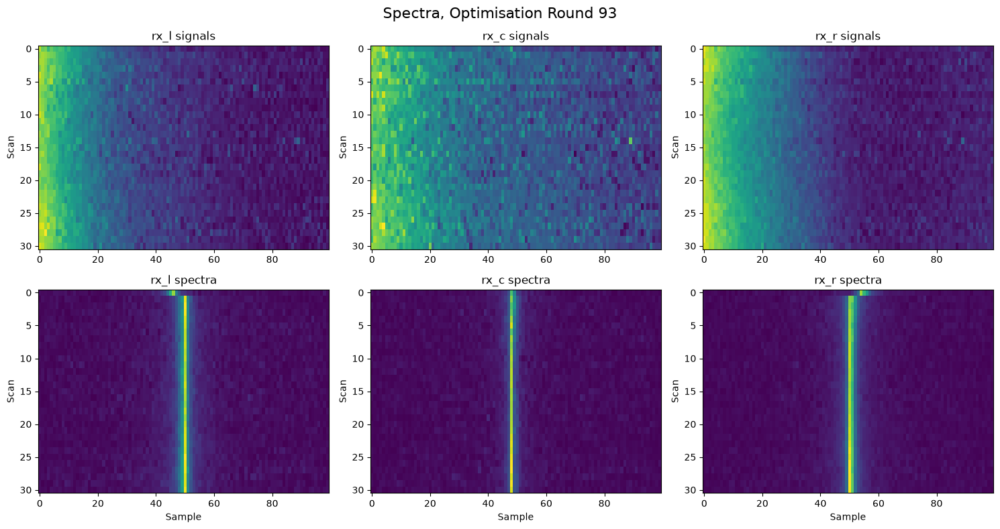

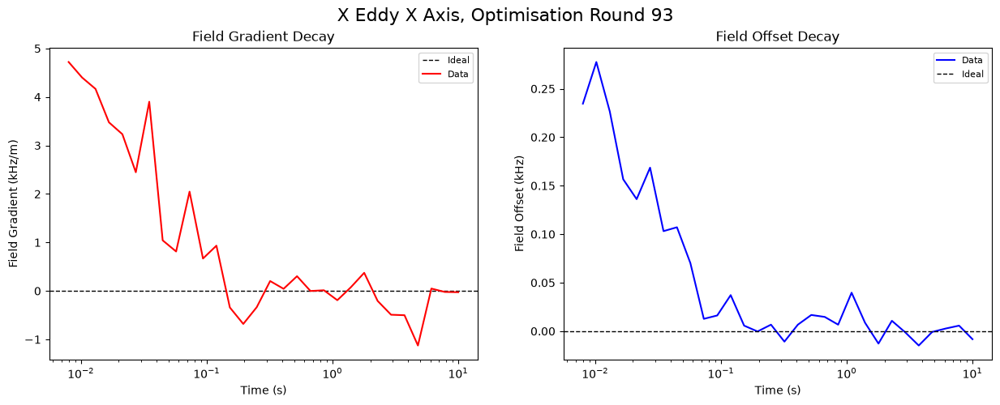

[I 2026-11-26 10:56:00,716] Trial 93 finished with value: 3011.0854020769043 and parameters: {'X_A1': 0.08755123157364332, 'X_A2': 0.0720367758890759, 'X_A3': 0.02985504704204668, 'X_A4': -4.2199824827619904e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4307.8460769615185
mean |E| = 1239.8800599700146
RMS E = 1770.160985160898
Total cost = 3.011e+03
E max = 0.1215678013321319
E nanmax = 0.1215678013321319
E contains nan = False
B max = 0.01931478163947519
B nanmax = 0.01931478163947519
B contains nan = False
Trial 94


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01931478163947519 !!!!!!!!!!!!!!!!


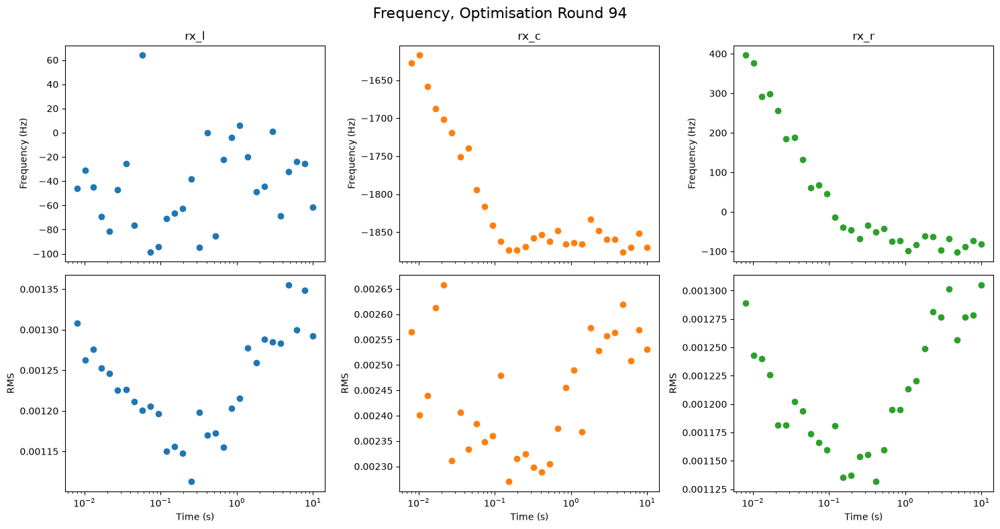

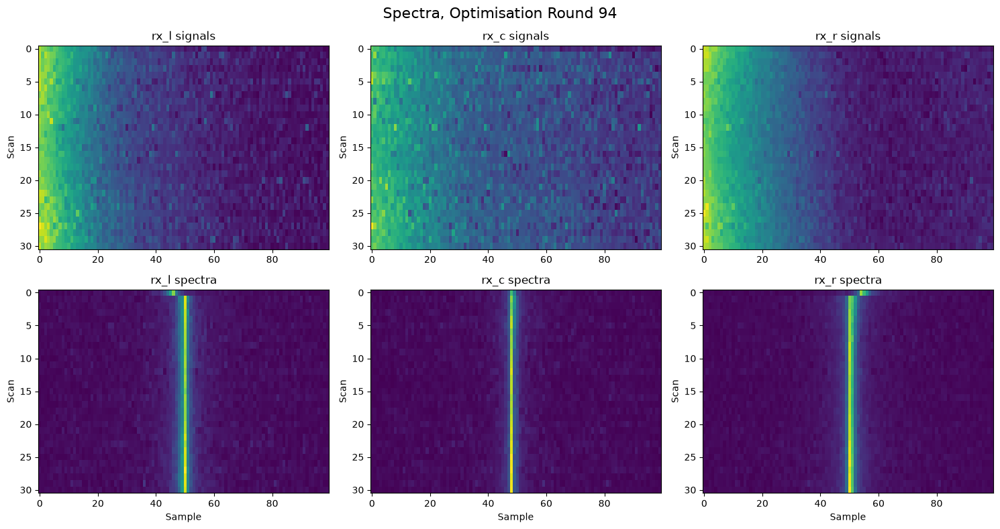

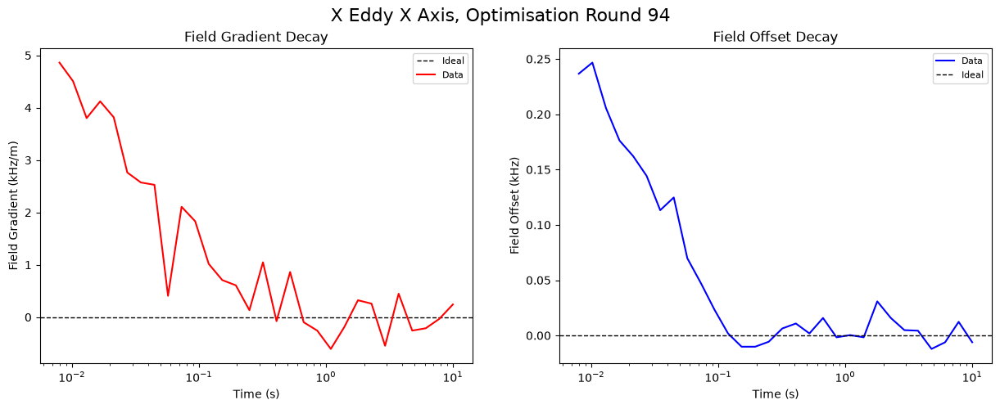

[I 2026-11-26 10:56:49,178] Trial 94 finished with value: 2876.59795379303 and parameters: {'X_A1': 0.08379467413784418, 'X_A2': 0.075776786333101, 'X_A3': 0.031625753829762314, 'X_A4': -2.0483633804841868e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4422.78860569715
mean |E| = 1254.2062302182242
RMS E = 1800.2256924951407
Total cost = 2.877e+03
E max = 0.12146262078689643
E nanmax = 0.12146262078689643
E contains nan = False
B max = 0.019298075363822217
B nanmax = 0.019298075363822217
B contains nan = False
Trial 95


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019298075363822217 !!!!!!!!!!!!!!!!


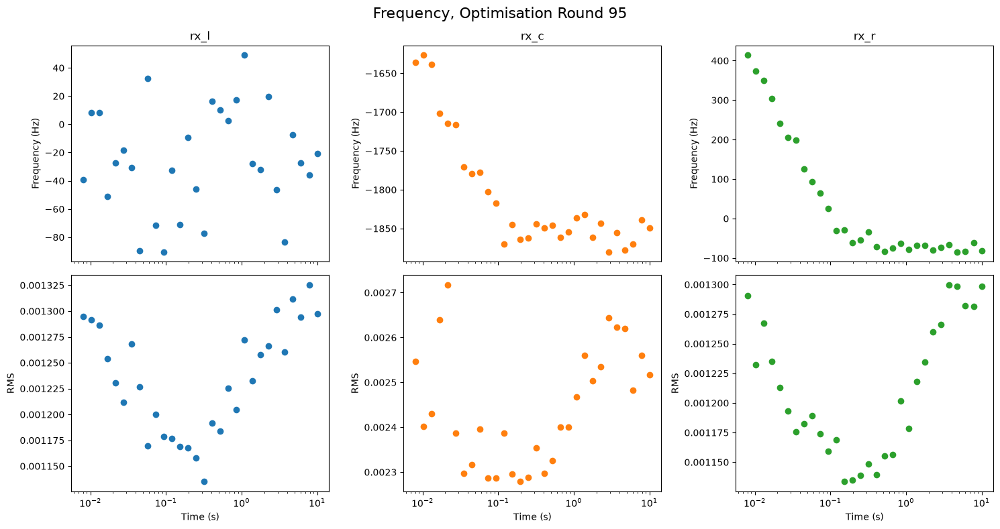

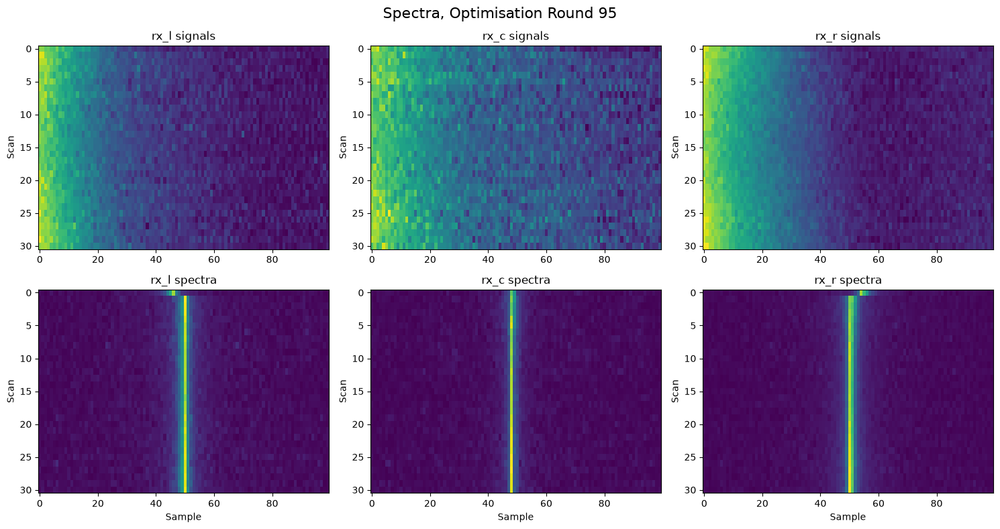

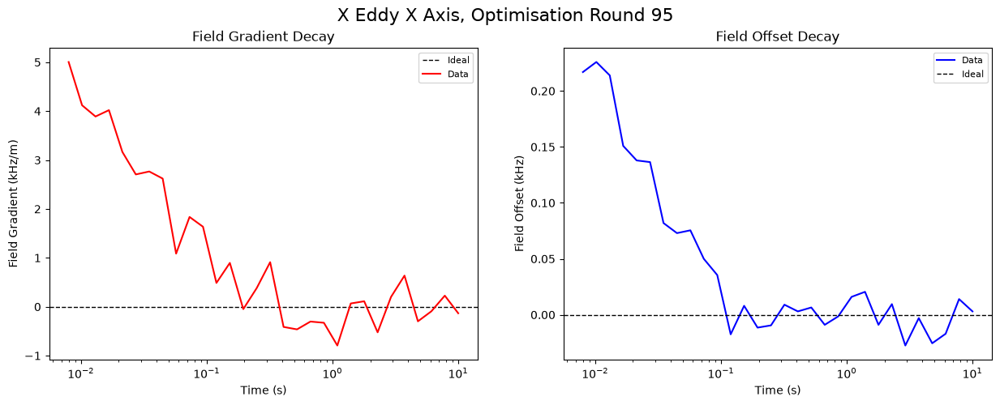

[I 2026-11-26 10:57:37,150] Trial 95 finished with value: 2993.577075319238 and parameters: {'X_A1': 0.08594532661296121, 'X_A2': 0.07388157117915392, 'X_A3': 0.0303926143295828, 'X_A4': -6.4333130200868116e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4532.733633183407
mean |E| = 1272.863568215892
RMS E = 1748.4806407714977
Total cost = 2.994e+03
E max = 0.12225598804865284
E nanmax = 0.12225598804865284
E contains nan = False
B max = 0.019424102856655603
B nanmax = 0.019424102856655603
B contains nan = False
Trial 96


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019424102856655603 !!!!!!!!!!!!!!!!


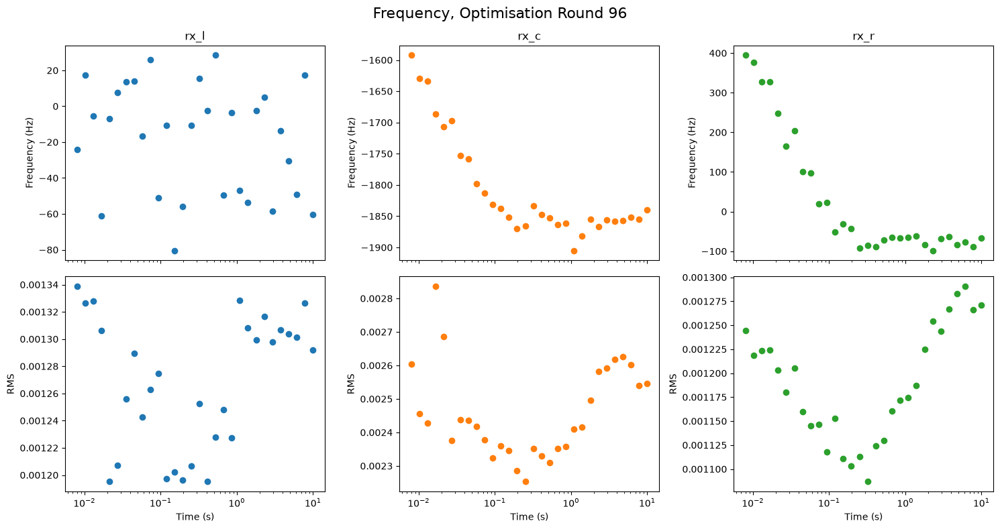

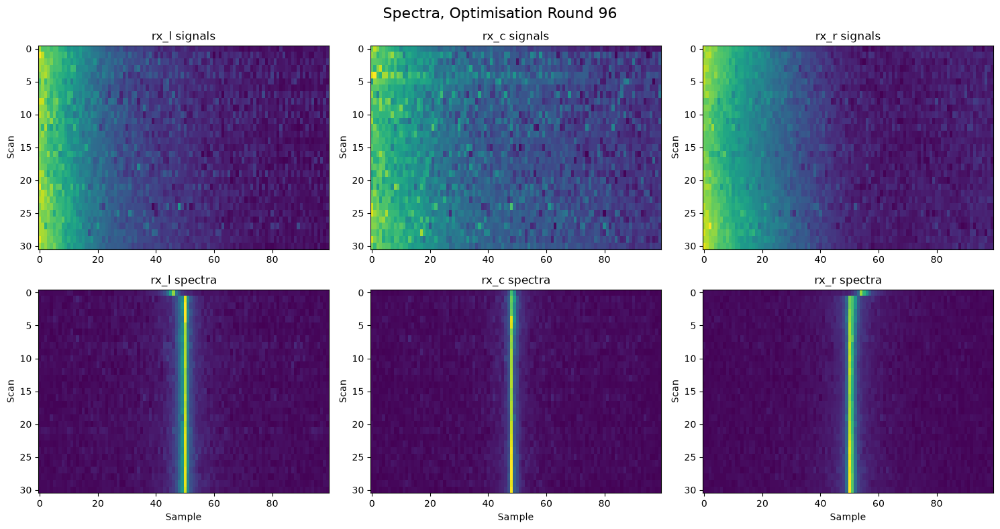

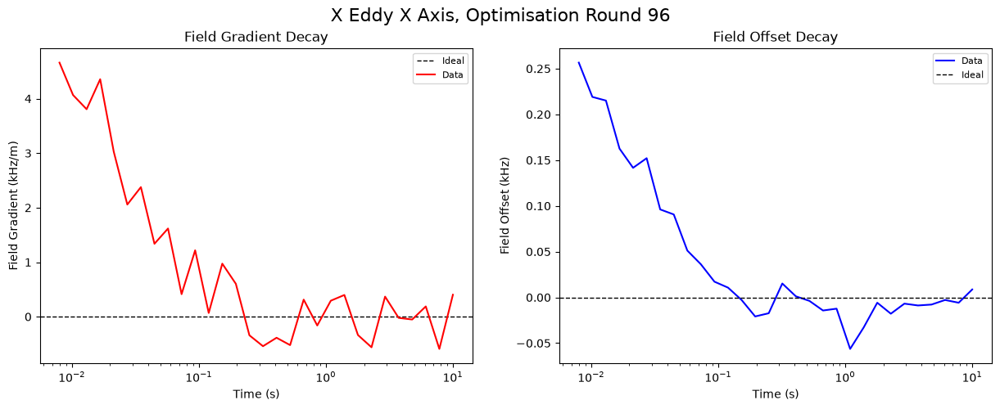

[I 2026-11-26 10:58:25,009] Trial 96 finished with value: 3405.3459435197256 and parameters: {'X_A1': 0.0887844096239738, 'X_A2': 0.07053744427674997, 'X_A3': 0.03764312094617981, 'X_A4': -1.45364896405419e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4187.906046976511
mean |E| = 1133.5998667333
RMS E = 1629.9713788190338
Total cost = 3.405e+03
E max = 0.12382165846631402
E nanmax = 0.12382165846631402
E contains nan = False
B max = 0.019672835653306037
B nanmax = 0.019672835653306037
B contains nan = False
Trial 97


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019672835653306037 !!!!!!!!!!!!!!!!


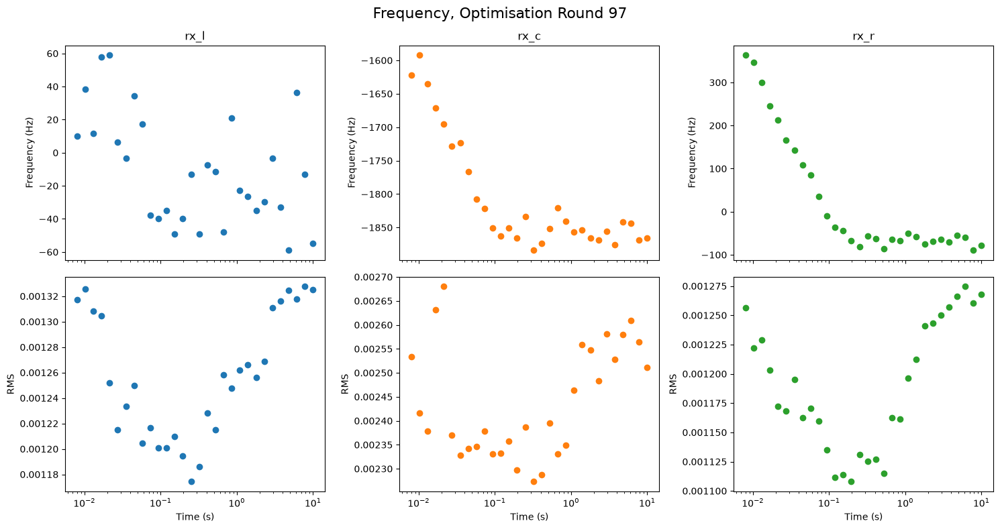

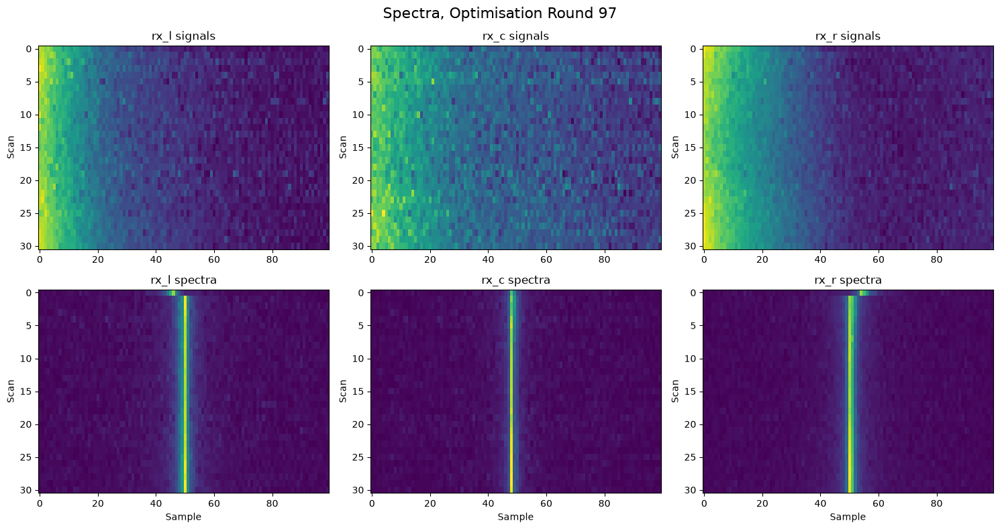

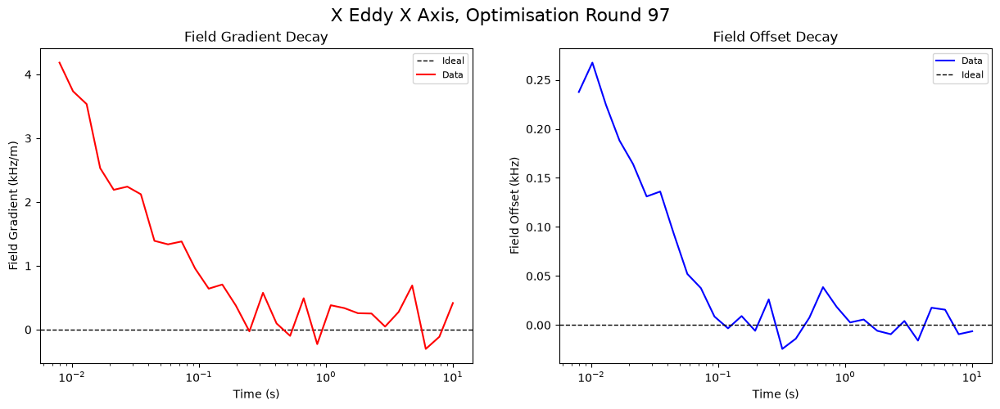

[I 2026-11-26 10:59:12,785] Trial 97 finished with value: 3151.3126861004002 and parameters: {'X_A1': 0.09490056134173769, 'X_A2': 0.07069295560229526, 'X_A3': 0.043673698634334304, 'X_A4': -1.033617770853472e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3533.2333833083444
mean |E| = 874.2295518907209
RMS E = 1255.5648779439803
Total cost = 3.151e+03
E max = 0.12404930056754469
E nanmax = 0.12404930056754469
E contains nan = False
B max = 0.019709013292658555
B nanmax = 0.019709013292658555
B contains nan = False
Trial 98


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019709013292658555 !!!!!!!!!!!!!!!!


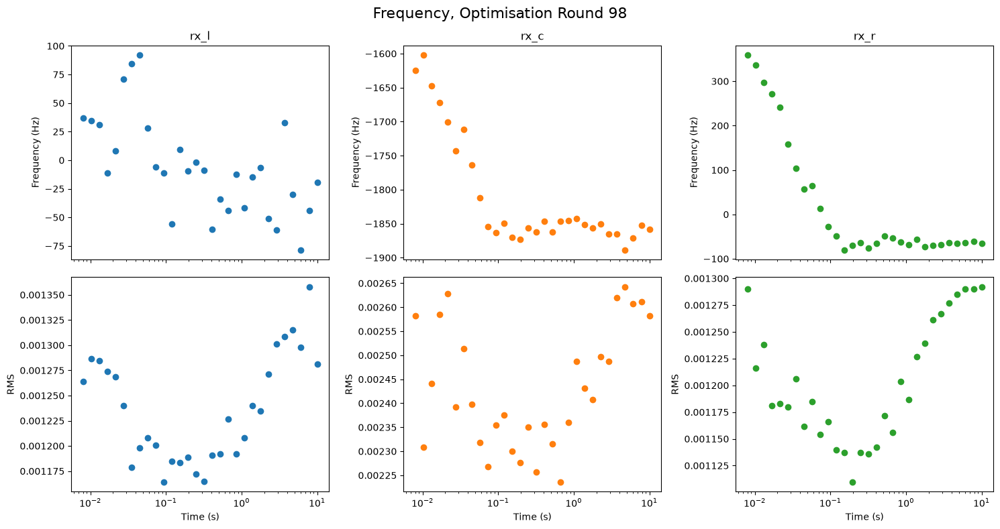

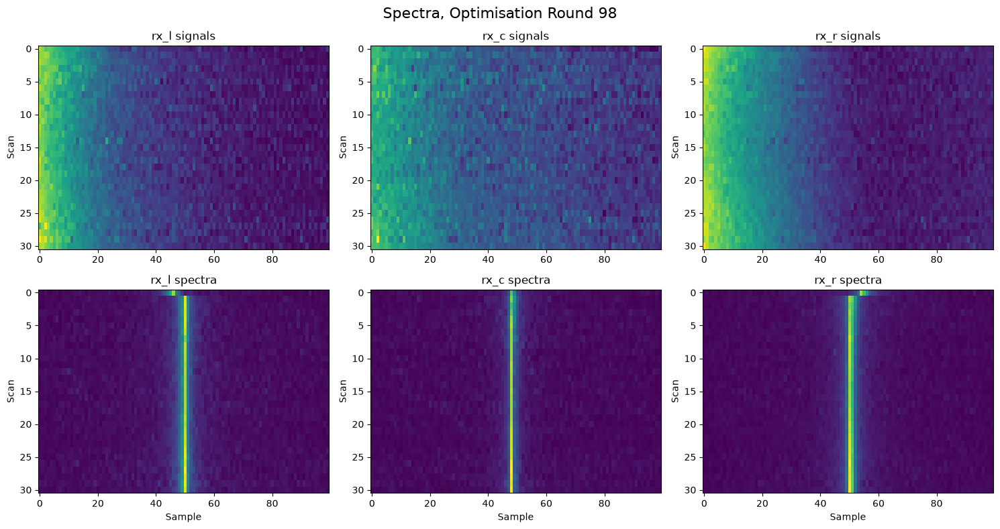

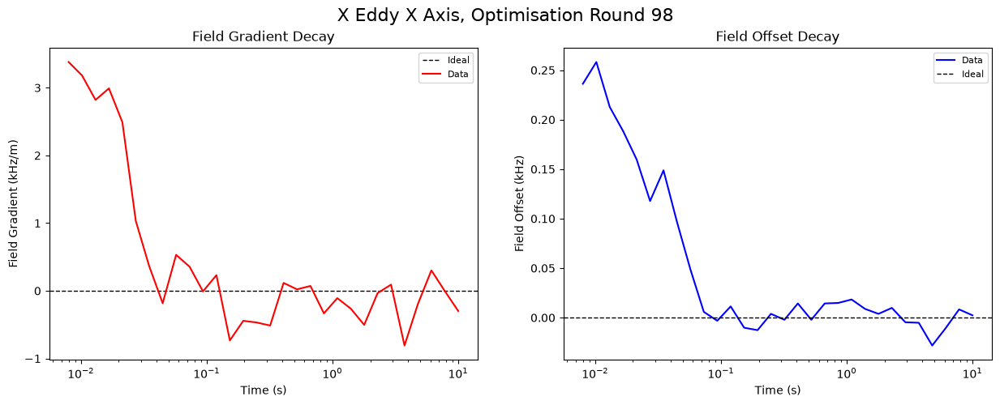

[I 2026-11-26 11:00:00,601] Trial 98 finished with value: 2495.7372479094442 and parameters: {'X_A1': 0.10091973969566766, 'X_A2': 0.06858080994937658, 'X_A3': 0.0410188182169407, 'X_A4': -2.4022960511353863e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 3218.3908045977005
mean |E| = 785.2740296518406
RMS E = 1230.7145470710852
Total cost = 2.496e+03
E max = 0.12225410606089843
E nanmax = 0.12225410606089843
E contains nan = False
B max = 0.019423824084158995
B nanmax = 0.019423824084158995
B contains nan = False
Trial 99


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019423824084158995 !!!!!!!!!!!!!!!!


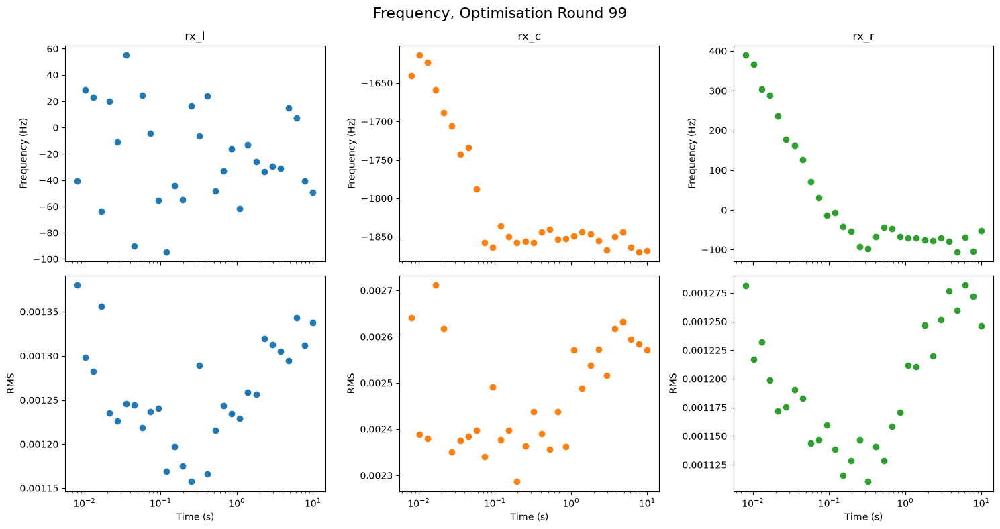

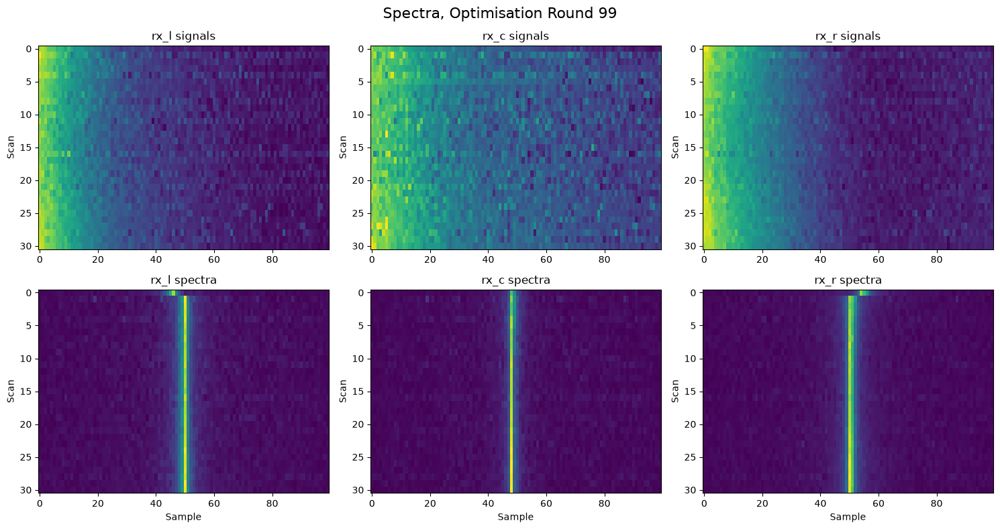

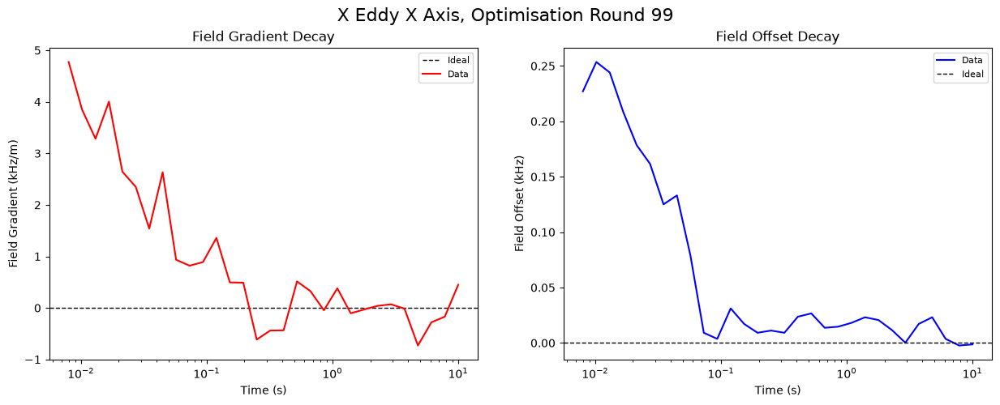

[I 2026-11-26 11:00:50,859] Trial 99 finished with value: 2846.9560640664486 and parameters: {'X_A1': 0.08997813994039201, 'X_A2': 0.07531856969858493, 'X_A3': 0.030960715981527557, 'X_A4': -5.230888310356151e-09}. Best is trial 47 with value: 1718.6295840286955.


max |E| = 4297.851074462767
mean |E| = 1072.4637681159418
RMS E = 1551.9538772214742
Total cost = 2.847e+03
{'X_A1': 0.09502718748787026, 'X_A2': 0.06941907171181386, 'X_A3': 0.04210994040150974, 'X_A4': -1.4992281432459338e-09}
47
1718.6295840286955
{'X_A1': 0.09502718748787026, 'X_A2': 0.06941907171181386, 'X_A3': 0.04210994040150974, 'X_A4': -1.4992281432459338e-09}


,trial,cost,g_pe_perc,max_b0var,status,X_A1,X_A2,X_A3,X_A4
0,0,3308.193175,119.147375,0.018930,PASS,0.076170,0.054393,0.042828,0.000000e+00
1,1,2690.922163,120.840355,0.019199,PASS,0.073878,0.075084,0.037325,1.505121e-09
2,2,2899.722394,116.092422,0.018445,PASS,0.051405,0.062460,0.034491,4.879069e-09
3,3,4029.205359,121.048324,0.019232,PASS,0.095391,0.045616,0.046938,-9.796322e-09
4,4,4643.323617,119.459591,0.018980,PASS,0.064040,0.064608,0.047846,-2.352930e-09
...,...,...,...,...,...,...,...,...,...
95,95,2993.577075,121.462621,0.019298,PASS,0.085945,0.073882,0.030393,-6.433313e-09
96,96,3405.345944,122.255988,0.019424,PASS,0.088784,0.070537,0.037643,-1.453649e-09
97,97,3151.312686,123.821658,0.019673,PASS,0.094901,0.070693,0.043674,-1.033618e-09
98,98,2495.737248,124.049301,0.019709,PASS,0.100920,0.068581,0.041019,-2.402296e-09


In [8]:
# ------------------------------------------------------
# start calling optimisation run and analysis
# ------------------------------------------------------

study = optuna.create_study(direction="minimize")

start_params = {}

for i in range(1, MAX_EXP+1):
    start_params[f"{OPT_AXIS}_A{i}"] = E_START[f"{OPT_AXIS}"][f"A{i}"]

study.enqueue_trial(start_params)

study.optimize(lambda trial: opt.objective(trial, OPT_AXIS, metric, g_hzpm, E_START, B_START, 
                                           start_params, percentage, seq_params, g_ideal), n_trials=num_trials)

best = study.best_params
opt.best = best
print(best)

print(study.best_trial.number)
print(study.best_value)
print(study.best_params)

# ----------------------------------
# create df of optimisation information across trials
# ----------------------------------
rows = []

for t in study.trials:

    row = {
        "trial": t.number,
        "cost": t.value,
        "g_pe_perc": t.user_attrs.get("g_pe_perc", np.nan),
        "max_b0var": t.user_attrs.get("max_b0var", np.nan),
        "status": t.user_attrs.get("status", "")
    }

    row.update(t.params)

    rows.append(row)

df_trials = pd.DataFrame(rows)
display(df_trials)
df_trials.to_csv(Path.cwd() / OPT_AXIS / "gradient_info.csv", index=False)

df_pars = pd.DataFrame(seq_params.items(), columns=["Parameter", "Value"])
df_pars.to_csv(Path.cwd() / OPT_AXIS / "df_pars.csv", index=False)

opt.save_to_global(E_START, OPT_AXIS, "eddy_E.yaml")

#### Plot Optimisation Performance

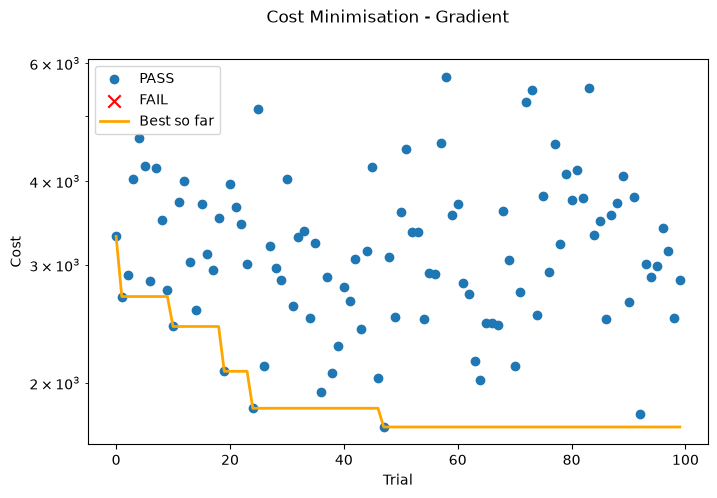

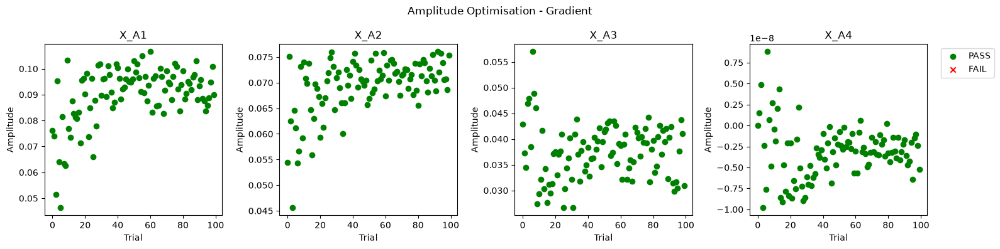

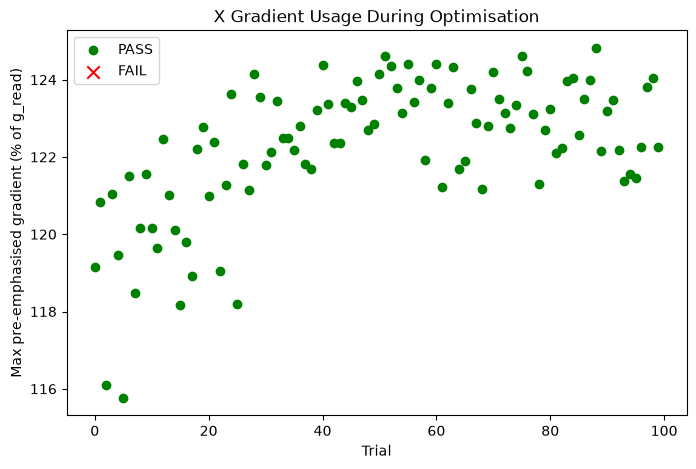

In [9]:
opt.plot_for_optimisation(df_trials, OPT_AXIS, metric)

### Run Offset (B0 Frequency) Optimiser

#### Set optimisation parameters for the offset

In [10]:
num_trials = 100 # number of trials to optimise over
percentage = 50 # percentage of variation the amplitudes of the gradient can have in the optimisation process
metric = "F" # tells that this is optimising the B0 offset (F)

# optimise B0 using the best pre-emphasis parameters from the gradient optimiser
E_START_opt = copy.deepcopy(E_START)
for i in range(1, MAX_EXP+1):
    E_START_opt[f"{OPT_AXIS}"][f"A{i}"] = best[f"{OPT_AXIS}_A{i}"]

#### Start and run optimiser sequence for gradient

[I 2026-11-26 11:00:51,910] A new study created in memory with name: no-name-ee500827-4f6c-4bce-9936-fdab674b956a


E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.01961913224476599
B nanmax = 0.01961913224476599
B contains nan = False
Trial 0


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019423824084158995 !!!!!!!!!!!!!!!!


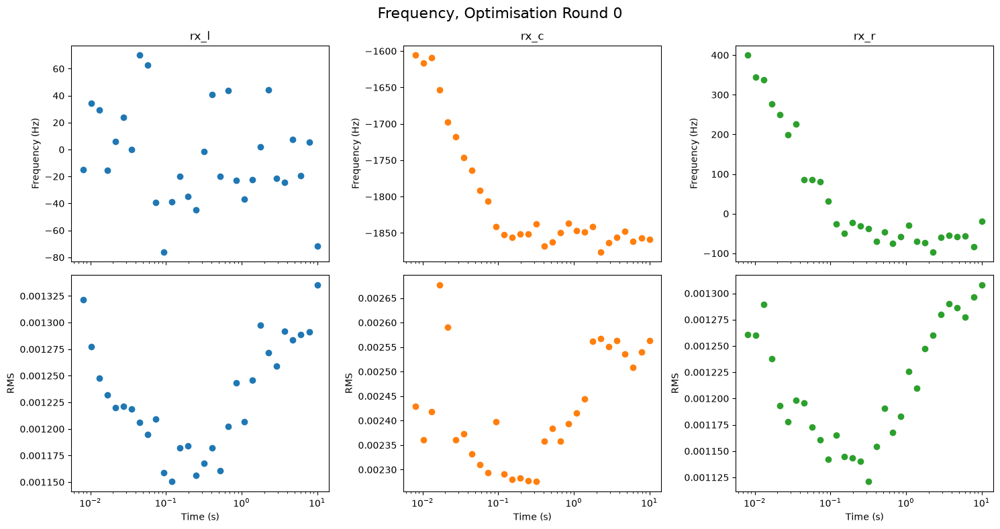

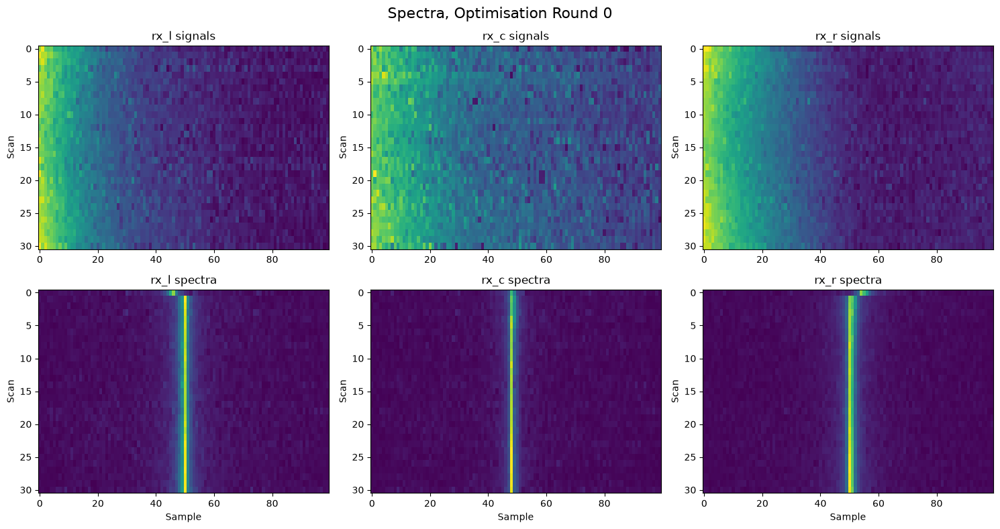

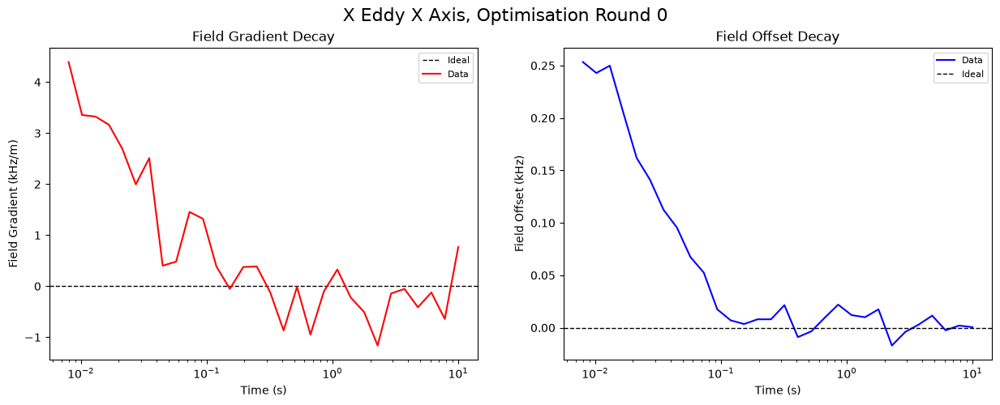

[I 2026-11-26 11:02:15,497] Trial 0 finished with value: 71.00508512326807 and parameters: {'X_A1': -0.03297488514032165, 'X_A2': 0.030378535228892212, 'X_A3': -8.300919712738381e-09, 'X_A4': 0}. Best is trial 0 with value: 71.00508512326807.


rx_c: 7.101e+01
Total cost = 7.101e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.017536332694340077
B nanmax = 0.017536332694340077
B contains nan = False
Trial 1


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.017361795052884776 !!!!!!!!!!!!!!!!


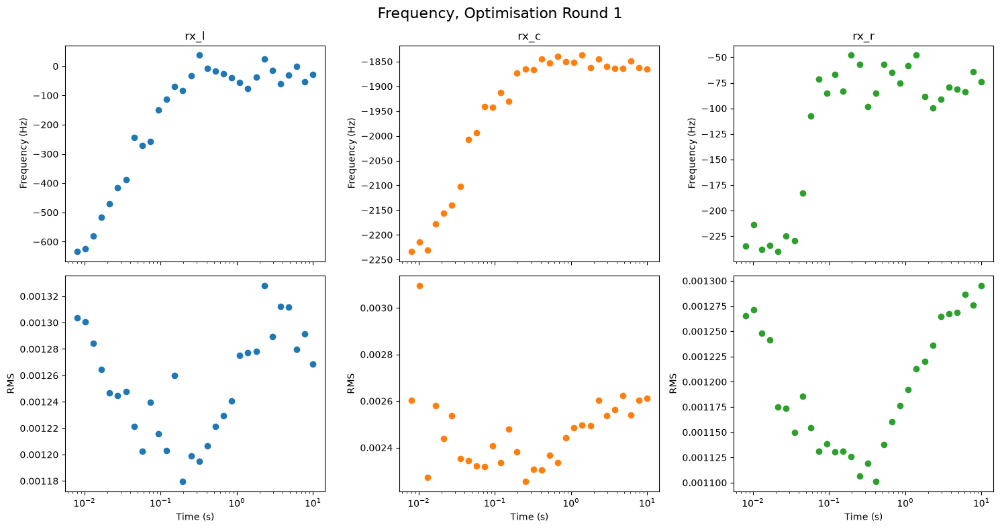

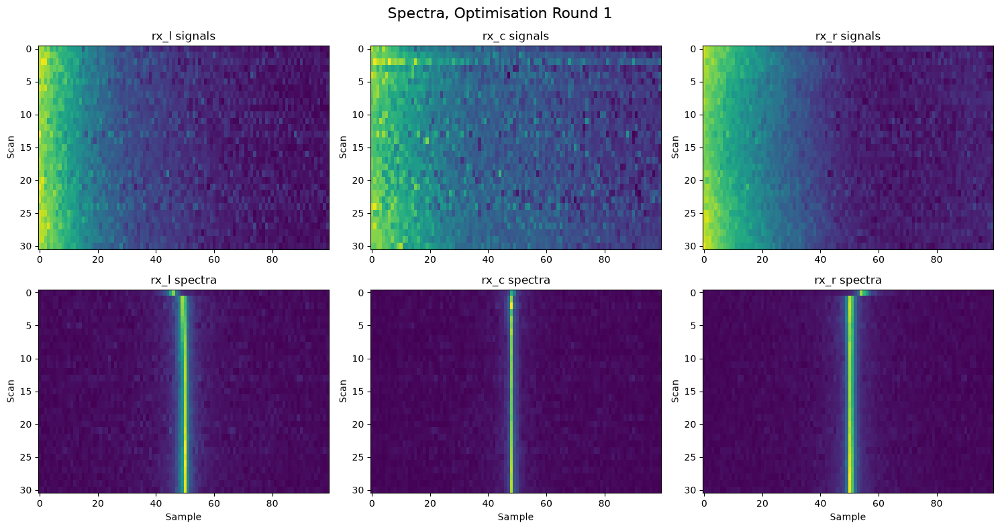

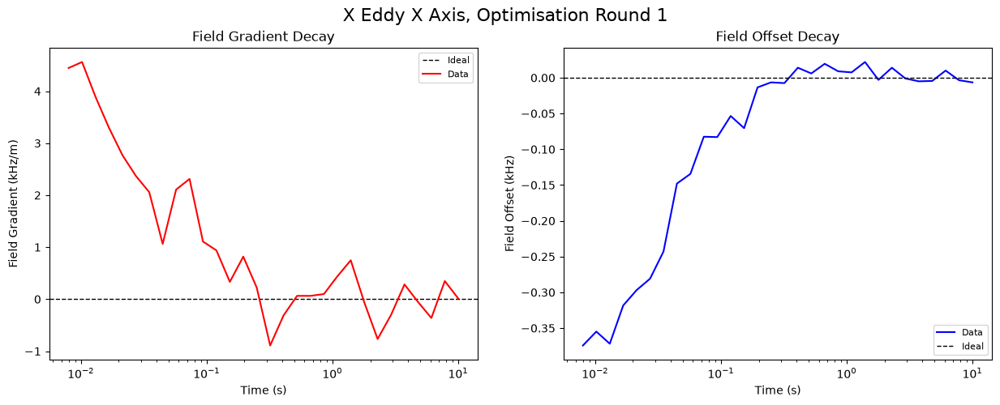

[I 2026-11-26 11:03:36,829] Trial 1 finished with value: 88.4174100854062 and parameters: {'X_A1': -0.037230897437044615, 'X_A2': 0.03957061899615509, 'X_A3': -1.2425217395839077e-08, 'X_A4': -5.667803528060604e-09}. Best is trial 0 with value: 71.00508512326807.


rx_c: 8.842e+01
Total cost = 8.842e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.055227187224879876
B nanmax = 0.055227187224879876
B contains nan = False
Trial 2


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.054677471825027905 !!!!!!!!!!!!!!!!


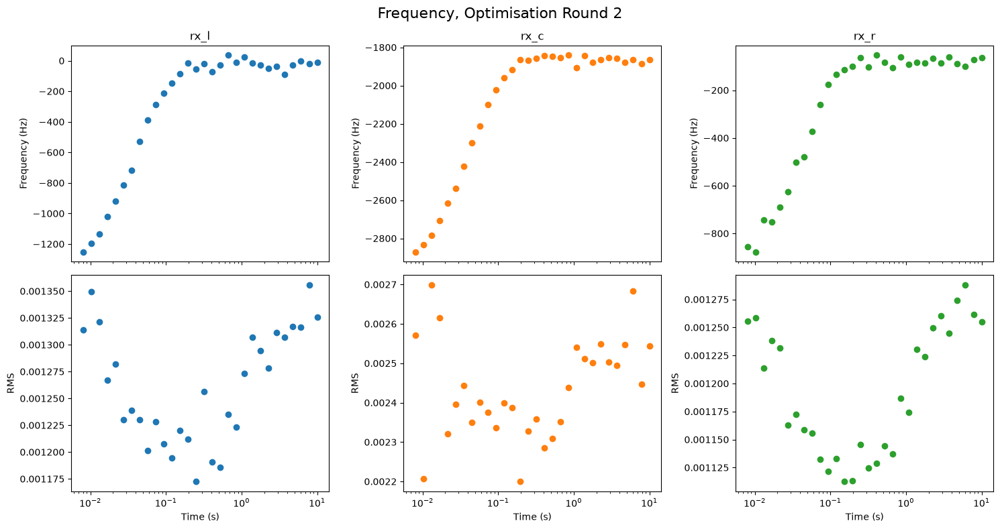

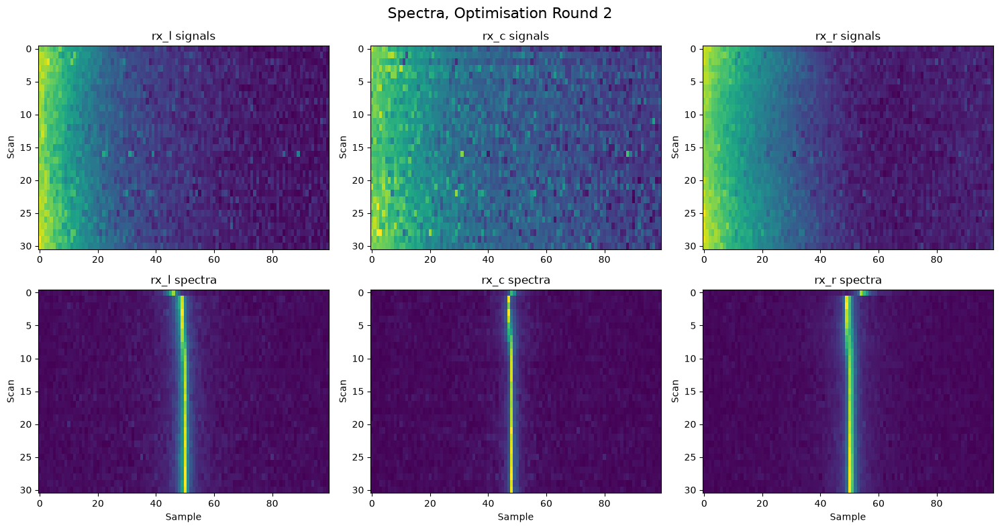

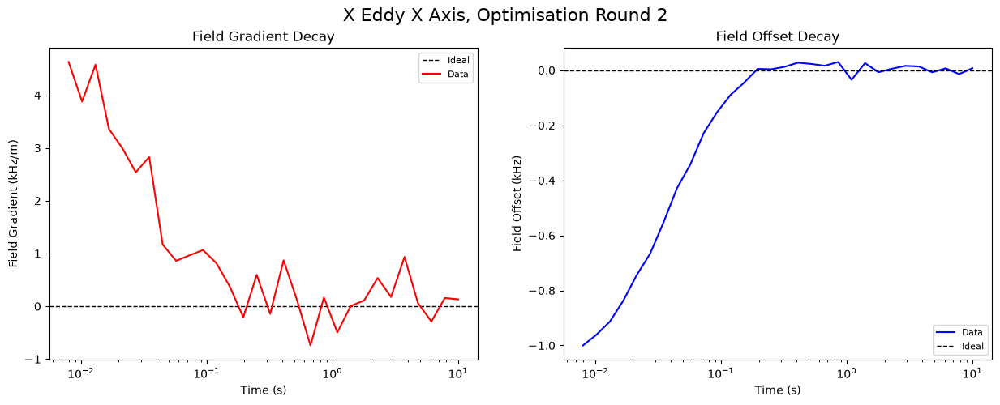

[I 2026-11-26 11:04:58,578] Trial 2 finished with value: 165.0478117627151 and parameters: {'X_A1': -0.03661366795559963, 'X_A2': 0.043959181159955334, 'X_A3': -7.1121729373008726e-09, 'X_A4': 6.424288200933484e-09}. Best is trial 0 with value: 71.00508512326807.


rx_c: 1.650e+02
Total cost = 1.650e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.018260068572285324
B nanmax = 0.018260068572285324
B contains nan = False
Trial 3


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0180782810151485 !!!!!!!!!!!!!!!!


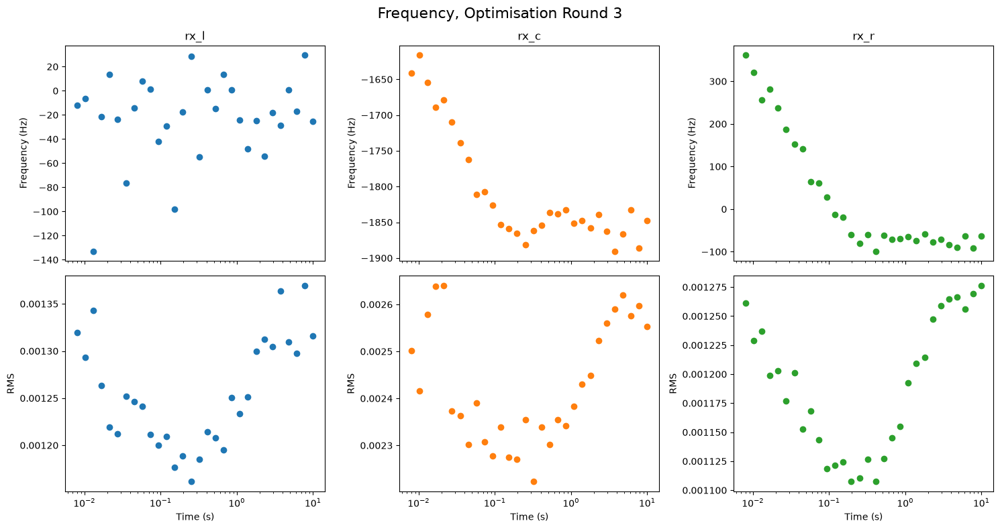

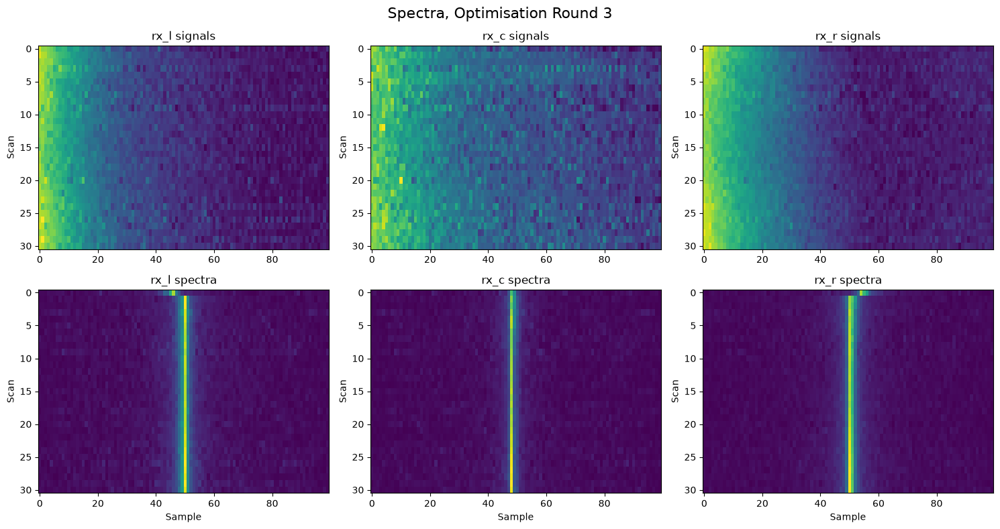

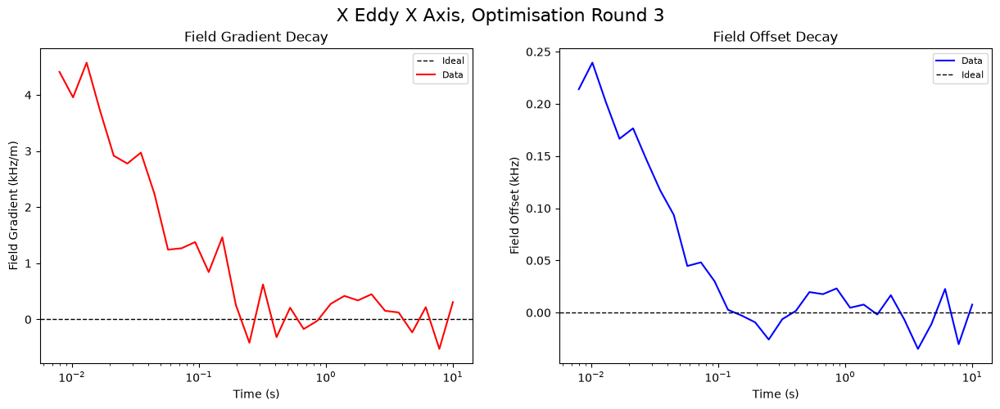

[I 2026-11-26 11:06:20,969] Trial 3 finished with value: 187.7334893391357 and parameters: {'X_A1': -0.04697007224896904, 'X_A2': 0.044558215685235665, 'X_A3': -7.116198263622929e-09, 'X_A4': 2.477824647293217e-09}. Best is trial 0 with value: 71.00508512326807.


rx_c: 1.877e+02
Total cost = 1.877e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.13878291005454177
B nanmax = 0.13878291005454177
B contains nan = False
Trial 4


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.13740146451538723 !!!!!!!!!!!!!!!!


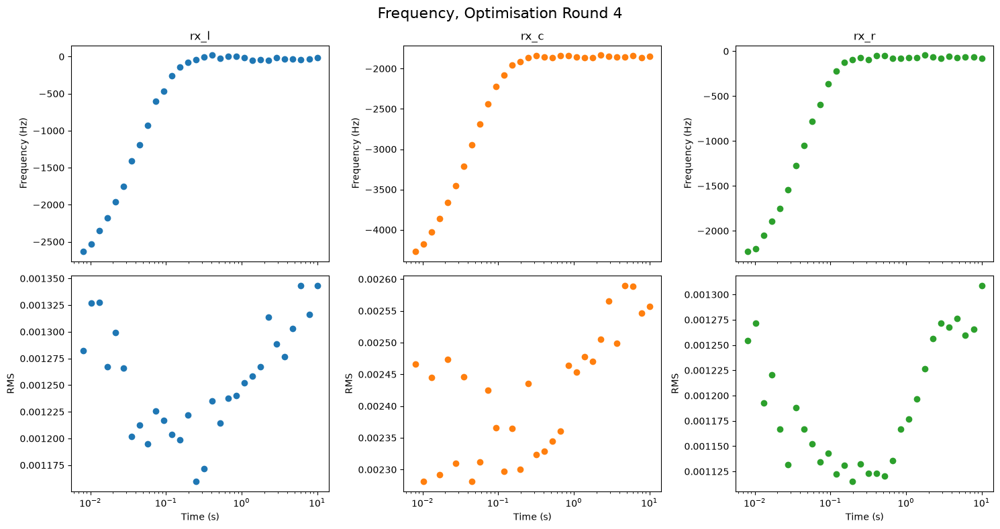

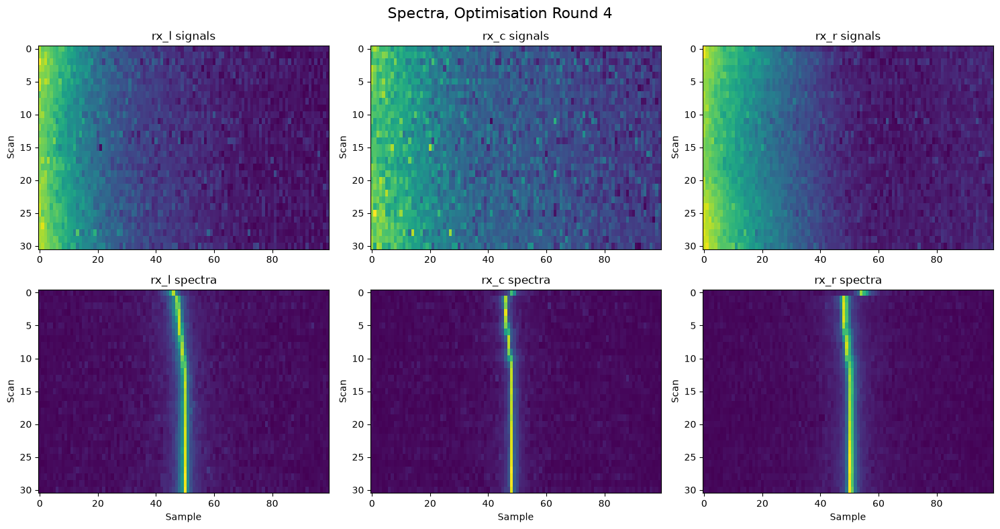

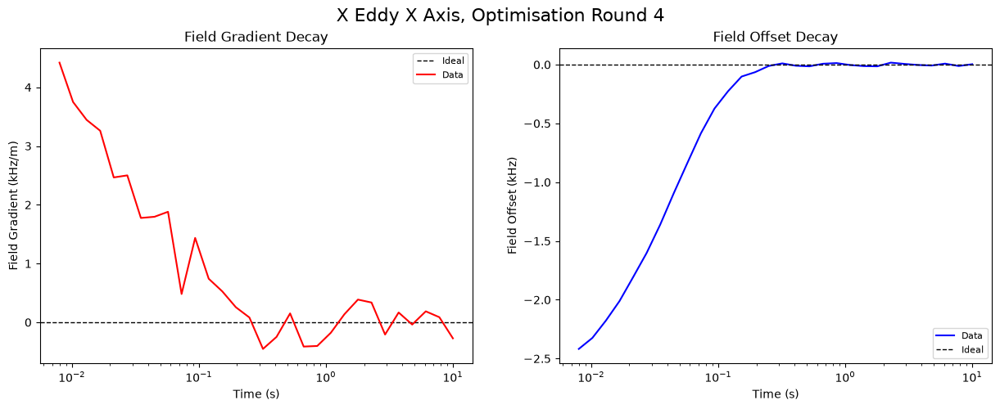

[I 2026-11-26 11:07:44,402] Trial 4 finished with value: 199.8038797787459 and parameters: {'X_A1': -0.017153208640148722, 'X_A2': 0.035590756427136654, 'X_A3': -4.229208260519915e-09, 'X_A4': 7.032006159950322e-09}. Best is trial 0 with value: 71.00508512326807.


rx_c: 1.998e+02
Total cost = 1.998e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.02883618786343969
B nanmax = 0.02883618786343969
B contains nan = False
Trial 5


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.028549133650923555 !!!!!!!!!!!!!!!!


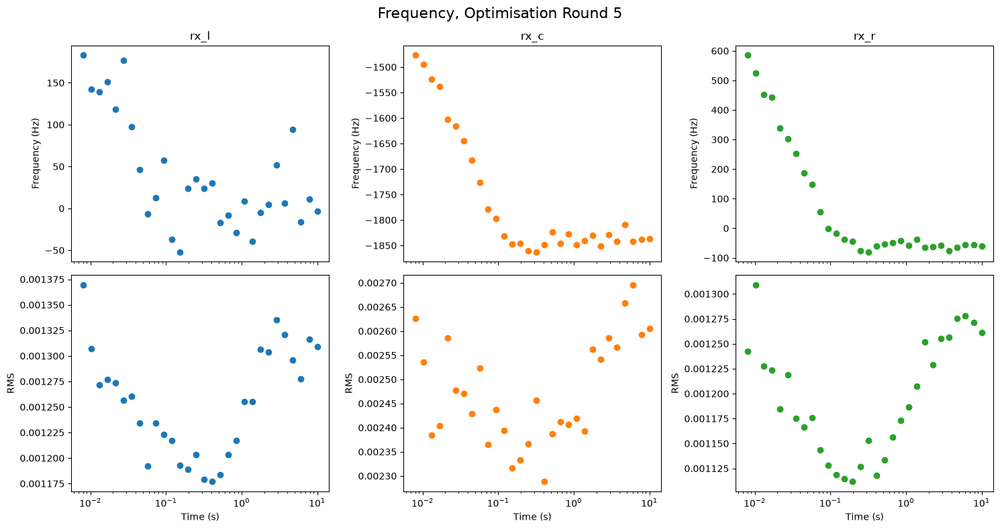

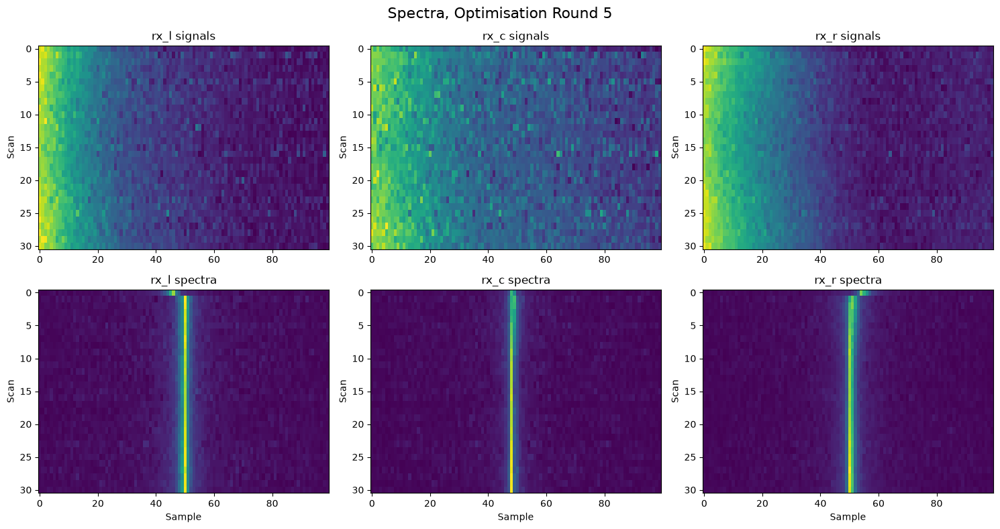

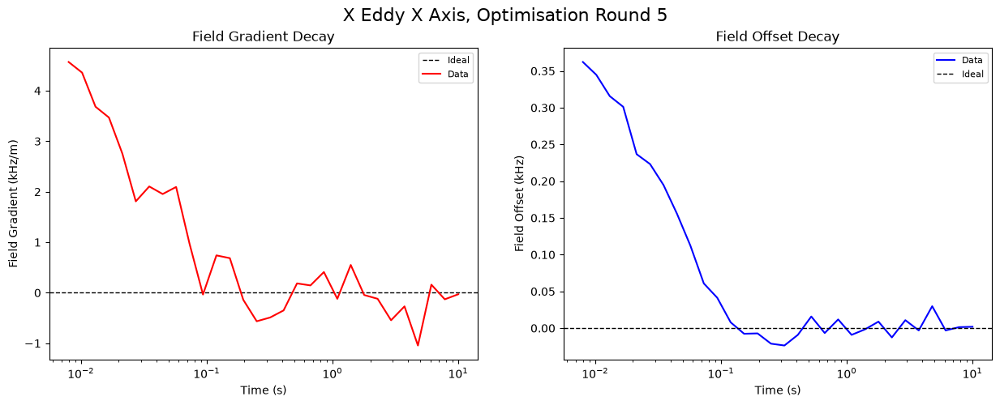

[I 2026-11-26 11:09:02,655] Trial 5 finished with value: 93.88218657249104 and parameters: {'X_A1': -0.030824907576967316, 'X_A2': 0.0270037680360062, 'X_A3': -1.0656024932612131e-08, 'X_A4': 2.4680260180362574e-09}. Best is trial 0 with value: 71.00508512326807.


rx_c: 9.388e+01
Total cost = 9.388e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0025253814814410126
B nanmax = 0.0025253814814410126
B contains nan = False
Trial 6


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0025213874783142215 !!!!!!!!!!!!!!!!


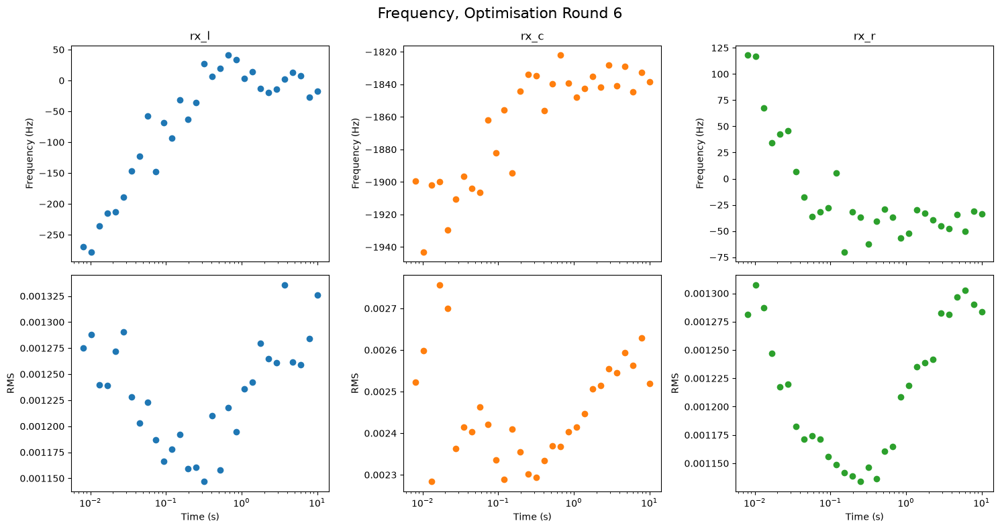

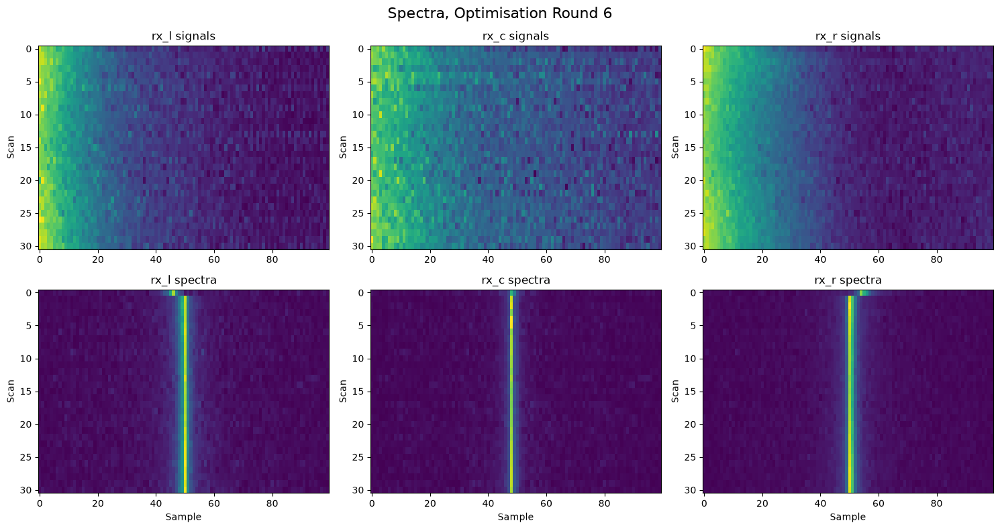

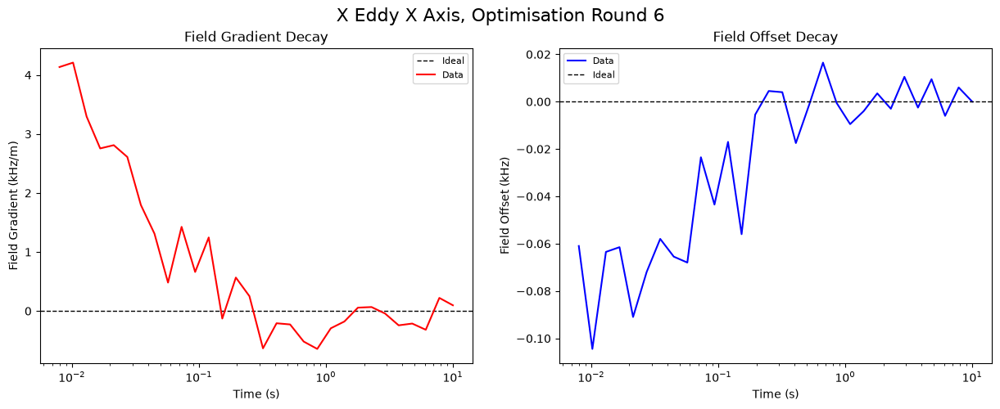

[I 2026-11-26 11:09:50,788] Trial 6 finished with value: 62.853818679539 and parameters: {'X_A1': -0.02165195947123635, 'X_A2': 0.02135494111374435, 'X_A3': -1.1896576870559838e-08, 'X_A4': -7.58203687964496e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 6.285e+01
Total cost = 6.285e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.04371821354255225
B nanmax = 0.04371821354255225
B contains nan = False
Trial 7


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.04328301685158068 !!!!!!!!!!!!!!!!


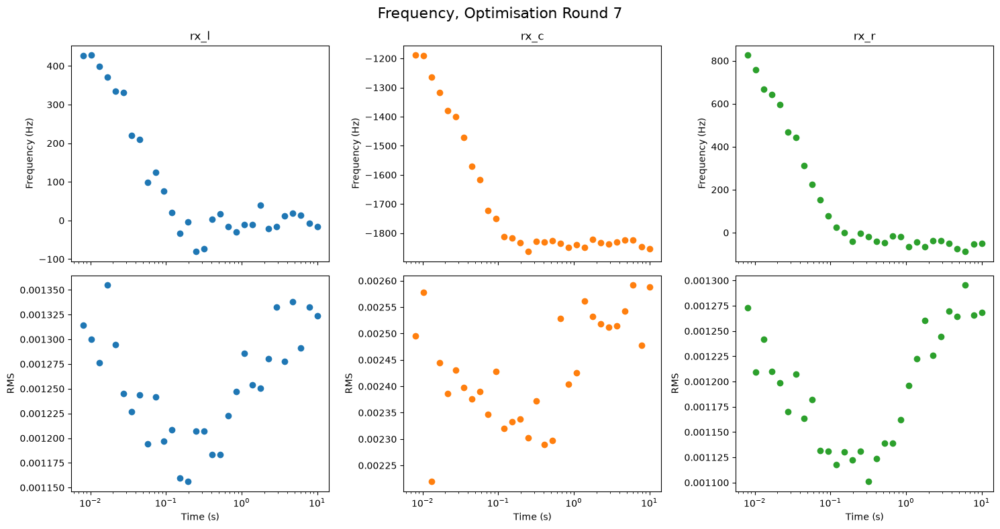

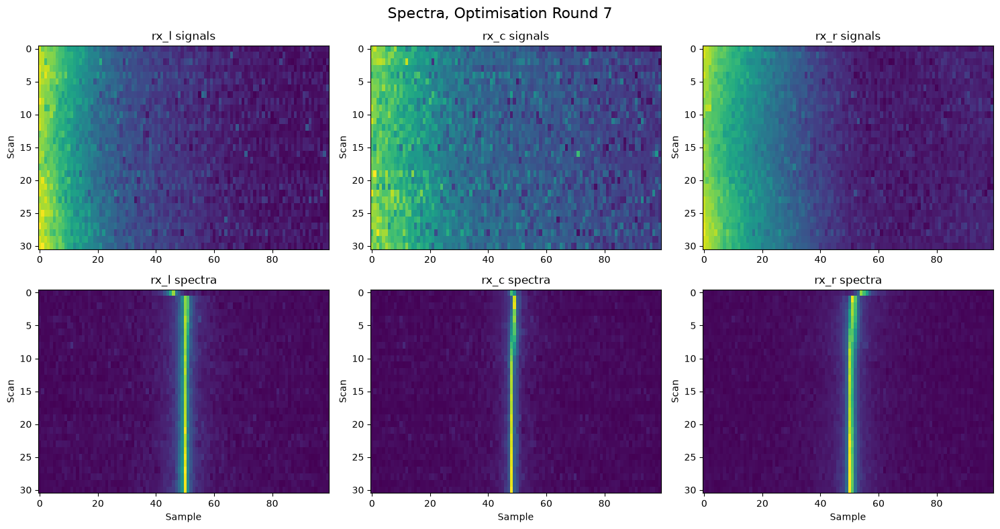

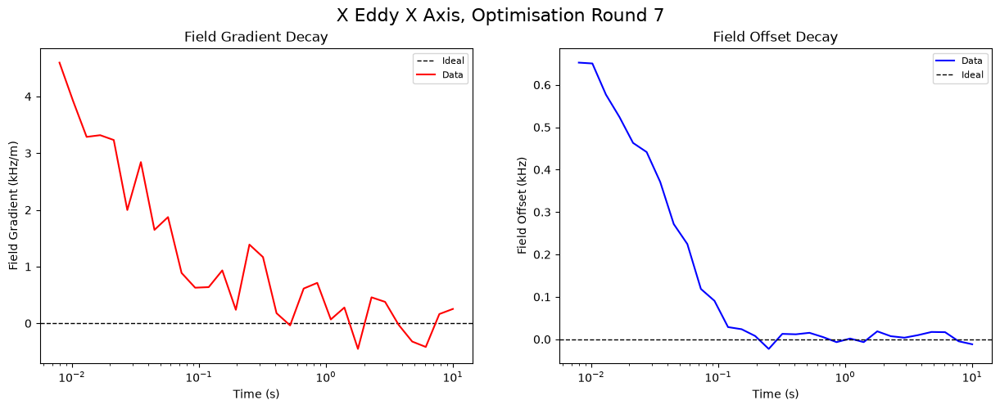

[I 2026-11-26 11:10:38,782] Trial 7 finished with value: 130.36548873996082 and parameters: {'X_A1': -0.04138891779230628, 'X_A2': 0.035594209355008406, 'X_A3': -4.732300789285277e-09, 'X_A4': -3.820151046749112e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.304e+02
Total cost = 1.304e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.013684901647231492
B nanmax = 0.013684901647231492
B contains nan = False
Trial 8


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013548694819987064 !!!!!!!!!!!!!!!!


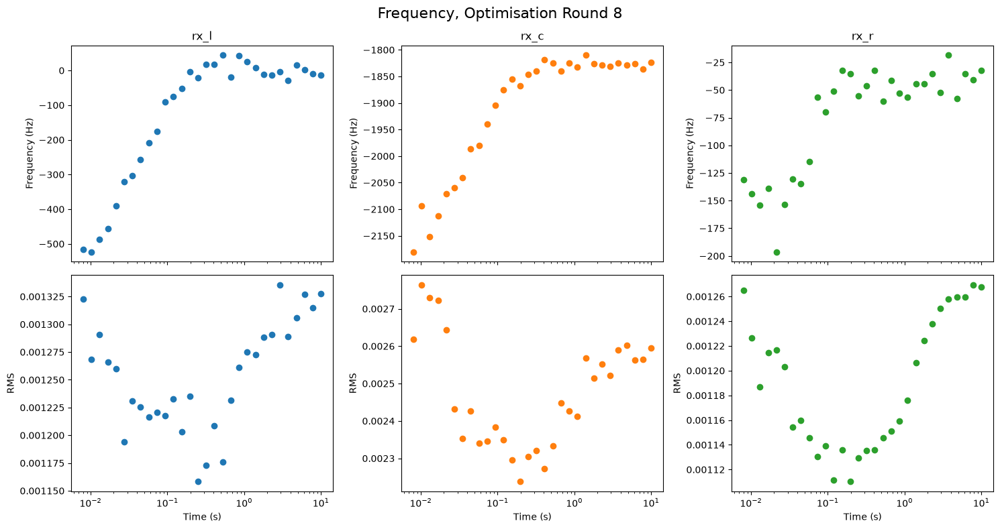

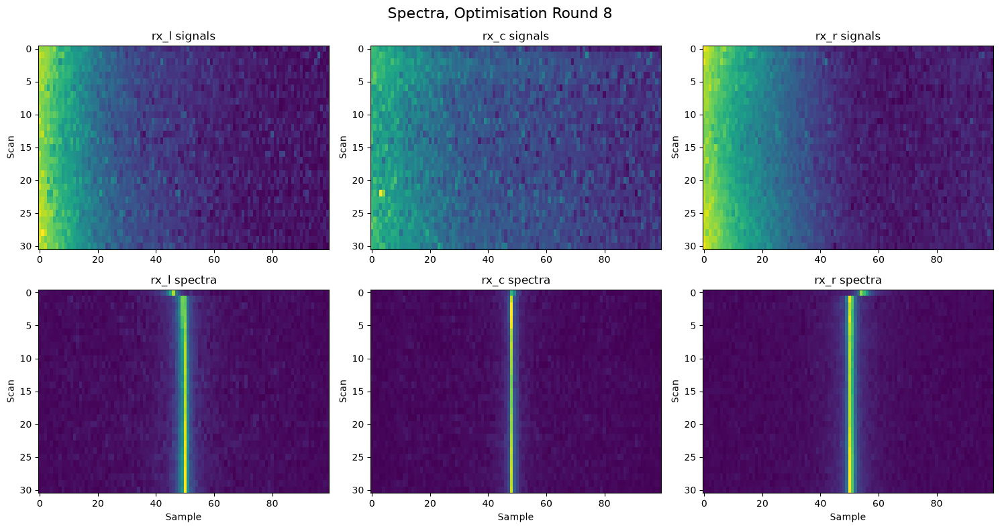

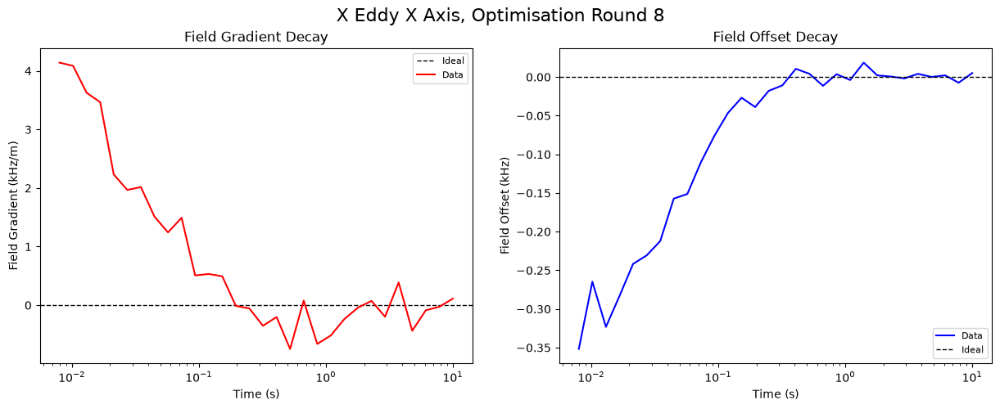

[I 2026-11-26 11:11:26,698] Trial 8 finished with value: 63.59453810900154 and parameters: {'X_A1': -0.025093031933391498, 'X_A2': 0.026917761781313252, 'X_A3': -1.216781147971797e-08, 'X_A4': 9.489594193925398e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 6.359e+01
Total cost = 6.359e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0993421713273177
B nanmax = 0.0993421713273177
B contains nan = False
Trial 9


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0983533258440598 !!!!!!!!!!!!!!!!


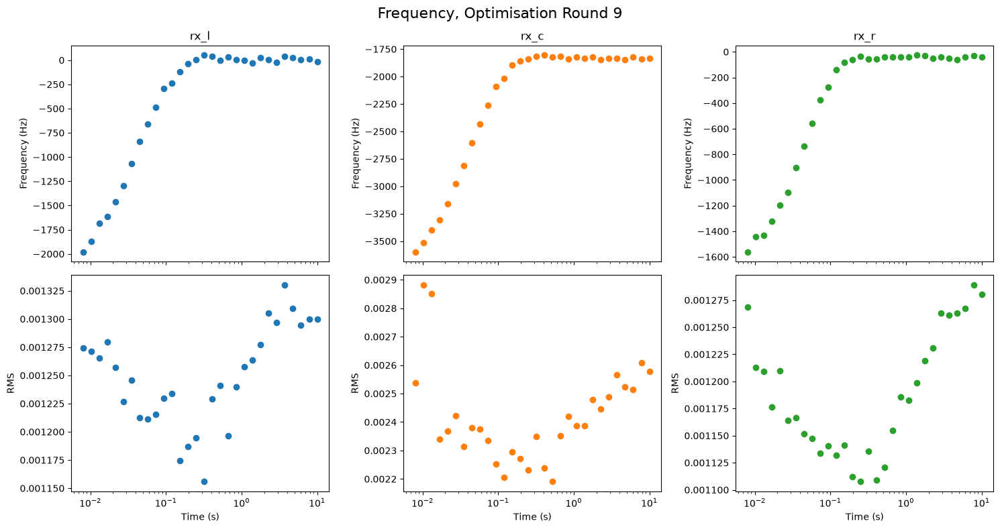

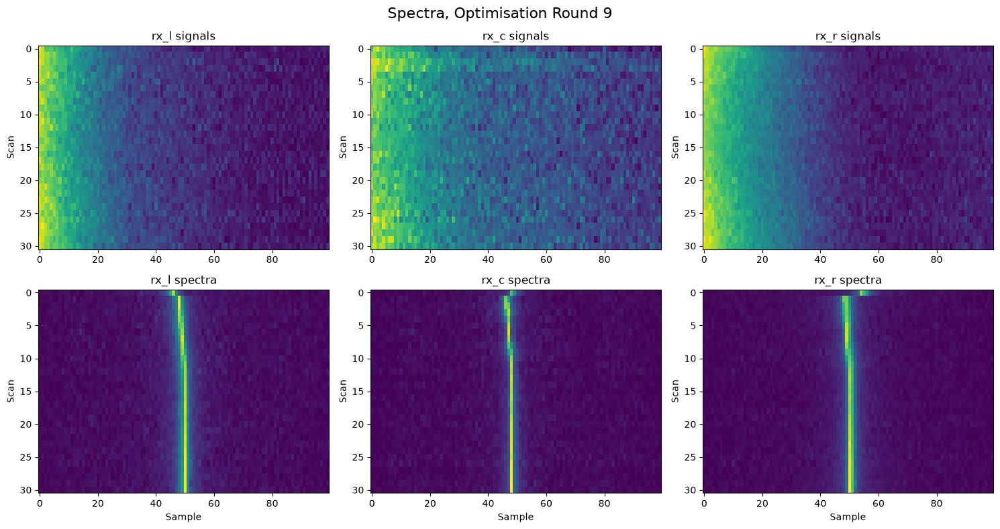

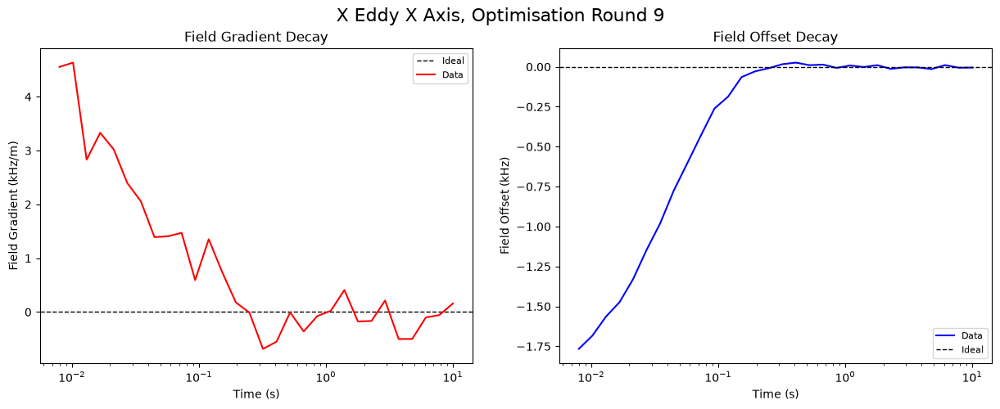

[I 2026-11-26 11:12:14,687] Trial 9 finished with value: 161.33391392033886 and parameters: {'X_A1': -0.024806279160750254, 'X_A2': 0.038007626331214094, 'X_A3': -9.904552101828065e-09, 'X_A4': -5.047193861665795e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.613e+02
Total cost = 1.613e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0513585922986867
B nanmax = 0.0513585922986867
B contains nan = False
Trial 10


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.05084734944692108 !!!!!!!!!!!!!!!!


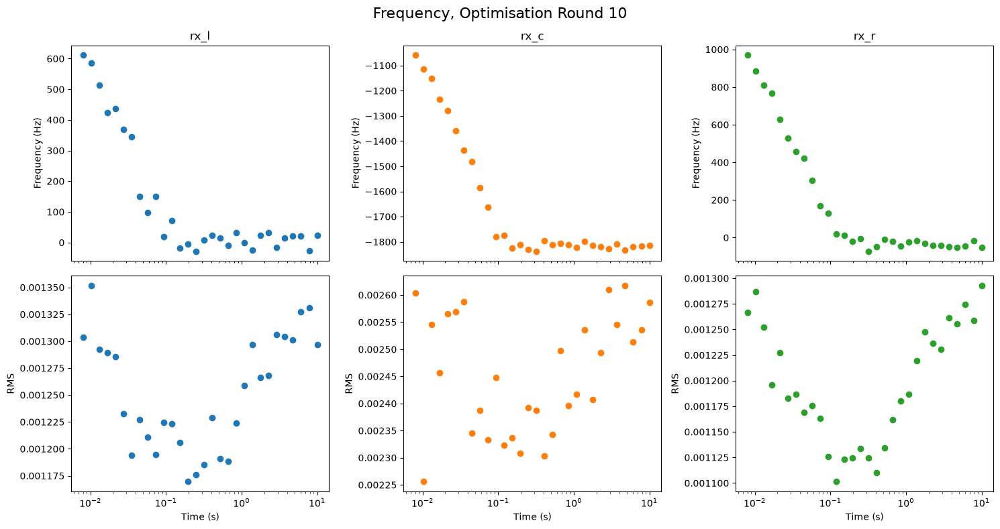

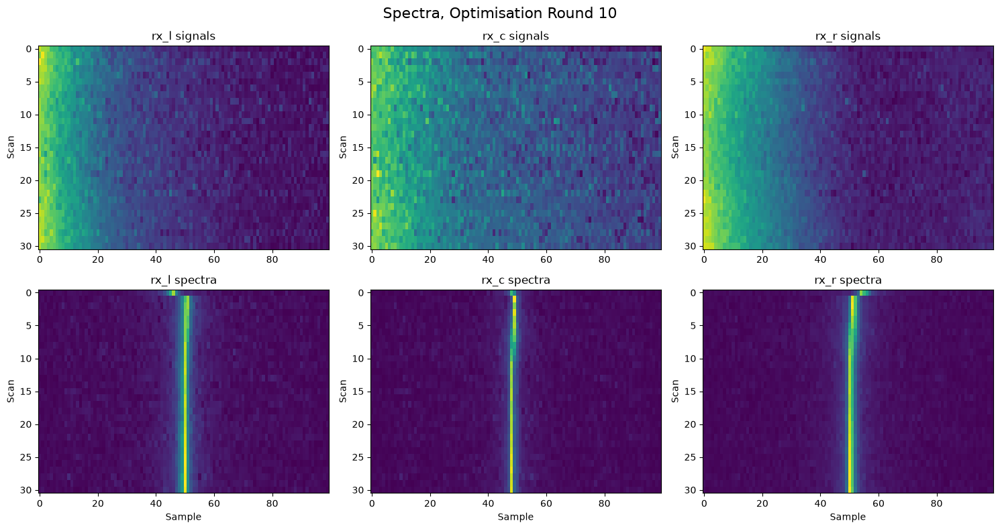

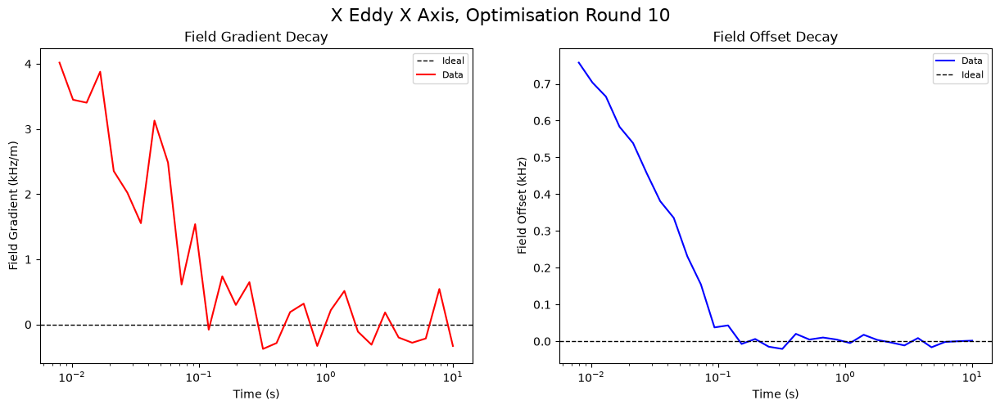

[I 2026-11-26 11:13:02,476] Trial 10 finished with value: 88.51618010017181 and parameters: {'X_A1': -0.02905620186406533, 'X_A2': 0.022243211417278974, 'X_A3': -1.0681310274633406e-08, 'X_A4': -9.473707262570061e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 8.852e+01
Total cost = 8.852e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.08326340664673533
B nanmax = 0.08326340664673533
B contains nan = False
Trial 11


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.08243460841464356 !!!!!!!!!!!!!!!!


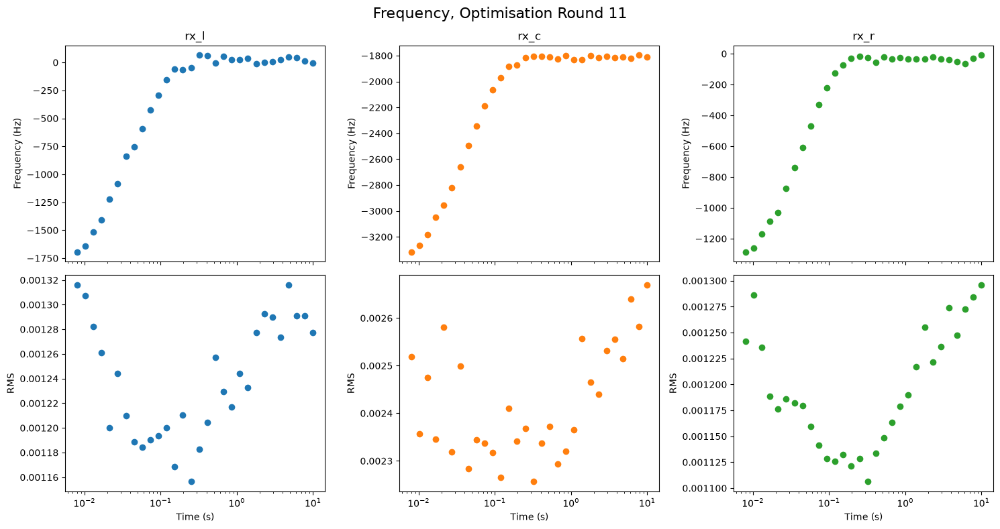

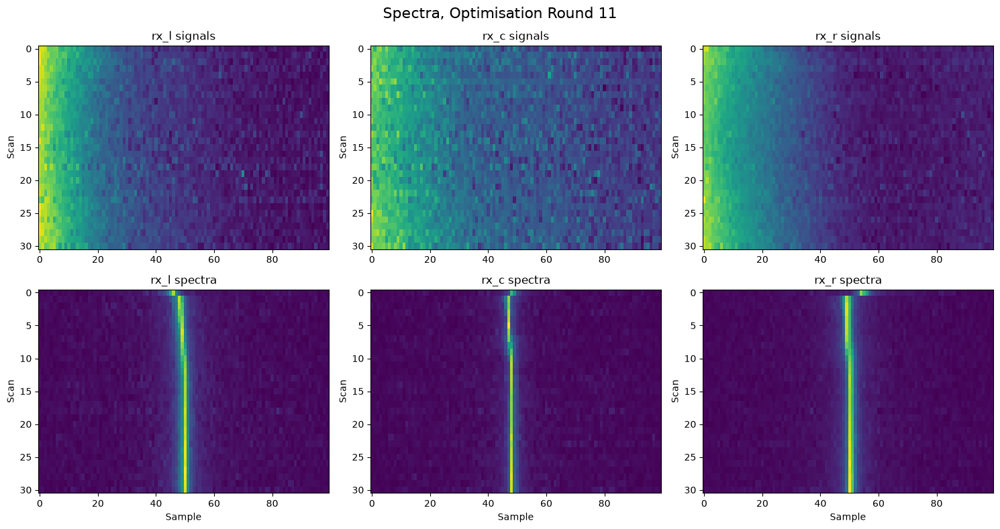

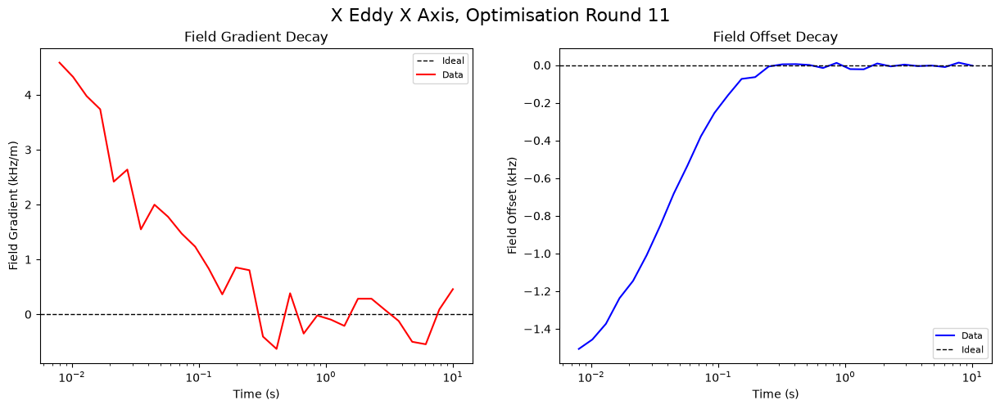

[I 2026-11-26 11:13:50,181] Trial 11 finished with value: 155.5781132362348 and parameters: {'X_A1': -0.021302400122267147, 'X_A2': 0.03236722373083111, 'X_A3': -1.1297039251053157e-08, 'X_A4': 9.35072455556187e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.556e+02
Total cost = 1.556e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.057728705613604804
B nanmax = 0.057728705613604804
B contains nan = False
Trial 12


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.05715408061202522 !!!!!!!!!!!!!!!!


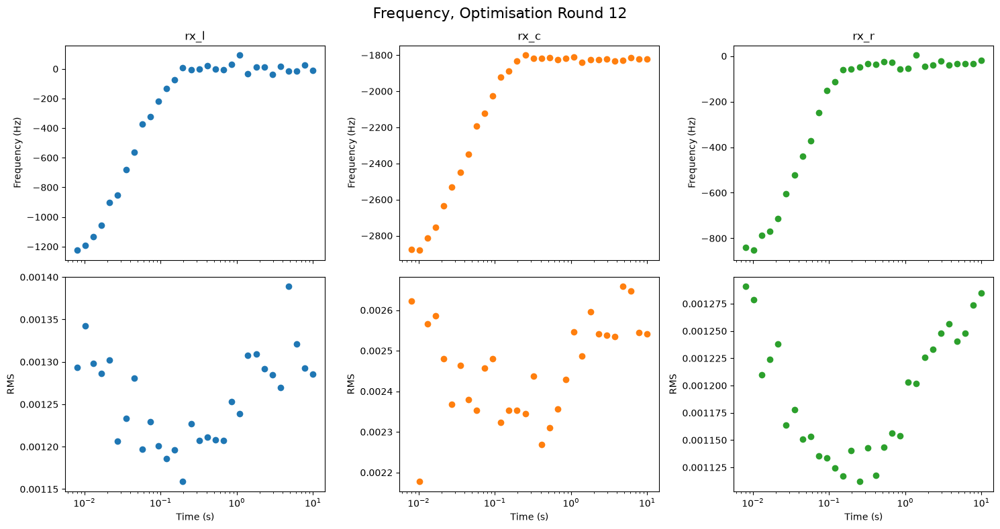

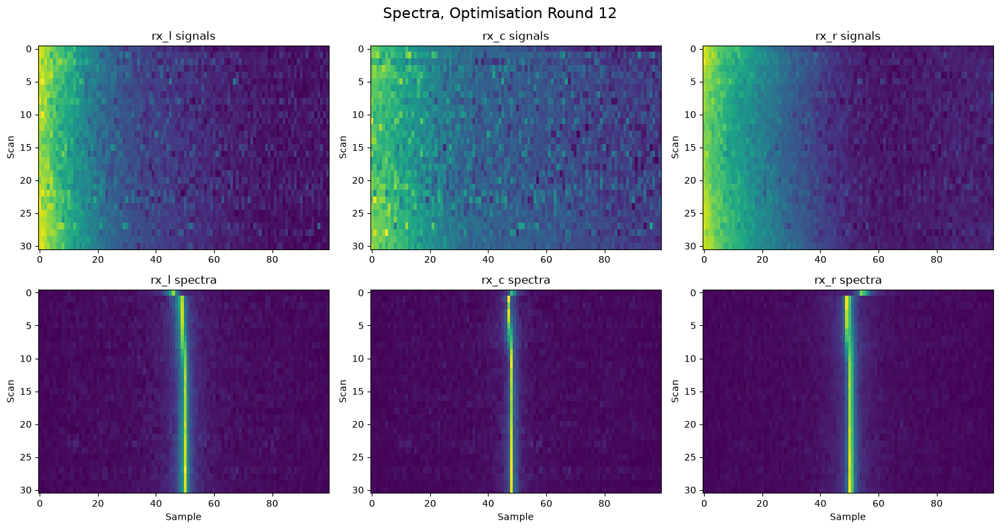

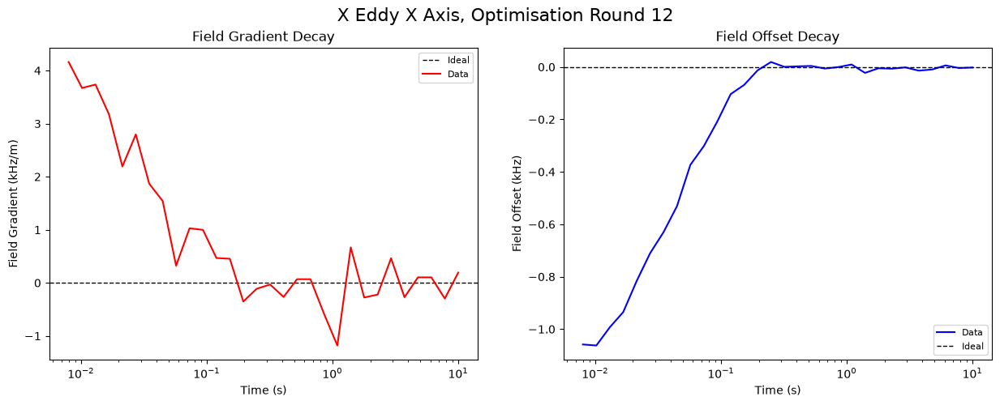

[I 2026-11-26 11:14:38,017] Trial 12 finished with value: 117.2868598809236 and parameters: {'X_A1': -0.01949435422039912, 'X_A2': 0.027167233014761975, 'X_A3': -1.2022495041924378e-08, 'X_A4': -5.315662896147991e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.173e+02
Total cost = 1.173e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.026512634544639136
B nanmax = 0.026512634544639136
B contains nan = False
Trial 13


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.026248736641198353 !!!!!!!!!!!!!!!!


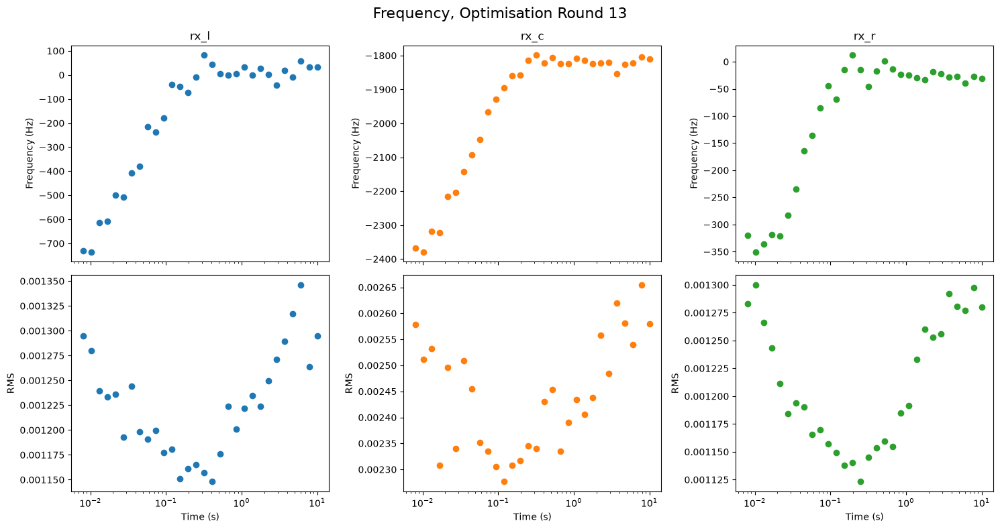

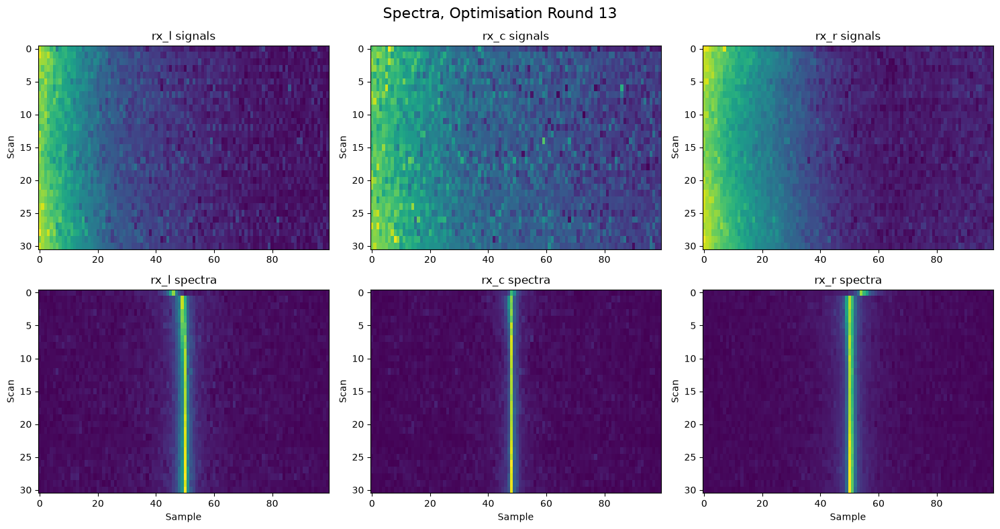

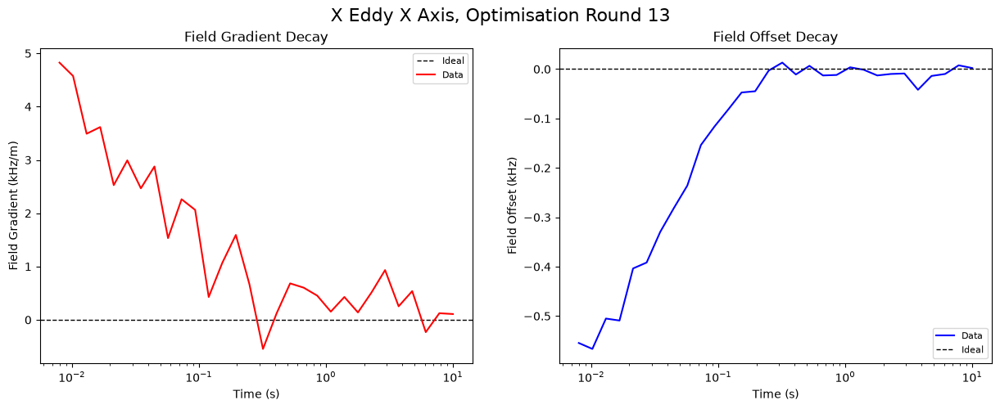

[I 2026-11-26 11:15:25,909] Trial 13 finished with value: 146.29365556208856 and parameters: {'X_A1': -0.01972677874131378, 'X_A2': 0.0232537143558761, 'X_A3': -9.838547597095449e-09, 'X_A4': -8.542884924419431e-10}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.463e+02
Total cost = 1.463e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.060332623941285385
B nanmax = 0.060332623941285385
B contains nan = False
Trial 14


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.059732052823171906 !!!!!!!!!!!!!!!!


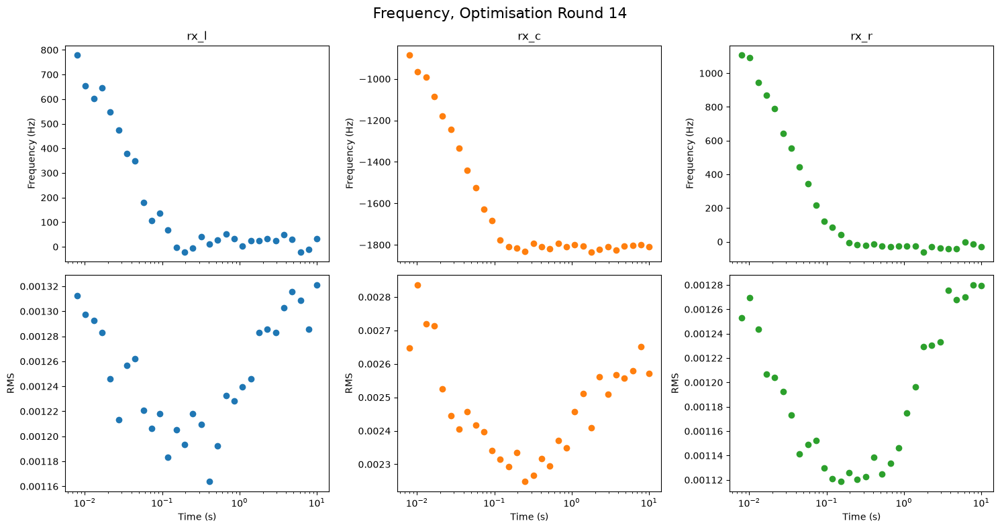

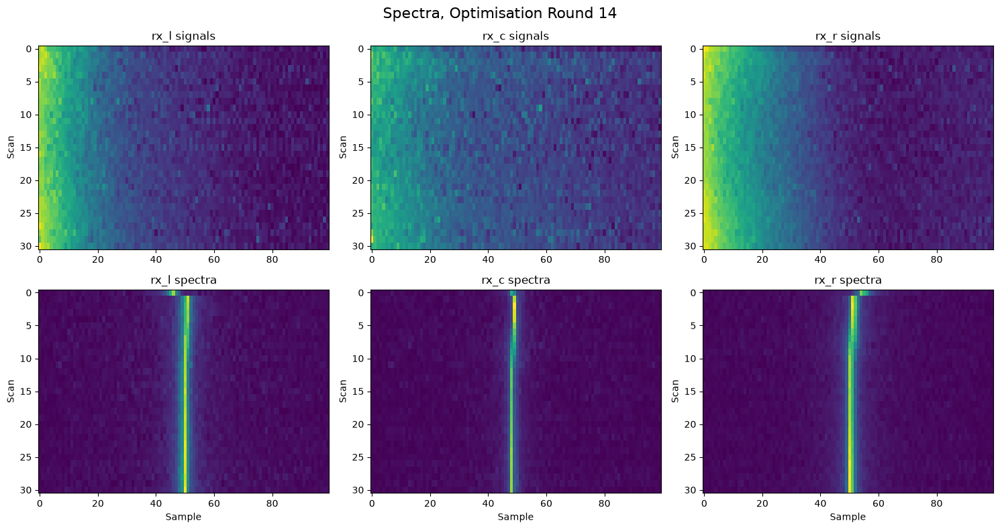

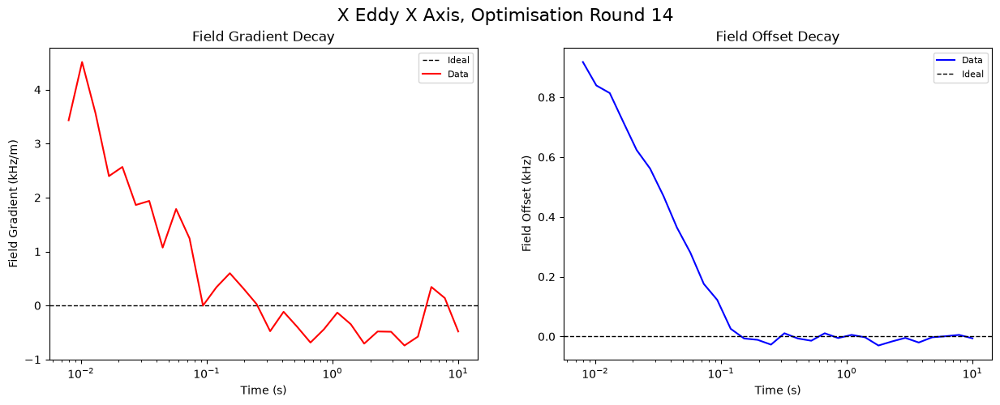

[I 2026-11-26 11:16:14,079] Trial 14 finished with value: 112.4188162358638 and parameters: {'X_A1': -0.02928203361975536, 'X_A2': 0.021277208012026354, 'X_A3': -1.2434379873317024e-08, 'X_A4': 8.740343426945036e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.124e+02
Total cost = 1.124e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.07893855634858545
B nanmax = 0.07893855634858545
B contains nan = False
Trial 15


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.07815278233774063 !!!!!!!!!!!!!!!!


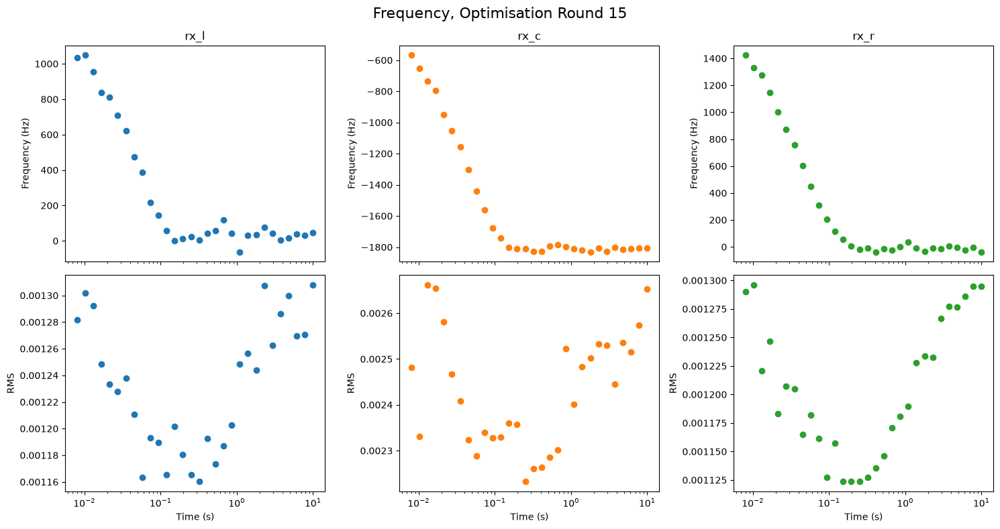

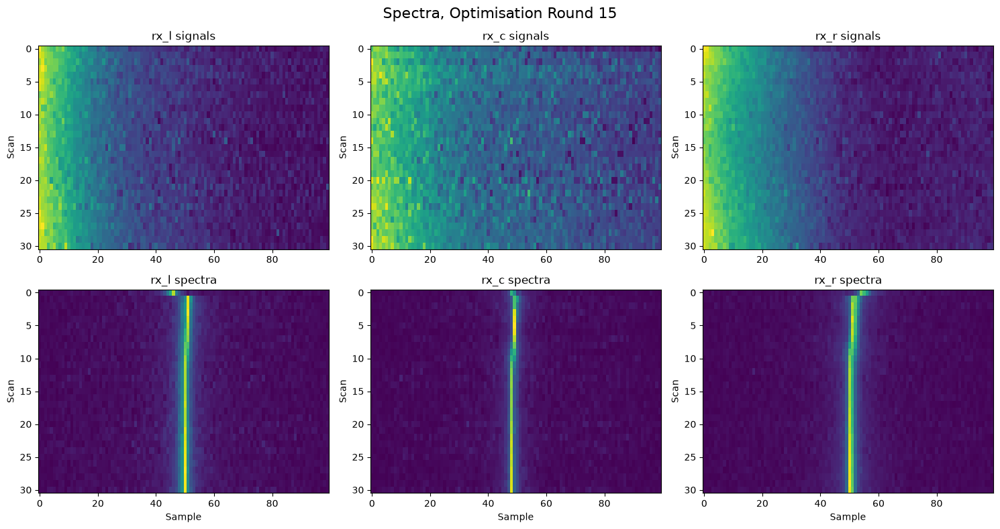

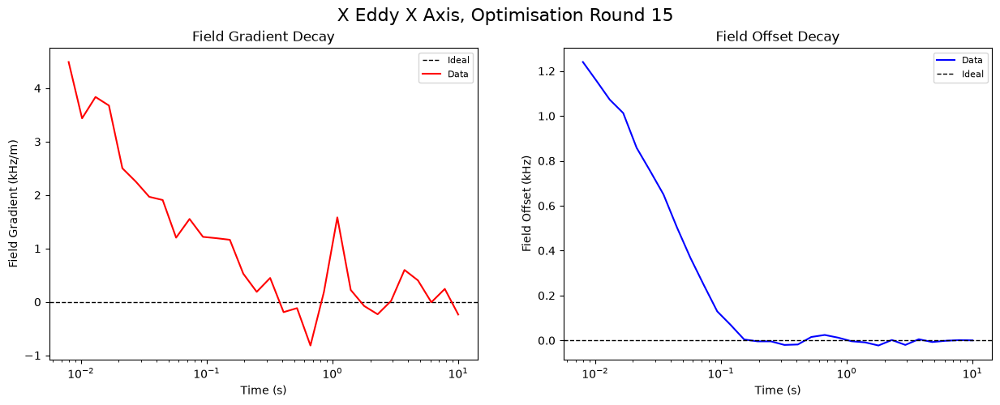

[I 2026-11-26 11:17:04,301] Trial 15 finished with value: 109.12330210433974 and parameters: {'X_A1': -0.025844127709314695, 'X_A2': 0.015367147755531026, 'X_A3': -1.2389125322230033e-08, 'X_A4': -8.922652823661834e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.091e+02
Total cost = 1.091e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.08255209599350044
B nanmax = 0.08255209599350044
B contains nan = False
Trial 16


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.08173037860888004 !!!!!!!!!!!!!!!!


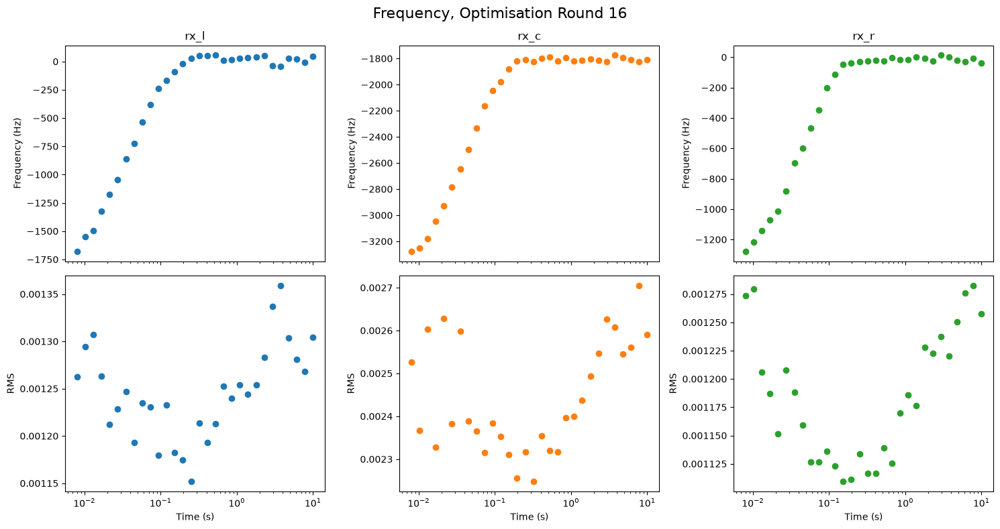

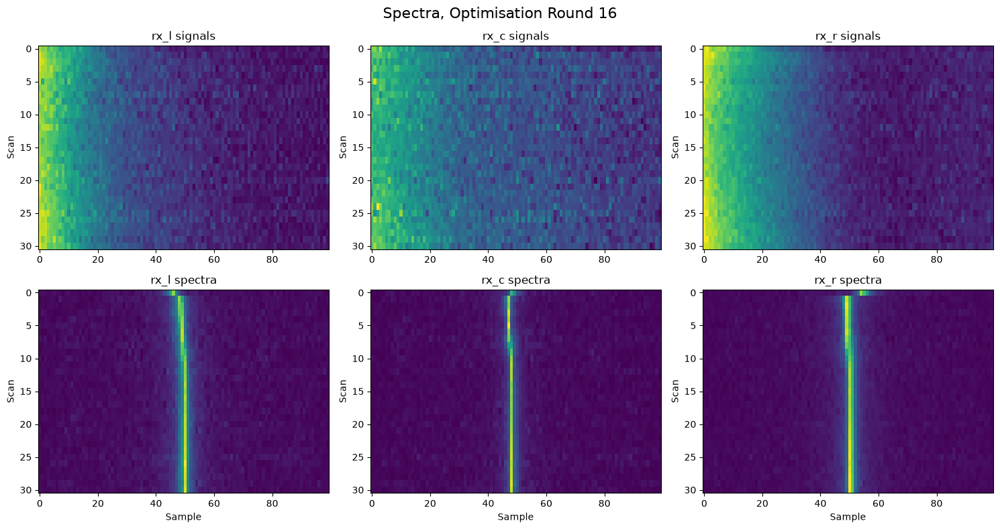

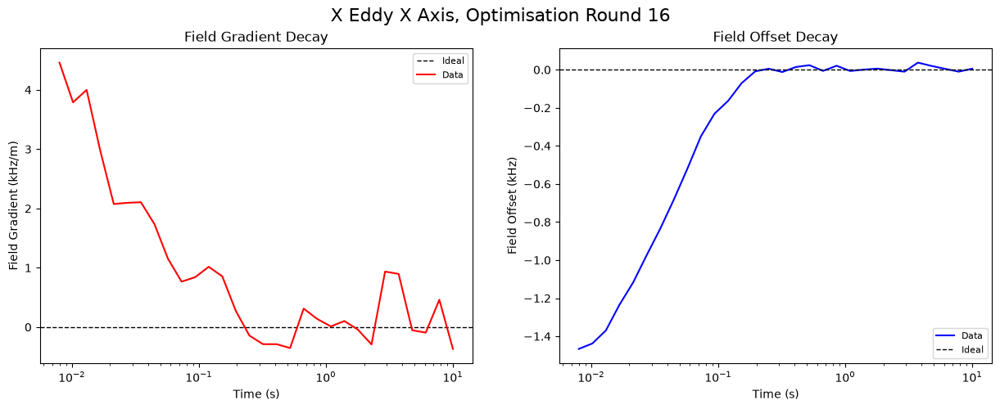

[I 2026-11-26 11:18:29,588] Trial 16 finished with value: 184.8844040743091 and parameters: {'X_A1': -0.02205820836003866, 'X_A2': 0.03302877350669274, 'X_A3': -1.2373643857480393e-08, 'X_A4': 3.7951229618380346e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.849e+02
Total cost = 1.849e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.03532716252765592
B nanmax = 0.03532716252765592
B contains nan = False
Trial 17


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.03497550249692123 !!!!!!!!!!!!!!!!


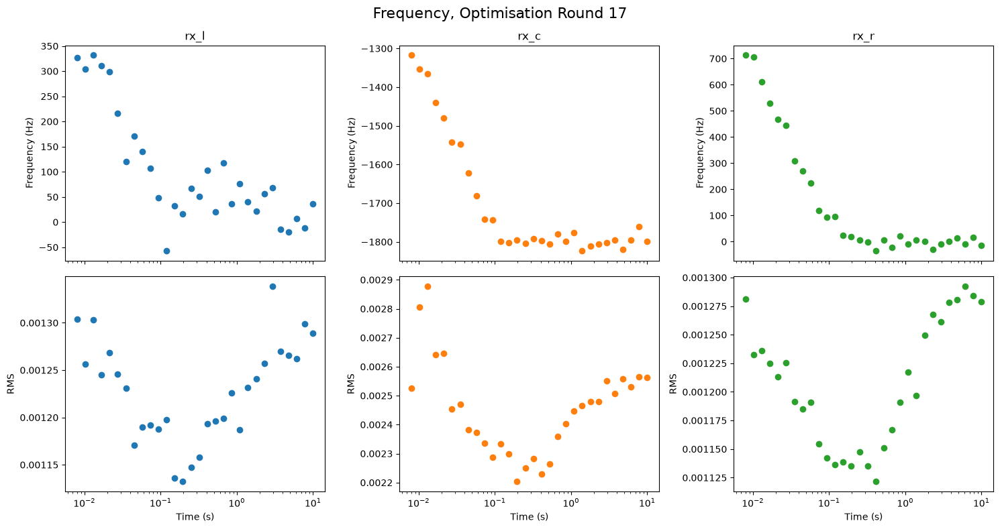

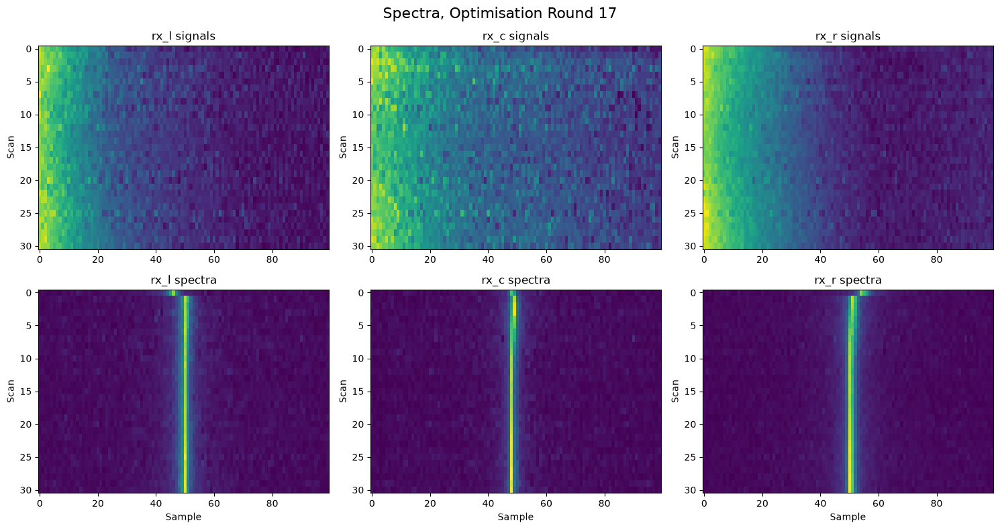

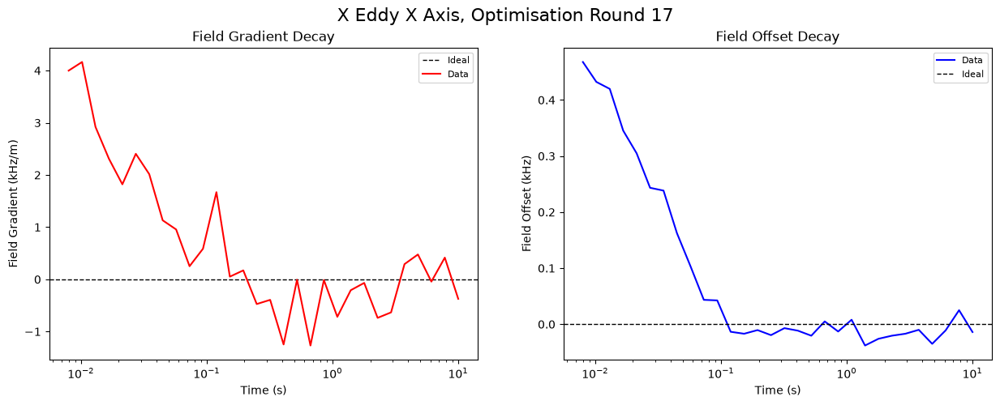

[I 2026-11-26 11:19:53,597] Trial 17 finished with value: 207.77681441019098 and parameters: {'X_A1': -0.020159330780949607, 'X_A2': 0.015473044034632103, 'X_A3': -1.0602545552359927e-08, 'X_A4': -6.544661642047243e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 2.078e+02
Total cost = 2.078e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.14289483007365933
B nanmax = 0.14289483007365933
B contains nan = False
Trial 18


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.14147242470877053 !!!!!!!!!!!!!!!!


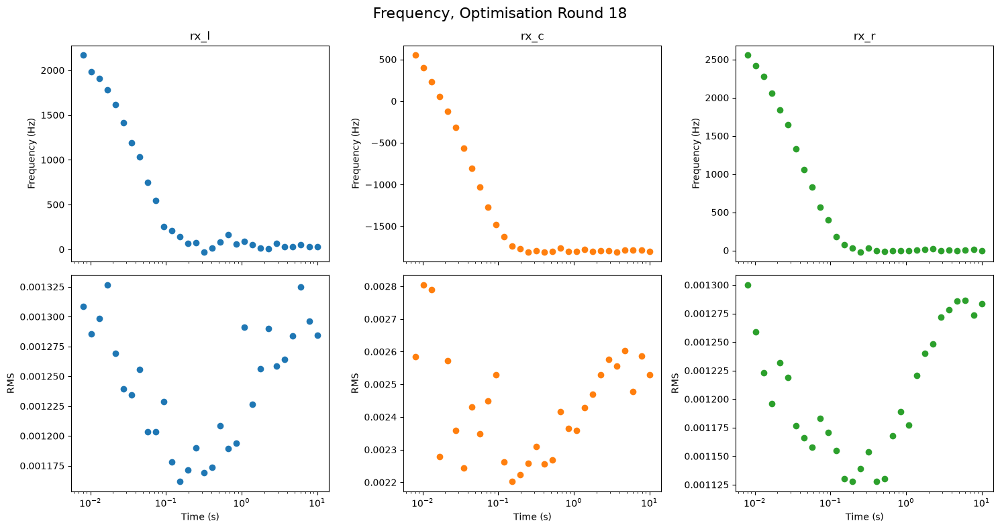

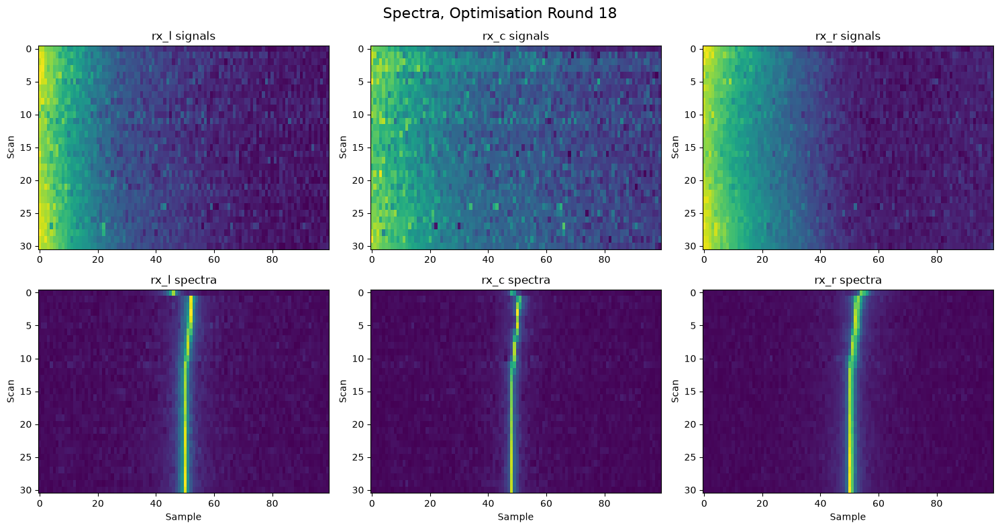

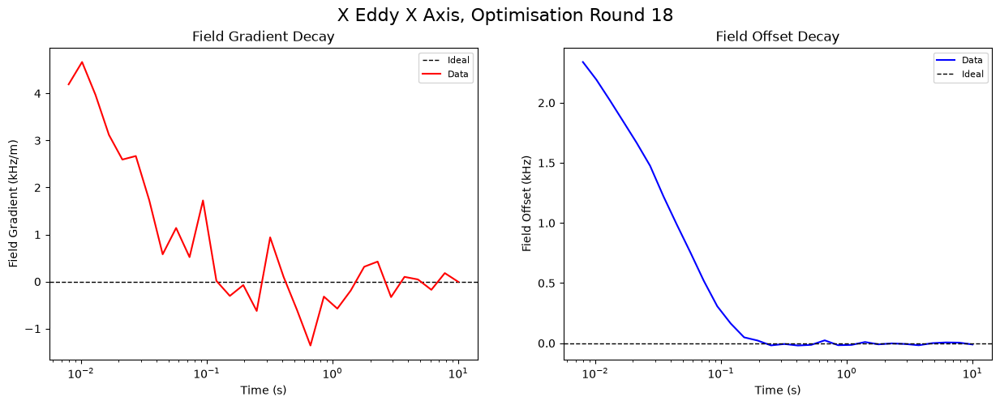

[I 2026-11-26 11:21:17,475] Trial 18 finished with value: 175.0037720656 and parameters: {'X_A1': -0.03705435370450863, 'X_A2': 0.018086118947922985, 'X_A3': -1.1481747549057991e-08, 'X_A4': 1.6363432332692125e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.750e+02
Total cost = 1.750e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.03311011208237487
B nanmax = 0.03311011208237487
B contains nan = False
Trial 19


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.03278051759592386 !!!!!!!!!!!!!!!!


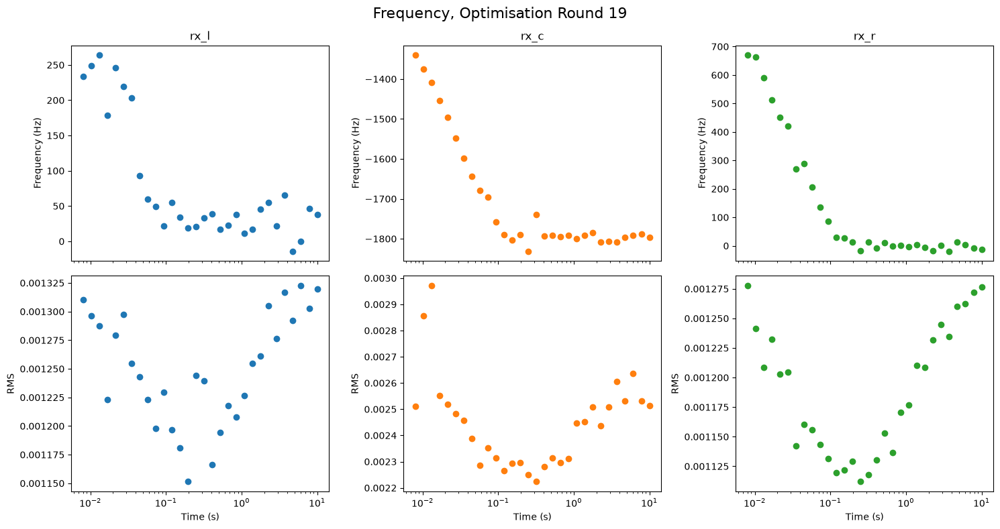

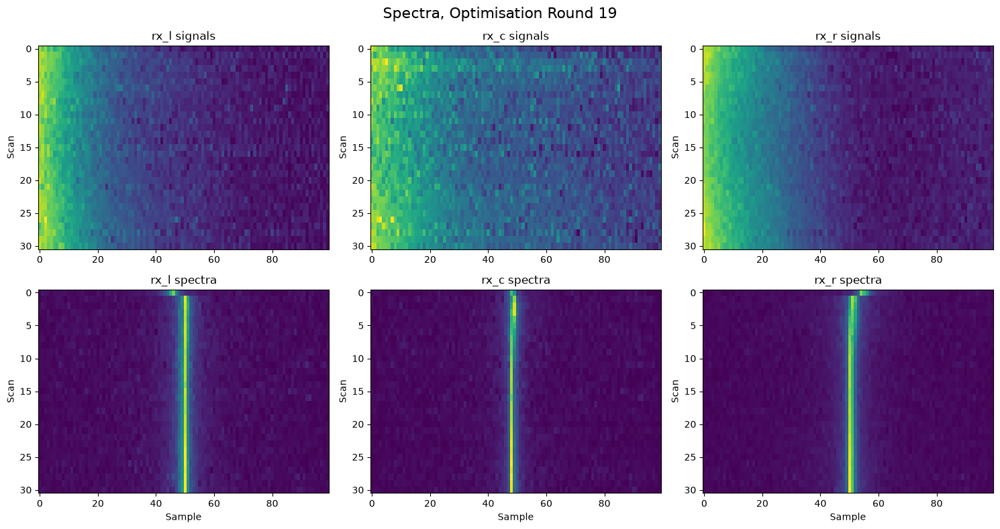

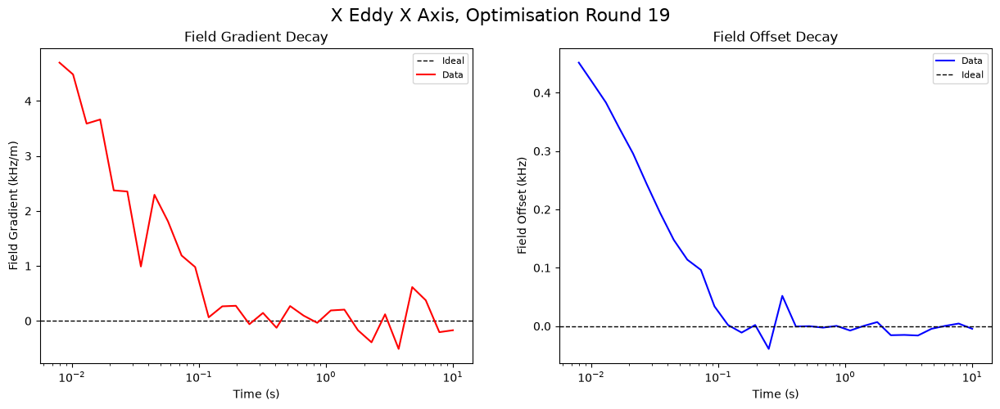

[I 2026-11-26 11:22:43,252] Trial 19 finished with value: 82.32761195017906 and parameters: {'X_A1': -0.025917857127918782, 'X_A2': 0.02152767188715987, 'X_A3': -1.2223633050877565e-08, 'X_A4': 2.1765979624401623e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 8.233e+01
Total cost = 8.233e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0340715817011529
B nanmax = 0.0340715817011529
B contains nan = False
Trial 20


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.03373241417233395 !!!!!!!!!!!!!!!!


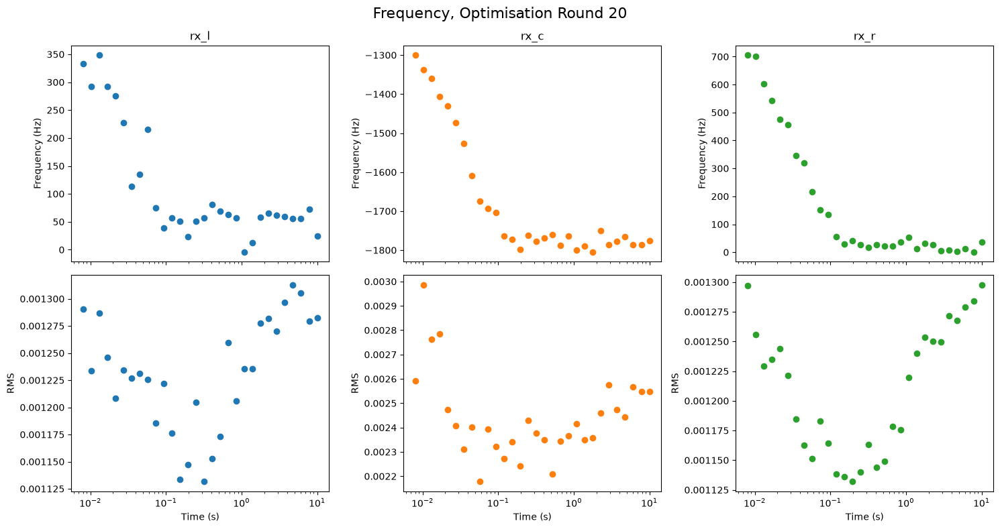

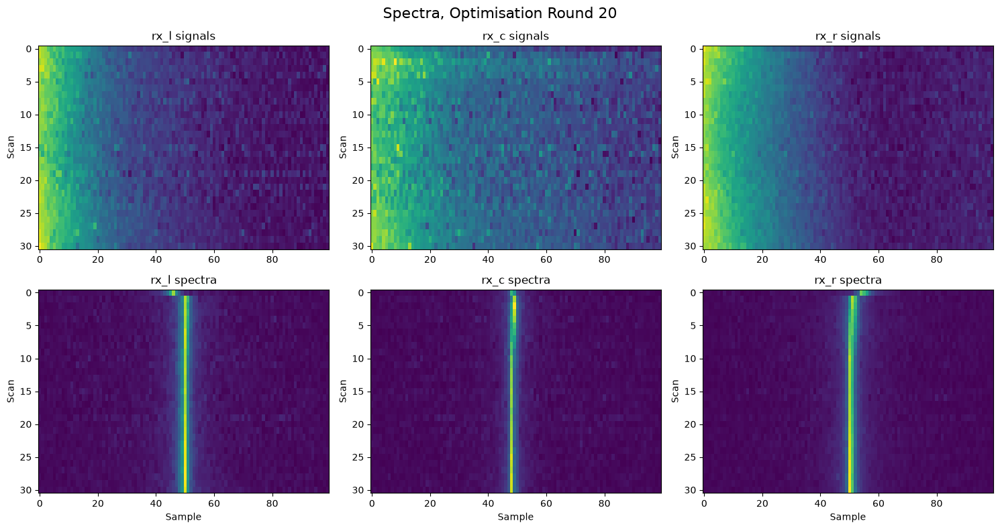

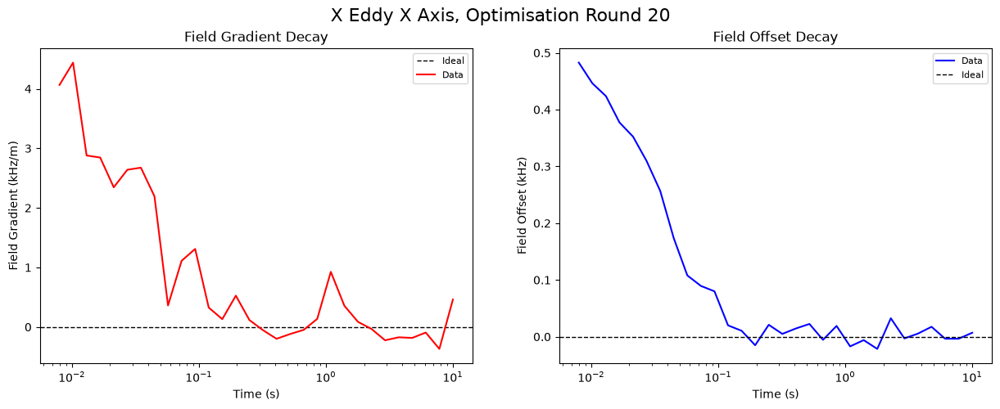

[I 2026-11-26 11:24:07,262] Trial 20 finished with value: 113.02012124096403 and parameters: {'X_A1': -0.030525261418127166, 'X_A2': 0.026008689805659263, 'X_A3': -1.226080244671385e-08, 'X_A4': -7.309010227354538e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.130e+02
Total cost = 1.130e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.029889011631760783
B nanmax = 0.029889011631760783
B contains nan = False
Trial 21


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.029591480412385865 !!!!!!!!!!!!!!!!


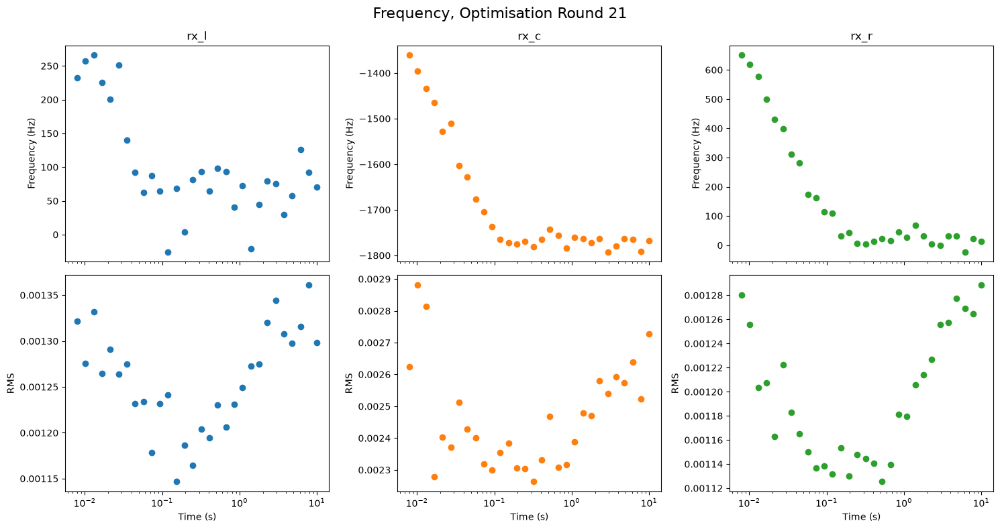

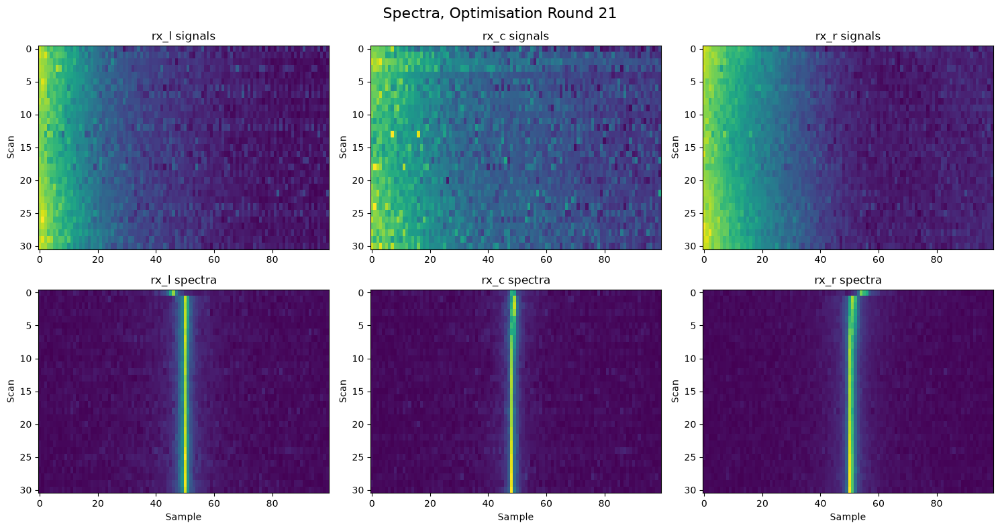

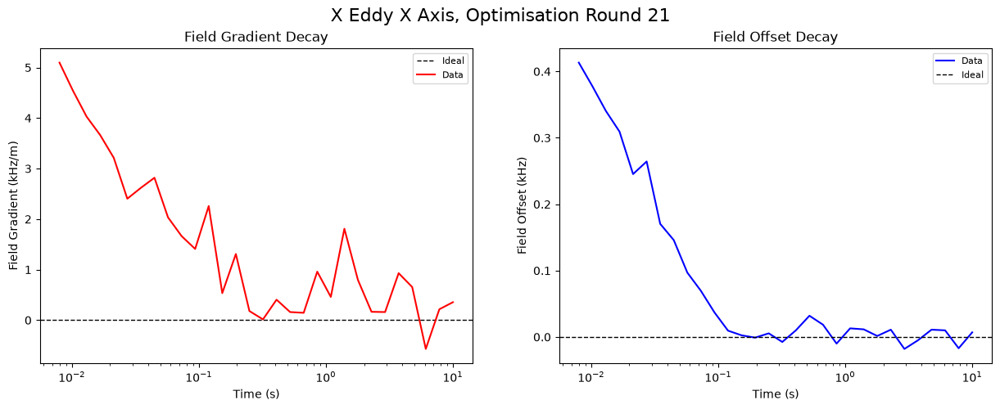

[I 2026-11-26 11:25:31,788] Trial 21 finished with value: 126.25455174492765 and parameters: {'X_A1': -0.025538847078766084, 'X_A2': 0.021576369154910457, 'X_A3': -9.418744866315587e-09, 'X_A4': 4.566162140821399e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.263e+02
Total cost = 1.263e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0022827022895585865
B nanmax = 0.0022827022895585865
B contains nan = False
Trial 22


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.002259996594531524 !!!!!!!!!!!!!!!!


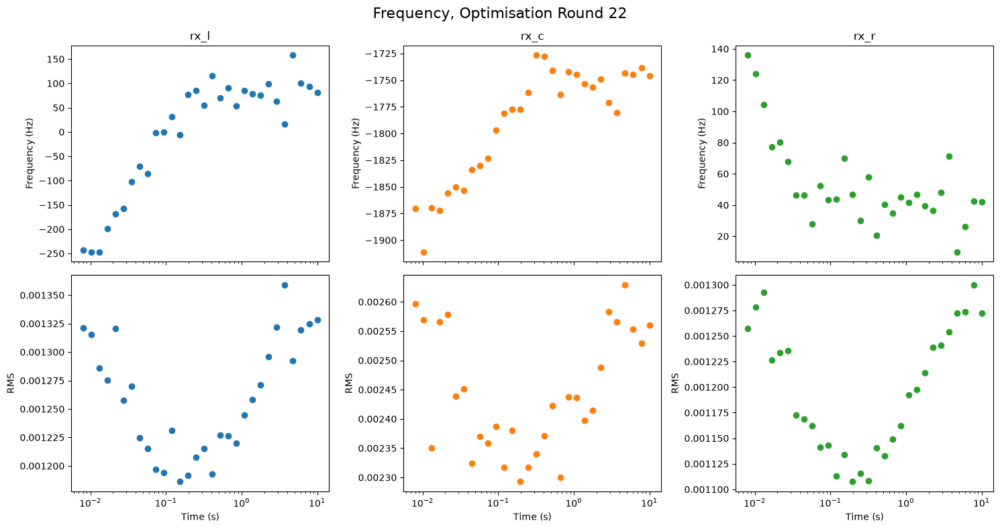

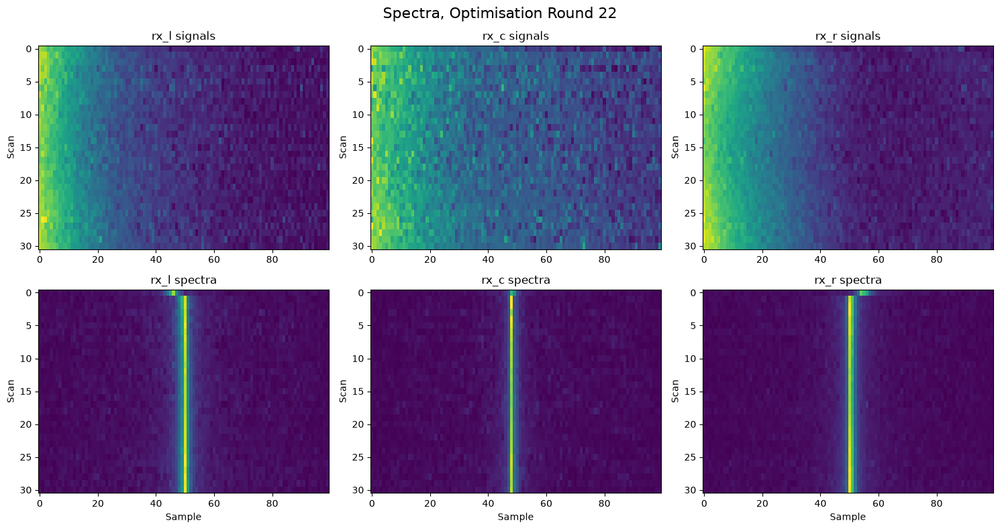

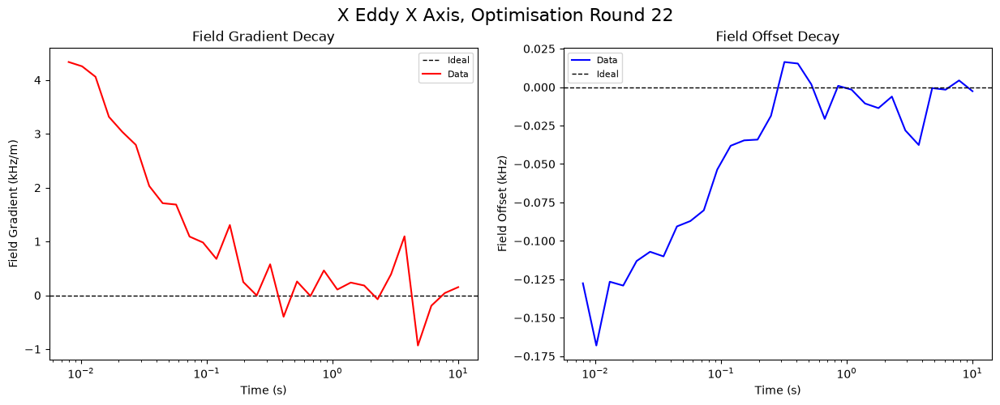

[I 2026-11-26 11:26:55,639] Trial 22 finished with value: 104.50102935747073 and parameters: {'X_A1': -0.030307341321643366, 'X_A2': 0.030619156493478246, 'X_A3': -1.1118992424432215e-08, 'X_A4': 5.412962745403167e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.045e+02
Total cost = 1.045e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.057539589380002296
B nanmax = 0.057539589380002296
B contains nan = False
Trial 23


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.05696684691473096 !!!!!!!!!!!!!!!!


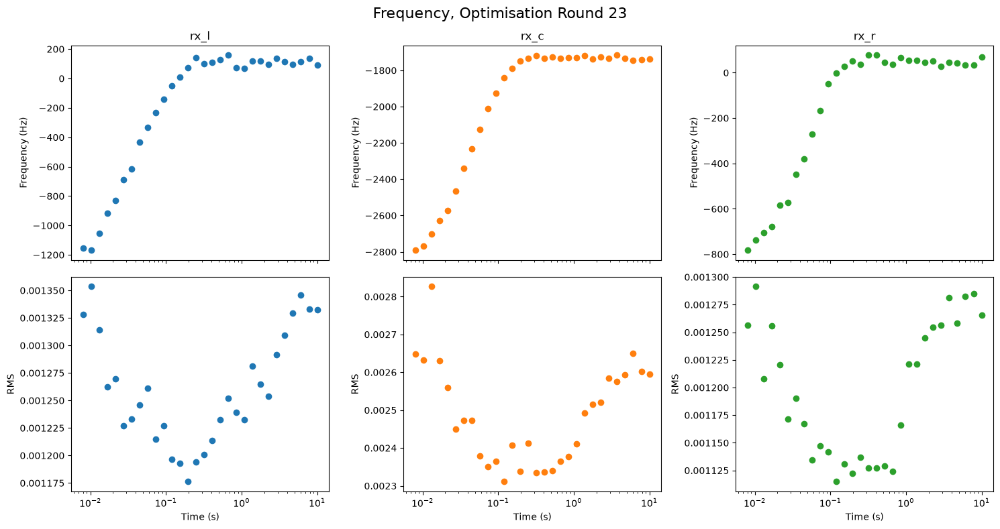

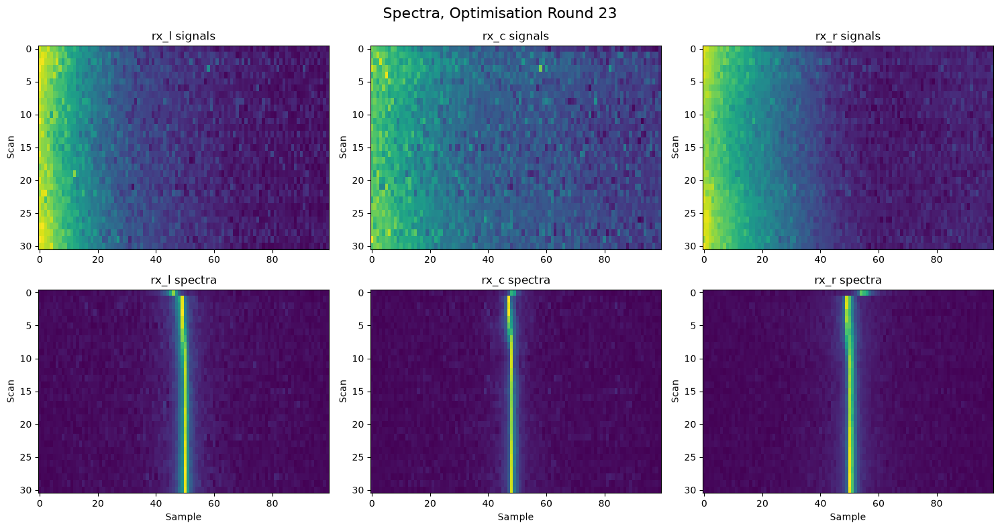

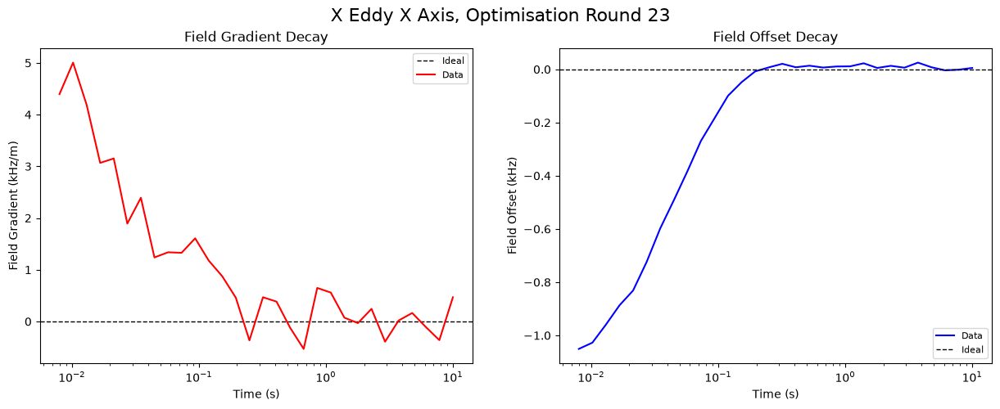

[I 2026-11-26 11:28:18,171] Trial 23 finished with value: 130.0394039651412 and parameters: {'X_A1': -0.019604646157703805, 'X_A2': 0.027252438617695718, 'X_A3': -1.2277540980926401e-08, 'X_A4': -8.886452728960111e-10}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.300e+02
Total cost = 1.300e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.004681104549795957
B nanmax = 0.004681104549795957
B contains nan = False
Trial 24


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.004634494772470242 !!!!!!!!!!!!!!!!


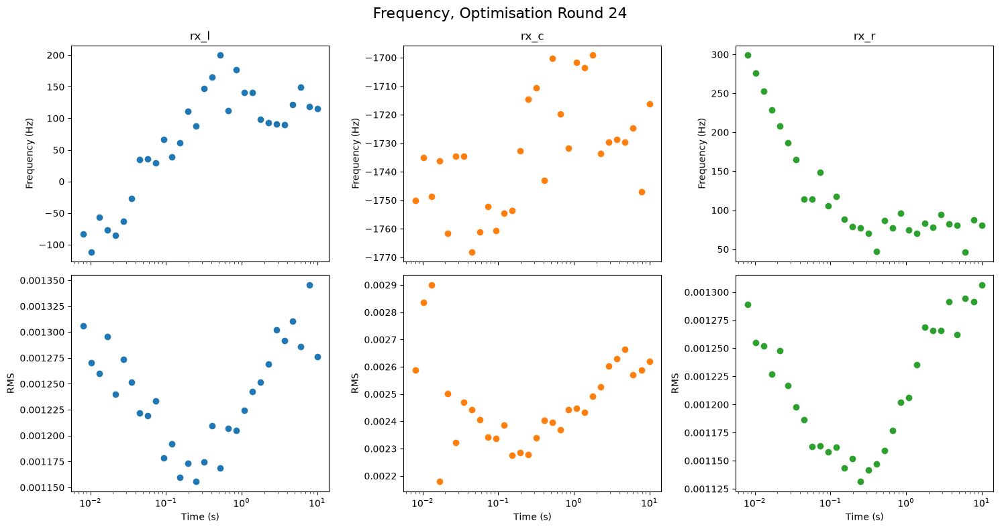

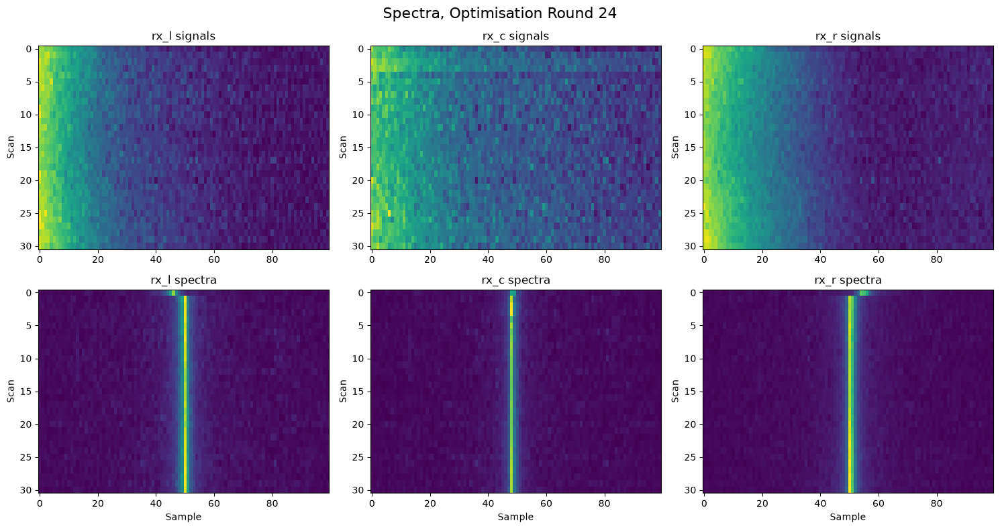

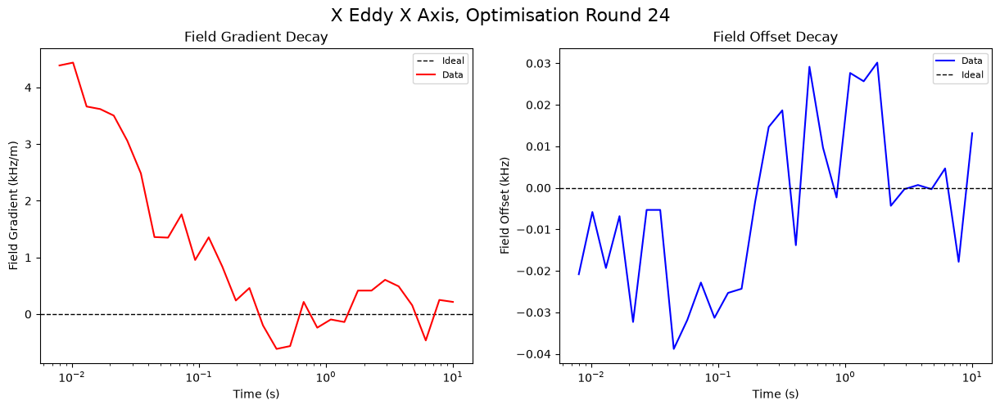

[I 2026-11-26 11:29:43,931] Trial 24 finished with value: 103.51557625257496 and parameters: {'X_A1': -0.025248087350655094, 'X_A2': 0.024633552656293745, 'X_A3': -1.0875825351523667e-08, 'X_A4': -1.5846245518155796e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.035e+02
Total cost = 1.035e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.02891592992092412
B nanmax = 0.02891592992092412
B contains nan = False
Trial 25


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.028628080056647638 !!!!!!!!!!!!!!!!


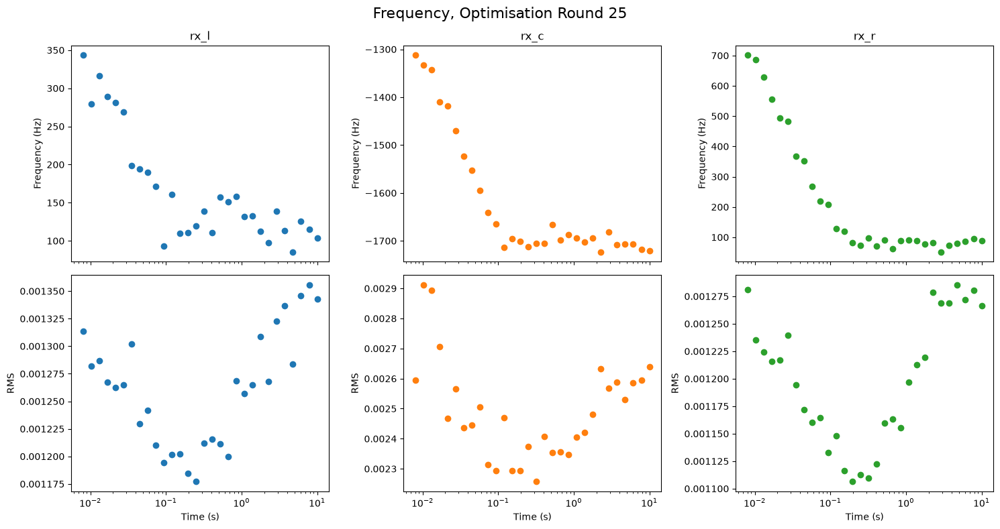

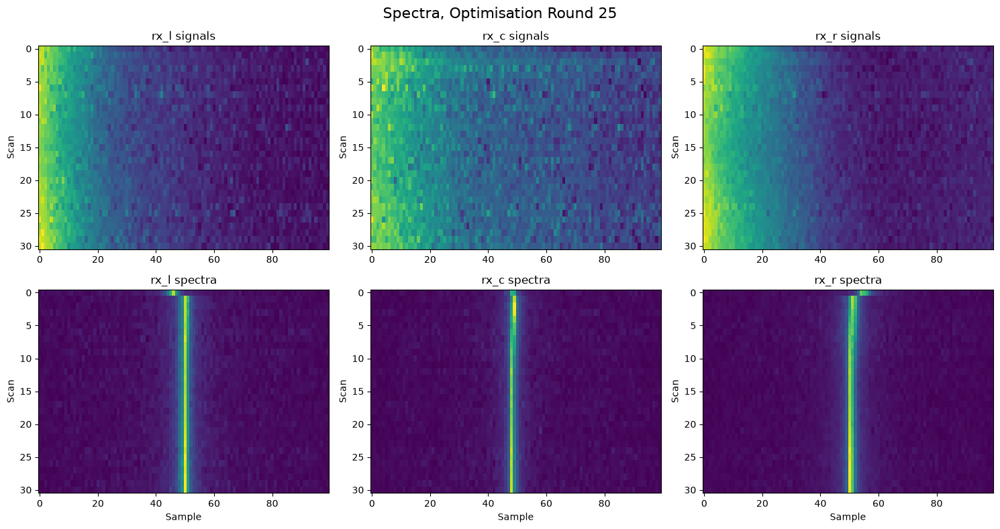

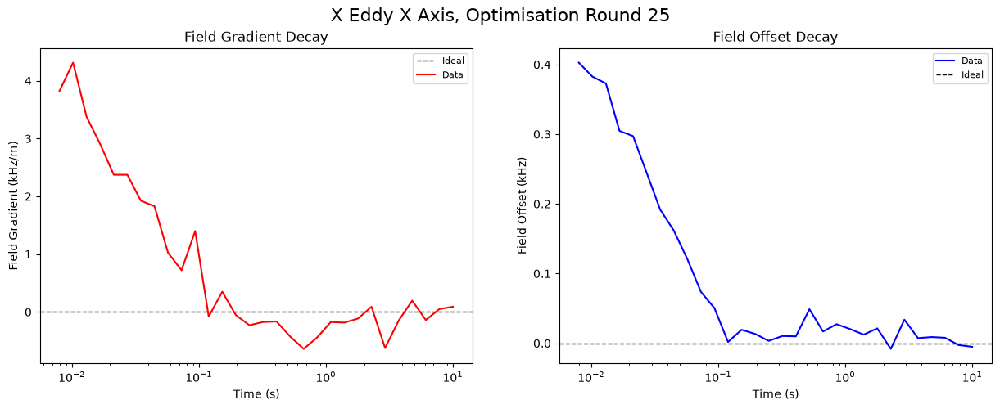

[I 2026-11-26 11:31:09,947] Trial 25 finished with value: 121.69716020556294 and parameters: {'X_A1': -0.03430654992718838, 'X_A2': 0.03047581125349429, 'X_A3': -1.209042178819515e-08, 'X_A4': 2.997666831817749e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.217e+02
Total cost = 1.217e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.023231924311776255
B nanmax = 0.023231924311776255
B contains nan = False
Trial 26


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.023000655578315304 !!!!!!!!!!!!!!!!


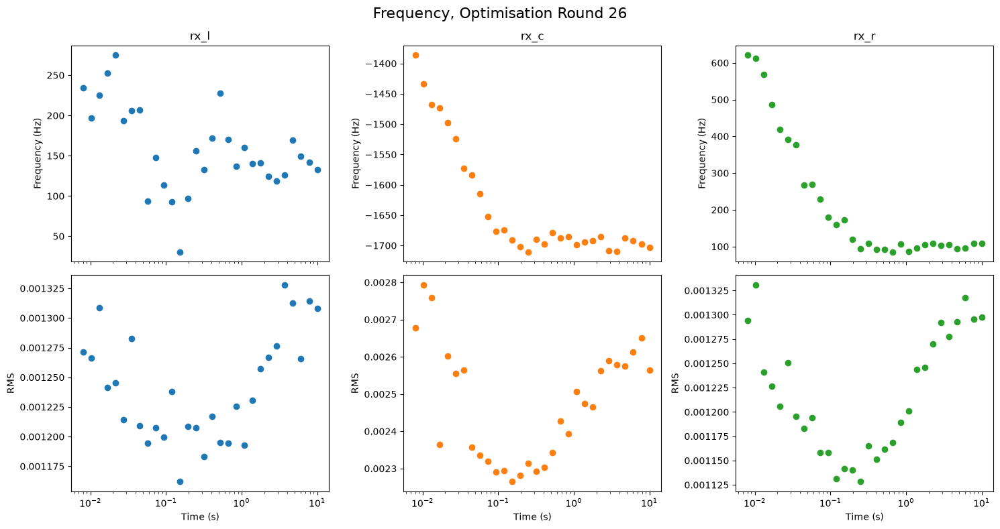

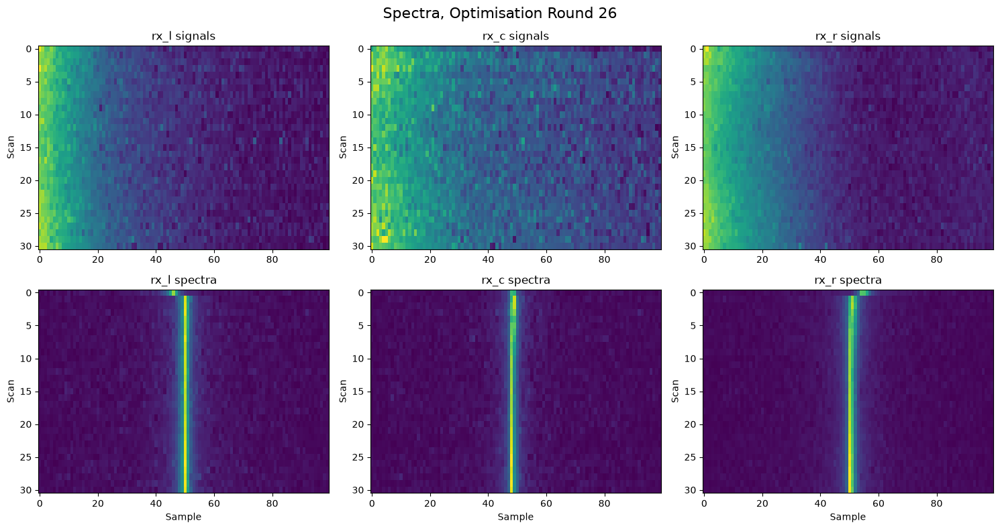

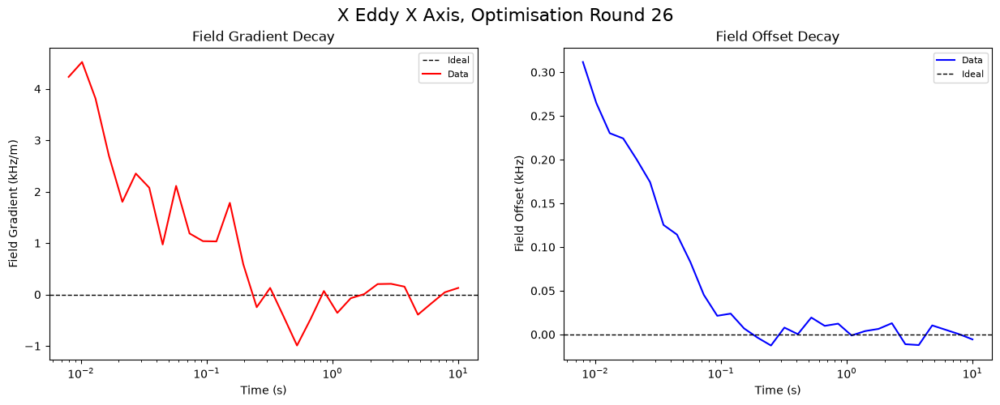

[I 2026-11-26 11:32:32,702] Trial 26 finished with value: 77.48348895071702 and parameters: {'X_A1': -0.030375128985297255, 'X_A2': 0.027298199988369565, 'X_A3': -8.944809805305056e-09, 'X_A4': -3.4055148136676004e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 7.748e+01
Total cost = 7.748e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.049835132271195653
B nanmax = 0.049835132271195653
B contains nan = False
Trial 27


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.04933905698249243 !!!!!!!!!!!!!!!!


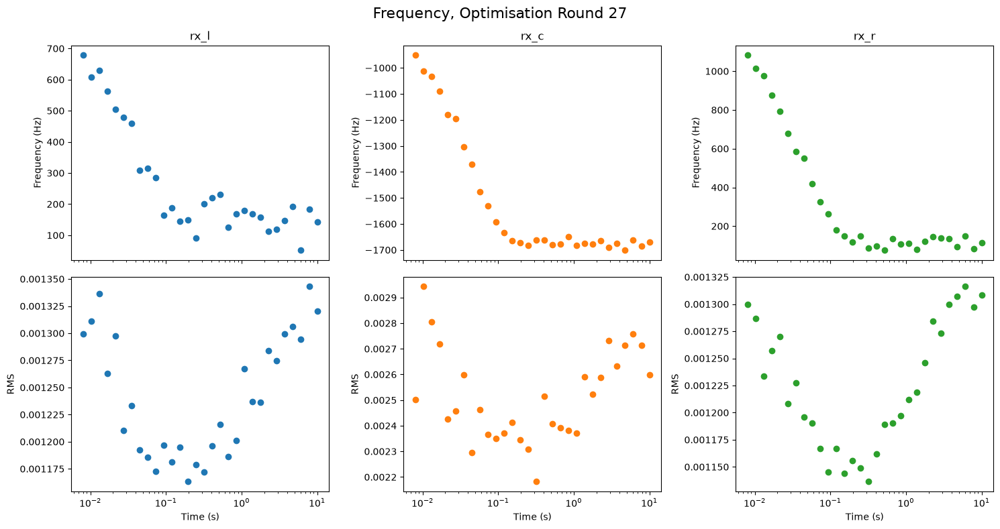

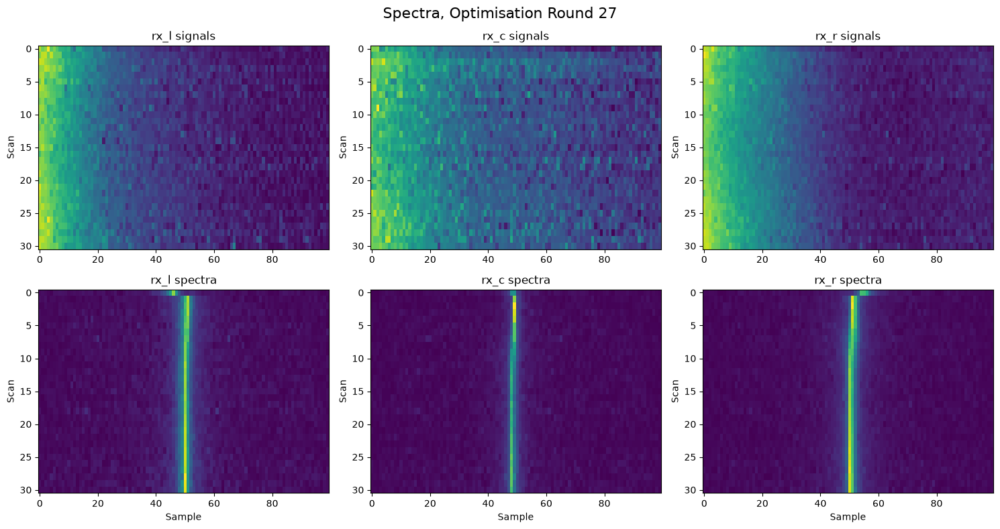

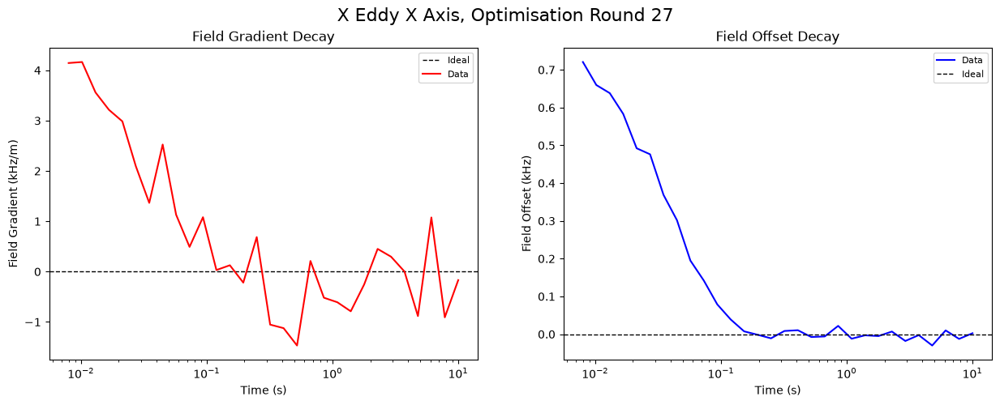

[I 2026-11-26 11:33:55,476] Trial 27 finished with value: 140.82097433643426 and parameters: {'X_A1': -0.023660885673622397, 'X_A2': 0.01704869872133539, 'X_A3': -1.101049197433235e-08, 'X_A4': -1.8849956074570997e-10}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.408e+02
Total cost = 1.408e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.02751682860789328
B nanmax = 0.02751682860789328
B contains nan = False
Trial 28


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.02724293577609519 !!!!!!!!!!!!!!!!


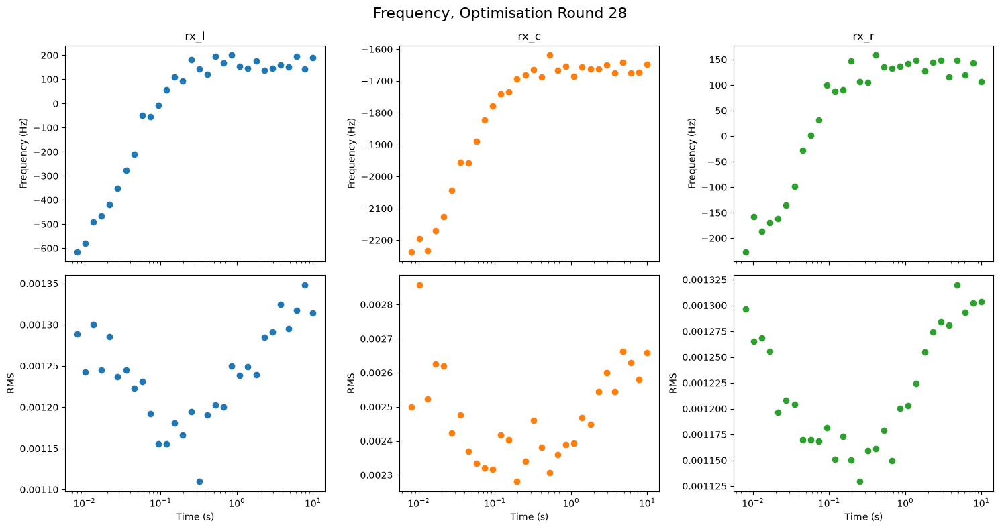

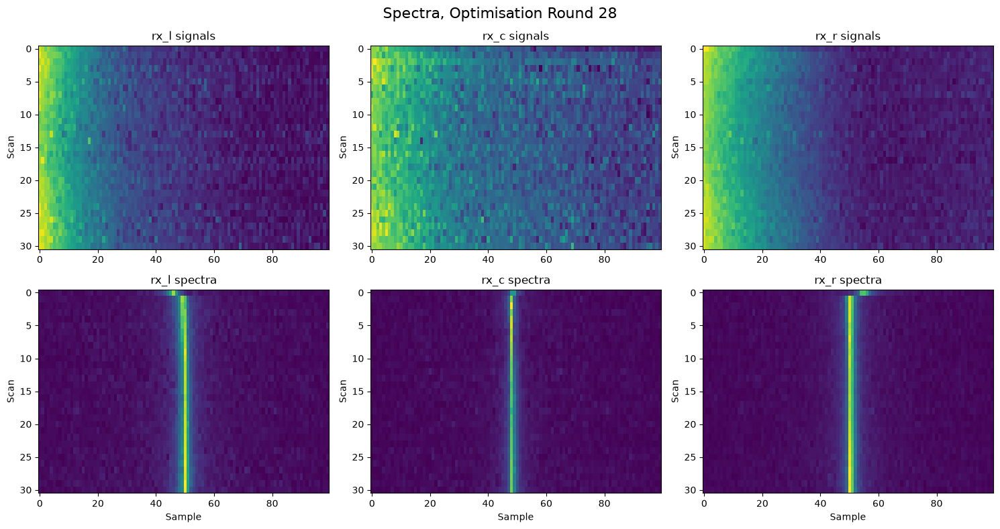

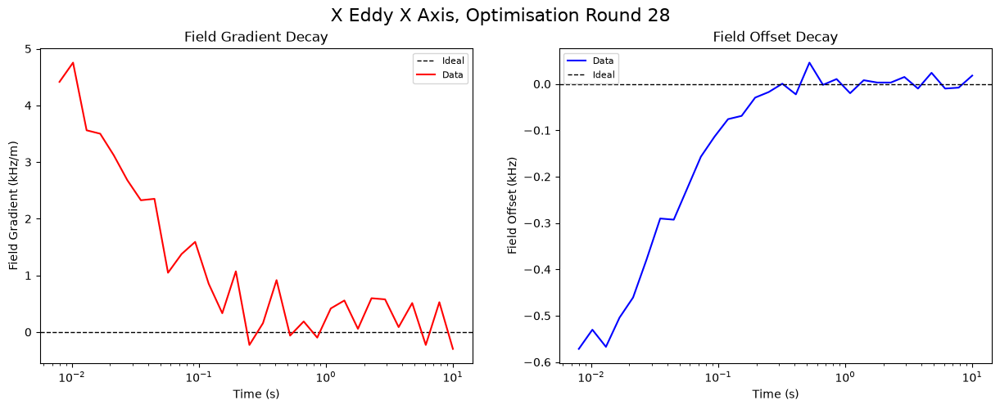

[I 2026-11-26 11:35:19,133] Trial 28 finished with value: 153.89837487923666 and parameters: {'X_A1': -0.021363318263280792, 'X_A2': 0.025024093675844752, 'X_A3': -1.1454288067243041e-08, 'X_A4': 6.23942654025608e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.539e+02
Total cost = 1.539e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.04653705819932233
B nanmax = 0.04653705819932233
B contains nan = False
Trial 29


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.046073812425180105 !!!!!!!!!!!!!!!!


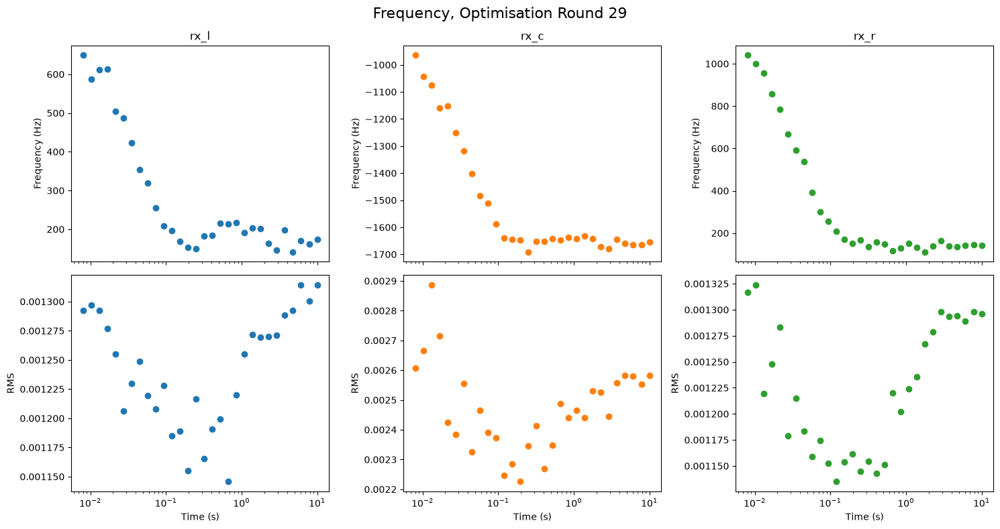

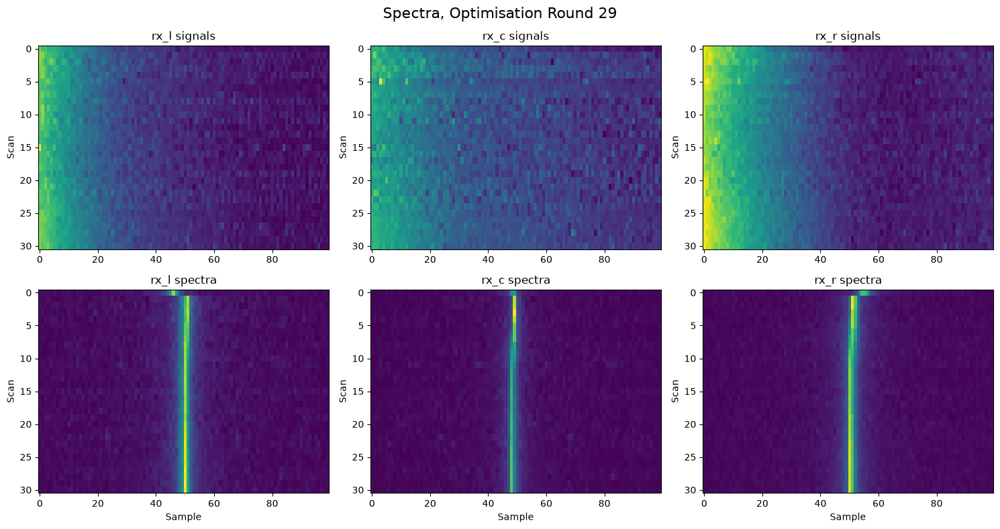

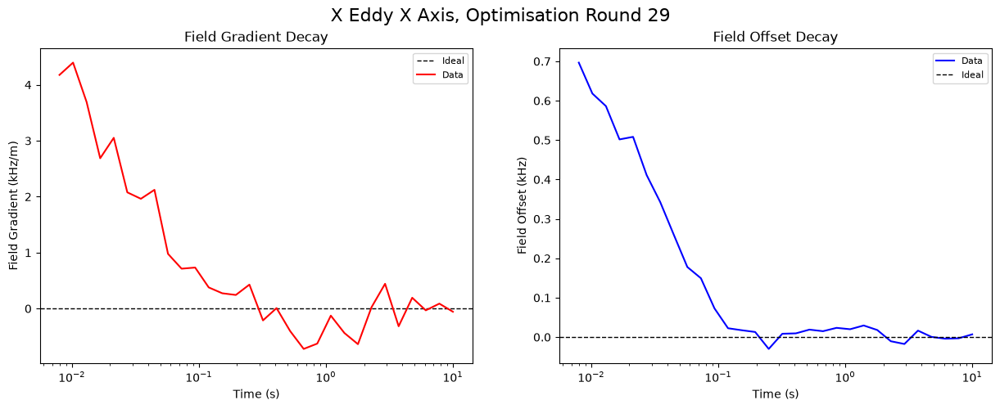

[I 2026-11-26 11:36:40,228] Trial 29 finished with value: 117.81498288982944 and parameters: {'X_A1': -0.023196137285694297, 'X_A2': 0.017021856590448754, 'X_A3': -1.233048652159352e-08, 'X_A4': 4.135104452878925e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.178e+02
Total cost = 1.178e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.012048298140914833
B nanmax = 0.012048298140914833
B contains nan = False
Trial 30


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01192838395421177 !!!!!!!!!!!!!!!!


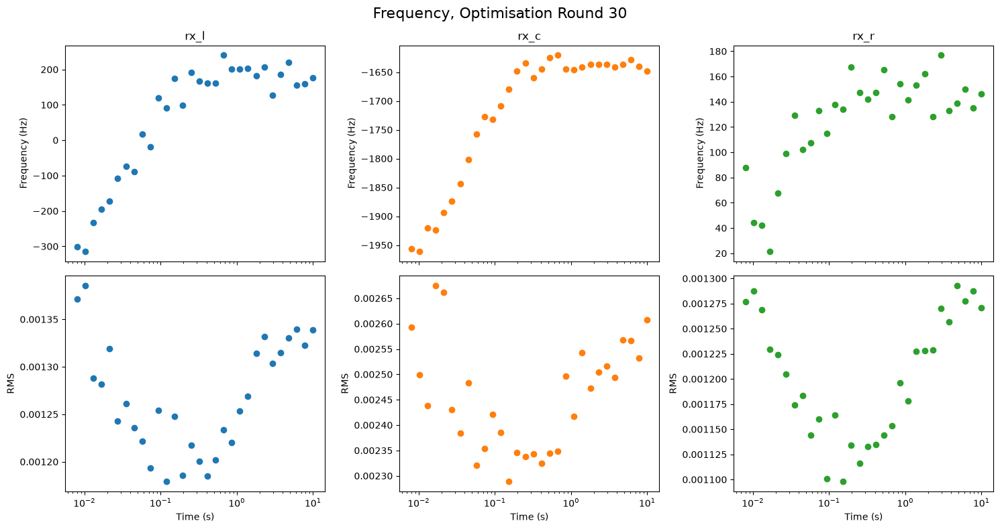

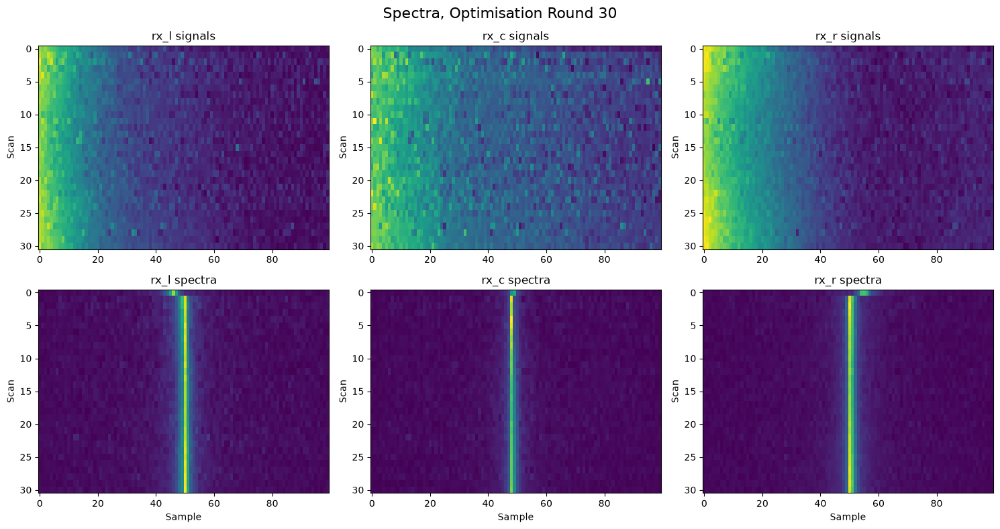

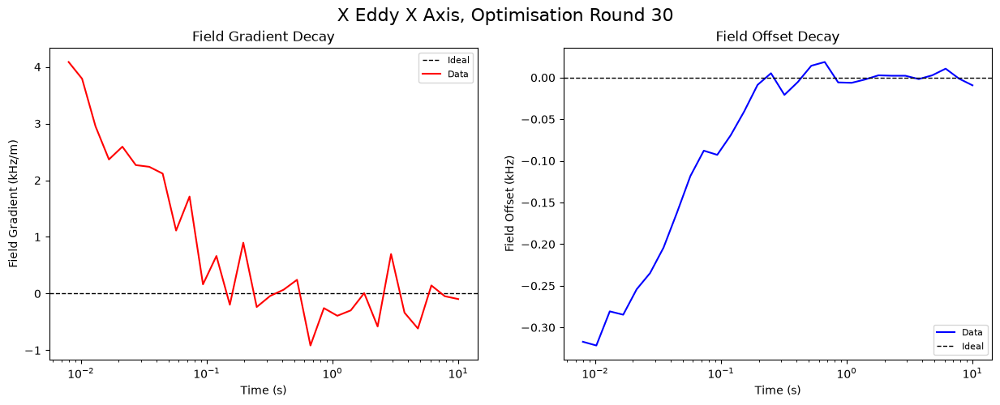

[I 2026-11-26 11:38:02,072] Trial 30 finished with value: 68.286800171215 and parameters: {'X_A1': -0.02835438360191788, 'X_A2': 0.02996267466239221, 'X_A3': -1.1244445327169076e-08, 'X_A4': 9.003262110500355e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 6.829e+01
Total cost = 6.829e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.004802009999420248
B nanmax = 0.004802009999420248
B contains nan = False
Trial 31


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.004754220150923549 !!!!!!!!!!!!!!!!


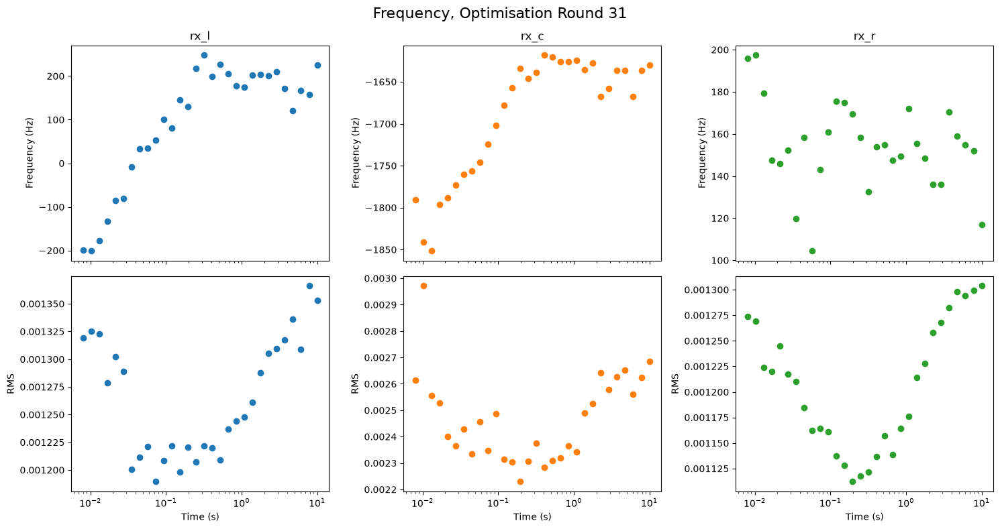

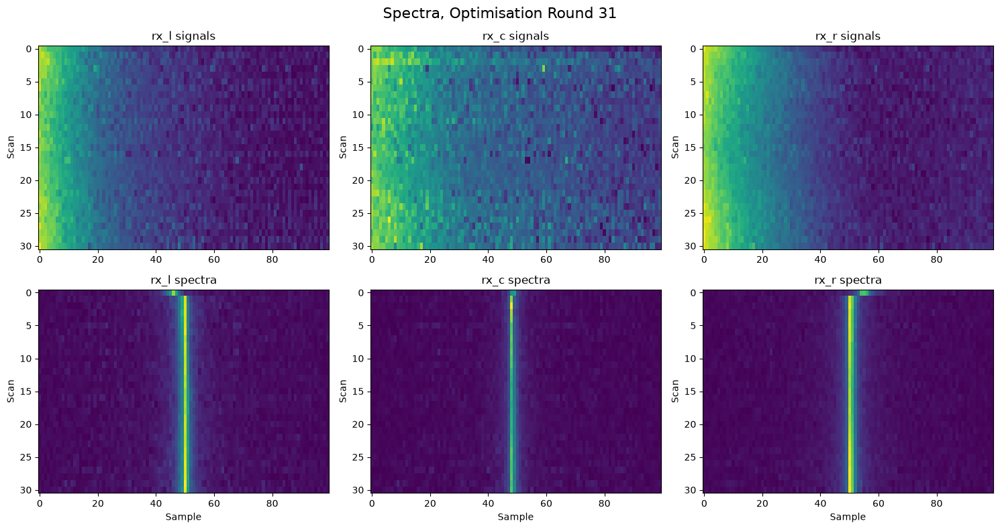

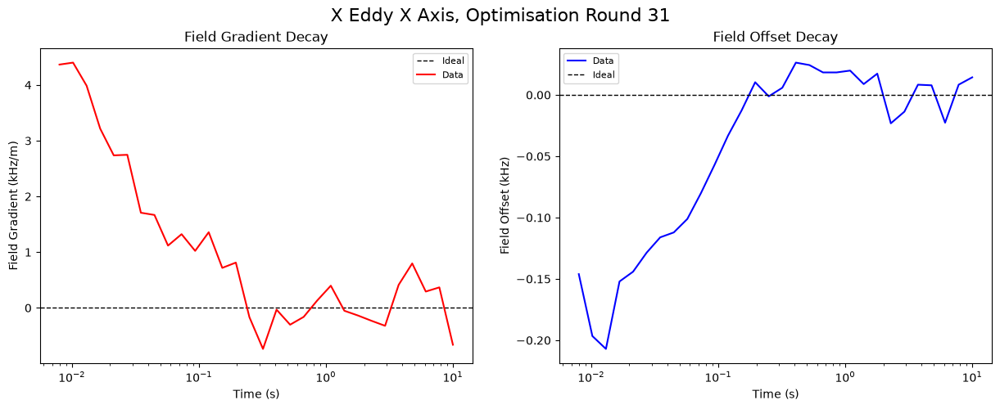

[I 2026-11-26 11:39:25,374] Trial 31 finished with value: 147.81787534148953 and parameters: {'X_A1': -0.017829263816599033, 'X_A2': 0.01847212959350821, 'X_A3': -1.2378645693065372e-08, 'X_A4': -4.700920309394646e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.478e+02
Total cost = 1.478e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.013936542993423518
B nanmax = 0.013936542993423518
B contains nan = False
Trial 32


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013797801217728719 !!!!!!!!!!!!!!!!


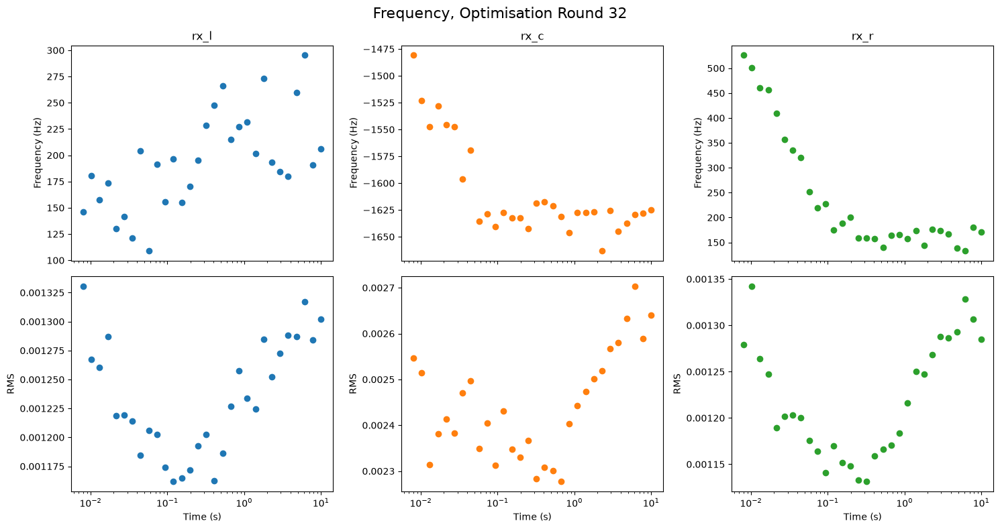

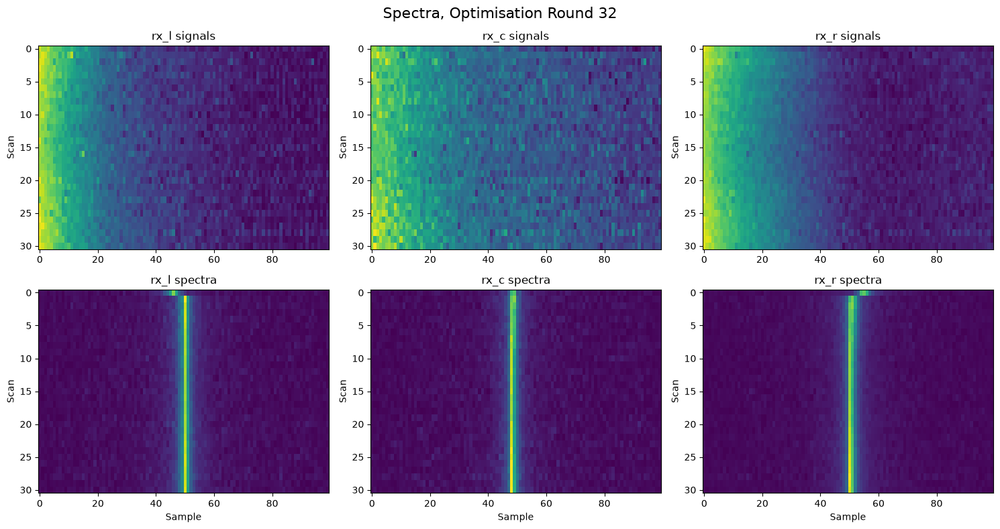

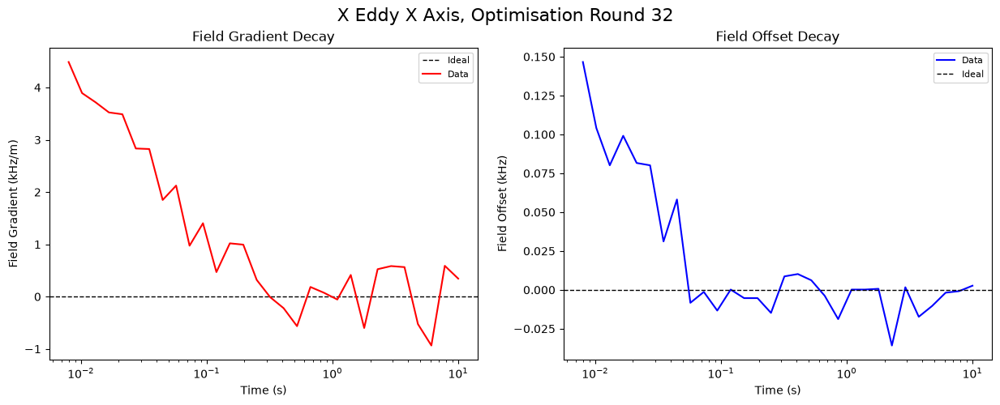

[I 2026-11-26 11:40:47,862] Trial 32 finished with value: 69.61082741214385 and parameters: {'X_A1': -0.0302336937789899, 'X_A2': 0.02839130452797746, 'X_A3': -1.0968255739091493e-08, 'X_A4': 9.267043202637015e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 6.961e+01
Total cost = 6.961e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.06462713474720454
B nanmax = 0.06462713474720454
B contains nan = False
Trial 33


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.06398384246233021 !!!!!!!!!!!!!!!!


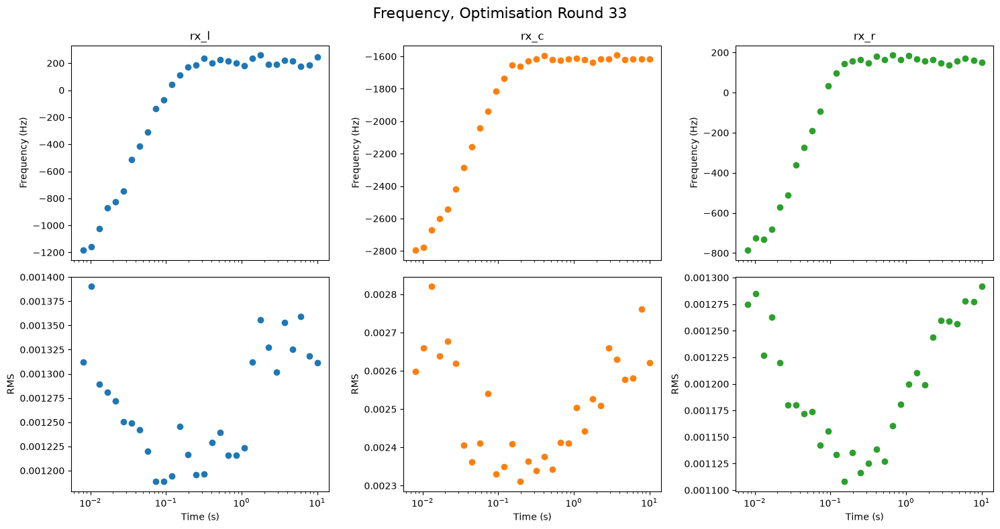

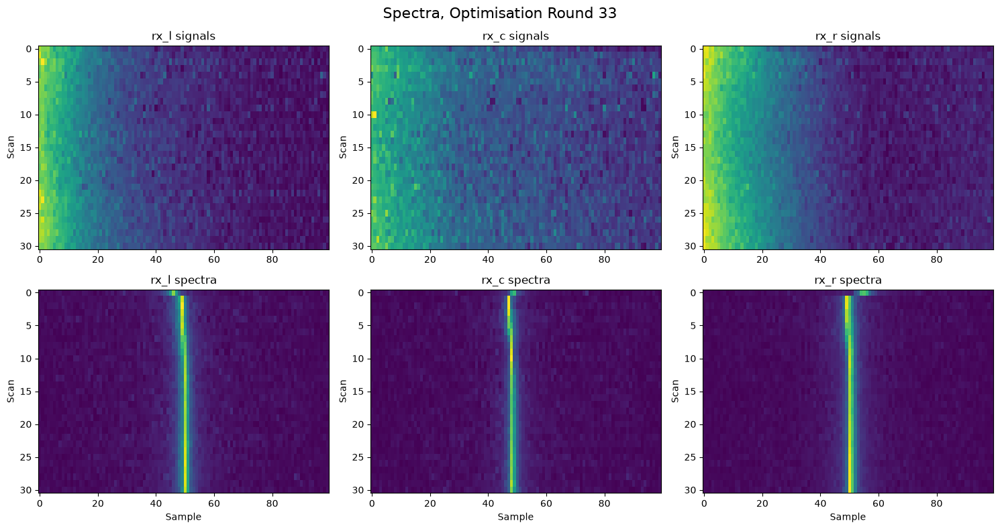

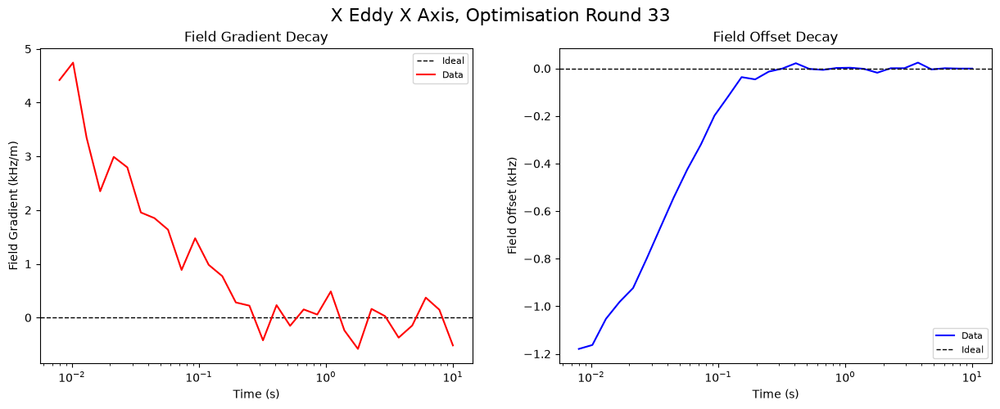

[I 2026-11-26 11:42:11,517] Trial 33 finished with value: 103.49482902570955 and parameters: {'X_A1': -0.019800553220251566, 'X_A2': 0.02838974448547841, 'X_A3': -1.2333073724388283e-08, 'X_A4': 7.2813183436716975e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.035e+02
Total cost = 1.035e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.007383782915272466
B nanmax = 0.007383782915272466
B contains nan = False
Trial 34


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.007310271338048133 !!!!!!!!!!!!!!!!


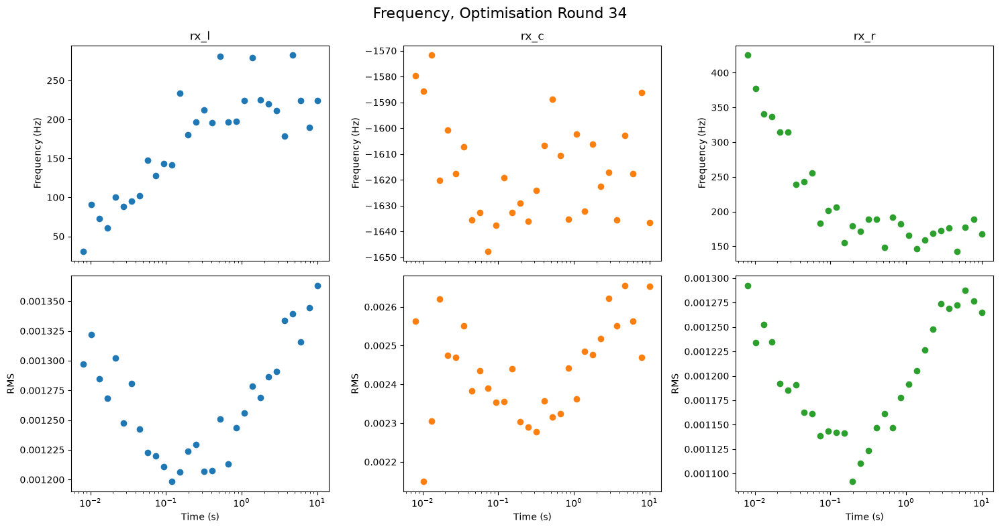

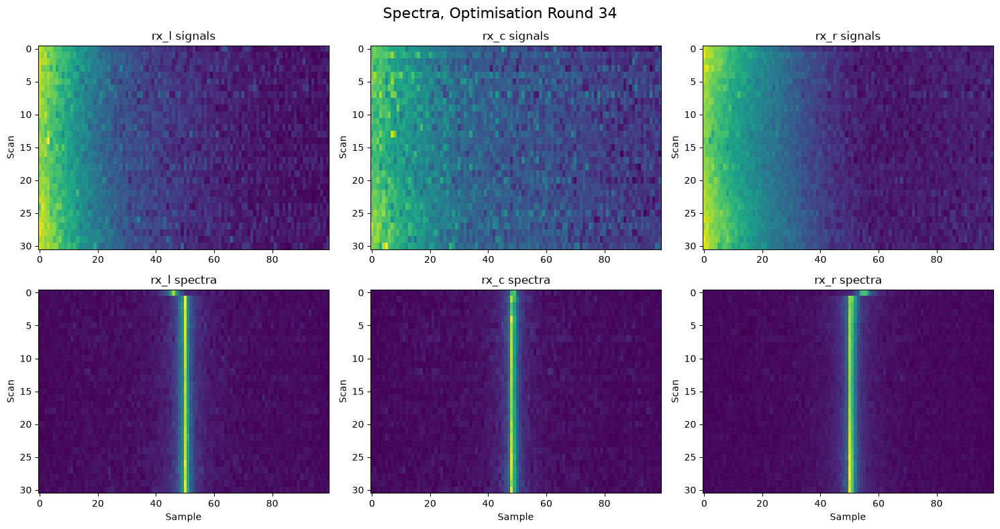

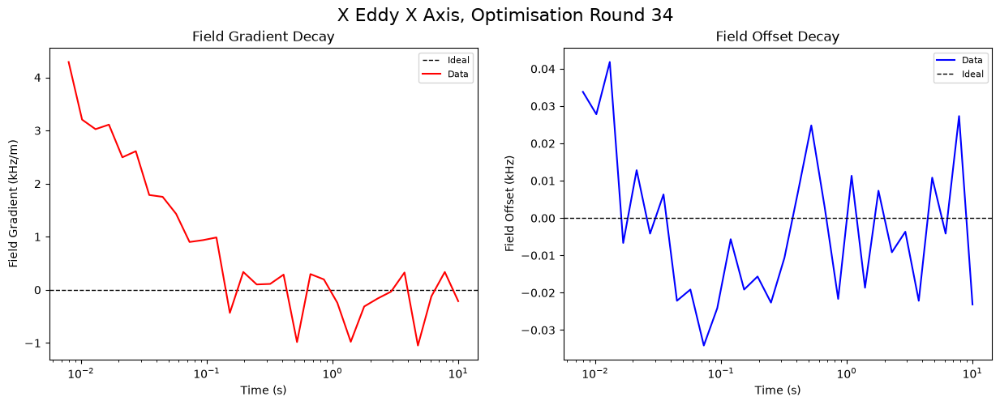

[I 2026-11-26 11:43:34,539] Trial 34 finished with value: 153.77307162660085 and parameters: {'X_A1': -0.023683392346457173, 'X_A2': 0.022709451577279972, 'X_A3': -1.1116919434363058e-08, 'X_A4': 9.819238871954753e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.538e+02
Total cost = 1.538e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.006235074130781646
B nanmax = 0.006235074130781646
B contains nan = False
Trial 35


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.006173024380733835 !!!!!!!!!!!!!!!!


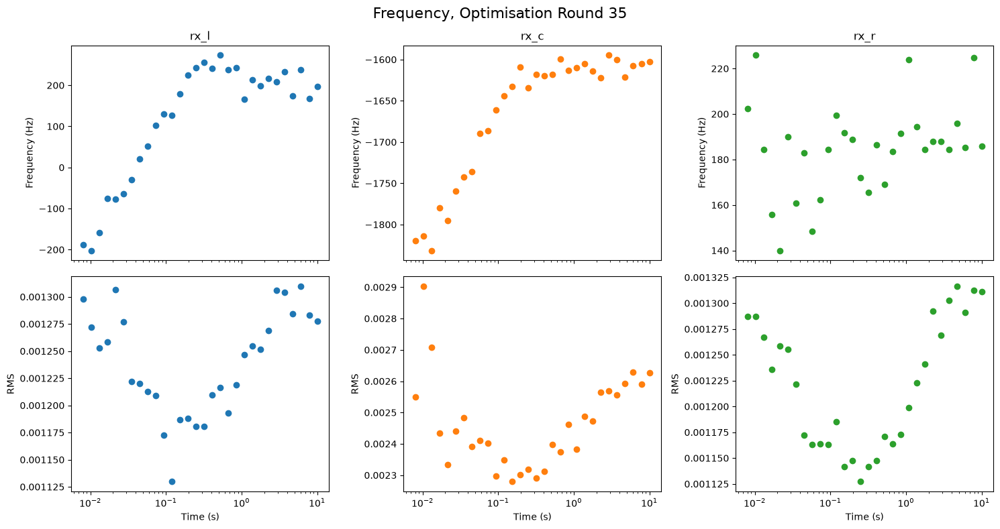

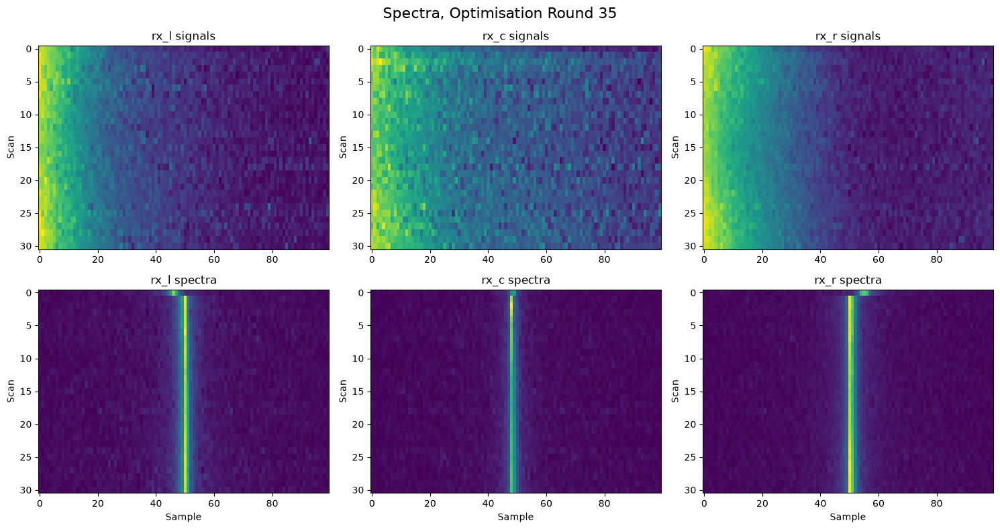

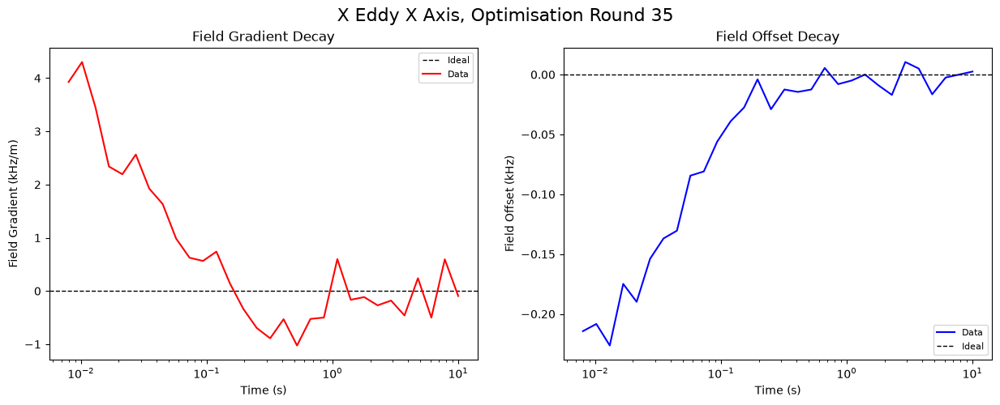

[I 2026-11-26 11:44:57,397] Trial 35 finished with value: 75.17111151245409 and parameters: {'X_A1': -0.02687455553705612, 'X_A2': 0.027710332906436028, 'X_A3': -1.0799709856121277e-08, 'X_A4': 8.681616611838228e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 7.517e+01
Total cost = 7.517e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.027924153671239012
B nanmax = 0.027924153671239012
B contains nan = False
Trial 36


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.027646179858296132 !!!!!!!!!!!!!!!!


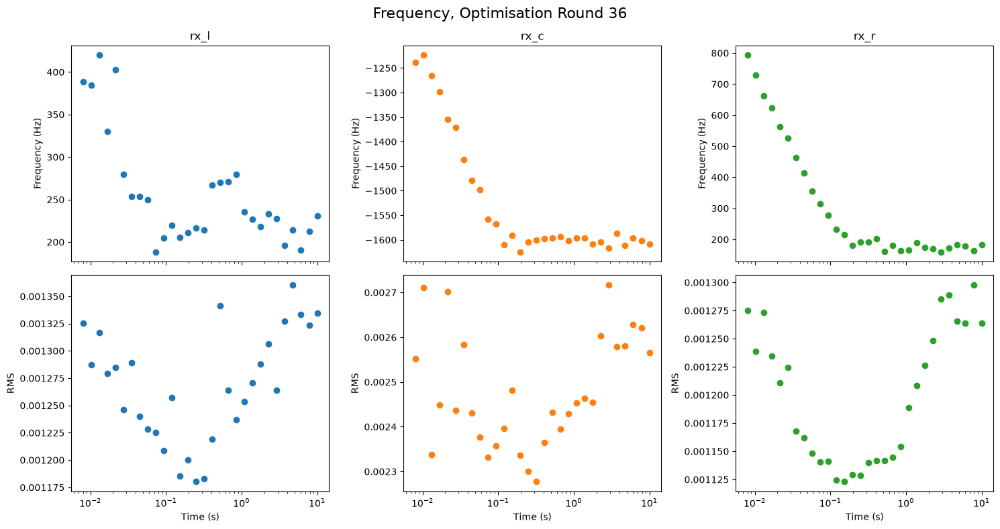

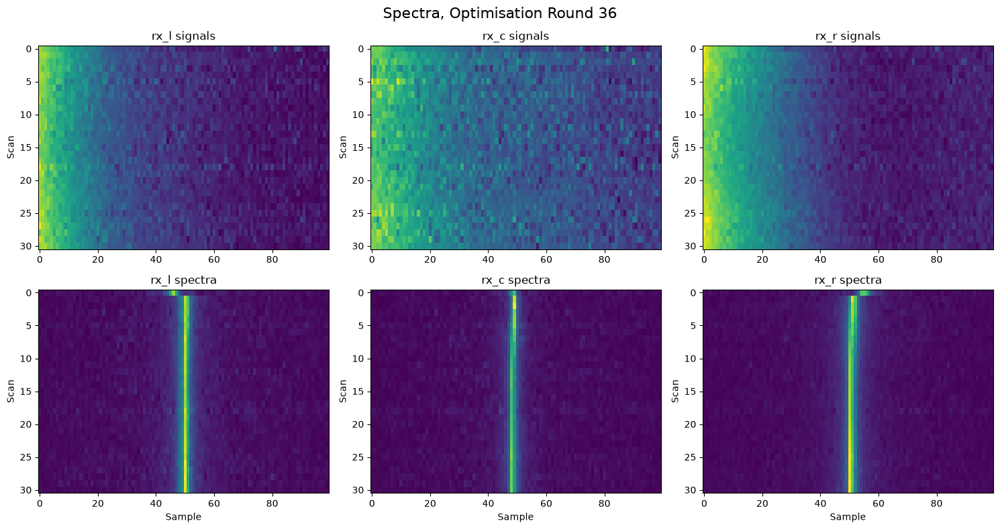

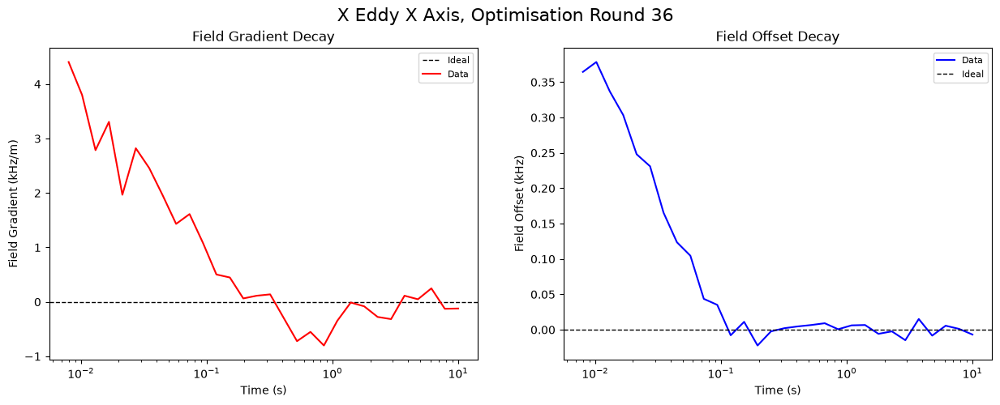

[I 2026-11-26 11:46:19,050] Trial 36 finished with value: 78.54020941068279 and parameters: {'X_A1': -0.02724538337773363, 'X_A2': 0.023544357213568626, 'X_A3': -1.2050900561904378e-08, 'X_A4': 5.065272037509912e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 7.854e+01
Total cost = 7.854e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.03447707356118329
B nanmax = 0.03447707356118329
B contains nan = False
Trial 37


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.03413389863631645 !!!!!!!!!!!!!!!!


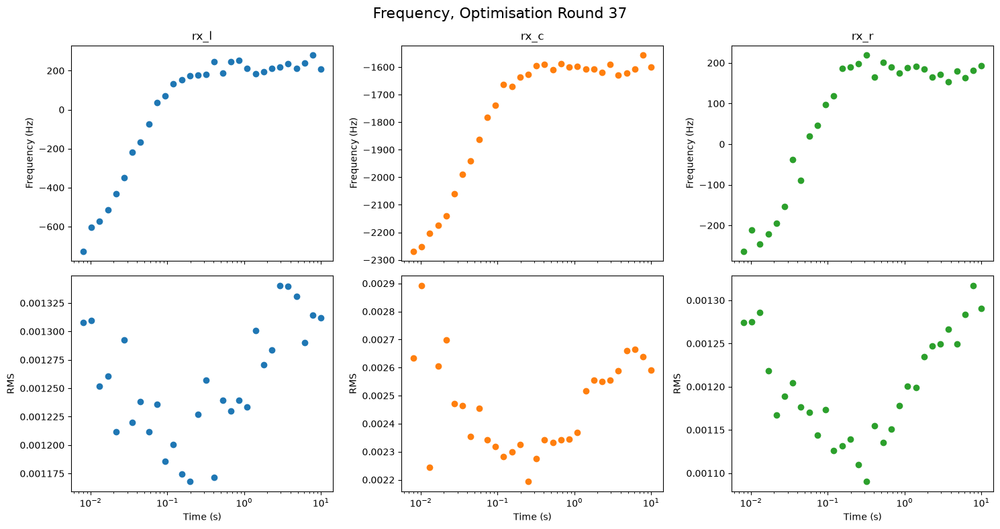

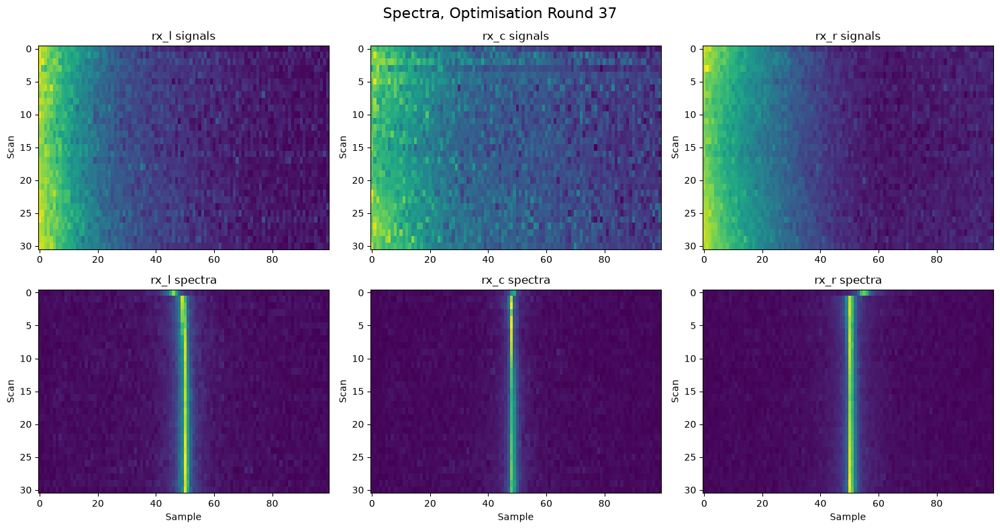

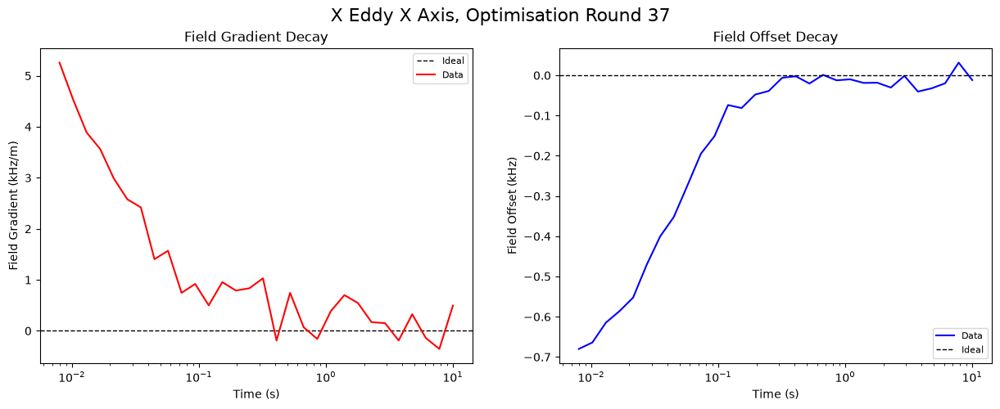

[I 2026-11-26 11:47:40,079] Trial 37 finished with value: 263.3668370765749 and parameters: {'X_A1': -0.02260579825125269, 'X_A2': 0.027191363044445964, 'X_A3': -1.0442353184978374e-08, 'X_A4': 9.933754527107709e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 2.634e+02
Total cost = 2.634e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.03798161974404634
B nanmax = 0.03798161974404634
B contains nan = False
Trial 38


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.03760353158689309 !!!!!!!!!!!!!!!!


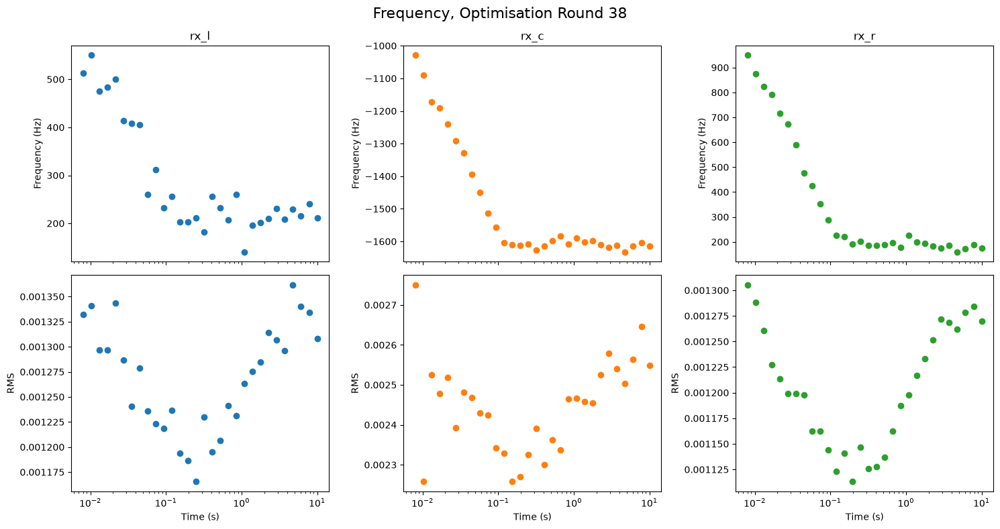

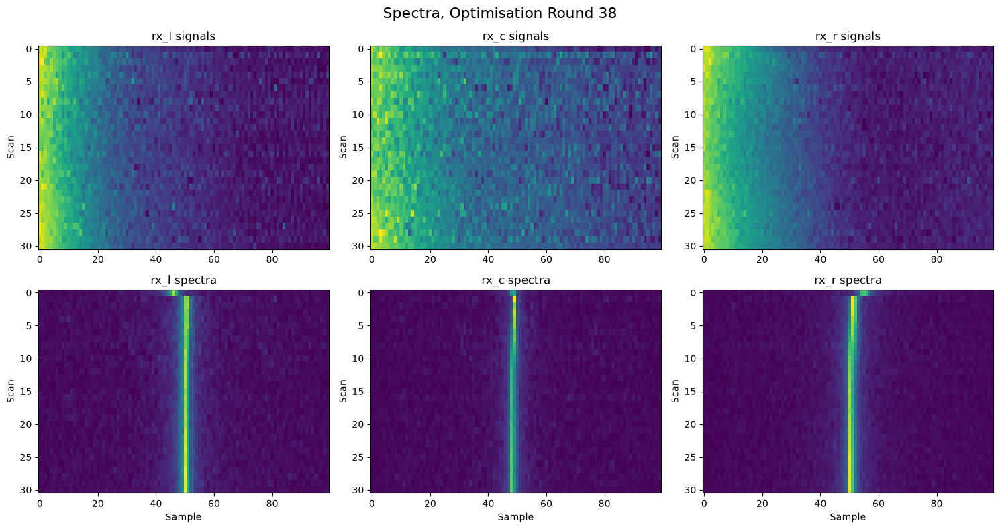

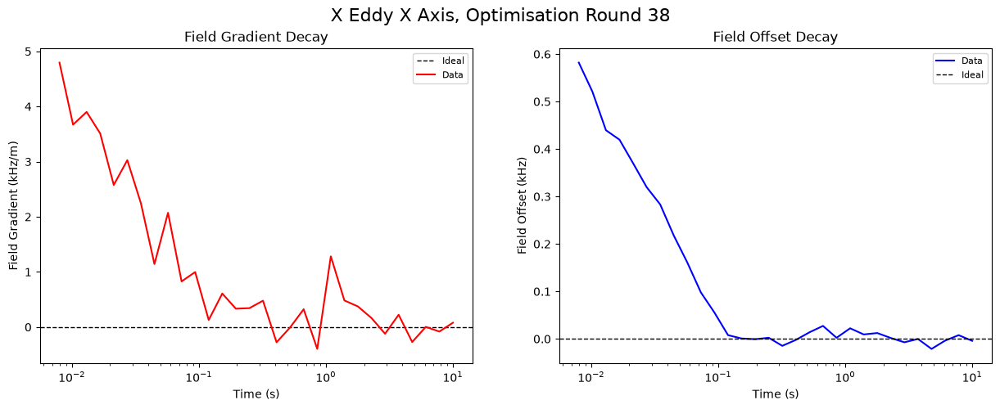

[I 2026-11-26 11:49:01,782] Trial 38 finished with value: 99.78589537298805 and parameters: {'X_A1': -0.03022015786143187, 'X_A2': 0.025184181744586757, 'X_A3': -1.1393763823759738e-08, 'X_A4': 9.381514672019445e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 9.979e+01
Total cost = 9.979e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.009724298971981488
B nanmax = 0.009724298971981488
B contains nan = False
Trial 39


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.00962751684654074 !!!!!!!!!!!!!!!!


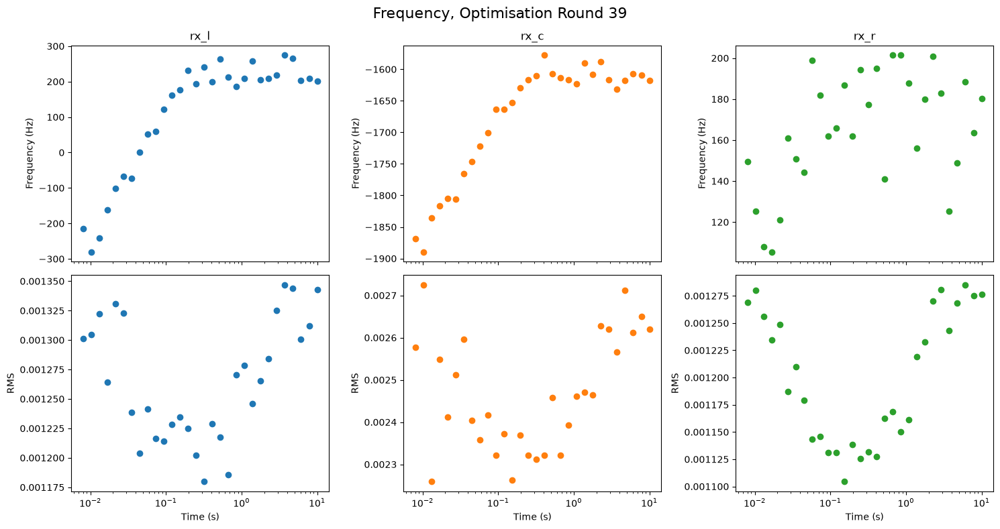

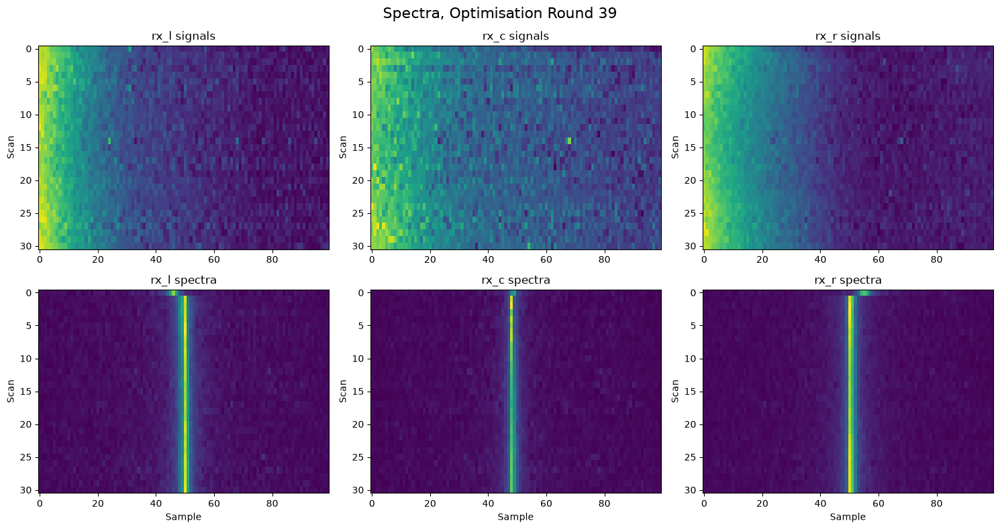

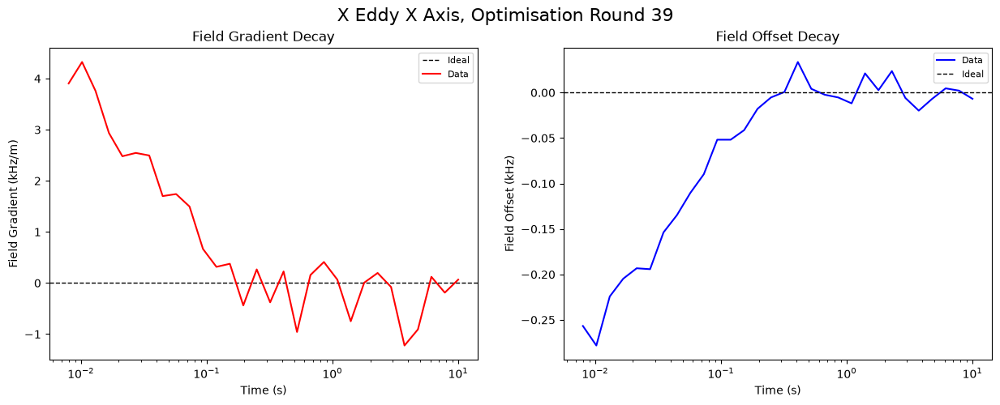

[I 2026-11-26 11:50:23,351] Trial 39 finished with value: 96.67079411957184 and parameters: {'X_A1': -0.026166016335783707, 'X_A2': 0.027465018482337344, 'X_A3': -1.2421787868309957e-08, 'X_A4': 2.3194493028440803e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 9.667e+01
Total cost = 9.667e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.05804709459811279
B nanmax = 0.05804709459811279
B contains nan = False
Trial 40


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.05746930294762845 !!!!!!!!!!!!!!!!


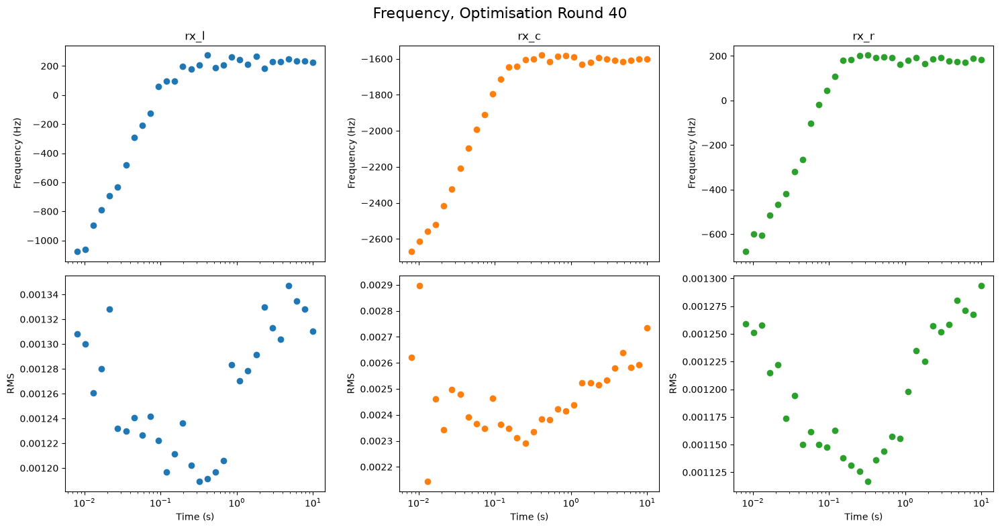

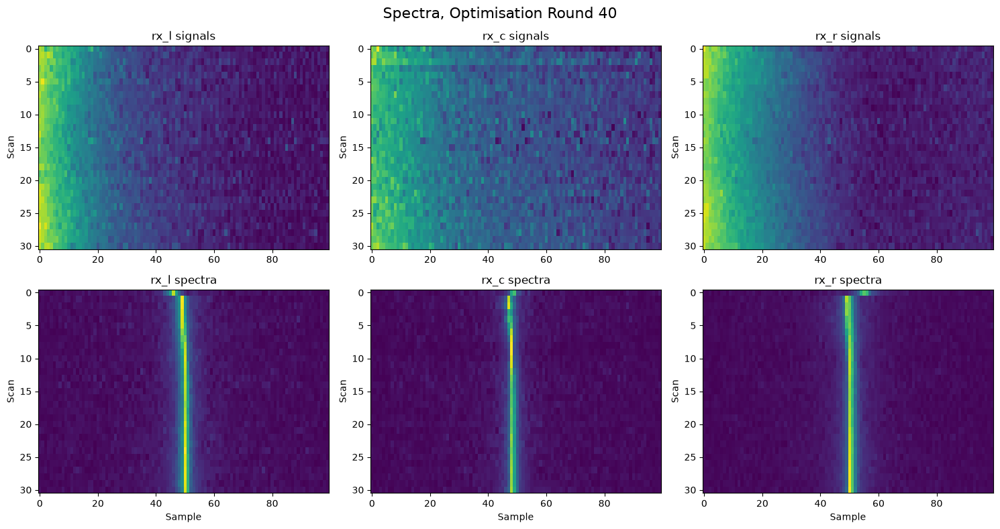

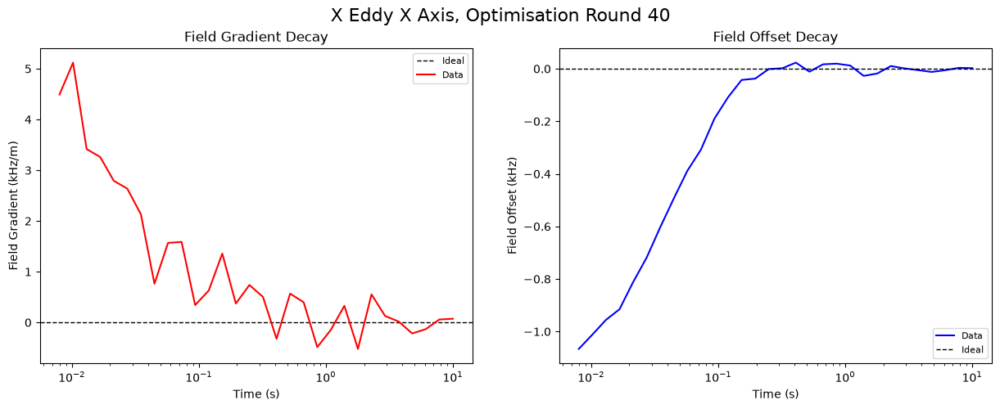

[I 2026-11-26 11:51:44,256] Trial 40 finished with value: 128.26823395342754 and parameters: {'X_A1': -0.0243067120779801, 'X_A2': 0.032023249236488395, 'X_A3': -1.0605740065681579e-08, 'X_A4': 5.60444770132191e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.283e+02
Total cost = 1.283e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.014945926366762596
B nanmax = 0.014945926366762596
B contains nan = False
Trial 41


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014797167830048752 !!!!!!!!!!!!!!!!


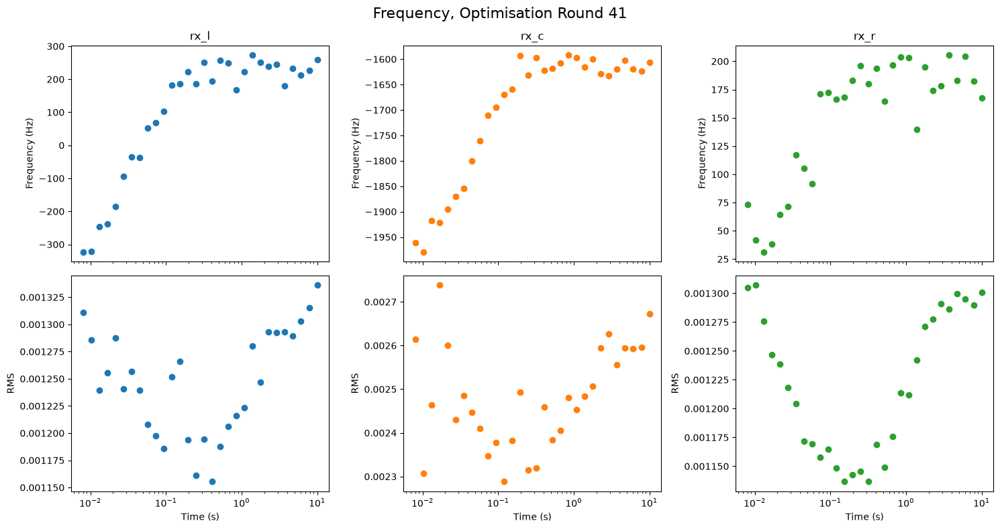

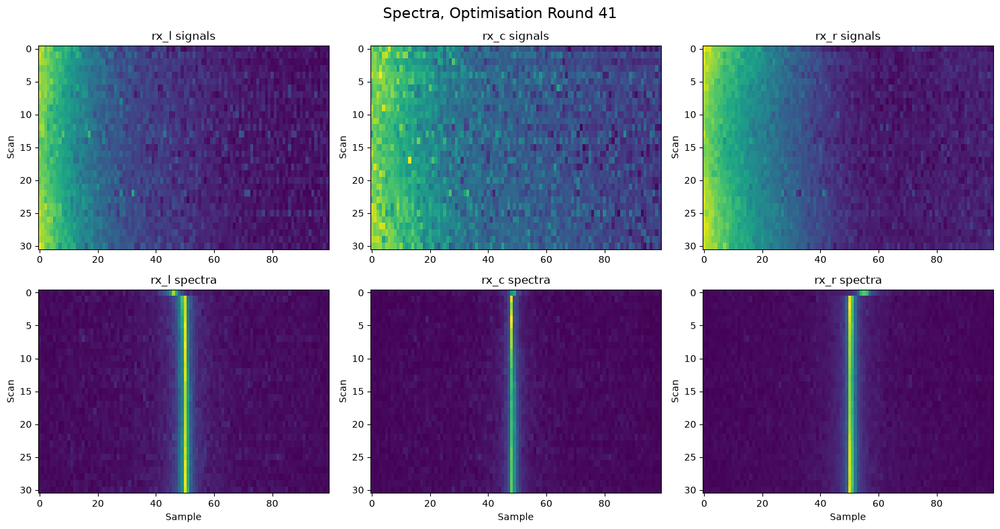

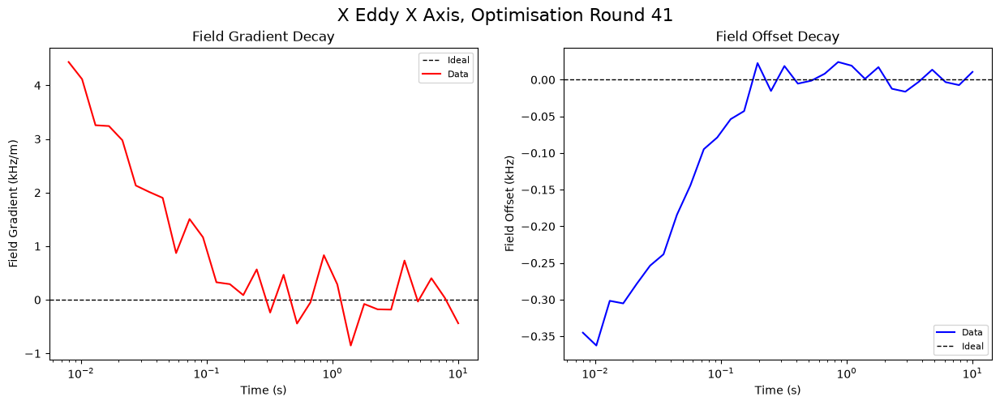

[I 2026-11-26 11:53:05,870] Trial 41 finished with value: 112.30466152375085 and parameters: {'X_A1': -0.026231958720358016, 'X_A2': 0.02822449794482754, 'X_A3': -1.2291971540024774e-08, 'X_A4': 6.869697475876367e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.123e+02
Total cost = 1.123e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.005044783446565213
B nanmax = 0.005044783446565213
B contains nan = False
Trial 42


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.004994580853205524 !!!!!!!!!!!!!!!!


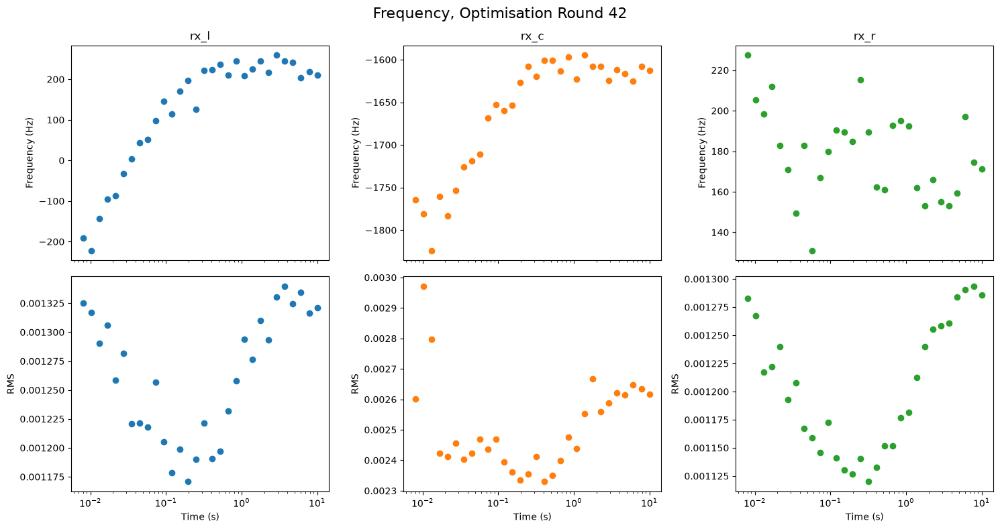

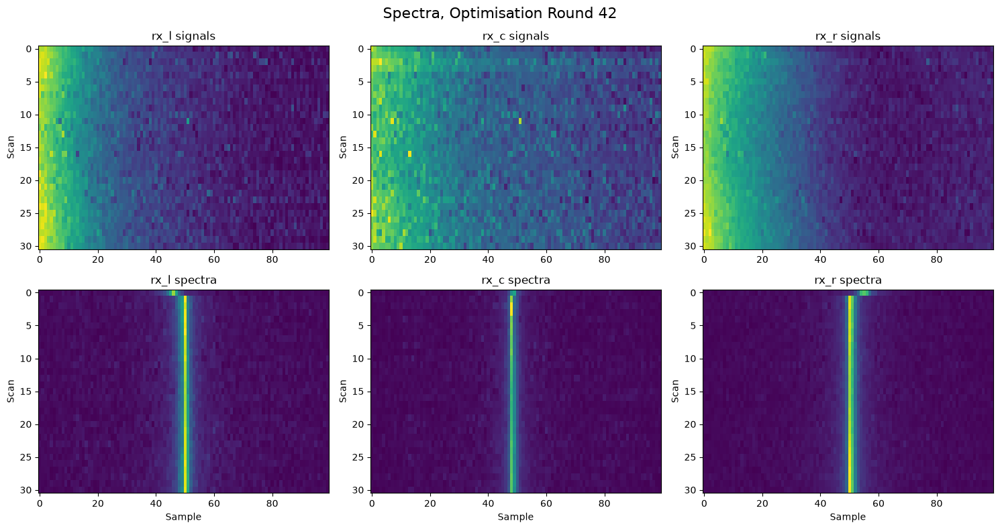

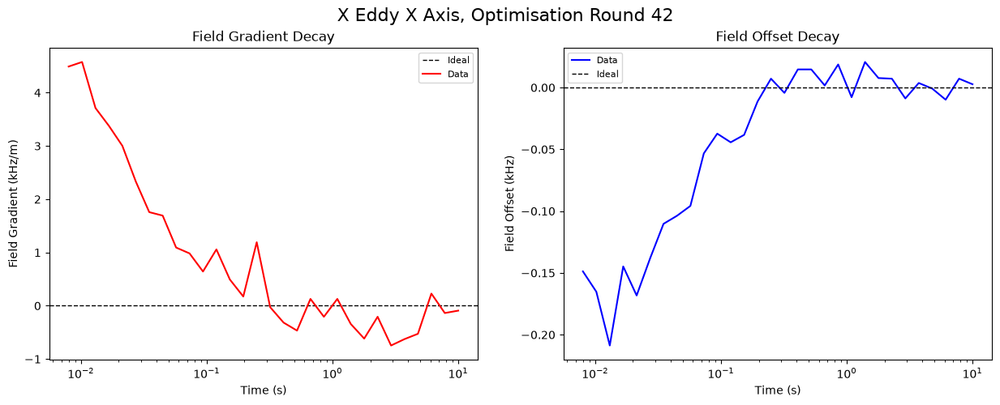

[I 2026-11-26 11:54:27,348] Trial 42 finished with value: 80.07994107474849 and parameters: {'X_A1': -0.02488767942070029, 'X_A2': 0.025564800477894965, 'X_A3': -1.2135989745292434e-08, 'X_A4': 8.846326156956509e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 8.008e+01
Total cost = 8.008e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.019235875243883732
B nanmax = 0.019235875243883732
B contains nan = False
Trial 43


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01904441558502626 !!!!!!!!!!!!!!!!


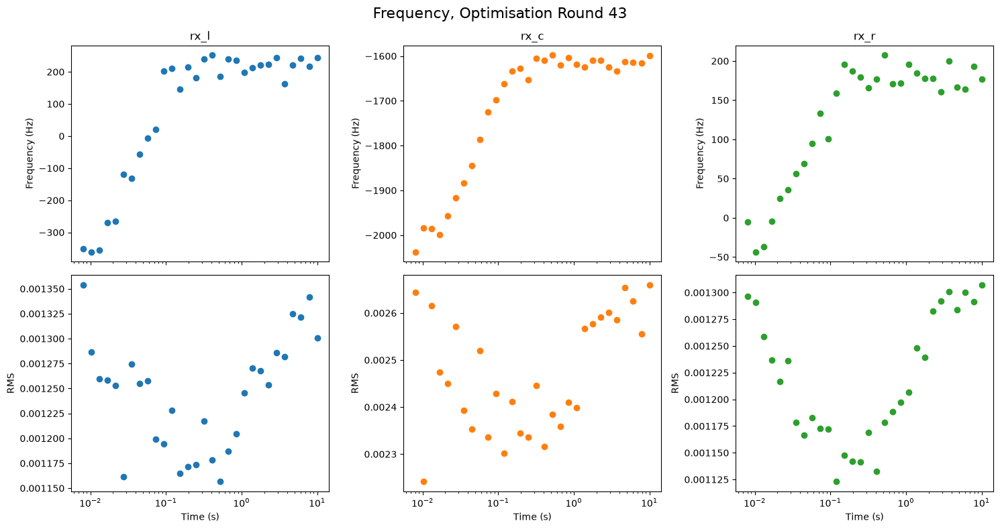

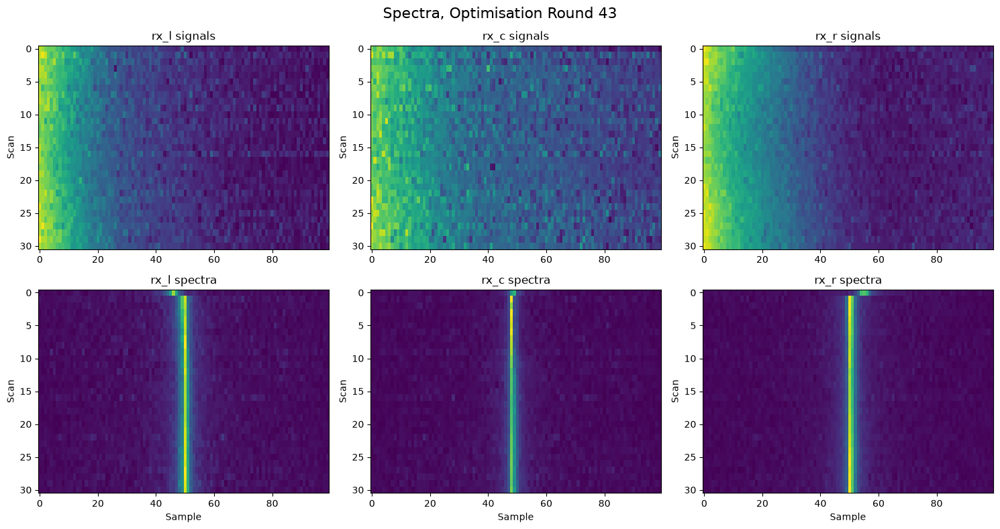

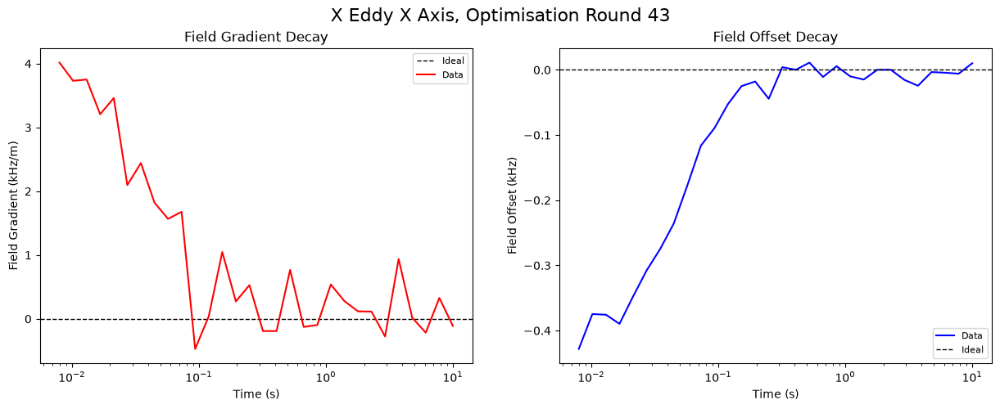

[I 2026-11-26 11:55:48,127] Trial 43 finished with value: 105.48122351996176 and parameters: {'X_A1': -0.028679719705507173, 'X_A2': 0.03124273231120703, 'X_A3': -1.1848032236782166e-08, 'X_A4': 9.370161262239762e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.055e+02
Total cost = 1.055e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.06286599770174246
B nanmax = 0.06286599770174246
B contains nan = False
Trial 44


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.062240239946562616 !!!!!!!!!!!!!!!!


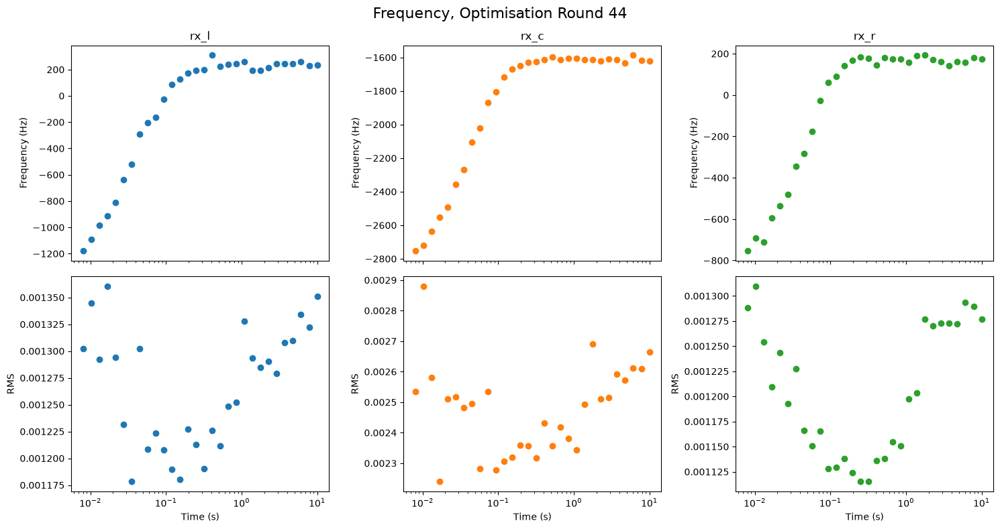

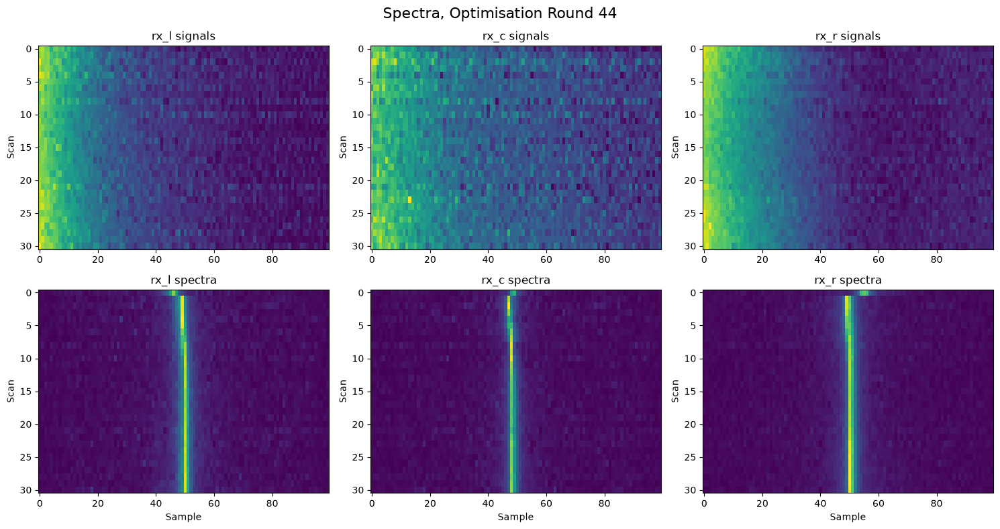

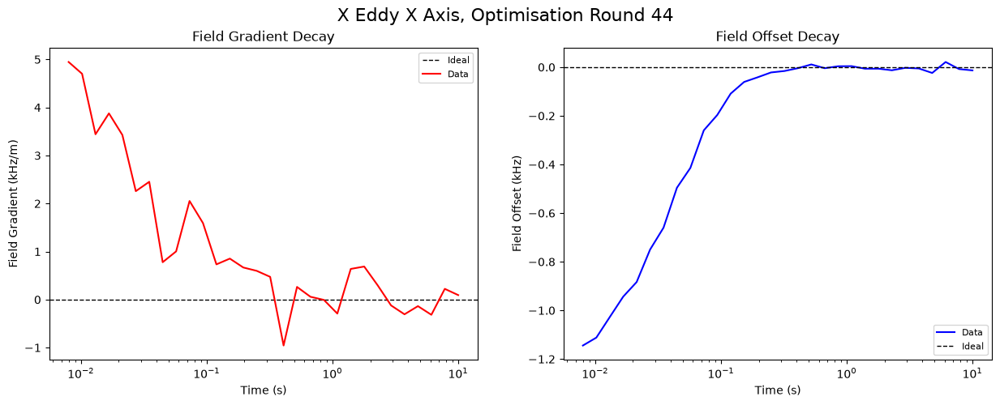

[I 2026-11-26 11:57:09,761] Trial 44 finished with value: 171.73454107572175 and parameters: {'X_A1': -0.027241874897634338, 'X_A2': 0.03559927814999167, 'X_A3': -1.134664835326377e-08, 'X_A4': 8.305756139662655e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.717e+02
Total cost = 1.717e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.05041854515934139
B nanmax = 0.05041854515934139
B contains nan = False
Trial 45


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.04991666166153249 !!!!!!!!!!!!!!!!


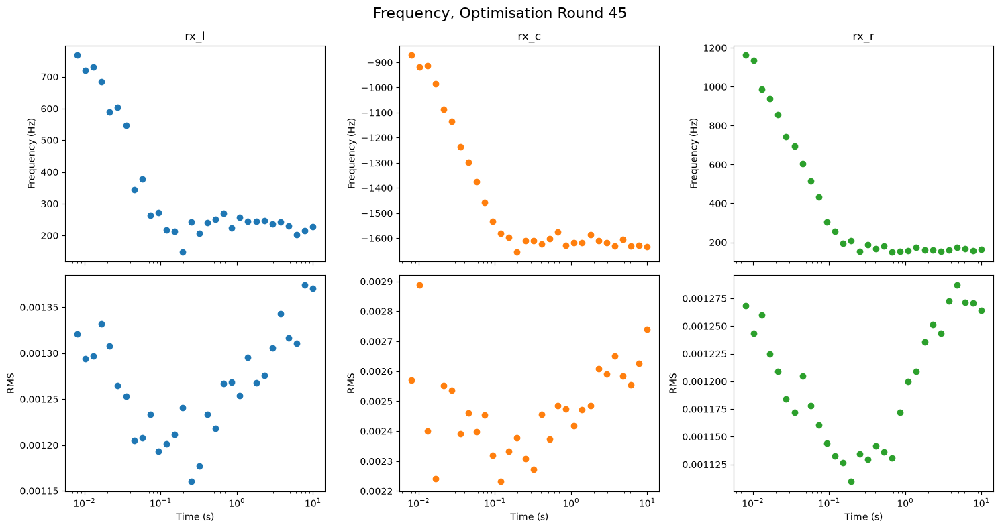

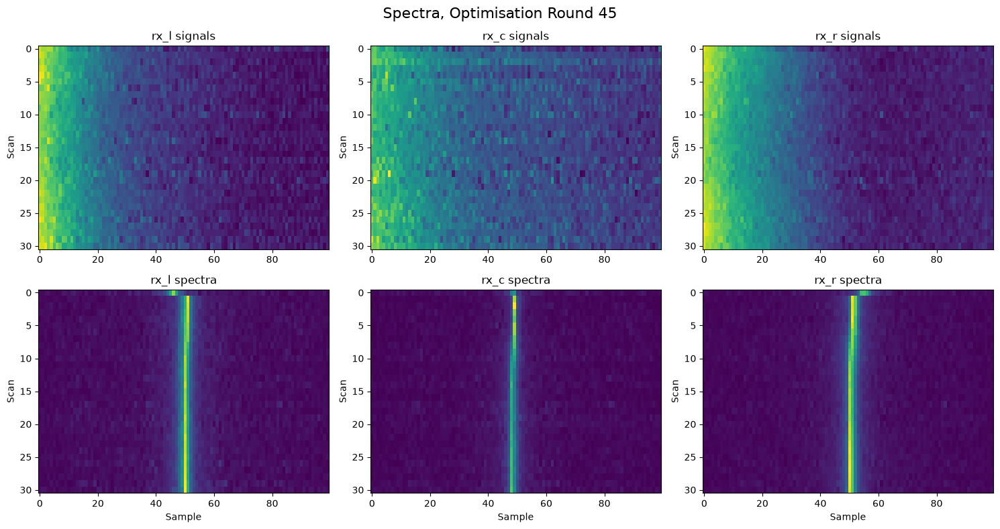

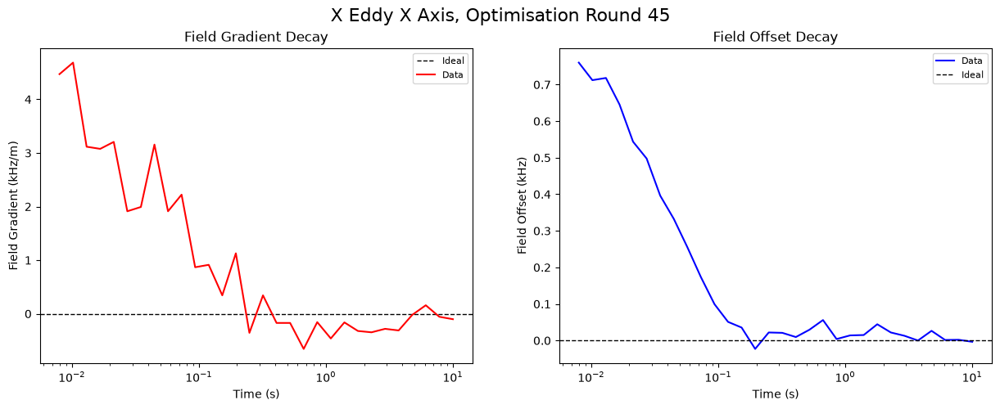

[I 2026-11-26 11:58:30,960] Trial 45 finished with value: 144.25908144871286 and parameters: {'X_A1': -0.025271620010393597, 'X_A2': 0.018582405100655792, 'X_A3': -1.1679477056948055e-08, 'X_A4': 9.58273695316898e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.443e+02
Total cost = 1.443e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.007054378082632033
B nanmax = 0.007054378082632033
B contains nan = False
Trial 46


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.006984141876232032 !!!!!!!!!!!!!!!!


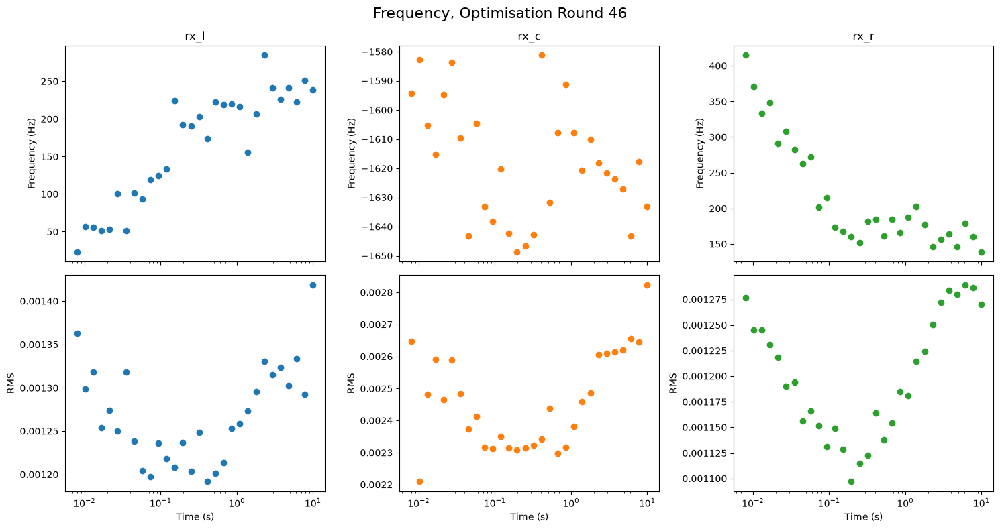

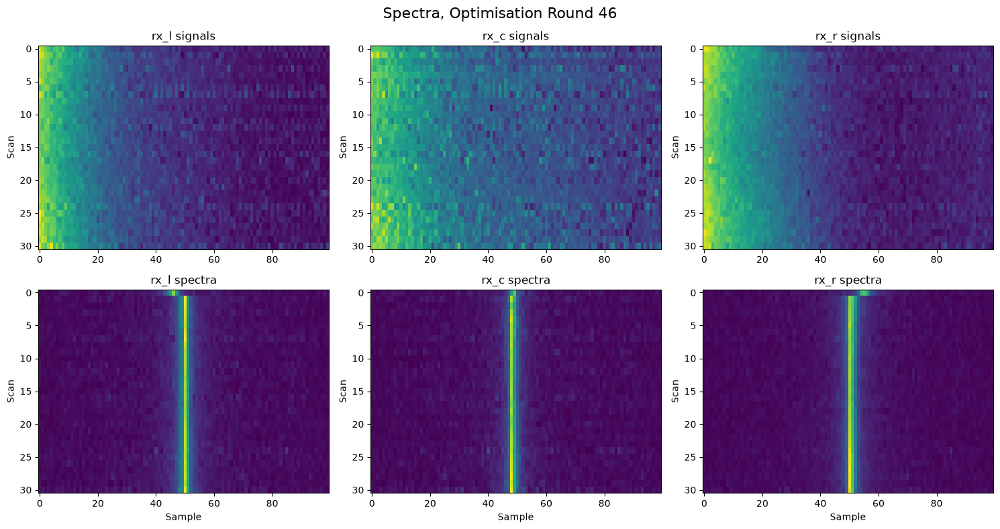

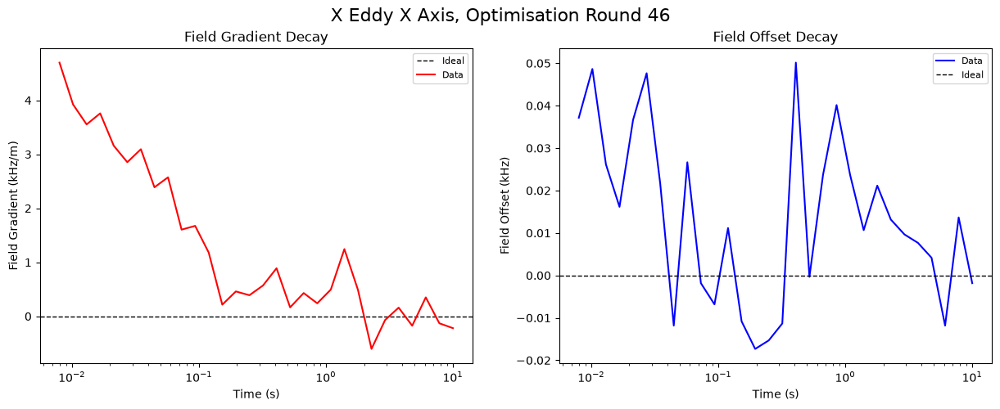

[I 2026-11-26 11:59:52,100] Trial 46 finished with value: 115.33631991025489 and parameters: {'X_A1': -0.030206712606977704, 'X_A2': 0.029278380745778904, 'X_A3': -1.0420527371035812e-08, 'X_A4': 7.389086335718556e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.153e+02
Total cost = 1.153e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.03456852494977634
B nanmax = 0.03456852494977634
B contains nan = False
Trial 47


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.034224408964712696 !!!!!!!!!!!!!!!!


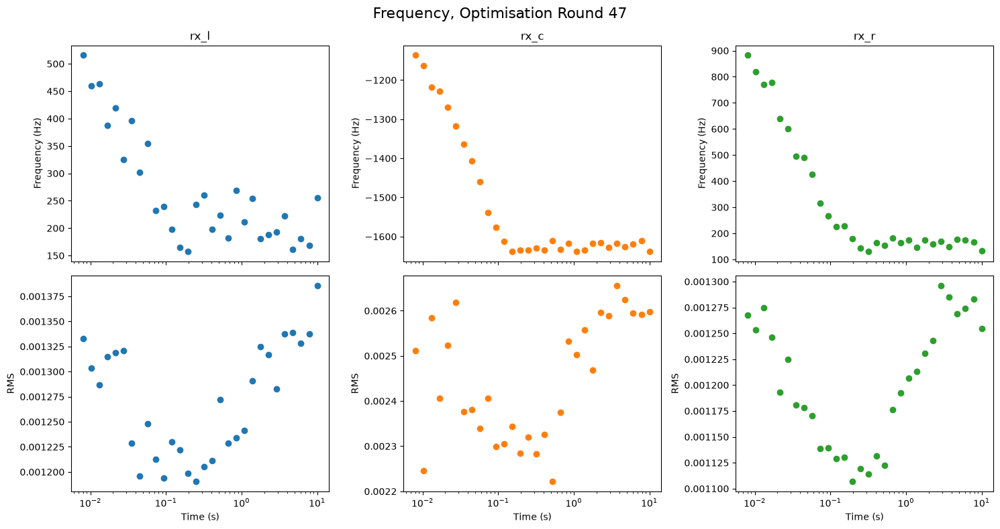

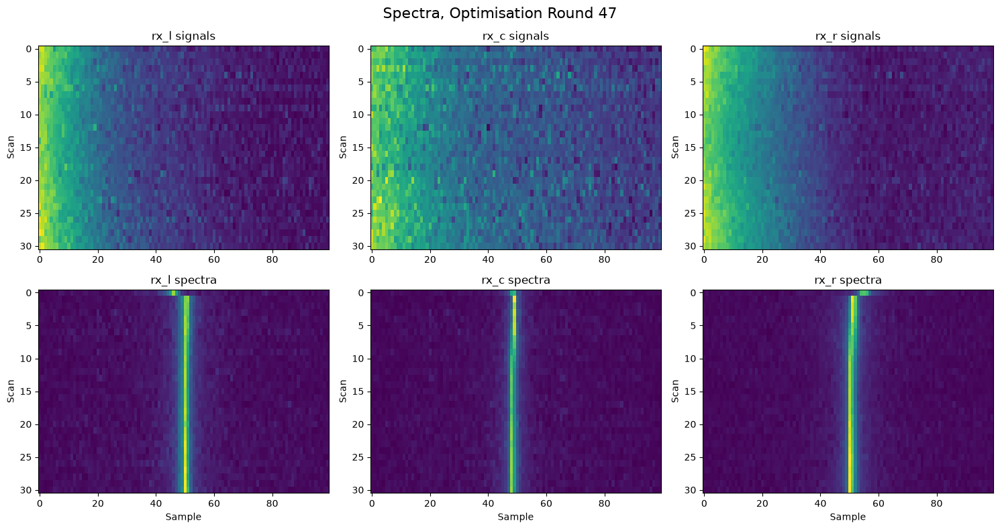

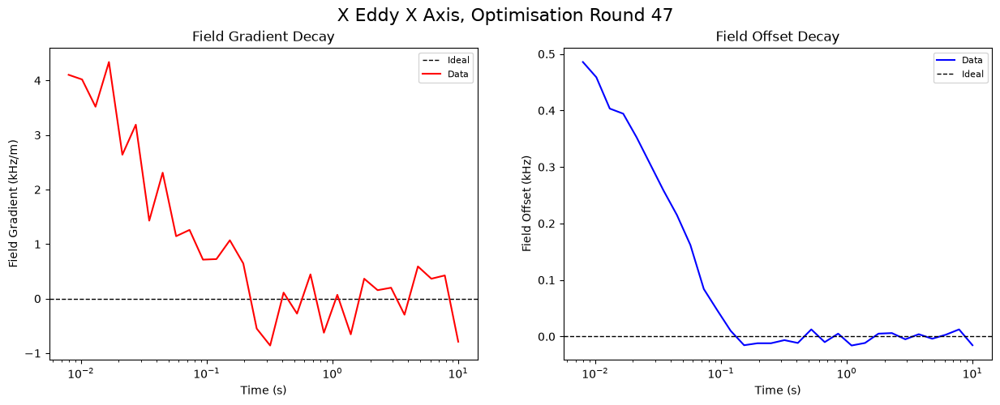

[I 2026-11-26 12:01:13,740] Trial 47 finished with value: 98.14652701804084 and parameters: {'X_A1': -0.03392310367175233, 'X_A2': 0.029341497848424963, 'X_A3': -1.1135243937736972e-08, 'X_A4': 9.326788355943927e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 9.815e+01
Total cost = 9.815e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.04561375726427669
B nanmax = 0.04561375726427669
B contains nan = False
Trial 48


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.04515972714314665 !!!!!!!!!!!!!!!!


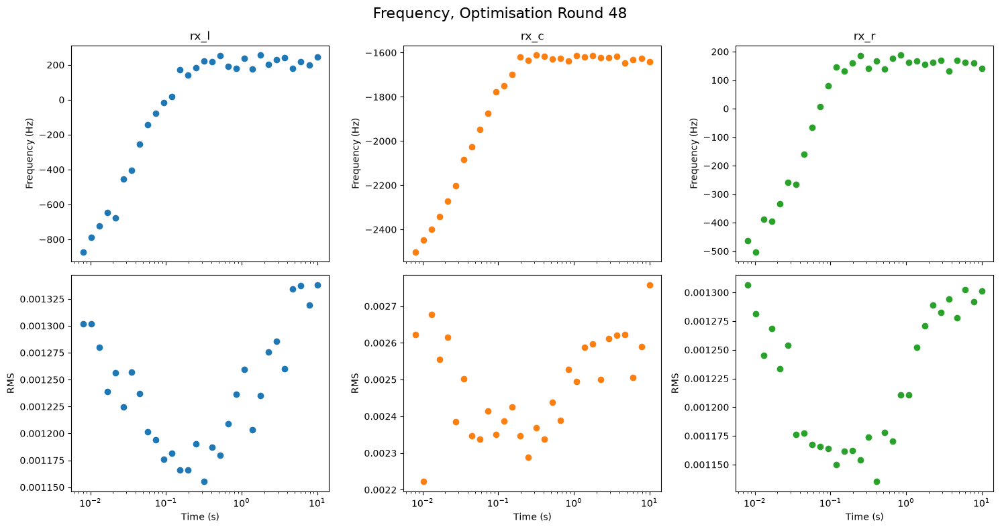

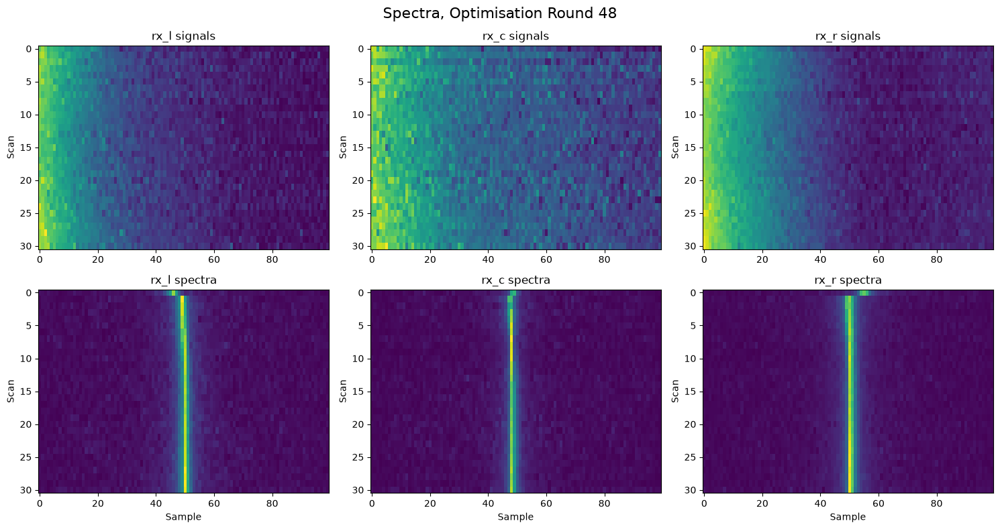

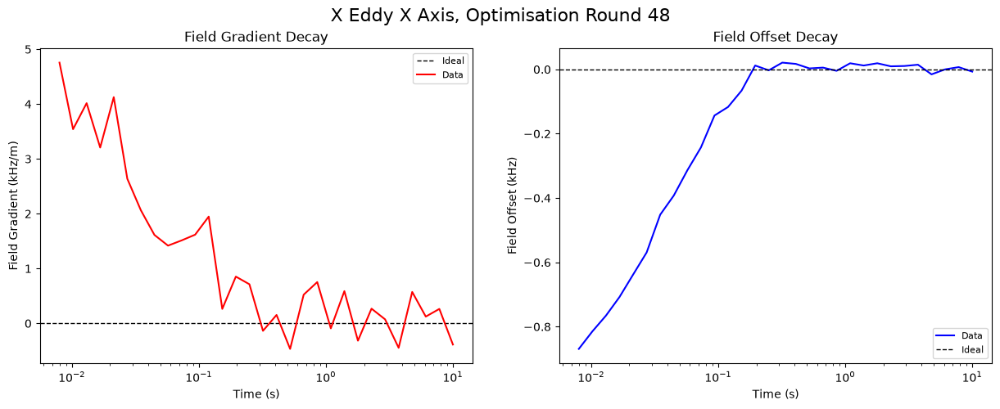

[I 2026-11-26 12:02:35,092] Trial 48 finished with value: 132.4709384212979 and parameters: {'X_A1': -0.022860067016074275, 'X_A2': 0.02892483963600541, 'X_A3': -1.2086849929472625e-08, 'X_A4': 9.231555272777164e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.325e+02
Total cost = 1.325e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0710325656513112
B nanmax = 0.0710325656513112
B contains nan = False
Trial 49


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.07032551568759705 !!!!!!!!!!!!!!!!


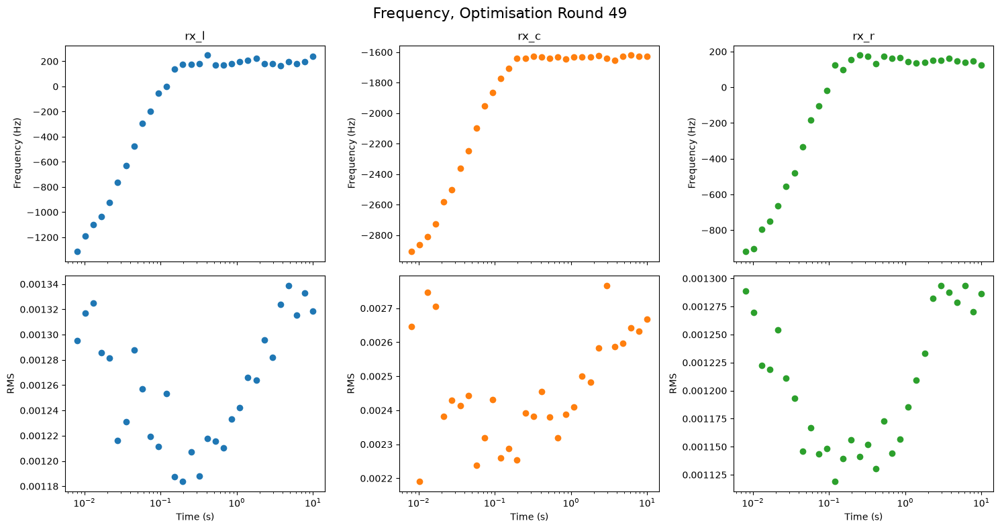

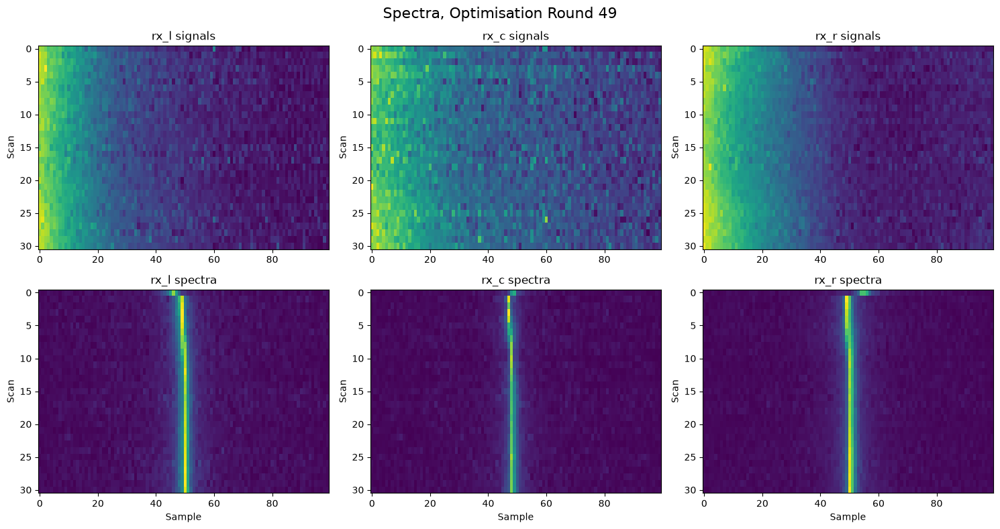

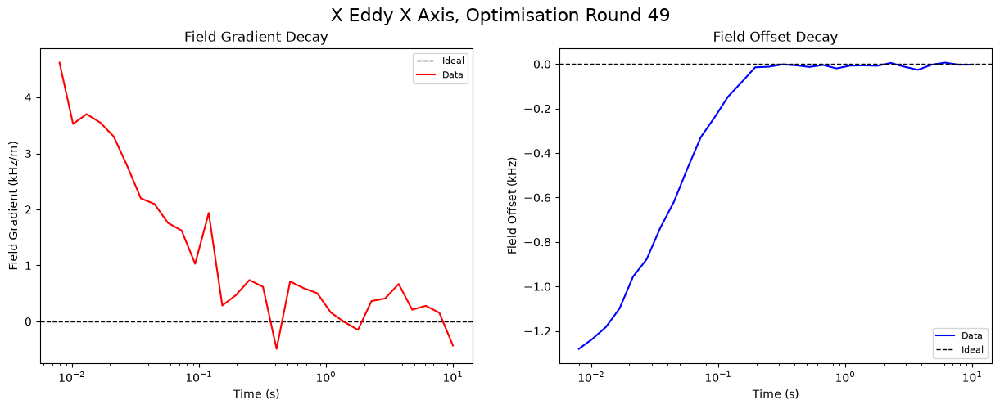

[I 2026-11-26 12:03:56,439] Trial 49 finished with value: 138.51999550738296 and parameters: {'X_A1': -0.024271650015059165, 'X_A2': 0.033712862039950275, 'X_A3': -1.2255970637078223e-08, 'X_A4': 8.49420893867314e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.385e+02
Total cost = 1.385e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.05303817268925282
B nanmax = 0.05303817268925282
B contains nan = False
Trial 50


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.052510239744353045 !!!!!!!!!!!!!!!!


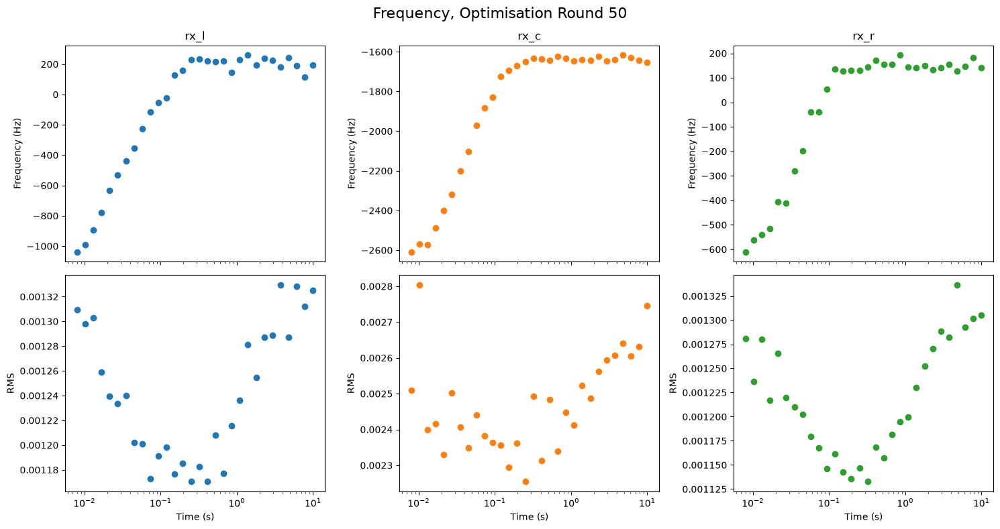

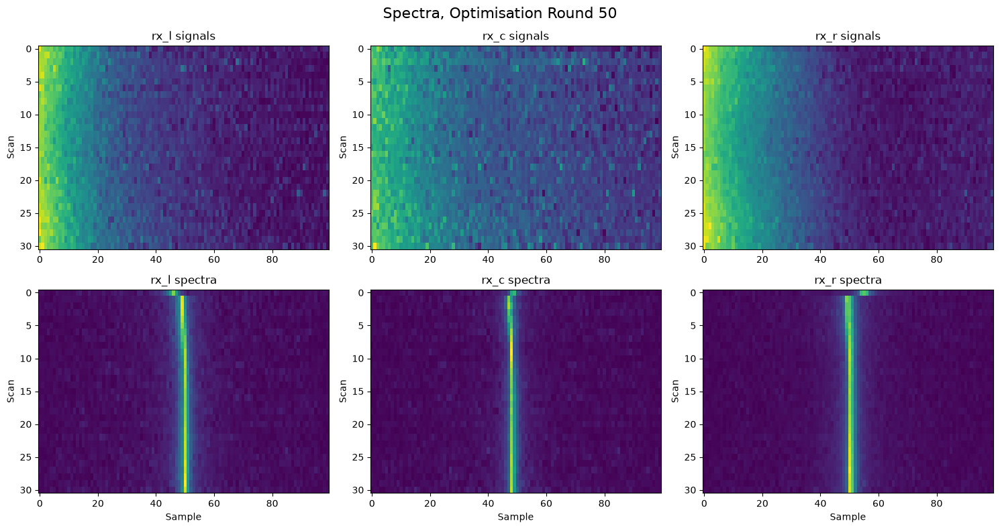

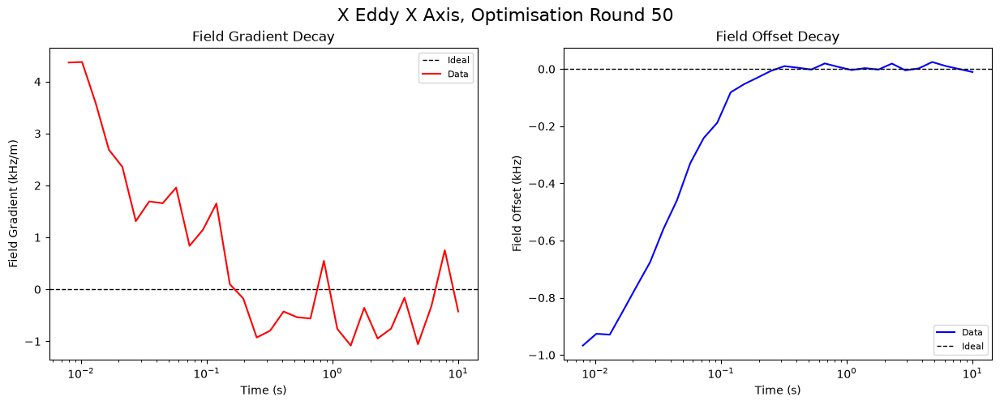

[I 2026-11-26 12:05:15,785] Trial 50 finished with value: 129.8431156900696 and parameters: {'X_A1': -0.023468051179219622, 'X_A2': 0.030519081909220758, 'X_A3': -1.1413381743271112e-08, 'X_A4': 5.9223638817147335e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.298e+02
Total cost = 1.298e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.054123426260698465
B nanmax = 0.054123426260698465
B contains nan = False
Trial 51


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.053584691370523234 !!!!!!!!!!!!!!!!


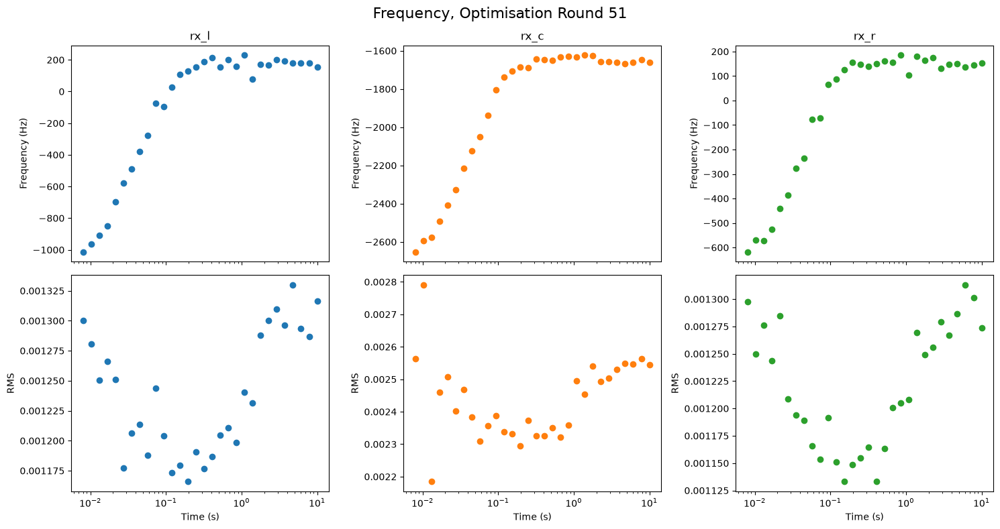

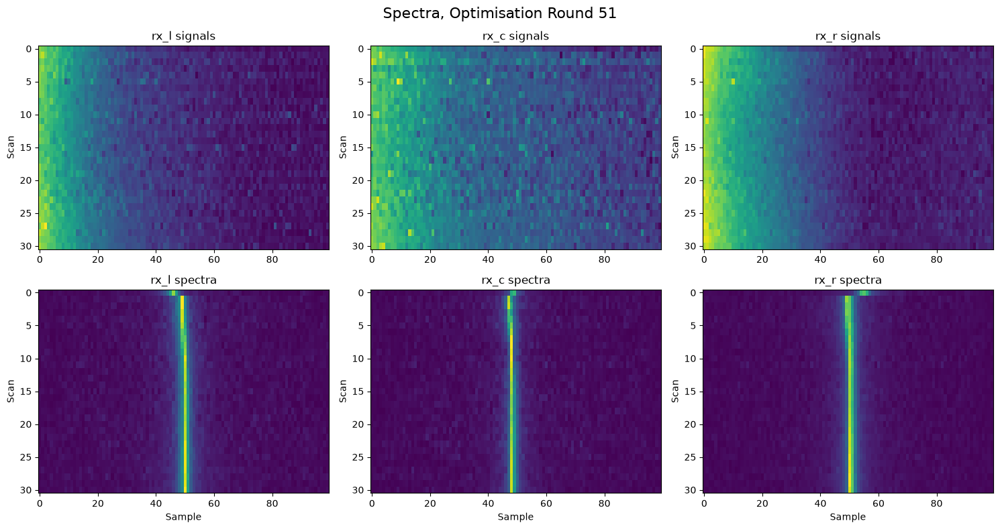

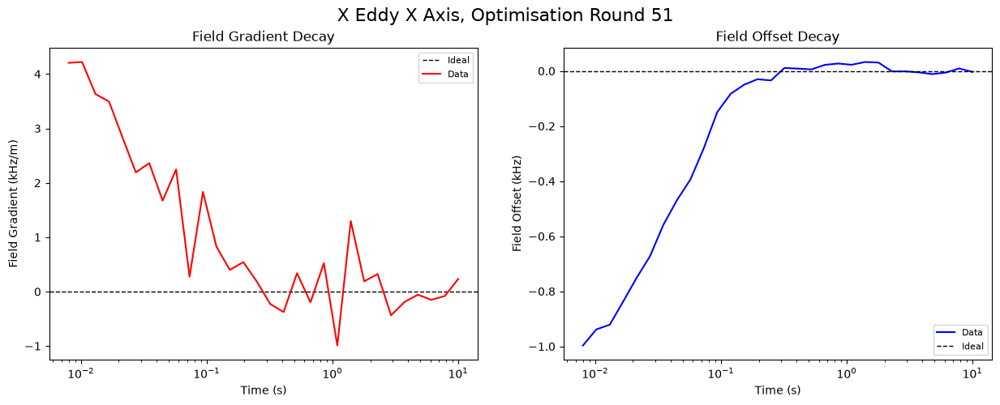

[I 2026-11-26 12:06:34,700] Trial 51 finished with value: 143.68286603510114 and parameters: {'X_A1': -0.024838260302198358, 'X_A2': 0.03203382099243032, 'X_A3': -9.582292841513748e-09, 'X_A4': 8.876043651620526e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.437e+02
Total cost = 1.437e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.04690546892191526
B nanmax = 0.04690546892191526
B contains nan = False
Trial 52


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.04643858362504062 !!!!!!!!!!!!!!!!


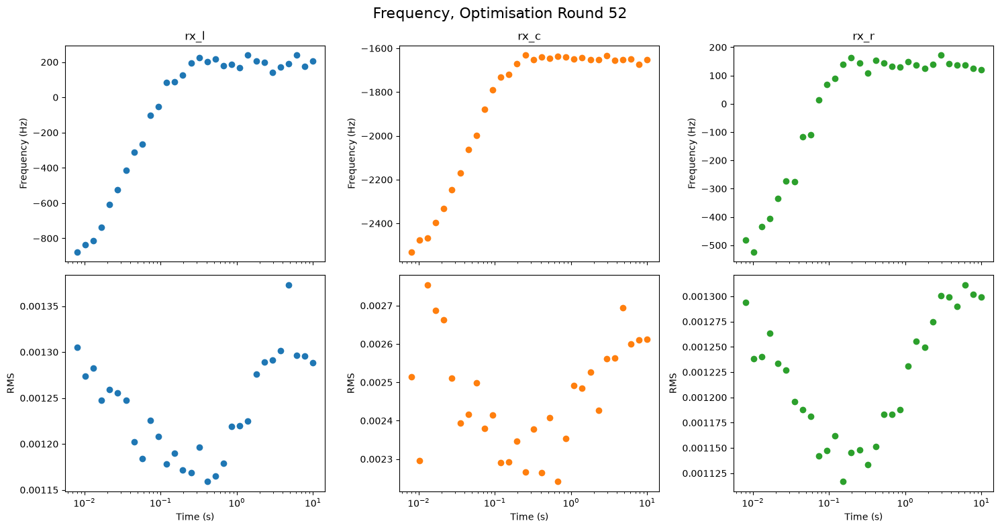

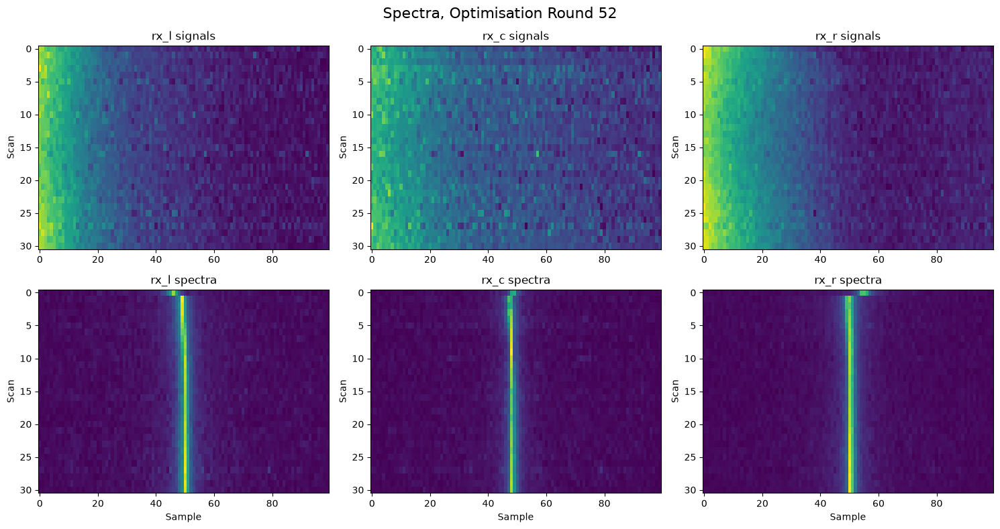

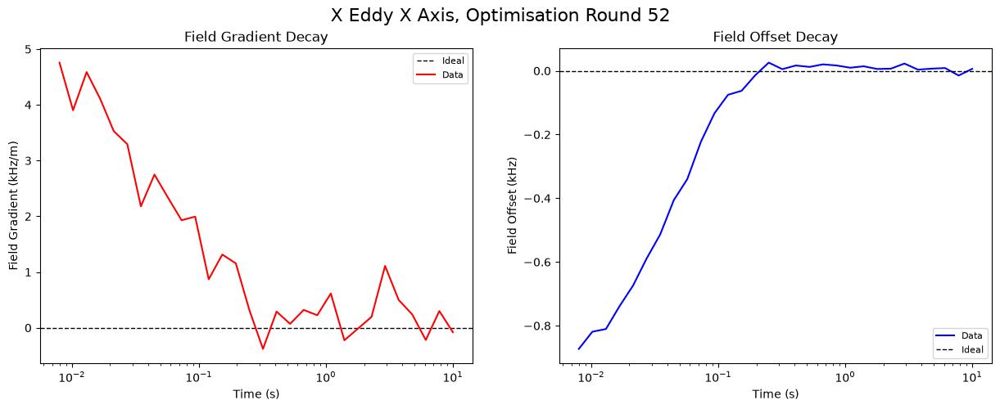

[I 2026-11-26 12:07:53,867] Trial 52 finished with value: 145.05806997741647 and parameters: {'X_A1': -0.027664434908401838, 'X_A2': 0.033902136929895216, 'X_A3': -1.0031566623001207e-08, 'X_A4': 7.480581352396922e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.451e+02
Total cost = 1.451e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.001873601240711758
B nanmax = 0.001873601240711758
B contains nan = False
Trial 53


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.00187020250445882 !!!!!!!!!!!!!!!!


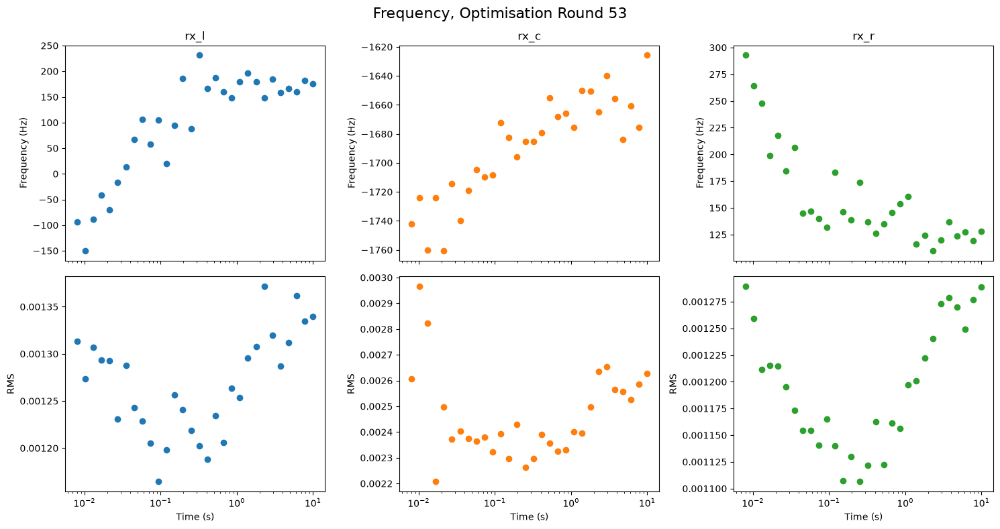

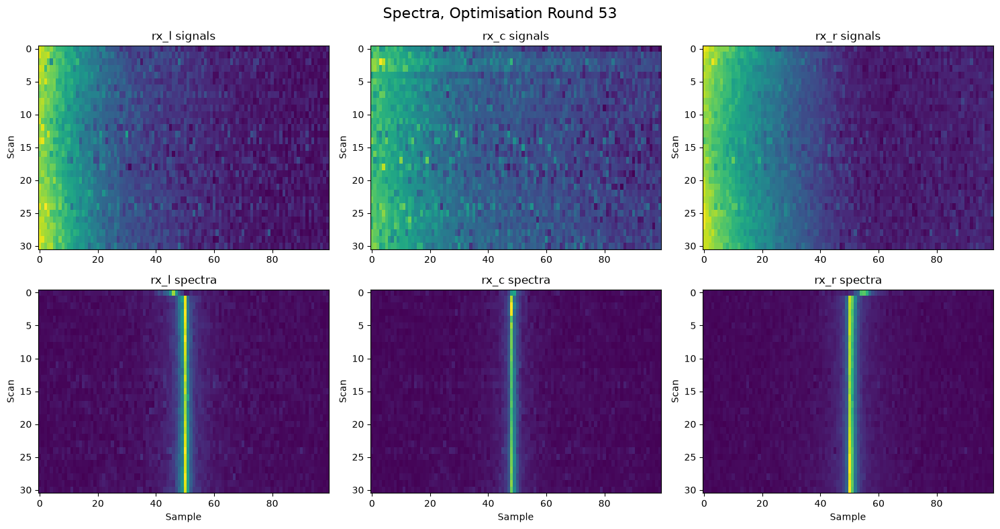

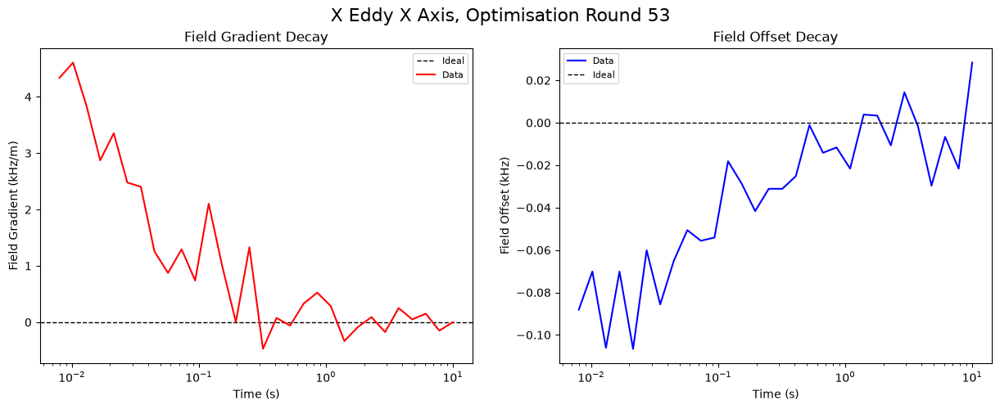

[I 2026-11-26 12:09:15,193] Trial 53 finished with value: 166.91554976748242 and parameters: {'X_A1': -0.026559770965670422, 'X_A2': 0.026543770647543333, 'X_A3': -1.0537827104557283e-08, 'X_A4': 9.800963364800465e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.669e+02
Total cost = 1.669e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.04309340923905914
B nanmax = 0.04309340923905914
B contains nan = False
Trial 54


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0426644373372972 !!!!!!!!!!!!!!!!


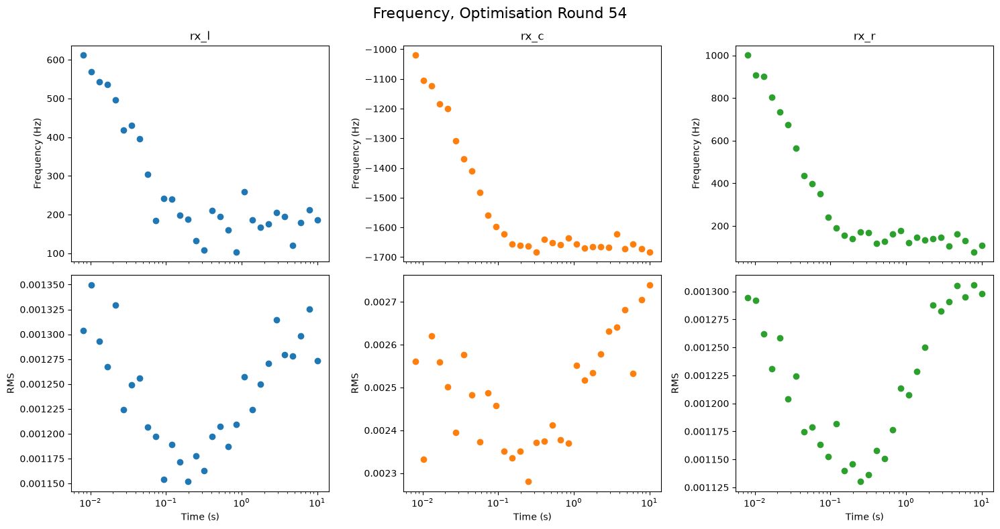

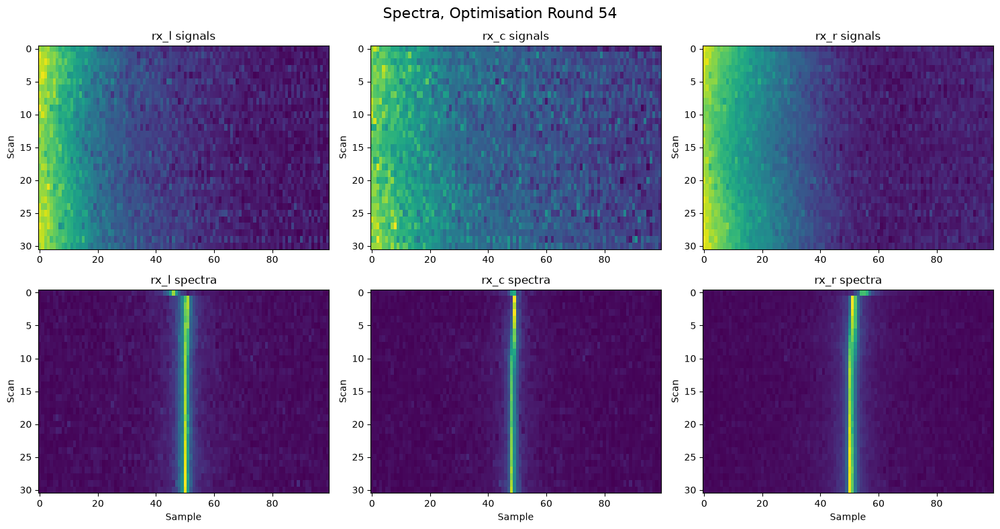

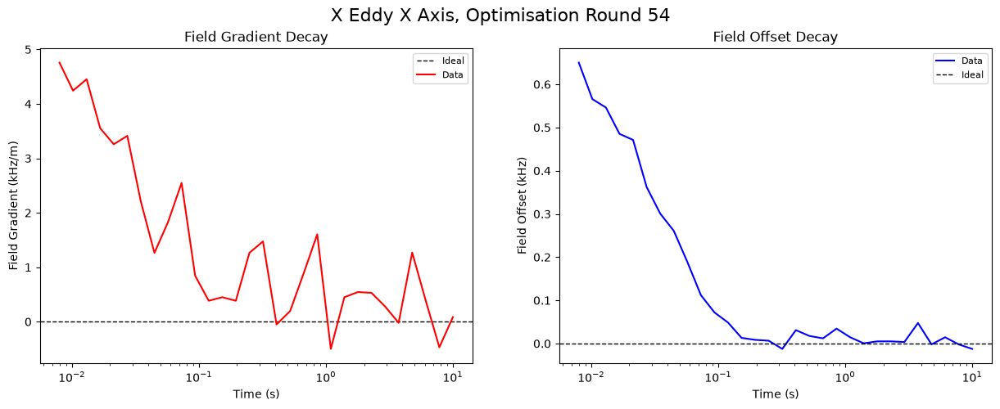

[I 2026-11-26 12:10:36,513] Trial 54 finished with value: 138.9991196191187 and parameters: {'X_A1': -0.03138149989912557, 'X_A2': 0.025666924646470385, 'X_A3': -1.1918106937197611e-08, 'X_A4': 7.367630716989939e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.390e+02
Total cost = 1.390e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.01858622661343755
B nanmax = 0.01858622661343755
B contains nan = False
Trial 55


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01840123162267588 !!!!!!!!!!!!!!!!


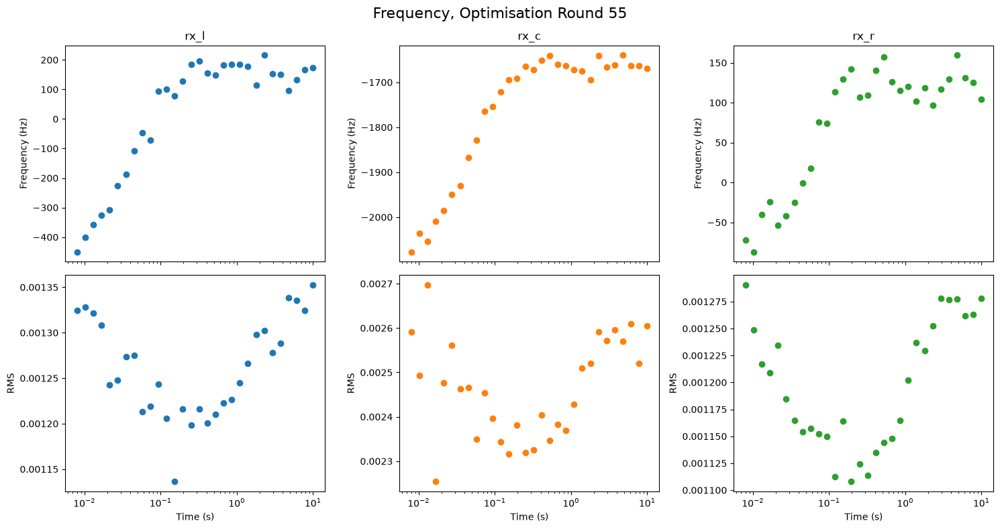

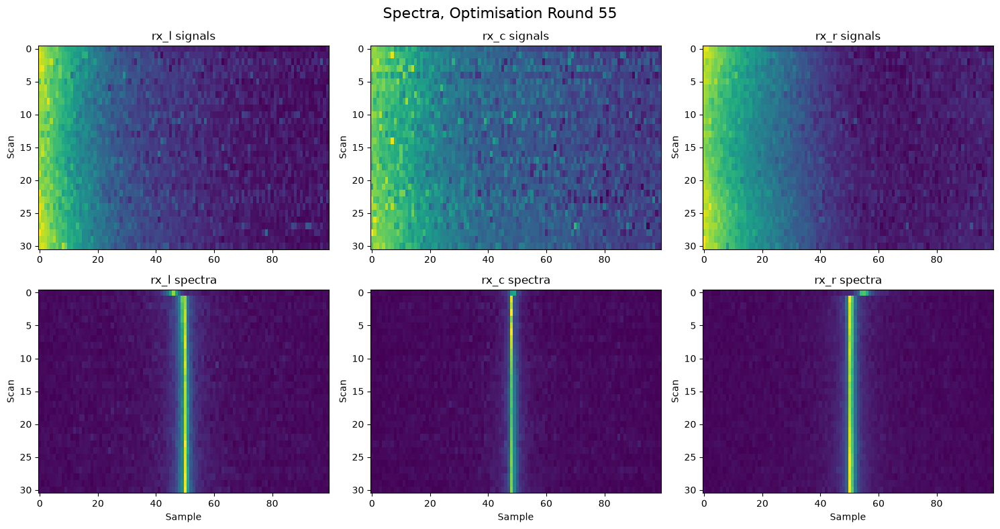

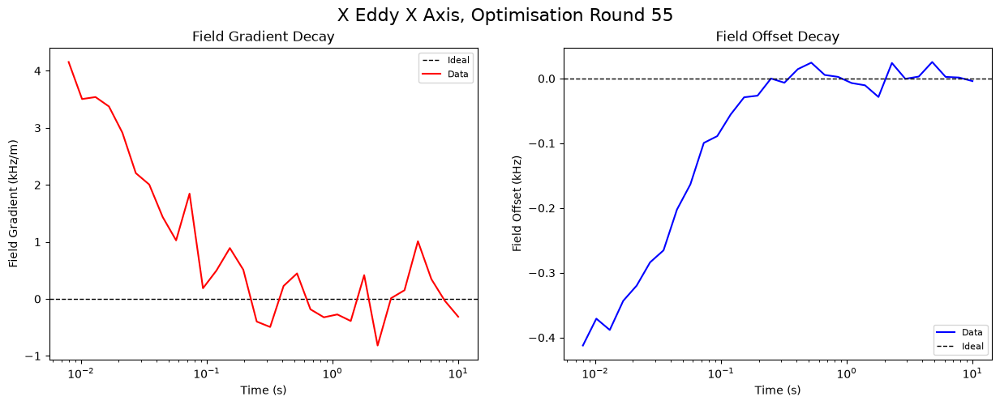

[I 2026-11-26 12:11:57,566] Trial 55 finished with value: 105.43042023868782 and parameters: {'X_A1': -0.025039110746600552, 'X_A2': 0.02751480207453175, 'X_A3': -1.0943662952615538e-08, 'X_A4': 8.455702585787582e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.054e+02
Total cost = 1.054e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0025114571394947043
B nanmax = 0.0025114571394947043
B contains nan = False
Trial 56


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0025073823727917175 !!!!!!!!!!!!!!!!


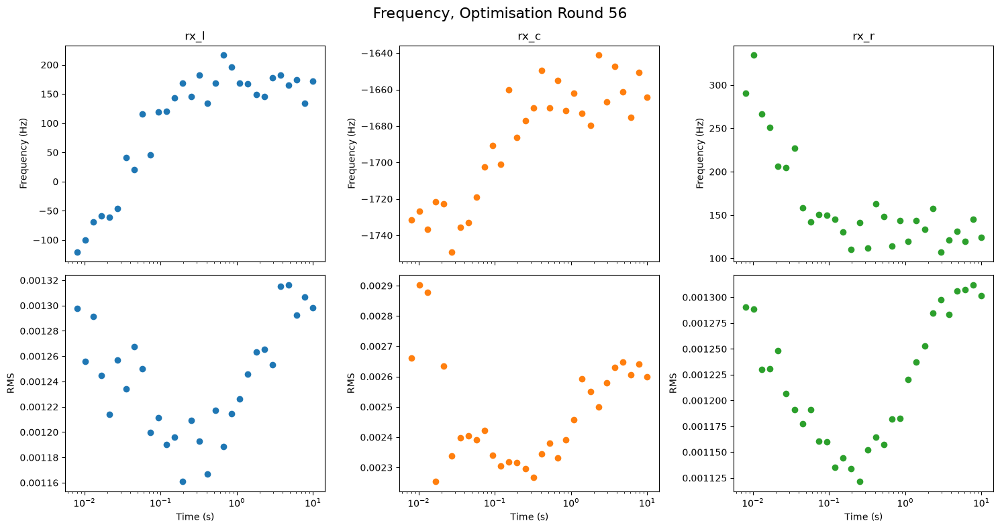

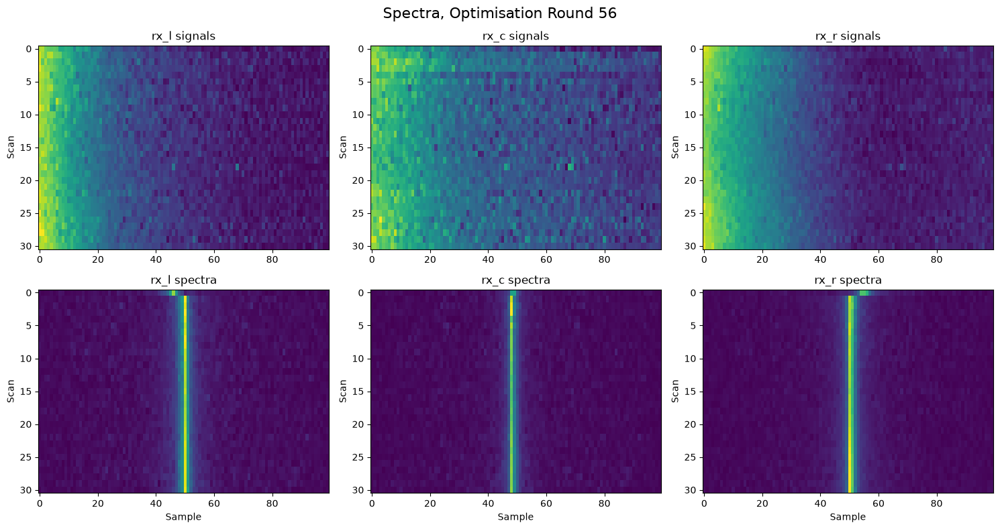

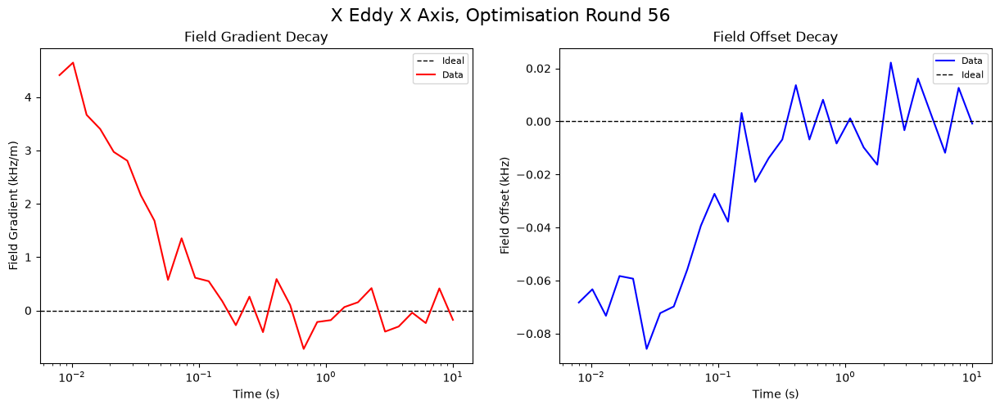

[I 2026-11-26 12:13:19,087] Trial 56 finished with value: 101.34773272166746 and parameters: {'X_A1': -0.026267355984417193, 'X_A2': 0.026040188223052044, 'X_A3': -1.0456289728148223e-08, 'X_A4': 7.061612061430387e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.013e+02
Total cost = 1.013e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.060911974100098534
B nanmax = 0.060911974100098534
B contains nan = False
Trial 57


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.06030566322924817 !!!!!!!!!!!!!!!!


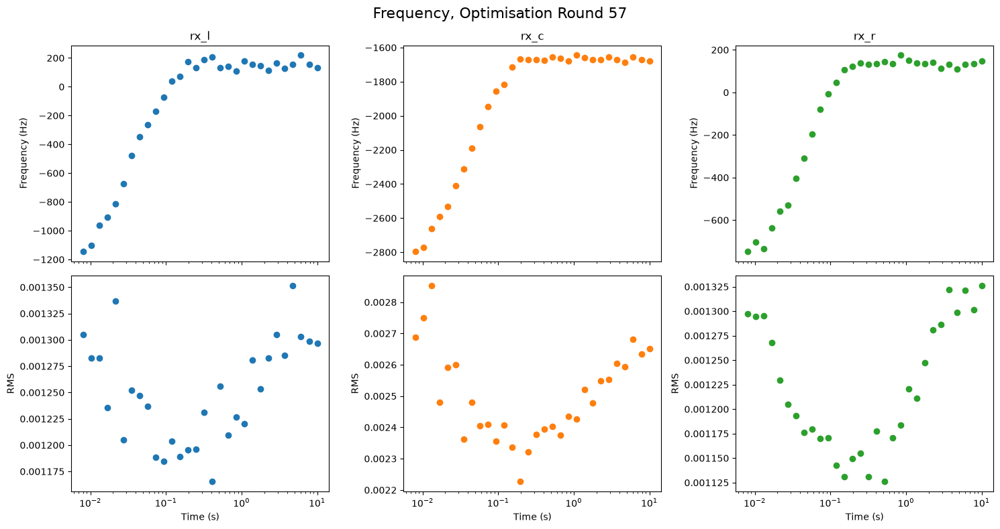

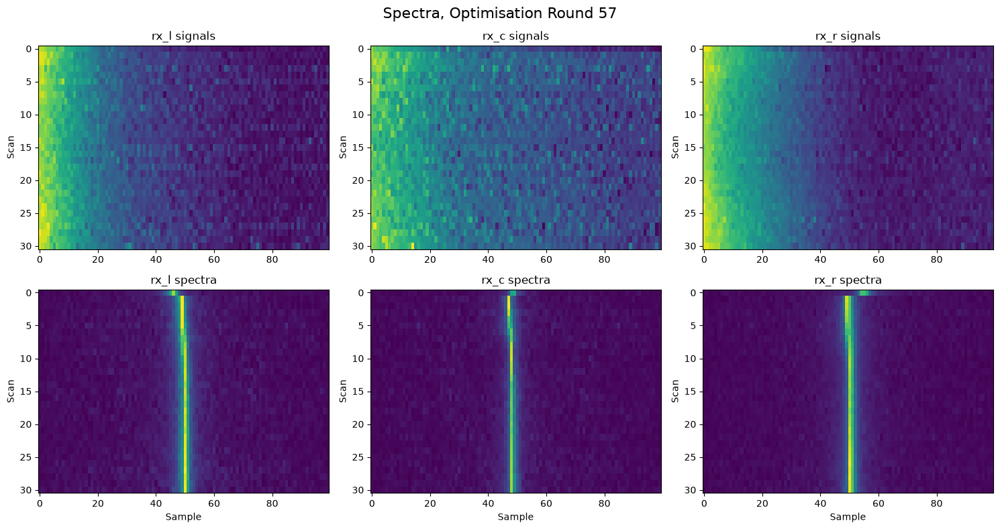

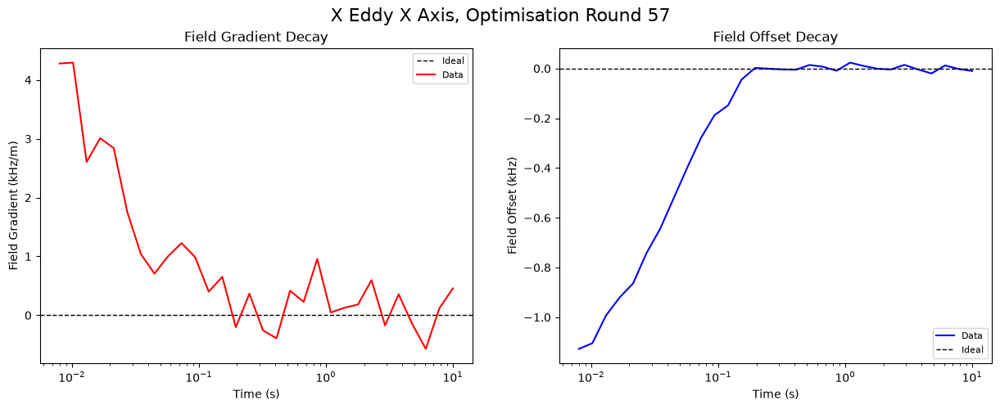

[I 2026-11-26 12:14:40,233] Trial 57 finished with value: 142.77635298069603 and parameters: {'X_A1': -0.020615164628443775, 'X_A2': 0.028711153333077454, 'X_A3': -1.1229822412752844e-08, 'X_A4': 9.273866544833688e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.428e+02
Total cost = 1.428e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.009881546232506902
B nanmax = 0.009881546232506902
B contains nan = False
Trial 58


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.009783198948993337 !!!!!!!!!!!!!!!!


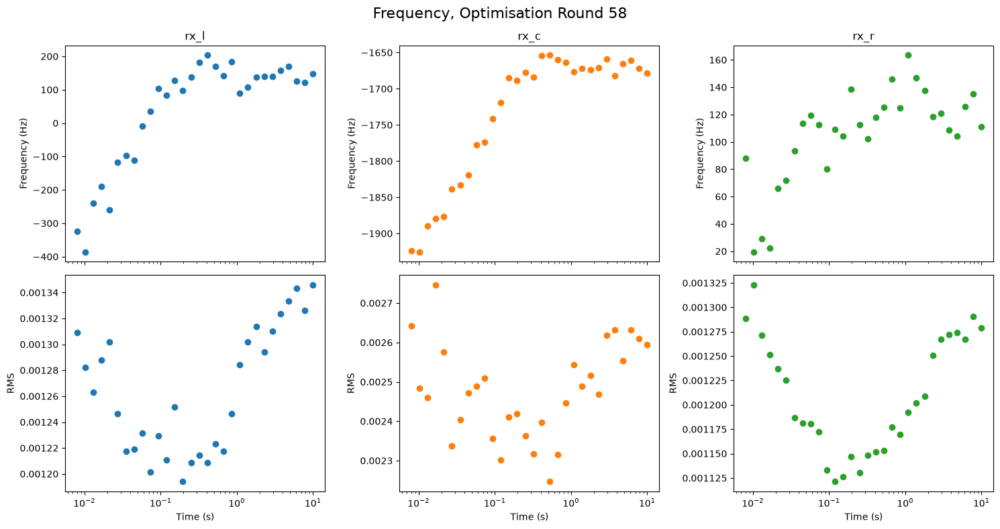

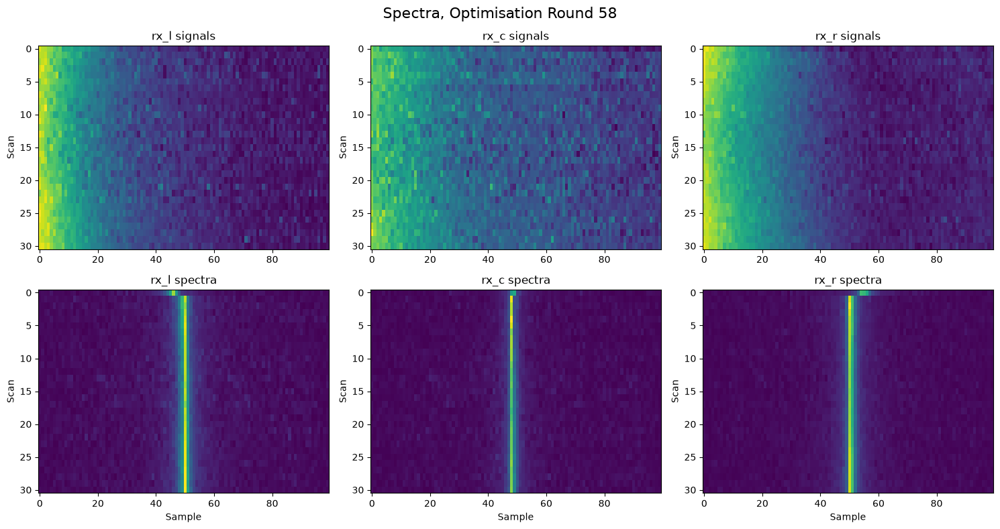

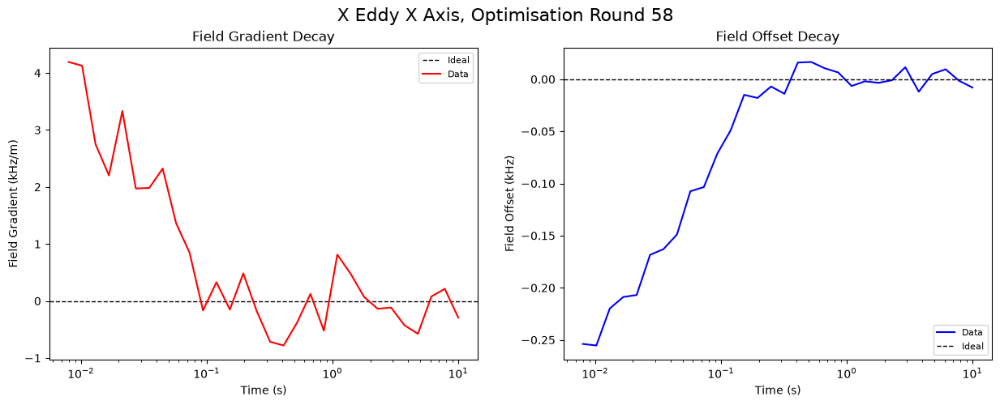

[I 2026-11-26 12:16:01,052] Trial 58 finished with value: 80.28691903410896 and parameters: {'X_A1': -0.026335606765638994, 'X_A2': 0.027655542260180202, 'X_A3': -1.2216411042392805e-08, 'X_A4': 9.748879690276505e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 8.029e+01
Total cost = 8.029e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0031661663771757713
B nanmax = 0.0031661663771757713
B contains nan = False
Trial 59


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.00316117294108241 !!!!!!!!!!!!!!!!


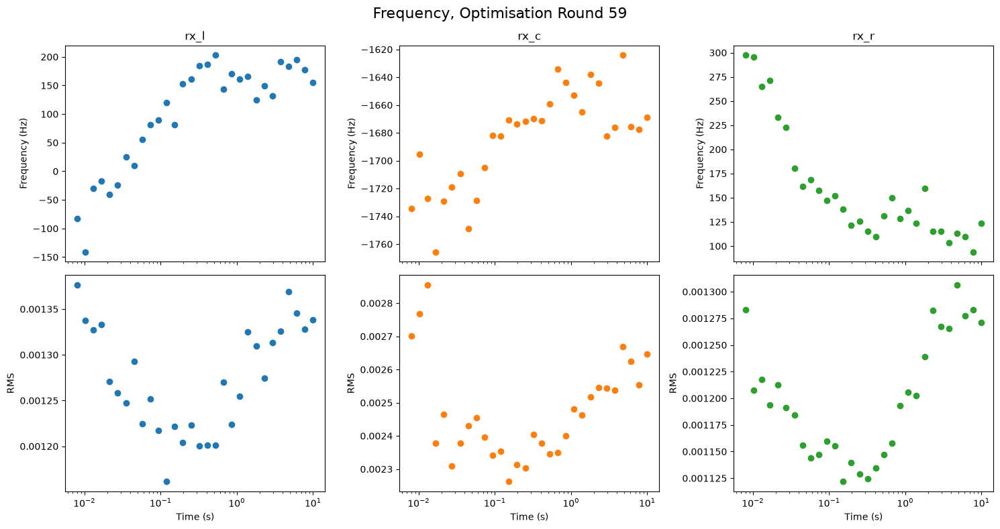

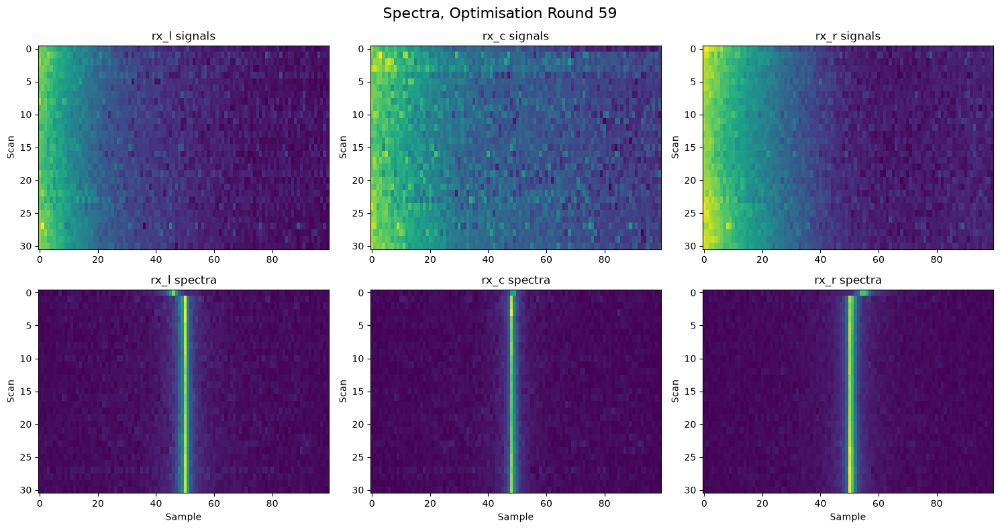

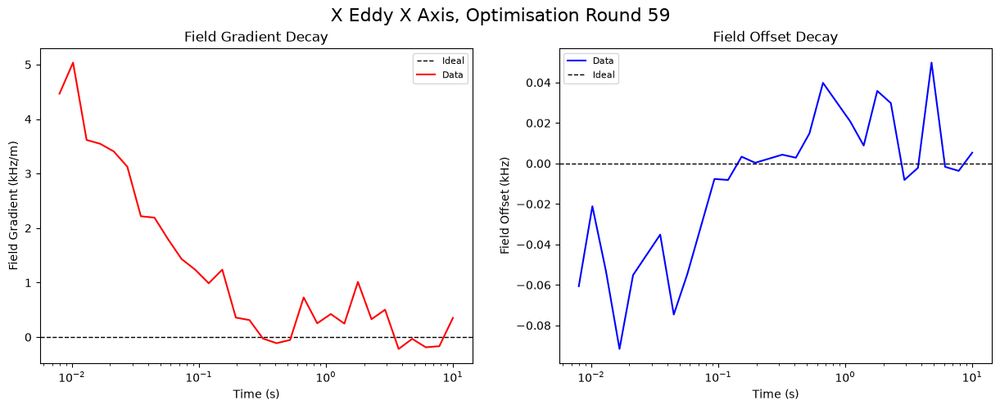

[I 2026-11-26 12:17:22,775] Trial 59 finished with value: 144.20424443301434 and parameters: {'X_A1': -0.027232946694813208, 'X_A2': 0.026861553433582035, 'X_A3': -9.569832220206557e-09, 'X_A4': 7.974539733521518e-09}. Best is trial 6 with value: 62.853818679539.


rx_c: 1.442e+02
Total cost = 1.442e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.033464040823925775
B nanmax = 0.033464040823925775
B contains nan = False
Trial 60


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.03313092094640159 !!!!!!!!!!!!!!!!


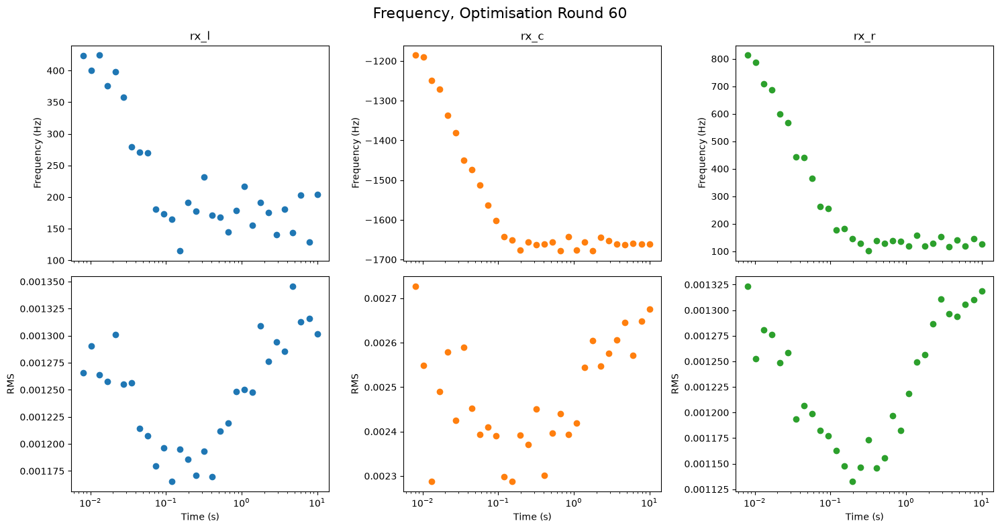

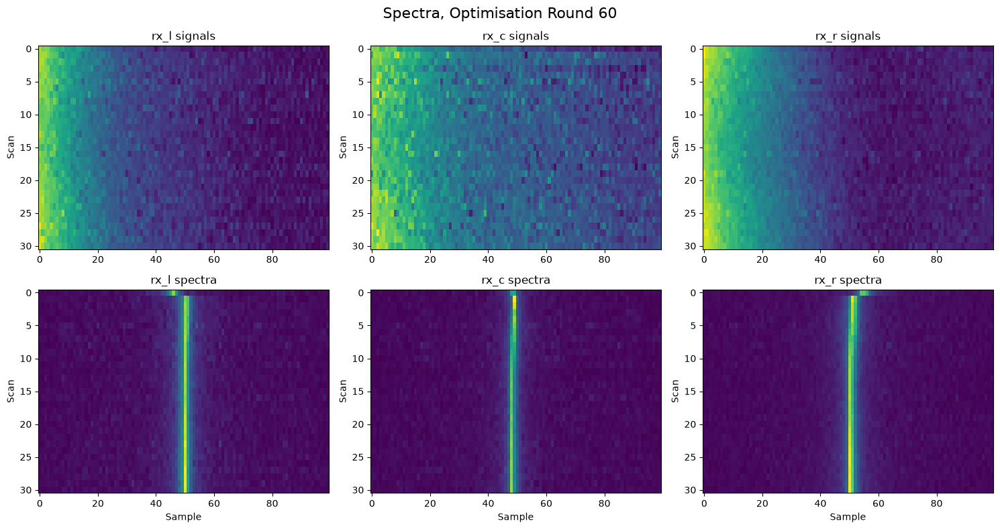

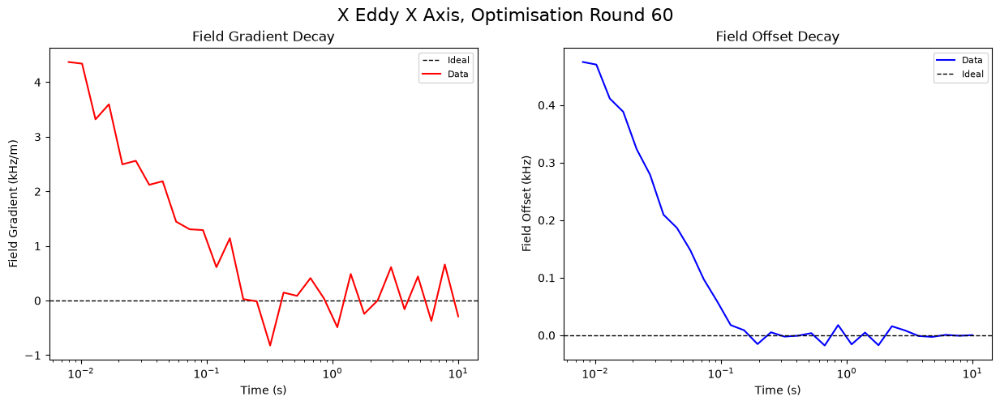

[I 2026-11-26 12:18:44,186] Trial 60 finished with value: 62.637085877194814 and parameters: {'X_A1': -0.030255768098262886, 'X_A2': 0.025819811161252853, 'X_A3': -1.0250552678717223e-08, 'X_A4': 8.225424382610826e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 6.264e+01
Total cost = 6.264e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.019185888804245103
B nanmax = 0.019185888804245103
B contains nan = False
Trial 61


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.018994896473719824 !!!!!!!!!!!!!!!!


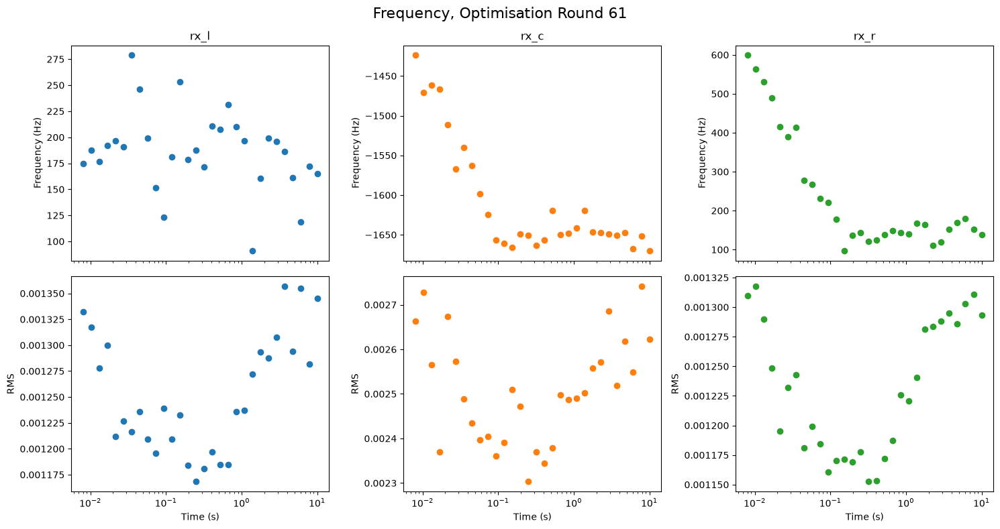

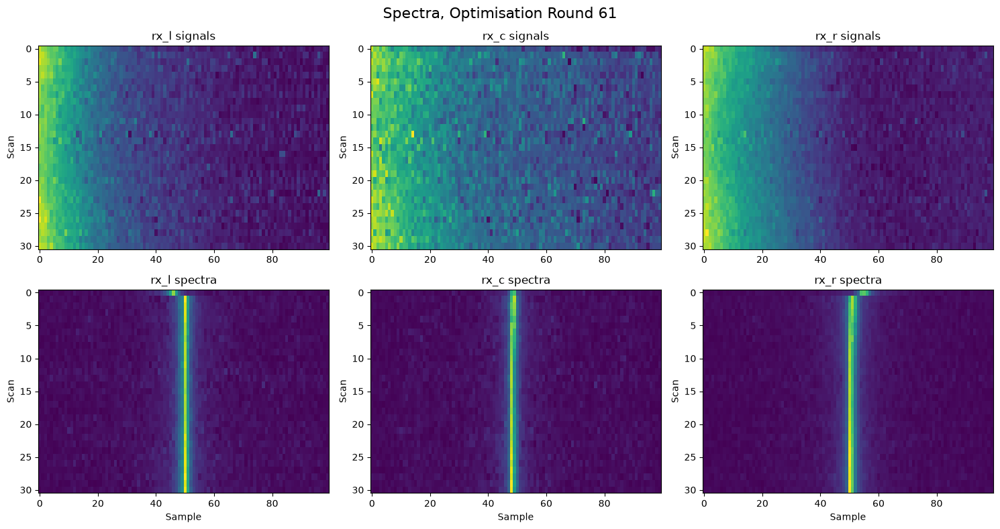

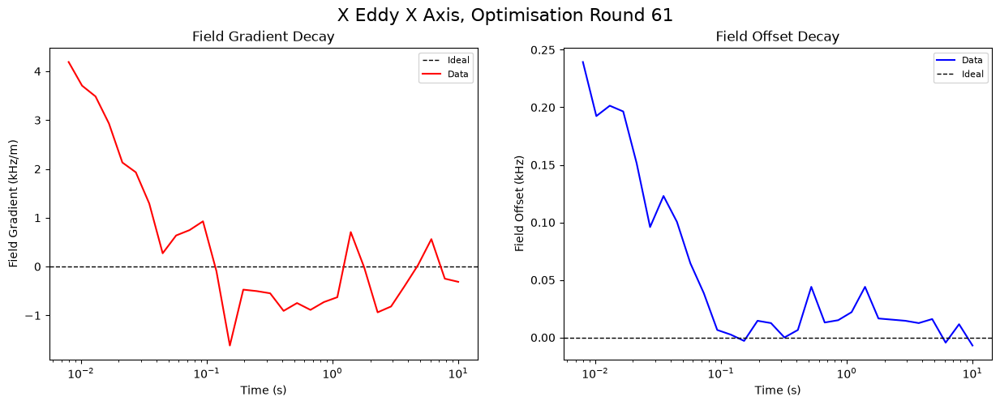

[I 2026-11-26 12:20:05,388] Trial 61 finished with value: 136.30455775781328 and parameters: {'X_A1': -0.026918114537640675, 'X_A2': 0.02437758091607341, 'X_A3': -1.0948309667261215e-08, 'X_A4': 8.587625521691057e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.363e+02
Total cost = 1.363e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.03901769741258091
B nanmax = 0.03901769741258091
B contains nan = False
Trial 62


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0386293259621508 !!!!!!!!!!!!!!!!


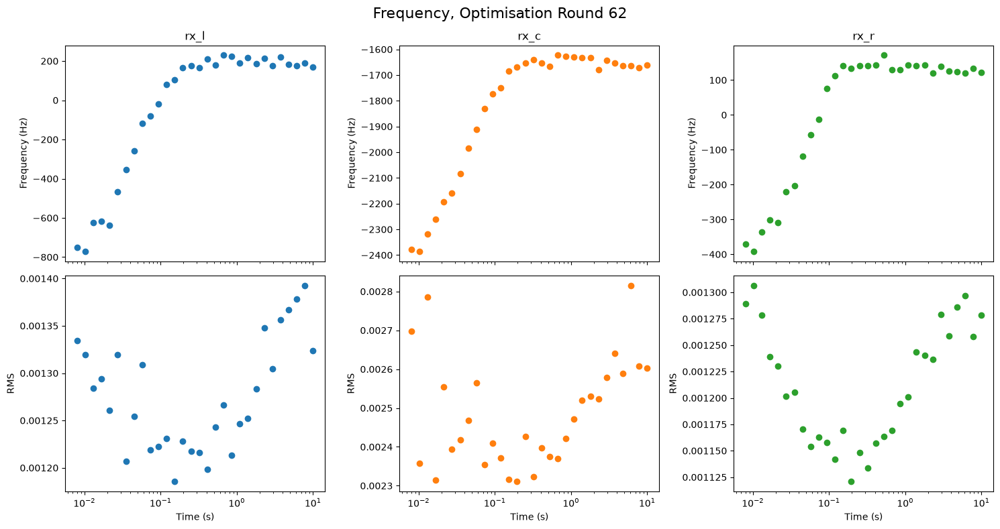

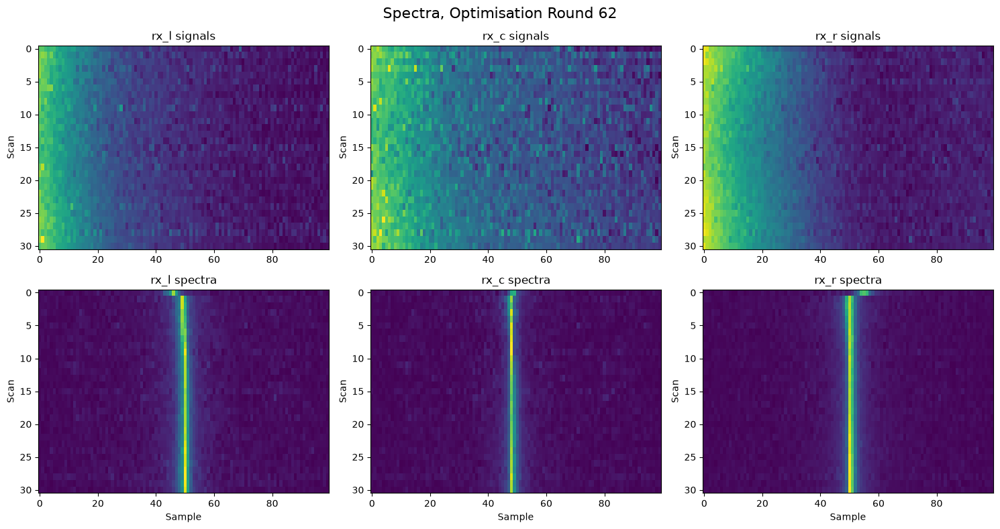

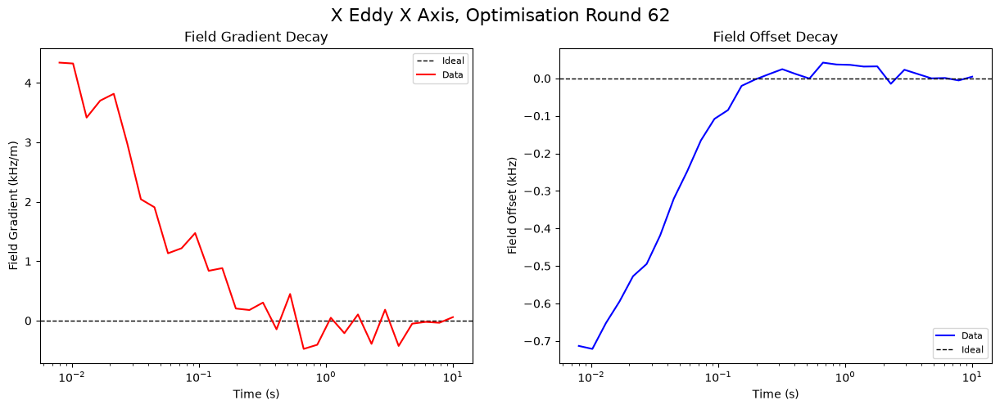

[I 2026-11-26 12:21:26,675] Trial 62 finished with value: 139.32930289342207 and parameters: {'X_A1': -0.024746418472749852, 'X_A2': 0.029935662915496635, 'X_A3': -1.1266021155510261e-08, 'X_A4': 7.367884141970368e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.393e+02
Total cost = 1.393e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.04072631713602676
B nanmax = 0.04072631713602676
B contains nan = False
Trial 63


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.04032093939422648 !!!!!!!!!!!!!!!!


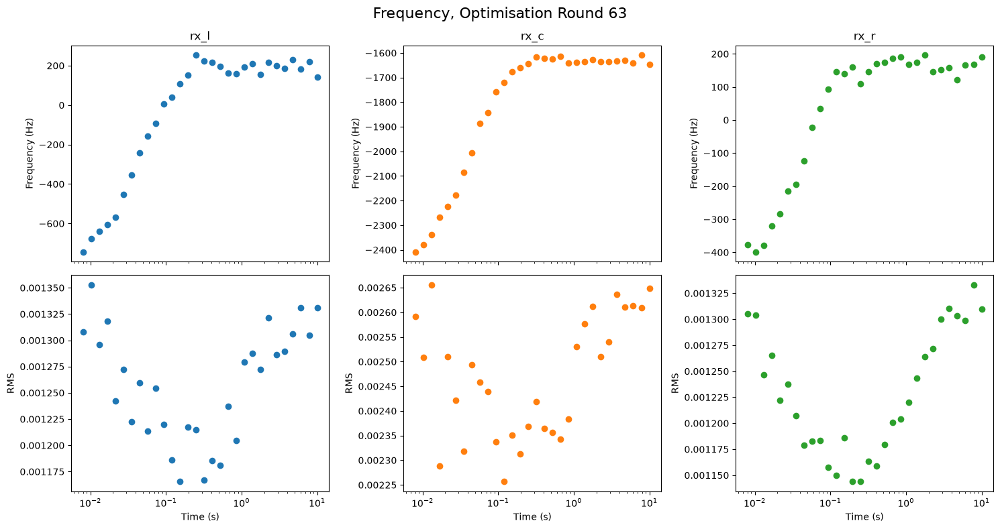

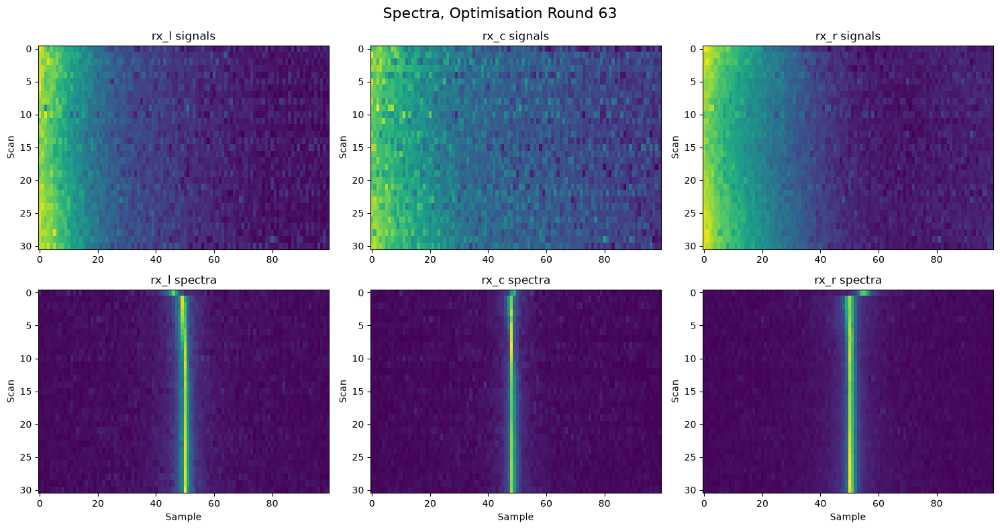

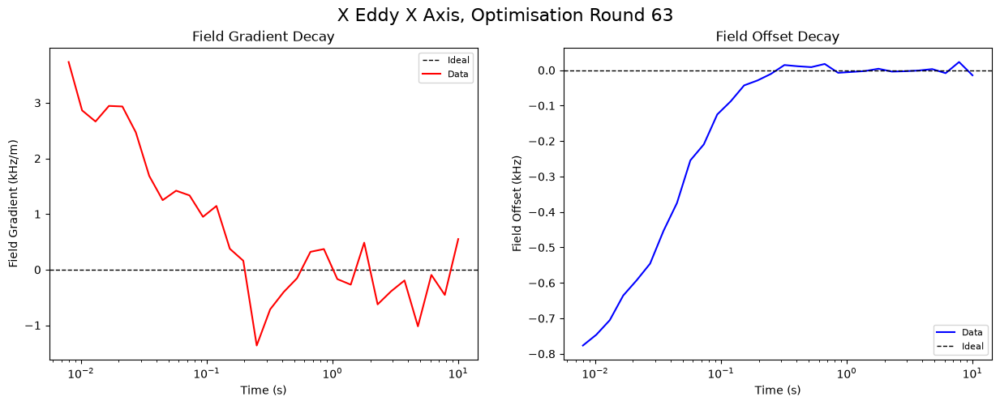

[I 2026-11-26 12:22:47,875] Trial 63 finished with value: 133.44414217417602 and parameters: {'X_A1': -0.02737514634599337, 'X_A2': 0.03279207261648909, 'X_A3': -1.2026961788279597e-08, 'X_A4': 7.900075382089504e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.334e+02
Total cost = 1.334e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.019589012290707107
B nanmax = 0.019589012290707107
B contains nan = False
Trial 64


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.019394006761358506 !!!!!!!!!!!!!!!!


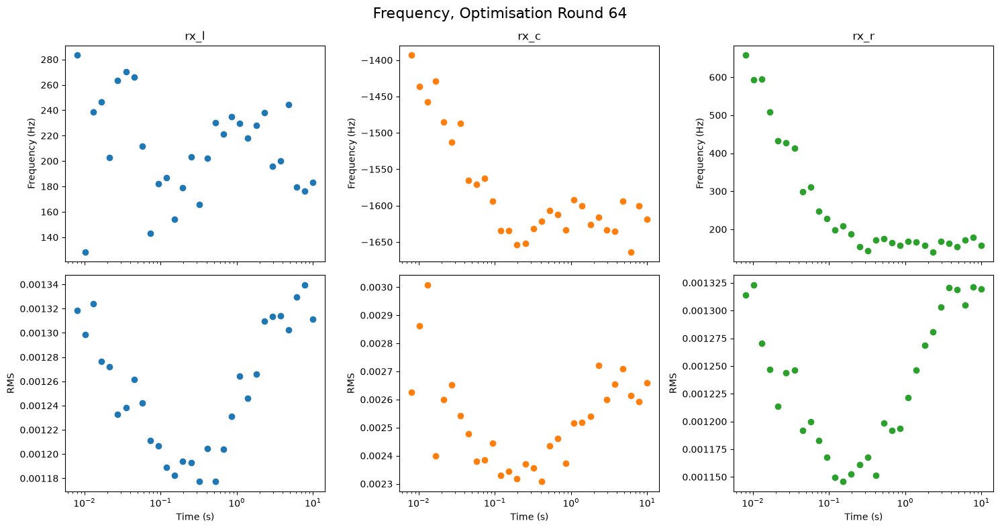

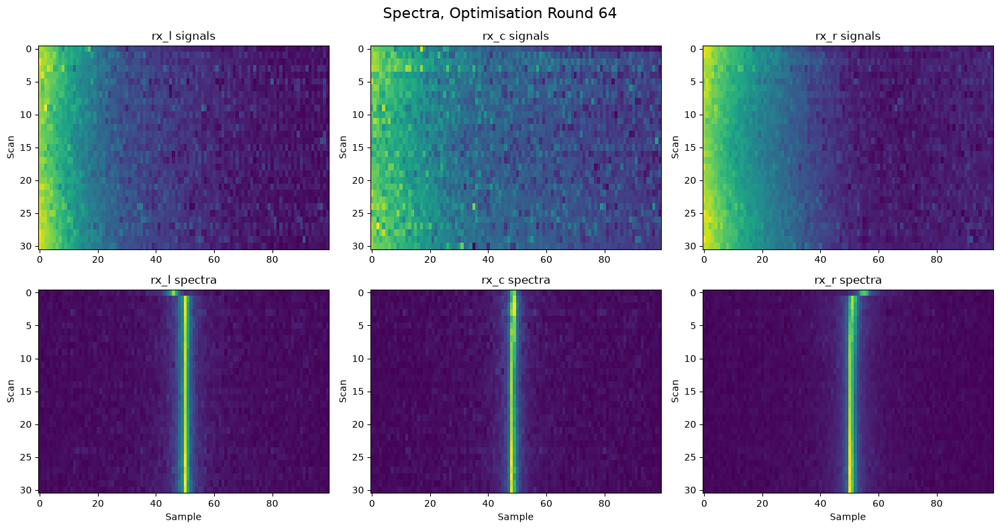

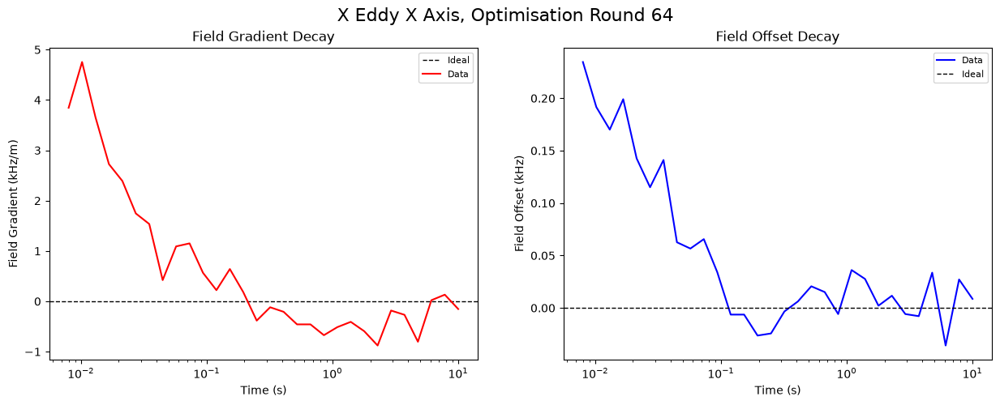

[I 2026-11-26 12:24:08,937] Trial 64 finished with value: 214.00021810388768 and parameters: {'X_A1': -0.027799187514713067, 'X_A2': 0.0252053634612424, 'X_A3': -9.943727197918337e-09, 'X_A4': 9.847877999280842e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 2.140e+02
Total cost = 2.140e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.022702840598037167
B nanmax = 0.022702840598037167
B contains nan = False
Trial 65


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0224768385915179 !!!!!!!!!!!!!!!!


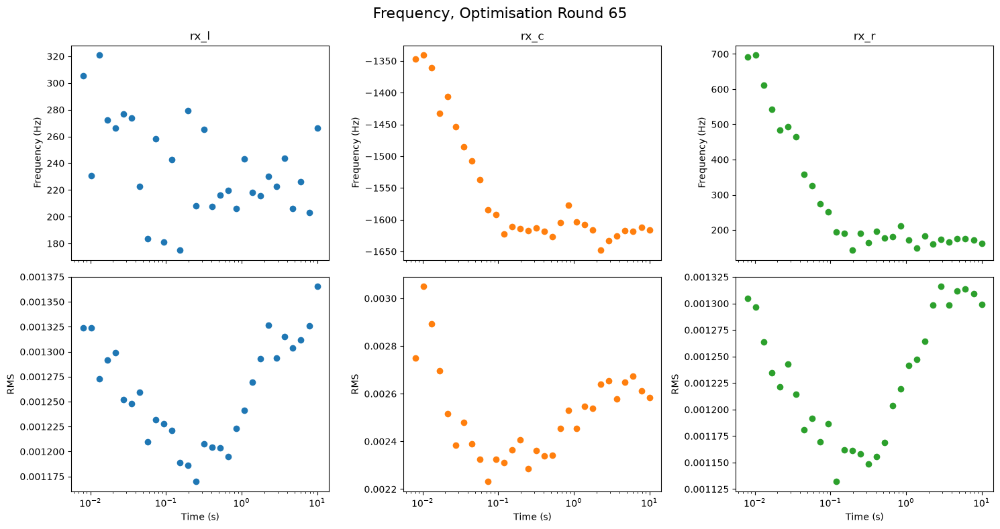

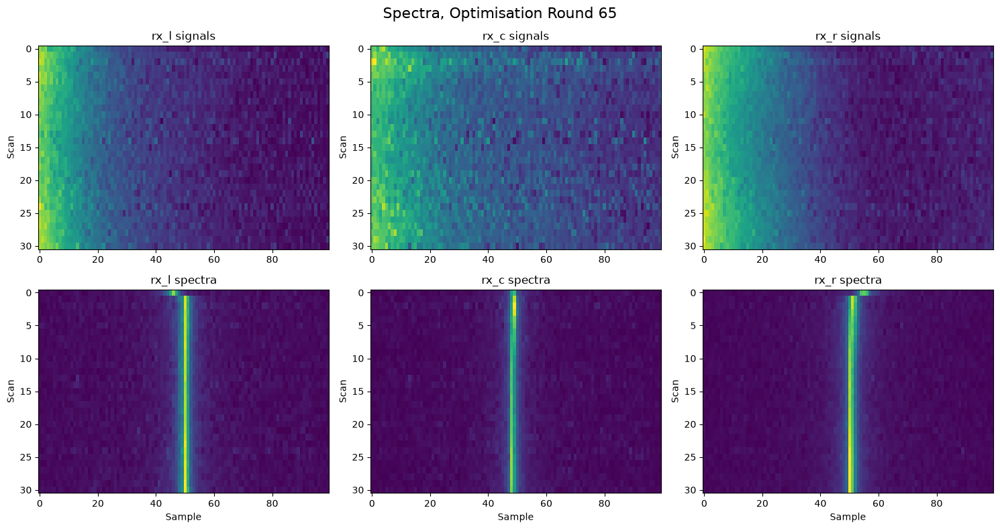

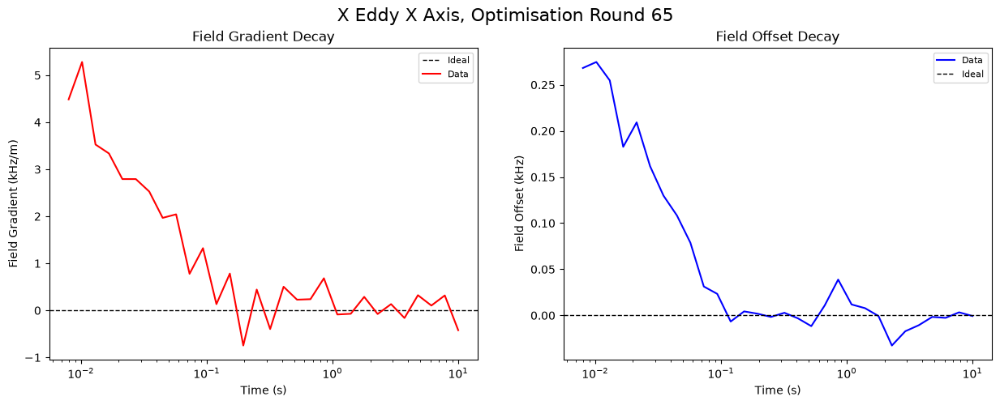

[I 2026-11-26 12:25:35,490] Trial 65 finished with value: 82.38172990249949 and parameters: {'X_A1': -0.0300251402054575, 'X_A2': 0.027018382544539563, 'X_A3': -1.1073600436501272e-08, 'X_A4': 7.894158260516688e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 8.238e+01
Total cost = 8.238e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.014785810554025931
B nanmax = 0.014785810554025931
B contains nan = False
Trial 66


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01463864500598416 !!!!!!!!!!!!!!!!


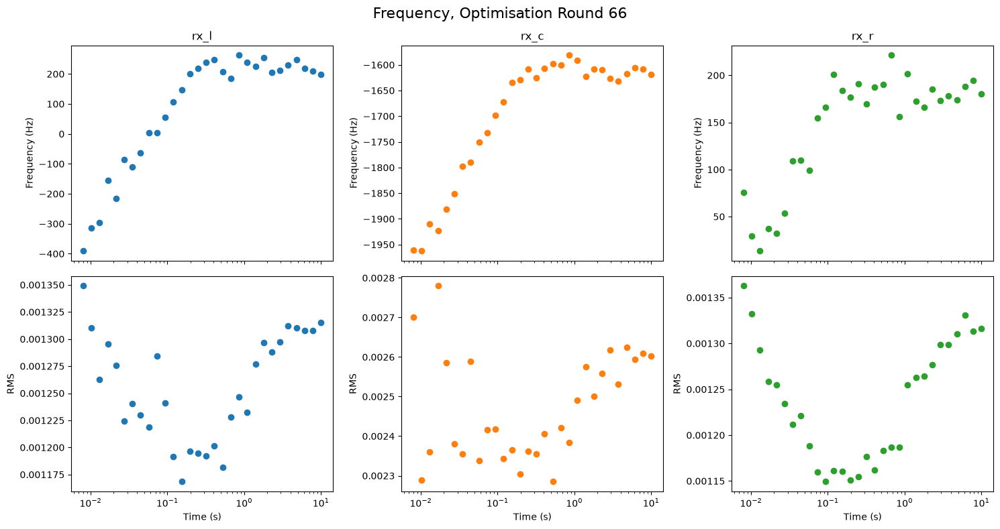

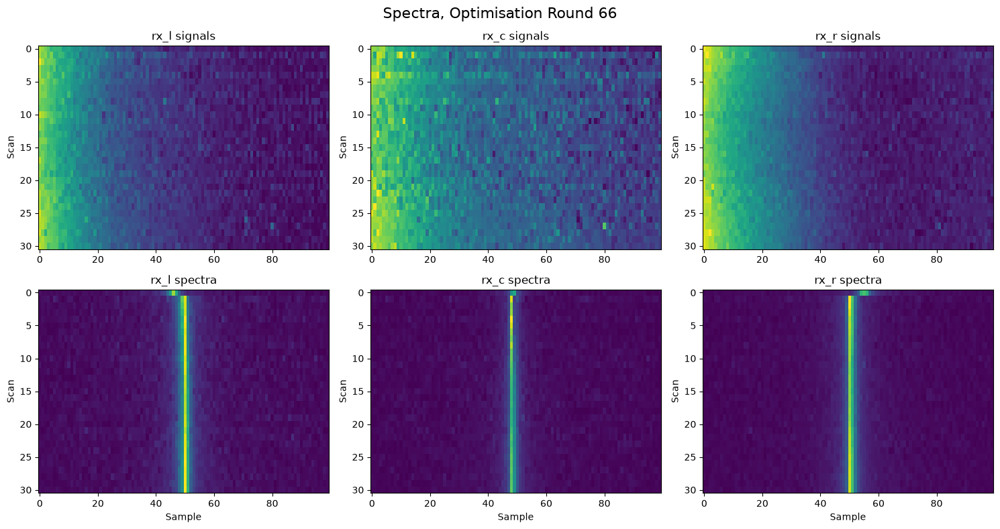

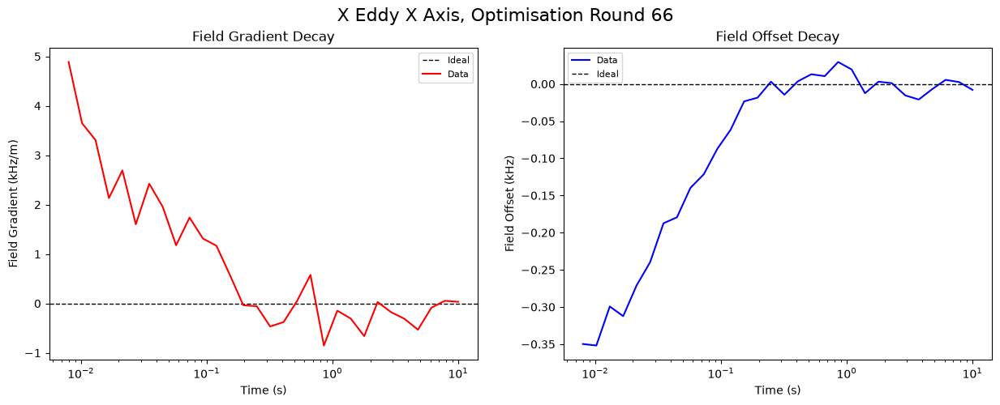

[I 2026-11-26 12:26:56,617] Trial 66 finished with value: 103.98922108365936 and parameters: {'X_A1': -0.02473278806212109, 'X_A2': 0.026703634146845193, 'X_A3': -1.002497004073534e-08, 'X_A4': 8.765527372027957e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.040e+02
Total cost = 1.040e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.002646013464208641
B nanmax = 0.002646013464208641
B contains nan = False
Trial 67


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.002641932360525139 !!!!!!!!!!!!!!!!


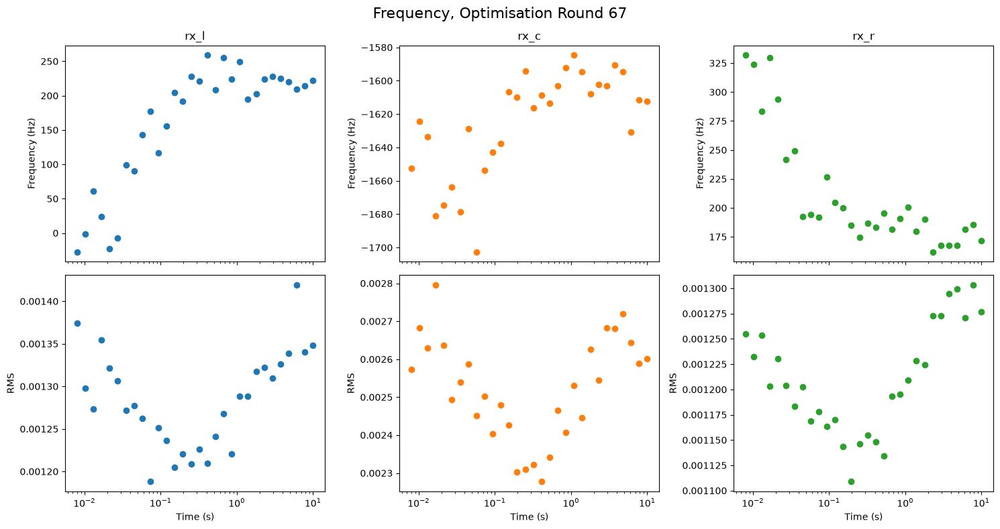

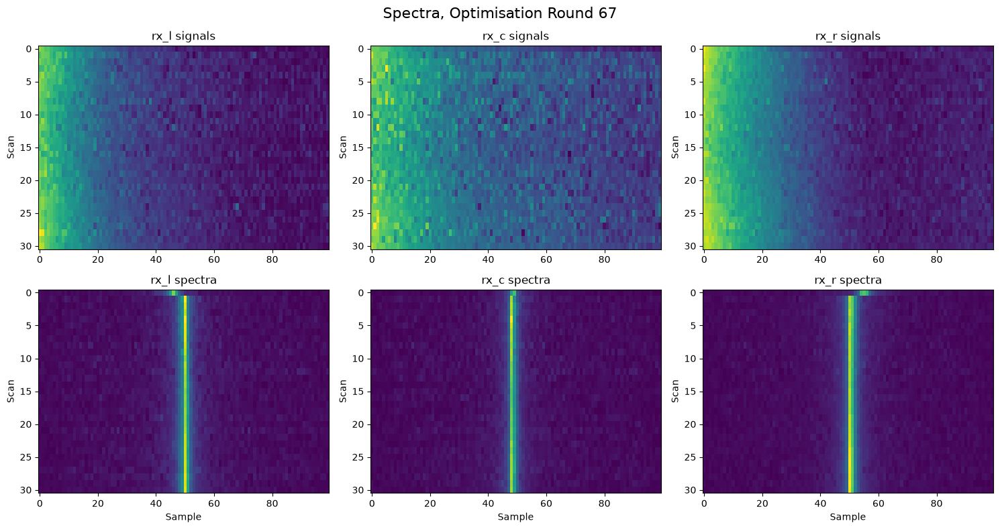

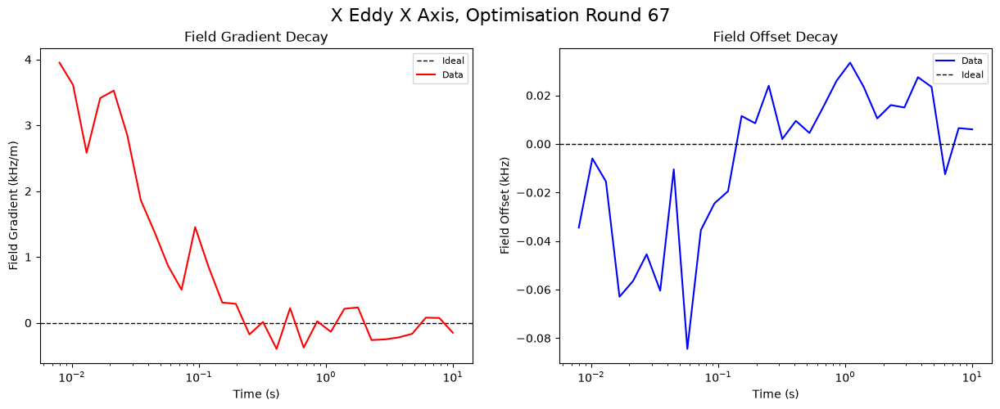

[I 2026-11-26 12:28:17,781] Trial 67 finished with value: 150.121321060733 and parameters: {'X_A1': -0.02388998899798556, 'X_A2': 0.023593367115670793, 'X_A3': -1.2083866916733294e-08, 'X_A4': 7.461711624351226e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.501e+02
Total cost = 1.501e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.03365384176801158
B nanmax = 0.03365384176801158
B contains nan = False
Trial 68


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.03331883257294664 !!!!!!!!!!!!!!!!


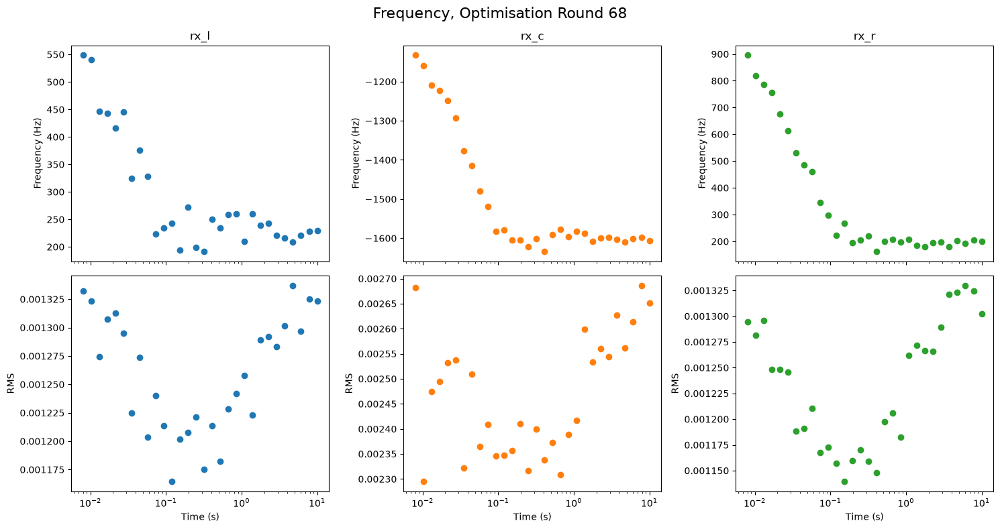

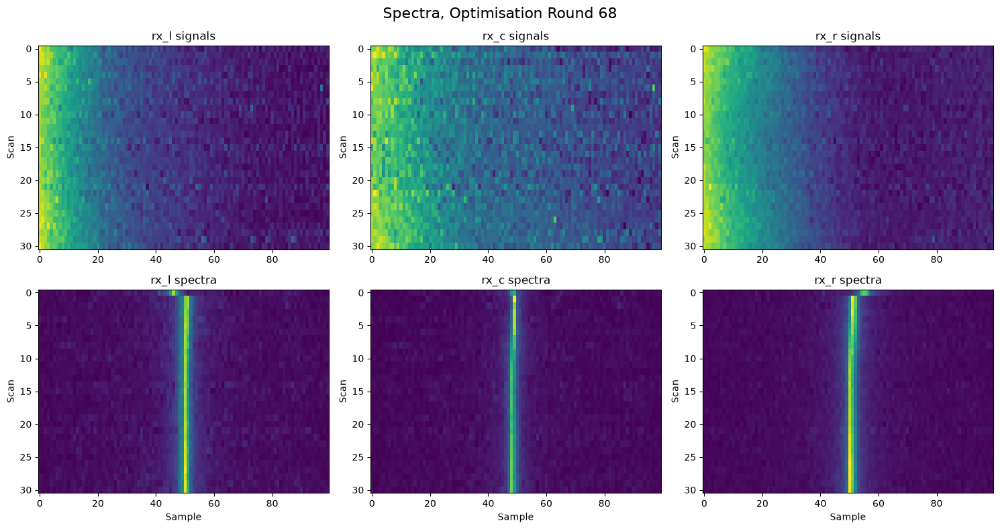

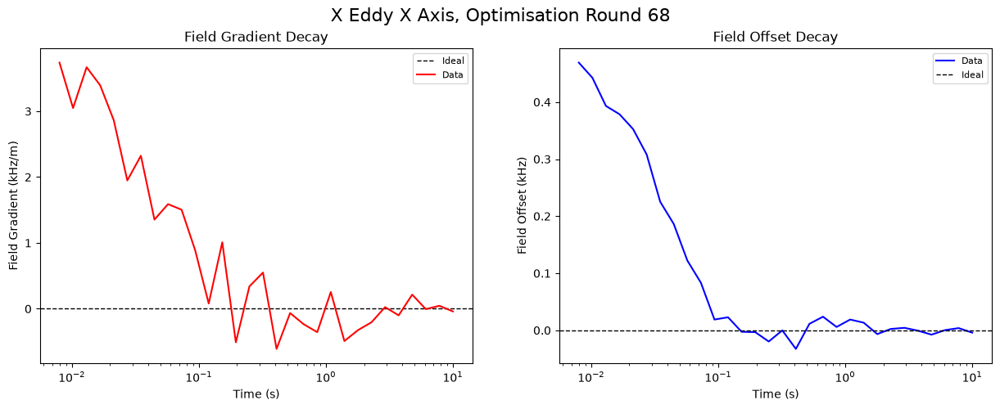

[I 2026-11-26 12:29:39,435] Trial 68 finished with value: 67.71317494601831 and parameters: {'X_A1': -0.03030277086117001, 'X_A2': 0.02584161861769524, 'X_A3': -1.0557659059717846e-08, 'X_A4': 9.82974262904358e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 6.771e+01
Total cost = 6.771e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.017306692531902423
B nanmax = 0.017306692531902423
B contains nan = False
Trial 69


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01713440325658504 !!!!!!!!!!!!!!!!


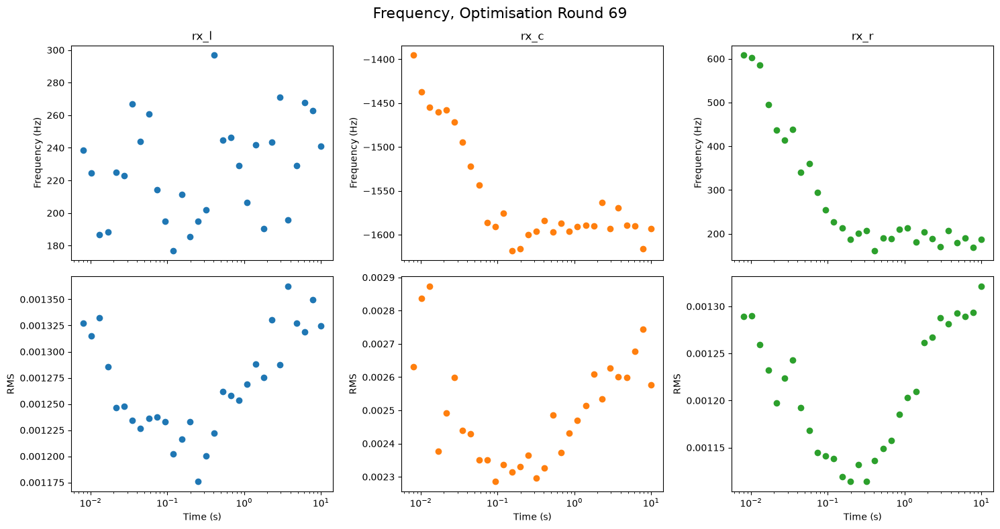

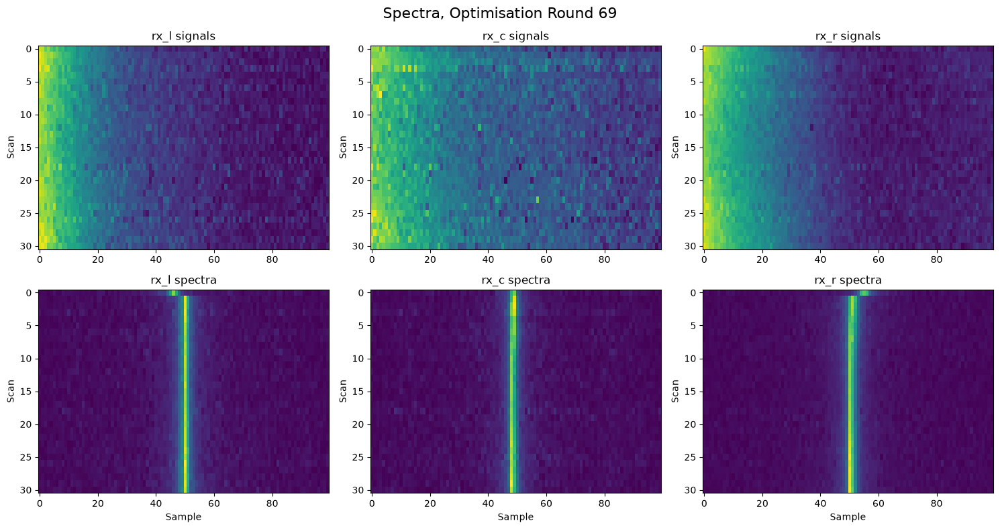

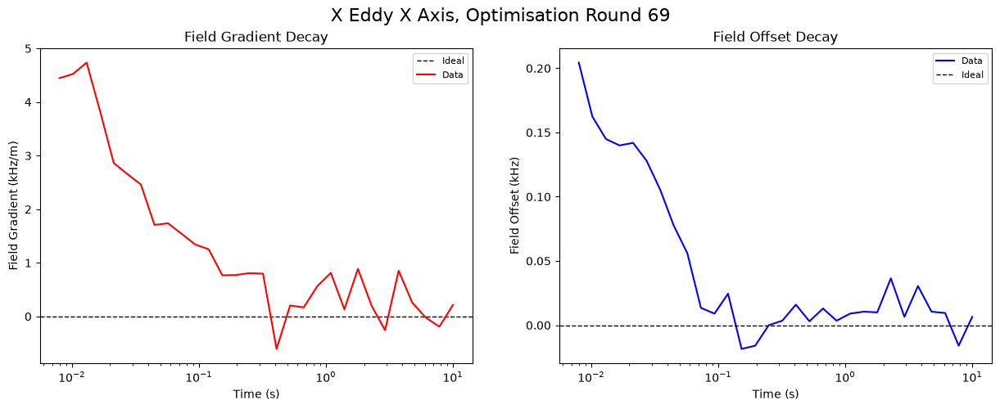

[I 2026-11-26 12:31:00,417] Trial 69 finished with value: 143.0616339339473 and parameters: {'X_A1': -0.03169269984996406, 'X_A2': 0.029403114796945087, 'X_A3': -1.0362138357066568e-08, 'X_A4': 9.674974828561667e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.431e+02
Total cost = 1.431e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.014660644125816785
B nanmax = 0.014660644125816785
B contains nan = False
Trial 70


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014514725255061268 !!!!!!!!!!!!!!!!


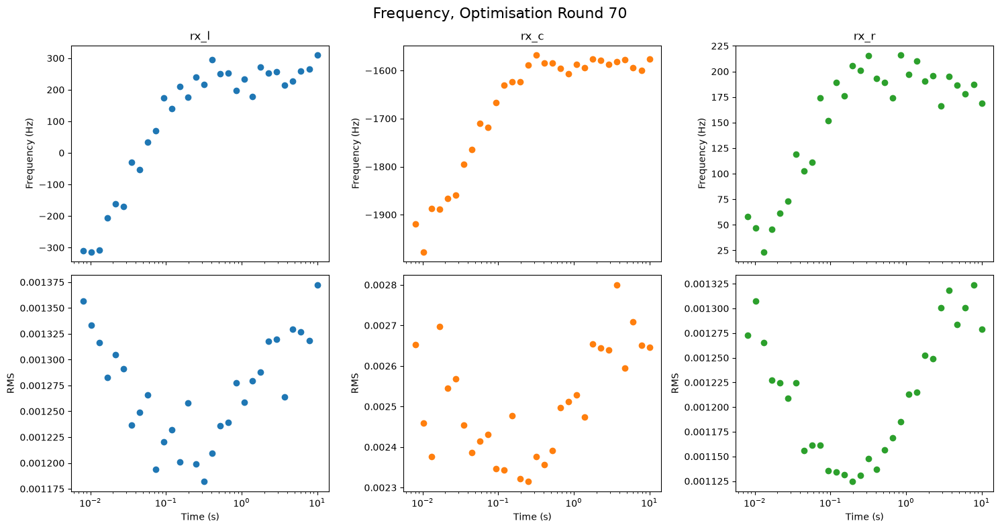

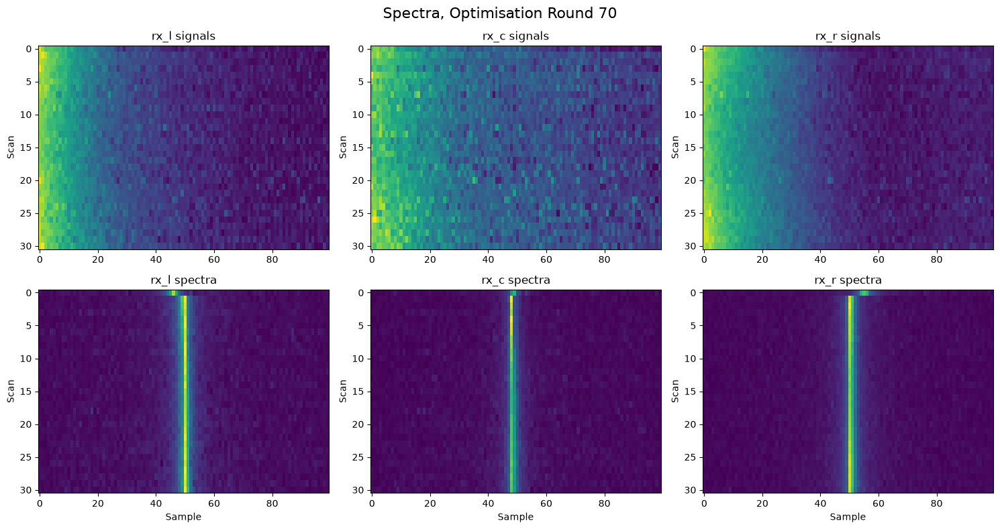

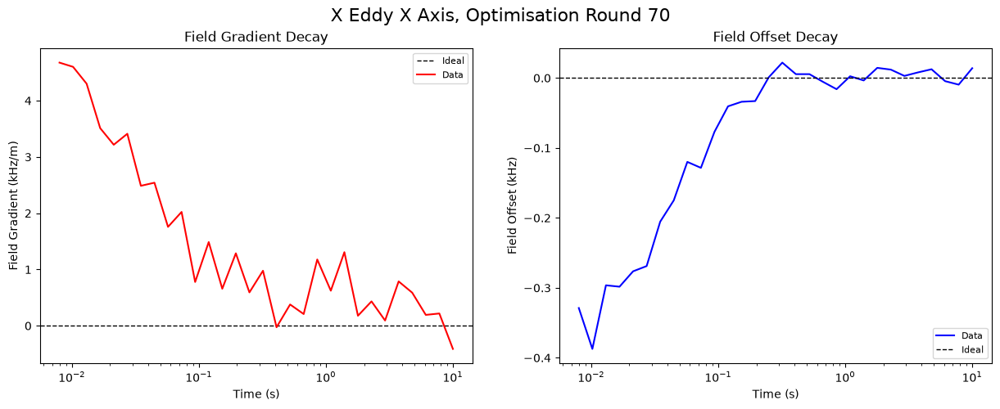

[I 2026-11-26 12:32:21,564] Trial 70 finished with value: 108.0068339954219 and parameters: {'X_A1': -0.026133456685818592, 'X_A2': 0.028088077657192987, 'X_A3': -1.1612273181331729e-08, 'X_A4': 6.558458810767027e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.080e+02
Total cost = 1.080e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.006301779026128955
B nanmax = 0.006301779026128955
B contains nan = False
Trial 71


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.006239066339818162 !!!!!!!!!!!!!!!!


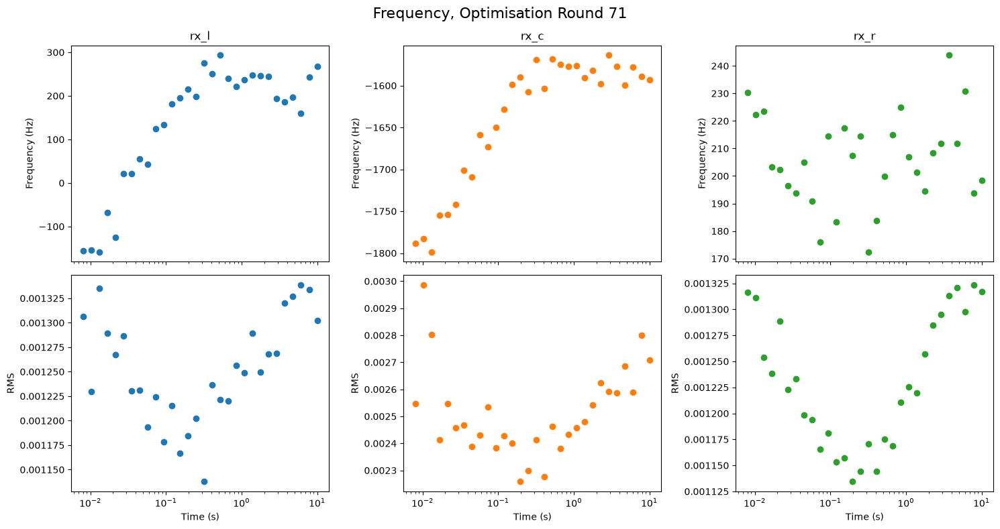

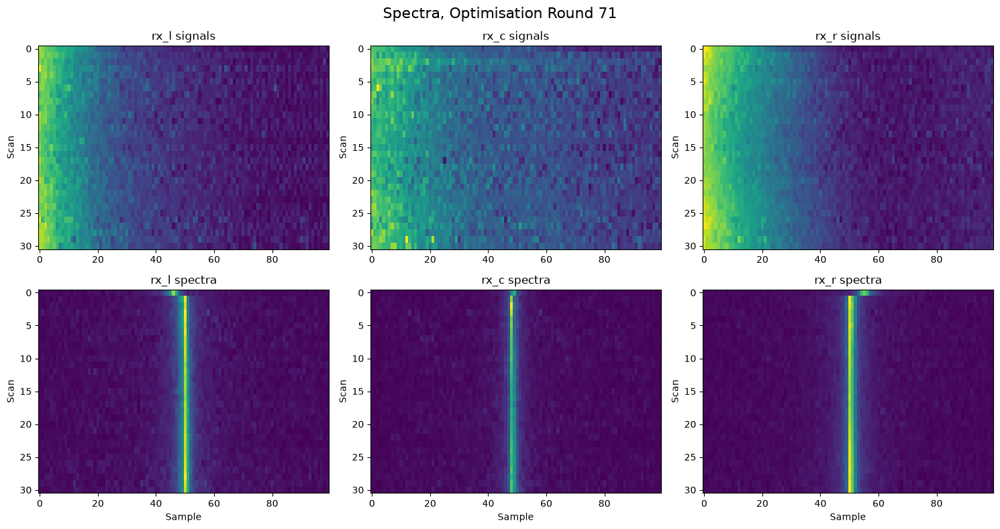

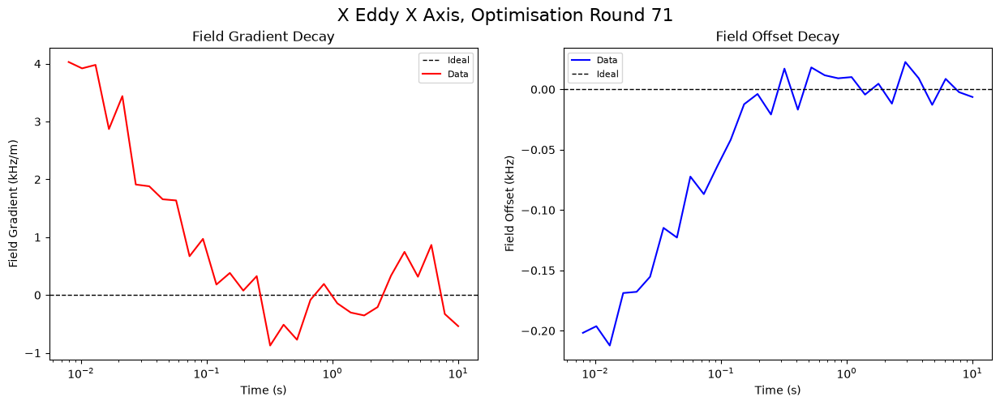

[I 2026-11-26 12:33:43,036] Trial 71 finished with value: 100.85755583812104 and parameters: {'X_A1': -0.02880312354026094, 'X_A2': 0.029648309874354593, 'X_A3': -1.150214398136733e-08, 'X_A4': 7.081947304175471e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.009e+02
Total cost = 1.009e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.009268260475097274
B nanmax = 0.009268260475097274
B contains nan = False
Trial 72


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.009176015873489495 !!!!!!!!!!!!!!!!


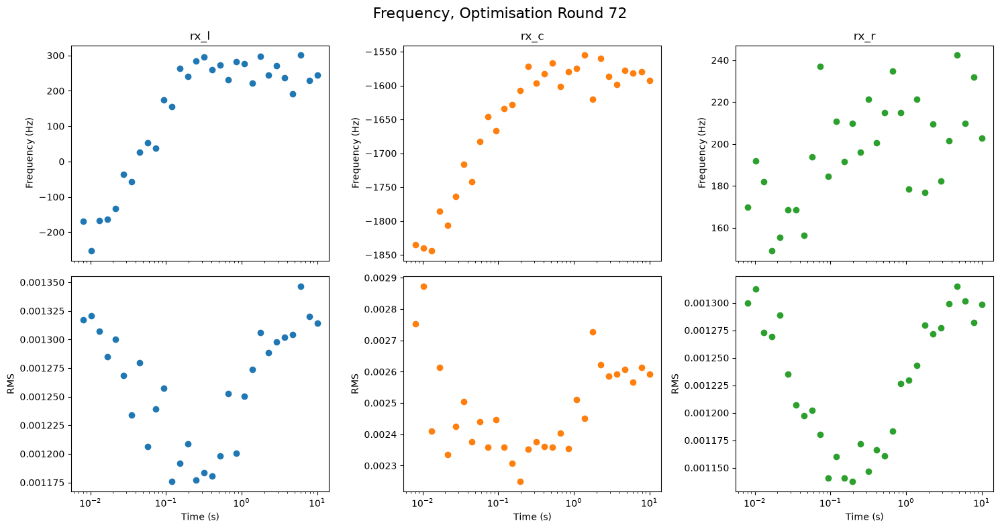

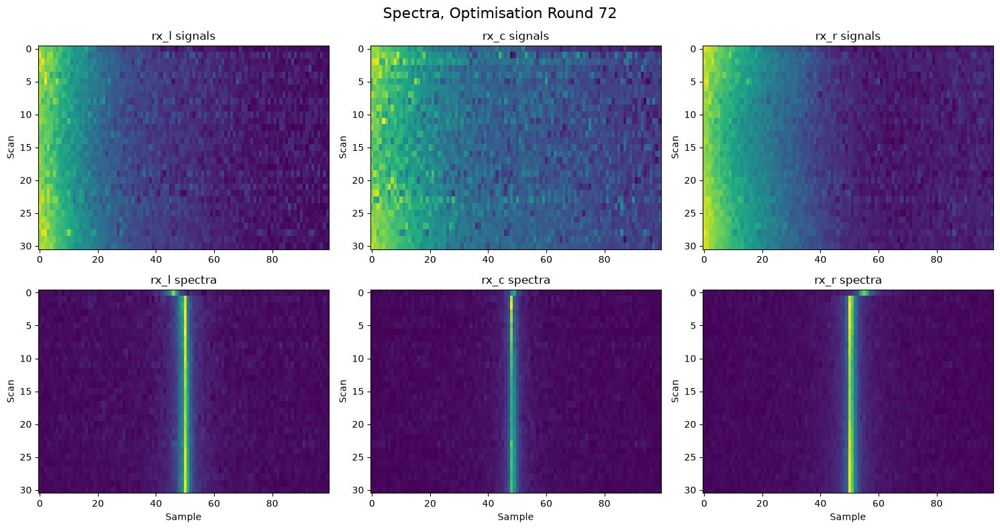

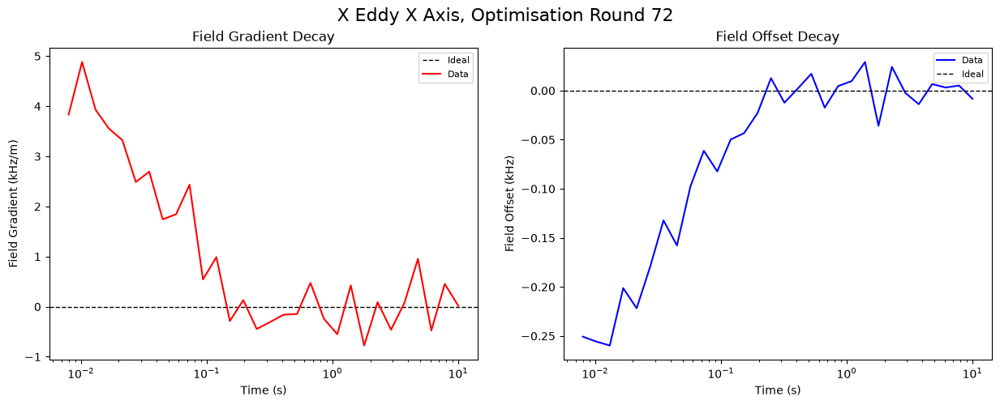

[I 2026-11-26 12:35:04,209] Trial 72 finished with value: 113.39239518828253 and parameters: {'X_A1': -0.02264427587608859, 'X_A2': 0.02388170523169534, 'X_A3': -1.2139929679630724e-08, 'X_A4': 9.35289846885567e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.134e+02
Total cost = 1.134e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.05642450240371073
B nanmax = 0.05642450240371073
B contains nan = False
Trial 73


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.055862831114403565 !!!!!!!!!!!!!!!!


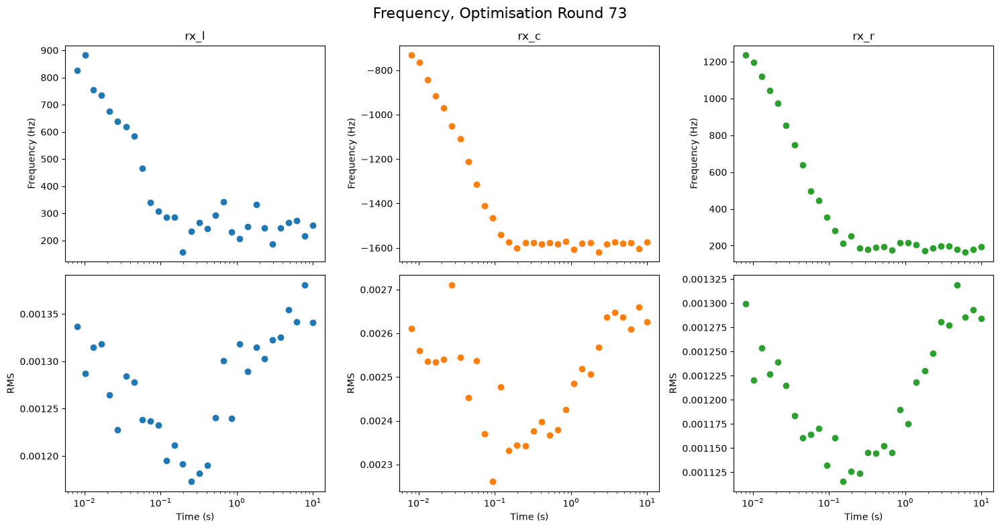

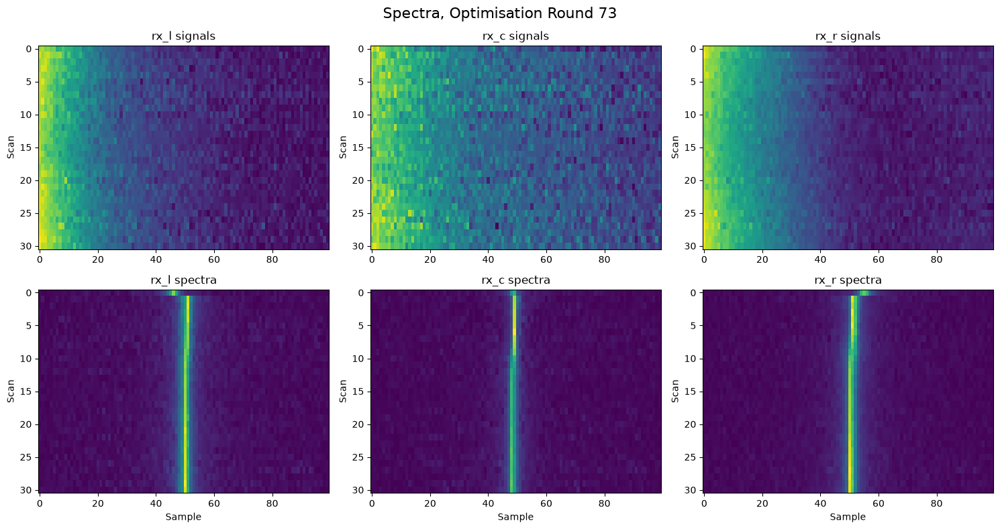

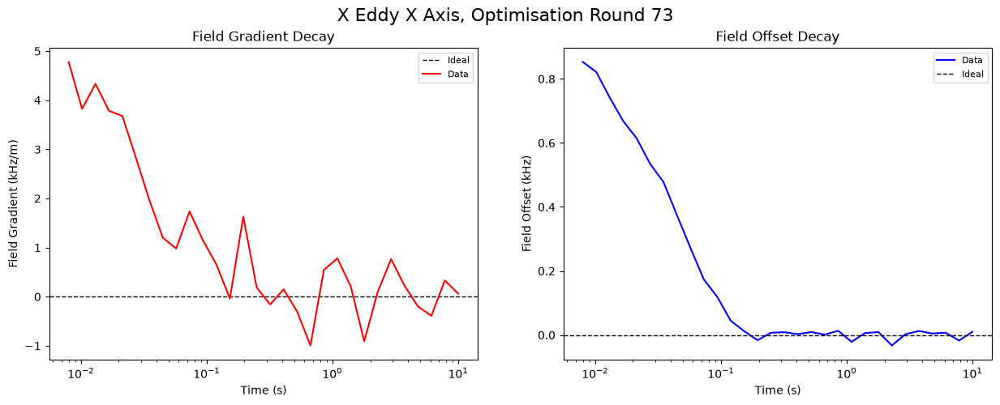

[I 2026-11-26 12:36:25,358] Trial 73 finished with value: 146.5120360041898 and parameters: {'X_A1': -0.03275401931787836, 'X_A2': 0.02526924592352032, 'X_A3': -1.0611538166716023e-08, 'X_A4': 8.457674622165956e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.465e+02
Total cost = 1.465e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.032579226985293294
B nanmax = 0.032579226985293294
B contains nan = False
Trial 74


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.032254943581233646 !!!!!!!!!!!!!!!!


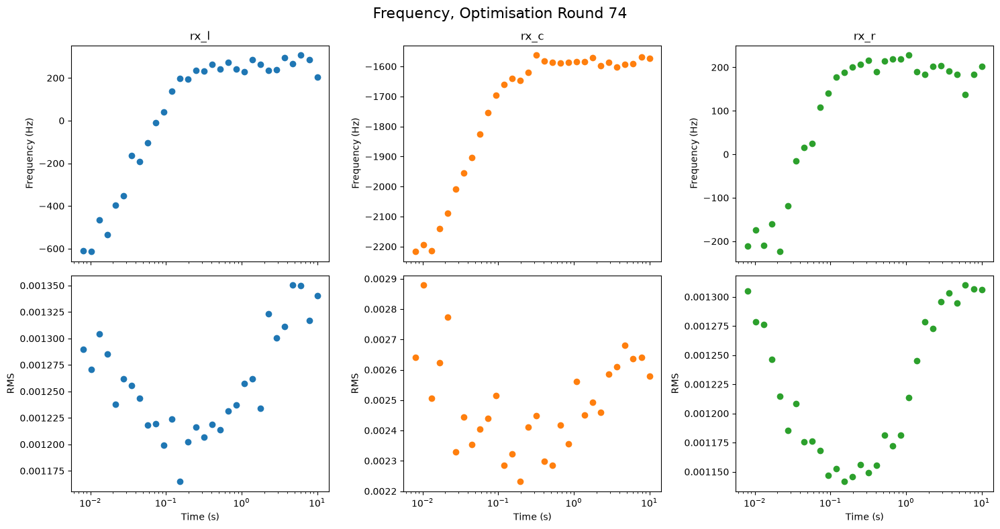

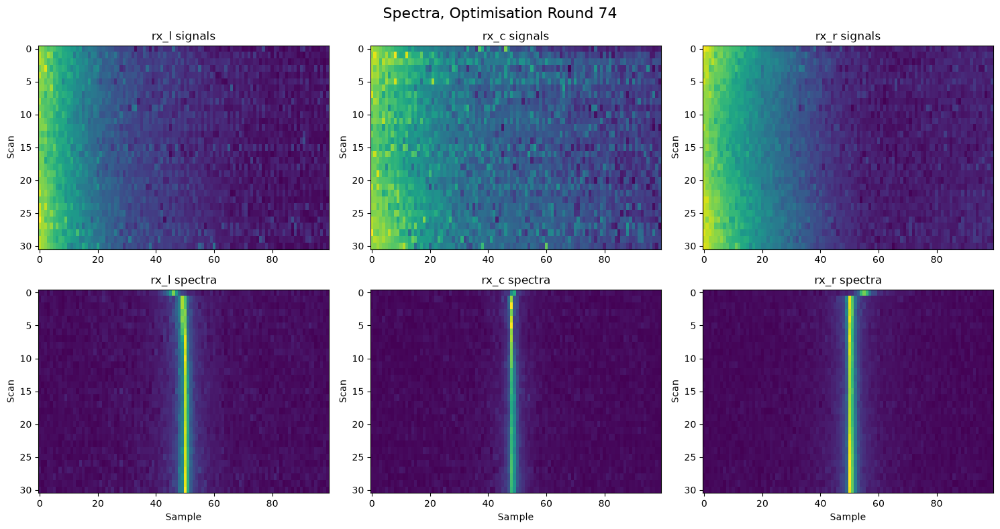

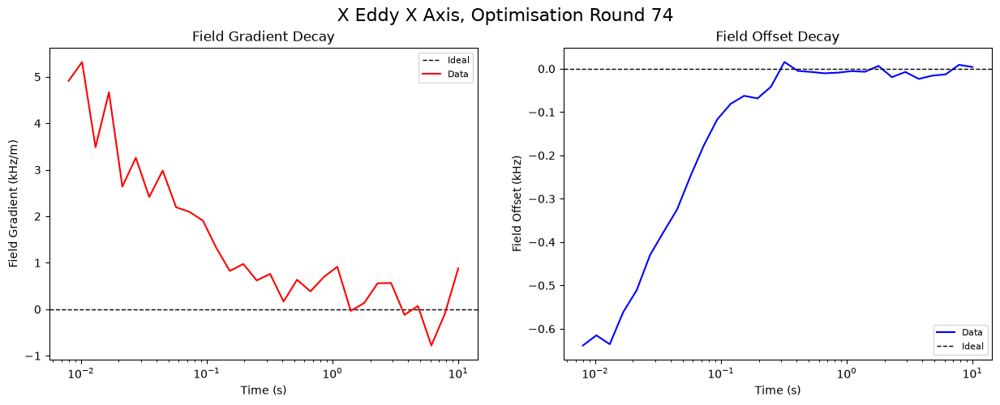

[I 2026-11-26 12:37:47,108] Trial 74 finished with value: 151.41267256752457 and parameters: {'X_A1': -0.023014356750832476, 'X_A2': 0.027347972597827654, 'X_A3': -1.1573044163279341e-08, 'X_A4': 9.952954459509575e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.514e+02
Total cost = 1.514e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.058866415299456805
B nanmax = 0.058866415299456805
B contains nan = False
Trial 75


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.058280436741951325 !!!!!!!!!!!!!!!!


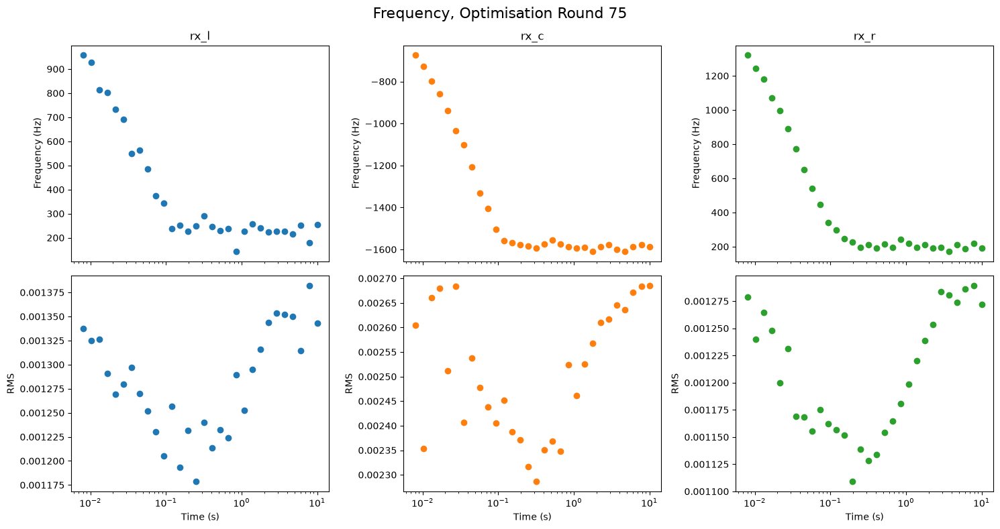

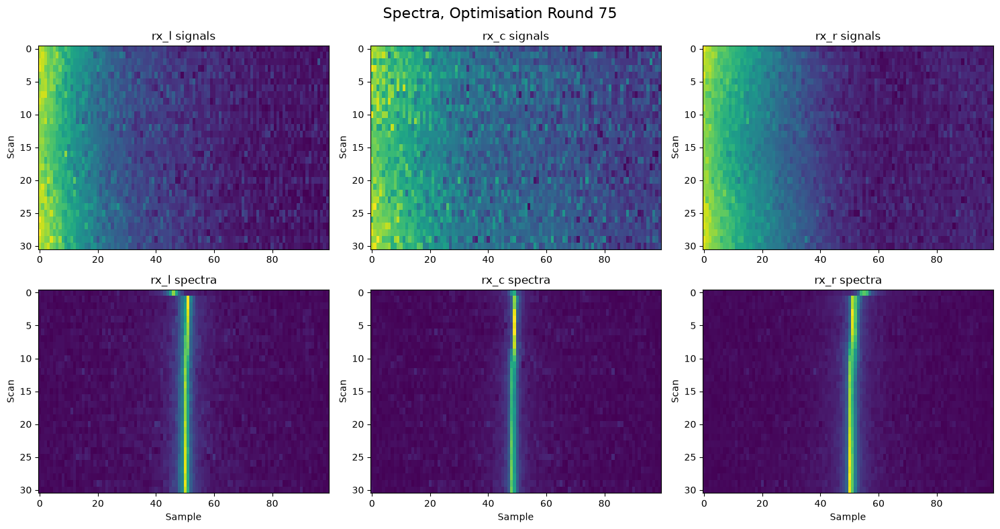

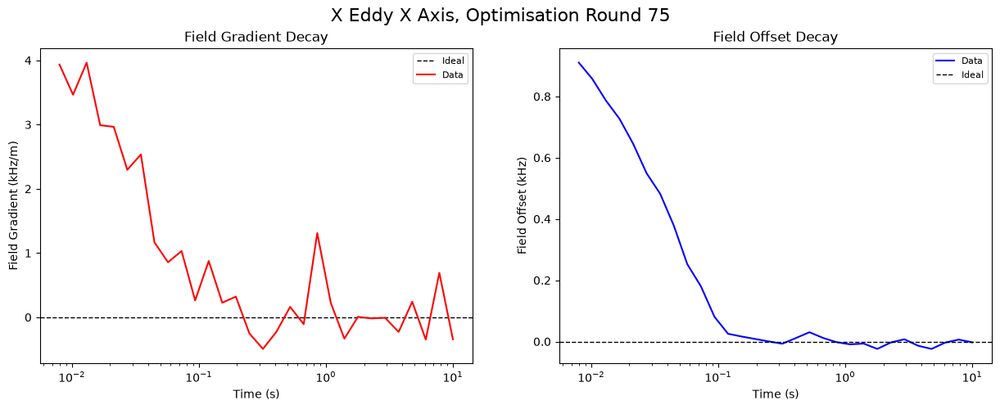

[I 2026-11-26 12:39:08,228] Trial 75 finished with value: 127.74418212163164 and parameters: {'X_A1': -0.0332965965035437, 'X_A2': 0.02548765135921484, 'X_A3': -1.0757232829383943e-08, 'X_A4': 9.985682700920543e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.277e+02
Total cost = 1.277e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.00580910966919928
B nanmax = 0.00580910966919928
B contains nan = False
Trial 76


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.005751300518745887 !!!!!!!!!!!!!!!!


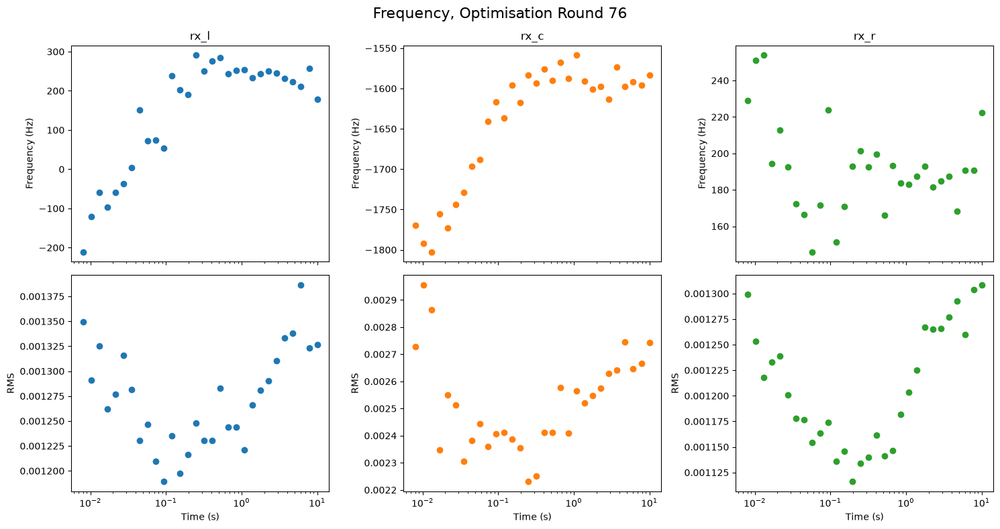

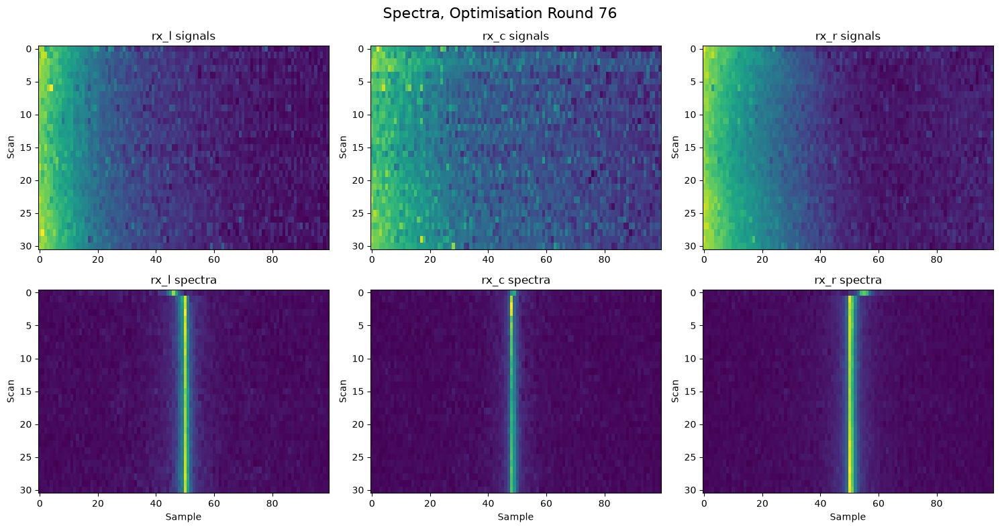

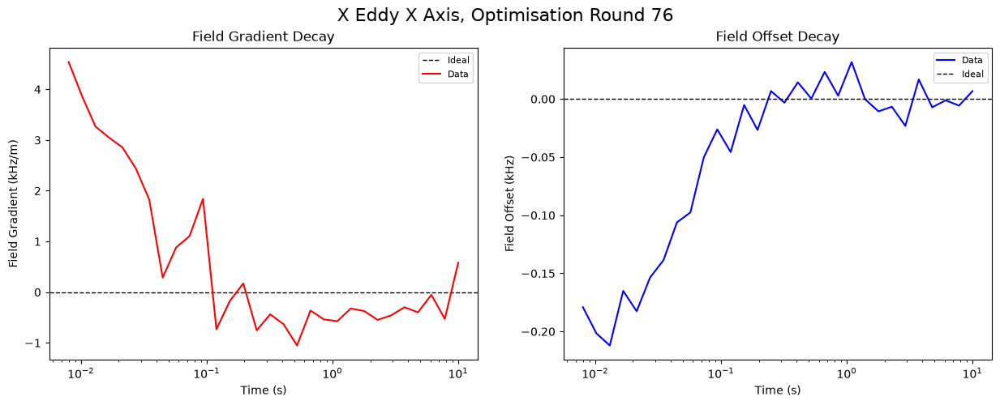

[I 2026-11-26 12:40:29,574] Trial 76 finished with value: 97.2807584796044 and parameters: {'X_A1': -0.027829344449361464, 'X_A2': 0.028608818730248047, 'X_A3': -1.085993125723155e-08, 'X_A4': 8.539036104775543e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 9.728e+01
Total cost = 9.728e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0017798133444932329
B nanmax = 0.0017798133444932329
B contains nan = False
Trial 77


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0017765834628754133 !!!!!!!!!!!!!!!!


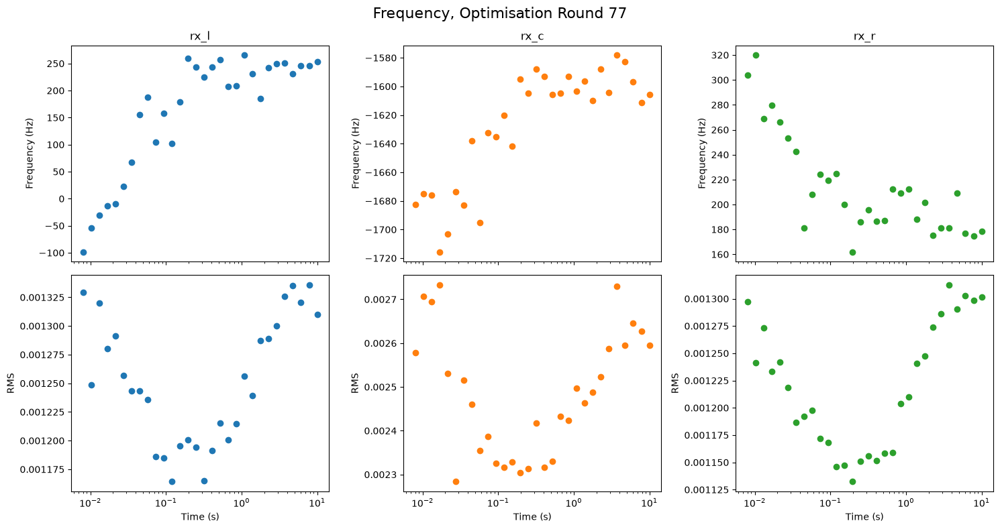

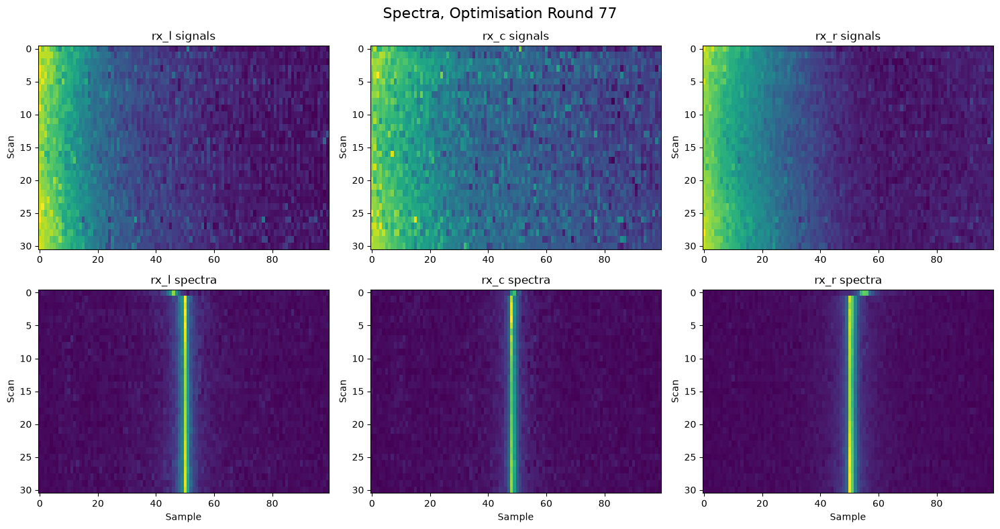

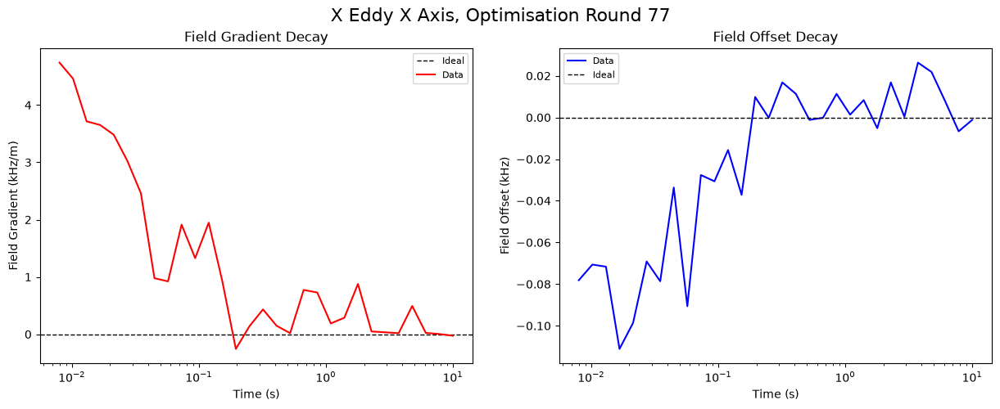

[I 2026-11-26 12:41:50,788] Trial 77 finished with value: 104.77367748798372 and parameters: {'X_A1': -0.026118909763272927, 'X_A2': 0.026127672727719556, 'X_A3': -1.1609575340258253e-08, 'X_A4': 8.36383103672749e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.048e+02
Total cost = 1.048e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.03333716736439244
B nanmax = 0.03333716736439244
B contains nan = False
Trial 78


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.03300531005668418 !!!!!!!!!!!!!!!!


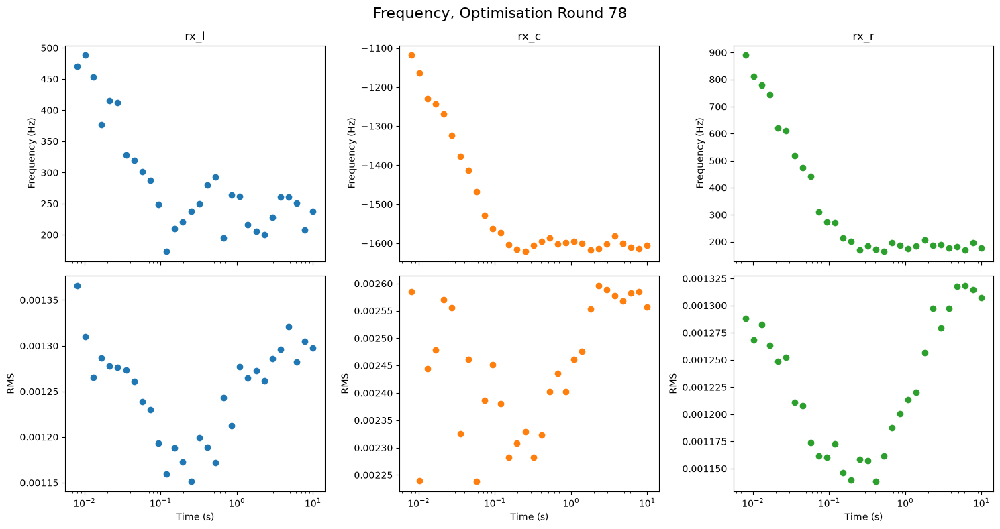

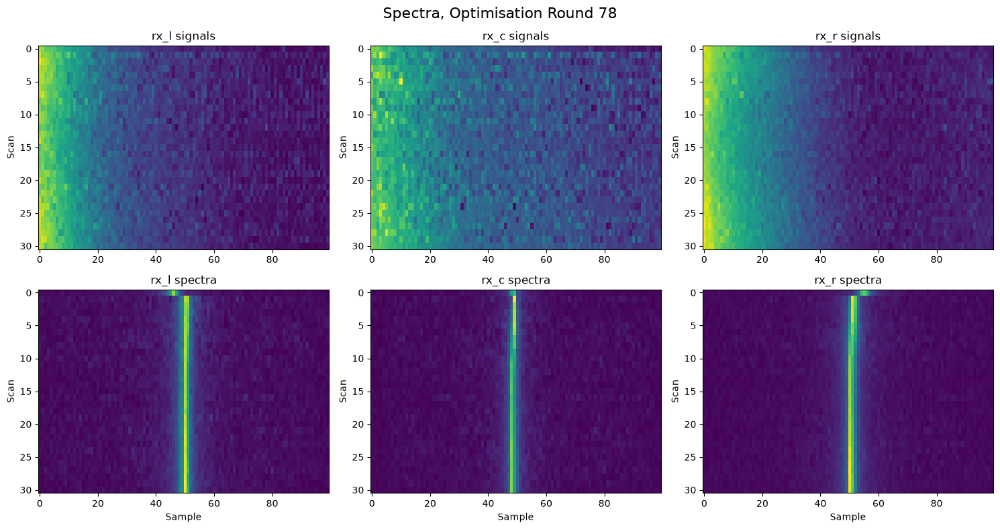

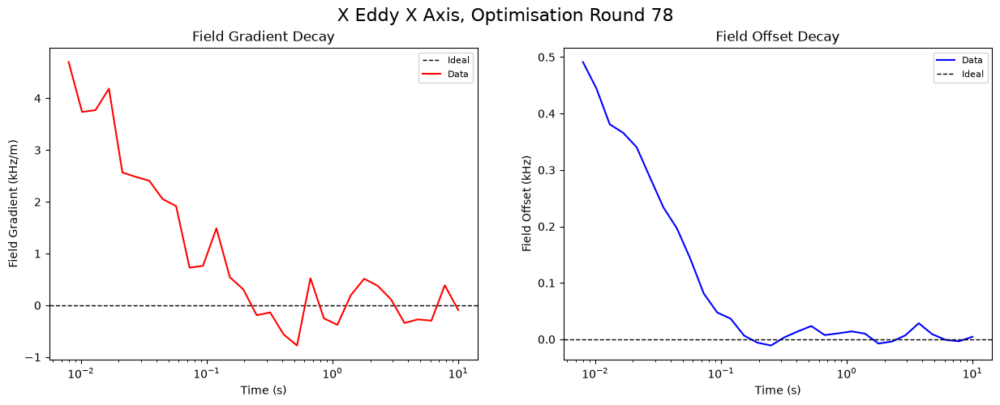

[I 2026-11-26 12:43:11,850] Trial 78 finished with value: 95.8428340200467 and parameters: {'X_A1': -0.030876354698102695, 'X_A2': 0.02645742545696882, 'X_A3': -9.76151793025772e-09, 'X_A4': 9.070085849097805e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 9.584e+01
Total cost = 9.584e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.053195050130913905
B nanmax = 0.053195050130913905
B contains nan = False
Trial 79


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.05266552641252462 !!!!!!!!!!!!!!!!


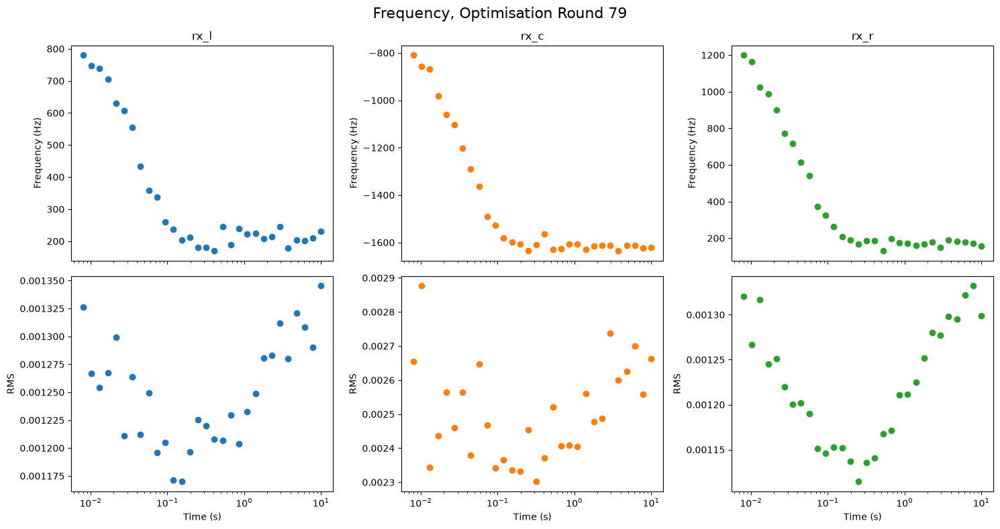

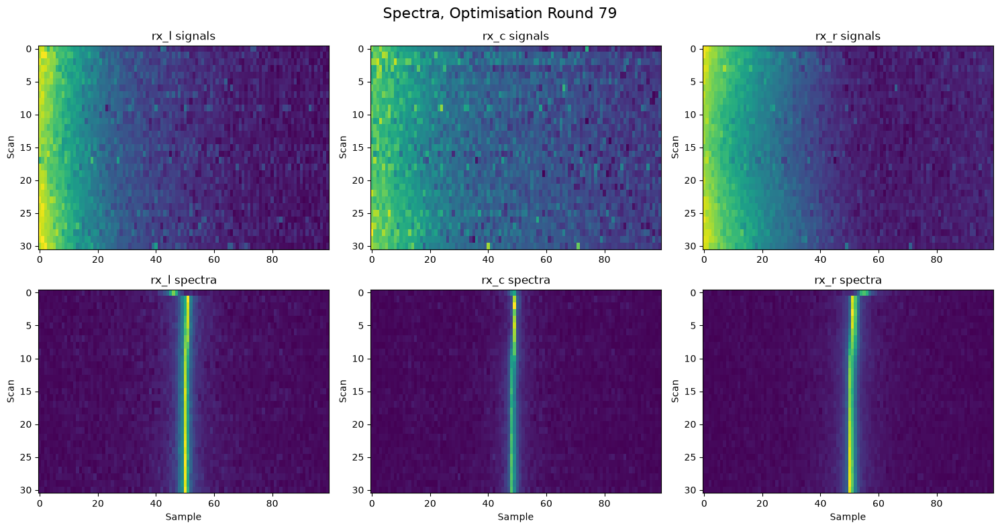

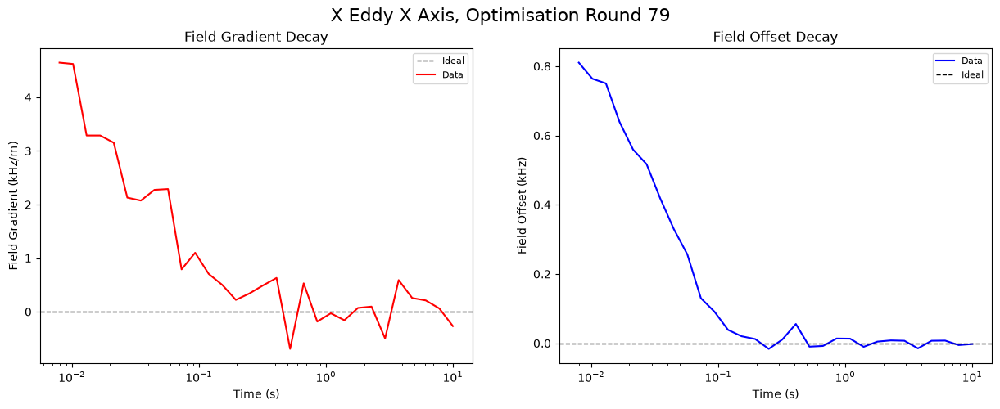

[I 2026-11-26 12:44:32,766] Trial 79 finished with value: 111.23708895271183 and parameters: {'X_A1': -0.030225360225175, 'X_A2': 0.023168790967225412, 'X_A3': -9.850924829579482e-09, 'X_A4': 9.066972840229624e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.112e+02
Total cost = 1.112e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.019039213620706475
B nanmax = 0.019039213620706475
B contains nan = False
Trial 80


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.018849679664597444 !!!!!!!!!!!!!!!!


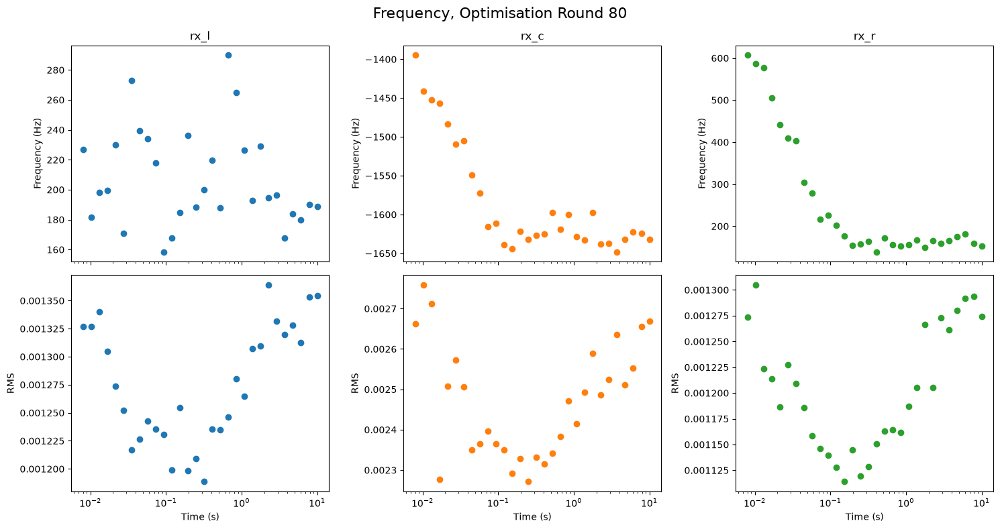

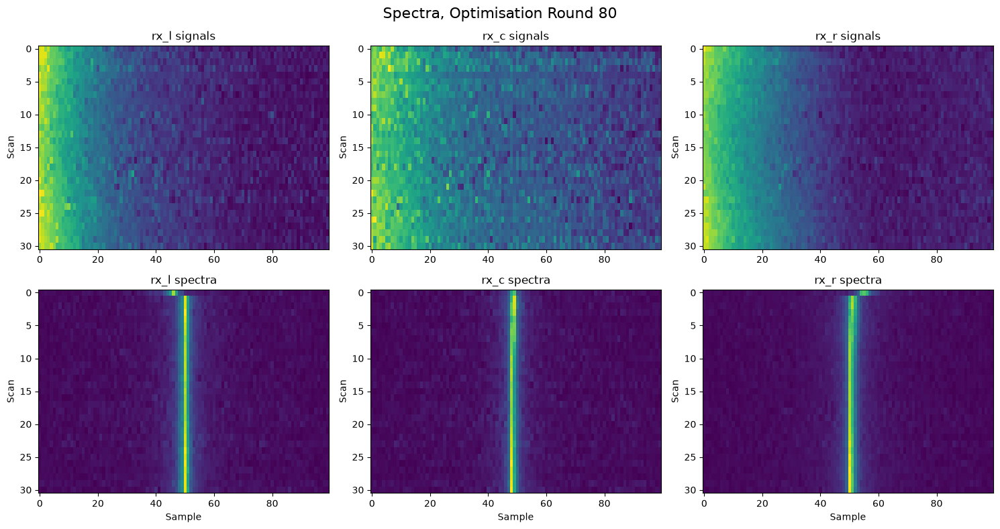

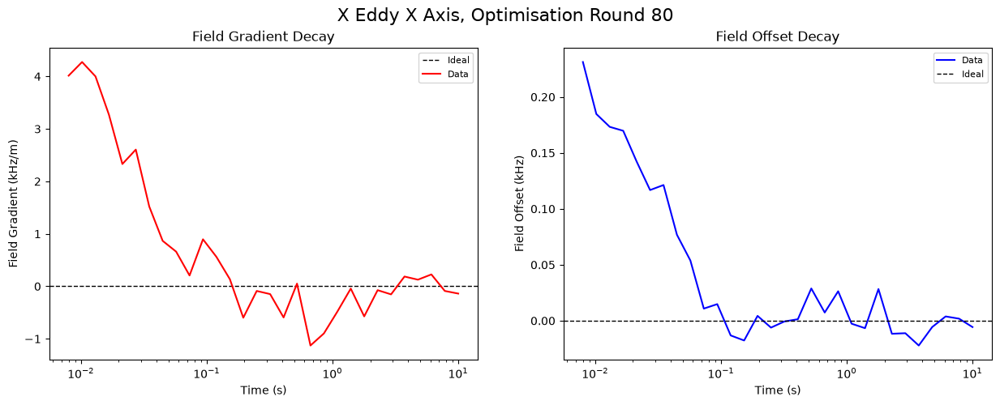

[I 2026-11-26 12:45:54,423] Trial 80 finished with value: 92.3618229679434 and parameters: {'X_A1': -0.029934604743977224, 'X_A2': 0.02741441141286594, 'X_A3': -1.015972571276976e-08, 'X_A4': 7.949992692287774e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 9.236e+01
Total cost = 9.236e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.02596670814288923
B nanmax = 0.02596670814288923
B contains nan = False
Trial 81


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.02570824681303227 !!!!!!!!!!!!!!!!


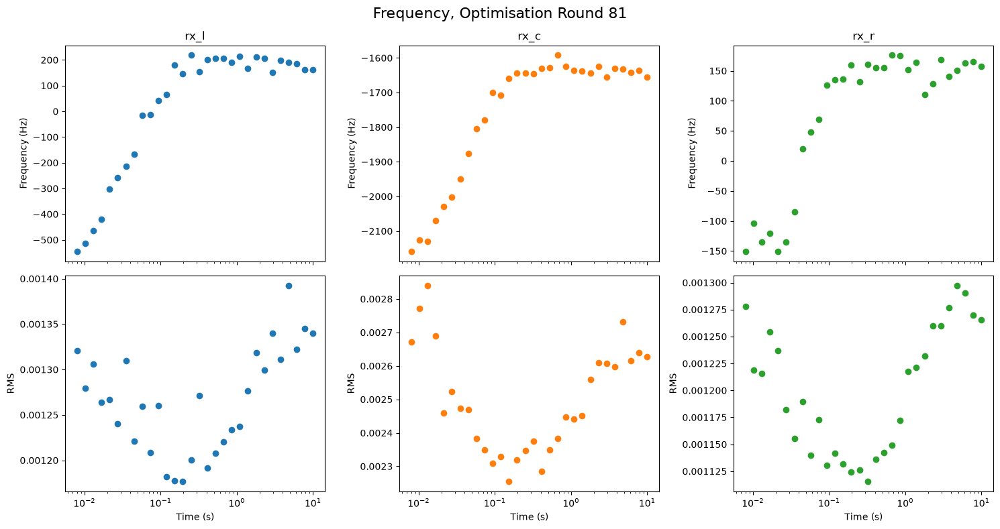

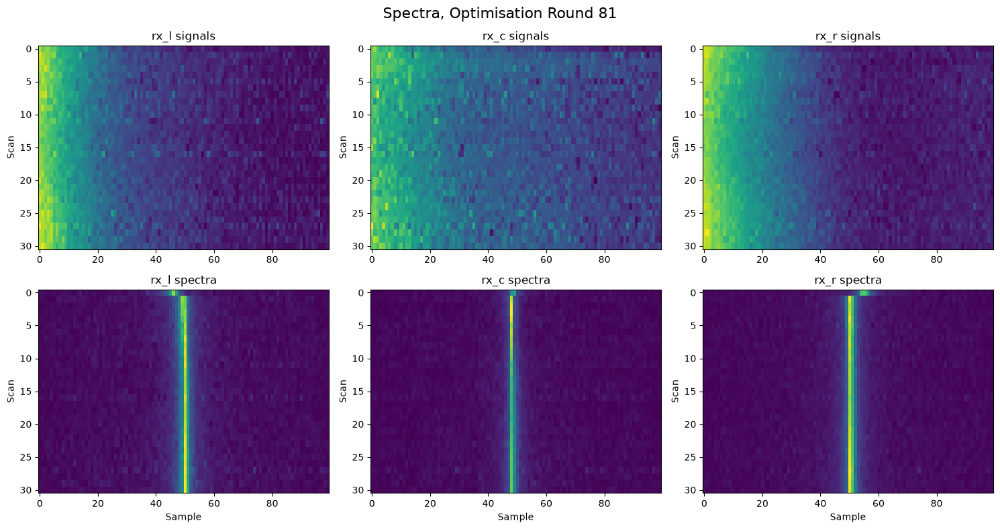

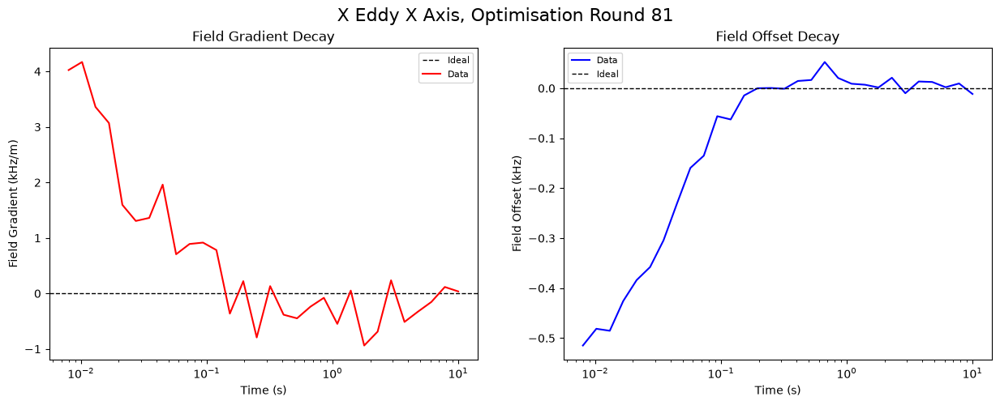

[I 2026-11-26 12:47:15,337] Trial 81 finished with value: 126.14497695864684 and parameters: {'X_A1': -0.02410930708017123, 'X_A2': 0.02756498325226064, 'X_A3': -1.1850102370957447e-08, 'X_A4': 8.239450776074977e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.261e+02
Total cost = 1.261e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.011451846406143615
B nanmax = 0.011451846406143615
B contains nan = False
Trial 82


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.011337838142930755 !!!!!!!!!!!!!!!!


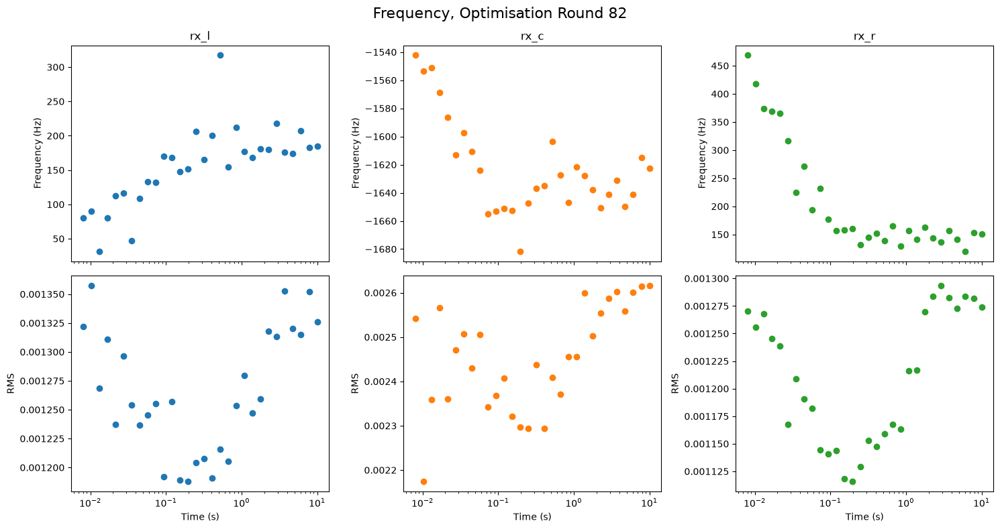

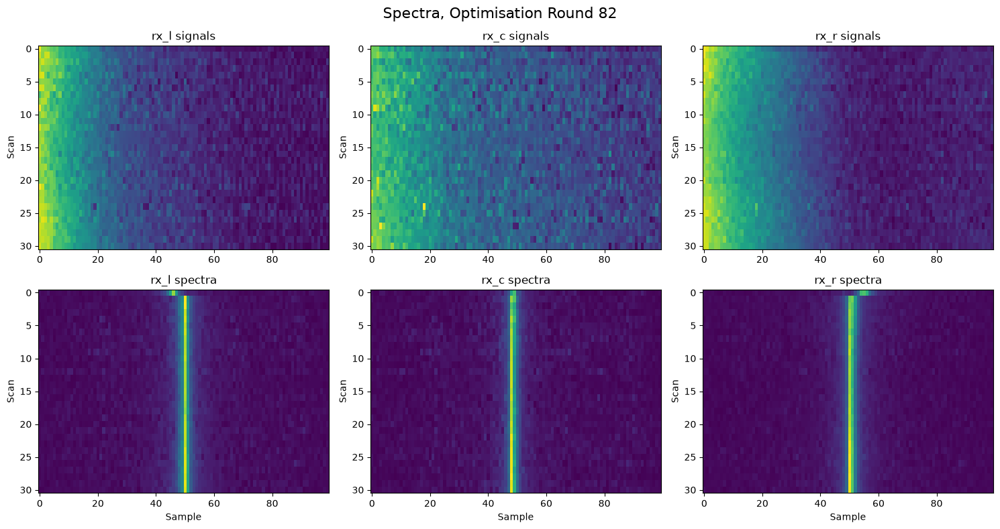

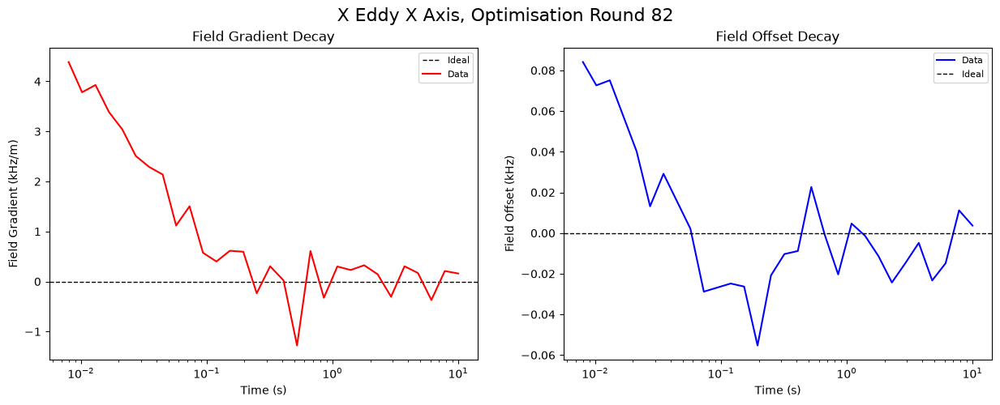

[I 2026-11-26 12:48:36,629] Trial 82 finished with value: 129.23089635877076 and parameters: {'X_A1': -0.029006440229230837, 'X_A2': 0.027493710042502187, 'X_A3': -1.1112568360817228e-08, 'X_A4': 9.952973402575792e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.292e+02
Total cost = 1.292e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.04543250900388048
B nanmax = 0.04543250900388048
B contains nan = False
Trial 83


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.044980255152425895 !!!!!!!!!!!!!!!!


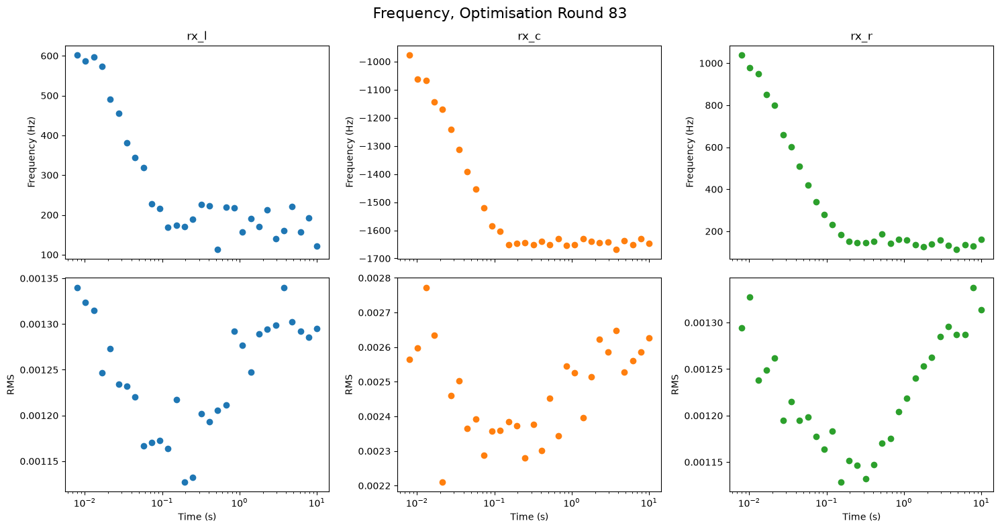

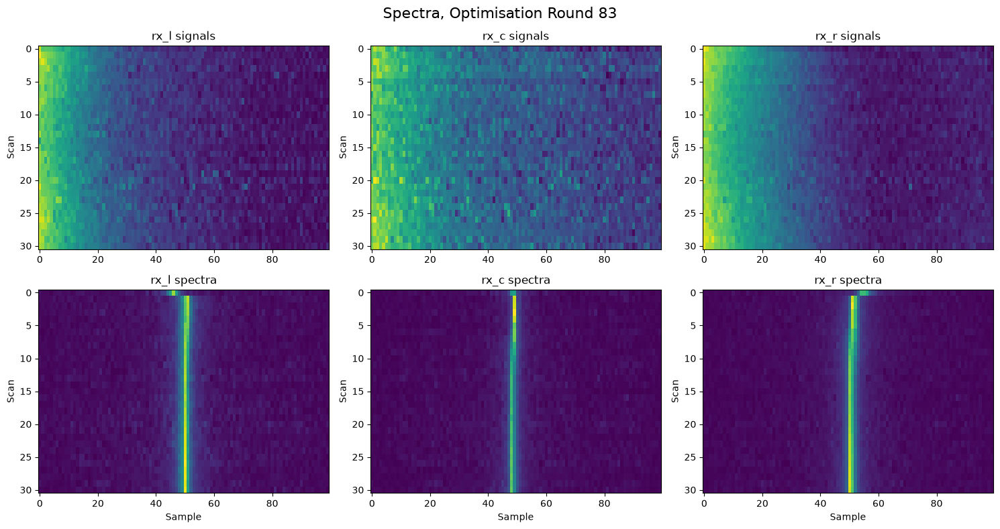

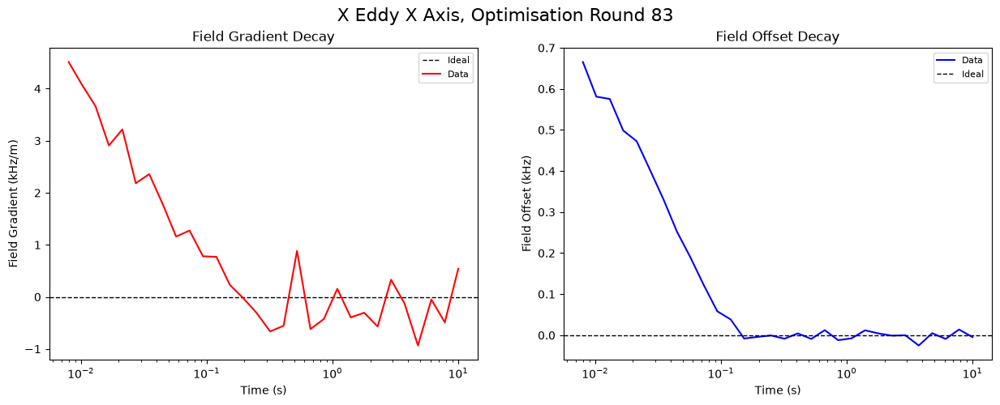

[I 2026-11-26 12:49:57,812] Trial 83 finished with value: 115.83929120025957 and parameters: {'X_A1': -0.02841365378688023, 'X_A2': 0.022387561936520143, 'X_A3': -1.0516261646101099e-08, 'X_A4': 8.573516419000067e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.158e+02
Total cost = 1.158e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0017734220173902249
B nanmax = 0.0017734220173902249
B contains nan = False
Trial 84


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0017703161939197243 !!!!!!!!!!!!!!!!


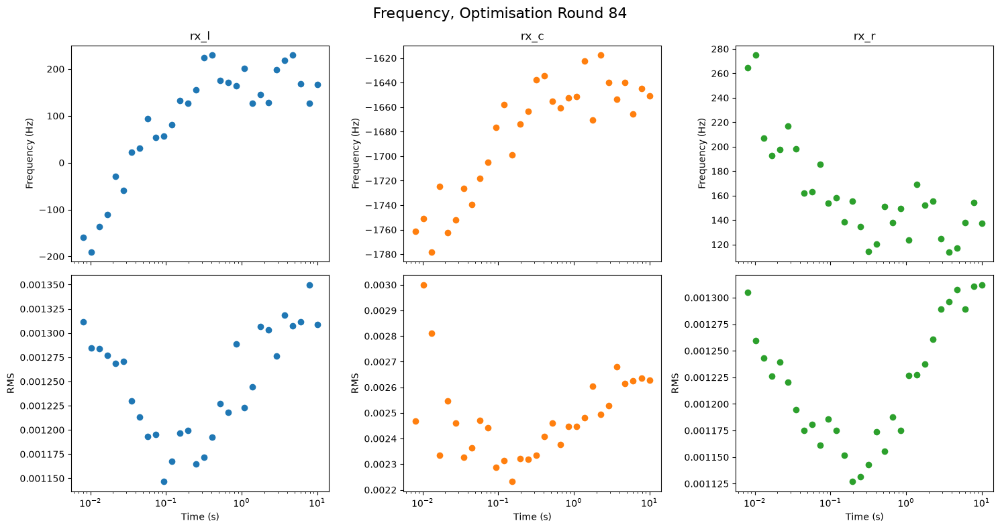

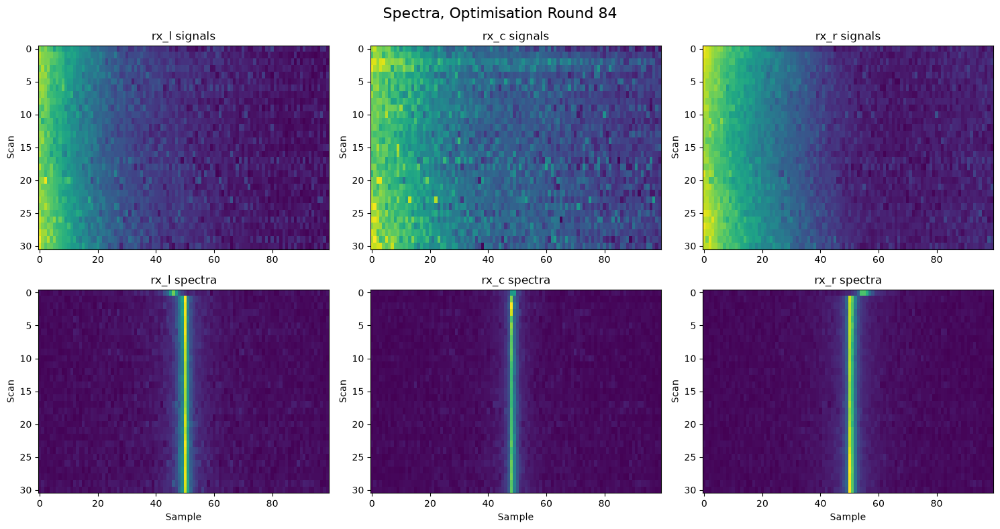

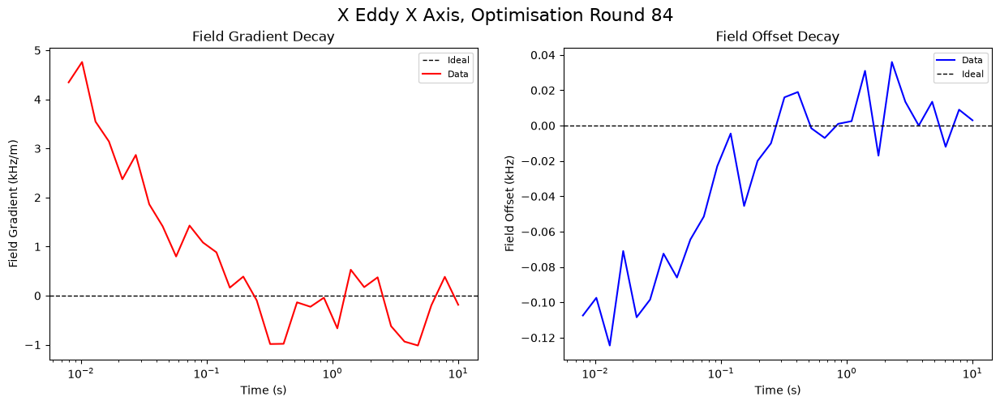

[I 2026-11-26 12:51:19,440] Trial 84 finished with value: 118.71965834774113 and parameters: {'X_A1': -0.03053990185967355, 'X_A2': 0.030684518929320243, 'X_A3': -1.1531611141878742e-08, 'X_A4': 7.8507953513198e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.187e+02
Total cost = 1.187e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.005003114654342259
B nanmax = 0.005003114654342259
B contains nan = False
Trial 85


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0049532967615313105 !!!!!!!!!!!!!!!!


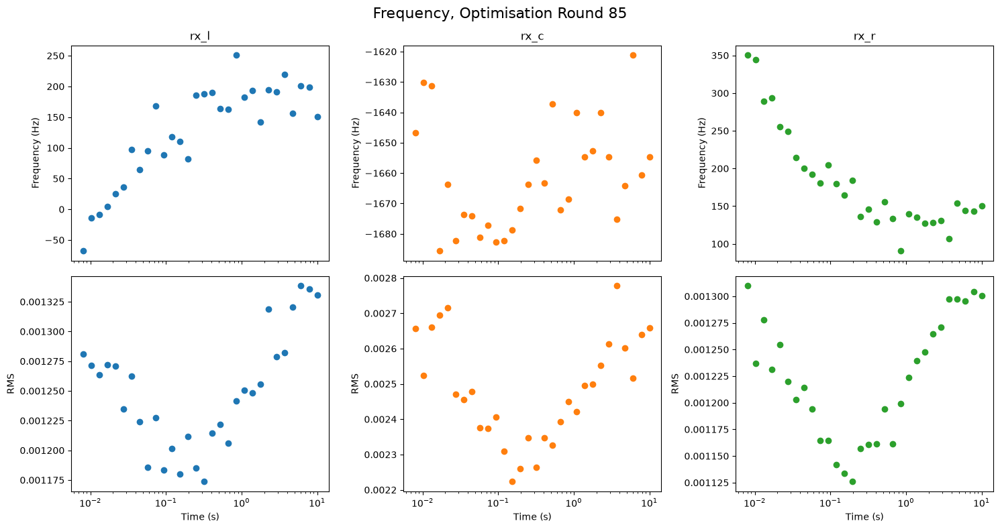

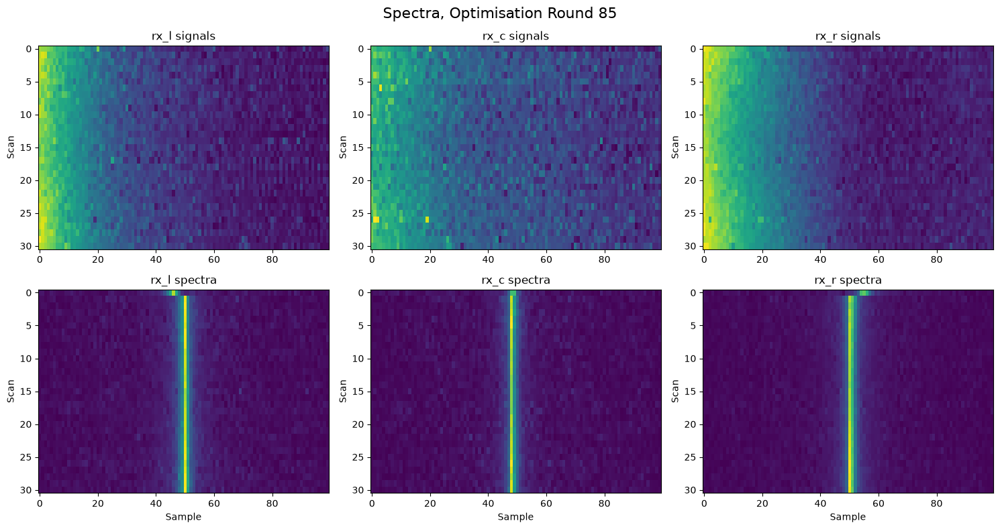

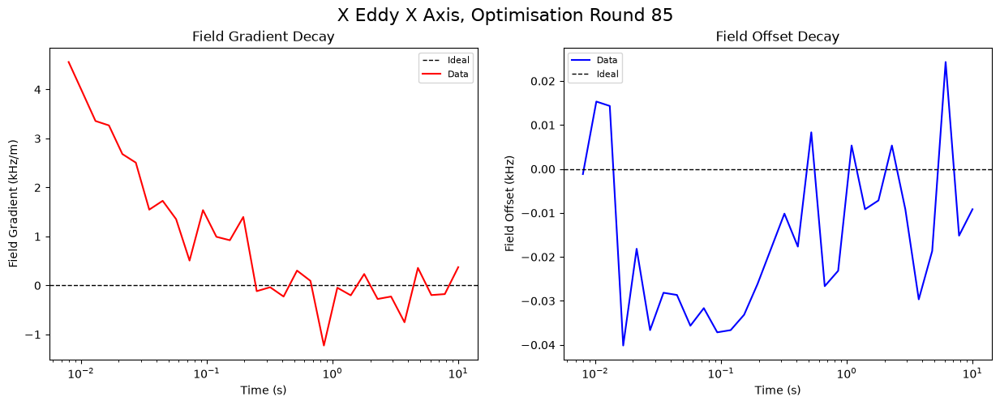

[I 2026-11-26 12:52:40,311] Trial 85 finished with value: 164.45492072142255 and parameters: {'X_A1': -0.0304037343421184, 'X_A2': 0.029747900248262873, 'X_A3': -1.103844499830869e-08, 'X_A4': 8.807455296361628e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.645e+02
Total cost = 1.645e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.014412060787066493
B nanmax = 0.014412060787066493
B contains nan = False
Trial 86


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014268586428930653 !!!!!!!!!!!!!!!!


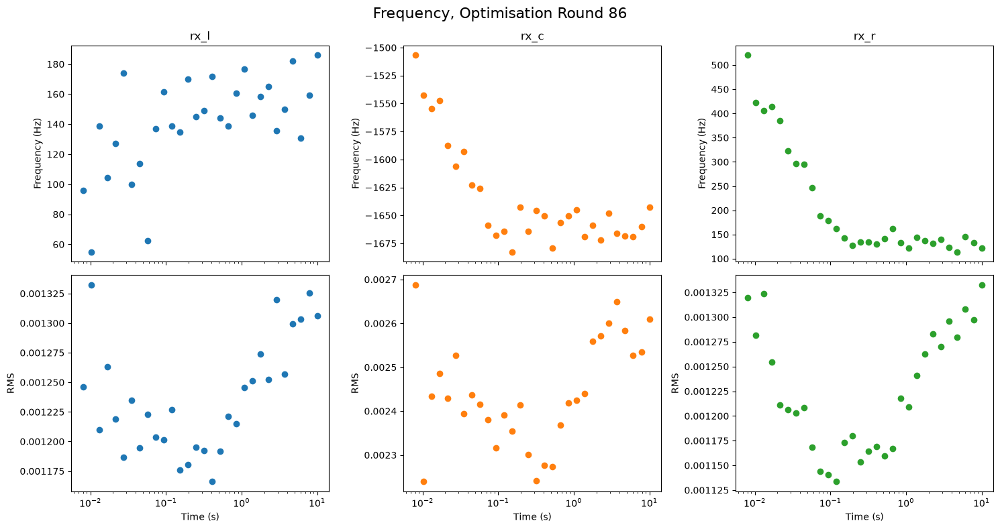

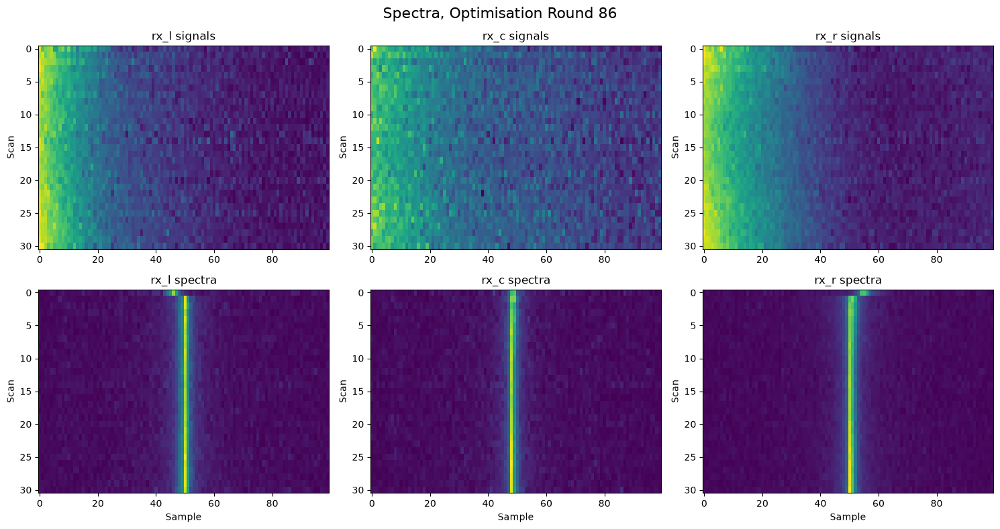

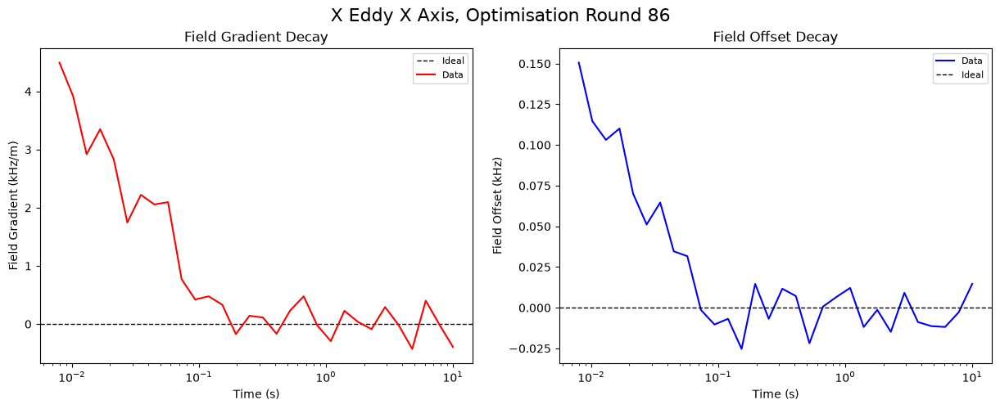

[I 2026-11-26 12:54:01,360] Trial 86 finished with value: 96.12890070533007 and parameters: {'X_A1': -0.028845239628529005, 'X_A2': 0.026939298193020336, 'X_A3': -1.1570275114356911e-08, 'X_A4': 8.767009901003666e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 9.613e+01
Total cost = 9.613e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.001966503301791721
B nanmax = 0.001966503301791721
B contains nan = False
Trial 87


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0019469418522127845 !!!!!!!!!!!!!!!!


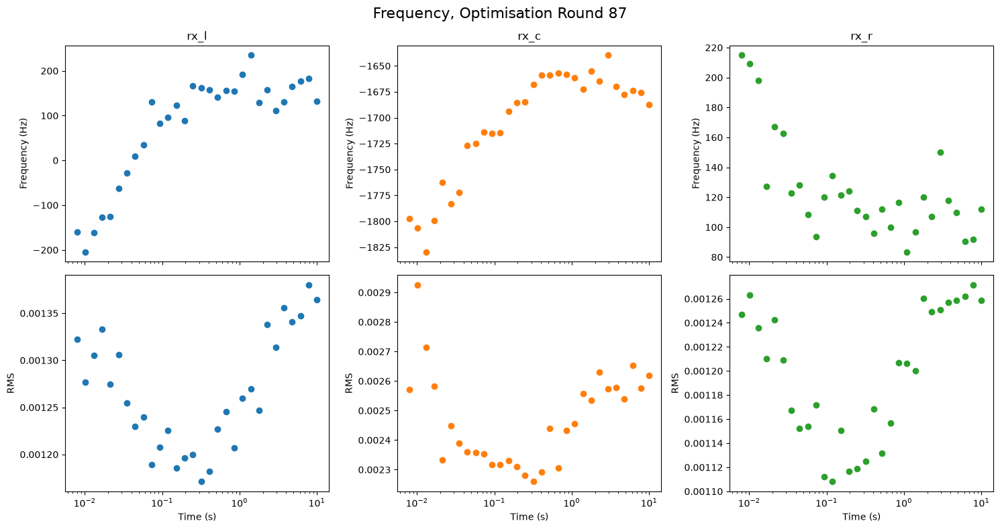

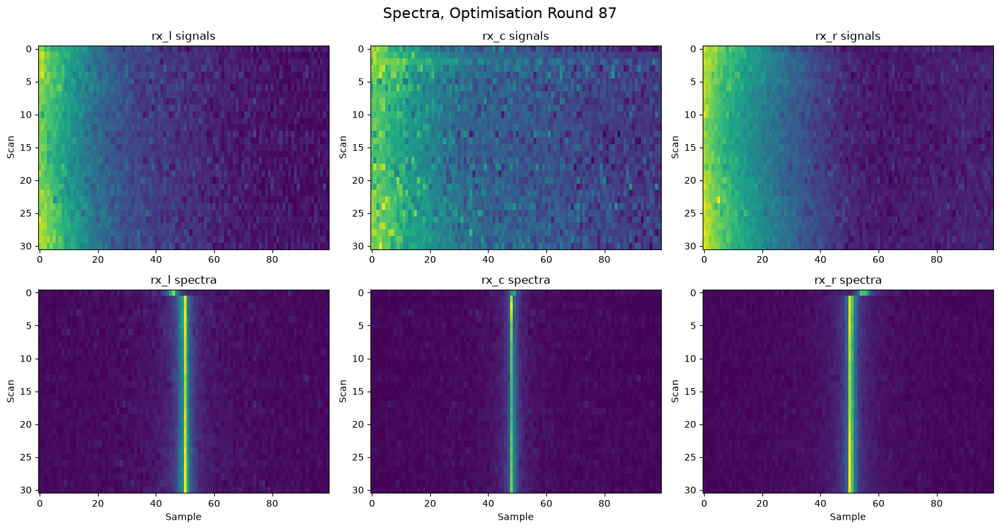

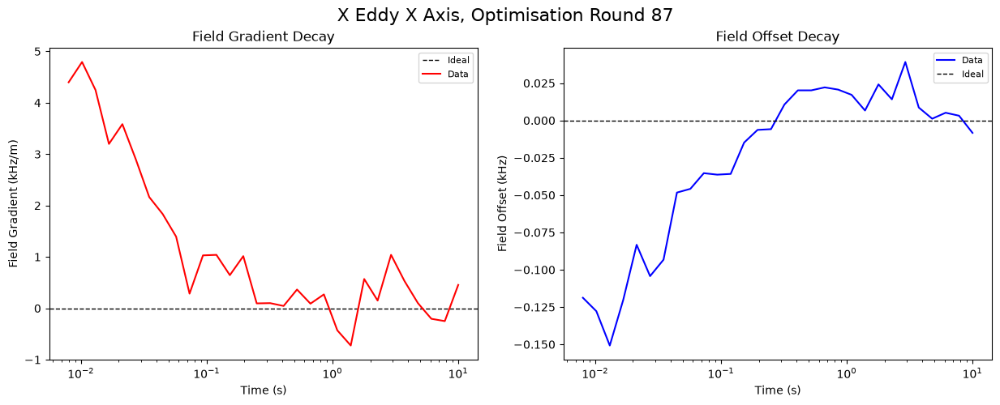

[I 2026-11-26 12:55:22,355] Trial 87 finished with value: 108.6451565047469 and parameters: {'X_A1': -0.024384367650385878, 'X_A2': 0.024652498908601276, 'X_A3': -1.0686529553672528e-08, 'X_A4': 9.060765044675448e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.086e+02
Total cost = 1.086e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.033042626232292024
B nanmax = 0.033042626232292024
B contains nan = False
Trial 88


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.03271373226218124 !!!!!!!!!!!!!!!!


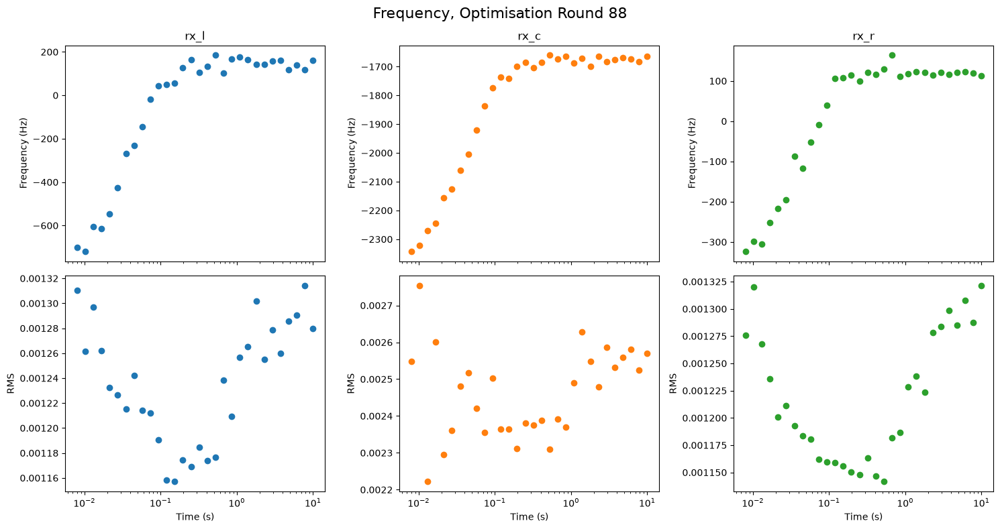

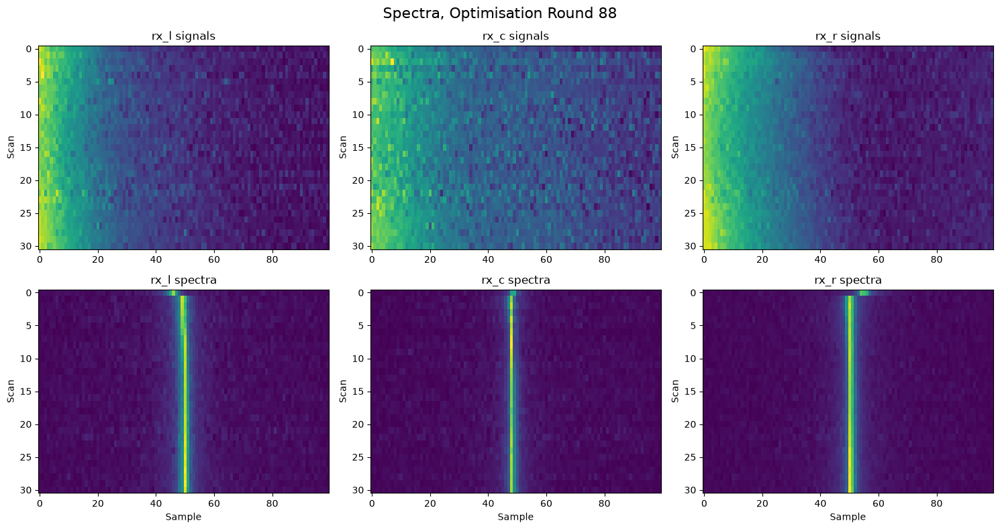

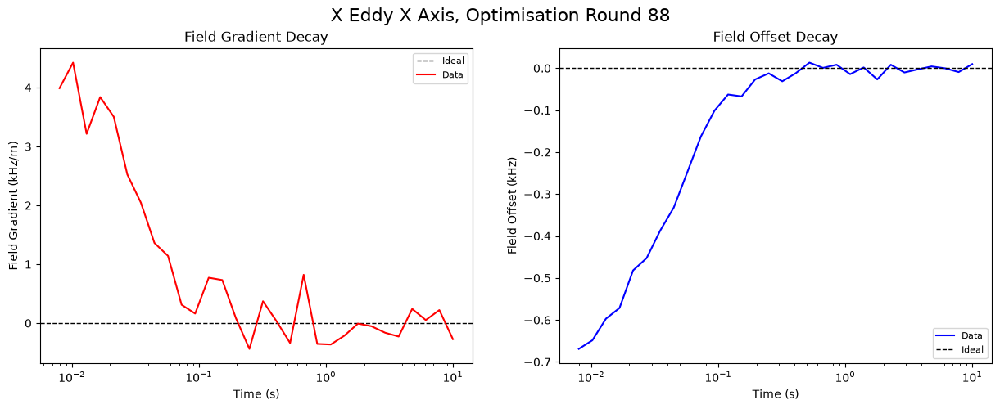

[I 2026-11-26 12:56:43,612] Trial 88 finished with value: 107.2203747761425 and parameters: {'X_A1': -0.026953826769086586, 'X_A2': 0.031350112048299524, 'X_A3': -1.0889832287581481e-08, 'X_A4': 9.394684340429519e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.072e+02
Total cost = 1.072e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0188740958038755
B nanmax = 0.0188740958038755
B contains nan = False
Trial 89


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01868623602502133 !!!!!!!!!!!!!!!!


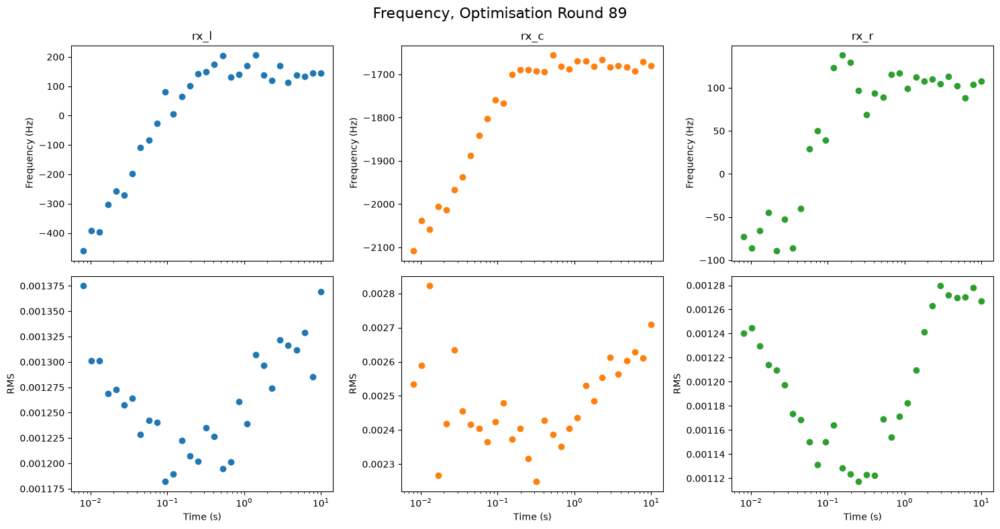

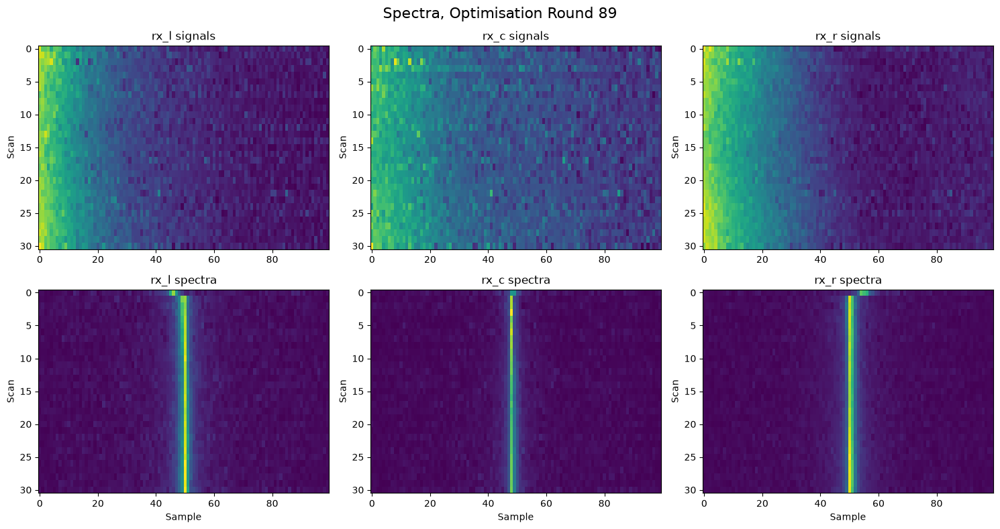

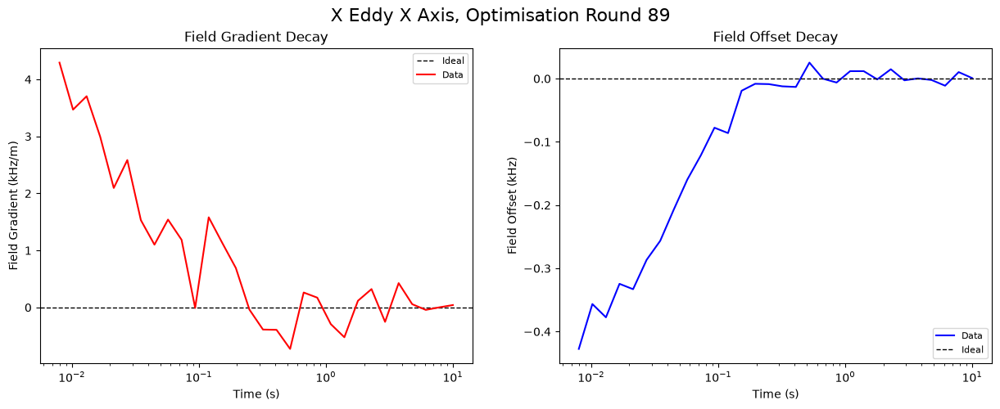

[I 2026-11-26 12:58:04,930] Trial 89 finished with value: 88.62473124445233 and parameters: {'X_A1': -0.02629321578683431, 'X_A2': 0.02880749819159049, 'X_A3': -1.0158450077803361e-08, 'X_A4': 9.09400944408583e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 8.862e+01
Total cost = 8.862e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.004645872534012547
B nanmax = 0.004645872534012547
B contains nan = False
Trial 90


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.004599641293799931 !!!!!!!!!!!!!!!!


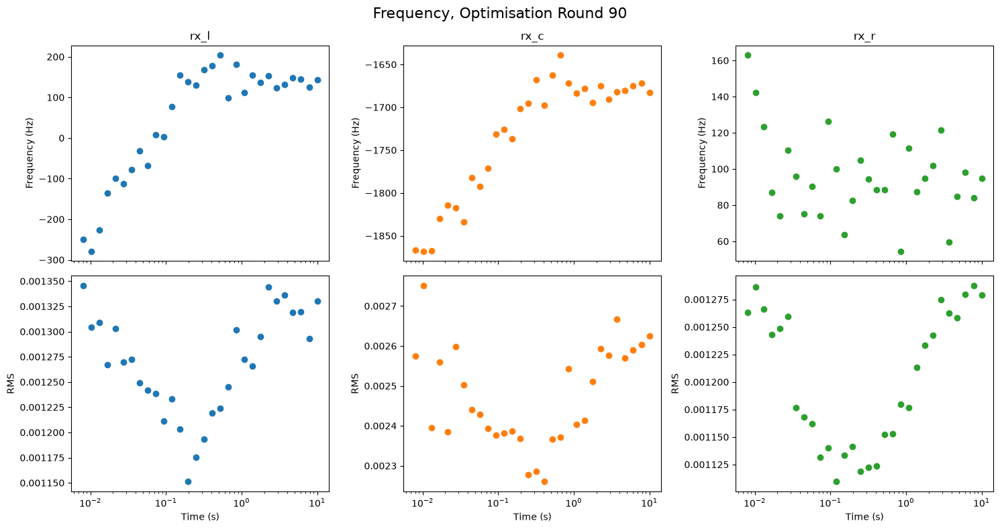

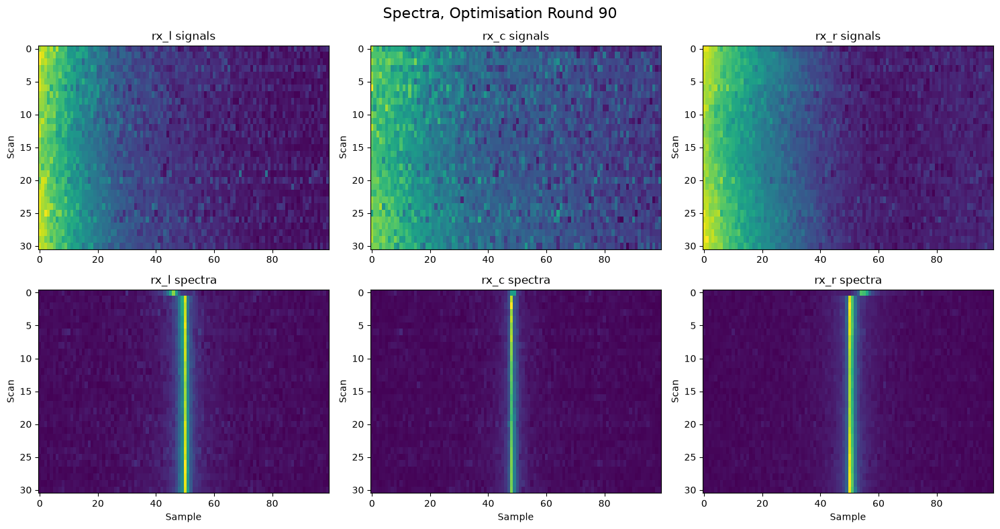

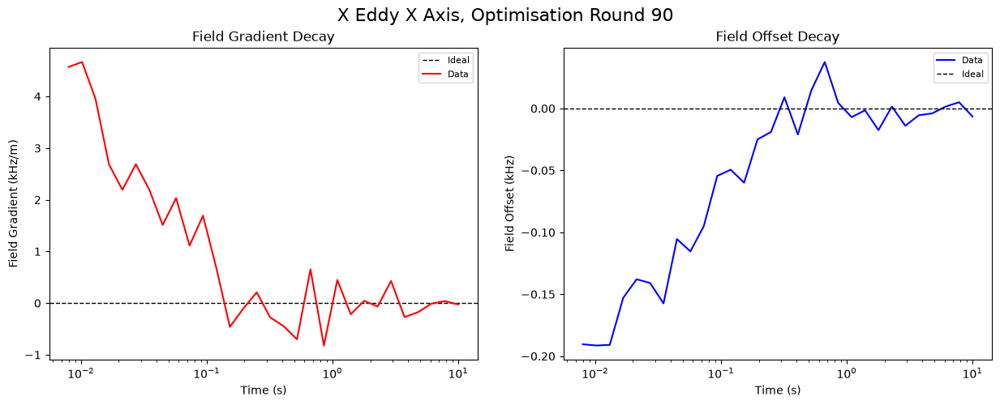

[I 2026-11-26 12:59:25,781] Trial 90 finished with value: 78.99570817527037 and parameters: {'X_A1': -0.025927935864257068, 'X_A2': 0.026552371340645753, 'X_A3': -1.1040256329925886e-08, 'X_A4': 9.465365956170447e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 7.900e+01
Total cost = 7.900e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.02211936255607007
B nanmax = 0.02211936255607007
B contains nan = False
Trial 91


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.021899168689199056 !!!!!!!!!!!!!!!!


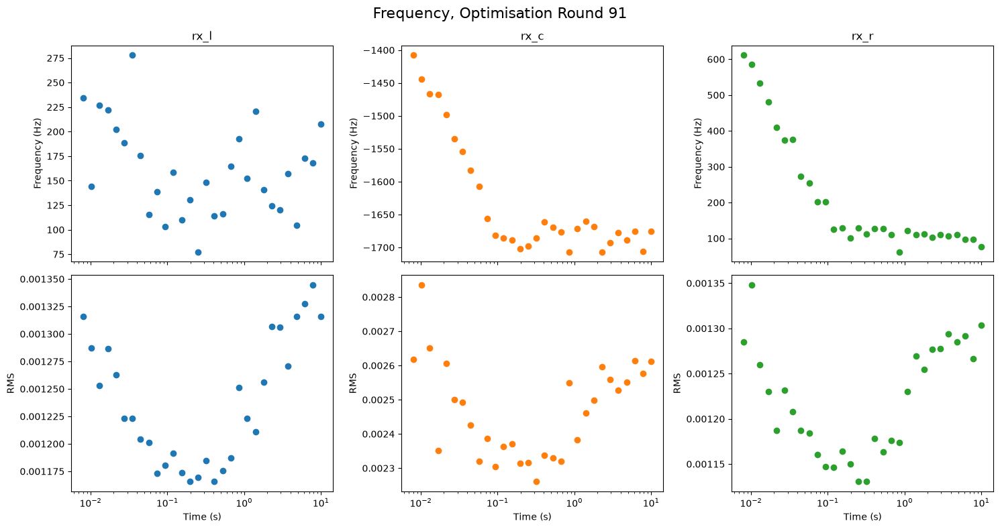

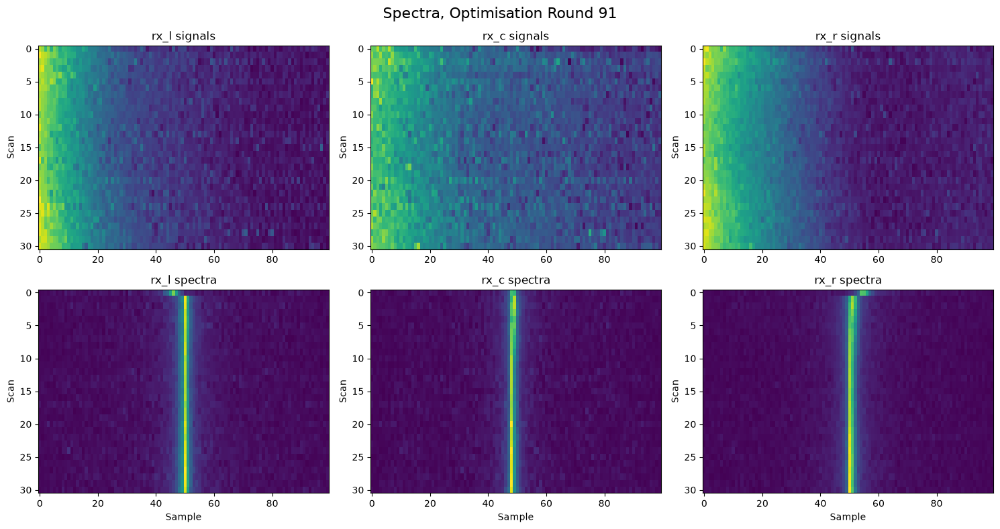

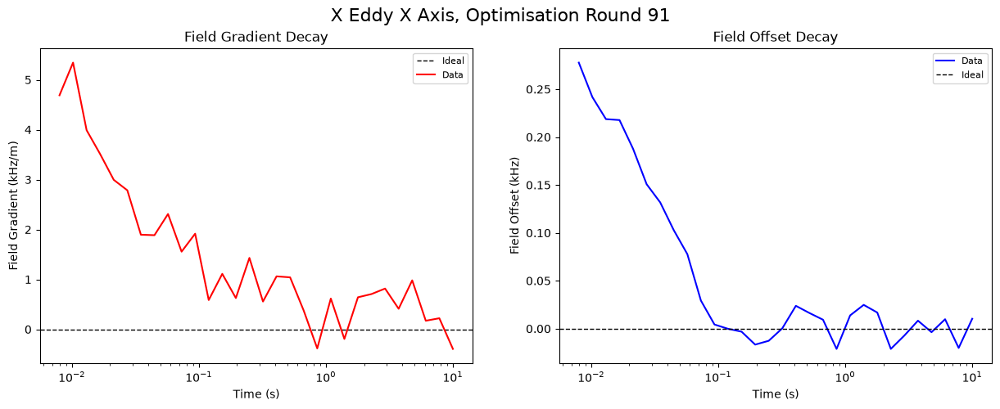

[I 2026-11-26 13:00:47,029] Trial 91 finished with value: 135.41722577039792 and parameters: {'X_A1': -0.02973448327173277, 'X_A2': 0.026805138315074355, 'X_A3': -1.0769794189552598e-08, 'X_A4': 6.75853564929721e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.354e+02
Total cost = 1.354e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.017685967326214188
B nanmax = 0.017685967326214188
B contains nan = False
Trial 92


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01750990339036812 !!!!!!!!!!!!!!!!


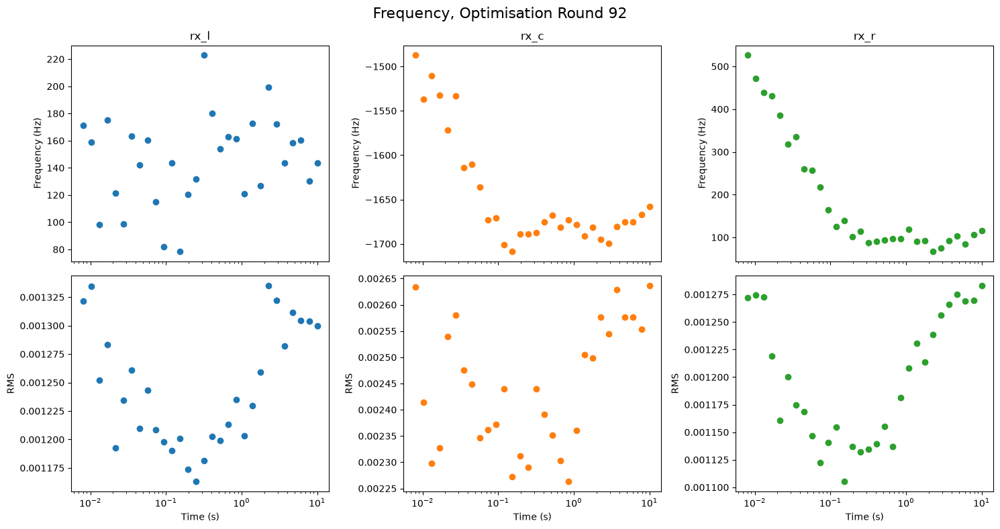

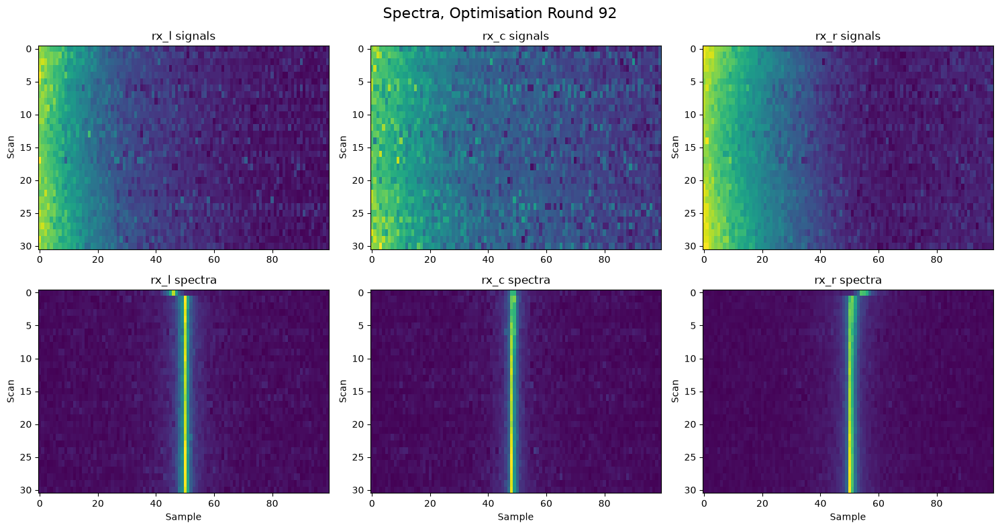

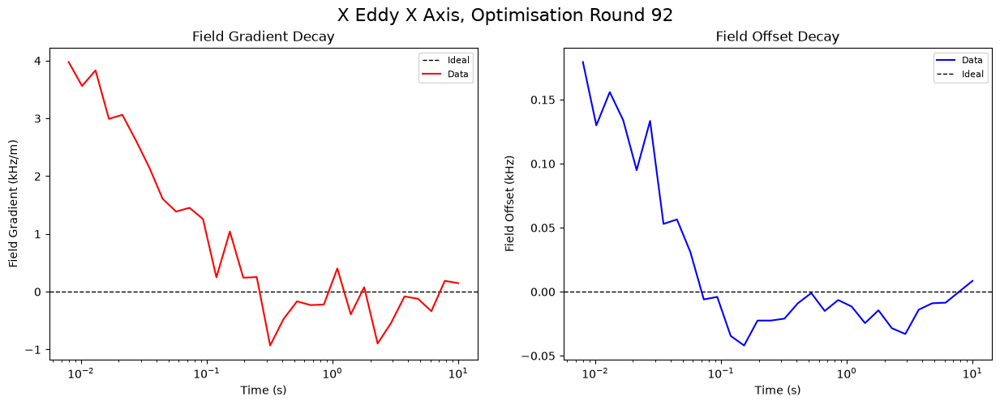

[I 2026-11-26 13:02:08,549] Trial 92 finished with value: 120.47785630342068 and parameters: {'X_A1': -0.030465460598773506, 'X_A2': 0.028125151950394025, 'X_A3': -1.1428582390144977e-08, 'X_A4': 9.447563234695321e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.205e+02
Total cost = 1.205e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.007816541776133255
B nanmax = 0.007816541776133255
B contains nan = False
Trial 93


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0077387502853836 !!!!!!!!!!!!!!!!


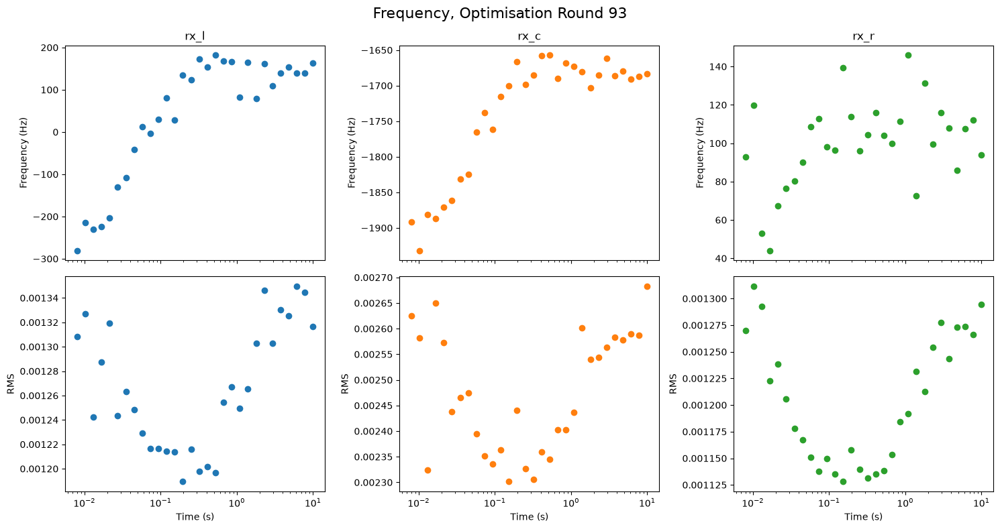

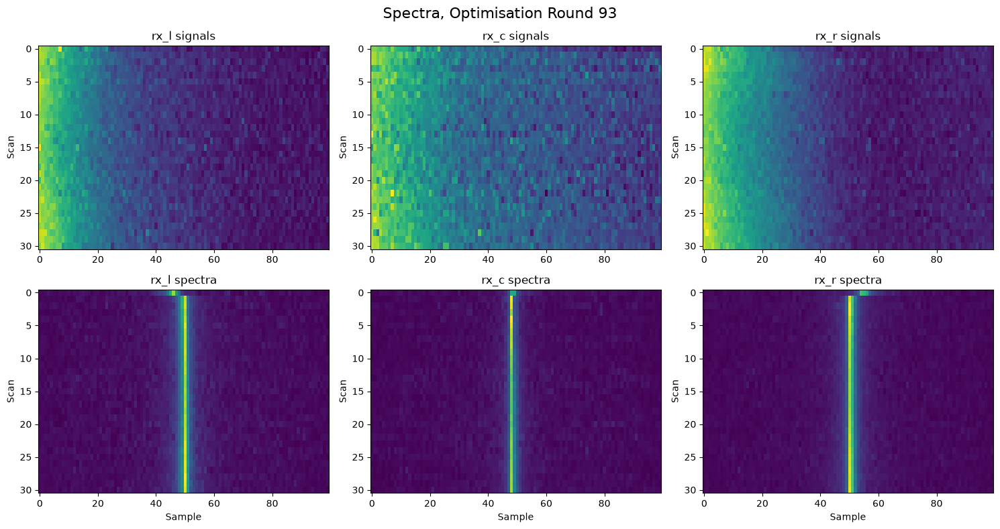

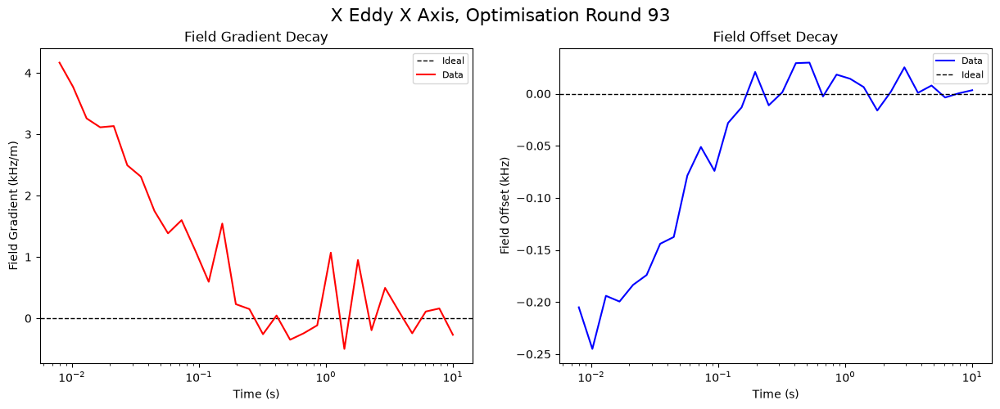

[I 2026-11-26 13:03:29,612] Trial 93 finished with value: 77.97336014516638 and parameters: {'X_A1': -0.027425587303292188, 'X_A2': 0.028471566665311695, 'X_A3': -1.2121534976415352e-08, 'X_A4': 8.102257265196906e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 7.797e+01
Total cost = 7.797e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.0036585990564248225
B nanmax = 0.0036585990564248225
B contains nan = False
Trial 94


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0036513183731144896 !!!!!!!!!!!!!!!!


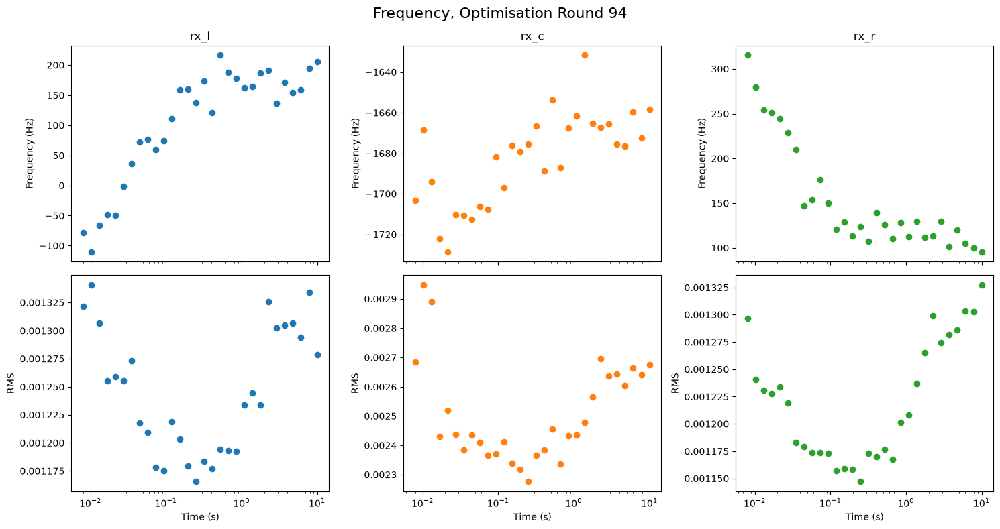

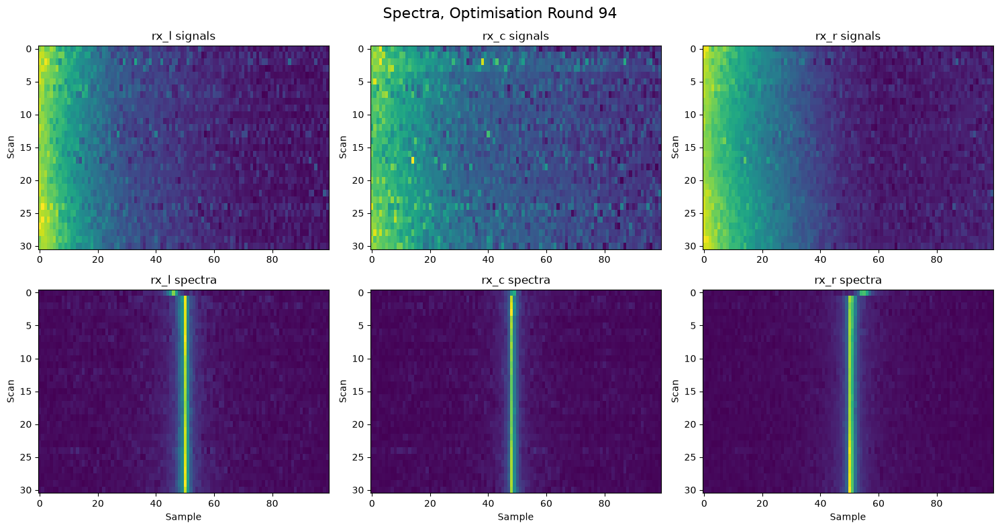

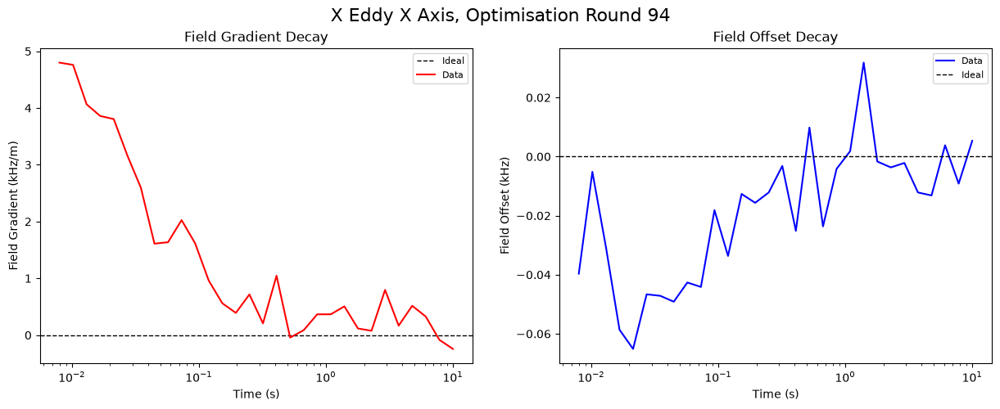

[I 2026-11-26 13:04:51,308] Trial 94 finished with value: 88.04151836674193 and parameters: {'X_A1': -0.028274799564247916, 'X_A2': 0.027814475182363914, 'X_A3': -1.0435588984266703e-08, 'X_A4': 9.860495037219651e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 8.804e+01
Total cost = 8.804e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.013063760748864324
B nanmax = 0.013063760748864324
B contains nan = False
Trial 95


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012933738500036953 !!!!!!!!!!!!!!!!


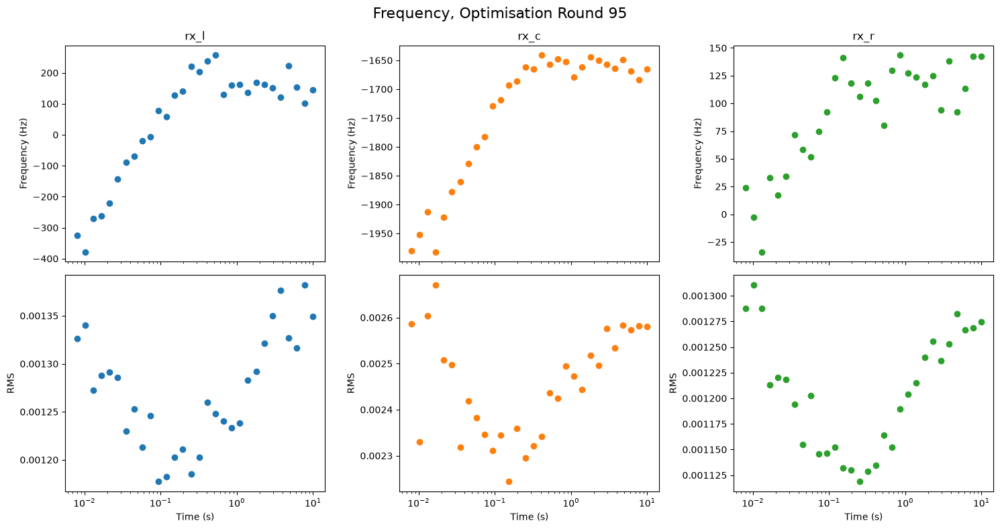

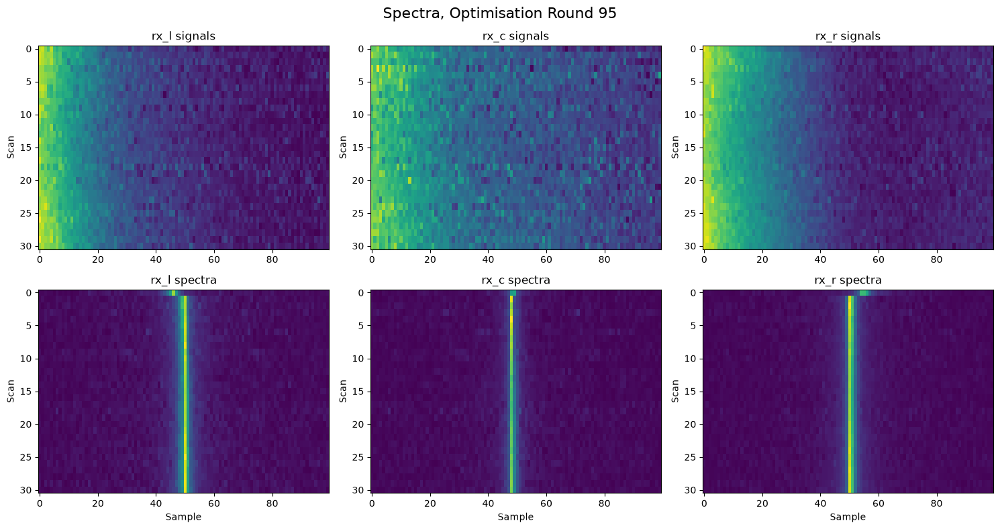

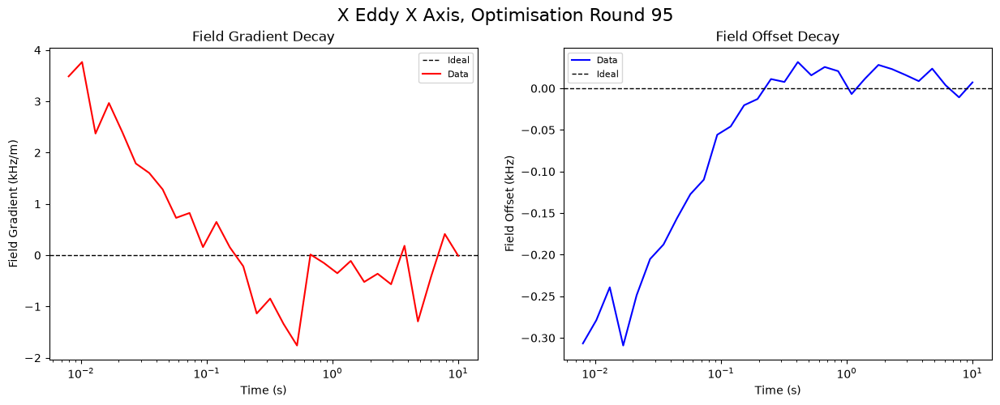

[I 2026-11-26 13:06:12,555] Trial 95 finished with value: 146.10261502942916 and parameters: {'X_A1': -0.028215117102613152, 'X_A2': 0.029958238678277228, 'X_A3': -1.2027523501237908e-08, 'X_A4': 7.870641369854157e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.461e+02
Total cost = 1.461e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.014092607515420552
B nanmax = 0.014092607515420552
B contains nan = False
Trial 96


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013952343111116795 !!!!!!!!!!!!!!!!


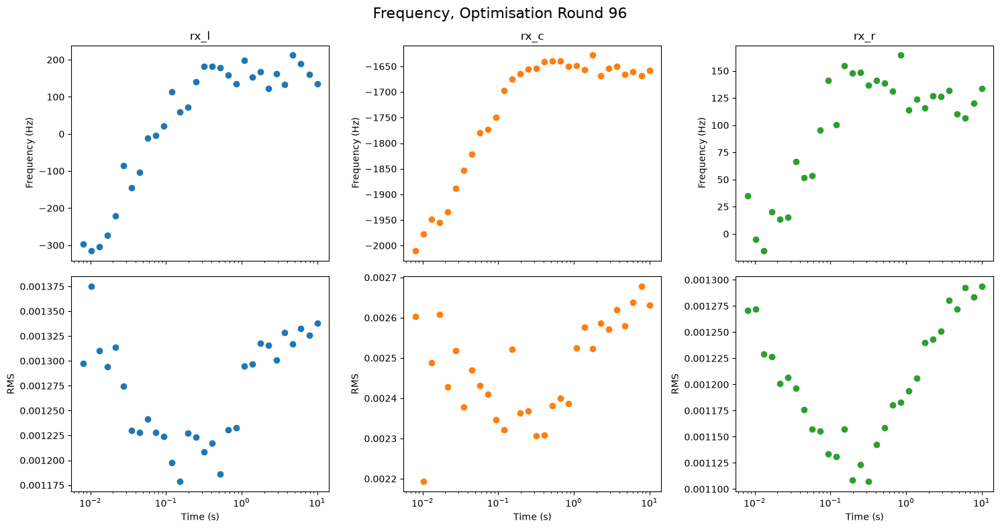

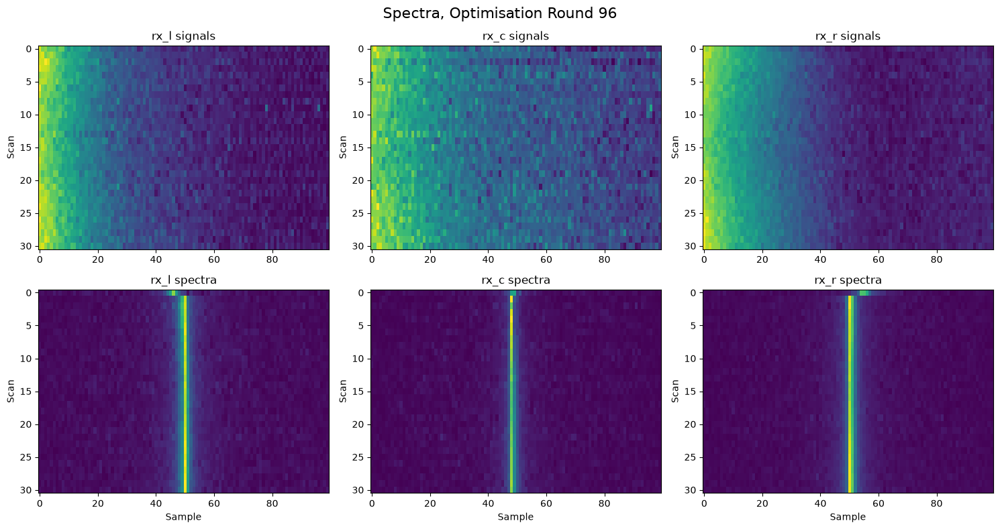

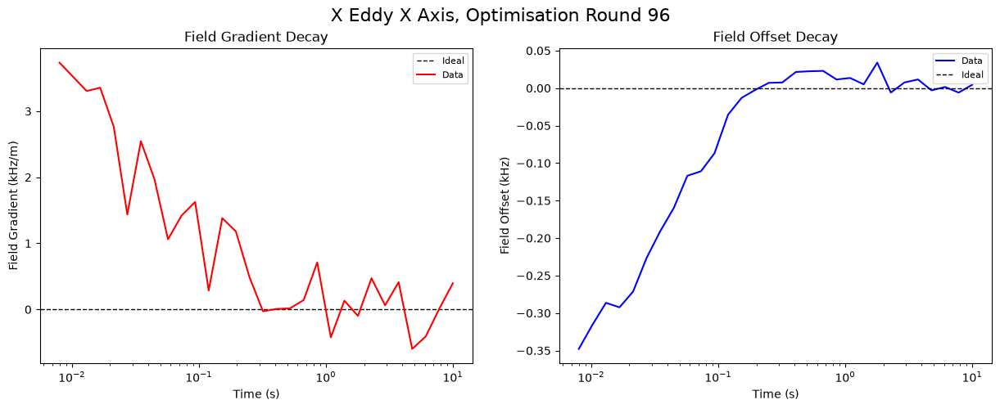

[I 2026-11-26 13:07:33,498] Trial 96 finished with value: 91.92745494791026 and parameters: {'X_A1': -0.02648276673745738, 'X_A2': 0.028362042591933333, 'X_A3': -1.1744894541137439e-08, 'X_A4': 9.08720252396246e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 9.193e+01
Total cost = 9.193e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.006085662826579107
B nanmax = 0.006085662826579107
B contains nan = False
Trial 97


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.006025070695575418 !!!!!!!!!!!!!!!!


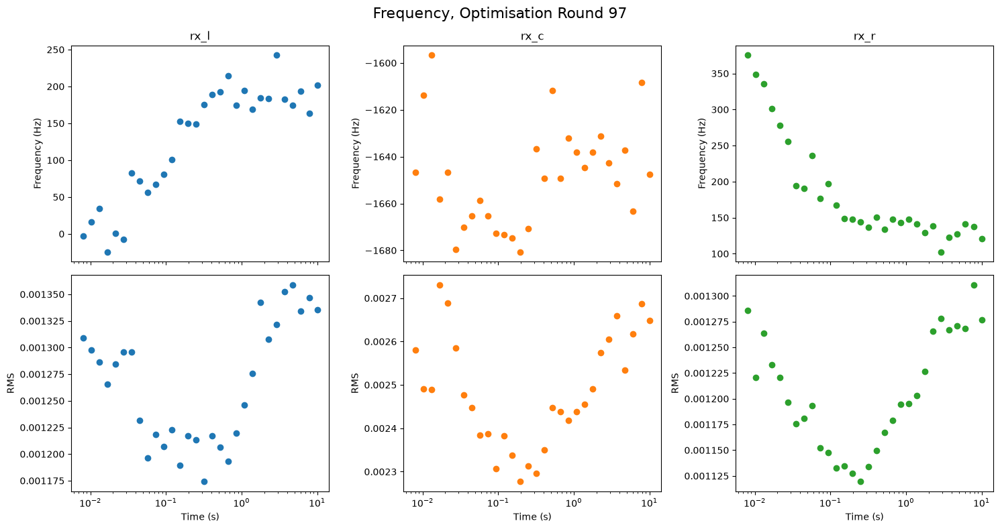

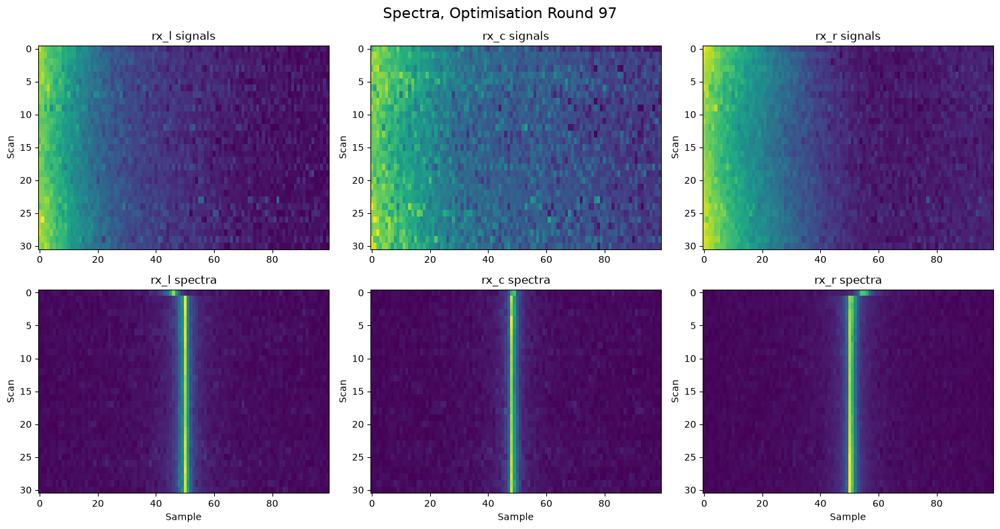

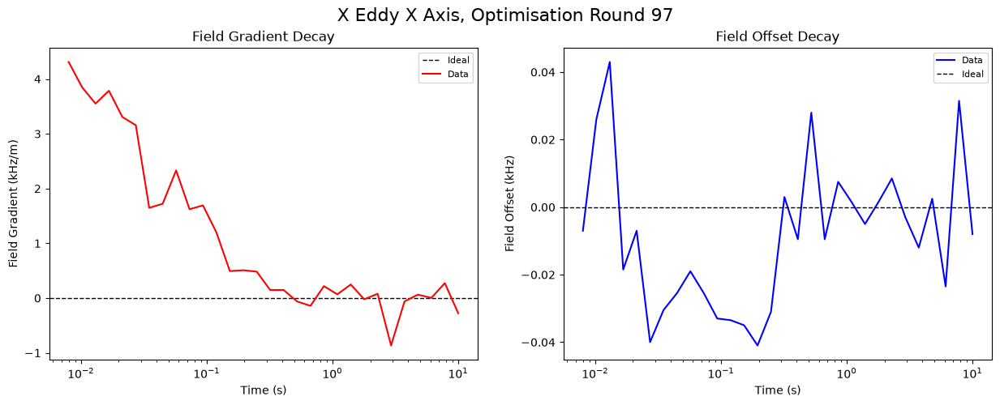

[I 2026-11-26 13:08:54,940] Trial 97 finished with value: 146.36117797394945 and parameters: {'X_A1': -0.027604339317354353, 'X_A2': 0.02680392740634398, 'X_A3': -1.154508553269353e-08, 'X_A4': 9.802252525301708e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.464e+02
Total cost = 1.464e+02
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.025825122137137262
B nanmax = 0.025825122137137262
B contains nan = False
Trial 98


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.02556807163885098 !!!!!!!!!!!!!!!!


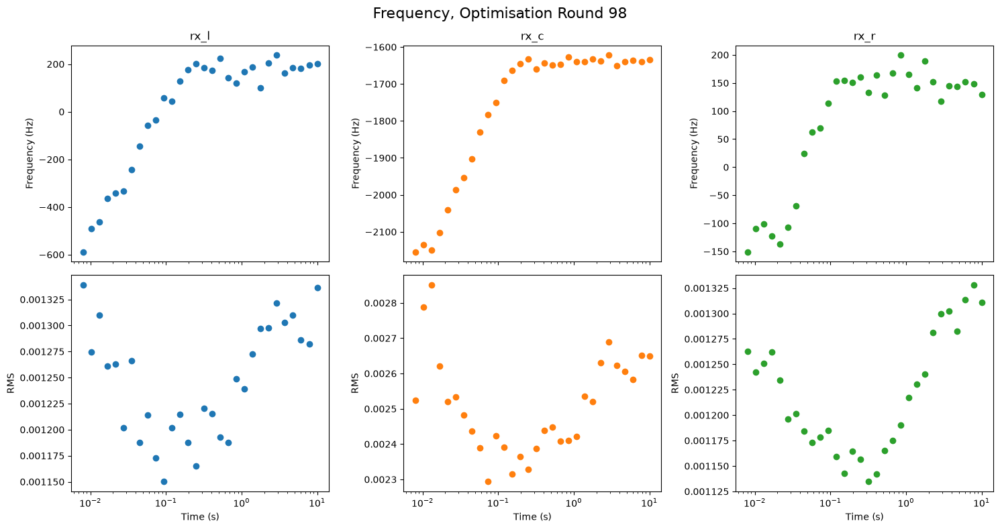

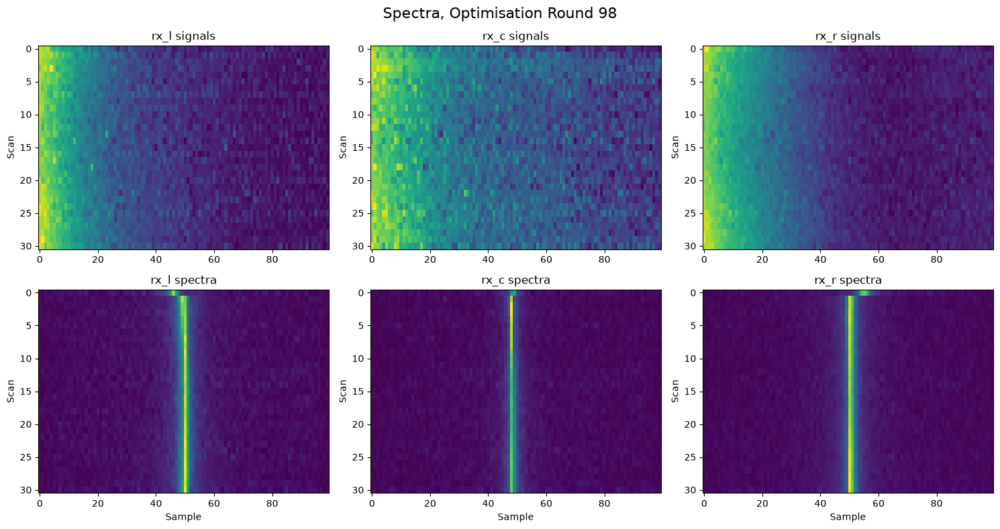

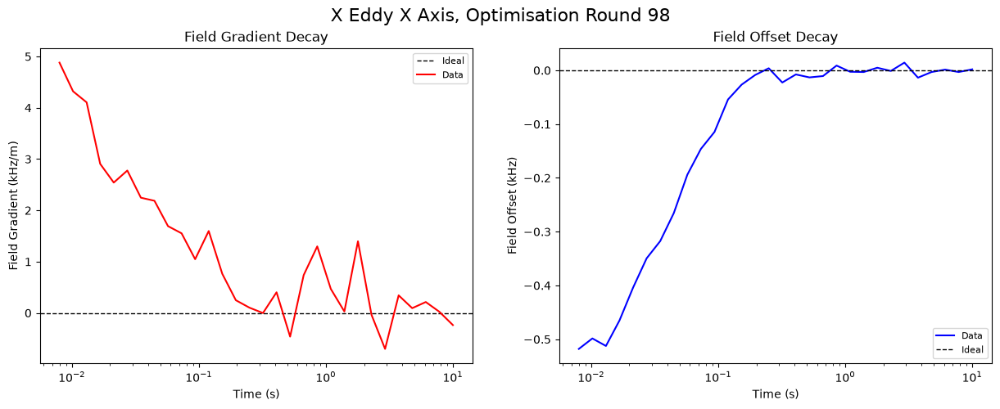

[I 2026-11-26 13:10:16,062] Trial 98 finished with value: 76.61403521261174 and parameters: {'X_A1': -0.026820214901960567, 'X_A2': 0.030257858460206788, 'X_A3': -1.2051189834952165e-08, 'X_A4': 6.373082122420902e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 7.661e+01
Total cost = 7.661e+01
E max = 0.12348360843806692
E nanmax = 0.12348360843806692
E contains nan = False
B max = 0.03277348991247394
B nanmax = 0.03277348991247394
B contains nan = False
Trial 99


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\ISMRM/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.03244727381121943 !!!!!!!!!!!!!!!!


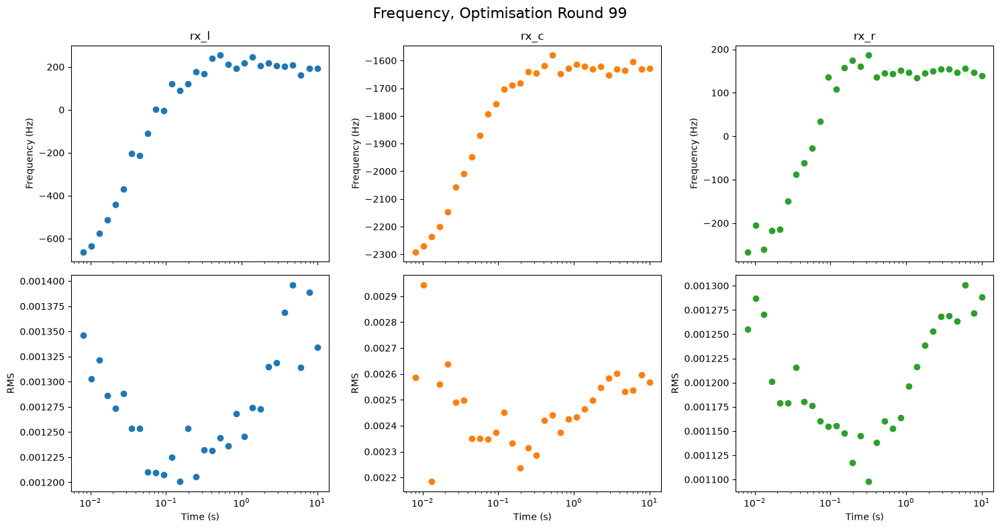

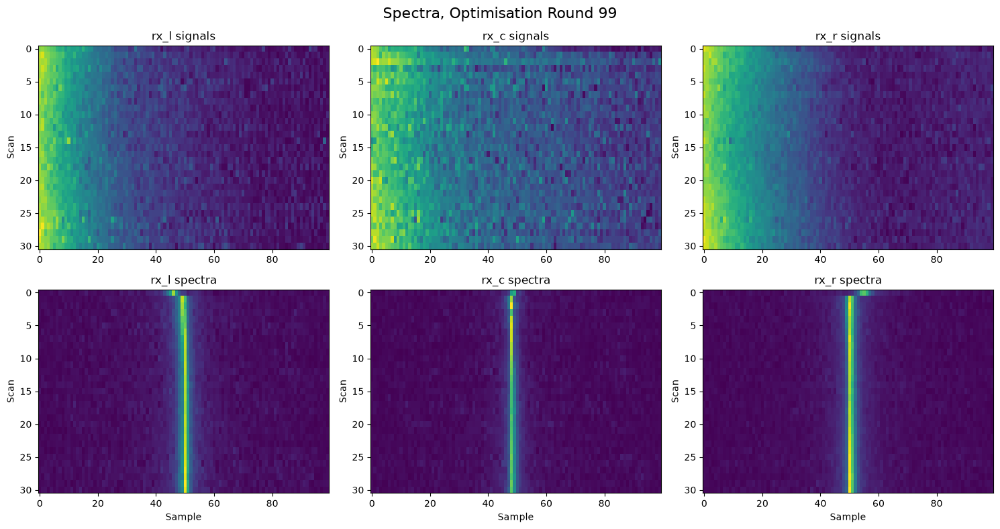

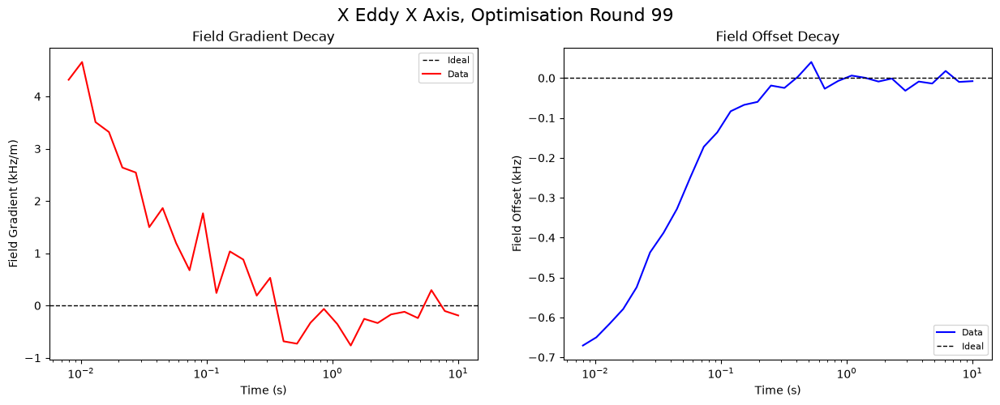

[I 2026-11-26 13:11:37,362] Trial 99 finished with value: 160.80175962145773 and parameters: {'X_A1': -0.02487068470103592, 'X_A2': 0.02923063074309882, 'X_A3': -1.209365978123917e-08, 'X_A4': 7.3381394432926595e-09}. Best is trial 60 with value: 62.637085877194814.


rx_c: 1.608e+02
Total cost = 1.608e+02
{'X_A1': -0.030255768098262886, 'X_A2': 0.025819811161252853, 'X_A3': -1.0250552678717223e-08, 'X_A4': 8.225424382610826e-09}
60
62.637085877194814
{'X_A1': -0.030255768098262886, 'X_A2': 0.025819811161252853, 'X_A3': -1.0250552678717223e-08, 'X_A4': 8.225424382610826e-09}


,trial,cost,g_pe_perc,max_b0var,status,X_A1,X_A2,X_A3,X_A4
0,0,71.005085,123.483608,0.019619,PASS,-0.032975,0.030379,-8.300920e-09,0.000000e+00
1,1,88.417410,123.483608,0.017536,PASS,-0.037231,0.039571,-1.242522e-08,-5.667804e-09
2,2,165.047812,123.483608,0.055227,PASS,-0.036614,0.043959,-7.112173e-09,6.424288e-09
3,3,187.733489,123.483608,0.018260,PASS,-0.046970,0.044558,-7.116198e-09,2.477825e-09
4,4,199.803880,123.483608,0.138783,PASS,-0.017153,0.035591,-4.229208e-09,7.032006e-09
...,...,...,...,...,...,...,...,...,...
95,95,146.102615,123.483608,0.013064,PASS,-0.028215,0.029958,-1.202752e-08,7.870641e-09
96,96,91.927455,123.483608,0.014093,PASS,-0.026483,0.028362,-1.174489e-08,9.087203e-09
97,97,146.361178,123.483608,0.006086,PASS,-0.027604,0.026804,-1.154509e-08,9.802253e-09
98,98,76.614035,123.483608,0.025825,PASS,-0.026820,0.030258,-1.205119e-08,6.373082e-09


In [11]:
# ------------------------------------------------------
# start calling optimisation run and analysis
# ------------------------------------------------------

study = optuna.create_study(direction="minimize")

start_params = {}

for i in range(1, MAX_EXP+1):
    start_params[f"{OPT_AXIS}_A{i}"] = B_START[f"{OPT_AXIS}"][f"A{i}"]

study.enqueue_trial(start_params)

study.optimize(lambda trial: opt.objective(trial, OPT_AXIS, metric, g_hzpm, E_START_opt, B_START, 
                                           start_params, percentage, seq_params, g_ideal), n_trials=num_trials)

best = study.best_params
opt.best = best
print(best)

print(study.best_trial.number)
print(study.best_value)
print(study.best_params)

# ----------------------------------
# create df of optimisation information across trials
# ----------------------------------
rows = []

for t in study.trials:

    row = {
        "trial": t.number,
        "cost": t.value,
        "g_pe_perc": t.user_attrs.get("g_pe_perc", np.nan),
        "max_b0var": t.user_attrs.get("max_b0var", np.nan),
        "status": t.user_attrs.get("status", "")
    }

    row.update(t.params)

    rows.append(row)

df_trials = pd.DataFrame(rows)
display(df_trials)
df_trials.to_csv(Path.cwd() / OPT_AXIS / "offset_info.csv", index=False)

opt.save_to_global(B_START, OPT_AXIS, "eddy_B0.yaml")

#### Plot Optimisation Performance

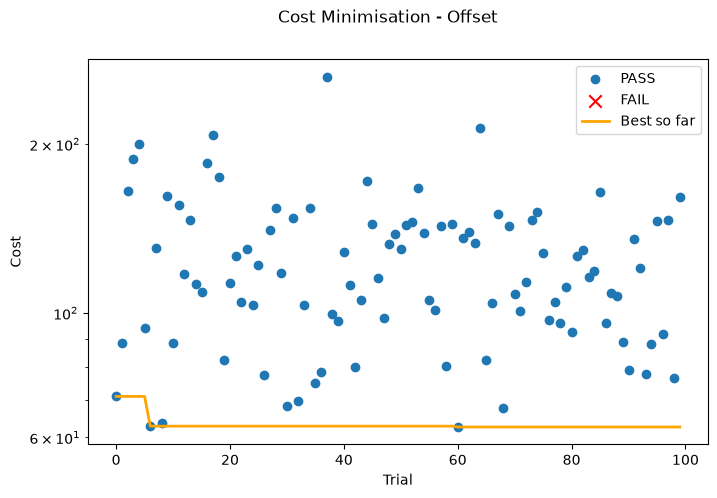

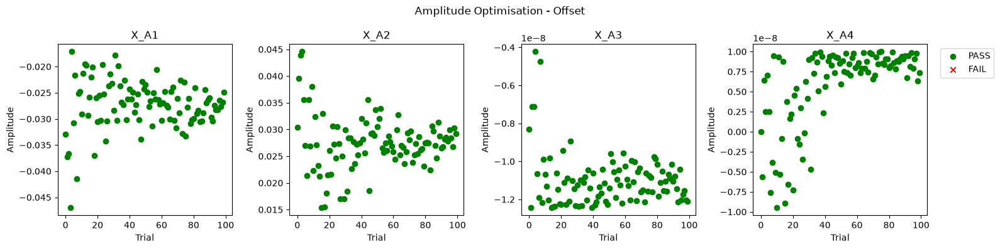

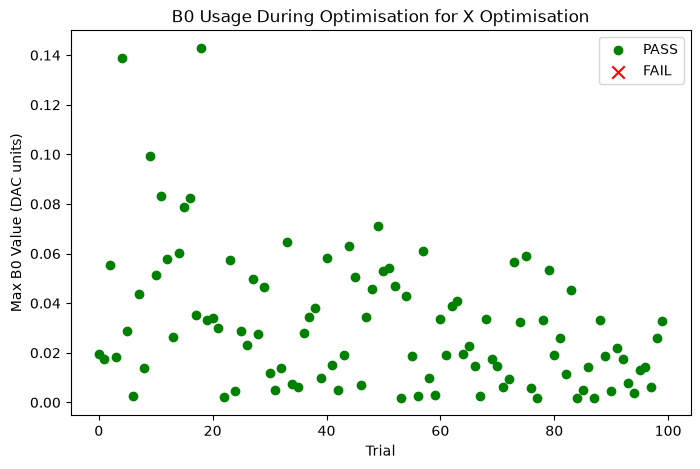

In [12]:
opt.plot_for_optimisation(df_trials, OPT_AXIS, metric)